# Module 1

In [1]:
"""
01_00_input_peek.txt
Phase 5 -- Module 01: Setup -- Input peek (ONE-TIME, read-only)

TITLE: Input peek

TITLE DESCRIPTION
  Phase 5 reads files made in Phase 3 and Phase 4 and a new dataset (BCN20000). A few details are not on record in
  the planning documents: the exact keys inside the Phase 4 prediction files, the layout of the Phase 4 hash records,
  where the BCN20000 metadata CSV sits on disk, and what the BCN20000 image folder really contains. This cell PRINTS
  what is there, so 01_01 can be given real names instead of guesses.

CODE DESCRIPTION
  - Reads and prints only: file presence and sizes, array keys and shapes, hash fields, the encoder's site list
    (the spelling of "trunk"), BCN20000 CSV columns and counts, the image-folder listing (count, extensions, whether
    the file names match the isic_id values, sizes of three images), and whether the Phase 5 output folder already
    holds anything. Writes nothing and changes nothing.
  - Needs no earlier cell. Each section is wrapped separately, so one failure does not stop the rest. Variable names
    start with PEEK_ so they cannot collide with the config cell (01_01).

RUN IT ONCE, then send the whole printout back.
"""

import json
import os
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

PEEK_BASE = Path(r"T:\Thesis - Development")
PEEK_ART = PEEK_BASE / "Resources" / "Artifacts"
PEEK_P1, PEEK_P3, PEEK_P4 = PEEK_ART / "Phase 1 - P2", PEEK_ART / "Phase 3 - P1", PEEK_ART / "Phase 4 - P1"
PEEK_P5 = PEEK_ART / "Phase 5 - P1"
PEEK_BCN = PEEK_BASE / "Resources" / "Dataset" / "BCN20000"

PEEK_PATHS = {
    "holdout_csv": PEEK_P1 / "holdout_split.csv",
    "metadata_tab": PEEK_BASE / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab",
    "frozen_model": PEEK_P3 / "final_model" / "phase3_final_multimodal_model.pt",
    "model_card": PEEK_P3 / "final_model" / "phase3_model_card.json",
    "ablation_model": PEEK_P3 / "cv_training" / "ablation" / "fold_3_best.pt",
    "encoder_stats": PEEK_P3 / "metadata_encoder_stats.json",
    "p4_pred_multimodal": PEEK_P4 / "holdout_predictions" / "multimodal_holdout_predictions.npz",
    "p4_pred_ablation": PEEK_P4 / "holdout_predictions" / "ablation_fold3_holdout_predictions.npz",
    "p4_precision_json": PEEK_P4 / "results_summary" / "precision_agreement_fp32_vs_bf16.json",
    "p4_start_fingerprints": PEEK_P4 / "phase4_start_fingerprints.json",
    "p4_exit_gate": PEEK_P4 / "final" / "phase4_exit_gate.json",
    "bcn_folder": PEEK_BCN,
    "bcn_images_folder": PEEK_BCN / "images",
    "phase5_output_folder": PEEK_P5,
}


def peek_section(title, fn):
    print("\n" + "-" * 72)
    print(title)
    print("-" * 72)
    try:
        fn()
    except Exception as exc:  # noqa: BLE001 -- reported, never hidden, and never fatal for the other sections
        print(f"  FAILED -- {type(exc).__name__}: {exc}")


def peek_files():
    for name, path in PEEK_PATHS.items():
        if path.is_dir():
            print(f"  {name:<22} folder, {sum(1 for _ in path.iterdir()):,} entries   {path}")
        elif path.is_file():
            print(f"  {name:<22} file, {path.stat().st_size:,} bytes   {path}")
        else:
            print(f"  {name:<22} MISSING   {path}")


def peek_bcn_folder():
    print(f"  top level of {PEEK_BCN}:")
    entries = sorted(PEEK_BCN.iterdir(), key=lambda p: p.name.lower())
    for p in entries[:40]:
        kind = "folder" if p.is_dir() else f"file, {p.stat().st_size:,} bytes"
        print(f"    {p.name}   ({kind})")
    if len(entries) > 40:
        print(f"    ... and {len(entries) - 40} more")
    csvs = [p for p in entries if p.is_file() and p.suffix.lower() == ".csv"]
    print(f"  CSV files at the top level: {[p.name for p in csvs]}")
    print("  (01_01 expects 'bcn20000_metadata_2026-10-04.csv' here; tell me if it lives elsewhere.)")


def peek_predictions():
    holdout_ids = pd.read_csv(PEEK_PATHS["holdout_csv"])["image_id"].tolist()
    for key in ("p4_pred_multimodal", "p4_pred_ablation"):
        print(f"  {key}:")
        with np.load(PEEK_PATHS[key], allow_pickle=False) as z:
            for k in z.files:
                a = z[k]
                if a.ndim == 0:
                    print(f"    {k:<20} scalar {a.dtype}: {a.item()!r}")
                else:
                    print(f"    {k:<20} {a.dtype} {a.shape}")
            ids = [str(x) for x in z["image_ids"]]
            print(f"    image_ids equal holdout_split.csv row for row: {ids == holdout_ids}")
            print(f"    labels range {int(z['labels'].min())}..{int(z['labels'].max())}; "
                  f"probs row-sum range {float(z['probs'].sum(axis=1).min()):.6f}..{float(z['probs'].sum(axis=1).max()):.6f}")
            print(f"    pred != pred_bf16 for {int((z['pred'] != z['pred_bf16']).sum())} images")


def peek_precision_json():
    with open(PEEK_PATHS["p4_precision_json"], "r", encoding="utf-8") as f:
        rec = json.load(f)
    print(f"  top-level keys: {list(rec)}")
    print(f"  status: {rec.get('status')}   headline_precision: {rec.get('headline_precision')}   recorded_at: {rec.get('recorded_at')}")
    for kind, a in rec.get("models", {}).items():
        print(f"  {kind}: n_images {a.get('n_images')}, changed {a.get('n_changed_predicted_class')}, "
              f"model_sha256 {str(a.get('model_sha256'))[:16]}..., predictions_file_sha256 {str(a.get('predictions_file_sha256'))[:16]}...")


def peek_phase4_fingerprints():
    with open(PEEK_PATHS["p4_start_fingerprints"], "r", encoding="utf-8") as f:
        rec = json.load(f)
    print(f"  top-level keys: {list(rec)}   recorded_at: {rec.get('recorded_at')}")
    for group in ("model_files", "input_files"):
        print(f"  {group}: {list(rec.get(group, {}))}")
    print(f"  environment recorded by Phase 4: {json.dumps(rec.get('environment'), indent=2)}")
    print(f"  environment_changes logged during Phase 4: {len(rec.get('environment_changes', []))}")


def peek_encoder_and_card():
    with open(PEEK_PATHS["encoder_stats"], "r", encoding="utf-8") as f:
        enc = json.load(f)
    print(f"  encoder stats top-level keys: {list(enc)}")
    names = enc.get("feature_names", [])
    print(f"  feature_names: {len(names)} entries; site_trunk present: {'site_trunk' in names}; "
          f"site entries: {[n for n in names if n.startswith('site_')]}")
    f3 = enc.get("folds", {}).get("3", {})
    print(f"  fold 3 entry: {f3}")
    with open(PEEK_PATHS["model_card"], "r", encoding="utf-8") as f:
        card = json.load(f)
    print(f"  model card top-level keys: {list(card)}")
    print(f"  selection: {card.get('selection')}")
    ic = card.get("input_contract", {})
    print(f"  input_contract keys: {list(ic)}; image: {ic.get('image')}")
    print(f"  metadata keys: {list(ic.get('metadata', {}))}")


def peek_bcn_csv():
    csv_path = PEEK_BCN / "bcn20000_metadata_2026-10-04.csv"
    df = pd.read_csv(csv_path)
    print(f"  rows: {len(df):,}   columns: {list(df.columns)}")
    print(f"  distinct isic_id: {df['isic_id'].nunique():,}   distinct lesion_id: {df['lesion_id'].nunique():,}")
    print(f"  diagnosis_1 counts (NaN = no diagnosis): {df['diagnosis_1'].value_counts(dropna=False).to_dict()}")
    print(f"  copyright_license: {df['copyright_license'].value_counts(dropna=False).to_dict()}")
    print(f"  first 3 isic_id: {df['isic_id'].head(3).tolist()}")


def peek_bcn_images():
    folder = PEEK_BCN / "images"
    csv_ids = set(pd.read_csv(PEEK_BCN / "bcn20000_metadata_2026-10-04.csv")["isic_id"].astype(str))
    files = [e for e in os.scandir(folder) if e.is_file()]
    subfolders = [e.name for e in os.scandir(folder) if e.is_dir()]
    print(f"  files directly in the folder: {len(files):,}   subfolders: {subfolders[:10]}")
    print(f"  extensions: {dict(Counter(Path(e.name).suffix.lower() for e in files))}")
    print(f"  first 3 names: {sorted(e.name for e in files)[:3]}")
    stems = [Path(e.name).stem for e in files]
    print(f"  distinct stems: {len(set(stems)):,}   (equal to the file count means one file per stem)")
    print(f"  stems that are an isic_id in the CSV: {len(set(stems) & csv_ids):,} of {len(csv_ids):,} CSV ids")
    print(f"  stems NOT in the CSV (extra files): {len(set(stems) - csv_ids):,}   CSV ids with no file (missing): {len(csv_ids - set(stems)):,}")
    for e in sorted(files, key=lambda x: x.name)[:3]:
        img = cv2.imread(e.path)
        print(f"  {e.name}: {None if img is None else img.shape}   {e.stat().st_size:,} bytes")


def peek_phase5_folder():
    if not PEEK_P5.exists():
        print("  Phase 5 output folder does not exist yet (01_01 will create it).")
        return
    found = [str(p.relative_to(PEEK_P5)) for p in PEEK_P5.rglob("*") if p.is_file()]
    print(f"  files already in the Phase 5 output folder: {len(found)}")
    for name in found[:30]:
        print(f"    {name}")


peek_section("1. Files and folders", peek_files)
peek_section("2. BCN20000 folder (top level)", peek_bcn_folder)
peek_section("3. Phase 4 prediction files", peek_predictions)
peek_section("4. Phase 4 precision_agreement_fp32_vs_bf16.json", peek_precision_json)
peek_section("5. Phase 4 start fingerprints and environment", peek_phase4_fingerprints)
peek_section("6. Encoder statistics and model card", peek_encoder_and_card)
peek_section("7. BCN20000 metadata CSV", peek_bcn_csv)
peek_section("8. BCN20000 image folder", peek_bcn_images)
peek_section("9. Phase 5 output folder", peek_phase5_folder)
print("\nPeek finished. Nothing was written.")


------------------------------------------------------------------------
1. Files and folders
------------------------------------------------------------------------
  holdout_csv            file, 73,006 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\holdout_split.csv
  metadata_tab           file, 830,428 bytes   T:\Thesis - Development\Resources\Dataset\HAM10000\HAM10000_metadata.tab
  frozen_model           file, 43,846,307 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 3 - P1\final_model\phase3_final_multimodal_model.pt
  model_card             file, 10,283 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 3 - P1\final_model\phase3_model_card.json
  ablation_model         file, 43,383,491 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 3 - P1\cv_training\ablation\fold_3_best.pt
  encoder_stats          file, 1,974 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 3 - P1\metadata_encoder_stats.json
  p4_pred_multimodal     fil

In [2]:
"""
01_01_phase5_config.txt
Phase 5 -- Module 01: Setup -- Configuration (reusable)

TITLE: Phase 5 configuration

TITLE DESCRIPTION
  The single place for every path, expected value and constant Phase 5 uses. Nothing else in Phase 5 hard-codes
  them: change them here and re-run this cell. Values come from Phase-5_Planning.md, Phase-5_Checklist.md,
  Phase4_Closeout_Summary_P1.md and the Phase 4 notebook.

CODE DESCRIPTION
  - Paths shared with Phase 3 / 4 keep their earlier variable names and values. Phase 5's own start with PHASE5_ or BCN_.
    Expected values (model hashes, holdout and BCN20000 counts) are written out HERE, never read from the files they
    are checked against. Rules that Module 02 must fix before any result (tolerances, ECE bins, the cell rule) are
    deliberately NOT in this cell, so they have exactly one home.
  - Switches TF32 off (same code as Phase 4's decision P4-10, so "fp32" means the same thing in both phases) and seeds
    all random generators with 42. Creates the Phase 5 output folders (folders only, no result files).
  - BCN_METADATA_CSV_PATH is a best guess (the file name from the Planning); the status report says if it is not found.
    Safe to re-run any number of times.

Requires: nothing earlier. Run after 01_00.
"""

import random
from pathlib import Path

import numpy as np
import torch

# ---------------------------------------------------------------------------
# Paths shared with Phase 3 / 4 (same names, same values)
# ---------------------------------------------------------------------------
BASE_DIR = Path(r"T:\Thesis - Development")
ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts"
P1_ARTIFACTS_DIR = ARTIFACTS_DIR / "Phase 1 - P2"
PHASE3_ARTIFACTS_DIR = ARTIFACTS_DIR / "Phase 3 - P1"
PHASE4_ARTIFACTS_DIR = ARTIFACTS_DIR / "Phase 4 - P1"

HOLDOUT_CSV_PATH = P1_ARTIFACTS_DIR / "holdout_split.csv"
METADATA_TAB_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
ENCODER_STATS_PATH = PHASE3_ARTIFACTS_DIR / "metadata_encoder_stats.json"
FINAL_IMAGES_DIR = P1_ARTIFACTS_DIR / "Final Output Phase 1" / "images"      # holdout images (used by the wiring proof)

SELECTED_FOLD = 3
FROZEN_MODEL_PATH = PHASE3_ARTIFACTS_DIR / "final_model" / "phase3_final_multimodal_model.pt"
MODEL_CARD_PATH = PHASE3_ARTIFACTS_DIR / "final_model" / "phase3_model_card.json"
ABLATION_MODEL_PATH = PHASE3_ARTIFACTS_DIR / "cv_training" / "ablation" / f"fold_{SELECTED_FOLD}_best.pt"

# ---------------------------------------------------------------------------
# Phase 4 files that Phase 5 reads (read-only)
# ---------------------------------------------------------------------------
PHASE4_PREDICTION_FILES = {
    "multimodal": PHASE4_ARTIFACTS_DIR / "holdout_predictions" / "multimodal_holdout_predictions.npz",
    "ablation": PHASE4_ARTIFACTS_DIR / "holdout_predictions" / "ablation_fold3_holdout_predictions.npz",
}
PHASE4_PRECISION_JSON_PATH = PHASE4_ARTIFACTS_DIR / "results_summary" / "precision_agreement_fp32_vs_bf16.json"
PHASE4_START_FINGERPRINTS_PATH = PHASE4_ARTIFACTS_DIR / "phase4_start_fingerprints.json"

# ---------------------------------------------------------------------------
# BCN20000 (read-only)
# ---------------------------------------------------------------------------
BCN_DIR = BASE_DIR / "Resources" / "Dataset" / "BCN20000"
BCN_IMAGES_DIR = BCN_DIR / "images"
BCN_METADATA_CSV_PATH = BCN_DIR / "bcn20000_metadata_2026-10-04.csv"      # best guess; confirm with the 01_00 printout

# ---------------------------------------------------------------------------
# Phase 5 outputs (folders only are created here)
# ---------------------------------------------------------------------------
PHASE5_ARTIFACTS_DIR = ARTIFACTS_DIR / "Phase 5 - P1"
PHASE5_RULES_DIR = PHASE5_ARTIFACTS_DIR / "rules"                  # Module 02: the rules note
PHASE5_HOLDOUT_DIR = PHASE5_ARTIFACTS_DIR / "holdout_results"      # Module 03
PHASE5_BCN_INVENTORY_DIR = PHASE5_ARTIFACTS_DIR / "bcn_inventory"  # Modules 04-05
PHASE5_BCN_IMAGES_DIR = PHASE5_ARTIFACTS_DIR / "bcn_preprocessed"  # Module 06: 16,843 JPEG files named by isic_id
PHASE5_BCN_PREDICTIONS_DIR = PHASE5_ARTIFACTS_DIR / "bcn_predictions"   # Module 07
PHASE5_BCN_RESULTS_DIR = PHASE5_ARTIFACTS_DIR / "bcn_results"      # Module 08
PHASE5_DEMOGRAPHICS_DIR = PHASE5_ARTIFACTS_DIR / "demographics"    # Module 09
PHASE5_FINAL_DIR = PHASE5_ARTIFACTS_DIR / "final"                  # Module 10

# Folders that must hold NO file when the rules note is recorded (Module 02 refuses otherwise)
PHASE5_RESULT_DIRS = (PHASE5_HOLDOUT_DIR, PHASE5_BCN_INVENTORY_DIR, PHASE5_BCN_IMAGES_DIR,
                      PHASE5_BCN_PREDICTIONS_DIR, PHASE5_BCN_RESULTS_DIR, PHASE5_DEMOGRAPHICS_DIR, PHASE5_FINAL_DIR)

START_FINGERPRINTS_PATH = PHASE5_ARTIFACTS_DIR / "phase5_start_fingerprints.json"

for _folder in (PHASE5_ARTIFACTS_DIR, PHASE5_RULES_DIR) + PHASE5_RESULT_DIRS:
    _folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Expected values, written out on purpose (never read from the files they are checked against)
# ---------------------------------------------------------------------------
EXPECTED_FROZEN_SHA256 = "d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed"
EXPECTED_FROZEN_BYTES = 43_846_307
EXPECTED_FROZEN_EPOCH = 51
EXPECTED_FROZEN_VAL_AUC = 0.9481232283374819
EXPECTED_ABLATION_SHA256 = "33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a"
EXPECTED_ABLATION_BYTES = 43_383_491
EXPECTED_ABLATION_EPOCH = 43
EXPECTED_ABLATION_VAL_AUC = 0.9530133716361157
EXPECTED_CLASS_ORDER = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
IMAGE_SIZE = 300

# Holdout (Phase 4 close-out, Phase 5 Planning Section 3)
EXPECTED_HOLDOUT_ROWS = 1432
EXPECTED_HOLDOUT_LESIONS = 1067
EXPECTED_HOLDOUT_CLASS_COUNTS = {"akiec": 46, "bcc": 76, "bkl": 158, "df": 15, "mel": 159, "nv": 959, "vasc": 19}
EXPECTED_HOLDOUT_MISSING_AGE = 9
EXPECTED_HOLDOUT_SEX_COUNTS = {"male": 778, "female": 646, "unknown": 8}
assert sum(EXPECTED_HOLDOUT_CLASS_COUNTS.values()) == EXPECTED_HOLDOUT_ROWS
assert list(EXPECTED_HOLDOUT_CLASS_COUNTS) == EXPECTED_CLASS_ORDER

# bf16 disclosure from Phase 4 (images whose predicted class changes between bf16 and fp32)
EXPECTED_BF16_CHANGED = {"multimodal": 20, "ablation": 16}

# BCN20000 (Phase 5 Planning Section 4.3, verified from the CSV on 2026-10-04)
EXPECTED_BCN_ROWS = 18_946
EXPECTED_BCN_PRIMARY_COUNTS = {"nv": 5647, "mel": 4003, "bcc": 3676, "bkl": 1551, "akiec": 1088, "df": 168, "vasc": 151}
EXPECTED_BCN_PRIMARY_TOTAL = 16_284
EXPECTED_BCN_SCC = 559
EXPECTED_BCN_OOD = 2_103
EXPECTED_BCN_SCORED_IMAGES = EXPECTED_BCN_PRIMARY_TOTAL + EXPECTED_BCN_SCC      # 16,843 images are preprocessed
assert sum(EXPECTED_BCN_PRIMARY_COUNTS.values()) == EXPECTED_BCN_PRIMARY_TOTAL
assert EXPECTED_BCN_PRIMARY_TOTAL + EXPECTED_BCN_SCC + EXPECTED_BCN_OOD == EXPECTED_BCN_ROWS

RANDOM_SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------------------------
# Precision switches: no TF32 anywhere, so fp32 means fp32 (same code as Phase 4, decision P4-10)
# ---------------------------------------------------------------------------
_NEW_TF32_API = (hasattr(torch.backends.cudnn, "conv") and hasattr(torch.backends.cudnn.conv, "fp32_precision")
                 and hasattr(torch.backends.cuda.matmul, "fp32_precision"))


def switch_tf32_off():
    if _NEW_TF32_API:
        torch.backends.cudnn.conv.fp32_precision = "ieee"
        torch.backends.cuda.matmul.fp32_precision = "ieee"
    else:
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.set_float32_matmul_precision("highest")


def precision_state():
    """What convolutions and matrix products use for fp32 data: 'ieee' (full fp32) or something else (e.g. 'tf32')."""
    if _NEW_TF32_API:
        return {"api": "fp32_precision", "convolution": str(torch.backends.cudnn.conv.fp32_precision),
                "matmul": str(torch.backends.cuda.matmul.fp32_precision)}
    legacy_matmul_ieee = (not torch.backends.cuda.matmul.allow_tf32) and torch.get_float32_matmul_precision() == "highest"
    return {"api": "allow_tf32 flags", "convolution": "tf32" if torch.backends.cudnn.allow_tf32 else "ieee",
            "matmul": "ieee" if legacy_matmul_ieee else "tf32 or reduced"}


def precision_is_strict():
    state = precision_state()
    return state["convolution"] == "ieee" and state["matmul"] == "ieee"


def set_phase5_seeds(seed=RANDOM_SEED):
    """Same seeding as Phases 3 and 4 (cuDNN deterministic, benchmark off)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


switch_tf32_off()
set_phase5_seeds()
assert precision_is_strict(), f"TF32 could not be switched off: {precision_state()}"

# ---------------------------------------------------------------------------
# Status report
# ---------------------------------------------------------------------------
REQUIRED_INPUTS = {
    "holdout_split.csv": HOLDOUT_CSV_PATH,
    "HAM10000_metadata.tab": METADATA_TAB_PATH,
    "holdout images folder": FINAL_IMAGES_DIR,
    "frozen multimodal model": FROZEN_MODEL_PATH,
    "model card": MODEL_CARD_PATH,
    "fold 3 ablation model": ABLATION_MODEL_PATH,
    "metadata_encoder_stats.json": ENCODER_STATS_PATH,
    "Phase 4 multimodal predictions": PHASE4_PREDICTION_FILES["multimodal"],
    "Phase 4 ablation predictions": PHASE4_PREDICTION_FILES["ablation"],
    "Phase 4 precision_agreement json": PHASE4_PRECISION_JSON_PATH,
    "Phase 4 start fingerprints": PHASE4_START_FINGERPRINTS_PATH,
    "BCN20000 metadata CSV": BCN_METADATA_CSV_PATH,
    "BCN20000 images folder": BCN_IMAGES_DIR,
}
MISSING_INPUTS = [name for name, path in REQUIRED_INPUTS.items() if not path.exists()]

print("Phase 5 configuration loaded.")
print(f"  device           : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda"
                                         else "   <-- NO GPU: BCN20000 inference would be very slow"))
print(f"  seed             : {RANDOM_SEED} (cuDNN deterministic, benchmark off)")
print(f"  precision        : convolutions '{precision_state()['convolution']}', matrix products '{precision_state()['matmul']}' "
      f"(via the {precision_state()['api']} API; 'ieee' = full fp32)")
print(f"  selected fold    : {SELECTED_FOLD}   holdout rows expected: {EXPECTED_HOLDOUT_ROWS:,}")
print(f"  BCN20000 expected: {EXPECTED_BCN_ROWS:,} rows = {EXPECTED_BCN_PRIMARY_TOTAL:,} primary + {EXPECTED_BCN_SCC} SCC + {EXPECTED_BCN_OOD:,} OOD")
print(f"  output folder    : {PHASE5_ARTIFACTS_DIR}")
print("  required inputs  : " + ("all present" if not MISSING_INPUTS else f"MISSING -> {MISSING_INPUTS}"))

Phase 5 configuration loaded.
  device           : cuda (NVIDIA GeForce RTX 5060 Ti)
  seed             : 42 (cuDNN deterministic, benchmark off)
  precision        : convolutions 'ieee', matrix products 'ieee' (via the fp32_precision API; 'ieee' = full fp32)
  selected fold    : 3   holdout rows expected: 1,432
  BCN20000 expected: 18,946 rows = 16,284 primary + 559 SCC + 2,103 OOD
  output folder    : T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1
  required inputs  : all present


In [3]:
"""
01_02_fingerprints.txt
Phase 5 -- Module 01: Setup -- File fingerprints, environment record and atomic writers (reusable, resumable)

TITLE: File fingerprints, environment record and atomic JSON writer

TITLE DESCRIPTION
  Phase 5 must read the frozen models and the Phase 4 files without changing them. This cell proves that: the first
  time it runs it checks every file against what is already on record elsewhere, then records the SHA-256 of every
  file Phase 5 reads. Every later run (including the exit gate in Module 10) compares against that record from disk,
  never from memory. This is the Checklist's "read-only guard".

CODE DESCRIPTION
  - FIRST RUN checks, and writes NOTHING if any fails: (1) both model files against the hashes and sizes written in
    01_01, and the model card's own hash for the frozen model; (2) the two Phase 4 prediction files against the SHA-256
    values stored in precision_agreement_fp32_vs_bf16.json (which must say PASSED, with 20 and 16 changed images, and
    must name the same model hashes); (3) the models and four shared input files against Phase 4's own start-of-phase
    record. It then writes phase5_start_fingerprints.json (atomic write) with four groups: model_files, phase4_files,
    input_files, bcn_files (the BCN20000 metadata CSV), plus the software environment and its differences from Phase 4's.
  - LATER RUNS: any changed file stops the cell (FingerprintMismatchError); a changed environment only warns and is logged.
    The BCN20000 images are NOT hashed here (18,946 files); Module 04 checks them by name, count and size.
    Also defines atomic_write_json, atomic_write_bytes and replace_with_retry for later modules.

Requires: 01_01_phase5_config.txt already run.
Final-check usage in Module 10:  record_or_check_fingerprints(must_exist=True)
"""

import hashlib
import json
import os
import platform
import tempfile
import time
from datetime import datetime
from pathlib import Path

import torch

FINGERPRINT_FORMAT_VERSION = 1
REPLACE_RETRY_WAITS = (0.5, 1.0, 2.0, 3.0, 5.0)    # seconds between attempts when Windows briefly locks a file


class FingerprintMismatchError(RuntimeError):
    """A file differs from what was recorded at the start of Phase 5."""


# ---------------------------------------------------------------------------
# Small shared helpers (reused by later modules)
# ---------------------------------------------------------------------------

def now_iso():
    return datetime.now().astimezone().isoformat(timespec="seconds")


def replace_with_retry(tmp_path, final_path):
    """os.replace, retried while the destination is momentarily locked. Only PermissionError is retried."""
    attempts = len(REPLACE_RETRY_WAITS) + 1
    for attempt in range(attempts):
        try:
            os.replace(tmp_path, final_path)
            return
        except PermissionError:
            if attempt == attempts - 1:
                raise
            wait = REPLACE_RETRY_WAITS[attempt]
            print(f"  (file busy: {os.path.basename(str(final_path))} -- retrying in {wait:g} s, "
                  f"attempt {attempt + 2} of {attempts})")
            time.sleep(wait)


def remove_quietly(path):
    try:
        if os.path.exists(path):
            os.remove(path)
    except OSError:
        pass


def atomic_write_bytes(path, data):
    """Temporary file + fsync + retrying os.replace: a power cut can never leave a half-written file."""
    path = str(path)
    folder = os.path.dirname(path) or "."
    os.makedirs(folder, exist_ok=True)
    fd, tmp_path = tempfile.mkstemp(dir=folder, suffix=".tmp")
    try:
        with os.fdopen(fd, "wb") as f:
            f.write(data)
            f.flush()
            os.fsync(f.fileno())
        replace_with_retry(tmp_path, path)
    except BaseException:
        remove_quietly(tmp_path)
        raise


def atomic_write_json(path, obj):
    atomic_write_bytes(path, json.dumps(obj, indent=2, ensure_ascii=False).encode("utf-8"))


def sha256_of_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def capture_environment():
    """Same fields as Phase 4's record, so the two can be compared key by key."""
    env = {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    }
    for module_name in ("torchvision", "numpy", "pandas", "sklearn", "cv2", "scipy", "skimage", "matplotlib"):
        try:
            env[module_name] = getattr(__import__(module_name), "__version__", "unknown")
        except Exception:  # noqa: BLE001 -- a missing library is information, not an error
            env[module_name] = "not installed"
    return env


# ---------------------------------------------------------------------------
# Which files are fingerprinted
# ---------------------------------------------------------------------------
FINGERPRINT_GROUPS = {
    "model_files": {"frozen_multimodal_model": FROZEN_MODEL_PATH, "ablation_fold3_model": ABLATION_MODEL_PATH},
    "phase4_files": {
        "phase4_multimodal_predictions": PHASE4_PREDICTION_FILES["multimodal"],
        "phase4_ablation_predictions": PHASE4_PREDICTION_FILES["ablation"],
        "phase4_precision_agreement_json": PHASE4_PRECISION_JSON_PATH,
        "phase4_start_fingerprints_json": PHASE4_START_FINGERPRINTS_PATH,
    },
    "input_files": {
        "model_card": MODEL_CARD_PATH,
        "metadata_encoder_stats": ENCODER_STATS_PATH,
        "holdout_split_csv": HOLDOUT_CSV_PATH,
        "ham10000_metadata_tab": METADATA_TAB_PATH,
    },
    "bcn_files": {"bcn20000_metadata_csv": BCN_METADATA_CSV_PATH},
}


def file_record(path):
    path = Path(path)
    return {"path": str(path), "bytes": path.stat().st_size, "sha256": sha256_of_file(path)}


def compute_current_fingerprints():
    missing = [f"{group}/{name}: {path}" for group, files in FINGERPRINT_GROUPS.items()
               for name, path in files.items() if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError("Cannot fingerprint -- file(s) missing:\n  " + "\n  ".join(missing))
    return {group: {name: file_record(path) for name, path in files.items()} for group, files in FINGERPRINT_GROUPS.items()}


def compare_fingerprints(saved, current):
    """Differences between the recorded and the current files, as readable lines (empty list = identical)."""
    problems = []
    for group in FINGERPRINT_GROUPS:
        saved_group, current_group = saved.get(group, {}), current.get(group, {})
        for name in sorted(set(saved_group) | set(current_group)):
            a, b = saved_group.get(name), current_group.get(name)
            if a is None or b is None:
                problems.append(f"{group}/{name}: listed in only one of the recorded and the current set")
            elif a["sha256"] != b["sha256"] or a["bytes"] != b["bytes"]:
                problems.append(f"{group}/{name}: CHANGED since it was recorded "
                                f"(was {a['bytes']:,} bytes, {a['sha256'][:16]}...; now {b['bytes']:,} bytes, {b['sha256'][:16]}...)")
    return problems


def _load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def first_run_checks(current):
    """Everything that is already on record elsewhere. Returns (problems, phase4_environment)."""
    problems = []
    models, p4files, inputs = current["model_files"], current["phase4_files"], current["input_files"]

    # 1. Model files against the values written in 01_01, and the frozen model against the model card's own hash
    for label, key, sha, size in (("frozen model", "frozen_multimodal_model", EXPECTED_FROZEN_SHA256, EXPECTED_FROZEN_BYTES),
                                  ("ablation model", "ablation_fold3_model", EXPECTED_ABLATION_SHA256, EXPECTED_ABLATION_BYTES)):
        if models[key]["sha256"] != sha:
            problems.append(f"{label} SHA-256 is {models[key]['sha256']}, expected {sha}")
        if models[key]["bytes"] != size:
            problems.append(f"{label} is {models[key]['bytes']:,} bytes, expected {size:,}")
    card = _load_json(MODEL_CARD_PATH)
    card_hash = (card.get("frozen_file") or {}).get("sha256")
    if card_hash != models["frozen_multimodal_model"]["sha256"]:
        problems.append(f"the model card records SHA-256 {card_hash}, the frozen file's is {models['frozen_multimodal_model']['sha256']}")
    selection = card.get("selection") or {}
    if selection.get("selected_fold") != SELECTED_FOLD or selection.get("best_epoch") != EXPECTED_FROZEN_EPOCH:
        problems.append(f"model card selection is {selection}, expected fold {SELECTED_FOLD}, epoch {EXPECTED_FROZEN_EPOCH}")

    # 2. Phase 4 prediction files against precision_agreement_fp32_vs_bf16.json
    precision = _load_json(PHASE4_PRECISION_JSON_PATH)
    if precision.get("status") != "PASSED":
        problems.append(f"precision_agreement json status is {precision.get('status')!r}, expected 'PASSED'")
    if precision.get("headline_precision") != "fp32":
        problems.append(f"precision_agreement json headline precision is {precision.get('headline_precision')!r}, expected 'fp32'")
    for kind, file_key, model_key in (("multimodal", "phase4_multimodal_predictions", "frozen_multimodal_model"),
                                      ("ablation", "phase4_ablation_predictions", "ablation_fold3_model")):
        entry = (precision.get("models") or {}).get(kind) or {}
        if entry.get("predictions_file_sha256") != p4files[file_key]["sha256"]:
            problems.append(f"{kind} predictions file: SHA-256 {p4files[file_key]['sha256'][:16]}... differs from the one stored in "
                            f"precision_agreement json ({str(entry.get('predictions_file_sha256'))[:16]}...)")
        if entry.get("model_sha256") != models[model_key]["sha256"]:
            problems.append(f"{kind}: precision_agreement json names model SHA-256 {str(entry.get('model_sha256'))[:16]}..., "
                            f"the model file's is {models[model_key]['sha256'][:16]}...")
        if entry.get("n_changed_predicted_class") != EXPECTED_BF16_CHANGED[kind]:
            problems.append(f"{kind}: precision_agreement json reports {entry.get('n_changed_predicted_class')} changed images, "
                            f"expected {EXPECTED_BF16_CHANGED[kind]}")

    # 3. Models and shared inputs against Phase 4's own start-of-phase record
    p4_record = _load_json(PHASE4_START_FINGERPRINTS_PATH)
    for group, keys in (("model_files", ("frozen_multimodal_model", "ablation_fold3_model")),
                        ("input_files", ("model_card", "metadata_encoder_stats", "holdout_split_csv", "ham10000_metadata_tab"))):
        for key in keys:
            then = (p4_record.get(group) or {}).get(key)
            now = current[group][key]
            if then is None:
                problems.append(f"Phase 4's start record has no entry {group}/{key}")
            elif then.get("sha256") != now["sha256"]:
                problems.append(f"{group}/{key} differs from Phase 4's start record "
                                f"({str(then.get('sha256'))[:16]}... then, {now['sha256'][:16]}... now)")
    return problems, p4_record.get("environment") or {}


def environment_differences(old, new):
    return {key: {"was": old.get(key), "now": new.get(key)}
            for key in sorted(set(old) | set(new)) if old.get(key) != new.get(key)}


def print_fingerprints(record, heading):
    print(heading)
    for group, files in record.items():
        if group not in FINGERPRINT_GROUPS:
            continue
        print(f"  {group}:")
        for name, rec in files.items():
            digest = rec["sha256"] if group == "model_files" else rec["sha256"][:16] + "..."
            print(f"    {name:<34}{rec['bytes']:>13,} bytes   {digest}")


def record_or_check_fingerprints(path=None, must_exist=False):
    """First run: check against what is on record elsewhere, then record everything. Later runs: compare with the record.
    must_exist=True (use it for the final check) refuses to create a record, so a missing record cannot pass."""
    path = Path(path) if path else START_FINGERPRINTS_PATH
    if must_exist and not path.exists():
        raise FileNotFoundError(f"No start-of-phase record at {path}; a final check needs the original record.")

    current = compute_current_fingerprints()
    environment = capture_environment()

    if not path.exists():
        problems, phase4_env = first_run_checks(current)
        if problems:
            raise RuntimeError("Fingerprints were NOT recorded -- a file does not match what is on record elsewhere:\n  - "
                               + "\n  - ".join(problems))
        vs_phase4 = environment_differences(phase4_env, environment)
        record = {"format_version": FINGERPRINT_FORMAT_VERSION, "recorded_at": now_iso(), **current,
                  "environment": environment, "environment_vs_phase4": vs_phase4,
                  "precision": precision_state(), "environment_changes": []}
        atomic_write_json(path, record)
        print_fingerprints(record, f"Fingerprints RECORDED (first run): {path}")
        print("  both model files match the hashes locked earlier; the frozen model matches its model card;")
        print("  both Phase 4 prediction files match the SHA-256 stored in precision_agreement_fp32_vs_bf16.json (status PASSED, 20 and 16 changed images);")
        print("  models and shared inputs are identical to Phase 4's own start-of-phase record.")
        if vs_phase4:
            print("  NOTE -- the software environment differs from Phase 4's (recorded in the file):")
            for key, pair in vs_phase4.items():
                print(f"    {key}: Phase 4 {pair['was']!r}, now {pair['now']!r}")
        else:
            print("  software environment is identical to Phase 4's.")
        return record

    try:
        saved = _load_json(path)
    except (OSError, ValueError) as exc:
        raise RuntimeError(f"{path} could not be read ({type(exc).__name__}: {exc}). Do not delete it -- "
                           f"it is the only proof of what the files looked like at the start.") from exc
    if not isinstance(saved, dict) or saved.get("format_version") != FINGERPRINT_FORMAT_VERSION \
            or not all(k in saved for k in (*FINGERPRINT_GROUPS, "environment")):
        raise RuntimeError(f"{path} is not a fingerprint record this module wrote (missing parts or wrong format version).")

    problems = compare_fingerprints(saved, current)
    if problems:
        raise FingerprintMismatchError("Files differ from the start-of-phase record:\n  - " + "\n  - ".join(problems))

    changed = environment_differences(saved["environment"], environment)
    if changed:
        print("WARNING: the software environment differs from the one recorded at the start of Phase 5:")
        for key, pair in changed.items():
            print(f"  {key}: was {pair['was']!r}, now {pair['now']!r}")
        log = saved.setdefault("environment_changes", [])
        if not log or log[-1]["differences"] != changed:     # the same difference again is not logged twice
            log.append({"at": now_iso(), "differences": changed})
            atomic_write_json(path, saved)
    n_files = sum(len(v) for v in current.values())
    print(f"Fingerprints OK: all {n_files} files are identical to the record of {saved.get('recorded_at')}.")
    return saved


START_FINGERPRINTS = record_or_check_fingerprints()

Fingerprints RECORDED (first run): T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\phase5_start_fingerprints.json
  model_files:
    frozen_multimodal_model              43,846,307 bytes   d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed
    ablation_fold3_model                 43,383,491 bytes   33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a
  phase4_files:
    phase4_multimodal_predictions           281,224 bytes   8aed341e0d1be17c...
    phase4_ablation_predictions             281,144 bytes   4dc8cad21525aa12...
    phase4_precision_agreement_json           7,800 bytes   4610689b7512aa14...
    phase4_start_fingerprints_json            2,618 bytes   e55aae645129bd26...
  input_files:
    model_card                               10,283 bytes   cdabfc49e1c17fed...
    metadata_encoder_stats                    1,974 bytes   fe6da4a3c84dbfd7...
    holdout_split_csv                        73,006 bytes   206be25d209c2da9...
    ham10000_metadata

In [4]:
"""
01_03_phase3_data_pieces.txt
Phase 5 -- Module 01: Setup -- Phase 3 data pieces, pasted verbatim (reusable)

TITLE: Phase 3 data pieces (verbatim)

TITLE DESCRIPTION
  Phase 5 must give the frozen models exactly the inputs Phase 3 gave them: the same class order, the same 20-value
  metadata layout, the same image normalisation and the same metadata encoder. A notebook cannot import another notebook,
  so those pieces are copied here from the Phase 4 notebook (which copied them from Phase 3_P1.ipynb). Module 07's wiring
  proof is the test that the copies are faithful: if any piece differed, the stored Phase 4 fp32 probabilities would not be
  reproduced.

CODE DESCRIPTION
  - Every block under a "VERBATIM" banner is copied character-for-character from Phase 4's 02_00 (by text extraction;
    nothing was executed). Do not edit them. Left out on purpose, because Phase 5 does not need them: the fold-table join
    and fold split (Phase 5 never touches the CV folds), the fold-aware dataset class, Phase 3's metric and prediction-loop code
    (Phase 5 writes its own fp32 metric code in Module 03 and its own fp32 inference in Module 07), augmentation, and any
    age-statistics fitting (Phase 5 only READS fold 3's statistics, never refits or writes them).
  - Phase 5's own additions sit at the bottom: a class-order check and the load of the metadata encoder statistics into
    ENCODER_RECORD, with fold 3's age mean and standard deviation (FOLD3_AGE_MEAN, FOLD3_AGE_STD). The loader refuses a
    file whose layout differs from the pasted layout. encode_metadata is reused unchanged for BCN20000 in Module 05.

Requires: 01_01 and 01_02 already run.
After a restart or power cut, re-run 01_01, 01_02, 01_03, 01_04, 01_05 in that order; all are safe to re-run.
"""

import json

import cv2
import numpy as np
import pandas as pd
import torch


# ===========================================================================
# VERBATIM from Phase 3 cell "01_00_metadata_config.txt" -- layout part only (its path lines are NOT repeated)
# ===========================================================================
# --- Layout ----------------------------------------------------------------
AGE_FEATURE_NAMES = ["age_z", "age_recorded"]

# Values exactly as they appear in HAM10000_metadata.tab (lowercase).
SEX_CATEGORIES = ["male", "female", "unknown"]

# The 15 HAM10000 sites, alphabetical, exactly as spelled in the data.
SITE_CATEGORIES = [
    "abdomen", "acral", "back", "chest", "ear", "face", "foot", "genital",
    "hand", "lower extremity", "neck", "scalp", "trunk", "unknown",
    "upper extremity",
]

SEX_OFFSET = len(AGE_FEATURE_NAMES)                 # 2
SITE_OFFSET = SEX_OFFSET + len(SEX_CATEGORIES)      # 5

FEATURE_NAMES = (
    AGE_FEATURE_NAMES
    + [f"sex_{c}" for c in SEX_CATEGORIES]
    + [f"site_{c}" for c in SITE_CATEGORIES]
)
METADATA_DIM = len(FEATURE_NAMES)
assert METADATA_DIM == 20, f"Expected a 20-value metadata vector, got {METADATA_DIM}"

# --- Encoding rules --------------------------------------------------------
AGE_STD_DDOF = 0   # population std (divide by n) -- the usual z-score convention

# --- Known dataset facts, used only by the verification cell ---------------
EXPECTED_POOL_ROWS = 8583   # CV working pool from Phase 1 (10,015 minus the 1,432 holdout)
N_FOLDS = 5




# ===========================================================================
# VERBATIM from Phase 3 cell "02_00_image_helpers.txt" -- classes and image normalisation
# (itself copied from Phase 2 / Phase 1 there)
# ===========================================================================
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]  # alphabetical, fixed
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# --- Reused verbatim from Phase 1 (08_06_normalization.txt) ---
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def normalize_image(image_bgr):
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_float = image_rgb.astype(np.float32) / 255.0
    normalized = (image_float - IMAGENET_MEAN) / IMAGENET_STD
    return normalized




# ===========================================================================
# VERBATIM from Phase 3 cell "01_01_metadata_encoder.txt" -- site/sex index, encoder, stats reader
# (NOT copied: load_fold_table_with_metadata, get_fold_split_with_metadata, compute_fold_age_stats, build_encoder_stats_record, save_encoder_stats)
# ===========================================================================
_SEX_INDEX = {c: i for i, c in enumerate(SEX_CATEGORIES)}
_SITE_INDEX = {c: i for i, c in enumerate(SITE_CATEGORIES)}


def encode_metadata(df: pd.DataFrame, age_mean: float, age_std: float) -> np.ndarray:
    """Rows -> float32 array of shape (len(df), 20), row-aligned with df.

    Missing age: age_z = 0.0 (the training mean after z-scoring), age_recorded = 0.
    The mean/std passed in must come from the TRAINING folds (see
    compute_fold_age_stats) -- for validation rows too."""
    n = len(df)
    out = np.zeros((n, METADATA_DIM), dtype=np.float32)

    ages = df["age"].to_numpy(dtype=np.float64)
    recorded = ~np.isnan(ages)
    out[recorded, 0] = (ages[recorded] - age_mean) / age_std
    out[:, 1] = recorded.astype(np.float32)

    sex_idx = df["sex"].map(_SEX_INDEX)
    if sex_idx.isna().any():
        raise ValueError("encode_metadata: unrecognised sex value")
    out[np.arange(n), SEX_OFFSET + sex_idx.to_numpy(dtype=np.int64)] = 1.0

    site_idx = df["localization"].map(_SITE_INDEX)
    if site_idx.isna().any():
        raise ValueError("encode_metadata: unrecognised site value")
    out[np.arange(n), SITE_OFFSET + site_idx.to_numpy(dtype=np.int64)] = 1.0

    return out


def load_encoder_stats(path=None) -> dict:
    """Loads the JSON and refuses to continue if its layout no longer matches
    01_00's layout (guards against loading stats built for a different vector)."""
    path = path or ENCODER_STATS_PATH
    with open(path, "r", encoding="utf-8") as f:
        record = json.load(f)
    if record["feature_names"] != list(FEATURE_NAMES):
        raise ValueError("Saved encoder stats use a different feature layout than 01_00")
    return record


def get_fold_age_stats(record: dict, fold_num: int):
    """(mean, std) for a fold, read from a loaded stats record."""
    fold = record["folds"][str(int(fold_num))]
    return fold["mean"], fold["std"]


# ===========================================================================
# Phase 5's own additions (outside the verbatim blocks)
# ===========================================================================

assert CLASSES == EXPECTED_CLASS_ORDER, f"CLASSES {CLASSES} differs from the Phase 5 config's EXPECTED_CLASS_ORDER"
assert len(CLASSES) == 7 and METADATA_DIM == 20
assert "trunk" in SITE_CATEGORIES, "the encoder's site list has no 'trunk' category (needed for the Anterior trunk mapping)"

ENCODER_RECORD = load_encoder_stats()                      # raises if the saved layout differs from the pasted layout
FOLD3_AGE_MEAN, FOLD3_AGE_STD = get_fold_age_stats(ENCODER_RECORD, SELECTED_FOLD)

print("Phase 3 data pieces loaded (verbatim copies).")
print(f"  classes ({len(CLASSES)}) : {CLASSES}")
print(f"  metadata width : {METADATA_DIM}   sex categories {len(SEX_CATEGORIES)}, site categories {len(SITE_CATEGORIES)}")
print(f"  site list      : {SITE_CATEGORIES}")
print(f"  'trunk' spelling in the encoder's site list: {'trunk'!r}  (the BCN20000 'Anterior trunk' mapping will use exactly this)")
print(f"  fold {SELECTED_FOLD} age scaling (read from {ENCODER_STATS_PATH.name}): mean {FOLD3_AGE_MEAN!r}, std {FOLD3_AGE_STD!r}")

Phase 3 data pieces loaded (verbatim copies).
  classes (7) : ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
  metadata width : 20   sex categories 3, site categories 15
  site list      : ['abdomen', 'acral', 'back', 'chest', 'ear', 'face', 'foot', 'genital', 'hand', 'lower extremity', 'neck', 'scalp', 'trunk', 'unknown', 'upper extremity']
  'trunk' spelling in the encoder's site list: 'trunk'  (the BCN20000 'Anterior trunk' mapping will use exactly this)
  fold 3 age scaling (read from metadata_encoder_stats.json): mean 51.76306926343535, std 16.98208097531615


In [5]:
"""
01_04_phase3_model_pieces.txt
Phase 5 -- Module 01: Setup -- Phase 3 model classes, pasted verbatim (reusable)

TITLE: Phase 3 model classes (verbatim)

TITLE DESCRIPTION
  A saved model file holds only the learned numbers, not the layer layout. To use the frozen models we must rebuild the
  identical layout and pour the numbers in. This cell holds the Phase 3 code that builds the layout: the metadata branch,
  MetaBlock, the classification head, the multimodal network (MultimodalNet) and the matched image-only network
  (ImageOnlyNet). Loading in 01_05 uses strict matching, so any layout difference fails loudly instead of silently.

CODE DESCRIPTION
  - Everything under a "VERBATIM" banner is copied character-for-character from Phase 4's 02_01 (by text extraction; nothing
    was executed). Do not edit it. The builders are called with pretrained=False: the ImageNet weights are replaced by the
    saved Phase 3 weights anyway, so nothing is downloaded.
  - One small check of Phase 5's own at the end builds both networks on the CPU, confirms that backbone + head parameters
    cover every parameter and that the backbone has the nine blocks. It trains and saves nothing.

Requires: 01_03 already run (uses CLASSES, METADATA_DIM, set_phase5_seeds).
"""

import torch.nn as nn   # also imported by the pasted block below; repeated so this cell reads on its own

# ===========================================================================
# VERBATIM from Phase 3 cell "03_00_model_config.txt" -- imports and architecture numbers
# ===========================================================================
import torch
import torch.nn as nn
import torchvision.models as tvm

FEATURE_CHANNELS = 1536
META_HIDDEN = 32
META_DROPOUT = 0.3
HEAD_DROPOUT = 0.5
NUM_CLASSES = 7

assert NUM_CLASSES == len(CLASSES), "NUM_CLASSES must equal len(CLASSES) from 02_00"




# ===========================================================================
# VERBATIM from Phase 3 cell "03_01_model_components.txt" -- head, metadata branch, MetaBlock
# ===========================================================================
def init_xavier_linear(layer: nn.Linear) -> nn.Linear:
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


def build_classification_head(in_features: int = FEATURE_CHANNELS,
                              num_classes: int = NUM_CLASSES) -> nn.Sequential:
    """Dropout(0.5) -> Linear(in_features, num_classes). Returns logits;
    the softmax lives inside CrossEntropyLoss, as in Phase 2."""
    return nn.Sequential(
        nn.Dropout(HEAD_DROPOUT),
        init_xavier_linear(nn.Linear(in_features, num_classes)),
    )


class MetadataBranch(nn.Module):
    """Dense(32) -> ReLU -> Dropout(0.3). PyTorch-default (Kaiming-uniform) init."""

    def __init__(self, in_dim: int = METADATA_DIM, hidden: int = META_HIDDEN,
                 dropout: float = META_DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

    def forward(self, metadata: torch.Tensor) -> torch.Tensor:
        return self.net(metadata)


class MetaBlock(nn.Module):
    """Metadata-conditioned reweighting of an UNPOOLED image feature map."""

    def __init__(self, meta_dim: int = META_HIDDEN, n_channels: int = FEATURE_CHANNELS):
        super().__init__()
        self.f_b = nn.Sequential(
            init_xavier_linear(nn.Linear(meta_dim, n_channels)),
            nn.BatchNorm1d(n_channels),
        )
        self.g_b = nn.Sequential(
            init_xavier_linear(nn.Linear(meta_dim, n_channels)),
            nn.BatchNorm1d(n_channels),
        )

    def forward(self, feature_map: torch.Tensor, meta_features: torch.Tensor) -> torch.Tensor:
        if feature_map.dim() != 4:
            raise ValueError(f"MetaBlock needs an unpooled (B, C, H, W) feature map, got {tuple(feature_map.shape)}")
        f = self.f_b(meta_features).unsqueeze(-1).unsqueeze(-1)   # (B, C, 1, 1)
        g = self.g_b(meta_features).unsqueeze(-1).unsqueeze(-1)   # (B, C, 1, 1)
        return torch.sigmoid(torch.tanh(f * feature_map) + g)




# ===========================================================================
# VERBATIM from Phase 3 cell "03_02_model_builders.txt" -- backbone, the two networks, the builders
# ===========================================================================
def _build_backbone(pretrained: bool = True) -> nn.Module:
    weights = tvm.EfficientNet_B3_Weights.IMAGENET1K_V1 if pretrained else None
    return tvm.efficientnet_b3(weights=weights).features


class ImageOnlyNet(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()
        self.backbone = _build_backbone(pretrained)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = build_classification_head()

    def forward(self, image: torch.Tensor, metadata: torch.Tensor) -> torch.Tensor:
        feature_map = self.backbone(image)                 # (B, 1536, 10, 10)
        pooled = self.pool(feature_map).flatten(1)         # (B, 1536)
        return self.classifier(pooled)                     # (B, 7); metadata deliberately unused

    def backbone_parameters(self):
        return list(self.backbone.parameters())

    def head_parameters(self):
        return list(self.classifier.parameters())


class MultimodalNet(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()
        self.backbone = _build_backbone(pretrained)
        self.metadata_branch = MetadataBranch()
        self.metablock = MetaBlock()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = build_classification_head()

    def forward(self, image: torch.Tensor, metadata: torch.Tensor) -> torch.Tensor:
        feature_map = self.backbone(image)                       # (B, 1536, 10, 10)  not yet pooled
        meta_features = self.metadata_branch(metadata)           # (B, 32)
        fused = self.metablock(feature_map, meta_features)       # (B, 1536, 10, 10)
        pooled = self.pool(fused).flatten(1)                     # (B, 1536)  pooling AFTER fusion
        return self.classifier(pooled)                           # (B, 7)

    def backbone_parameters(self):
        return list(self.backbone.parameters())

    def head_parameters(self):
        return (list(self.metadata_branch.parameters())
                + list(self.metablock.parameters())
                + list(self.classifier.parameters()))


def build_multimodal_model(pretrained: bool = True) -> nn.Module:
    return MultimodalNet(pretrained=pretrained)


def build_image_only_model(pretrained: bool = True) -> nn.Module:
    return ImageOnlyNet(pretrained=pretrained)




# ===========================================================================
# Phase 5's own check (outside the verbatim blocks)
# ===========================================================================
set_phase5_seeds()
_check_mm = build_multimodal_model(pretrained=False)
_check_io = build_image_only_model(pretrained=False)


def _count(parameters):
    return sum(p.numel() for p in parameters)


for _name, _net in (("multimodal", _check_mm), ("image-only", _check_io)):
    _total = _count(_net.parameters())
    _split = _count(_net.backbone_parameters()) + _count(_net.head_parameters())
    assert _total == _split, f"{_name}: backbone + head parameters ({_split:,}) do not cover all parameters ({_total:,})"
    assert len(_net.backbone) == 9, f"{_name}: backbone has {len(_net.backbone)} blocks, expected 9 (indices 0-8)"
    print(f"  {_name:<11}: {_total:>12,} parameters (backbone {_count(_net.backbone_parameters()):,}, head group {_count(_net.head_parameters()):,})")

del _check_mm, _check_io
print("Phase 3 model classes loaded (verbatim copies); both networks build without downloads.")

  multimodal :   10,815,183 parameters (backbone 10,696,232, head group 118,951)
  image-only :   10,706,991 parameters (backbone 10,696,232, head group 10,759)
Phase 3 model classes loaded (verbatim copies); both networks build without downloads.


In [6]:
"""
01_05_load_models_and_holdout.txt
Phase 5 -- Module 01: Setup -- Load the two frozen models and the holdout table (reusable)

TITLE: Load the two models and confirm the holdout table

TITLE DESCRIPTION
  Rebuilds the two Phase 3 networks (the frozen multimodal model and its fold 3 image-only ablation), pours in the saved
  weights, and puts both in evaluation mode. Before loading, it proves the files are the ones Phase 5 started with (the
  01_02 fingerprints) and checks the model card's input contract (class order, image size, metadata layout, fold 3 age
  scaling) against what Phase 5 will use. It then builds the holdout table and confirms the counts in the Checklist.

CODE DESCRIPTION
  - Each model file is checked before use: file hash unchanged since the start of Phase 5; checkpoint format version;
    identity tag (model kind and fold 3); stored epoch and validation AUC-ROC against the locked values. Weights are loaded
    with strict matching, so any layout difference raises an error instead of loading partially. (weights_only=False is
    needed because the file also holds the identity record; the file is hash-verified before it is unpickled.)
  - Phase 5 only does inference, so every parameter is set to requires_grad=False in memory (nothing is saved back) and
    autocast is never used. MODELS["multimodal"] and MODELS["ablation"] are on the GPU in eval() mode.
  - HOLDOUT_TABLE = holdout_split.csv (file order kept) + age and sex from HAM10000_metadata.tab + integer label. Checks:
    1,432 rows and images, 1,067 lesions, class counts NV 959 ... DF 15, 9 missing ages, sex counts, every sex and site value
    known to the encoder. All problems are collected and raised once. Nothing is written to disk.
  - Not repeated here: Phase 4's loader proof (validation AUC-ROC reproduction). Phase 5's own proof is the wiring proof on
    64 holdout images in Module 07, run before the first BCN20000 image is scored.

Requires: 01_01, 01_02, 01_03 and 01_04 already run in this kernel.
"""

from pathlib import Path

import json
import numpy as np
import pandas as pd
import torch

CHECKPOINT_FORMAT_VERSION = 1                 # Phase 3: format of fold_N_best.pt and of the frozen file
MODEL_KINDS = ("multimodal", "ablation")
VAL_AUC_FILE_TOLERANCE = 1e-9                 # the AUC stored inside a file vs the locked value (same float, so ~exact)
CARD_STAT_TOLERANCE = 1e-12                   # card vs encoder-stats file age mean/std (the same numbers, copied)

EXPECTED_MODEL_FILES = {
    "multimodal": {"path": FROZEN_MODEL_PATH, "fingerprint_key": "frozen_multimodal_model",
                   "builder": build_multimodal_model, "epoch": EXPECTED_FROZEN_EPOCH, "val_auc": EXPECTED_FROZEN_VAL_AUC},
    "ablation": {"path": ABLATION_MODEL_PATH, "fingerprint_key": "ablation_fold3_model",
                 "builder": build_image_only_model, "epoch": EXPECTED_ABLATION_EPOCH, "val_auc": EXPECTED_ABLATION_VAL_AUC},
}


def _dig(obj, *keys):
    """obj[k1][k2]... or None if any step is missing (so a missing key is reported, not a KeyError)."""
    for key in keys:
        if not isinstance(obj, dict) or key not in obj:
            return None
        obj = obj[key]
    return obj


def read_model_card_contract():
    """Read the model card and check that what Phase 5 uses equals what the card says Phase 3 used."""
    with open(MODEL_CARD_PATH, "r", encoding="utf-8") as f:
        card = json.load(f)

    problems = []

    def expect(label, found, wanted):
        if found != wanted:
            problems.append(f"{label}: the card says {found!r}, Phase 5 uses {wanted!r}")

    contract = _dig(card, "input_contract")
    expect("class output order", _dig(contract, "classes_output_order"), list(CLASSES))
    expect("image size", _dig(contract, "image", "size"), [IMAGE_SIZE, IMAGE_SIZE])
    expect("ImageNet mean", _dig(contract, "image", "imagenet_mean"), [round(float(x), 4) for x in IMAGENET_MEAN])
    expect("ImageNet std", _dig(contract, "image", "imagenet_std"), [round(float(x), 4) for x in IMAGENET_STD])
    expect("metadata width", _dig(contract, "metadata", "dim"), METADATA_DIM)
    expect("metadata feature names", _dig(contract, "metadata", "feature_names"), list(FEATURE_NAMES))
    expect("sex categories", _dig(contract, "metadata", "sex_categories"), list(SEX_CATEGORIES))
    expect("site categories", _dig(contract, "metadata", "site_categories"), list(SITE_CATEGORIES))
    expect("selected fold", _dig(card, "selection", "selected_fold"), SELECTED_FOLD)
    expect("selected epoch", _dig(card, "selection", "best_epoch"), EXPECTED_FROZEN_EPOCH)

    card_mean, card_std = _dig(contract, "metadata", "age", "mean"), _dig(contract, "metadata", "age", "std")
    if card_mean is None or card_std is None:
        problems.append("age scaling: the card has no age mean/std")
    elif abs(card_mean - FOLD3_AGE_MEAN) > CARD_STAT_TOLERANCE or abs(card_std - FOLD3_AGE_STD) > CARD_STAT_TOLERANCE:
        problems.append(f"age scaling: the card says mean {card_mean!r}, std {card_std!r}; the encoder-stats file says "
                        f"fold {SELECTED_FOLD} mean {FOLD3_AGE_MEAN!r}, std {FOLD3_AGE_STD!r}")

    if problems:
        raise RuntimeError("The model card and Phase 5's settings disagree:\n  - " + "\n  - ".join(problems))
    return card


def load_phase3_model(model_kind, device=None):
    """Build, check, load and eval() one Phase 3 model. Returns (model, info)."""
    device = device if device is not None else DEVICE
    spec = EXPECTED_MODEL_FILES[model_kind]
    path = Path(spec["path"])
    if not path.is_file():
        raise FileNotFoundError(f"{model_kind} model file not found: {path}")

    state = torch.load(str(path), map_location="cpu", weights_only=False)
    if not isinstance(state, dict):
        raise RuntimeError(f"{path.name}: expected a dictionary, got {type(state).__name__}")

    problems = []
    if state.get("format_version") != CHECKPOINT_FORMAT_VERSION:
        problems.append(f"format_version is {state.get('format_version')!r}, expected {CHECKPOINT_FORMAT_VERSION}")
    wanted_identity = {"model_kind": model_kind, "fold": SELECTED_FOLD}
    if state.get("identity") != wanted_identity:
        problems.append(f"identity is {state.get('identity')!r}, expected {wanted_identity!r}")
    if state.get("epoch") != spec["epoch"]:
        problems.append(f"stored epoch is {state.get('epoch')!r}, expected {spec['epoch']}")
    stored_auc = state.get("val_auc")
    if stored_auc is None or abs(float(stored_auc) - spec["val_auc"]) > VAL_AUC_FILE_TOLERANCE:
        problems.append(f"stored validation AUC-ROC is {stored_auc!r}, expected {spec['val_auc']!r}")
    if "model_state_dict" not in state:
        problems.append("no 'model_state_dict' inside the file")
    if problems:
        raise RuntimeError(f"{path.name} is not the {model_kind} model Phase 5 expects:\n  - " + "\n  - ".join(problems))

    set_phase5_seeds()
    model = spec["builder"](pretrained=False)
    try:
        model.load_state_dict(state["model_state_dict"])          # strict: every name and shape must match
    except RuntimeError as exc:
        raise RuntimeError(f"{path.name}: the saved weights do not fit the {model_kind} network built here:\n{exc}") from exc

    model.to(device)
    model.eval()
    for parameter in model.parameters():                           # inference only; in memory, nothing is saved back
        parameter.requires_grad_(False)
    if any(module.training for module in model.modules()):
        raise RuntimeError(f"{model_kind}: some part of the model is still in training mode after eval()")

    info = {"model_kind": model_kind, "file": str(path), "epoch": int(state["epoch"]), "val_auc": float(stored_auc),
            "n_parameters": int(sum(p.numel() for p in model.parameters())), "device": str(device)}
    return model, info


def load_both_models():
    fingerprints = record_or_check_fingerprints(must_exist=True)   # stops if any file differs from the Phase 5 start record
    card = read_model_card_contract()
    models, infos = {}, {}
    for kind in MODEL_KINDS:
        models[kind], infos[kind] = load_phase3_model(kind)
        infos[kind]["sha256"] = fingerprints["model_files"][EXPECTED_MODEL_FILES[kind]["fingerprint_key"]]["sha256"]
    return models, infos, card


def build_holdout_table():
    """holdout_split.csv (file order kept) + age and sex from HAM10000_metadata.tab + integer label. Raises once with every problem."""
    holdout = pd.read_csv(HOLDOUT_CSV_PATH)
    meta = pd.read_csv(METADATA_TAB_PATH, sep="\t")[["image_id", "age", "sex"]]
    problems = []

    needed = ["image_id", "lesion_id", "dx", "localization"]
    missing_cols = [c for c in needed if c not in holdout.columns]
    if missing_cols:
        raise RuntimeError(f"holdout_split.csv lacks column(s) {missing_cols}; found {list(holdout.columns)}")

    table = holdout.merge(meta, on="image_id", how="left", validate="one_to_one")
    if len(table) != len(holdout):
        problems.append(f"the metadata join changed the row count: {len(holdout)} -> {len(table)}")
    if table["image_id"].tolist() != holdout["image_id"].tolist():
        problems.append("the metadata join changed the row order")

    if len(table) != EXPECTED_HOLDOUT_ROWS:
        problems.append(f"{len(table):,} rows, expected {EXPECTED_HOLDOUT_ROWS:,}")
    if table["image_id"].nunique() != EXPECTED_HOLDOUT_ROWS:
        problems.append(f"{table['image_id'].nunique():,} distinct image IDs, expected {EXPECTED_HOLDOUT_ROWS:,}")
    if table["lesion_id"].nunique() != EXPECTED_HOLDOUT_LESIONS:
        problems.append(f"{table['lesion_id'].nunique():,} lesions, expected {EXPECTED_HOLDOUT_LESIONS:,}")
    counts = table["dx"].value_counts().to_dict()
    if {c: int(counts.get(c, 0)) for c in CLASSES} != EXPECTED_HOLDOUT_CLASS_COUNTS or set(counts) - set(CLASSES):
        problems.append(f"class counts {counts} differ from the expected {EXPECTED_HOLDOUT_CLASS_COUNTS}")
    if table["sex"].isna().any():
        problems.append(f"{int(table['sex'].isna().sum())} holdout image(s) have no match in HAM10000_metadata.tab")
    else:
        sex_counts = table["sex"].value_counts().to_dict()
        if {c: int(sex_counts.get(c, 0)) for c in SEX_CATEGORIES} != EXPECTED_HOLDOUT_SEX_COUNTS or set(sex_counts) - set(SEX_CATEGORIES):
            problems.append(f"sex counts {sex_counts} differ from the expected {EXPECTED_HOLDOUT_SEX_COUNTS}")
    if int(table["age"].isna().sum()) != EXPECTED_HOLDOUT_MISSING_AGE:
        problems.append(f"{int(table['age'].isna().sum())} images without an age, expected {EXPECTED_HOLDOUT_MISSING_AGE}")
    bad_site = set(table["localization"].unique()) - set(SITE_CATEGORIES)
    if bad_site:
        problems.append(f"site value(s) unknown to the encoder: {sorted(bad_site)}")

    table["label"] = table["dx"].map(CLASS_TO_IDX)
    if table["label"].isna().any():
        problems.append("some dx values do not map to a class index")
    if problems:
        raise RuntimeError("HOLDOUT TABLE CHECK FAILED:\n  - " + "\n  - ".join(problems))
    table["label"] = table["label"].astype(np.int64)
    return table


assert precision_is_strict(), f"TF32 is on ({precision_state()}); re-run 01_01"

MODELS, MODEL_INFOS, MODEL_CARD = load_both_models()
HOLDOUT_TABLE = build_holdout_table()

print("\nModels loaded (strict weight match, eval mode, parameters frozen in memory, fp32 only):")
for _kind in MODEL_KINDS:
    _i = MODEL_INFOS[_kind]
    print(f"  {_kind:<10}: {Path(_i['file']).name}  epoch {_i['epoch']}  validation AUC-ROC {_i['val_auc']!r}")
    print(f"              {_i['n_parameters']:,} parameters on {_i['device']}   SHA-256 {_i['sha256'][:16]}... (unchanged since the Phase 5 start)")
print(f"Model card contract OK: classes, {IMAGE_SIZE}x{IMAGE_SIZE} input, ImageNet constants, {METADATA_DIM}-value metadata layout, "
      f"fold {SELECTED_FOLD} age scaling (mean {FOLD3_AGE_MEAN:.4f}, std {FOLD3_AGE_STD:.4f}).")
print(f"Holdout table OK: {len(HOLDOUT_TABLE):,} images, {HOLDOUT_TABLE['lesion_id'].nunique():,} lesions, "
      f"class counts {EXPECTED_HOLDOUT_CLASS_COUNTS}, {int(HOLDOUT_TABLE['age'].isna().sum())} without age.")
print(f"Precision: convolutions '{precision_state()['convolution']}', matrix products '{precision_state()['matmul']}' (strict fp32).")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.

Models loaded (strict weight match, eval mode, parameters frozen in memory, fp32 only):
  multimodal: phase3_final_multimodal_model.pt  epoch 51  validation AUC-ROC 0.9481232283374819
              10,815,183 parameters on cuda   SHA-256 d4e369410e325820... (unchanged since the Phase 5 start)
  ablation  : fold_3_best.pt  epoch 43  validation AUC-ROC 0.9530133716361157
              10,706,991 parameters on cuda   SHA-256 33c69aa688c7e2b2... (unchanged since the Phase 5 start)
Model card contract OK: classes, 300x300 input, ImageNet constants, 20-value metadata layout, fold 3 age scaling (mean 51.7631, std 16.9821).
Holdout table OK: 1,432 images, 1,067 lesions, class counts {'akiec': 46, 'bcc': 76, 'bkl': 158, 'df': 15, 'mel': 159, 'nv': 959, 'vasc': 19}, 9 without age.
Precision: convolutions 'ieee', matrix products 'ieee' (strict fp32).


# Module 2

In [7]:
"""
02_00_rules_constants.txt
Phase 5 -- Module 02: Rules note -- Every rule written down as a constant (reusable)

TITLE: Rules constants

TITLE DESCRIPTION
  Phase 5's rules must be fixed before any result exists, so that nothing can be quietly adjusted after a number
  has been seen. This cell is the ONE place where those rules live as code: label mapping, site mapping, age bins,
  image recipe, metric definitions, the cell rule, the wiring-proof tolerance, the Combalia anchors, the settings of the
  exploratory additions (A1-A7), and the lists of verdicts and exploratory items. 02_01 writes them into the
  hash-locked rules note; every later module uses these same names, and the exit gate (Module 10) checks that they still
  equal what was recorded.

CODE DESCRIPTION
  - Only constants and three tiny pure functions (age bin, site normalisation, label normalisation). Nothing is read from
    disk, nothing is written, and no model or image is touched.
  - The BCN20000 strings below were checked against the real CSV on 2026-10-08. Two differ from the Planning's wording
    and the real strings are used: the vascular class is 'Benign soft tissue proliferations - Vascular' with a plain
    hyphen, and the two special sites are 'acral palms or soles' and 'oral or genital'. The mapping dictionaries are
    CLOSED on purpose: a value that is not listed raises an error in Modules 04/05 instead of being guessed.
  - Ends with a self-test of the three functions (age 80 belongs to '80+', and so on) and with sum checks on the expected
    BCN20000 counts. A failed check raises one error.

Requires: 01_01 to 01_05 already run (uses CLASSES, RANDOM_SEED, SELECTED_FOLD).
"""

import numpy as np

# ---------------------------------------------------------------------------
# Wiring proof (Module 07), decision: tolerance 1e-4 on probabilities AND identical predicted classes
# ---------------------------------------------------------------------------
WIRING_PROOF_N = 64               # holdout images, drawn with seed 42 before any BCN20000 image is scored
WIRING_PROOF_TOL = 1e-4

# ---------------------------------------------------------------------------
# Image recipe A (Planning Section 6)
# ---------------------------------------------------------------------------
CLAHE_CLIP = 1.5
CLAHE_TILE = (8, 8)
JPEG_QUALITY = 95
RESIZE_INTERPOLATION = "INTER_AREA"       # resize 1024x1024 -> 300x300; no hair removal, no crop, no pad

# ---------------------------------------------------------------------------
# Metric definitions (Planning Section 2)
# ---------------------------------------------------------------------------
ECE_BINS = 15
LOW_SAMPLE_N = 30                 # overall per-class tables: N < 30 -> "interpret with caution" (flags DF 15 and VASC 19)
CELL_MIN = 30                     # demographic cells: min(n_pos, n_neg) < 30 -> Tier 1
UNDEFINED = "undefined"           # a 0/0 metric is written like this, never as 0

# ---------------------------------------------------------------------------
# BCN20000 label mapping (Planning Section 4.3; decisions D2 and P1)
# ---------------------------------------------------------------------------
BCN_DIAG3_TO_CLASS = {
    "Nevus": "nv",
    "Melanoma, NOS": "mel",
    "Basal cell carcinoma": "bcc",
    "Seborrheic keratosis": "bkl",
    "Solar lentigo": "bkl",
    "Solar or actinic keratosis": "akiec",
    "Dermatofibroma": "df",
}
BCN_VASC_DIAG2 = "Benign soft tissue proliferations - Vascular"      # VASC rows have no diagnosis_3
BCN_SCC_DIAG3 = "Squamous cell carcinoma, NOS"                       # secondary observation only
BCN_OOD_DIAG3 = ("Melanoma metastasis", "Scar")                      # excluded; plus every row with no diagnosis at all

# ---------------------------------------------------------------------------
# BCN20000 site mapping (Planning Section 5; decision P2). Keys are the NORMALISED effective site
# (lower case, single spaces); "" means no site was reported. CLOSED dictionary.
# ---------------------------------------------------------------------------
BCN_SITE_MAP = {
    "upper extremity": "upper extremity",
    "lower extremity": "lower extremity",
    "anterior trunk": "trunk",                  # the encoder spells it exactly 'trunk' (confirmed by 01_03)
    "head and neck": "unknown",
    "acral palms or soles": "unknown",
    "oral or genital": "unknown",
    "": "unknown",                               # not reported
}
BCN_EFFECTIVE_SITE_RULE = "anatom_site_special, else anatom_site_2, else anatom_site_1"

# ---------------------------------------------------------------------------
# Age bins (decision P3): lower bounds; age 80 belongs to "80+"
# ---------------------------------------------------------------------------
AGE_BINS = (("0-20", 0), ("21-40", 21), ("41-60", 41), ("61-79", 61), ("80+", 80))
AGE_BIN_LABELS = [b[0] for b in AGE_BINS] + ["Unknown"]
SEX_GROUPS = ["male", "female", "unknown"]          # Male / Female / Unknown in the tables

# ---------------------------------------------------------------------------
# Expected BCN20000 facts (verified from the CSV on 2026-10-04; checked again in Modules 04-05)
# ---------------------------------------------------------------------------
EXPECTED_BCN_LESIONS_ALL = 5440
EXPECTED_BCN_MAX_IMAGES_PER_LESION = 31
EXPECTED_BCN_PRIMARY_LESIONS = 4591
EXPECTED_BCN_OOD_PARTS = {"no diagnosis": 1156, "Melanoma metastasis": 633, "Scar": 314}
EXPECTED_BCN_SITE_BEFORE_MAPPING = {"anterior trunk": 6835, "head and neck": 4148, "lower extremity": 2746,
                                    "upper extremity": 1694, "acral palms or soles": 558, "": 244, "oral or genital": 59}
EXPECTED_BCN_SITE_UNKNOWN = 5009                       # 31% of the primary images
EXPECTED_BCN_SEX = {"male": 8332, "female": 7837, "unknown": 115}
EXPECTED_BCN_AGE_MISSING = 119
EXPECTED_BCN_AGE_85 = 1191                              # appears top-coded; reported, not adjusted
EXPECTED_BCN_AGE_BINS = {"0-20": 445, "21-40": 3693, "41-60": 5402, "61-79": 4248, "80+": 2377, "Unknown": 119}
EXPECTED_BCN_CONFIRM_TYPE_EMPTY = 2867                  # of the primary images (1,367 of them NV); reported, never filtered on

# ---------------------------------------------------------------------------
# Combalia et al. (2022) anchors, verified in the paper (Lancet Digit Health 2022;4:e330-39, p. e335)
# ---------------------------------------------------------------------------
ANCHOR_AUROC_DROP = 0.075                 # mean AUROC, best 2019 challenge algorithm: 0.981 (HAM) -> 0.907 (BCN); the paper prints 0.075
ANCHOR_AUROC_FROM, ANCHOR_AUROC_TO = 0.981, 0.907
ANCHOR_BALANCED_ACC_DROP_PP = 23.2        # percentage points, best algorithm: 82.0% -> 58.8%
ANCHOR_BALANCED_ACC_FROM, ANCHOR_BALANCED_ACC_TO = 82.0, 58.8
ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP = 22.3      # mean over all algorithms, SD 8.6
ANCHOR_ALL_ALGORITHMS_SD_PP = 8.6
ANCHOR_STATUS = "VERIFIED against the paper on 2026-10-07 (Phase 5 decision P5)"

# ---------------------------------------------------------------------------
# Exploratory additions A1-A7 (all declared in advance, none can become a verdict)
# ---------------------------------------------------------------------------
SPECIFICITY_TARGETS = (0.95, 0.90)                         # A3
NULL_N_SHUFFLES = 20                                       # A4: label shuffles, seed 42
NULL_AUC_TOL = 0.02                                        # A4: |mean macro AUC-ROC - 0.5| must be below this
NULL_BALANCED_ACC_TOL = 0.02                               # A4: |mean balanced accuracy - 1/7| must be below this
MALIGNANT_CLASSES = ("mel", "bcc", "akiec")                # A6: "flagged" = predicted as one of these (malignant or pre-malignant)
BENIGN_CLASSES = ("nv", "bkl", "df", "vasc")               # A6
SHIFT_IMAGE_SAMPLE = 400                                   # A2: images per dataset for the image statistics
SHIFT_N_PER_DATASET = 1432                                 # A2: embeddings per dataset for the domain classifier
SHIFT_PCA_DIMS = 128                                       # A2: projected Frechet distance (not FID)
SHIFT_LR_C = 0.1                                           # A2: logistic regression, standardised embeddings
SHIFT_TEST_FRACTION = 0.3                                  # A2: stratified, seed 42

VERDICTS = [
    "Claim 3 -- BCN20000 evaluated and the generalisation gap reported against both Combalia anchors",
    "Claim 4 -- every demographic cell reported, including the undefined ones",
]
EXPLORATORY_DECLARED_IN_ADVANCE = [
    "BCN20000 demographic tables (the HAM10000 holdout's are primary)",
    "the site-blind sensitivity run (multimodal model only)",
    "the SCC secondary observation",
    "A1 prevalence-corrected precision / F1 / PR-AUC / accuracy",
    "A2 quantified dataset shift (image statistics, embedding distance, projected Frechet distance, domain-classifier AUC)",
    "A3 sensitivity at 95% and 90% specificity (each dataset's own ROC curve; no threshold applied)",
    "A4 metric null test on shuffled labels (plus known-answer tests of the metric code)",
    "A5 lesion-level aggregation preview",
    "A6 SCC flagged-as-malignant view",
    "A7 results digest",
]
CUT_ORDER_IF_TIME_RUNS_SHORT = ["BCN20000 demographics", "the site-blind run", "the supplementary metrics on BCN20000",
                                "the A-additions (A2 first)"]


# ---------------------------------------------------------------------------
# Three tiny pure functions that carry the rules
# ---------------------------------------------------------------------------

def age_bin_of(age):
    """Age bin label. NaN / None -> 'Unknown'. Age 80 is '80+' (decision P3)."""
    if age is None:
        return "Unknown"
    value = float(age)
    if np.isnan(value):
        return "Unknown"
    if value < 0:
        raise ValueError(f"negative age {value}")
    label = AGE_BINS[0][0]
    for name, low in AGE_BINS:
        if value >= low:
            label = name
    return label


def norm_site(value):
    """Normalised site text: NaN / None -> '' ; otherwise lower case with single spaces."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    return " ".join(str(value).replace("–", "-").replace("—", "-").strip().lower().split())


def norm_label(value):
    """Label text for matching: NaN / None -> '' ; en/em dashes become a plain hyphen; single spaces."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    return " ".join(str(value).replace("–", "-").replace("—", "-").strip().split())


def effective_site_of(site_special, site_2, site_1):
    """Effective site = anatom_site_special, else anatom_site_2, else anatom_site_1 (normalised); '' if none."""
    for value in (site_special, site_2, site_1):
        text = norm_site(value)
        if text:
            return text
    return ""


def map_site(effective_site):
    """Model site slot for a normalised effective site. A value not in the CLOSED dictionary raises KeyError."""
    if effective_site not in BCN_SITE_MAP:
        raise KeyError(f"BCN20000 site {effective_site!r} is not in the closed site mapping {sorted(BCN_SITE_MAP)}")
    return BCN_SITE_MAP[effective_site]


# ---------------------------------------------------------------------------
# Self-test (synthetic inputs only; no file is read)
# ---------------------------------------------------------------------------

def _self_test():
    problems = []

    def need(condition, message):
        if not condition:
            problems.append(message)

    for age, wanted in ((0, "0-20"), (20, "0-20"), (21, "21-40"), (40, "21-40"), (41, "41-60"), (60, "41-60"), (61, "61-79"),
                        (79, "61-79"), (80, "80+"), (85, "80+"), (float("nan"), "Unknown"), (None, "Unknown")):
        need(age_bin_of(age) == wanted, f"age_bin_of({age}) = {age_bin_of(age)!r}, expected {wanted!r}")
    need(norm_site("Anterior trunk") == "anterior trunk", "norm_site('Anterior trunk')")
    need(norm_site(float("nan")) == "", "norm_site(nan)")
    need(norm_label("Benign soft tissue proliferations – Vascular") == BCN_VASC_DIAG2, "norm_label does not turn an en dash into a hyphen")
    need(effective_site_of("acral palms or soles", None, "Head and neck") == "acral palms or soles", "special must win over site_1")
    need(effective_site_of(float("nan"), "Anterior trunk", "Trunk") == "anterior trunk", "site_2 must win over site_1")
    need(effective_site_of(float("nan"), float("nan"), "Head and neck") == "head and neck", "site_1 is the last resort")
    need(effective_site_of(float("nan"), float("nan"), float("nan")) == "", "no site at all must give ''")
    need(map_site("anterior trunk") == "trunk" and "trunk" in SITE_CATEGORIES, "anterior trunk must map to the encoder's 'trunk'")
    need(map_site("") == "unknown" and map_site("head and neck") == "unknown", "unknown mapping")
    try:
        map_site("posterior torso")
        problems.append("map_site accepted a site that is not in the closed dictionary")
    except KeyError:
        pass

    need(set(BCN_DIAG3_TO_CLASS.values()) | {"vasc"} == set(CLASSES), "label mapping plus VASC must cover exactly the 7 classes")
    need(sum(EXPECTED_BCN_SITE_BEFORE_MAPPING.values()) == EXPECTED_BCN_PRIMARY_TOTAL, "expected site counts must add up to the primary total")
    need(sum(EXPECTED_BCN_AGE_BINS.values()) == EXPECTED_BCN_PRIMARY_TOTAL, "expected age-bin counts must add up to the primary total")
    need(sum(EXPECTED_BCN_SEX.values()) == EXPECTED_BCN_PRIMARY_TOTAL, "expected sex counts must add up to the primary total")
    need(sum(n for site, n in EXPECTED_BCN_SITE_BEFORE_MAPPING.items() if BCN_SITE_MAP[site] == "unknown") == EXPECTED_BCN_SITE_UNKNOWN,
         "the mapping must give exactly the expected number of 'unknown' images")
    need(sum(EXPECTED_BCN_OOD_PARTS.values()) == EXPECTED_BCN_OOD, "OOD parts must add up to the OOD total")
    need(set(MALIGNANT_CLASSES) | set(BENIGN_CLASSES) == set(CLASSES) and not set(MALIGNANT_CLASSES) & set(BENIGN_CLASSES),
         "malignant and benign classes must partition the 7 classes")
    need(AGE_BIN_LABELS == list(EXPECTED_BCN_AGE_BINS), "age bin labels and expected age-bin counts must list the same bins")
    need(abs((ANCHOR_BALANCED_ACC_FROM - ANCHOR_BALANCED_ACC_TO) - ANCHOR_BALANCED_ACC_DROP_PP) < 1e-9,
         "82.0 - 58.8 must equal 23.2")
    if problems:
        raise RuntimeError("RULES CONSTANTS SELF-TEST FAILED:\n  - " + "\n  - ".join(problems))


_self_test()
print("Rules constants loaded; self-test passed.")
print(f"  label mapping : {len(BCN_DIAG3_TO_CLASS)} diagnosis_3 values + VASC by diagnosis_2; SCC and OOD set aside")
print(f"  site mapping  : closed dictionary of {len(BCN_SITE_MAP)} entries; anterior trunk -> 'trunk'; {EXPECTED_BCN_SITE_UNKNOWN:,} images expected 'unknown'")
print(f"  age bins      : {AGE_BIN_LABELS} (age 80 -> '80+')")
print(f"  tolerances    : wiring proof {WIRING_PROOF_TOL:g}; null test AUC {NULL_AUC_TOL}, balanced accuracy {NULL_BALANCED_ACC_TOL} over {NULL_N_SHUFFLES} shuffles")
print(f"  cell rule     : min(n_pos, n_neg) < {CELL_MIN} -> Tier 1; ECE bins {ECE_BINS}; overall low-sample N < {LOW_SAMPLE_N}")
print(f"  anchors       : {ANCHOR_AUROC_DROP} AUROC, {ANCHOR_BALANCED_ACC_DROP_PP} pp (best algorithm), {ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP} pp (all-algorithms mean): {ANCHOR_STATUS}")

Rules constants loaded; self-test passed.
  label mapping : 7 diagnosis_3 values + VASC by diagnosis_2; SCC and OOD set aside
  site mapping  : closed dictionary of 7 entries; anterior trunk -> 'trunk'; 5,009 images expected 'unknown'
  age bins      : ['0-20', '21-40', '41-60', '61-79', '80+', 'Unknown'] (age 80 -> '80+')
  tolerances    : wiring proof 0.0001; null test AUC 0.02, balanced accuracy 0.02 over 20 shuffles
  cell rule     : min(n_pos, n_neg) < 30 -> Tier 1; ECE bins 15; overall low-sample N < 30
  anchors       : 0.075 AUROC, 23.2 pp (best algorithm), 22.3 pp (all-algorithms mean): VERIFIED against the paper on 2026-10-07 (Phase 5 decision P5)


In [8]:
"""
02_01_record_rules_note.txt
Phase 5 -- Module 02: Rules note -- Write the rules note to disk, hash-locked (reusable, resumable)

TITLE: Record the rules note

TITLE DESCRIPTION
  Writes phase5_rules_note.json into the rules folder, with a timestamp, the start-of-phase fingerprints and its own SHA-256
  (in a sidecar file). This is Phase 5's equivalent of Phase 4's claim2_rule.json: it fixes in writing every choice that
  could otherwise be made, or quietly adjusted, after seeing a number. It is written ONCE. A re-run never rewrites it: it
  re-checks it instead.

CODE DESCRIPTION
  - build_rules_note() collects the constants from 02_00 plus the decisions in words (exclusions, definitions, the cell
    rule, verdicts versus exploratory, anchors with their caveats, the read-only guarantee, where each addition runs,
    and the provenance of the additions). It contains no clock time, so it can be rebuilt later and compared.
  - record_rules_note(): (1) re-checks that every file fingerprinted at the start is unchanged; (2) if the note already
    exists, verifies it against its sidecar hash and the current constants and STOPS there (nothing is rewritten);
    (3) if it does not exist, REFUSES to write when any file already sits in a Phase 5 result folder; otherwise writes the
    note and then its sidecar atomically. A note that post-dates a result is not a rules note.
  - Output: phase5_rules_note.json and phase5_rules_note.sha256.json (both in the rules folder).

Requires: 01_01 to 01_05 and 02_00 already run.
"""

import json
from pathlib import Path

RULES_NOTE_PATH = PHASE5_RULES_DIR / "phase5_rules_note.json"
RULES_SIDECAR_PATH = PHASE5_RULES_DIR / "phase5_rules_note.sha256.json"


def existing_result_files():
    """Every file sitting in a Phase 5 result folder (the rules folder and the start fingerprints do not count)."""
    found = []
    for folder in PHASE5_RESULT_DIRS:
        if Path(folder).exists():
            found.extend(p for p in Path(folder).rglob("*") if p.is_file())
    return found


def build_rules_note():
    """The rules as a plain dictionary, with no clock time in it (so it can be rebuilt and compared later)."""
    return {
        "phase": "Phase 5 -- External Validation & Demographic Analysis",
        "purpose": ("Fixes every rule that could otherwise be chosen, or adjusted, after seeing a result. Written before the first "
                    "holdout classification metric and before the first BCN20000 image is scored."),
        "governing_documents": ["Phase-5_Planning.md", "Phase-5_Checklist.md"],

        "precision": "fp32 for all Phase 5 inference: eval mode, no autocast, TF32 off. fp32 is the headline; bf16 is a disclosed sensitivity check and is never mixed into a fp32 table.",
        "decision_rule": "argmax of the fp32 probabilities",
        "seed": RANDOM_SEED,
        "class_order_model_output": list(CLASSES),

        "wiring_proof": {
            "n_holdout_images": WIRING_PROOF_N,
            "sample": "fixed, seed 42, drawn before any BCN20000 image is scored",
            "pass_condition": f"predicted classes identical to the stored Phase 4 fp32 predictions AND max |probability difference| <= {WIRING_PROOF_TOL:g}",
            "tolerance": WIRING_PROOF_TOL,
            "note": "A check of the loading and metadata path. No stored Phase 4 value is replaced.",
        },

        "bcn20000": {
            "source": "ISIC Archive export dated 2026-10-04 plus Hernandez-Perez et al., Scientific Data 11:641 (2024)",
            "licence": "CC-BY-NC (stated in every row of the export)",
            "do_not_use": "the ISIC 2019 challenge download -- it mixes in HAM10000 and MSK images",
            "label_mapping_diagnosis_3": dict(BCN_DIAG3_TO_CLASS),
            "vasc_rule": f"diagnosis_2 == '{BCN_VASC_DIAG2}' (dash variants normalised; these rows have no diagnosis_3)",
            "scc_rule": f"diagnosis_3 == '{BCN_SCC_DIAG3}' -- secondary observation only, never in a primary-set metric",
            "ood_excluded": (f"{EXPECTED_BCN_OOD:,} images = no diagnosis at all (1,156) + {BCN_OOD_DIAG3[0]} (633) + {BCN_OOD_DIAG3[1]} (314); "
                             "inventoried but never preprocessed and never scored"),
            "ood_reading_is_an_inference": ("The reconciliation with the paper's OOD subclasses is an inference from counts, not a statement "
                                            "in any source. The thesis words it that way."),
            "mel_rule": "MEL = 'Melanoma, NOS' only; metastases are not counted as melanoma",
            "df_rule": "DF = dermatofibroma only; scars are not counted as DF",
            "bkl_rule": "BKL = seborrheic keratosis + solar lentigo",
            "akiec_caveat": "AKIEC <-> 'Solar or actinic keratosis' is an approximate match; HAM10000's class also contains intraepithelial carcinoma. Limitation.",
            "every_row_in_exactly_one_group": "primary class, SCC or OOD; no row falls through",
            "expected_counts": {"rows": EXPECTED_BCN_ROWS, "primary": EXPECTED_BCN_PRIMARY_TOTAL, "primary_lesions": EXPECTED_BCN_PRIMARY_LESIONS,
                                "scc": EXPECTED_BCN_SCC, "ood": EXPECTED_BCN_OOD, "ood_parts": dict(EXPECTED_BCN_OOD_PARTS),
                                "per_class": dict(EXPECTED_BCN_PRIMARY_COUNTS), "all_lesions": EXPECTED_BCN_LESIONS_ALL,
                                "max_images_per_lesion": EXPECTED_BCN_MAX_IMAGES_PER_LESION},
            "id_leakage_rule": ("exact isic_id cross-check against HAM10000_metadata.tab; any overlap stops the run. ID level only -- a pixel-level "
                                "duplicate search is out of scope and goes in the limitations."),
            "image_match_rule": ("exactly one .jpg per isic_id, none missing, none extra among the .jpg files; non-image files in the folder "
                                 "(zip, txt, csv, licenses folder) are listed, never ignored silently; any image not 1024x1024 is listed"),
            "confirm_type_rule": f"report the diagnosis_confirm_type distribution (empty for {EXPECTED_BCN_CONFIRM_TYPE_EMPTY:,} primary images); never filter on it",
            "lesion_id": "kept in every table and output file (Phase 6 bootstraps by lesion)",
        },

        "site_mapping": {
            "effective_site_rule": BCN_EFFECTIVE_SITE_RULE,
            "dictionary_closed": dict(BCN_SITE_MAP),
            "closed_dictionary_rule": "a site value that is not in the dictionary stops the run; nothing is guessed",
            "encoder_spelling_used": "trunk",
            "expected_unknown_count": EXPECTED_BCN_SITE_UNKNOWN,
            "expected_unknown_fraction_of_primary": round(EXPECTED_BCN_SITE_UNKNOWN / EXPECTED_BCN_PRIMARY_TOTAL, 4),
            "expected_site_counts_before_mapping": dict(EXPECTED_BCN_SITE_BEFORE_MAPPING),
            "site_blind_run": "multimodal model only, site = 'unknown' for every BCN20000 image. EXPLORATORY.",
            "circularity_framing": ("Site is used for the fold split, as a model input and as a fairness axis, so any finding is 'consistent given that "
                                    "the model was told the site', never an unconditional fairness claim. On BCN20000 the input is a coarse mapping, "
                                    "so the statement is weaker still."),
            "not_like_for_like": "BCN20000's trunk lesions are all anterior trunk; HAM10000 has many back lesions with no counterpart",
        },

        "metadata_encoding": {
            "encoder": "unchanged Phase 3 encoder, 20 values (2 age + 3 sex + 15 site)",
            "age_scaling": {"fold": SELECTED_FOLD, "mean": FOLD3_AGE_MEAN, "std": FOLD3_AGE_STD, "rule": "fold 3's statistics; NEVER refitted on BCN20000"},
            "missing_age": "age_z = 0.0 with the recorded flag at 0, exactly as in training",
            "sex_missing": "mapped to 'unknown'",
            "expected_bcn": {"sex": dict(EXPECTED_BCN_SEX), "age_missing": EXPECTED_BCN_AGE_MISSING, "age_85_images": EXPECTED_BCN_AGE_85},
            "age_85_note": "85 appears to be a top-coded value in BCN20000; reported, not adjusted",
        },

        "age_bins": {"bins": AGE_BIN_LABELS, "lower_bounds": {name: low for name, low in AGE_BINS},
                     "age_80_belongs_to": "80+ (decision P3; the Methodology's bins overlapped)",
                     "expected_bcn_counts": dict(EXPECTED_BCN_AGE_BINS)},
        "sex_groups": list(SEX_GROUPS),

        "image_recipe": {
            "name": "Recipe A",
            "steps": ["read the image (1024x1024, already square: no crop, no pad)",
                      f"CLAHE on the L channel in LAB, clip_limit={CLAHE_CLIP}, tile grid {list(CLAHE_TILE)}",
                      f"resize to {IMAGE_SIZE}x{IMAGE_SIZE} with {RESIZE_INTERPOLATION}",
                      f"save JPEG quality {JPEG_QUALITY}, the same compression path as Phase 1"],
            "normalisation": "ImageNet mean/std applied on the fly through the Phase 3/4 helper",
            "hair_removal": "DROPPED (option B): without a lesion mask, Phase 1's hair detector mistakes the pigment network for hair",
            "disclosed_limitation": ("no hair removal, no lesion-centred crop, different field of view and magnification. The generalisation gap "
                                     "therefore MIXES 'different hospital and cameras' with 'different preprocessing' and cannot be split into the two."),
            "scope": f"only the scored images are preprocessed: {EXPECTED_BCN_PRIMARY_TOTAL:,} primary + {EXPECTED_BCN_SCC} SCC = {EXPECTED_BCN_SCORED_IMAGES:,}",
        },

        "metrics": {
            "primary": "AUC-ROC one-vs-rest, macro (headline) and per class",
            "secondary": ["recall/sensitivity per class and macro", "specificity per class", "precision per class and macro",
                          "F1 per class and macro-F1", "balanced accuracy (mean of the 7 per-class recalls)"],
            "tertiary": "confusion matrix, counts and row-normalised, per dataset per model",
            "comparability_only": "accuracy, reported last",
            "supplementary": ["PR-AUC (average precision) one-vs-rest, per class and macro",
                              f"calibration: ECE (top-label, equal-width, {ECE_BINS} bins), multiclass Brier score, reliability diagram"],
            "definitions": {
                "per_class": "one-vs-rest",
                "f1": "2TP / (2TP + FP + FN)",
                "zero_over_zero": ("reported as 'undefined', NEVER as 0. A macro-average is taken over the classes where the metric is defined "
                                   "and the number of classes left out is printed beside it."),
                "ece_bins": ECE_BINS,
                "brier": "multiclass Brier = mean over images of the squared error of the full 7-vector against the one-hot truth",
                "balanced_accuracy": "mean of the 7 per-class recalls",
            },
            "demographic_tables": "AUC-ROC and sensitivity per class ONLY; never macro-averaged within a subgroup",
            "confidence_intervals": "NOT in Phase 5. Point estimates with N. Phase 6 adds lesion-level bootstrap CIs (1,000 resamples).",
            "class_mix_caveat": ("Precision, F1 and PR-AUC move with prevalence; AUC-ROC, sensitivity, specificity and balanced accuracy do not. The two "
                                 "datasets have very different class mixes (NV 67.0% vs 34.7%, MEL 11.1% vs 24.6%, BCC 5.3% vs 22.6%), so a drop in the first "
                                 "group is not by itself a drop in model quality. Stated wherever those metrics are compared across datasets."),
            "bf16_sensitivity": "reported beside fp32, with the disclosed counts of changed images (20 multimodal, 16 ablation); recomputed from the stored arrays",
        },

        "low_sample_rules": {
            "overall_per_class_tables": f"N < {LOW_SAMPLE_N} -> 'low sample -- interpret with caution' (flags DF 15 and VASC 19 on the holdout)",
            "demographic_cells": {
                "N_definition": "N = the number of positive cases of that class in the subgroup, with the number of negatives beside it",
                "tier_1": f"min(n_pos, n_neg) < {CELL_MIN} -> 'low sample -- interpret with caution'",
                "tier_2_no_positives": "'undefined -- 0 positive cases' (AUC and sensitivity both undefined)",
                "tier_2_no_negatives": "'undefined -- no negative cases' (AUC undefined, sensitivity reported)",
                "every_row_carries": ["n_pos", "n_neg", "tier"],
                "never": "a cell is never blank and never silently dropped; the grid is generated by looping over every combination with an assertion on the row count",
            },
        },

        "generalisation_gap": {
            "definition": "gap = holdout value - BCN20000 value, for every metric (a positive gap is a drop)",
            "pass_mark": "none. Claim 3 is met by measuring and reporting the gap.",
            "wording": "'closest published figures, best challenge algorithm, not like-for-like' -- never 'benchmark'",
            "anchors": {
                "status": ANCHOR_STATUS,
                "source": "Combalia et al., Lancet Digit Health 2022;4:e330-39, p. e335",
                "primary": {"figure": ANCHOR_AUROC_DROP, "from": ANCHOR_AUROC_FROM, "to": ANCHOR_AUROC_TO,
                            "compared_with": "our macro AUC-ROC drop",
                            "note": "the paper prints 0.075 although the rounded values subtract to 0.074; quote the paper. The main text does not define 'mean AUROC': say 'mean AUROC, as reported'."},
                "secondary": {"figure_pp": ANCHOR_BALANCED_ACC_DROP_PP, "from_pct": ANCHOR_BALANCED_ACC_FROM, "to_pct": ANCHOR_BALANCED_ACC_TO,
                              "compared_with": "our balanced-accuracy drop in percentage points",
                              "note": "the paper writes '23.2%' but it is percentage points (82.0 - 58.8)"},
                "second_reference": {"figure_pp": ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP, "sd_pp": ANCHOR_ALL_ALGORITHMS_SD_PP,
                                     "meaning": "mean balanced-accuracy drop over all challenge algorithms"},
                "not_like_for_like": ["single best challenge entry (an ensemble), not a model like ours",
                                      "8 trained classes including SCC; ours are 7",
                                      "the challenge's own HAM10000 and BCN20000 test partitions; ours is our holdout and BCN20000 minus OOD"],
                "effect": "may change the wording of the comparison; can never change a computed value",
            },
        },

        "scc_observation": {"rule": "predicted-class distribution and mean top probability per model; no accuracy (SCC is not one of the model's classes)",
                            "A6_flagged_view": {"flagged_as_malignant_or_premalignant": list(MALIGNANT_CLASSES), "benign": list(BENIGN_CLASSES)}},

        "verdicts": list(VERDICTS),
        "exploratory_declared_in_advance": list(EXPLORATORY_DECLARED_IN_ADVANCE),
        "promotion_rule": "Nothing in the exploratory list may be promoted to a verdict after it has been seen. That is what this list is for.",

        "additions": {
            "A1": {"what": "prevalence-corrected precision, F1, PR-AUC and accuracy",
                   "rule": "each BCN20000 image gets weight = (holdout share of its class) / (BCN20000 share of its class); predictions untouched; "
                           "raw values stay the headline and are shown beside the corrected ones; AUC-ROC, sensitivity, specificity and balanced accuracy are "
                           "shown as a sanity check that they barely move",
                   "runs_in": "Module 09B"},
            "A2": {"what": "quantified dataset shift",
                   "rule": (f"image statistics on {SHIFT_IMAGE_SAMPLE} random images per dataset (seed 42); pooled 1536-d backbone embeddings (multimodal model, before "
                            f"MetaBlock) from all 1,432 holdout images (a diagnostic pass that replaces no stored prediction) and {SHIFT_N_PER_DATASET} random BCN20000 "
                            f"primary images; centroid distance with a within-holdout split-half reference; projected Frechet distance on {SHIFT_PCA_DIMS} principal "
                            f"directions (not comparable with published FID); domain classifier = logistic regression C={SHIFT_LR_C} on standardised embeddings, "
                            f"stratified {int((1 - SHIFT_TEST_FRACTION) * 100)}/{int(SHIFT_TEST_FRACTION * 100)} split, seed 42"),
                   "caveat": "the two datasets also went through different preprocessing, so 'distinguishable' does not mean 'because of the hospital'",
                   "runs_in": "Module 07 (embeddings captured) and Module 09B"},
            "A3": {"what": "sensitivity at fixed specificity",
                   "rule": (f"per class, one-vs-rest, targets {list(SPECIFICITY_TARGETS)}: the highest sensitivity among the ROC points whose specificity is at least "
                            "the target; read from each dataset's OWN ROC curve; no threshold is applied or changed anywhere; both datasets, both models"),
                   "caveat": "each dataset's own curve measures discrimination, not how a threshold set on one dataset transfers to the other",
                   "runs_in": "Module 03 (holdout) and Module 08 (BCN20000); side-by-side table in Module 09B"},
            "A4": {"what": "metric null test",
                   "rule": (f"{NULL_N_SHUFFLES} label shuffles (seed 42) of the true labels against the real probabilities: mean macro AUC-ROC must lie within "
                            f"{NULL_AUC_TOL} of 0.5 and mean balanced accuracy within {NULL_BALANCED_ACC_TOL} of 1/7; plus known-answer tests of the metric code "
                            "on small hand-computed cases (confusion matrix, F1, ECE, Brier, the cell tiers). A failure stops the run."),
                   "why_not_a_single_shuffle": "with 15 DF images on the holdout, a single shuffle's macro AUC varies by about +-0.017, so a tolerance of 0.03 would fail by chance too often",
                   "runs_in": "Module 03 (holdout, before any real number is trusted) and Module 08 (BCN20000)"},
            "A5": {"what": "lesion-level aggregation preview",
                   "rule": "one row per lesion = mean of its images' probabilities (renormalised); the lesion's label is the label of its images (lesions with mixed labels are counted and must be 0); macro AUC-ROC and balanced accuracy beside the image-level values; both datasets, both models; no confidence intervals (Phase 6)",
                   "runs_in": "Module 09B"},
            "A6": {"what": "SCC flagged-as-malignant view",
                   "rule": "per model, the share of the 559 SCC images predicted as MEL, BCC or AKIEC versus NV, BKL, DF or VASC; no accuracy",
                   "runs_in": "Module 08"},
            "A7": {"what": "results digest",
                   "rule": "a markdown digest assembled by code from the tables re-read from disk at the exit gate, used as the source for the written close-out so that numbers are not retyped from printouts",
                   "runs_in": "Module 10"},
            "provenance": ("A1-A7 were adopted on 2026-10-08 from a teammate's Phase 5 notebook by reading its code, before any Phase 5 result existed in this run. "
                           "The teammate's own run used different Phase 4 prediction files and a different GPU and PyTorch version. Claude did not read or use its "
                           "metric or gap outputs when choosing any rule in this note. Two details were changed from his version: the A4 test (20 shuffles instead of one) "
                           "and the A3 wording (discrimination, not threshold transfer)."),
        },

        "read_only_guarantee": {
            "hashed_at_start_and_end": ["all 11 fingerprinted files (2 model files, 4 Phase 4 files incl. both prediction files, 4 shared inputs, the BCN20000 metadata CSV)", "this rules note"],
            "on_difference": "the exit gate fails and the run stops",
            "never": ["retrain", "fine-tune", "recalibrate", "re-tune a threshold", "re-run Phases 1-4", "write to a Phase 1-4 artifact"],
        },
        "priority_if_time_runs_short": {"protect": ["the holdout metrics", "the BCN20000 gap against both anchors (Claim 3)", "the holdout demographics (Claim 4)"],
                                        "cut_in_this_order": list(CUT_ORDER_IF_TIME_RUNS_SHORT)},
    }


def upstream_fingerprint_summary():
    record = record_or_check_fingerprints(must_exist=True)       # stops if any fingerprinted file has changed since the start
    return {"record_file": str(START_FINGERPRINTS_PATH), "record_sha256": sha256_of_file(START_FINGERPRINTS_PATH),
            "recorded_at": record.get("recorded_at"),
            "file_sha256": {f"{group}/{name}": rec["sha256"] for group in FINGERPRINT_GROUPS for name, rec in record[group].items()}}


def record_rules_note():
    print("Rules note")
    summary = upstream_fingerprint_summary()
    print(f"  upstream files re-checked: all {len(summary['file_sha256'])} identical to the start-of-phase record")

    if RULES_NOTE_PATH.exists():
        print(f"  the rules note already exists: {RULES_NOTE_PATH}")
        print("  it is NOT rewritten; run 02_02 to verify it against its sidecar hash and the current constants.")
        return None

    existing = existing_result_files()
    if existing:
        print(f"  REFUSING TO WRITE: {len(existing)} Phase 5 result file(s) already exist, for example:")
        for p in existing[:5]:
            print(f"    {p}")
        raise RuntimeError("The rules note would post-date existing Phase 5 results -- refused. Restore the original note, "
                           "or remove the result files and start Phase 5 cleanly.")

    note = {"written_at": now_iso(), "written_before_any_result": True, "upstream_fingerprints_at_write_time": summary,
            "rules": build_rules_note()}
    atomic_write_json(RULES_NOTE_PATH, note)
    digest = sha256_of_file(RULES_NOTE_PATH)
    atomic_write_json(RULES_SIDECAR_PATH, {"sha256": digest, "recorded_at": note["written_at"], "file": str(RULES_NOTE_PATH),
                                           "bytes": RULES_NOTE_PATH.stat().st_size})
    print(f"  WRITTEN : {RULES_NOTE_PATH}")
    print(f"  at      : {note['written_at']}")
    print(f"  SHA-256 : {digest}")
    print(f"  sidecar : {RULES_SIDECAR_PATH}")
    print(f"  fixes   : wiring tolerance {WIRING_PROOF_TOL:g}; ECE bins {ECE_BINS}; cell rule min(n_pos, n_neg) < {CELL_MIN}; age 80 in '80+'; "
          f"anterior trunk -> 'trunk'; anchors {ANCHOR_AUROC_DROP} / {ANCHOR_BALANCED_ACC_DROP_PP} / {ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP}")
    print(f"  verdicts: {len(VERDICTS)}; declared exploratory: {len(EXPLORATORY_DECLARED_IN_ADVANCE)} (including A1-A7)")
    return note


RULES_NOTE = record_rules_note()

Rules note
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
  upstream files re-checked: all 11 identical to the start-of-phase record
  WRITTEN : T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\rules\phase5_rules_note.json
  at      : 2026-10-08T13:39:44+06:00
  SHA-256 : 72bb8c1a555878746ddcfa3e56a69a52955b37d8e9627f7ed1ea4cdf3682edbf
  sidecar : T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\rules\phase5_rules_note.sha256.json
  fixes   : wiring tolerance 0.0001; ECE bins 15; cell rule min(n_pos, n_neg) < 30; age 80 in '80+'; anterior trunk -> 'trunk'; anchors 0.075 / 23.2 / 22.3
  verdicts: 2; declared exploratory: 10 (including A1-A7)


In [9]:
"""
02_02_check_rules_note.txt
Phase 5 -- Module 02: Rules note -- Verify the rules note from disk (verification; reusable, safe to re-run)

TITLE: Check the rules note

TITLE DESCRIPTION
  Proves, from the files on disk and not from memory, that the rules note is the one that was recorded and that the code
  still follows it. The exit gate (Module 10) calls the two functions defined here, so a later edit of the note, of the
  constants in 02_00, or an out-of-order result file is caught there as well.

CODE DESCRIPTION
  - check_rules_note(): the note exists; its SHA-256 equals the sidecar's; it says it was written before any result;
    the rules stored in it equal the rules rebuilt now from the constants in 02_00 (so a constant changed after the
    recording is detected); the upstream fingerprint record it embeds still has the same SHA-256.
  - rules_note_predates_results(): every file in a Phase 5 result folder has a modification time later than the note's
    recorded time. At this point there are no result files, so the check passes trivially; it matters at the exit gate.
  - Every check is printed; ONE error is raised at the end if any failed. Writes nothing.

Requires: 02_00 and 02_01 already run in this kernel.
"""

import json
import os
from datetime import datetime


def _json_roundtrip(obj):
    return json.loads(json.dumps(obj))


def check_rules_note(verbose=True):
    results = []

    def check(name, ok, detail=""):
        results.append((name, bool(ok), detail))

    if not (RULES_NOTE_PATH.is_file() and RULES_SIDECAR_PATH.is_file()):
        raise RuntimeError(f"rules note or its sidecar is missing: {RULES_NOTE_PATH} / {RULES_SIDECAR_PATH}")
    with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
        note = json.load(f)
    with open(RULES_SIDECAR_PATH, "r", encoding="utf-8") as f:
        sidecar = json.load(f)

    digest = sha256_of_file(RULES_NOTE_PATH)
    check("the note's SHA-256 equals the sidecar's", digest == sidecar.get("sha256"), f"{digest[:16]}... vs {str(sidecar.get('sha256'))[:16]}...")
    check("the sidecar's recorded time equals the note's written_at", sidecar.get("recorded_at") == note.get("written_at"), str(note.get("written_at")))
    check("the note says it was written before any result", note.get("written_before_any_result") is True)
    check("the rules stored in the note equal the rules rebuilt from the current constants",
          _json_roundtrip(note.get("rules")) == _json_roundtrip(build_rules_note()),
          "a constant in 02_00 changed after the recording" if _json_roundtrip(note.get("rules")) != _json_roundtrip(build_rules_note()) else "identical")
    embedded = (note.get("upstream_fingerprints_at_write_time") or {})
    check("the embedded start-fingerprint record still has the same SHA-256",
          START_FINGERPRINTS_PATH.is_file() and sha256_of_file(START_FINGERPRINTS_PATH) == embedded.get("record_sha256"), "")
    check("the wiring-proof tolerance in the note equals the constant", note["rules"]["wiring_proof"]["tolerance"] == WIRING_PROOF_TOL, f"{WIRING_PROOF_TOL:g}")
    check("every exploratory item and both verdicts are in the note",
          note["rules"]["verdicts"] == VERDICTS and note["rules"]["exploratory_declared_in_advance"] == EXPLORATORY_DECLARED_IN_ADVANCE,
          f"{len(VERDICTS)} verdicts, {len(EXPLORATORY_DECLARED_IN_ADVANCE)} exploratory")

    failed = [name for name, ok, _ in results if not ok]
    if verbose:
        for name, ok, detail in results:
            print(f"  [{'PASS' if ok else 'FAIL'}] {name}" + (f"  --  {detail}" if detail else ""))
    return {"passed": not failed, "failed": failed, "n_checks": len(results), "sha256": digest, "written_at": note.get("written_at")}


def rules_note_predates_results(verbose=True):
    with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
        written_at = json.load(f)["written_at"]
    note_time = datetime.fromisoformat(written_at).timestamp()
    files = existing_result_files()
    older = [str(p) for p in files if os.path.getmtime(p) < note_time]
    if verbose:
        print(f"  [{'PASS' if not older else 'FAIL'}] every Phase 5 result file is newer than the rules note  --  "
              f"{len(files)} result file(s) found, {len(older)} older than the note")
    return {"passed": not older, "n_result_files": len(files), "older_than_note": older}


def run_rules_note_check():
    print("Rules note check (read back from disk)")
    summary = check_rules_note()
    order = rules_note_predates_results()
    if not (summary["passed"] and order["passed"]):
        raise RuntimeError("RULES NOTE CHECK FAILED:\n  - " + "\n  - ".join(summary["failed"] + order["older_than_note"]))
    print(f"RULES NOTE CHECK PASSED ({summary['n_checks'] + 1} checks). Written {summary['written_at']}, SHA-256 {summary['sha256']}")
    return summary


RULES_NOTE_CHECK = run_rules_note_check()

Rules note check (read back from disk)
  [PASS] the note's SHA-256 equals the sidecar's  --  72bb8c1a55587874... vs 72bb8c1a55587874...
  [PASS] the sidecar's recorded time equals the note's written_at  --  2026-10-08T13:39:44+06:00
  [PASS] the note says it was written before any result
  [PASS] the rules stored in the note equal the rules rebuilt from the current constants  --  identical
  [PASS] the embedded start-fingerprint record still has the same SHA-256
  [PASS] the wiring-proof tolerance in the note equals the constant  --  0.0001
  [PASS] every exploratory item and both verdicts are in the note  --  2 verdicts, 10 exploratory
  [PASS] every Phase 5 result file is newer than the rules note  --  0 result file(s) found, 0 older than the note
RULES NOTE CHECK PASSED (8 checks). Written 2026-10-08T13:39:44+06:00, SHA-256 72bb8c1a555878746ddcfa3e56a69a52955b37d8e9627f7ed1ea4cdf3682edbf


# Module 3

In [17]:
"""
03_00_metric_library.txt
Phase 5 -- Module 03: Holdout metrics -- The metric library (reusable by Modules 03, 08, 09, 09B)

TITLE: Metric library

TITLE DESCRIPTION
  One set of functions computes every metric Phase 5 reports, for the holdout now and for BCN20000 and the demographic
  tables later, so that the same definition is used everywhere. Every definition is the one fixed in the rules note:
  one-vs-rest per class, argmax decision rule, F1 = 2TP / (2TP + FP + FN), a 0/0 metric is "undefined" and never 0, a
  macro-average is taken over the classes where the metric is defined with the number left out kept beside it, balanced
  accuracy = mean of the per-class recalls, ECE top-label with equal-width bins, Brier = multiclass.

CODE DESCRIPTION
  - compute_metric_set() returns, for one (dataset, model), every metric of the rules note: per-class TP/FP/FN/TN, AUC-ROC,
    recall, specificity, precision, F1, PR-AUC, sensitivity at 95% / 90% specificity (A3), the macro values with the number
    of classes left out, balanced accuracy, accuracy, the confusion matrix and (unweighted only) ECE and Brier. Weights are for A1.
  - metric_table / overall_row / confusion_frames / flatten_metrics / cell_metrics / run_null_test (A4) / atomic_write_csv make
    the tables ("undefined" for 0/0, low-sample flag written by code), apply the demographic cell rule and the null test.
    Defines functions only: nothing is read from disk and nothing is written when this cell runs.

Requires: 02_00 already run (uses CLASSES, ECE_BINS, LOW_SAMPLE_N, CELL_MIN, UNDEFINED, SPECIFICITY_TARGETS, NULL_*).
"""

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

NAN = float("nan")
SENS_AT_SPEC_KEYS = {t: f"sens_at_spec_{int(round(t * 100))}" for t in SPECIFICITY_TARGETS}
SENS_AT_SPEC_COLUMNS = {t: f"Sens @ {int(round(t * 100))}% spec" for t in SPECIFICITY_TARGETS}
MACRO_FIELDS = ("auc_roc", "recall", "specificity", "precision", "f1", "pr_auc")
CELL_TIER1_STATUS = "low sample -- interpret with caution"
CELL_TIER2_NO_POSITIVES = "undefined -- 0 positive cases"
CELL_TIER2_NO_NEGATIVES = "undefined -- no negative cases"


# ---------------------------------------------------------------------------
# Small helpers
# ---------------------------------------------------------------------------

def is_nan(value):
    return isinstance(value, (float, np.floating)) and bool(np.isnan(value))


def safe_div(numerator, denominator):
    """numerator / denominator, or NaN when the denominator is 0 (a 0/0 metric is undefined, never 0)."""
    return float(numerator) / float(denominator) if denominator > 0 else NAN


def undef(value):
    """NaN -> the string 'undefined'; anything else unchanged (so full precision survives in the CSV files)."""
    return UNDEFINED if is_nan(value) else value


def fmt(value, digits=4):
    """Display text: NaN / None -> 'undefined'; strings unchanged; integers without decimals."""
    if value is None:
        return UNDEFINED
    if isinstance(value, str):
        return value
    if isinstance(value, (bool, np.bool_)):
        return str(bool(value))
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    if is_nan(value):
        return UNDEFINED
    return f"{float(value):.{digits}f}"


def show(df, digits=4):
    """A copy of a table with every value formatted for printing."""
    return df.map(lambda value: fmt(value, digits))


def to_float(value):
    """Reads a table value back: the string 'undefined' becomes NaN."""
    if isinstance(value, str):
        return NAN if value.strip().lower() == UNDEFINED else float(value)
    return float(value)


def atomic_write_csv(df, path, index=False):
    atomic_write_bytes(path, df.to_csv(index=index).encode("utf-8"))


# ---------------------------------------------------------------------------
# One-vs-rest building blocks
# ---------------------------------------------------------------------------

def binary_auc(y_bin, scores, sample_weight=None):
    """One-vs-rest AUC-ROC. Undefined (NaN) when there are no positives or no negatives."""
    y_bin = np.asarray(y_bin).astype(np.int64)
    n_pos = int(y_bin.sum())
    if n_pos == 0 or n_pos == len(y_bin):
        return NAN
    return float(roc_auc_score(y_bin, scores, sample_weight=sample_weight))


def binary_ap(y_bin, scores, sample_weight=None):
    """PR-AUC (average precision). Undefined (NaN) when there are no positives."""
    y_bin = np.asarray(y_bin).astype(np.int64)
    if int(y_bin.sum()) == 0:
        return NAN
    return float(average_precision_score(y_bin, scores, sample_weight=sample_weight))


def sensitivity_at_specificity(y_bin, scores, target):
    """A3. The highest sensitivity among the ROC points whose specificity is at least `target` (ties: the highest
    specificity). Read from this dataset's own ROC curve; no threshold is applied or changed anywhere.
    Returns (sensitivity, achieved_specificity); both NaN when there are no positives or no negatives."""
    y_bin = np.asarray(y_bin).astype(np.int64)
    n_pos = int(y_bin.sum())
    if n_pos == 0 or n_pos == len(y_bin):
        return NAN, NAN
    fpr, tpr, _ = roc_curve(y_bin, scores, drop_intermediate=False)
    specificity = 1.0 - fpr
    feasible = np.flatnonzero(specificity >= target - 1e-12)      # always contains the first point (fpr = 0)
    best = tpr[feasible].max()
    candidates = feasible[tpr[feasible] == best]
    pick = candidates[np.argmax(specificity[candidates])]
    return float(tpr[pick]), float(specificity[pick])


def ece_top_label(y_true, probs, n_bins=ECE_BINS):
    """Top-label ECE with equal-width bins on [0, 1] (bins are (low, high], the first also holds 0), plus the bin table."""
    y_true = np.asarray(y_true).astype(np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == y_true).astype(np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    n = len(y_true)
    ece, mce, rows = 0.0, 0.0, []
    for i in range(n_bins):
        low, high = edges[i], edges[i + 1]
        in_bin = (confidence >= low) & (confidence <= high) if i == 0 else (confidence > low) & (confidence <= high)
        count = int(in_bin.sum())
        if count == 0:
            rows.append({"bin": i, "low": low, "high": high, "n": 0, "mean_confidence": NAN, "accuracy": NAN, "gap": NAN})
            continue
        mean_conf, acc = float(confidence[in_bin].mean()), float(correct[in_bin].mean())
        gap = abs(acc - mean_conf)
        ece += (count / n) * gap
        mce = max(mce, gap)
        rows.append({"bin": i, "low": low, "high": high, "n": count, "mean_confidence": mean_conf, "accuracy": acc, "gap": gap})
    return {"ece": float(ece), "mce": float(mce), "n_bins": int(n_bins), "bins": pd.DataFrame(rows),
            "mean_confidence": float(confidence.mean()), "accuracy": float(correct.mean()),
            "overconfidence": float(confidence.mean() - correct.mean())}


def multiclass_brier(y_true, probs):
    """Mean over images of the squared error of the full probability vector against the one-hot truth."""
    y_true = np.asarray(y_true).astype(np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    onehot = np.zeros_like(probs)
    onehot[np.arange(len(y_true)), y_true] = 1.0
    return float(((probs - onehot) ** 2).sum(axis=1).mean())


# ---------------------------------------------------------------------------
# The full metric set for one (dataset, model)
# ---------------------------------------------------------------------------

def _macro(per_class, field, classes):
    """Mean over the classes where `field` is defined, and how many classes were left out."""
    values = [per_class[c][field] for c in classes if field in per_class[c]]
    defined = [v for v in values if not is_nan(v)]
    return (float(np.mean(defined)) if defined else NAN), len(values) - len(defined)


def compute_metric_set(y_true, probs, classes=None, sample_weight=None, with_calibration=True, with_sens_at_spec=True):
    """Everything Section 2 of the Planning asks for, for one (dataset, model). Decision rule: argmax of `probs`
    (ties go to the lower class index). `sample_weight` is used ONLY by addition A1; with it, the calibration and
    sensitivity-at-specificity parts are skipped and the result says weighted=True."""
    classes = list(classes) if classes is not None else list(CLASSES)
    y_true = np.asarray(y_true).astype(np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    if probs.ndim != 2 or probs.shape[1] != len(classes) or len(y_true) != probs.shape[0]:
        raise ValueError(f"probs must be (n, {len(classes)}) and match y_true; got {probs.shape} and {y_true.shape}")
    if not np.isfinite(probs).all():
        raise ValueError("probs contains NaN or infinity")
    if y_true.min() < 0 or y_true.max() >= len(classes):
        raise ValueError("y_true holds a class index outside the class list")
    weighted = sample_weight is not None
    weights = np.asarray(sample_weight, dtype=np.float64) if weighted else np.ones(len(y_true))
    if weights.shape != y_true.shape or (weights < 0).any() or weights.sum() <= 0:
        raise ValueError("sample_weight must be non-negative, match y_true and have a positive sum")
    pred = probs.argmax(axis=1)

    per_class = {}
    for index, name in enumerate(classes):
        is_pos, is_pred = (y_true == index), (pred == index)
        tp = float(weights[is_pos & is_pred].sum())
        fp = float(weights[~is_pos & is_pred].sum())
        fn = float(weights[is_pos & ~is_pred].sum())
        tn = float(weights[~is_pos & ~is_pred].sum())
        w_arg = weights if weighted else None
        entry = {"n": int(is_pos.sum()), "n_predicted": int(is_pred.sum()), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                 "recall": safe_div(tp, tp + fn), "specificity": safe_div(tn, tn + fp), "precision": safe_div(tp, tp + fp),
                 "f1": safe_div(2 * tp, 2 * tp + fp + fn),
                 "auc_roc": binary_auc(is_pos, probs[:, index], w_arg), "pr_auc": binary_ap(is_pos, probs[:, index], w_arg)}
        if with_sens_at_spec and not weighted:
            for target in SPECIFICITY_TARGETS:
                sens, achieved = sensitivity_at_specificity(is_pos, probs[:, index], target)
                entry[SENS_AT_SPEC_KEYS[target]] = sens
                entry[SENS_AT_SPEC_KEYS[target] + "_achieved_specificity"] = achieved
        per_class[name] = entry

    macro = {}
    for field in MACRO_FIELDS:
        macro[field], macro[field + "_left_out"] = _macro(per_class, field, classes)
    if with_sens_at_spec and not weighted:
        for target in SPECIFICITY_TARGETS:
            key = SENS_AT_SPEC_KEYS[target]
            macro[key], macro[key + "_left_out"] = _macro(per_class, key, classes)

    confusion = np.zeros((len(classes), len(classes)), dtype=np.float64)
    np.add.at(confusion, (y_true, pred), weights)
    row_sums = confusion.sum(axis=1, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        confusion_norm = np.where(row_sums > 0, confusion / np.where(row_sums > 0, row_sums, 1.0), NAN)

    result = {"n_images": int(len(y_true)), "weighted": weighted, "classes": classes, "per_class": per_class, "macro": macro,
              "balanced_accuracy": macro["recall"],              # by definition: the mean of the per-class recalls
              "balanced_accuracy_left_out": macro["recall_left_out"],
              "accuracy": float(weights[pred == y_true].sum() / weights.sum()),
              "confusion_counts": confusion, "confusion_row_normalised": confusion_norm,
              "class_distribution": {c: int((y_true == i).sum()) for i, c in enumerate(classes)},
              "predicted_distribution": {c: int((pred == i).sum()) for i, c in enumerate(classes)}}
    if with_calibration and not weighted:
        calibration = ece_top_label(y_true, probs)
        result["calibration"] = {k: v for k, v in calibration.items() if k != "bins"}
        result["calibration_bins"] = calibration["bins"]
        result["brier"] = multiclass_brier(y_true, probs)
    return result


# ---------------------------------------------------------------------------
# Tables
# ---------------------------------------------------------------------------

def metric_table(ms, precision_label="fp32", low_sample_n=LOW_SAMPLE_N):
    """Per-class table plus a MACRO row. 'undefined' and the low-sample flag are written by code on every row."""
    rows = []
    for name in ms["classes"]:
        e = ms["per_class"][name]
        notes = []
        if e["n"] < low_sample_n:
            notes.append(f"low sample (N < {low_sample_n}) -- interpret with caution")
        if is_nan(e["precision"]):
            notes.append("precision undefined (class never predicted)")
        if is_nan(e["recall"]):
            notes.append("recall undefined (no positive cases)")
        if is_nan(e["auc_roc"]):
            notes.append("AUC-ROC undefined (no positives or no negatives)")
        row = {"Precision mode": precision_label, "Class": name.upper(), "N": e["n"], "N predicted": e["n_predicted"],
               "AUC-ROC": undef(e["auc_roc"]), "Sensitivity (recall)": undef(e["recall"]), "Specificity": undef(e["specificity"]),
               "Precision": undef(e["precision"]), "F1": undef(e["f1"]), "PR-AUC": undef(e["pr_auc"])}
        for target in SPECIFICITY_TARGETS:
            if SENS_AT_SPEC_KEYS[target] in e:
                row[SENS_AT_SPEC_COLUMNS[target]] = undef(e[SENS_AT_SPEC_KEYS[target]])
        row["Flag"] = "; ".join(notes)
        rows.append(row)

    macro = ms["macro"]
    summary = {"Precision mode": precision_label, "Class": "MACRO", "N": ms["n_images"], "N predicted": ms["n_images"],
               "AUC-ROC": undef(macro["auc_roc"]), "Sensitivity (recall)": undef(macro["recall"]),
               "Specificity": undef(macro["specificity"]), "Precision": undef(macro["precision"]), "F1": undef(macro["f1"]),
               "PR-AUC": undef(macro["pr_auc"])}
    for target in SPECIFICITY_TARGETS:
        if SENS_AT_SPEC_KEYS[target] in macro:
            summary[SENS_AT_SPEC_COLUMNS[target]] = undef(macro[SENS_AT_SPEC_KEYS[target]])
    left_out = [f"{label} macro excludes {macro[field + '_left_out']} undefined class(es)"
                for field, label in (("auc_roc", "AUC-ROC"), ("recall", "recall"), ("precision", "precision"), ("f1", "F1"), ("pr_auc", "PR-AUC"))
                if macro[field + "_left_out"] > 0]
    summary["Flag"] = "; ".join(left_out) if left_out else f"all {len(ms['classes'])} classes defined"
    rows.append(summary)
    return pd.DataFrame(rows)


def overall_row(ms, model, precision_label="fp32"):
    """One row of dataset-level numbers; accuracy comes last."""
    macro = ms["macro"]
    row = {"Model": model, "Precision mode": precision_label, "N images": ms["n_images"],
           "Macro AUC-ROC (primary)": undef(macro["auc_roc"]), "Balanced accuracy": undef(ms["balanced_accuracy"]),
           "Macro-F1": undef(macro["f1"]), "Macro precision": undef(macro["precision"]),
           "Macro precision, classes left out": macro["precision_left_out"], "Macro PR-AUC": undef(macro["pr_auc"])}
    if "calibration" in ms:
        row["ECE (top-label, %d bins)" % ms["calibration"]["n_bins"]] = ms["calibration"]["ece"]
        row["Brier (multiclass)"] = ms["brier"]
        row["Mean confidence"] = ms["calibration"]["mean_confidence"]
        row["Overconfidence (confidence - accuracy)"] = ms["calibration"]["overconfidence"]
    row["Accuracy (comparability only)"] = ms["accuracy"]
    return pd.DataFrame([row])


def confusion_frames(ms):
    """(counts, row-normalised) as DataFrames; rows = true class, columns = predicted class."""
    labels = [c.upper() for c in ms["classes"]]
    counts = pd.DataFrame(ms["confusion_counts"], index=labels, columns=labels)
    normalised = pd.DataFrame(ms["confusion_row_normalised"], index=labels, columns=labels)
    if not ms["weighted"]:
        counts = counts.round(0).astype(np.int64)
    counts.index.name = normalised.index.name = "true \\ predicted"
    return counts, normalised


def flatten_metrics(ms):
    """{metric name: float} for gap arithmetic. NaN stays NaN, so a gap against an undefined value is itself undefined."""
    flat = {"macro_auc_roc": ms["macro"]["auc_roc"], "balanced_accuracy": ms["balanced_accuracy"], "macro_f1": ms["macro"]["f1"],
            "macro_precision": ms["macro"]["precision"], "macro_recall": ms["macro"]["recall"],
            "macro_specificity": ms["macro"]["specificity"], "macro_pr_auc": ms["macro"]["pr_auc"], "accuracy": ms["accuracy"]}
    if "calibration" in ms:
        flat.update({"ece": ms["calibration"]["ece"], "brier": ms["brier"], "mean_confidence": ms["calibration"]["mean_confidence"]})
    for name, e in ms["per_class"].items():
        for field in ("auc_roc", "recall", "specificity", "precision", "f1", "pr_auc"):
            flat[f"{field}_{name}"] = e[field]
        for target in SPECIFICITY_TARGETS:
            if SENS_AT_SPEC_KEYS[target] in e:
                flat[f"{SENS_AT_SPEC_KEYS[target]}_{name}"] = e[SENS_AT_SPEC_KEYS[target]]
    return flat


# ---------------------------------------------------------------------------
# One demographic cell (used by Module 09)
# ---------------------------------------------------------------------------

def cell_metrics(y_bin, scores, pred_bin):
    """AUC-ROC and sensitivity of ONE class in ONE subgroup, with its tier. Rules from the rules note:
    0 positives -> Tier 2 'undefined -- 0 positive cases' (AUC and sensitivity undefined);
    positives but 0 negatives -> Tier 2 'undefined -- no negative cases' (AUC undefined, sensitivity reported);
    otherwise min(n_pos, n_neg) < CELL_MIN -> Tier 1 'low sample -- interpret with caution'; else reported."""
    y_bin = np.asarray(y_bin).astype(np.int64)
    pred_bin = np.asarray(pred_bin).astype(np.int64)
    n_pos = int(y_bin.sum())
    n_neg = int(len(y_bin) - n_pos)
    if n_pos == 0:
        return {"n_pos": n_pos, "n_neg": n_neg, "auc_roc": NAN, "sensitivity": NAN, "tier": "Tier 2", "status": CELL_TIER2_NO_POSITIVES}
    tp = int(((y_bin == 1) & (pred_bin == 1)).sum())
    sensitivity = tp / n_pos
    if n_neg == 0:
        return {"n_pos": n_pos, "n_neg": n_neg, "auc_roc": NAN, "sensitivity": sensitivity, "tier": "Tier 2", "status": CELL_TIER2_NO_NEGATIVES}
    auc = binary_auc(y_bin, scores)
    if min(n_pos, n_neg) < CELL_MIN:
        return {"n_pos": n_pos, "n_neg": n_neg, "auc_roc": auc, "sensitivity": sensitivity, "tier": "Tier 1", "status": CELL_TIER1_STATUS}
    return {"n_pos": n_pos, "n_neg": n_neg, "auc_roc": auc, "sensitivity": sensitivity, "tier": "", "status": "reported"}


# ---------------------------------------------------------------------------
# A4: metric null test
# ---------------------------------------------------------------------------

def run_null_test(y_true, probs, classes=None, n_shuffles=NULL_N_SHUFFLES, seed=RANDOM_SEED,
                  auc_tol=NULL_AUC_TOL, ba_tol=NULL_BALANCED_ACC_TOL):
    """Shuffle the true labels against the real probabilities `n_shuffles` times (seed 42). The metric code must then give
    chance: mean macro AUC-ROC near 0.5 and mean balanced accuracy near 1/n_classes, within the tolerances of the rules note."""
    classes = list(classes) if classes is not None else list(CLASSES)
    y_true = np.asarray(y_true).astype(np.int64)
    rng = np.random.default_rng(seed)
    aucs, bas = [], []
    for _ in range(n_shuffles):
        ms = compute_metric_set(rng.permutation(y_true), probs, classes, with_calibration=False, with_sens_at_spec=False)
        aucs.append(ms["macro"]["auc_roc"])
        bas.append(ms["balanced_accuracy"])
    chance = 1.0 / len(classes)
    mean_auc, mean_ba = float(np.mean(aucs)), float(np.mean(bas))
    auc_ok = (not np.isnan(mean_auc)) and abs(mean_auc - 0.5) < auc_tol
    ba_ok = (not np.isnan(mean_ba)) and abs(mean_ba - chance) < ba_tol
    return {"n_images": int(len(y_true)), "n_shuffles": int(n_shuffles), "seed": int(seed),
            "macro_auc_roc": {"mean": mean_auc, "sd": float(np.std(aucs)), "min": float(np.min(aucs)), "max": float(np.max(aucs)),
                              "expected": 0.5, "tolerance": auc_tol, "passed": bool(auc_ok)},
            "balanced_accuracy": {"mean": mean_ba, "sd": float(np.std(bas)), "min": float(np.min(bas)), "max": float(np.max(bas)),
                                  "expected": chance, "tolerance": ba_tol, "passed": bool(ba_ok)},
            "passed": bool(auc_ok and ba_ok)}


print("Metric library loaded.")
print(f"  definitions : one-vs-rest, argmax, F1 = 2TP/(2TP+FP+FN), 0/0 -> '{UNDEFINED}' (never 0), ECE {ECE_BINS} bins, low-sample N < {LOW_SAMPLE_N}, cell rule min(n_pos, n_neg) < {CELL_MIN}")
print(f"  A3 targets  : sensitivity at {[int(round(t * 100)) for t in SPECIFICITY_TARGETS]}% specificity (ROC read only)")
print(f"  A4          : {NULL_N_SHUFFLES} shuffles, tolerances {NULL_AUC_TOL} (AUC) and {NULL_BALANCED_ACC_TOL} (balanced accuracy)")

Metric library loaded.
  definitions : one-vs-rest, argmax, F1 = 2TP/(2TP+FP+FN), 0/0 -> 'undefined' (never 0), ECE 15 bins, low-sample N < 30, cell rule min(n_pos, n_neg) < 30
  A3 targets  : sensitivity at [95, 90]% specificity (ROC read only)
  A4          : 20 shuffles, tolerances 0.02 (AUC) and 0.02 (balanced accuracy)


In [18]:
"""
03_01_known_answer_tests.txt
Phase 5 -- Module 03: Holdout metrics -- Known-answer tests of the metric library (verification; safe to re-run)

TITLE: Known-answer tests

TITLE DESCRIPTION
  Wrong metric code looks just as plausible as right code, so the library from 03_00 is first proved against small cases
  whose answers were worked out by hand in advance: a 9-image confusion matrix, a class that is never predicted
  (undefined, not 0), the textbook AUC and average-precision example, an ECE and a Brier score computed by hand, sensitivity
  at fixed specificity, the four demographic cell tiers, and the invariance of the metrics under equal weights. This runs
  BEFORE any real prediction file is opened.

CODE DESCRIPTION
  - Only synthetic arrays defined in this cell. No file is read, none is written, no model is touched.
  - Every check is counted; ONE error is raised at the end listing every failed check. The hand-worked answers are written
    as fractions in the comments so they can be re-derived on paper.

Requires: 03_00 already run.
"""

import numpy as np


def run_known_answer_tests():
    problems, n_checks = [], [0]

    def need(condition, message):
        n_checks[0] += 1
        if not condition:
            problems.append(message)

    def close(a, b, tol=1e-9):
        if is_nan(a) or is_nan(b):
            return is_nan(a) and is_nan(b)
        return abs(float(a) - float(b)) <= tol

    # ---- T1: 9 images, 3 classes ------------------------------------------------------------------------
    # true:      a a a a  b b b  c c
    # predicted: a a a b  b b a  c b
    # confusion rows (true) x columns (predicted): a [3,1,0]  b [1,2,0]  c [0,1,1]
    # a: TP 3 FP 1 FN 1 TN 4 -> recall 3/4, specificity 4/5, precision 3/4, F1 6/8
    # b: TP 2 FP 2 FN 1 TN 4 -> recall 2/3, specificity 4/6, precision 2/4, F1 4/7
    # c: TP 1 FP 0 FN 1 TN 7 -> recall 1/2, specificity 1,   precision 1,   F1 2/3
    classes = ["a", "b", "c"]
    y = np.array([0, 0, 0, 0, 1, 1, 1, 2, 2])
    pred = np.array([0, 0, 0, 1, 1, 1, 0, 2, 1])
    probs = np.full((9, 3), 0.1)
    probs[np.arange(9), pred] = 0.8
    ms = compute_metric_set(y, probs, classes, with_calibration=False, with_sens_at_spec=False)
    need(np.array_equal(ms["confusion_counts"], np.array([[3, 1, 0], [1, 2, 0], [0, 1, 1]], dtype=float)), "T1 confusion matrix")
    expected = {"a": dict(recall=3 / 4, specificity=4 / 5, precision=3 / 4, f1=6 / 8),
                "b": dict(recall=2 / 3, specificity=4 / 6, precision=2 / 4, f1=4 / 7),
                "c": dict(recall=1 / 2, specificity=1.0, precision=1.0, f1=2 / 3)}
    for name, fields in expected.items():
        for field, value in fields.items():
            need(close(ms["per_class"][name][field], value), f"T1 class {name} {field}: {ms['per_class'][name][field]} vs {value}")
    need(close(ms["balanced_accuracy"], (3 / 4 + 2 / 3 + 1 / 2) / 3), "T1 balanced accuracy = mean of the per-class recalls (23/36)")
    need(close(ms["accuracy"], 6 / 9), "T1 accuracy 6/9")
    need(close(ms["macro"]["precision"], (3 / 4 + 1 / 2 + 1) / 3), "T1 macro precision 3/4")
    need(close(ms["macro"]["f1"], (6 / 8 + 4 / 7 + 2 / 3) / 3), "T1 macro F1")
    need(ms["macro"]["precision_left_out"] == 0, "T1 no class left out of macro precision")
    need(np.allclose(ms["confusion_row_normalised"].sum(axis=1), 1.0), "T1 row-normalised rows sum to 1")

    # ---- T2: a class that is never predicted -> precision is undefined (NOT 0); recall is 0 (defined) ----------
    # true: a b c ; predicted: a b b ; class c: TP 0, FP 0, FN 1
    y2, pred2 = np.array([0, 1, 2]), np.array([0, 1, 1])
    probs2 = np.full((3, 3), 0.1)
    probs2[np.arange(3), pred2] = 0.8
    ms2 = compute_metric_set(y2, probs2, classes, with_calibration=False, with_sens_at_spec=False)
    need(is_nan(ms2["per_class"]["c"]["precision"]), "T2 precision of a never-predicted class must be undefined (NaN), not 0")
    need(close(ms2["per_class"]["c"]["recall"], 0.0) and not is_nan(ms2["per_class"]["c"]["recall"]), "T2 recall of that class is a defined 0.0")
    need(close(ms2["per_class"]["c"]["f1"], 0.0), "T2 F1 = 2TP/(2TP+FP+FN) = 0/1 = 0 is defined")
    need(close(ms2["macro"]["precision"], (1.0 + 0.5) / 2) and ms2["macro"]["precision_left_out"] == 1, "T2 macro precision over the 2 defined classes, 1 left out")
    table2 = metric_table(ms2)
    row_c = table2[table2["Class"] == "C"].iloc[0]
    need(row_c["Precision"] == UNDEFINED and "precision undefined" in row_c["Flag"], "T2 the table shows 'undefined' and says why")
    need("excludes 1 undefined" in table2[table2["Class"] == "MACRO"].iloc[0]["Flag"], "T2 the MACRO row says how many classes were left out")

    # ---- T3: textbook AUC and average precision ---------------------------------------------------------
    # y = [0,0,1,1], scores = [.1,.4,.35,.8]: AUC = 3/4 ; ranking .8 P, .4 N, .35 P, .1 N -> AP = (1/1 + 2/3)/2 = 5/6
    y3, s3 = np.array([0, 0, 1, 1]), np.array([0.1, 0.4, 0.35, 0.8])
    need(close(binary_auc(y3, s3), 0.75), "T3 AUC 3/4")
    need(close(binary_ap(y3, s3), 5 / 6), "T3 average precision 5/6")
    need(close(binary_auc(y3, -s3), 0.25), "T3 reversed scores give 1 - AUC")
    need(is_nan(binary_auc(np.zeros(4), s3)) and is_nan(binary_auc(np.ones(4), s3)), "T3 AUC undefined without positives or without negatives")

    # ---- T4: ECE (15 bins) and Brier by hand ------------------------------------------------------------
    # probs: [.9,.1] true 0 (right) | [.9,.1] true 1 (wrong) | [.62,.38] true 0 (right) | [.28,.72] true 1 (right)
    # bins: conf .9 (2 images, accuracy 1/2, gap .4) ; conf .62 (1 image, gap .38) ; conf .72 (1 image, gap .28)
    # ECE = 2/4*.4 + 1/4*.38 + 1/4*.28 = .365
    # Brier = (.02 + 1.62 + .2888 + .1568) / 4 = .5214   (per image: sum of squared errors of the 2-vector)
    y4 = np.array([0, 1, 0, 1])
    p4 = np.array([[0.9, 0.1], [0.9, 0.1], [0.62, 0.38], [0.28, 0.72]])
    ece = ece_top_label(y4, p4)
    need(close(ece["ece"], 0.365), f"T4 ECE .365, got {ece['ece']}")
    need(int(ece["bins"]["n"].sum()) == 4 and ece["n_bins"] == ECE_BINS, "T4 every image is in exactly one of the 15 bins")
    need(close(ece["mean_confidence"], (0.9 + 0.9 + 0.62 + 0.72) / 4) and close(ece["accuracy"], 0.75), "T4 mean confidence and accuracy")
    need(close(multiclass_brier(y4, p4), 0.5214), f"T4 Brier .5214, got {multiclass_brier(y4, p4)}")
    need(close(multiclass_brier(np.array([0, 1]), np.array([[1.0, 0.0], [0.0, 1.0]])), 0.0), "T4 a perfect forecast has Brier 0")
    need(close(multiclass_brier(np.array([0]), np.array([[0.0, 1.0]])), 2.0), "T4 a certain wrong forecast has Brier 2")

    # ---- T5: sensitivity at fixed specificity -----------------------------------------------------------
    # negatives .1 .2 .3 .4 ; positives .35 .5 .6 .7 ; ranked: .7P .6P .5P .4N .35P .3N .2N .1N
    # specificity >= .75 (at most 1 of 4 negatives above): best sensitivity 4/4 at specificity .75
    # specificity >= .95 (no negative above): best sensitivity 3/4 at specificity 1.0
    y5 = np.array([0, 0, 0, 0, 1, 1, 1, 1])
    s5 = np.array([0.1, 0.2, 0.3, 0.4, 0.35, 0.5, 0.6, 0.7])
    sens, spec = sensitivity_at_specificity(y5, s5, 0.75)
    need(close(sens, 1.0) and close(spec, 0.75), f"T5 target .75: {sens}, {spec}")
    sens, spec = sensitivity_at_specificity(y5, s5, 0.95)
    need(close(sens, 0.75) and close(spec, 1.0), f"T5 target .95: {sens}, {spec}")
    need(all(is_nan(v) for v in sensitivity_at_specificity(np.zeros(4), s5[:4], 0.95)), "T5 undefined without positives")

    # ---- T6: the four demographic cell tiers ------------------------------------------------------------
    c = cell_metrics(np.zeros(8), np.linspace(0, 1, 8), np.zeros(8))
    need(c["tier"] == "Tier 2" and c["status"] == "undefined -- 0 positive cases" and is_nan(c["auc_roc"]) and is_nan(c["sensitivity"]) and c["n_pos"] == 0 and c["n_neg"] == 8,
         "T6 0 positives -> Tier 2, AUC and sensitivity undefined")
    c = cell_metrics(np.ones(5), np.linspace(0, 1, 5), np.array([1, 1, 1, 0, 0]))
    need(c["tier"] == "Tier 2" and c["status"] == "undefined -- no negative cases" and is_nan(c["auc_roc"]) and close(c["sensitivity"], 3 / 5) and c["n_neg"] == 0,
         "T6 positives but no negatives -> Tier 2, AUC undefined, sensitivity reported (3/5)")
    y6 = np.array([1] * 10 + [0] * 100)
    c = cell_metrics(y6, y6 * 0.8 + 0.1, y6)
    need(c["tier"] == "Tier 1" and c["status"] == "low sample -- interpret with caution" and close(c["auc_roc"], 1.0) and close(c["sensitivity"], 1.0),
         "T6 10 positives / 100 negatives -> Tier 1 (min < 30), both metrics reported")
    y6 = np.array([1] * 40 + [0] * 60)
    c = cell_metrics(y6, y6 * 0.8 + 0.1, y6)
    need(c["tier"] == "" and c["status"] == "reported" and c["n_pos"] == 40 and c["n_neg"] == 60, "T6 40 / 60 -> reported, no tier")
    y6 = np.array([1] * 40 + [0] * 29)
    need(cell_metrics(y6, y6 * 0.8 + 0.1, y6)["tier"] == "Tier 1", "T6 29 negatives is still Tier 1 (min(n_pos, n_neg) < 30)")
    y6 = np.array([1] * 30 + [0] * 30)
    need(cell_metrics(y6, y6 * 0.8 + 0.1, y6)["tier"] == "", "T6 exactly 30 / 30 is not Tier 1 (the rule is strictly below 30)")

    # ---- T7: equal weights change nothing (ratios), and double the counts ------------------------------------
    msw = compute_metric_set(y, probs, classes, sample_weight=np.full(9, 2.0))
    need(msw["weighted"] is True and "calibration" not in msw, "T7 a weighted set is labelled weighted and skips calibration")
    need(np.array_equal(msw["confusion_counts"], 2 * ms["confusion_counts"]), "T7 equal weights of 2 double the confusion counts")
    for name in classes:
        for field in ("recall", "specificity", "precision", "f1"):
            need(close(msw["per_class"][name][field], ms["per_class"][name][field]), f"T7 {name} {field} unchanged by equal weights")
    need(close(msw["accuracy"], ms["accuracy"]) and close(msw["balanced_accuracy"], ms["balanced_accuracy"]), "T7 accuracy and balanced accuracy unchanged by equal weights")

    # ---- T8: formatting and gap arithmetic keep 'undefined' -------------------------------------------------
    need(fmt(float("nan")) == UNDEFINED and fmt(None) == UNDEFINED and fmt(0.0) == "0.0000" and fmt(7) == "7", "T8 fmt: NaN is 'undefined', 0.0 is a number")
    flat2 = flatten_metrics(ms2)
    need(is_nan(flat2["precision_c"]) and not is_nan(flat2["recall_c"]), "T8 flatten_metrics keeps NaN for undefined and a number for 0.0")
    need(to_float(UNDEFINED) != to_float(UNDEFINED) and to_float("0.25") == 0.25, "T8 to_float reads 'undefined' back as NaN")

    # ---- T9: argmax ties go to the lower index; invalid input is refused -------------------------------------
    tie = compute_metric_set(np.array([0, 1]), np.array([[0.5, 0.5], [0.5, 0.5]]), ["a", "b"], with_calibration=False, with_sens_at_spec=False)
    need(tie["predicted_distribution"] == {"a": 2, "b": 0}, "T9 ties go to the lower class index")
    for bad_probs in (np.array([[np.nan, 1.0], [0.5, 0.5]]), np.array([[0.5, 0.5, 0.0], [0.5, 0.5, 0.0]])):
        try:
            compute_metric_set(np.array([0, 1]), bad_probs, ["a", "b"])
            problems.append("T9 invalid probabilities were accepted")
        except ValueError:
            n_checks[0] += 1

    if problems:
        raise RuntimeError(f"KNOWN-ANSWER TESTS FAILED ({len(problems)} of {n_checks[0]} checks):\n  - " + "\n  - ".join(problems))
    return n_checks[0]


_n_tests = run_known_answer_tests()
print(f"KNOWN-ANSWER TESTS PASSED: {_n_tests} of {_n_tests} checks (confusion matrix, undefined-not-zero, AUC/AP, ECE, Brier, "
      f"sensitivity at specificity, the four cell tiers, weights, formatting, ties).")

KNOWN-ANSWER TESTS PASSED: 65 of 65 checks (confusion matrix, undefined-not-zero, AUC/AP, ECE, Brier, sensitivity at specificity, the four cell tiers, weights, formatting, ties).


In [19]:
"""
03_02_load_phase4_predictions.txt
Phase 5 -- Module 03: Holdout metrics -- Load and verify the Phase 4 holdout predictions (verification; safe to re-run)

TITLE: Load the Phase 4 predictions

TITLE DESCRIPTION
  Phase 4 already ran both frozen models over the 1,432 holdout images once, in strict fp32, and saved the probabilities.
  Phase 5 reads those files instead of running the models again. Before any number is computed from them, this cell proves
  they are the right files (unchanged since the start of Phase 5), that they describe the right images in the right order
  with the right labels, and that the fp32 probabilities and the bf16 probabilities stored beside them are consistent
  with the 20 (multimodal) and 16 (image-only) changed-prediction images that Phase 4 disclosed.

CODE DESCRIPTION
  - Re-checks the 11 start fingerprints, then reads each .npz without pickle and checks: keys; image IDs and labels equal
    HOLDOUT_TABLE row for row; shape (1432, 7), float32, finite, rows sum to 1; probs equal probs_fp32; pred equals the argmax;
    pred_bf16 equals the argmax of probs_bf16; the bf16 change count (20 / 16); model hash, fold, epoch, AUC; headline = fp32.
  - Builds P4_PREDICTIONS[kind] (float64 copies; fp32 headline, bf16 kept apart) and HOLDOUT_LABELS, and prints predicted-class
    counts. Reads only; writes nothing; no model is run and no metric is computed here.

Requires: 01_01 to 01_05 and 02_00 to 02_02 already run in this kernel.
"""

from pathlib import Path

import numpy as np
import pandas as pd

P4_REQUIRED_KEYS = ("image_ids", "labels", "probs", "pred", "best_epoch", "class_names", "probs_fp32", "probs_bf16",
                    "pred_fp32", "pred_bf16", "model_kind", "model_sha256", "model_file", "fold", "val_auc_locked",
                    "headline_precision", "created_at")
P4_ROW_SUM_TOLERANCE = 1e-5            # float32 softmax rows sum to 1 within about 1e-7
P4_VAL_AUC_TOLERANCE = 1e-12
P4_EXPECTED = {
    "multimodal": {"fingerprint_key": "phase4_multimodal_predictions", "model_sha256": EXPECTED_FROZEN_SHA256,
                   "model_file": "phase3_final_multimodal_model.pt", "epoch": EXPECTED_FROZEN_EPOCH, "val_auc": EXPECTED_FROZEN_VAL_AUC},
    "ablation": {"fingerprint_key": "phase4_ablation_predictions", "model_sha256": EXPECTED_ABLATION_SHA256,
                 "model_file": "fold_3_best.pt", "epoch": EXPECTED_ABLATION_EPOCH, "val_auc": EXPECTED_ABLATION_VAL_AUC},
}

HOLDOUT_LABELS = HOLDOUT_TABLE["label"].to_numpy(dtype=np.int64)
HOLDOUT_IMAGE_IDS = HOLDOUT_TABLE["image_id"].astype(str).tolist()
MODEL_LABELS = {"multimodal": "Multimodal (image + metadata)", "ablation": "Image-only ablation (fold 3)"}


def load_one_prediction_file(model_kind, file_sha256):
    path = PHASE4_PREDICTION_FILES[model_kind]
    wanted = P4_EXPECTED[model_kind]
    with np.load(str(path), allow_pickle=False) as archive:
        stored = {key: archive[key] for key in archive.files}
    missing = [key for key in P4_REQUIRED_KEYS if key not in stored]
    if missing:
        raise RuntimeError(f"{path.name}: key(s) missing from the file: {missing}")

    problems = []
    n_rows, n_classes = len(HOLDOUT_TABLE), len(CLASSES)

    if [str(x) for x in stored["image_ids"]] != HOLDOUT_IMAGE_IDS:
        problems.append("image_ids are not the HOLDOUT_TABLE image IDs in the same order")
    if not np.array_equal(stored["labels"].astype(np.int64), HOLDOUT_LABELS):
        problems.append("labels differ from the HOLDOUT_TABLE labels")
    if [str(x) for x in stored["class_names"]] != list(CLASSES):
        problems.append(f"class_names are {[str(x) for x in stored['class_names']]}, expected {list(CLASSES)}")

    for key in ("probs", "probs_fp32", "probs_bf16"):
        array = stored[key]
        if array.shape != (n_rows, n_classes):
            problems.append(f"{key} has shape {array.shape}, expected {(n_rows, n_classes)}")
        elif array.dtype != np.float32:
            problems.append(f"{key} has dtype {array.dtype}, expected float32")
        elif not np.isfinite(array).all():
            problems.append(f"{key} contains NaN or infinity")
        elif array.min() < 0.0 or array.max() > 1.0:
            problems.append(f"{key} has values outside [0, 1]: {array.min()} .. {array.max()}")
        elif np.abs(array.astype(np.float64).sum(axis=1) - 1.0).max() > P4_ROW_SUM_TOLERANCE:
            problems.append(f"{key}: a row sums to {array.astype(np.float64).sum(axis=1).min():.7f} .. {array.astype(np.float64).sum(axis=1).max():.7f}, not 1")

    if not problems:
        probs, probs_bf16 = stored["probs"].astype(np.float64), stored["probs_bf16"].astype(np.float64)
        if not np.array_equal(stored["probs"], stored["probs_fp32"]):
            problems.append("probs is not identical to probs_fp32 (the headline must be the fp32 pass)")
        if not np.array_equal(stored["pred"], probs.argmax(axis=1)):
            problems.append("pred is not the argmax of probs")
        if not np.array_equal(stored["pred_fp32"], stored["pred"]):
            problems.append("pred_fp32 differs from pred")
        if not np.array_equal(stored["pred_bf16"], probs_bf16.argmax(axis=1)):
            problems.append("pred_bf16 is not the argmax of probs_bf16")
        n_changed = int((stored["pred_fp32"] != stored["pred_bf16"]).sum())
        if n_changed != EXPECTED_BF16_CHANGED[model_kind]:
            problems.append(f"{n_changed} images change predicted class between fp32 and bf16; Phase 4 disclosed {EXPECTED_BF16_CHANGED[model_kind]}")
    else:
        n_changed = -1

    if str(stored["model_kind"].item()) != model_kind:
        problems.append(f"model_kind is {stored['model_kind'].item()!r}, expected {model_kind!r}")
    if str(stored["model_sha256"].item()) != wanted["model_sha256"]:
        problems.append(f"model_sha256 is {str(stored['model_sha256'].item())[:16]}..., expected {wanted['model_sha256'][:16]}...")
    if str(stored["model_file"].item()) != wanted["model_file"]:
        problems.append(f"model_file is {stored['model_file'].item()!r}, expected {wanted['model_file']!r}")
    if int(stored["fold"].item()) != SELECTED_FOLD:
        problems.append(f"fold is {stored['fold'].item()}, expected {SELECTED_FOLD}")
    if int(stored["best_epoch"].item()) != wanted["epoch"]:
        problems.append(f"best_epoch is {stored['best_epoch'].item()}, expected {wanted['epoch']}")
    if abs(float(stored["val_auc_locked"].item()) - wanted["val_auc"]) > P4_VAL_AUC_TOLERANCE:
        problems.append(f"val_auc_locked is {stored['val_auc_locked'].item()!r}, expected {wanted['val_auc']!r}")
    if str(stored["headline_precision"].item()) != "fp32":
        problems.append(f"headline_precision is {stored['headline_precision'].item()!r}, expected 'fp32'")
    if problems:
        raise RuntimeError(f"{path.name} FAILED the check:\n  - " + "\n  - ".join(problems))

    return {"model_kind": model_kind, "file": str(path), "file_sha256": file_sha256, "file_bytes": int(path.stat().st_size),
            "model_sha256": str(stored["model_sha256"].item()), "created_at": str(stored["created_at"].item()),
            "labels": stored["labels"].astype(np.int64), "image_ids": [str(x) for x in stored["image_ids"]],
            "probs": stored["probs"].astype(np.float64),                   # fp32 pass = the headline
            "pred": stored["pred"].astype(np.int64),
            "probs_bf16": stored["probs_bf16"].astype(np.float64),         # bf16 pass = sensitivity check only
            "pred_bf16": stored["pred_bf16"].astype(np.int64), "n_changed_bf16": n_changed}


FINGERPRINTS_NOW = record_or_check_fingerprints(must_exist=True)          # stops if any fingerprinted file has changed
P4_PREDICTIONS = {kind: load_one_prediction_file(kind, FINGERPRINTS_NOW["phase4_files"][P4_EXPECTED[kind]["fingerprint_key"]]["sha256"])
                  for kind in MODEL_KINDS}

_counts = np.bincount(HOLDOUT_LABELS, minlength=len(CLASSES))
assert {c: int(_counts[i]) for i, c in enumerate(CLASSES)} == EXPECTED_HOLDOUT_CLASS_COUNTS, "holdout label counts changed"

print("\nPhase 4 holdout predictions loaded and verified (nothing computed yet, nothing written).")
for _kind in MODEL_KINDS:
    _p = P4_PREDICTIONS[_kind]
    print(f"  {_kind:<10}: {Path(_p['file']).name}  {_p['file_bytes']:,} bytes  SHA-256 {_p['file_sha256'][:16]}... (unchanged since the Phase 5 start)")
    print(f"              {len(_p['labels']):,} images, image IDs and labels equal HOLDOUT_TABLE row for row; probs == probs_fp32; rows sum to 1")
    print(f"              fp32 vs bf16: {_p['n_changed_bf16']} images change predicted class (Phase 4 disclosed {EXPECTED_BF16_CHANGED[_kind]})")

print("\nPredicted-class counts (a look at the data, not a metric):")
_rows = [{"Class": c.upper(), "True": int(_counts[i])} for i, c in enumerate(CLASSES)]
for _kind in MODEL_KINDS:
    for _row, _i in zip(_rows, range(len(CLASSES))):
        _row[f"{_kind} fp32"] = int((P4_PREDICTIONS[_kind]["pred"] == _i).sum())
        _row[f"{_kind} bf16"] = int((P4_PREDICTIONS[_kind]["probs_bf16"].argmax(axis=1) == _i).sum())
print(pd.DataFrame(_rows).to_string(index=False))
print("\nfp32 is the headline precision in every Phase 5 table; the bf16 arrays are used only for the sensitivity files.")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.

Phase 4 holdout predictions loaded and verified (nothing computed yet, nothing written).
  multimodal: multimodal_holdout_predictions.npz  281,224 bytes  SHA-256 8aed341e0d1be17c... (unchanged since the Phase 5 start)
              1,432 images, image IDs and labels equal HOLDOUT_TABLE row for row; probs == probs_fp32; rows sum to 1
              fp32 vs bf16: 20 images change predicted class (Phase 4 disclosed 20)
  ablation  : ablation_fold3_holdout_predictions.npz  281,144 bytes  SHA-256 4dc8cad21525aa12... (unchanged since the Phase 5 start)
              1,432 images, image IDs and labels equal HOLDOUT_TABLE row for row; probs == probs_fp32; rows sum to 1
              fp32 vs bf16: 16 images change predicted class (Phase 4 disclosed 16)

Predicted-class counts (a look at the data, not a metric):
Class  True  multimodal fp32  multimodal bf16  ablation fp32  ablation bf16
AKIEC    46           

In [20]:
"""
03_03_null_test_holdout.txt
Phase 5 -- Module 03: Holdout metrics -- A4 metric null test on the holdout (verification; writes one JSON file; safe to re-run)

TITLE: Metric null test (A4), holdout

TITLE DESCRIPTION
  A last proof, before any real number is trusted, that the metric code reports nothing when there is nothing to report.
  The true labels are shuffled against the real probabilities, which destroys any link between them, and the full metric
  code is run on the shuffled labels: the mean macro AUC-ROC must come out near 0.5 and the mean balanced accuracy near
  1/7. The test is repeated 20 times (seed 42) because with only 15 DF images a single shuffle can wander by about 0.017.
  The tolerances (0.02 and 0.02) were fixed in the rules note before this ran. A failure stops the run.

CODE DESCRIPTION
  - Runs run_null_test() from 03_00 for both models on the fp32 probabilities, prints mean, spread and range of both
    quantities, and raises ONE error if either model fails; in that case no file is written.
  - On success writes holdout_results/holdout_null_test_A4.json (atomically; the result is deterministic, so a re-run
    writes the same numbers). The file names the SHA-256 of the prediction files it was computed from. This is the first
    Phase 5 result file, so it must be newer than the rules note (written 2026-10-08T13:39:44+06:00); 03_05 checks that.

Requires: 03_00, 03_01 and 03_02 already run in this kernel.
"""

import json

import numpy as np
import pandas as pd

HOLDOUT_A4_PATH = PHASE5_HOLDOUT_DIR / "holdout_null_test_A4.json"


def run_holdout_null_tests():
    results = {kind: run_null_test(HOLDOUT_LABELS, P4_PREDICTIONS[kind]["probs"]) for kind in MODEL_KINDS}

    rows = []
    for kind in MODEL_KINDS:
        r = results[kind]
        a, b = r["macro_auc_roc"], r["balanced_accuracy"]
        rows.append({"Model": kind, "Shuffles": r["n_shuffles"],
                     "Macro AUC-ROC mean (sd)": f"{a['mean']:.4f} ({a['sd']:.4f})", "AUC range": f"{a['min']:.4f} .. {a['max']:.4f}",
                     "AUC target": f"0.5 +- {a['tolerance']}", "AUC": "PASS" if a["passed"] else "FAIL",
                     "Balanced accuracy mean (sd)": f"{b['mean']:.4f} ({b['sd']:.4f})", "BA range": f"{b['min']:.4f} .. {b['max']:.4f}",
                     "BA target": f"{b['expected']:.4f} +- {b['tolerance']}", "BA": "PASS" if b["passed"] else "FAIL"})
    print(f"A4 metric null test on the holdout: {NULL_N_SHUFFLES} label shuffles per model, seed {RANDOM_SEED}, fp32 probabilities")
    print(pd.DataFrame(rows).to_string(index=False))

    failed = [kind for kind in MODEL_KINDS if not results[kind]["passed"]]
    if failed:
        raise RuntimeError(f"A4 NULL TEST FAILED for {failed}: the metric code did not give chance on shuffled labels. "
                           "Nothing was written. Do not use any holdout number until this is understood.")
    return results


A4_RESULTS = run_holdout_null_tests()

_a4_record = {
    "description": ("A4 metric null test on the HAM10000 holdout: the true labels are shuffled against the real fp32 probabilities and the "
                    "metric code is run on the shuffled labels. Mean macro AUC-ROC must be within the tolerance of 0.5 and mean balanced "
                    "accuracy within the tolerance of 1/7. Exploratory addition A4; it checks the code, it is not a result about the models."),
    "created_at": now_iso(),
    "rule": {"n_shuffles": NULL_N_SHUFFLES, "seed": RANDOM_SEED, "auc_tolerance": NULL_AUC_TOL, "balanced_accuracy_tolerance": NULL_BALANCED_ACC_TOL,
             "written_in_rules_note_before_any_result": True},
    "prediction_file_sha256": {kind: P4_PREDICTIONS[kind]["file_sha256"] for kind in MODEL_KINDS},
    "models": A4_RESULTS,
    "passed": all(A4_RESULTS[kind]["passed"] for kind in MODEL_KINDS),
}
atomic_write_json(HOLDOUT_A4_PATH, _a4_record)

print(f"\nA4 NULL TEST PASSED for both models. Written: {HOLDOUT_A4_PATH}")
print("The metric code gives chance on scrambled labels, so a high number on the real labels cannot come from a bug that rewards anything.")

A4 metric null test on the holdout: 20 label shuffles per model, seed 42, fp32 probabilities
     Model  Shuffles Macro AUC-ROC mean (sd)        AUC range  AUC target  AUC Balanced accuracy mean (sd)         BA range      BA target   BA
multimodal        20         0.5018 (0.0167) 0.4722 .. 0.5308 0.5 +- 0.02 PASS             0.1454 (0.0085) 0.1332 .. 0.1654 0.1429 +- 0.02 PASS
  ablation        20         0.5040 (0.0141) 0.4809 .. 0.5321 0.5 +- 0.02 PASS             0.1468 (0.0084) 0.1357 .. 0.1650 0.1429 +- 0.02 PASS

A4 NULL TEST PASSED for both models. Written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\holdout_results\holdout_null_test_A4.json
The metric code gives chance on scrambled labels, so a high number on the real labels cannot come from a bug that rewards anything.


HAM10000 HOLDOUT -- 1,432 images, 1,067 lesions -- fp32 (headline)

Overall (macro AUC-ROC is the primary number; accuracy is last and for comparability only):
Model                                  Multimodal (image + metadata) Image-only ablation (fold 3)
N images                                                        1432                         1432
Macro AUC-ROC (primary)                                       0.9348                       0.9595
Balanced accuracy                                             0.6649                       0.7293
Macro-F1                                                      0.6221                       0.6917
Macro precision                                               0.6107                       0.6773
Macro precision, classes left out                                  0                            0
Macro PR-AUC                                                  0.6822                       0.7668
ECE (top-label, 15 bins)                                

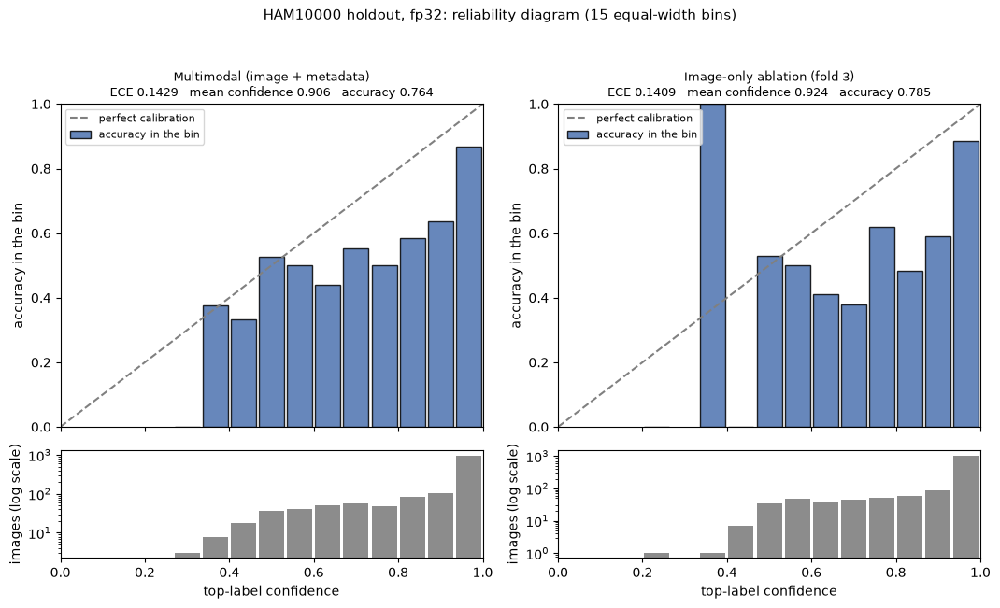


Wrote 16 files to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\holdout_results
  holdout_overall_fp32.csv                                         746 bytes
  holdout_overall_bf16_sensitivity.csv                             784 bytes
  holdout_fp32_vs_bf16_overall.csv                               2,048 bytes
  holdout_per_class_fp32_multimodal.csv                          1,830 bytes
  holdout_per_class_bf16_sensitivity_multimodal.csv              1,955 bytes
  holdout_confusion_counts_fp32_multimodal.csv                     199 bytes
  holdout_confusion_row_normalised_fp32_multimodal.csv             827 bytes
  holdout_calibration_bins_fp32_multimodal.csv                   1,698 bytes
  holdout_per_class_fp32_ablation.csv                            1,788 bytes
  holdout_per_class_bf16_sensitivity_ablation.csv                1,935 bytes
  holdout_confusion_counts_fp32_ablation.csv                       198 bytes
  holdout_confusion_row_normalised_fp32_ablation.csv         

In [21]:
"""
03_04_holdout_metrics.txt
Phase 5 -- Module 03: Holdout metrics -- Full metric set on the HAM10000 holdout, both models (computes and writes 16 files; safe to re-run)

TITLE: Holdout metrics

TITLE DESCRIPTION
  The first real Phase 5 numbers: every metric of the rules note on the 1,432-image holdout, for the multimodal model and
  the fold 3 image-only ablation. The fp32 probabilities are the headline. The bf16 probabilities that Phase 4 stored
  beside them are reported only in separate files, labelled as a sensitivity check, and are never mixed into a fp32 table.
  These holdout numbers are the "before" side of the BCN20000 generalisation gap (Module 08). Nothing here can change a
  model, a threshold or a Phase 1-4 file: the tables are computed from the stored probabilities.

CODE DESCRIPTION
  - Refuses to start unless the A4 file exists, passed, and was computed from these same prediction files. Per model it builds
    the per-class table (AUC-ROC, sensitivity, specificity, precision, F1, PR-AUC, sensitivity at 95% / 90% specificity,
    low-sample flag, "undefined" instead of 0), the overall row, both confusion matrices (counts, row-normalised), ECE with
    its bin table, Brier, and one reliability diagram for both models.
  - Writes 16 files to holdout_results/ (fp32 headline files; separate bf16 sensitivity files plus a fp32-vs-bf16 comparison;
    two metrics JSON files; the PNG). Writes are atomic and deterministic, so a re-run replaces files with identical content;
    re-run 03_05 afterwards to refresh the manifest.

Requires: 03_00 to 03_03 already run in this kernel (03_03 must have passed).
"""

import io
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PRECISION_FP32 = "fp32"
PRECISION_BF16 = "bf16 (sensitivity check)"

HOLDOUT_OUTPUT_NAMES = ["holdout_overall_fp32.csv", "holdout_metrics_fp32.json", "holdout_reliability_diagram_fp32.png",
                        "holdout_overall_bf16_sensitivity.csv", "holdout_fp32_vs_bf16_overall.csv", "holdout_metrics_bf16_sensitivity.json"]
for _kind in MODEL_KINDS:
    HOLDOUT_OUTPUT_NAMES += [f"holdout_per_class_fp32_{_kind}.csv", f"holdout_confusion_counts_fp32_{_kind}.csv",
                             f"holdout_confusion_row_normalised_fp32_{_kind}.csv", f"holdout_calibration_bins_fp32_{_kind}.csv",
                             f"holdout_per_class_bf16_sensitivity_{_kind}.csv"]
HOLDOUT_EXPECTED_FILES = [HOLDOUT_A4_PATH.name] + HOLDOUT_OUTPUT_NAMES          # 1 + 16 files; the manifest (03_05) comes after

COMPARE_KEYS = [("macro_auc_roc", "Macro AUC-ROC (primary)"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro-F1"),
                ("macro_precision", "Macro precision"), ("macro_pr_auc", "Macro PR-AUC"), ("ece", f"ECE (top-label, {ECE_BINS} bins)"),
                ("brier", "Brier (multiclass)"), ("accuracy", "Accuracy (comparability only)")]


def jsonable(obj):
    """Plain Python for JSON: NaN becomes the string 'undefined', NumPy numbers and arrays become lists and numbers."""
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return jsonable(obj.tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return UNDEFINED if np.isnan(obj) else float(obj)
    return obj


def check_a4_first():
    if not HOLDOUT_A4_PATH.is_file():
        raise RuntimeError(f"{HOLDOUT_A4_PATH.name} not found -- run 03_03 first: the null test must pass before any real number is computed.")
    with open(HOLDOUT_A4_PATH, "r", encoding="utf-8") as f:
        a4 = json.load(f)
    problems = []
    if a4.get("passed") is not True:
        problems.append("the A4 file does not say passed = true")
    if a4.get("prediction_file_sha256") != {kind: P4_PREDICTIONS[kind]["file_sha256"] for kind in MODEL_KINDS}:
        problems.append("the A4 file was computed from different prediction files than the ones loaded now")
    if problems:
        raise RuntimeError("A4 NULL TEST NOT ACCEPTED:\n  - " + "\n  - ".join(problems) + "\n  Re-run 03_02 and 03_03.")
    return a4


def metric_record(ms, model_kind, precision_label):
    record = {"model": model_kind, "model_label": MODEL_LABELS[model_kind], "precision_mode": precision_label,
              "n_images": ms["n_images"], "decision_rule": "argmax", "classes": ms["classes"],
              "per_class": ms["per_class"], "macro": ms["macro"],
              "balanced_accuracy": ms["balanced_accuracy"], "balanced_accuracy_classes_left_out": ms["balanced_accuracy_left_out"],
              "accuracy": ms["accuracy"], "class_distribution": ms["class_distribution"], "predicted_distribution": ms["predicted_distribution"],
              "confusion_counts": ms["confusion_counts"]}
    if "calibration" in ms:
        record["calibration"] = ms["calibration"]
        record["brier"] = ms["brier"]
    return jsonable(record)


def metrics_json(metrics_by_model, precision_label, description):
    return {"description": description, "precision_mode": precision_label, "created_at": now_iso(),
            "prediction_file_sha256": {kind: P4_PREDICTIONS[kind]["file_sha256"] for kind in MODEL_KINDS},
            "models": {kind: metric_record(metrics_by_model[kind], kind, precision_label) for kind in MODEL_KINDS}}


def with_model_column(table, model_kind):
    table = table.copy()
    table.insert(0, "Model", MODEL_LABELS[model_kind])
    return table


def reliability_figure(metrics_by_model):
    n_models = len(MODEL_KINDS)
    fig, axes = plt.subplots(2, n_models, figsize=(5.4 * n_models, 6.6), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
    for col, kind in enumerate(MODEL_KINDS):
        ms = metrics_by_model[kind]
        bins = ms["calibration_bins"]
        filled = bins[bins["n"] > 0]
        centres = (filled["low"] + filled["high"]) / 2.0
        ax, ax_n = axes[0, col], axes[1, col]
        ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
        ax.bar(centres, filled["accuracy"], width=0.9 / ECE_BINS, color="#4C72B0", edgecolor="black", alpha=0.85, label="accuracy in the bin")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_ylabel("accuracy in the bin")
        ax.set_title(f"{MODEL_LABELS[kind]}\nECE {ms['calibration']['ece']:.4f}   mean confidence {ms['calibration']['mean_confidence']:.3f}   "
                     f"accuracy {ms['calibration']['accuracy']:.3f}", fontsize=9)
        ax.legend(loc="upper left", fontsize=8)
        ax_n.bar(centres, filled["n"], width=0.9 / ECE_BINS, color="#8C8C8C")
        ax_n.set_yscale("log")
        ax_n.set_xlabel("top-label confidence")
        ax_n.set_ylabel("images (log scale)")
    fig.suptitle(f"HAM10000 holdout, fp32: reliability diagram ({ECE_BINS} equal-width bins)", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150)
    return fig, buffer.getvalue()


# ---------------------------------------------------------------------------
# 1. The null test must have passed on these same prediction files
# ---------------------------------------------------------------------------
check_a4_first()

# ---------------------------------------------------------------------------
# 2. Metrics: fp32 headline, bf16 sensitivity (separate objects, separate files)
# ---------------------------------------------------------------------------
HOLDOUT_METRICS_FP32 = {kind: compute_metric_set(HOLDOUT_LABELS, P4_PREDICTIONS[kind]["probs"]) for kind in MODEL_KINDS}
HOLDOUT_METRICS_BF16 = {kind: compute_metric_set(HOLDOUT_LABELS, P4_PREDICTIONS[kind]["probs_bf16"]) for kind in MODEL_KINDS}

_problems = []
for _kind in MODEL_KINDS:
    for _label, _ms in (("fp32", HOLDOUT_METRICS_FP32[_kind]), ("bf16", HOLDOUT_METRICS_BF16[_kind])):
        if int(_ms["confusion_counts"].sum()) != EXPECTED_HOLDOUT_ROWS:
            _problems.append(f"{_kind} {_label}: the confusion matrix does not hold {EXPECTED_HOLDOUT_ROWS} images")
        if _ms["class_distribution"] != EXPECTED_HOLDOUT_CLASS_COUNTS:
            _problems.append(f"{_kind} {_label}: class counts {_ms['class_distribution']} differ from the expected")
        if sum(_ms["predicted_distribution"].values()) != EXPECTED_HOLDOUT_ROWS:
            _problems.append(f"{_kind} {_label}: predicted counts do not add up to {EXPECTED_HOLDOUT_ROWS}")
    if not np.array_equal(HOLDOUT_METRICS_FP32[_kind]["confusion_counts"].sum(axis=0), np.bincount(P4_PREDICTIONS[_kind]["pred"], minlength=len(CLASSES))):
        _problems.append(f"{_kind}: the fp32 confusion matrix column totals differ from the stored Phase 4 pred")
if _problems:
    raise RuntimeError("HOLDOUT METRICS SANITY CHECK FAILED:\n  - " + "\n  - ".join(_problems))

# ---------------------------------------------------------------------------
# 3. Tables
# ---------------------------------------------------------------------------
TABLES = {}
for _kind in MODEL_KINDS:
    TABLES[_kind] = {
        "per_class_fp32": metric_table(HOLDOUT_METRICS_FP32[_kind], PRECISION_FP32),
        "per_class_bf16": metric_table(HOLDOUT_METRICS_BF16[_kind], PRECISION_BF16),
    }
    TABLES[_kind]["counts"], TABLES[_kind]["row_normalised"] = confusion_frames(HOLDOUT_METRICS_FP32[_kind])
    TABLES[_kind]["calibration_bins"] = HOLDOUT_METRICS_FP32[_kind]["calibration_bins"].map(undef)

OVERALL_FP32 = pd.concat([overall_row(HOLDOUT_METRICS_FP32[k], MODEL_LABELS[k], PRECISION_FP32) for k in MODEL_KINDS], ignore_index=True)
OVERALL_BF16 = pd.concat([overall_row(HOLDOUT_METRICS_BF16[k], MODEL_LABELS[k], PRECISION_BF16) for k in MODEL_KINDS], ignore_index=True)

_rows = []
for _kind in MODEL_KINDS:
    _f32, _b16 = flatten_metrics(HOLDOUT_METRICS_FP32[_kind]), flatten_metrics(HOLDOUT_METRICS_BF16[_kind])
    for _key, _name in COMPARE_KEYS:
        _rows.append({"Model": MODEL_LABELS[_kind], "Metric": _name, "fp32 (headline)": undef(_f32[_key]),
                      "bf16 (sensitivity check)": undef(_b16[_key]), "bf16 minus fp32": undef(_b16[_key] - _f32[_key])})
    _changed = P4_PREDICTIONS[_kind]["n_changed_bf16"]
    _rows.append({"Model": MODEL_LABELS[_kind], "Metric": "images whose predicted class differs from the fp32 prediction",
                  "fp32 (headline)": 0, "bf16 (sensitivity check)": _changed, "bf16 minus fp32": _changed})
FP32_VS_BF16 = pd.DataFrame(_rows)

# ---------------------------------------------------------------------------
# 4. Print
# ---------------------------------------------------------------------------
print("=" * 100)
print("HAM10000 HOLDOUT -- 1,432 images, 1,067 lesions -- fp32 (headline)")
print("=" * 100)
print("\nOverall (macro AUC-ROC is the primary number; accuracy is last and for comparability only):")
print(show(OVERALL_FP32.drop(columns=["Precision mode"])).set_index("Model").T.to_string())

for _kind in MODEL_KINDS:
    print(f"\n--- {MODEL_LABELS[_kind]}: per class (one-vs-rest, argmax, fp32) ---")
    print(show(TABLES[_kind]["per_class_fp32"].drop(columns=["Precision mode"])).to_string(index=False))
    print(f"\n{MODEL_LABELS[_kind]}: confusion matrix, counts (rows = true class, columns = predicted class)")
    print(TABLES[_kind]["counts"].to_string())
    _cal = HOLDOUT_METRICS_FP32[_kind]["calibration"]
    print(f"Calibration: ECE {_cal['ece']:.4f}, max bin gap {_cal['mce']:.4f}, mean confidence {_cal['mean_confidence']:.4f}, "
          f"accuracy {_cal['accuracy']:.4f}, overconfidence {_cal['overconfidence']:+.4f}; Brier {HOLDOUT_METRICS_FP32[_kind]['brier']:.4f}")

print("\n" + "=" * 100)
print("bf16 SENSITIVITY CHECK (separate files; not part of any headline table)")
print("=" * 100)
print(show(FP32_VS_BF16, 4).to_string(index=False))
print("\nHoldout images whose predicted class changes between bf16 and fp32: "
      + ", ".join(f"{MODEL_LABELS[k]} {P4_PREDICTIONS[k]['n_changed_bf16']}" for k in MODEL_KINDS)
      + " (these match what Phase 4 disclosed; 'bf16' is Phase 3's training-time precision, fp32 is the Phase 4 and Phase 5 headline).")

_figure, _png_bytes = reliability_figure(HOLDOUT_METRICS_FP32)
plt.show()
plt.close(_figure)

# ---------------------------------------------------------------------------
# 5. Write (atomic; deterministic, so a re-run replaces files with identical content)
# ---------------------------------------------------------------------------
_description_fp32 = ("HAM10000 holdout (1,432 images), fp32 headline: one-vs-rest metrics per class, macro values over the defined classes, "
                     "balanced accuracy = mean of the 7 recalls, ECE top-label equal-width, multiclass Brier. 'undefined' means 0/0 and is never 0.")
_description_bf16 = ("SENSITIVITY CHECK ONLY. The same metrics computed from the bf16 probabilities stored by Phase 4. Never mixed into a fp32 headline table.")

_written = []


def _put_csv(name, frame, index=False):
    atomic_write_csv(frame, PHASE5_HOLDOUT_DIR / name, index=index)
    _written.append(name)


_put_csv("holdout_overall_fp32.csv", OVERALL_FP32)
_put_csv("holdout_overall_bf16_sensitivity.csv", OVERALL_BF16)
_put_csv("holdout_fp32_vs_bf16_overall.csv", FP32_VS_BF16)
for _kind in MODEL_KINDS:
    _put_csv(f"holdout_per_class_fp32_{_kind}.csv", with_model_column(TABLES[_kind]["per_class_fp32"], _kind))
    _put_csv(f"holdout_per_class_bf16_sensitivity_{_kind}.csv", with_model_column(TABLES[_kind]["per_class_bf16"], _kind))
    _put_csv(f"holdout_confusion_counts_fp32_{_kind}.csv", TABLES[_kind]["counts"], index=True)
    _put_csv(f"holdout_confusion_row_normalised_fp32_{_kind}.csv", TABLES[_kind]["row_normalised"].map(undef), index=True)
    _put_csv(f"holdout_calibration_bins_fp32_{_kind}.csv", with_model_column(TABLES[_kind]["calibration_bins"], _kind))

atomic_write_json(PHASE5_HOLDOUT_DIR / "holdout_metrics_fp32.json", metrics_json(HOLDOUT_METRICS_FP32, PRECISION_FP32, _description_fp32))
_written.append("holdout_metrics_fp32.json")
atomic_write_json(PHASE5_HOLDOUT_DIR / "holdout_metrics_bf16_sensitivity.json", metrics_json(HOLDOUT_METRICS_BF16, PRECISION_BF16, _description_bf16))
_written.append("holdout_metrics_bf16_sensitivity.json")
atomic_write_bytes(PHASE5_HOLDOUT_DIR / "holdout_reliability_diagram_fp32.png", _png_bytes)
_written.append("holdout_reliability_diagram_fp32.png")

if sorted(_written) != sorted(HOLDOUT_OUTPUT_NAMES):
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(_written) ^ set(HOLDOUT_OUTPUT_NAMES))}")

print(f"\nWrote {len(_written)} files to {PHASE5_HOLDOUT_DIR}")
for _name in _written:
    print(f"  {_name:<58}{(PHASE5_HOLDOUT_DIR / _name).stat().st_size:>10,} bytes")
print("Next: run 03_05 (re-reads every file from disk, recomputes by a second route, writes the manifest).")

In [22]:
"""
03_05_check_holdout_results.txt
Phase 5 -- Module 03: Holdout metrics -- Check the holdout results from disk and write the manifest (verification; safe to re-run)

TITLE: Check the holdout results

TITLE DESCRIPTION
  Closes Module 03. Every file written by 03_03 and 03_04 is read back from disk, and every number in it is recomputed
  by a second route that shares no code with the metric library: confusion matrix and recall/precision/F1 from
  scikit-learn, AUC-ROC from ranks (Mann-Whitney), PR-AUC from its threshold definition, sensitivity at fixed
  specificity by trying every threshold, ECE with np.digitize, Brier class by class. It also proves that the inputs did
  not change, that the rules note was written before the first result file, that nothing unexpected sits in the folder,
  and that the bf16 files stay separate from the fp32 files. Only if all checks pass is the manifest written.

CODE DESCRIPTION
  - Runs several hundred checks in 8 groups (inputs, rules note and folder contents; A4 file; per-class files; overall
    files; confusion and calibration files; JSON files; bf16 separation; PNG) and prints one line per group. All
    failures are collected and ONE error is raised at the end; in that case no manifest is written.
  - On success writes holdout_results/holdout_manifest.json: size and SHA-256 of all 17 result files, the SHA-256 of the
    two prediction files and of the rules note, and the fp32 headline numbers. Module 10 re-hashes these files against it.

Requires: 03_00 to 03_04 already run in this kernel (after a restart: re-run 01_01 to 01_05, 02_00, 02_02, then 03_00, 03_02 to 03_04).
"""

import json

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, precision_recall_fscore_support

CHECK_TOL = 1e-9
HOLDOUT_MANIFEST_PATH = PHASE5_HOLDOUT_DIR / "holdout_manifest.json"
PER_CLASS_COLUMNS = (["Model", "Precision mode", "Class", "N", "N predicted", "AUC-ROC", "Sensitivity (recall)", "Specificity",
                      "Precision", "F1", "PR-AUC"] + [SENS_AT_SPEC_COLUMNS[t] for t in SPECIFICITY_TARGETS] + ["Flag"])
PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"


# ---------------------------------------------------------------------------
# Second route: written separately from 03_00, on purpose
# ---------------------------------------------------------------------------

def alt_div(numerator, denominator):
    return NAN if denominator == 0 else float(numerator) / float(denominator)


def alt_auc(y_bin, scores):
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return NAN
    ranks = rankdata(scores)                                        # average ranks for ties
    return float((ranks[y_bin == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def alt_ap(y_bin, scores):
    n_pos = int(y_bin.sum())
    if n_pos == 0:
        return NAN
    order = np.argsort(-scores, kind="mergesort")
    sorted_scores, sorted_y = scores[order], y_bin[order]
    tp = np.cumsum(sorted_y)
    fp = np.cumsum(1 - sorted_y)
    last_of_group = np.concatenate([sorted_scores[1:] != sorted_scores[:-1], [True]])      # one threshold per distinct score
    tp, fp = tp[last_of_group], fp[last_of_group]
    precision = tp / (tp + fp)
    recall = tp / n_pos
    previous_recall = np.concatenate([[0.0], recall[:-1]])
    return float(np.sum((recall - previous_recall) * precision))


def alt_sens_at_spec(y_bin, scores, target):
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return NAN
    best_sens, best_spec = -1.0, -1.0
    for threshold in np.concatenate([[np.inf], np.unique(scores)[::-1]]):         # flag everything with score >= threshold
        flagged = scores >= threshold
        sens = float((flagged & (y_bin == 1)).sum()) / n_pos
        spec = 1.0 - float((flagged & (y_bin == 0)).sum()) / n_neg
        if spec >= target - 1e-12 and (sens > best_sens or (sens == best_sens and spec > best_spec)):
            best_sens, best_spec = sens, spec
    return best_sens


def alt_ece(labels, probs, n_bins):
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == labels).astype(np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    index = np.digitize(confidence, edges[1:-1], right=True)                       # bins are (low, high], the first also holds 0
    ece = 0.0
    for b in range(n_bins):
        in_bin = index == b
        if in_bin.any():
            ece += in_bin.mean() * abs(correct[in_bin].mean() - confidence[in_bin].mean())
    return float(ece)


def alt_brier(labels, probs):
    return float(sum(np.mean((probs[:, k] - (labels == k).astype(np.float64)) ** 2) for k in range(probs.shape[1])))


def alt_mean(values):
    defined = [v for v in values if not np.isnan(v)]
    return float(np.mean(defined)) if defined else NAN


def second_route(labels, probs):
    labels = np.asarray(labels, dtype=np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    k = probs.shape[1]
    pred = probs.argmax(axis=1)
    cm = confusion_matrix(labels, pred, labels=list(range(k)))
    total = int(cm.sum())
    tp = np.diag(cm).astype(np.float64)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = total - tp - fn - fp
    sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(labels, pred, labels=list(range(k)), average=None, zero_division=np.nan)
    per_class = {}
    for i, name in enumerate(CLASSES):
        y_bin = (labels == i).astype(np.int64)
        entry = {"n": int(cm[i].sum()), "n_predicted": int(cm[:, i].sum()),
                 "recall": alt_div(tp[i], tp[i] + fn[i]), "specificity": alt_div(tn[i], tn[i] + fp[i]),
                 "precision": alt_div(tp[i], tp[i] + fp[i]), "f1": alt_div(2 * tp[i], 2 * tp[i] + fp[i] + fn[i]),
                 "auc_roc": alt_auc(y_bin, probs[:, i]), "pr_auc": alt_ap(y_bin, probs[:, i]),
                 "sk_precision": float(sk_precision[i]), "sk_recall": float(sk_recall[i]), "sk_f1": float(sk_f1[i])}
        for target in SPECIFICITY_TARGETS:
            entry[SENS_AT_SPEC_KEYS[target]] = alt_sens_at_spec(y_bin, probs[:, i], target)
        per_class[name] = entry
    fields = ["auc_roc", "recall", "specificity", "precision", "f1", "pr_auc"] + [SENS_AT_SPEC_KEYS[t] for t in SPECIFICITY_TARGETS]
    macro = {field: alt_mean([per_class[c][field] for c in CLASSES]) for field in fields}
    return {"cm": cm, "per_class": per_class, "macro": macro, "balanced_accuracy": float(balanced_accuracy_score(labels, pred)),
            "accuracy": float(accuracy_score(labels, pred)), "ece": alt_ece(labels, probs, ECE_BINS), "brier": alt_brier(labels, probs)}


# ---------------------------------------------------------------------------
# The checks
# ---------------------------------------------------------------------------

def read_table(name, **kwargs):
    return pd.read_csv(PHASE5_HOLDOUT_DIR / name, dtype=str, keep_default_na=False, **kwargs)


def run_holdout_checks():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same(a, b, tol=CHECK_TOL):
        a, b = to_float(a), to_float(b)
        if np.isnan(a) or np.isnan(b):
            return bool(np.isnan(a) and np.isnan(b))
        return abs(a - b) <= tol

    def compare(group, label, found, wanted, tol=CHECK_TOL):
        check(group, label, same(found, wanted, tol), f"file says {found!r}, second route says {wanted!r}")

    alt = {"fp32": {k: second_route(HOLDOUT_LABELS, P4_PREDICTIONS[k]["probs"]) for k in MODEL_KINDS},
           "bf16": {k: second_route(HOLDOUT_LABELS, P4_PREDICTIONS[k]["probs_bf16"]) for k in MODEL_KINDS}}
    mode_text = {"fp32": PRECISION_FP32, "bf16": PRECISION_BF16}
    file_mode = {"fp32": "fp32", "bf16": "bf16_sensitivity"}

    # ---- 1. inputs, rules note, folder -------------------------------------------------------------------
    g = "inputs and rules note"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match (models, Phase 4 files incl. both prediction files, inputs, BCN20000 CSV)", True)
    except Exception as exc:  # noqa: BLE001 -- any failure here is a failed check, reported with the others
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    try:
        note = check_rules_note(verbose=False)
        check(g, "the rules note still equals the rules rebuilt from the constants", note["passed"], f"failed: {note['failed']}")
    except Exception as exc:  # noqa: BLE001
        note = None
        check(g, "the rules note could be checked", False, f"{type(exc).__name__}: {exc}")
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    for kind in MODEL_KINDS:
        check(g, f"{kind}: the loaded predictions are the file with the recorded SHA-256",
              sha256_of_file(P4_PREDICTIONS[kind]["file"]) == P4_PREDICTIONS[kind]["file_sha256"])

    present = sorted(p.name for p in PHASE5_HOLDOUT_DIR.rglob("*") if p.is_file())
    allowed = set(HOLDOUT_EXPECTED_FILES) | {HOLDOUT_MANIFEST_PATH.name}
    check(g, "all 17 promised result files exist", set(HOLDOUT_EXPECTED_FILES) <= set(present), f"missing: {sorted(set(HOLDOUT_EXPECTED_FILES) - set(present))}")
    check(g, "no other file sits in holdout_results (no leftover .tmp)", set(present) <= allowed, f"unexpected: {sorted(set(present) - allowed)}")
    check(g, "no result file is empty", all((PHASE5_HOLDOUT_DIR / n).stat().st_size > 0 for n in HOLDOUT_EXPECTED_FILES if (PHASE5_HOLDOUT_DIR / n).is_file()))

    # ---- 2. A4 file -------------------------------------------------------------------------------------
    g = "A4 null-test file"
    with open(HOLDOUT_A4_PATH, "r", encoding="utf-8") as f:
        a4 = json.load(f)
    check(g, "says passed = true", a4.get("passed") is True)
    check(g, "rule fields equal the constants of the rules note",
          a4["rule"]["n_shuffles"] == NULL_N_SHUFFLES and a4["rule"]["seed"] == RANDOM_SEED and a4["rule"]["auc_tolerance"] == NULL_AUC_TOL
          and a4["rule"]["balanced_accuracy_tolerance"] == NULL_BALANCED_ACC_TOL)
    check(g, "computed from the loaded prediction files", a4["prediction_file_sha256"] == {k: P4_PREDICTIONS[k]["file_sha256"] for k in MODEL_KINDS})
    for kind in MODEL_KINDS:
        again = run_null_test(HOLDOUT_LABELS, P4_PREDICTIONS[kind]["probs"])
        for quantity in ("macro_auc_roc", "balanced_accuracy"):
            check(g, f"{kind}: {quantity} mean reproduces exactly when the test is run again", same(a4["models"][kind][quantity]["mean"], again[quantity]["mean"], 1e-12),
                  f"{a4['models'][kind][quantity]['mean']!r} vs {again[quantity]['mean']!r}")

    # ---- 3. per-class files (fp32 and bf16) --------------------------------------------------------------
    for mode in ("fp32", "bf16"):
        for kind in MODEL_KINDS:
            g = f"per-class file, {mode}, {kind}"
            a = alt[mode][kind]
            df = read_table(f"holdout_per_class_{file_mode[mode]}_{kind}.csv")
            check(g, "columns are exactly the promised ones, in order", list(df.columns) == PER_CLASS_COLUMNS, f"found {list(df.columns)}")
            check(g, "8 rows: the 7 classes in model order, then MACRO", df["Class"].tolist() == [c.upper() for c in CLASSES] + ["MACRO"])
            check(g, "every row carries the precision-mode label of this file", (df["Precision mode"] == mode_text[mode]).all(), f"found {sorted(df['Precision mode'].unique())}")
            check(g, "every row carries the model name", (df["Model"] == MODEL_LABELS[kind]).all())
            check(g, "no metric cell is blank or reads nan/NaN/None (only the Flag column may be empty)",
                  not df.drop(columns=["Flag"]).apply(lambda col: col.str.strip().str.lower().isin(["", "nan", "none", "null"])).to_numpy().any())
            any_undefined = False
            for i, name in enumerate(CLASSES):
                row = df[df["Class"] == name.upper()].iloc[0]
                e = a["per_class"][name]
                compare(g, f"{name}: N", row["N"], e["n"])
                compare(g, f"{name}: N predicted", row["N predicted"], e["n_predicted"])
                for column, key in (("AUC-ROC", "auc_roc"), ("Sensitivity (recall)", "recall"), ("Specificity", "specificity"), ("Precision", "precision"),
                                    ("F1", "f1"), ("PR-AUC", "pr_auc")) + tuple((SENS_AT_SPEC_COLUMNS[t], SENS_AT_SPEC_KEYS[t]) for t in SPECIFICITY_TARGETS):
                    compare(g, f"{name}: {column}", row[column], e[key])
                compare(g, f"{name}: precision agrees with scikit-learn", row["Precision"], e["sk_precision"])
                compare(g, f"{name}: recall agrees with scikit-learn", row["Sensitivity (recall)"], e["sk_recall"])
                compare(g, f"{name}: F1 agrees with scikit-learn", row["F1"], e["sk_f1"])
                check(g, f"{name}: precision reads 'undefined' exactly when the class is never predicted", (row["Precision"] == UNDEFINED) == (e["n_predicted"] == 0))
                check(g, f"{name}: the low-sample flag is present exactly when N < {LOW_SAMPLE_N}", ("low sample" in row["Flag"]) == (e["n"] < LOW_SAMPLE_N), f"N {e['n']}, flag {row['Flag']!r}")
                any_undefined = any_undefined or any(np.isnan(e[f]) for f in ("auc_roc", "recall", "precision", "f1", "pr_auc"))
            flagged = sorted(r["Class"] for _, r in df[df["Class"] != "MACRO"].iterrows() if "low sample" in r["Flag"])
            check(g, "exactly DF and VASC are flagged low-sample", flagged == ["DF", "VASC"], f"flagged {flagged}")
            macro_row = df[df["Class"] == "MACRO"].iloc[0]
            for column, key in (("AUC-ROC", "auc_roc"), ("Sensitivity (recall)", "recall"), ("Specificity", "specificity"), ("Precision", "precision"),
                                ("F1", "f1"), ("PR-AUC", "pr_auc")) + tuple((SENS_AT_SPEC_COLUMNS[t], SENS_AT_SPEC_KEYS[t]) for t in SPECIFICITY_TARGETS):
                compare(g, f"MACRO: {column} = mean over the defined classes", macro_row[column], a["macro"][key])
            check(g, "MACRO flag names the classes left out exactly when some class is undefined", ("excludes" in macro_row["Flag"]) == any_undefined, macro_row["Flag"])
            compare(g, "MACRO recall equals scikit-learn's balanced accuracy", macro_row["Sensitivity (recall)"], a["balanced_accuracy"])

    # ---- 4. overall files ---------------------------------------------------------------------------------
    for mode in ("fp32", "bf16"):
        g = f"overall file, {mode}"
        df = read_table("holdout_overall_fp32.csv" if mode == "fp32" else "holdout_overall_bf16_sensitivity.csv")
        check(g, "one row per model, in model order", df["Model"].tolist() == [MODEL_LABELS[k] for k in MODEL_KINDS])
        check(g, "every row carries the precision-mode label of this file", (df["Precision mode"] == mode_text[mode]).all())
        check(g, "accuracy is the last column", df.columns[-1] == "Accuracy (comparability only)" and df.columns[0] == "Model")
        for kind in MODEL_KINDS:
            row = df[df["Model"] == MODEL_LABELS[kind]].iloc[0]
            a = alt[mode][kind]
            compare(g, f"{kind}: N images", row["N images"], EXPECTED_HOLDOUT_ROWS)
            compare(g, f"{kind}: macro AUC-ROC", row["Macro AUC-ROC (primary)"], a["macro"]["auc_roc"])
            compare(g, f"{kind}: balanced accuracy (scikit-learn)", row["Balanced accuracy"], a["balanced_accuracy"])
            compare(g, f"{kind}: macro-F1", row["Macro-F1"], a["macro"]["f1"])
            compare(g, f"{kind}: macro precision", row["Macro precision"], a["macro"]["precision"])
            compare(g, f"{kind}: macro PR-AUC", row["Macro PR-AUC"], a["macro"]["pr_auc"])
            compare(g, f"{kind}: macro precision, classes left out", row["Macro precision, classes left out"], sum(np.isnan(a["per_class"][c]["precision"]) for c in CLASSES))
            compare(g, f"{kind}: ECE ({ECE_BINS} bins, np.digitize)", row[f"ECE (top-label, {ECE_BINS} bins)"], a["ece"])
            compare(g, f"{kind}: Brier", row["Brier (multiclass)"], a["brier"])
            compare(g, f"{kind}: accuracy (scikit-learn)", row["Accuracy (comparability only)"], a["accuracy"])

    # ---- 5. confusion and calibration files (fp32) --------------------------------------------------------
    for kind in MODEL_KINDS:
        g = f"confusion and calibration files, fp32, {kind}"
        a = alt["fp32"][kind]
        counts = read_table(f"holdout_confusion_counts_fp32_{kind}.csv", index_col=0).astype(np.int64)
        check(g, "counts matrix equals scikit-learn's confusion matrix", np.array_equal(counts.to_numpy(), a["cm"]))
        check(g, "counts matrix sums to 1,432 and its row sums are the class counts", counts.to_numpy().sum() == EXPECTED_HOLDOUT_ROWS and
              {c: int(counts.to_numpy()[i].sum()) for i, c in enumerate(CLASSES)} == EXPECTED_HOLDOUT_CLASS_COUNTS)
        check(g, "row and column labels are the 7 classes in model order", counts.index.tolist() == [c.upper() for c in CLASSES] and counts.columns.tolist() == [c.upper() for c in CLASSES])
        normalised = read_table(f"holdout_confusion_row_normalised_fp32_{kind}.csv", index_col=0)
        want = a["cm"] / a["cm"].sum(axis=1, keepdims=True)
        check(g, "row-normalised matrix equals counts / row sums", all(same(normalised.to_numpy()[i, j], want[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES))))
        bins = read_table(f"holdout_calibration_bins_fp32_{kind}.csv")
        check(g, f"calibration table has {ECE_BINS} bins", len(bins) == ECE_BINS)
        edges = np.linspace(0.0, 1.0, ECE_BINS + 1)
        check(g, "bin edges are the equal-width edges on [0, 1]", all(same(bins["low"].iloc[i], edges[i]) and same(bins["high"].iloc[i], edges[i + 1]) for i in range(ECE_BINS)))
        n_in_bins = bins["n"].astype(np.int64)
        check(g, "bin counts add up to 1,432", int(n_in_bins.sum()) == EXPECTED_HOLDOUT_ROWS)
        ece_from_bins = sum(int(n) / EXPECTED_HOLDOUT_ROWS * to_float(gap) for n, gap in zip(n_in_bins, bins["gap"]) if int(n) > 0)
        compare(g, "ECE recomputed from the bin table equals the second-route ECE", ece_from_bins, a["ece"])
        check(g, "empty bins read 'undefined' (never 0)", all((to_float(m) != to_float(m)) for n, m in zip(n_in_bins, bins["mean_confidence"]) if int(n) == 0))

    # ---- 6. JSON files --------------------------------------------------------------------------------------
    for mode, name in (("fp32", "holdout_metrics_fp32.json"), ("bf16", "holdout_metrics_bf16_sensitivity.json")):
        g = f"JSON file, {mode}"
        with open(PHASE5_HOLDOUT_DIR / name, "r", encoding="utf-8") as f:
            data = json.load(f)
        check(g, "precision mode of the file", data["precision_mode"] == mode_text[mode], data["precision_mode"])
        check(g, "computed from the loaded prediction files", data["prediction_file_sha256"] == {k: P4_PREDICTIONS[k]["file_sha256"] for k in MODEL_KINDS})
        for kind in MODEL_KINDS:
            m, a = data["models"][kind], alt[mode][kind]
            check(g, f"{kind}: precision mode inside the record", m["precision_mode"] == mode_text[mode])
            check(g, f"{kind}: confusion matrix equals scikit-learn's", np.array_equal(np.array(m["confusion_counts"]), a["cm"]))
            compare(g, f"{kind}: macro AUC-ROC", m["macro"]["auc_roc"], a["macro"]["auc_roc"])
            compare(g, f"{kind}: balanced accuracy", m["balanced_accuracy"], a["balanced_accuracy"])
            compare(g, f"{kind}: accuracy", m["accuracy"], a["accuracy"])
            compare(g, f"{kind}: ECE", m["calibration"]["ece"], a["ece"])
            compare(g, f"{kind}: Brier", m["brier"], a["brier"])
            for c in CLASSES:
                for field in ("auc_roc", "recall", "precision", "f1", "pr_auc"):
                    compare(g, f"{kind} {c}: {field}", m["per_class"][c][field], a["per_class"][c][field])
                for target in SPECIFICITY_TARGETS:
                    compare(g, f"{kind} {c}: {SENS_AT_SPEC_KEYS[target]}", m["per_class"][c][SENS_AT_SPEC_KEYS[target]], a["per_class"][c][SENS_AT_SPEC_KEYS[target]])

    # ---- 7. bf16 stays separate; comparison file ---------------------------------------------------------------
    g = "bf16 separation and comparison file"
    for kind in MODEL_KINDS:
        check(g, f"{kind}: the bf16 confusion matrix differs from the fp32 one (the bf16 files are not copies)",
              not np.array_equal(alt["bf16"][kind]["cm"], alt["fp32"][kind]["cm"]))
        recomputed_changed = int((P4_PREDICTIONS[kind]["pred"] != P4_PREDICTIONS[kind]["pred_bf16"]).sum())
        check(g, f"{kind}: changed-image count equals what Phase 4 disclosed", recomputed_changed == EXPECTED_BF16_CHANGED[kind], f"{recomputed_changed}")
    compare_df = read_table("holdout_fp32_vs_bf16_overall.csv")
    mapping = {"Macro AUC-ROC (primary)": ("macro", "auc_roc"), "Balanced accuracy": ("top", "balanced_accuracy"), "Macro-F1": ("macro", "f1"),
               "Macro precision": ("macro", "precision"), "Macro PR-AUC": ("macro", "pr_auc"), f"ECE (top-label, {ECE_BINS} bins)": ("top", "ece"),
               "Brier (multiclass)": ("top", "brier"), "Accuracy (comparability only)": ("top", "accuracy")}
    for kind in MODEL_KINDS:
        rows = compare_df[compare_df["Model"] == MODEL_LABELS[kind]]
        check(g, f"{kind}: comparison file has the 8 metrics and the changed-image row", len(rows) == len(mapping) + 1)
        for metric, (where, key) in mapping.items():
            row = rows[rows["Metric"] == metric].iloc[0]
            f32 = alt["fp32"][kind]["macro"][key] if where == "macro" else alt["fp32"][kind][key]
            b16 = alt["bf16"][kind]["macro"][key] if where == "macro" else alt["bf16"][kind][key]
            compare(g, f"{kind}: {metric}, fp32 column", row["fp32 (headline)"], f32)
            compare(g, f"{kind}: {metric}, bf16 column", row["bf16 (sensitivity check)"], b16)
            compare(g, f"{kind}: {metric}, difference column", row["bf16 minus fp32"], b16 - f32)
        changed_row = rows[rows["Metric"].str.startswith("images whose predicted class differs")].iloc[0]
        compare(g, f"{kind}: changed images in the comparison file", changed_row["bf16 (sensitivity check)"], EXPECTED_BF16_CHANGED[kind])

    # ---- 8. PNG --------------------------------------------------------------------------------------------------
    g = "reliability diagram"
    png = (PHASE5_HOLDOUT_DIR / "holdout_reliability_diagram_fp32.png").read_bytes()
    check(g, "is a PNG file", png[:8] == PNG_SIGNATURE, f"first bytes {png[:8]!r}")
    check(g, "is not trivially small", len(png) > 20_000, f"{len(png):,} bytes")

    return checks, alt


CHECKS, ALT_ROUTE = run_holdout_checks()

# ---------------------------------------------------------------------------
# Report
# ---------------------------------------------------------------------------
_groups = {}
for _group, _name, _ok, _detail in CHECKS:
    _entry = _groups.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 03 check (every file read back from disk, every number recomputed by a second route)")
for _group, (_n, _bad) in _groups.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<62}{_n:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))

_failed = [(g, n, d) for g, n, ok, d in CHECKS if not ok]
if _failed:
    lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    more = f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""
    raise RuntimeError(f"MODULE 03 CHECK FAILED ({len(_failed)} of {len(CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(lines) + more)

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
with open(PHASE5_HOLDOUT_DIR / "holdout_metrics_fp32.json", "r", encoding="utf-8") as _f:
    _fp32_json = json.load(_f)
_headline = {kind: {"macro_auc_roc": _fp32_json["models"][kind]["macro"]["auc_roc"], "balanced_accuracy": _fp32_json["models"][kind]["balanced_accuracy"],
                    "macro_f1": _fp32_json["models"][kind]["macro"]["f1"], "ece": _fp32_json["models"][kind]["calibration"]["ece"],
                    "brier": _fp32_json["models"][kind]["brier"], "accuracy": _fp32_json["models"][kind]["accuracy"]} for kind in MODEL_KINDS}
_rules = check_rules_note(verbose=False)
_manifest = {
    "module": "Phase 5, Module 03 -- holdout metrics", "created_at": now_iso(), "n_checks": len(CHECKS), "all_passed": True,
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
    "inputs": {kind: {"file": P4_PREDICTIONS[kind]["file"], "sha256": P4_PREDICTIONS[kind]["file_sha256"], "model_sha256": P4_PREDICTIONS[kind]["model_sha256"],
                      "bf16_changed_images": P4_PREDICTIONS[kind]["n_changed_bf16"]} for kind in MODEL_KINDS},
    "headline_fp32": _headline,
    "files": {name: {"bytes": (PHASE5_HOLDOUT_DIR / name).stat().st_size, "sha256": sha256_of_file(PHASE5_HOLDOUT_DIR / name)} for name in HOLDOUT_EXPECTED_FILES},
}
atomic_write_json(HOLDOUT_MANIFEST_PATH, jsonable(_manifest))

print(f"\nMODULE 03 CHECK PASSED ({len(CHECKS)} checks in {len(_groups)} groups). Manifest written: {HOLDOUT_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); every result file is newer than it.")
print("\nfp32 headline (HAM10000 holdout):")
print(pd.DataFrame(_headline).T.rename(columns={"macro_auc_roc": "macro AUC-ROC", "balanced_accuracy": "balanced acc.", "macro_f1": "macro-F1",
                                                "ece": "ECE", "brier": "Brier", "accuracy": "accuracy"}).to_string(float_format=lambda v: f"{v:.4f}"))
print("\nResult files (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<58}{_info['bytes']:>10,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 03 check (every file read back from disk, every number recomputed by a second route)
  [PASS] inputs and rules note                                            8 checks
  [PASS] A4 null-test file                                                7 checks
  [PASS] per-class file, fp32, multimodal                               121 checks
  [PASS] per-class file, fp32, ablation                                 121 checks
  [PASS] per-class file, bf16, multimodal                               121 checks
  [PASS] per-class file, bf16, ablation                                 121 checks
  [PASS] overall file, fp32                                              23 checks
  [PASS] overall file, bf16                                              23 checks
  [PASS] confusion and calibration files, fp32, multimodal                9 checks
  [PASS] confusion and calibration files, fp32, ablation                 

# Module 4

In [23]:
"""
04_00_load_bcn_metadata.txt
Phase 5 -- Module 04: BCN20000 inventory -- Load the metadata CSV and look at every diagnosis (verification; writes nothing; safe to re-run)

TITLE: Load the BCN20000 metadata

TITLE DESCRIPTION
  Module 04 turns the 18,946-row BCN20000 export into one verified inventory table. This first cell only reads the
  metadata CSV and proves it is the file Phase 5 started with and that it looks the way the Planning says: 18,946 rows,
  18,946 distinct isic_id, every row from Hospital Clinic de Barcelona, dermoscopic, licence CC-BY-NC, a lesion_id on
  every row. It then prints every distinct diagnosis combination with its count, so that what the next cell maps to a
  class, to SCC or to out-of-distribution can be read with the eyes first. Nothing is mapped and nothing is scored here.

CODE DESCRIPTION
  - Re-checks the 11 start fingerprints (so the CSV is byte-identical to the Phase 5 start record), reads the CSV with every
    column as text (an empty cell stays an empty string, never NaN), checks the column list, row count, uniqueness and
    formats of isic_id, lesion_id, licence, image type and attribution, and the four diagnosis_1 counts seen in 01_00.
  - Builds BCN_META (the 16 raw columns plus dx1, dx2, dx3 = the diagnosis columns passed through norm_label, which only
    changes dash variants and spacing) and DIAGNOSIS_TABLE (every distinct triple with its count). Reads only.

Requires: 01_01 to 01_05, 02_00 to 02_02 and 03_00 already run in this kernel (03_00 supplies atomic_write_csv and fmt).
"""

import pandas as pd

BCN_EXPECTED_COLUMNS = ["isic_id", "attribution", "copyright_license", "age_approx", "anatom_site_1", "anatom_site_2",
                        "anatom_site_special", "concomitant_biopsy", "diagnosis_1", "diagnosis_2", "diagnosis_3",
                        "diagnosis_confirm_type", "image_type", "lesion_id", "melanocytic", "sex"]
BCN_EXPECTED_ATTRIBUTION = "Hospital Clínic de Barcelona"
BCN_EXPECTED_LICENCE = "CC-BY-NC"
BCN_EXPECTED_IMAGE_TYPE = "dermoscopic"
BCN_EXPECTED_DIAGNOSIS_1 = {"Malignant": 8871, "Benign": 7831, "": 1156, "Indeterminate": 1088}      # seen in the 01_00 printout
BCN_ID_PATTERN = r"^ISIC_\d{7}$"                  # a plain string: pandas str.match wants text, not a compiled pattern
BCN_SOURCE_TEXT = ("ISIC Archive export dated 2026-10-04 of the BCN20000 dataset (Hospital Clinic de Barcelona), together with "
                   "Hernandez-Perez et al., Scientific Data 11:641 (2024). Licence CC-BY-NC, stated in every row.")


def load_bcn_metadata():
    record = record_or_check_fingerprints(must_exist=True)             # stops if any fingerprinted file (incl. the CSV) has changed
    csv_record = record["bcn_files"]["bcn20000_metadata_csv"]
    raw = pd.read_csv(BCN_METADATA_CSV_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")

    problems = []
    if list(raw.columns) != BCN_EXPECTED_COLUMNS:
        problems.append(f"columns are {list(raw.columns)}, expected {BCN_EXPECTED_COLUMNS}")
    if len(raw) != EXPECTED_BCN_ROWS:
        problems.append(f"{len(raw):,} rows, expected {EXPECTED_BCN_ROWS:,}")
    if raw["isic_id"].nunique() != EXPECTED_BCN_ROWS:
        problems.append(f"{raw['isic_id'].nunique():,} distinct isic_id, expected {EXPECTED_BCN_ROWS:,}")
    bad_ids = raw.loc[~raw["isic_id"].str.match(BCN_ID_PATTERN), "isic_id"]
    if len(bad_ids):
        problems.append(f"{len(bad_ids)} isic_id value(s) are not ISIC_ + 7 digits, e.g. {bad_ids.head(3).tolist()}")
    if (raw["lesion_id"].str.strip() == "").any():
        problems.append(f"{int((raw['lesion_id'].str.strip() == '').sum())} row(s) have no lesion_id")
    if raw["lesion_id"].nunique() != EXPECTED_BCN_LESIONS_ALL:
        problems.append(f"{raw['lesion_id'].nunique():,} distinct lesion_id, expected {EXPECTED_BCN_LESIONS_ALL:,}")
    for column, wanted in (("copyright_license", BCN_EXPECTED_LICENCE), ("image_type", BCN_EXPECTED_IMAGE_TYPE), ("attribution", BCN_EXPECTED_ATTRIBUTION)):
        found = raw[column].value_counts().to_dict()
        if found != {wanted: EXPECTED_BCN_ROWS}:
            problems.append(f"{column}: {found}, expected {{{wanted!r}: {EXPECTED_BCN_ROWS}}}")
    found_dx1 = raw["diagnosis_1"].value_counts().to_dict()
    if found_dx1 != BCN_EXPECTED_DIAGNOSIS_1:
        problems.append(f"diagnosis_1 counts {found_dx1} differ from the expected {BCN_EXPECTED_DIAGNOSIS_1}")
    if problems:
        raise RuntimeError("BCN20000 METADATA CHECK FAILED:\n  - " + "\n  - ".join(problems))

    meta = raw.copy()
    changed = 0
    for source, target in (("diagnosis_1", "dx1"), ("diagnosis_2", "dx2"), ("diagnosis_3", "dx3")):
        meta[target] = raw[source].map(norm_label)
        changed += int((meta[target] != raw[source]).sum())
    table = (meta.groupby(["dx1", "dx2", "dx3"], sort=True).size().reset_index(name="images")
             .sort_values(["images", "dx3"], ascending=[False, True]).reset_index(drop=True))
    return raw, meta, table, csv_record, changed


BCN_RAW, BCN_META, DIAGNOSIS_TABLE, BCN_CSV_RECORD, _n_normalised = load_bcn_metadata()

print("BCN20000 metadata loaded and checked (reads only; nothing written).")
print(f"  file            : {BCN_METADATA_CSV_PATH.name}   {BCN_CSV_RECORD['bytes']:,} bytes   SHA-256 {BCN_CSV_RECORD['sha256'][:16]}... (unchanged since the Phase 5 start)")
print(f"  rows            : {len(BCN_RAW):,}, distinct isic_id {BCN_RAW['isic_id'].nunique():,} (all ISIC_ + 7 digits), distinct lesion_id {BCN_RAW['lesion_id'].nunique():,}, no lesion_id missing")
print(f"  every row       : attribution {BCN_EXPECTED_ATTRIBUTION}, image_type {BCN_EXPECTED_IMAGE_TYPE}, licence {BCN_EXPECTED_LICENCE}")
print(f"  diagnosis_1     : {BCN_EXPECTED_DIAGNOSIS_1} (blank = no diagnosis)")
print(f"  normalisation   : {_n_normalised} diagnosis cell(s) changed by norm_label (dash variants / spacing)")
print(f"  source          : {BCN_SOURCE_TEXT}")

print(f"\nEvery distinct diagnosis combination ({len(DIAGNOSIS_TABLE)} of them), blank = empty cell:")
_shown = DIAGNOSIS_TABLE.copy()
for _column in ("dx1", "dx2", "dx3"):
    _shown[_column] = _shown[_column].replace("", "(blank)")
print(_shown.rename(columns={"dx1": "diagnosis_1", "dx2": "diagnosis_2", "dx3": "diagnosis_3"}).to_string(index=False))
print(f"\nTotal {int(DIAGNOSIS_TABLE['images'].sum()):,} images. The next cell (04_01) assigns each combination to exactly one group.")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
BCN20000 metadata loaded and checked (reads only; nothing written).
  file            : bcn20000_metadata_2026-10-04.csv   3,639,183 bytes   SHA-256 9ab7c4334df26eee... (unchanged since the Phase 5 start)
  rows            : 18,946, distinct isic_id 18,946 (all ISIC_ + 7 digits), distinct lesion_id 5,440, no lesion_id missing
  every row       : attribution Hospital Clínic de Barcelona, image_type dermoscopic, licence CC-BY-NC
  diagnosis_1     : {'Malignant': 8871, 'Benign': 7831, '': 1156, 'Indeterminate': 1088} (blank = no diagnosis)
  normalisation   : 0 diagnosis cell(s) changed by norm_label (dash variants / spacing)
  source          : ISIC Archive export dated 2026-10-04 of the BCN20000 dataset (Hospital Clinic de Barcelona), together with Hernandez-Perez et al., Scientific Data 11:641 (2024). Licence CC-BY-NC, stated in every row.

Every distinct diagnosis combination (12 of them), blank = 

In [24]:
"""
04_01_assign_groups.txt
Phase 5 -- Module 04: BCN20000 inventory -- Put every row in exactly one group and check all counts (verification; writes nothing; safe to re-run)

TITLE: Assign groups and check the counts

TITLE DESCRIPTION
  Applies the label rules fixed in the rules note to every one of the 18,946 rows: the class comes from diagnosis_3
  (BKL = Seborrheic keratosis + Solar lentigo), VASC from diagnosis_2 when diagnosis_3 is empty, SCC is set aside for the
  secondary observation, and the out-of-distribution rows (no diagnosis at all, Melanoma metastasis, Scar) are excluded.
  The rule set is closed: a diagnosis combination that no rule covers stops the run instead of being guessed. Every row
  must end up in exactly one group, and every count must equal the Planning's: 16,284 primary images in 4,591 lesions
  (NV 5,647, MEL 4,003, BCC 3,676, BKL 1,551, AKIEC 1,088, DF 168, VASC 151), 559 SCC, 2,103 out-of-distribution.

CODE DESCRIPTION
  - assign_group() is applied once per distinct diagnosis combination; all unseen combinations are collected and raised
    together. Checks: group counts, class counts, out-of-distribution parts, lesion counts (all, per group, primary, max
    images per lesion), no lesion spanning two groups, no primary lesion with two classes (so lesion-level aggregation in
    A5 and the lesion bootstrap of Phase 6 are well defined), diagnosis_confirm_type reported and never filtered on.
  - Adds group, class_name, label and ood_reason to BCN_META (this becomes BCN_INVENTORY) and builds GROUP_COUNT_TABLE,
    CONFIRM_TYPE_TABLE and the diagnosis table with its assigned group. Reads and prints only; 04_04 writes the files.

Requires: 04_00 already run in this kernel.
"""

import pandas as pd

GROUP_PRIMARY, GROUP_SCC, GROUP_OOD = "primary", "scc", "ood"
OOD_NO_DIAGNOSIS = "no diagnosis"
CONFIRM_TYPE_EMPTY_LABEL = "(empty)"
# Lesion facts verified on the real CSV on 2026-10-08 (data facts, not results); asserted here so a changed file cannot slip through.
EXPECTED_BCN_LESIONS_BY_GROUP = {GROUP_PRIMARY: EXPECTED_BCN_PRIMARY_LESIONS, GROUP_SCC: 161, GROUP_OOD: 688}
EXPECTED_BCN_NV_CONFIRM_TYPE_EMPTY = 1367              # of the 2,867 primary images with an empty diagnosis_confirm_type (Planning Section 4.3)
EXPECTED_CONFIRM_TYPES = {"histopathology", "confocal microscopy with consensus dermoscopy", ""}


def assign_group(dx1, dx2, dx3):
    """(group, class_name, ood_reason) for one normalised diagnosis triple. KeyError if no rule covers it."""
    if dx3 in BCN_DIAG3_TO_CLASS:
        return GROUP_PRIMARY, BCN_DIAG3_TO_CLASS[dx3], ""
    if dx3 == "" and dx2 == BCN_VASC_DIAG2:
        return GROUP_PRIMARY, "vasc", ""
    if dx3 == BCN_SCC_DIAG3:
        return GROUP_SCC, "scc", ""
    if dx3 in BCN_OOD_DIAG3:
        return GROUP_OOD, "", dx3
    if dx1 == "" and dx2 == "" and dx3 == "":
        return GROUP_OOD, "", OOD_NO_DIAGNOSIS
    raise KeyError((dx1, dx2, dx3))


def build_inventory(meta):
    inventory = meta.copy()
    mapping, unseen = {}, []
    for row in inventory[["dx1", "dx2", "dx3"]].drop_duplicates().itertuples(index=False):
        try:
            mapping[tuple(row)] = assign_group(*row)
        except KeyError:
            unseen.append(tuple(row))
    if unseen:
        counts = inventory.groupby(["dx1", "dx2", "dx3"]).size()
        raise RuntimeError("DIAGNOSIS COMBINATION(S) NO RULE COVERS (nothing was guessed):\n  - "
                           + "\n  - ".join(f"{triple}: {int(counts[triple])} image(s)" for triple in unseen))
    triples = list(zip(inventory["dx1"], inventory["dx2"], inventory["dx3"]))
    inventory["group"] = [mapping[t][0] for t in triples]
    inventory["class_name"] = [mapping[t][1] for t in triples]
    inventory["ood_reason"] = [mapping[t][2] for t in triples]
    inventory["label"] = [CLASS_TO_IDX[c] if g == GROUP_PRIMARY else -1 for g, c in zip(inventory["group"], inventory["class_name"])]
    return inventory, mapping


def check_inventory(inventory):
    problems = []
    n = len(inventory)
    groups = inventory["group"].value_counts().to_dict()
    if sum(groups.values()) != n or not set(groups) <= {GROUP_PRIMARY, GROUP_SCC, GROUP_OOD}:
        problems.append(f"rows do not fall into exactly the three groups: {groups}")
    expected_groups = {GROUP_PRIMARY: EXPECTED_BCN_PRIMARY_TOTAL, GROUP_SCC: EXPECTED_BCN_SCC, GROUP_OOD: EXPECTED_BCN_OOD}
    if groups != expected_groups:
        problems.append(f"group counts {groups}, expected {expected_groups}")
    primary = inventory[inventory["group"] == GROUP_PRIMARY]
    per_class = {c: int((primary["class_name"] == c).sum()) for c in CLASSES}
    if per_class != EXPECTED_BCN_PRIMARY_COUNTS:
        problems.append(f"primary class counts {per_class}, expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    ood_parts = inventory[inventory["group"] == GROUP_OOD]["ood_reason"].value_counts().to_dict()
    if ood_parts != EXPECTED_BCN_OOD_PARTS:
        problems.append(f"out-of-distribution parts {ood_parts}, expected {EXPECTED_BCN_OOD_PARTS}")
    if set(primary["label"]) - set(range(len(CLASSES))) or (inventory.loc[inventory["group"] != GROUP_PRIMARY, "label"] != -1).any():
        problems.append("labels are not 0..6 for primary rows and -1 for every other row")

    lesions_all = inventory["lesion_id"].nunique()
    lesions_by_group = {g: int(inventory.loc[inventory["group"] == g, "lesion_id"].nunique()) for g in (GROUP_PRIMARY, GROUP_SCC, GROUP_OOD)}
    per_lesion_groups = inventory.groupby("lesion_id")["group"].nunique()
    per_lesion_classes = primary.groupby("lesion_id")["class_name"].nunique()
    max_images = int(inventory["lesion_id"].value_counts().max())
    if lesions_all != EXPECTED_BCN_LESIONS_ALL:
        problems.append(f"{lesions_all:,} lesions, expected {EXPECTED_BCN_LESIONS_ALL:,}")
    if lesions_by_group != EXPECTED_BCN_LESIONS_BY_GROUP:
        problems.append(f"lesions per group {lesions_by_group}, expected {EXPECTED_BCN_LESIONS_BY_GROUP}")
    if max_images != EXPECTED_BCN_MAX_IMAGES_PER_LESION:
        problems.append(f"largest lesion has {max_images} images, expected {EXPECTED_BCN_MAX_IMAGES_PER_LESION}")
    if int((per_lesion_groups > 1).sum()) != 0:
        problems.append(f"{int((per_lesion_groups > 1).sum())} lesion(s) have images in more than one group")
    if int((per_lesion_classes > 1).sum()) != 0:
        problems.append(f"{int((per_lesion_classes > 1).sum())} primary lesion(s) have images of more than one class")

    confirm = inventory["diagnosis_confirm_type"]
    if set(confirm.unique()) != EXPECTED_CONFIRM_TYPES:
        problems.append(f"diagnosis_confirm_type values {sorted(set(confirm.unique()))}, expected {sorted(EXPECTED_CONFIRM_TYPES)}")
    empty_primary = int((primary["diagnosis_confirm_type"] == "").sum())
    empty_nv = int(((primary["diagnosis_confirm_type"] == "") & (primary["class_name"] == "nv")).sum())
    if empty_primary != EXPECTED_BCN_CONFIRM_TYPE_EMPTY:
        problems.append(f"{empty_primary:,} primary images with an empty diagnosis_confirm_type, expected {EXPECTED_BCN_CONFIRM_TYPE_EMPTY:,}")
    if empty_nv != EXPECTED_BCN_NV_CONFIRM_TYPE_EMPTY:
        problems.append(f"{empty_nv:,} NV images with an empty diagnosis_confirm_type, expected {EXPECTED_BCN_NV_CONFIRM_TYPE_EMPTY:,}")
    if problems:
        raise RuntimeError("BCN20000 GROUP CHECK FAILED:\n  - " + "\n  - ".join(problems))
    return {"groups": groups, "per_class": per_class, "ood_parts": ood_parts, "lesions_all": int(lesions_all), "lesions_by_group": lesions_by_group,
            "max_images_per_lesion": max_images, "primary_empty_confirm_type": empty_primary, "nv_empty_confirm_type": empty_nv}


BCN_INVENTORY, _mapping = build_inventory(BCN_META)
INVENTORY_FACTS = check_inventory(BCN_INVENTORY)

# ---- tables for printing and for 04_04 ---------------------------------------------------------------------------
_primary = BCN_INVENTORY[BCN_INVENTORY["group"] == GROUP_PRIMARY]
_rows = []
for _c in CLASSES:
    _sub = _primary[_primary["class_name"] == _c]
    _rows.append({"Group": "primary", "Class": _c.upper(), "Images": len(_sub), "Lesions": int(_sub["lesion_id"].nunique()),
                  "Share of primary images": len(_sub) / len(_primary), "Expected images": EXPECTED_BCN_PRIMARY_COUNTS[_c],
                  "Matches": len(_sub) == EXPECTED_BCN_PRIMARY_COUNTS[_c]})
_rows.append({"Group": "primary", "Class": "PRIMARY TOTAL", "Images": len(_primary), "Lesions": int(_primary["lesion_id"].nunique()),
              "Share of primary images": 1.0, "Expected images": EXPECTED_BCN_PRIMARY_TOTAL, "Matches": len(_primary) == EXPECTED_BCN_PRIMARY_TOTAL})
_scc = BCN_INVENTORY[BCN_INVENTORY["group"] == GROUP_SCC]
_rows.append({"Group": "scc", "Class": "SCC (secondary observation only)", "Images": len(_scc), "Lesions": int(_scc["lesion_id"].nunique()),
              "Share of primary images": "n/a", "Expected images": EXPECTED_BCN_SCC, "Matches": len(_scc) == EXPECTED_BCN_SCC})
for _reason, _expected in EXPECTED_BCN_OOD_PARTS.items():
    _sub = BCN_INVENTORY[(BCN_INVENTORY["group"] == GROUP_OOD) & (BCN_INVENTORY["ood_reason"] == _reason)]
    _rows.append({"Group": "ood", "Class": f"OOD: {_reason} (excluded)", "Images": len(_sub), "Lesions": int(_sub["lesion_id"].nunique()),
                  "Share of primary images": "n/a", "Expected images": _expected, "Matches": len(_sub) == _expected})
_rows.append({"Group": "all", "Class": "ALL ROWS", "Images": len(BCN_INVENTORY), "Lesions": int(BCN_INVENTORY["lesion_id"].nunique()),
              "Share of primary images": "n/a", "Expected images": EXPECTED_BCN_ROWS, "Matches": len(BCN_INVENTORY) == EXPECTED_BCN_ROWS})
GROUP_COUNT_TABLE = pd.DataFrame(_rows)

_confirm = _primary.assign(confirm=_primary["diagnosis_confirm_type"].replace("", CONFIRM_TYPE_EMPTY_LABEL))
CONFIRM_TYPE_TABLE = pd.crosstab(_confirm["class_name"].str.upper(), _confirm["confirm"]).reindex([c.upper() for c in CLASSES])
CONFIRM_TYPE_TABLE["total"] = CONFIRM_TYPE_TABLE.sum(axis=1)
CONFIRM_TYPE_TABLE.loc["ALL PRIMARY"] = CONFIRM_TYPE_TABLE.sum(axis=0)
CONFIRM_TYPE_TABLE.index.name = "class"
CONFIRM_TYPE_TABLE.columns.name = None

DIAGNOSIS_MAP_TABLE = DIAGNOSIS_TABLE.copy()
_triples = list(zip(DIAGNOSIS_MAP_TABLE["dx1"], DIAGNOSIS_MAP_TABLE["dx2"], DIAGNOSIS_MAP_TABLE["dx3"]))
DIAGNOSIS_MAP_TABLE["group"] = [_mapping[t][0] for t in _triples]
DIAGNOSIS_MAP_TABLE["class_or_reason"] = [_mapping[t][1] or _mapping[t][2] for t in _triples]
DIAGNOSIS_MAP_TABLE = DIAGNOSIS_MAP_TABLE.rename(columns={"dx1": "diagnosis_1", "dx2": "diagnosis_2", "dx3": "diagnosis_3"})

print("BCN20000 groups assigned and checked (every row in exactly one group; nothing guessed; nothing written).\n")
print("Diagnosis combination -> group:")
print(DIAGNOSIS_MAP_TABLE.replace("", "(blank)").to_string(index=False))
print("\nImages and lesions per group (the Matches column compares with the Planning's counts):")
print(GROUP_COUNT_TABLE.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nLesions: {INVENTORY_FACTS['lesions_all']:,} in total ({INVENTORY_FACTS['lesions_by_group']}); the largest lesion has {INVENTORY_FACTS['max_images_per_lesion']} images.")
print("No lesion has images in more than one group, and no primary lesion has images of more than one class "
      "(so lesion-level aggregation (A5) and the lesion bootstrap (Phase 6) are well defined).")
print("\ndiagnosis_confirm_type of the primary images (reported, never filtered on):")
print(CONFIRM_TYPE_TABLE.to_string())
print(f"\n{INVENTORY_FACTS['primary_empty_confirm_type']:,} primary images have an empty diagnosis_confirm_type, {INVENTORY_FACTS['nv_empty_confirm_type']:,} of them NV.")
print("SCC (559) is a secondary observation and enters no primary-set metric; the 2,103 out-of-distribution images are inventoried and never preprocessed or scored.")

BCN20000 groups assigned and checked (every row in exactly one group; nothing guessed; nothing written).

Diagnosis combination -> group:
  diagnosis_1                                              diagnosis_2                  diagnosis_3  images   group     class_or_reason
       Benign                        Benign melanocytic proliferations                        Nevus    5647 primary                  nv
    Malignant          Malignant melanocytic proliferations (Melanoma)                Melanoma, NOS    4003 primary                 mel
    Malignant Malignant adnexal epithelial proliferations - Follicular         Basal cell carcinoma    3676 primary                 bcc
       Benign                          Benign epidermal proliferations         Seborrheic keratosis    1268 primary                 bkl
      (blank)                                                  (blank)                      (blank)    1156     ood        no diagnosis
Indeterminate                   Indeterminate 

In [25]:
"""
04_02_match_images.txt
Phase 5 -- Module 04: BCN20000 inventory -- Match the image folder to the metadata and record every source image (resumable; writes 10 scan-chunk files)

TITLE: Match the images to the metadata

TITLE DESCRIPTION
  Proves that the image folder and the metadata CSV describe exactly the same 18,946 images: one .jpg per isic_id, none
  missing, none extra. The folder also holds files that are not images (the download zip, a .txt, a .csv, a licenses
  subfolder); they are listed, never ignored silently, and the .csv in the folder is compared with the reference CSV.
  Every source image is then read once to record its size in bytes, its SHA-256 (so the exit gate can later prove the
  BCN20000 images were never touched) and its dimensions (so any image that is not 1024 x 1024 is listed, not fixed
  silently). A scored (primary or SCC) image that is not square stops the run for a decision.

CODE DESCRIPTION
  - Lists the folder with os.scandir and matches .jpg names to isic_id both ways (missing, extra, duplicate, wrong case);
    lists the zip / txt / csv / licenses extras with sizes, previews the .txt, and compares the folder .csv with the
    top-level CSV (SHA-256; if different, rows, columns and cell-by-cell differences). The top-level CSV stays the reference.
  - Reads each .jpg once (bytes -> SHA-256 and image header). Works in 10 chunks of 2,000 images saved to bcn_inventory/
    _image_scan_chunks/ (atomic writes). A re-run keeps every chunk whose image list and file sizes still match and only
    redoes the others, so a power cut costs at most one chunk. Builds IMAGE_SCAN, NON_IMAGE_TABLE, DIMENSION_TABLE.

Requires: 04_00 and 04_01 already run in this kernel. This is the first Module 04 cell that writes files (the chunk files).
"""

import hashlib
import io
import math
import os
import time
from pathlib import Path

import pandas as pd
from PIL import Image

BCN_SCAN_DIR = PHASE5_BCN_INVENTORY_DIR / "_image_scan_chunks"
BCN_SCAN_CHUNK_SIZE = 2000
BCN_SCAN_COLUMNS = ["isic_id", "file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode", "scan_error"]
BCN_EXPECTED_IMAGE_SIZE = (1024, 1024)
BCN_TEXT_PREVIEW_CHARS = 1500
OTHER_IMAGE_EXTENSIONS = (".jpeg", ".png", ".tif", ".tiff", ".bmp", ".gif", ".webp")


def list_images_folder():
    files, folders = [], []
    with os.scandir(BCN_IMAGES_DIR) as entries:
        for entry in entries:
            if entry.is_dir():
                folders.append(entry.name)
            elif entry.is_file():
                files.append((entry.name, entry.stat().st_size))
    return sorted(files), sorted(folders)


def match_jpg_names(files, ids):
    jpg = {name: size for name, size in files if name.lower().endswith(".jpg")}
    non_image = [(name, size) for name, size in files if not name.lower().endswith(".jpg")]
    problems = []
    wrong_case = sorted(name for name in jpg if not name.endswith(".jpg"))
    by_stem = {}
    for name in jpg:
        by_stem.setdefault(name[:-4], []).append(name)
    duplicates = {stem: names for stem, names in by_stem.items() if len(names) > 1}
    missing = sorted(set(ids) - set(by_stem))
    extra = sorted(set(by_stem) - set(ids))
    other_images = sorted(name for name, _ in non_image if name.lower().endswith(OTHER_IMAGE_EXTENSIONS))
    if missing:
        problems.append(f"{len(missing)} isic_id have no .jpg, e.g. {missing[:5]}")
    if extra:
        problems.append(f"{len(extra)} .jpg file(s) are not in the metadata, e.g. {extra[:5]}")
    if duplicates:
        problems.append(f"{len(duplicates)} isic_id have more than one .jpg, e.g. {list(duplicates.items())[:3]}")
    if wrong_case:
        problems.append(f"{len(wrong_case)} file(s) do not end in a lower-case .jpg, e.g. {wrong_case[:5]}")
    if other_images:
        problems.append(f"{len(other_images)} image-like file(s) that are not .jpg sit in the folder: {other_images[:5]}")
    if len(jpg) != len(ids):
        problems.append(f"{len(jpg):,} .jpg files for {len(ids):,} isic_id")
    if problems:
        raise RuntimeError("IMAGE FOLDER DOES NOT MATCH THE METADATA:\n  - " + "\n  - ".join(problems))
    return jpg, non_image


def describe_extras(non_image, folders):
    rows = []
    kind_of = {".zip": "download archive", ".txt": "text file", ".csv": "table"}
    for name, size in non_image:
        rows.append({"location": "images folder", "name": name, "kind": kind_of.get(Path(name).suffix.lower(), "other"), "bytes": size})
    for folder in folders:
        total, count = 0, 0
        for root, _dirs, names in os.walk(BCN_IMAGES_DIR / folder):
            for name in sorted(names):
                size = os.path.getsize(os.path.join(root, name))
                rel = os.path.relpath(os.path.join(root, name), BCN_IMAGES_DIR / folder)
                rows.append({"location": f"images folder / {folder}", "name": rel, "kind": "licence / attribution file", "bytes": size})
                total, count = total + size, count + 1
        if count == 0:
            rows.append({"location": "images folder", "name": folder + " (folder, empty)", "kind": "folder", "bytes": 0})
    return pd.DataFrame(rows, columns=["location", "name", "kind", "bytes"])


def preview_text_files(non_image):
    previews = {}
    for name, _size in non_image:
        if name.lower().endswith(".txt"):
            text = (BCN_IMAGES_DIR / name).read_text(encoding="utf-8", errors="replace")
            previews[name] = text[:BCN_TEXT_PREVIEW_CHARS] + (" ...[cut]" if len(text) > BCN_TEXT_PREVIEW_CHARS else "")
    return previews


def compare_folder_csv(non_image):
    results = []
    for name, size in non_image:
        if not name.lower().endswith(".csv"):
            continue
        path = BCN_IMAGES_DIR / name
        same = sha256_of_file(path) == BCN_CSV_RECORD["sha256"]
        info = {"file": name, "bytes": size, "identical_bytes_to_reference": bool(same)}
        if not same:
            try:
                other = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
                info.update({"rows": int(len(other)), "same_columns_as_reference": list(other.columns) == list(BCN_RAW.columns),
                             "columns": list(other.columns)})
                if "isic_id" in other.columns:
                    info["same_isic_id_set"] = set(other["isic_id"]) == set(BCN_RAW["isic_id"])
                    merged = BCN_RAW.merge(other, on="isic_id", how="inner", suffixes=("", "__folder"))
                    info["cells_that_differ_by_column"] = {col: int((merged[col] != merged[col + "__folder"]).sum())
                                                          for col in BCN_RAW.columns if col != "isic_id" and col + "__folder" in merged.columns
                                                          and int((merged[col] != merged[col + "__folder"]).sum()) > 0}
            except Exception as exc:  # noqa: BLE001 -- reported, not fatal: the top-level CSV is the reference
                info["read_error"] = f"{type(exc).__name__}: {exc}"
        results.append(info)
    return results


def scan_one(path):
    data = Path(path).read_bytes()
    digest = hashlib.sha256(data).hexdigest()
    with Image.open(io.BytesIO(data)) as image:
        return len(data), digest, int(image.size[0]), int(image.size[1]), str(image.format), str(image.mode)


def chunk_path(index):
    return BCN_SCAN_DIR / f"scan_chunk_{index:03d}.csv"


def read_valid_chunk(index, ids, sizes):
    """The saved chunk if it still describes exactly these images with these file sizes; otherwise None."""
    path = chunk_path(index)
    if not path.is_file():
        return None
    try:
        frame = pd.read_csv(path, dtype=str, keep_default_na=False)
        if list(frame.columns) != BCN_SCAN_COLUMNS or frame["isic_id"].tolist() != ids or (frame["scan_error"] != "").any():
            return None
        if [int(b) for b in frame["file_bytes"]] != [sizes[i] for i in ids]:
            return None
    except Exception:  # noqa: BLE001 -- an unreadable chunk is simply redone
        return None
    return frame


def scan_all_images(ids, sizes):
    BCN_SCAN_DIR.mkdir(parents=True, exist_ok=True)
    ids_sorted = sorted(ids)
    n_chunks = math.ceil(len(ids_sorted) / BCN_SCAN_CHUNK_SIZE)
    frames, resumed, built, failed = [], 0, 0, []
    for index in range(n_chunks):
        chunk_ids = ids_sorted[index * BCN_SCAN_CHUNK_SIZE:(index + 1) * BCN_SCAN_CHUNK_SIZE]
        kept = read_valid_chunk(index, chunk_ids, sizes)
        if kept is not None:
            frames.append(kept)
            resumed += 1
            print(f"  chunk {index + 1:>2}/{n_chunks}: kept from an earlier run ({len(chunk_ids):,} images)")
            continue
        started, rows, errors = time.time(), [], 0
        for isic_id in chunk_ids:
            try:
                nbytes, digest, width, height, image_format, image_mode = scan_one(BCN_IMAGES_DIR / f"{isic_id}.jpg")
                rows.append([isic_id, f"{isic_id}.jpg", str(nbytes), digest, str(width), str(height), image_format, image_mode, ""])
            except Exception as exc:  # noqa: BLE001 -- collected and reported together
                rows.append([isic_id, f"{isic_id}.jpg", "", "", "", "", "", "", f"{type(exc).__name__}: {exc}"])
                errors += 1
                failed.append((isic_id, f"{type(exc).__name__}: {exc}"))
        frame = pd.DataFrame(rows, columns=BCN_SCAN_COLUMNS)
        if errors == 0:
            atomic_write_csv(frame, chunk_path(index))
            frame = pd.read_csv(chunk_path(index), dtype=str, keep_default_na=False)      # what was saved is what is used
        frames.append(frame)
        built += 1
        print(f"  chunk {index + 1:>2}/{n_chunks}: scanned {len(chunk_ids):,} images in {time.time() - started:.1f} s"
              + (f"   {errors} UNREADABLE" if errors else ""))
    if failed:
        raise RuntimeError(f"{len(failed)} image(s) could not be read (nothing was saved for their chunks):\n  - "
                           + "\n  - ".join(f"{i}: {e}" for i, e in failed[:20]))
    scan = pd.concat(frames, ignore_index=True)
    for column in ("file_bytes", "width", "height"):
        scan[column] = pd.to_numeric(scan[column], errors="raise").astype("int64")
    return scan, resumed, built


# ---------------------------------------------------------------------------
# 1. Folder listing and name matching (hard checks)
# ---------------------------------------------------------------------------
_ids = BCN_INVENTORY["isic_id"].tolist()
_files, _folders = list_images_folder()
_jpg, _non_image = match_jpg_names(_files, _ids)
NON_IMAGE_TABLE = describe_extras(_non_image, _folders)
TEXT_PREVIEWS = preview_text_files(_non_image)
FOLDER_CSV_COMPARISON = compare_folder_csv(_non_image)

print(f"Image folder: {BCN_IMAGES_DIR}")
print(f"  {len(_jpg):,} .jpg files for {len(_ids):,} isic_id: exactly one each, none missing, none extra, no duplicates, no wrong case.")
print(f"  {len(_non_image)} file(s) that are not images sit in the folder, plus {len(_folders)} subfolder(s) {_folders}; all listed, none used as an image:")
print(NON_IMAGE_TABLE.to_string(index=False, formatters={"bytes": "{:,}".format}))
for _name, _text in TEXT_PREVIEWS.items():
    print(f"\n  preview of {_name}:\n    " + _text.replace("\n", "\n    "))
for _info in FOLDER_CSV_COMPARISON:
    print(f"\n  {_info['file']} in the images folder vs the reference metadata CSV: "
          + ("identical bytes." if _info["identical_bytes_to_reference"] else f"NOT identical -> {_info}"))
print("  (the top-level bcn20000_metadata_2026-10-04.csv stays the one reference; nothing in the folder CSV is used)")

# ---------------------------------------------------------------------------
# 2. Read every image once: bytes, SHA-256, dimensions (resumable)
# ---------------------------------------------------------------------------
print(f"\nReading every .jpg once (SHA-256 + image header) in chunks of {BCN_SCAN_CHUNK_SIZE:,}; finished chunks are kept if you stop and re-run:")
_started = time.time()
IMAGE_SCAN, _resumed, _built = scan_all_images(_ids, {name[:-4]: size for name, size in _jpg.items()})
print(f"Scan finished in {time.time() - _started:.1f} s: {_built} chunk(s) scanned, {_resumed} kept from an earlier run. {len(IMAGE_SCAN):,} images, "
      f"{int(IMAGE_SCAN['file_bytes'].sum()) / 1e9:.2f} GB read.")

# ---------------------------------------------------------------------------
# 3. Dimensions: list anything that is not 1024 x 1024 (never fixed silently)
# ---------------------------------------------------------------------------
_joined = IMAGE_SCAN.merge(BCN_INVENTORY[["isic_id", "group"]], on="isic_id", how="left", validate="one_to_one")
if _joined["group"].isna().any() or set(IMAGE_SCAN["isic_id"]) != set(_ids):
    raise RuntimeError("The scanned images are not exactly the images in the inventory.")
DIMENSION_TABLE = (_joined.groupby(["width", "height", "image_format", "image_mode", "group"]).size().reset_index(name="images")
                   .sort_values("images", ascending=False).reset_index(drop=True))
_off_size = _joined[(_joined["width"] != BCN_EXPECTED_IMAGE_SIZE[0]) | (_joined["height"] != BCN_EXPECTED_IMAGE_SIZE[1])]
_not_jpeg = _joined[_joined["image_format"] != "JPEG"]
_not_square_scored = _off_size[(_off_size["group"] != GROUP_OOD) & (_off_size["width"] != _off_size["height"])]
print("\nImage dimensions, format and colour mode by group:")
print(DIMENSION_TABLE.to_string(index=False))
if len(_not_jpeg):
    raise RuntimeError(f"{len(_not_jpeg)} file(s) named .jpg are not JPEG data, e.g. {_not_jpeg['isic_id'].head(5).tolist()}")
if len(_off_size):
    print(f"\n{len(_off_size):,} image(s) are not {BCN_EXPECTED_IMAGE_SIZE[0]} x {BCN_EXPECTED_IMAGE_SIZE[1]} (listed, not changed): "
          f"{_off_size[['isic_id', 'width', 'height', 'group']].head(20).to_dict('records')}")
else:
    print(f"\nAll {len(_joined):,} images are {BCN_EXPECTED_IMAGE_SIZE[0]} x {BCN_EXPECTED_IMAGE_SIZE[1]} JPEG files (square, so Recipe A needs no crop and no pad).")
if len(_not_square_scored):
    raise RuntimeError(f"{len(_not_square_scored)} primary or SCC image(s) are not square: {_not_square_scored['isic_id'].head(10).tolist()}. "
                       "Recipe A assumes a square image. Stop and decide before Module 06.")
if (_joined["image_mode"] != "RGB").any():
    print(f"NOTE: {int((_joined['image_mode'] != 'RGB').sum())} image(s) are not in RGB colour mode: "
          f"{_joined.loc[_joined['image_mode'] != 'RGB', ['isic_id', 'image_mode']].head(10).to_dict('records')}")
print("\nNothing but the 10 chunk files was written. 04_03 runs the leakage check; 04_04 writes the inventory.")

Image folder: T:\Thesis - Development\Resources\Dataset\BCN20000\images
  18,946 .jpg files for 18,946 isic_id: exactly one each, none missing, none extra, no duplicates, no wrong case.
  3 file(s) that are not images sit in the folder, plus 1 subfolder(s) ['licenses']; all listed, none used as an image:
                location            name                       kind         bytes
           images folder ISIC-images.zip           download archive 1,223,177,113
           images folder attribution.txt                  text file            29
           images folder    metadata.csv                      table     3,639,183
images folder / licenses    CC-BY-NC.txt licence / attribution file        19,352

  preview of attribution.txt:
    Hospital Clínic de Barcelona

  metadata.csv in the images folder vs the reference metadata CSV: identical bytes.
  (the top-level bcn20000_metadata_2026-10-04.csv stays the one reference; nothing in the folder CSV is used)

Reading every .jpg once 

In [26]:
"""
04_03_leakage_check.txt
Phase 5 -- Module 04: BCN20000 inventory -- Exact ID cross-check against HAM10000 (verification; writes nothing; safe to re-run)

TITLE: Leakage check against HAM10000

TITLE DESCRIPTION
  External validation is only external if no BCN20000 image was ever seen in training or in the HAM10000 holdout. The
  Checklist's hard test is an exact cross-check of every BCN20000 isic_id against every image_id in HAM10000_metadata.tab
  (which contains all 10,015 HAM10000 images, so it covers the training pool, the validation folds and the holdout); any
  overlap stops the run. The lesion_id values are cross-checked too. This test works on identifiers only: a pixel-level
  search for the same photograph filed under two different IDs is out of scope and is stated as a limitation.

CODE DESCRIPTION
  - Reads HAM10000_metadata.tab as text, checks it looks right (10,015 distinct image_id, ISIC_ + 7 digits, HAM_ lesion
    ids), then computes the exact overlap of isic_id with image_id, an upper/lower-case-insensitive overlap, and the overlap
    of the two lesion_id sets. Prints the ID ranges and prefixes of both datasets as context.
  - Raises ONE error if any overlap is found; otherwise builds LEAKAGE_CHECK (counts, ranges, the statement of what was and
    was not tested) for 04_04 to write. Reads only.

Requires: 04_00 to 04_02 already run in this kernel.
"""

import pandas as pd

HAM_EXPECTED_IMAGES = 10_015                       # HAM10000: 8,583 pool + 1,432 holdout (Phase 4 exit gate)
HAM_ID_PATTERN = r"^ISIC_\d{7}$"


def run_leakage_check():
    ham = pd.read_csv(METADATA_TAB_PATH, sep="\t", dtype=str, keep_default_na=False)
    problems = []
    for column in ("lesion_id", "image_id"):
        if column not in ham.columns:
            raise RuntimeError(f"HAM10000_metadata.tab has no column {column!r}; found {list(ham.columns)}")
    if len(ham) != HAM_EXPECTED_IMAGES or ham["image_id"].nunique() != HAM_EXPECTED_IMAGES:
        problems.append(f"HAM10000 table has {len(ham):,} rows and {ham['image_id'].nunique():,} distinct image_id, expected {HAM_EXPECTED_IMAGES:,}")
    if not ham["image_id"].str.match(HAM_ID_PATTERN).all():
        problems.append("some HAM10000 image_id values are not ISIC_ + 7 digits")

    bcn_ids = set(BCN_INVENTORY["isic_id"])
    ham_ids = set(ham["image_id"])
    exact_overlap = sorted(bcn_ids & ham_ids)
    case_overlap = sorted({i.upper() for i in bcn_ids} & {i.upper() for i in ham_ids})
    bcn_lesions, ham_lesions = set(BCN_INVENTORY["lesion_id"]), set(ham["lesion_id"])
    lesion_overlap = sorted(bcn_lesions & ham_lesions)
    if exact_overlap:
        problems.append(f"{len(exact_overlap):,} isic_id value(s) are also HAM10000 image_id values, e.g. {exact_overlap[:5]}")
    if case_overlap and not exact_overlap:
        problems.append(f"{len(case_overlap):,} id(s) overlap when letter case is ignored, e.g. {case_overlap[:5]}")
    if lesion_overlap:
        problems.append(f"{len(lesion_overlap):,} lesion_id value(s) appear in both datasets, e.g. {lesion_overlap[:5]}")
    if problems:
        raise RuntimeError("LEAKAGE CHECK FAILED -- the run is stopped:\n  - " + "\n  - ".join(problems))

    prefix = lambda values: sorted({v.split("_")[0] for v in values})                                  # noqa: E731
    return {
        "test": "exact identifier cross-check (isic_id vs image_id; lesion_id vs lesion_id)",
        "bcn_images": len(bcn_ids), "ham_images": len(ham_ids),
        "isic_id_overlap_exact": len(exact_overlap), "isic_id_overlap_ignoring_case": len(case_overlap),
        "bcn_lesions": len(bcn_lesions), "ham_lesions": len(ham_lesions), "lesion_id_overlap_exact": len(lesion_overlap),
        "bcn_id_range": [min(bcn_ids), max(bcn_ids)], "ham_id_range": [min(ham_ids), max(ham_ids)],
        "bcn_lesion_prefixes": prefix(bcn_lesions), "ham_lesion_prefixes": prefix(ham_lesions),
        "ham_file": str(METADATA_TAB_PATH),
        "covers": "all 10,015 HAM10000 images (training pool, validation folds and the 1,432-image holdout)",
        "does_not_cover": ("a pixel-level search for the same photograph under a different identifier; this is not done and is stated as a "
                           "limitation of the external validation"),
    }


LEAKAGE_CHECK = run_leakage_check()

print("Leakage check PASSED (identifiers only).")
print(f"  BCN20000 : {LEAKAGE_CHECK['bcn_images']:,} isic_id in {LEAKAGE_CHECK['bcn_lesions']:,} lesions, range {LEAKAGE_CHECK['bcn_id_range'][0]} .. {LEAKAGE_CHECK['bcn_id_range'][1]}, lesion_id prefix {LEAKAGE_CHECK['bcn_lesion_prefixes']}")
print(f"  HAM10000 : {LEAKAGE_CHECK['ham_images']:,} image_id in {LEAKAGE_CHECK['ham_lesions']:,} lesions, range {LEAKAGE_CHECK['ham_id_range'][0]} .. {LEAKAGE_CHECK['ham_id_range'][1]}, lesion_id prefix {LEAKAGE_CHECK['ham_lesion_prefixes']}")
print(f"  shared isic_id / image_id values : {LEAKAGE_CHECK['isic_id_overlap_exact']} exact, {LEAKAGE_CHECK['isic_id_overlap_ignoring_case']} ignoring letter case")
print(f"  shared lesion_id values          : {LEAKAGE_CHECK['lesion_id_overlap_exact']}")
print("  Not tested: whether the same photograph appears under two different identifiers (no pixel-level search). That goes in the limitations.")

Leakage check PASSED (identifiers only).
  BCN20000 : 18,946 isic_id in 5,440 lesions, range ISIC_0053453 .. ISIC_0073254, lesion_id prefix ['IL']
  HAM10000 : 10,015 image_id in 7,470 lesions, range ISIC_0024306 .. ISIC_0034320, lesion_id prefix ['HAM']
  shared isic_id / image_id values : 0 exact, 0 ignoring letter case
  shared lesion_id values          : 0
  Not tested: whether the same photograph appears under two different identifiers (no pixel-level search). That goes in the limitations.


In [27]:
"""
04_04_write_inventory.txt
Phase 5 -- Module 04: BCN20000 inventory -- Write the inventory tables and the summary (writes 8 files; safe to re-run)

TITLE: Write the BCN20000 inventory

TITLE DESCRIPTION
  Joins the group assignment (04_01) with the image scan (04_02) into the one inventory table that every later module
  starts from: one row per BCN20000 image, in the CSV's row order, with its lesion_id, group (primary / scc / ood), class,
  label, the original metadata columns exactly as exported, and the file name, size, SHA-256 and dimensions of the source
  image. It also writes the count table, the diagnosis-to-group table, the confirm-type table, the list of non-image files,
  the dimension table, the leakage-check result and a summary that states the source and the licence.

CODE DESCRIPTION
  - Builds BCN_INVENTORY_OUT (27 columns, 18,946 rows) with a one-to-one join, checks the row order and that no scan value is
    missing, and that the scored images are 16,284 + 559 = 16,843. Every column of the original CSV is kept as text so Module 05
    reads the same strings the CSV holds (an empty cell stays an empty string).
  - Writes 6 CSV tables and 2 JSON files (leakage result, summary) to bcn_inventory/ with atomic writes. Re-running replaces them
    with identical content (the two JSON files carry a new created_at). Run 04_05 afterwards: it re-reads everything,
    recounts by a second route and writes the manifest.

Requires: 04_00 to 04_03 already run in this kernel.
"""

import json

import numpy as np
import pandas as pd

BCN_INVENTORY_COLUMNS = ["isic_id", "lesion_id", "group", "class_name", "label", "ood_reason", "diagnosis_1", "diagnosis_2", "diagnosis_3",
                         "diagnosis_confirm_type", "age_approx", "sex", "anatom_site_1", "anatom_site_2", "anatom_site_special",
                         "concomitant_biopsy", "melanocytic", "image_type", "attribution", "copyright_license",
                         "file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode"]
BCN_INVENTORY_FILES = {
    "inventory": "bcn_inventory.csv", "group_counts": "bcn_group_counts.csv", "diagnosis_table": "bcn_diagnosis_table.csv",
    "confirm_type": "bcn_confirm_type_by_class.csv", "non_image_files": "bcn_non_image_files.csv", "dimensions": "bcn_image_dimensions.csv",
    "leakage": "bcn_leakage_check.json", "summary": "bcn_inventory_summary.json",
}
BCN_MANIFEST_NAME = "bcn_inventory_manifest.json"


def _plain(obj):
    """Plain Python for JSON (NumPy numbers and arrays, NaN -> 'undefined')."""
    if isinstance(obj, dict):
        return {str(k): _plain(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_plain(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _plain(obj.tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return UNDEFINED if np.isnan(obj) else float(obj)
    return obj


def build_inventory_out():
    scan = IMAGE_SCAN.drop(columns=["scan_error"])
    joined = BCN_INVENTORY.merge(scan, on="isic_id", how="left", validate="one_to_one")
    problems = []
    if joined["isic_id"].tolist() != BCN_RAW["isic_id"].tolist():
        problems.append("the row order differs from the metadata CSV")
    missing = [c for c in ("file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode") if joined[c].isna().any()]
    if missing:
        problems.append(f"scan value(s) missing in column(s) {missing}")
    if len(joined) != EXPECTED_BCN_ROWS:
        problems.append(f"{len(joined):,} rows, expected {EXPECTED_BCN_ROWS:,}")
    scored = int(joined["group"].isin([GROUP_PRIMARY, GROUP_SCC]).sum())
    if scored != EXPECTED_BCN_SCORED_IMAGES:
        problems.append(f"{scored:,} scored images (primary + SCC), expected {EXPECTED_BCN_SCORED_IMAGES:,}")
    for column in BCN_INVENTORY_COLUMNS:
        if column not in joined.columns:
            problems.append(f"column {column!r} is missing")
    if problems:
        raise RuntimeError("INVENTORY BUILD FAILED:\n  - " + "\n  - ".join(problems))
    return joined[BCN_INVENTORY_COLUMNS].copy(), scored


BCN_INVENTORY_OUT, _scored = build_inventory_out()
_primary = BCN_INVENTORY_OUT[BCN_INVENTORY_OUT["group"] == GROUP_PRIMARY]
_not_1024 = BCN_INVENTORY_OUT[(BCN_INVENTORY_OUT["width"] != BCN_EXPECTED_IMAGE_SIZE[0]) | (BCN_INVENTORY_OUT["height"] != BCN_EXPECTED_IMAGE_SIZE[1])]

_summary = {
    "description": "Summary of the BCN20000 inventory built by Phase 5 Module 04.",
    "created_at": now_iso(),
    "source": BCN_SOURCE_TEXT,
    "licence": BCN_EXPECTED_LICENCE,
    "do_not_use": "the ISIC 2019 challenge download, which mixes in HAM10000 and MSK images",
    "metadata_csv": {"path": str(BCN_METADATA_CSV_PATH), "bytes": BCN_CSV_RECORD["bytes"], "sha256": BCN_CSV_RECORD["sha256"]},
    "rows": len(BCN_INVENTORY_OUT),
    "groups": INVENTORY_FACTS["groups"],
    "primary_per_class": INVENTORY_FACTS["per_class"],
    "ood_parts": INVENTORY_FACTS["ood_parts"],
    "scored_images_primary_plus_scc": _scored,
    "excluded_ood_images": EXPECTED_BCN_OOD,
    "lesions": {"all": INVENTORY_FACTS["lesions_all"], "by_group": INVENTORY_FACTS["lesions_by_group"],
                "max_images_per_lesion": INVENTORY_FACTS["max_images_per_lesion"],
                "lesions_with_images_in_more_than_one_group": 0, "primary_lesions_with_more_than_one_class": 0},
    "diagnosis_confirm_type": {"rule": "reported, never filtered on", "primary_images_with_empty_value": INVENTORY_FACTS["primary_empty_confirm_type"],
                               "nv_images_with_empty_value": INVENTORY_FACTS["nv_empty_confirm_type"]},
    "images": {"jpg_files": len(IMAGE_SCAN), "total_bytes": int(IMAGE_SCAN["file_bytes"].sum()), "sha256_recorded_for_every_image": True,
               "hash_use": "re-hashed by the exit gate (Module 10) to show the BCN20000 source images were never touched",
               "images_not_1024x1024": int(len(_not_1024)), "dimension_table": DIMENSION_TABLE.to_dict("records"),
               "scan_chunk_size": BCN_SCAN_CHUNK_SIZE, "scan_chunks": int(np.ceil(len(IMAGE_SCAN) / BCN_SCAN_CHUNK_SIZE))},
    "non_image_files_in_images_folder": NON_IMAGE_TABLE.to_dict("records"),
    "images_folder_csv_comparison": FOLDER_CSV_COMPARISON,
    "text_file_previews": TEXT_PREVIEWS,
    "leakage_check": {k: LEAKAGE_CHECK[k] for k in ("isic_id_overlap_exact", "isic_id_overlap_ignoring_case", "lesion_id_overlap_exact")},
    "class_order": list(CLASSES),
    "rules_note_sha256_at_write_time": check_rules_note(verbose=False)["sha256"],
}
_leakage = dict(LEAKAGE_CHECK, created_at=now_iso())

_bcn_written = []


def _bcn_put_csv(key, frame, index=False):
    atomic_write_csv(frame, PHASE5_BCN_INVENTORY_DIR / BCN_INVENTORY_FILES[key], index=index)
    _bcn_written.append(BCN_INVENTORY_FILES[key])


def _bcn_put_json(key, obj):
    atomic_write_json(PHASE5_BCN_INVENTORY_DIR / BCN_INVENTORY_FILES[key], _plain(obj))
    _bcn_written.append(BCN_INVENTORY_FILES[key])


_bcn_put_csv("inventory", BCN_INVENTORY_OUT)
_bcn_put_csv("group_counts", GROUP_COUNT_TABLE)
_bcn_put_csv("diagnosis_table", DIAGNOSIS_MAP_TABLE)
_bcn_put_csv("confirm_type", CONFIRM_TYPE_TABLE, index=True)
_bcn_put_csv("non_image_files", NON_IMAGE_TABLE)
_bcn_put_csv("dimensions", DIMENSION_TABLE)
_bcn_put_json("leakage", _leakage)
_bcn_put_json("summary", _summary)

print(f"Inventory built: {len(BCN_INVENTORY_OUT):,} rows x {len(BCN_INVENTORY_COLUMNS)} columns, in the CSV's row order; "
      f"{_scored:,} scored images (primary {len(_primary):,} + SCC {EXPECTED_BCN_SCC}); {EXPECTED_BCN_OOD:,} out-of-distribution images inventoried and excluded.")
print(f"Wrote {len(_bcn_written)} files to {PHASE5_BCN_INVENTORY_DIR}")
for _name in _bcn_written:
    print(f"  {_name:<34}{(PHASE5_BCN_INVENTORY_DIR / _name).stat().st_size:>12,} bytes")
print(f"\nSource : {BCN_SOURCE_TEXT}")
print(f"Licence: {BCN_EXPECTED_LICENCE} (stated in every row; non-commercial use with attribution)")
print("Next: run 04_05 (re-reads everything from disk, recounts by a second route, writes the manifest).")

Inventory built: 18,946 rows x 27 columns, in the CSV's row order; 16,843 scored images (primary 16,284 + SCC 559); 2,103 out-of-distribution images inventoried and excluded.
Wrote 8 files to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_inventory
  bcn_inventory.csv                    5,961,049 bytes
  bcn_group_counts.csv                       750 bytes
  bcn_diagnosis_table.csv                  1,041 bytes
  bcn_confirm_type_by_class.csv              266 bytes
  bcn_non_image_files.csv                    243 bytes
  bcn_image_dimensions.csv                   142 bytes
  bcn_leakage_check.json                     909 bytes
  bcn_inventory_summary.json               3,545 bytes

Source : ISIC Archive export dated 2026-10-04 of the BCN20000 dataset (Hospital Clinic de Barcelona), together with Hernandez-Perez et al., Scientific Data 11:641 (2024). Licence CC-BY-NC, stated in every row.
Licence: CC-BY-NC (stated in every row; non-commercial use with attribution)
Next: run

In [28]:
"""
04_05_check_inventory.txt
Phase 5 -- Module 04: BCN20000 inventory -- Check the inventory from disk and write the manifest (verification; safe to re-run)

TITLE: Check the BCN20000 inventory

TITLE DESCRIPTION
  Closes Module 04. Every file written by 04_02 and 04_04 is read back from disk and its contents are recounted by a second
  route that shares no code with 04_01: the metadata CSV is read again with Python's csv module, the label rules are taken
  from the hash-locked rules note on disk (not from the constants in memory), and the HAM10000 overlap is recomputed from
  the raw .tab file. The checks cover the group counts, the row-by-row labels, the original metadata columns, the image
  hashes (every file size re-read, 200 random images re-hashed), the extras list, the leakage result and the summary. Only
  if every check passes is the manifest written, including one digest over all 18,946 image hashes for the exit gate.

CODE DESCRIPTION
  - Runs several hundred checks in 8 groups (inputs, rules note and folder contents; inventory columns; labels row by row;
    image records; count tables; diagnosis, confirm-type, extras and dimension tables; leakage file; summary file) and prints
    one line per group. All failures are collected and ONE error is raised at the end; in that case no manifest is written.
  - On success writes bcn_inventory/bcn_inventory_manifest.json: size and SHA-256 of every file in the folder (inventory
    tables and the 10 scan chunks), the metadata CSV hash, the rules-note hash, the counts, and the digest of the image
    hashes. Module 10 re-hashes these files and the source images against it.

Requires: 04_00 to 04_04 already run in this kernel (after a restart: re-run 01_01 to 01_05, 02_00, 02_02, 03_00, then 04_00 to 04_04).
"""

import csv
import hashlib
import json
import math
import os
import random
import re

import numpy as np
import pandas as pd

BCN_MANIFEST_PATH = PHASE5_BCN_INVENTORY_DIR / BCN_MANIFEST_NAME
BCN_SPOT_REHASH_N = 200
SHA_PATTERN = re.compile(r"^[0-9a-f]{64}$")
BCN_VASC_TEXT, BCN_SCC_TEXT, BCN_OOD_TEXTS = "Benign soft tissue proliferations - Vascular", "Squamous cell carcinoma, NOS", ("Melanoma metastasis", "Scar")


def source_images_digest(frame):
    """One SHA-256 over all image hashes: lines 'isic_id,sha256' sorted by isic_id. Module 10 recomputes it from the source images."""
    lines = [f"{i},{h}" for i, h in sorted(zip(frame["isic_id"], frame["file_sha256"]))]
    return hashlib.sha256("\n".join(lines).encode("utf-8")).hexdigest()


def first_difference(found, wanted):
    if len(found) != len(wanted):
        return f"lengths {len(found)} vs {len(wanted)}"
    for position, (a, b) in enumerate(zip(found, wanted)):
        if a != b:
            return f"first difference at row {position}: {a!r} vs {b!r}"
    return ""


def recount_from_raw_csv(note):
    """Second route: csv module + the label mapping stored in the rules note on disk. Returns per-row tuples and counters."""
    mapping = note["rules"]["bcn20000"]["label_mapping_diagnosis_3"]
    class_order = note["rules"]["class_order_model_output"]
    with open(BCN_METADATA_CSV_PATH, newline="", encoding="utf-8-sig") as f:
        source_rows = list(csv.DictReader(f))
    clean = lambda text: " ".join(text.replace("–", "-").replace("—", "-").split())            # noqa: E731
    per_row = []
    for r in source_rows:
        d1, d2, d3 = clean(r["diagnosis_1"]), clean(r["diagnosis_2"]), clean(r["diagnosis_3"])
        if d3 in mapping:
            per_row.append(("primary", mapping[d3], str(class_order.index(mapping[d3])), ""))
        elif d3 == "" and d2 == BCN_VASC_TEXT:
            per_row.append(("primary", "vasc", str(class_order.index("vasc")), ""))
        elif d3 == BCN_SCC_TEXT:
            per_row.append(("scc", "scc", "-1", ""))
        elif d3 in BCN_OOD_TEXTS:
            per_row.append(("ood", "", "-1", d3))
        elif d1 == "" and d2 == "" and d3 == "":
            per_row.append(("ood", "", "-1", "no diagnosis"))
        else:
            per_row.append(("unmapped", "", "-1", ""))
    return source_rows, per_row


def check_bcn_inventory():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same_rows(group, name, found, wanted):
        difference = first_difference(found, wanted)
        check(group, name, difference == "", difference)

    note = None
    folder = PHASE5_BCN_INVENTORY_DIR

    # ---- 1. inputs, rules note, folder contents ---------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record = record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match (incl. the BCN20000 CSV)", True)
    except Exception as exc:  # noqa: BLE001
        record = None
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    try:
        rules = check_rules_note(verbose=False)
        check(g, "the rules note still equals the rules rebuilt from the constants", rules["passed"], f"failed: {rules['failed']}")
        with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
            note = json.load(f)
    except Exception as exc:  # noqa: BLE001
        rules = None
        check(g, "the rules note could be read and checked", False, f"{type(exc).__name__}: {exc}")
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    if note is None:
        raise RuntimeError("The rules note could not be read; no further check is possible.")
    n_chunks = math.ceil(EXPECTED_BCN_ROWS / BCN_SCAN_CHUNK_SIZE)
    wanted_names = set(BCN_INVENTORY_FILES.values()) | {f"_image_scan_chunks/scan_chunk_{i:03d}.csv" for i in range(n_chunks)}
    present = sorted(p.relative_to(folder).as_posix() for p in folder.rglob("*") if p.is_file())
    check(g, f"all {len(wanted_names)} promised files exist (8 tables / JSON files + {n_chunks} scan chunks)", wanted_names <= set(present), f"missing: {sorted(wanted_names - set(present))}")
    check(g, "no other file sits in bcn_inventory (no leftover .tmp)", set(present) <= wanted_names | {BCN_MANIFEST_NAME}, f"unexpected: {sorted(set(present) - wanted_names - {BCN_MANIFEST_NAME})}")
    check(g, "no promised file is empty", all((folder / n).stat().st_size > 0 for n in wanted_names if (folder / n).is_file()))

    # ---- 2. inventory columns vs the raw CSV (second route) -----------------------------------------------------
    source_rows, recount = recount_from_raw_csv(note)
    inv = pd.read_csv(folder / BCN_INVENTORY_FILES["inventory"], dtype=str, keep_default_na=False)
    g = "inventory: columns and original metadata"
    check(g, "the 27 promised columns, in order", list(inv.columns) == BCN_INVENTORY_COLUMNS, f"found {list(inv.columns)}")
    check(g, f"{EXPECTED_BCN_ROWS:,} rows and {EXPECTED_BCN_ROWS:,} distinct isic_id", len(inv) == EXPECTED_BCN_ROWS and inv["isic_id"].nunique() == EXPECTED_BCN_ROWS)
    check(g, "the raw CSV (csv module) has the same number of rows", len(source_rows) == len(inv), f"{len(source_rows)} vs {len(inv)}")
    for column in BCN_EXPECTED_COLUMNS:
        same_rows(g, f"{column}: identical to the raw CSV row for row (empty stays empty)", inv[column].tolist(), [r[column] for r in source_rows])
    check(g, "lesion_id is never blank", not (inv["lesion_id"].str.strip() == "").any())

    # ---- 3. labels row by row ---------------------------------------------------------------------------------------
    g = "inventory: labels row by row"
    same_rows(g, "group equals the second-route group on every row", inv["group"].tolist(), [r[0] for r in recount])
    same_rows(g, "class_name equals the second-route class on every row", inv["class_name"].tolist(), [r[1] for r in recount])
    same_rows(g, "label equals the class position in the rules note's class order (-1 for SCC and OOD)", inv["label"].tolist(), [r[2] for r in recount])
    same_rows(g, "ood_reason equals the second-route reason on every row", inv["ood_reason"].tolist(), [r[3] for r in recount])
    check(g, "no row is 'unmapped' (every row is in exactly one of primary / scc / ood)", set(inv["group"]) == {"primary", "scc", "ood"})
    check(g, "no OOD row has a class or a label other than -1", ((inv["group"] != "ood") | ((inv["class_name"] == "") & (inv["label"] == "-1"))).all())

    # ---- 4. image records -----------------------------------------------------------------------------------------------
    g = "inventory: image records"
    check(g, "file_name is isic_id + .jpg on every row", (inv["file_name"] == inv["isic_id"] + ".jpg").all())
    check(g, "file_sha256 is 64 lower-case hex characters on every row", inv["file_sha256"].map(lambda v: bool(SHA_PATTERN.match(v))).all())
    check(g, "bytes, width and height are positive integers on every row", all(inv[c].map(lambda v: v.isdigit() and int(v) > 0).all() for c in ("file_bytes", "width", "height")))
    check(g, "every file is JPEG data", (inv["image_format"] == "JPEG").all())
    chunk_frames = [pd.read_csv(folder / "_image_scan_chunks" / f"scan_chunk_{i:03d}.csv", dtype=str, keep_default_na=False) for i in range(n_chunks)
                    if (folder / "_image_scan_chunks" / f"scan_chunk_{i:03d}.csv").is_file()]
    chunks = pd.concat(chunk_frames, ignore_index=True).set_index("isic_id") if chunk_frames else pd.DataFrame()
    check(g, f"the {n_chunks} scan chunks hold exactly the {EXPECTED_BCN_ROWS:,} images, none unreadable", len(chunk_frames) == n_chunks and set(chunks.index) == set(inv["isic_id"]) and (chunks["scan_error"] == "").all())
    if len(chunks):
        scan_view = chunks.loc[inv["isic_id"]]
        for column in ("file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode"):
            same_rows(g, f"{column}: the inventory equals the scan chunks", inv[column].tolist(), scan_view[column].tolist())
    sizes_now = {}
    with os.scandir(BCN_IMAGES_DIR) as entries:
        for entry in entries:
            if entry.is_file() and entry.name.endswith(".jpg"):
                sizes_now[entry.name[:-4]] = str(entry.stat().st_size)
    same_rows(g, "the size of every .jpg on disk right now equals the recorded size", [sizes_now.get(i, "missing") for i in inv["isic_id"]], inv["file_bytes"].tolist())
    sample = random.Random(RANDOM_SEED).sample(inv["isic_id"].tolist(), BCN_SPOT_REHASH_N)
    recorded = dict(zip(inv["isic_id"], inv["file_sha256"]))
    mismatches = [i for i in sample if sha256_of_file(BCN_IMAGES_DIR / f"{i}.jpg") != recorded[i]]
    check(g, f"{BCN_SPOT_REHASH_N} random images (seed {RANDOM_SEED}) re-hashed from disk equal the recorded hash", not mismatches, f"mismatches: {mismatches[:5]}")

    # ---- 5. count tables ---------------------------------------------------------------------------------------------------
    g = "count table and the Planning's numbers"
    expected = note["rules"]["bcn20000"]["expected_counts"]
    groups = {k: sum(1 for r in recount if r[0] == k) for k in ("primary", "scc", "ood")}
    per_class = {c: sum(1 for r in recount if r[0] == "primary" and r[1] == c) for c in note["rules"]["class_order_model_output"]}
    ood_parts = {k: sum(1 for r in recount if r[0] == "ood" and r[3] == k) for k in expected["ood_parts"]}
    lesions = {}
    for r, row in zip(recount, source_rows):
        lesions.setdefault(r[0], set()).add(row["lesion_id"])
    check(g, "second-route group counts equal the counts stored in the rules note", groups == {"primary": expected["primary"], "scc": expected["scc"], "ood": expected["ood"]}, str(groups))
    check(g, "second-route class counts equal the counts stored in the rules note", per_class == expected["per_class"], str(per_class))
    check(g, "second-route OOD parts equal the counts stored in the rules note", ood_parts == expected["ood_parts"], str(ood_parts))
    check(g, "second-route lesion counts: 4,591 primary, all 5,440, no lesion in two groups", len(lesions["primary"]) == expected["primary_lesions"]
          and len(set().union(*lesions.values())) == expected["all_lesions"] and sum(len(v) for v in lesions.values()) == expected["all_lesions"],
          f"{ {k: len(v) for k, v in lesions.items()} }")
    counts_table = pd.read_csv(folder / BCN_INVENTORY_FILES["group_counts"], dtype=str, keep_default_na=False).set_index("Class")
    for c in CLASSES:
        check(g, f"{c.upper()}: the count table says {per_class[c]:,} images", counts_table.loc[c.upper(), "Images"] == str(per_class[c]))
    check(g, "PRIMARY TOTAL, SCC and ALL ROWS in the count table", counts_table.loc["PRIMARY TOTAL", "Images"] == str(groups["primary"])
          and counts_table.loc["SCC (secondary observation only)", "Images"] == str(groups["scc"]) and counts_table.loc["ALL ROWS", "Images"] == str(len(source_rows)))
    check(g, "OOD parts in the count table", all(counts_table.loc[f"OOD: {k} (excluded)", "Images"] == str(v) for k, v in ood_parts.items()))
    check(g, "every row of the count table says Matches = True", (counts_table["Matches"] == "True").all())

    # ---- 6. other tables --------------------------------------------------------------------------------------------------------
    g = "diagnosis, confirm-type, extras and dimension tables"
    diag = pd.read_csv(folder / BCN_INVENTORY_FILES["diagnosis_table"], dtype=str, keep_default_na=False)
    check(g, "diagnosis table: images add up to 18,946", int(diag["images"].astype(int).sum()) == EXPECTED_BCN_ROWS)
    raw_by_triple = {}
    for r, row in zip(recount, source_rows):
        raw_by_triple.setdefault((row["diagnosis_1"], row["diagnosis_2"], row["diagnosis_3"]), set()).add(r[0])
    check(g, f"diagnosis table: {len(raw_by_triple)} combinations, each in exactly one group, equal to the second route",
          len(diag) == len(raw_by_triple) and all(raw_by_triple[(a, b, c)] == {grp} for a, b, c, grp in zip(diag["diagnosis_1"], diag["diagnosis_2"], diag["diagnosis_3"], diag["group"])))
    confirm = pd.read_csv(folder / BCN_INVENTORY_FILES["confirm_type"], dtype=str, keep_default_na=False).set_index("class")
    empty_by_class = {c: sum(1 for r, row in zip(recount, source_rows) if r[0] == "primary" and r[1] == c and row["diagnosis_confirm_type"] == "") for c in per_class}
    check(g, "confirm-type table: (empty) per class equals the second route", all(confirm.loc[c.upper(), CONFIRM_TYPE_EMPTY_LABEL] == str(n) for c, n in empty_by_class.items()), str(empty_by_class))
    check(g, f"confirm-type table: {EXPECTED_BCN_CONFIRM_TYPE_EMPTY:,} primary images are empty and the table adds up to {EXPECTED_BCN_PRIMARY_TOTAL:,}",
          confirm.loc["ALL PRIMARY", CONFIRM_TYPE_EMPTY_LABEL] == str(EXPECTED_BCN_CONFIRM_TYPE_EMPTY) and confirm.loc["ALL PRIMARY", "total"] == str(EXPECTED_BCN_PRIMARY_TOTAL))
    extras = pd.read_csv(folder / BCN_INVENTORY_FILES["non_image_files"], dtype=str, keep_default_na=False)
    with os.scandir(BCN_IMAGES_DIR) as entries:
        non_jpg_now = sorted(e.name for e in entries if e.is_file() and not e.name.lower().endswith(".jpg"))
    listed_files = sorted(extras.loc[(extras["location"] == "images folder") & (extras["kind"] != "folder"), "name"].tolist())
    check(g, "extras table lists exactly the non-.jpg files in the images folder right now", listed_files == non_jpg_now, f"folder now: {non_jpg_now}, table: {listed_files}")
    check(g, "extras table includes the download zip with its size", bool(extras["name"].str.lower().str.endswith(".zip").any()))
    dims = pd.read_csv(folder / BCN_INVENTORY_FILES["dimensions"], dtype=str, keep_default_na=False)
    check(g, "dimension table: images add up to 18,946", int(dims["images"].astype(int).sum()) == EXPECTED_BCN_ROWS)
    from_inventory = inv.groupby(["width", "height", "image_format", "image_mode", "group"]).size().to_dict()
    from_table = {(a, b, c, d, e): int(n) for a, b, c, d, e, n in zip(dims["width"], dims["height"], dims["image_format"], dims["image_mode"], dims["group"], dims["images"])}
    check(g, "dimension table equals the dimensions recorded in the inventory", from_inventory == from_table)

    # ---- 7. leakage file ------------------------------------------------------------------------------------------------------------
    g = "leakage file"
    with open(folder / BCN_INVENTORY_FILES["leakage"], "r", encoding="utf-8") as f:
        leak = json.load(f)
    with open(METADATA_TAB_PATH, newline="", encoding="utf-8-sig") as f:
        ham_rows = list(csv.DictReader(f, delimiter="\t"))
    ham_images, ham_lesions = {r["image_id"] for r in ham_rows}, {r["lesion_id"] for r in ham_rows}
    bcn_images, bcn_lesions = {r["isic_id"] for r in source_rows}, {r["lesion_id"] for r in source_rows}
    check(g, "the file says zero shared isic_id, zero ignoring case, zero shared lesion_id", leak["isic_id_overlap_exact"] == 0 and leak["isic_id_overlap_ignoring_case"] == 0 and leak["lesion_id_overlap_exact"] == 0)
    check(g, "recomputed from the raw .tab file (csv module): no shared isic_id and no shared lesion_id", not (bcn_images & ham_images) and not (bcn_lesions & ham_lesions),
          f"shared images {len(bcn_images & ham_images)}, shared lesions {len(bcn_lesions & ham_lesions)}")
    check(g, "the counts in the file equal the recomputed counts", (leak["bcn_images"], leak["ham_images"], leak["bcn_lesions"], leak["ham_lesions"]) == (len(bcn_images), len(ham_images), len(bcn_lesions), len(ham_lesions)))
    check(g, "the file states what was not tested (no pixel-level search)", "pixel-level" in leak.get("does_not_cover", ""))

    # ---- 8. summary file ------------------------------------------------------------------------------------------------------------------
    g = "summary file"
    with open(folder / BCN_INVENTORY_FILES["summary"], "r", encoding="utf-8") as f:
        summary = json.load(f)
    check(g, "groups, per-class counts and OOD parts equal the second route", summary["groups"] == groups and summary["primary_per_class"] == per_class and summary["ood_parts"] == ood_parts)
    check(g, "scored images = 16,843 and excluded OOD = 2,103", summary["scored_images_primary_plus_scc"] == EXPECTED_BCN_SCORED_IMAGES and summary["excluded_ood_images"] == EXPECTED_BCN_OOD)
    check(g, "source and licence are stated (CC-BY-NC)", summary["licence"] == "CC-BY-NC" and "Hernandez-Perez" in summary["source"])
    check(g, "the metadata CSV hash equals the Phase 5 start record", record is not None and summary["metadata_csv"]["sha256"] == record["bcn_files"]["bcn20000_metadata_csv"]["sha256"])
    check(g, "the rules-note hash equals the current rules note", rules is not None and summary["rules_note_sha256_at_write_time"] == rules["sha256"])
    check(g, "total image bytes equal the sum over the inventory", summary["images"]["total_bytes"] == int(inv["file_bytes"].astype(int).sum()))

    return checks, inv, source_rows, rules, record, groups, per_class


BCN_CHECKS, _inv, _source_rows, _rules, _record, _groups_found, _per_class_found = check_bcn_inventory()

_summary_lines = {}
for _group, _name, _ok, _detail in BCN_CHECKS:
    _entry = _summary_lines.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 04 check (every file read back from disk, every count recomputed by a second route)")
for _group, (_n, _bad) in _summary_lines.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<58}{_n:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))
_failed = [(g, n, d) for g, n, ok, d in BCN_CHECKS if not ok]
if _failed:
    _lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    raise RuntimeError(f"MODULE 04 CHECK FAILED ({len(_failed)} of {len(BCN_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines)
                       + (f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""))

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_inv_numeric = _inv.assign(file_bytes=_inv["file_bytes"].astype("int64"))
_digest = source_images_digest(_inv)
_files = sorted(p.relative_to(PHASE5_BCN_INVENTORY_DIR).as_posix() for p in PHASE5_BCN_INVENTORY_DIR.rglob("*") if p.is_file() and p.name != BCN_MANIFEST_NAME)
_manifest = {
    "module": "Phase 5, Module 04 -- BCN20000 inventory", "created_at": now_iso(), "n_checks": len(BCN_CHECKS), "all_passed": True,
    "source": BCN_SOURCE_TEXT, "licence": BCN_EXPECTED_LICENCE,
    "metadata_csv": {"path": str(BCN_METADATA_CSV_PATH), "bytes": _record["bcn_files"]["bcn20000_metadata_csv"]["bytes"], "sha256": _record["bcn_files"]["bcn20000_metadata_csv"]["sha256"]},
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
    "counts": {"rows": len(_inv), "groups": _groups_found, "primary_per_class": _per_class_found, "scored_images": EXPECTED_BCN_SCORED_IMAGES, "excluded_ood": EXPECTED_BCN_OOD},
    "source_images": {"n": len(_inv), "total_bytes": int(_inv_numeric["file_bytes"].sum()), "digest_sha256": _digest,
                      "digest_rule": "SHA-256 of the text lines 'isic_id,file_sha256' sorted by isic_id and joined with newlines; Module 10 recomputes it by re-hashing the source images"},
    "files": {name: {"bytes": (PHASE5_BCN_INVENTORY_DIR / name).stat().st_size, "sha256": sha256_of_file(PHASE5_BCN_INVENTORY_DIR / name)} for name in _files},
}
atomic_write_json(BCN_MANIFEST_PATH, _plain(_manifest))

print(f"\nMODULE 04 CHECK PASSED ({len(BCN_CHECKS)} checks in {len(_summary_lines)} groups). Manifest written: {BCN_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); every result file is newer than it.")
print(f"\nBCN20000: {len(_inv):,} images = {_groups_found['primary']:,} primary + {_groups_found['scc']} SCC + {_groups_found['ood']:,} out-of-distribution; "
      f"scored images to preprocess: {EXPECTED_BCN_SCORED_IMAGES:,}")
print("Primary per class: " + ", ".join(f"{c.upper()} {n:,}" for c, n in sorted(_per_class_found.items(), key=lambda kv: -kv[1])))
print(f"Source images: {len(_inv):,} files, {_manifest['source_images']['total_bytes'] / 1e9:.2f} GB, digest of all image hashes {_digest}")
print("\nFiles in bcn_inventory (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<44}{_info['bytes']:>12,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 04 check (every file read back from disk, every count recomputed by a second route)
  [PASS] inputs, rules note and folder contents                       6 checks
  [PASS] inventory: columns and original metadata                    20 checks
  [PASS] inventory: labels row by row                                 6 checks
  [PASS] inventory: image records                                    14 checks
  [PASS] count table and the Planning's numbers                      14 checks
  [PASS] diagnosis, confirm-type, extras and dimension tables         8 checks
  [PASS] leakage file                                                 4 checks
  [PASS] summary file                                                 6 checks

MODULE 04 CHECK PASSED (78 checks in 8 groups). Manifest written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_inventory\bcn_inventory_manifest.json
Rules note SHA-256 72bb

# Module 5

In [29]:
"""
05_00_load_inventory_for_encoding.txt
Phase 5 -- Module 05: BCN20000 metadata encoding -- Load the verified inventory and select the scored rows (verification; writes nothing; safe to re-run)

TITLE: Load the inventory for encoding

TITLE DESCRIPTION
  Module 05 turns the BCN20000 metadata of the images that will be scored into the 20-number vector the multimodal model
  expects. It starts from the inventory that Module 04 wrote and verified, read back from disk (not from memory), and first
  proves that this file is the verified one: its SHA-256 equals the one in Module 04's manifest, the manifest says every
  check passed, and the rules note and the BCN20000 CSV are unchanged. It then keeps the 16,843 rows that are scored (16,284
  primary + 559 SCC). The 2,103 out-of-distribution rows are never encoded. Nothing is encoded or written here.

CODE DESCRIPTION
  - Checks the start fingerprints, the rules note (and that every result file is newer than it), the Module 04 manifest and
    the inventory hash; reads bcn_inventory.csv with every column as text; checks its 27 columns, 18,946 rows, the group
    counts (16,284 / 559 / 2,103) and that every primary label is the position of its class in the model's class order.
  - Builds BCN_SCORED (16,843 rows, CSV order) and creates the Module 05 output folder bcn_metadata/ (outputs of Module 05
    go there so that bcn_inventory/ stays exactly as its manifest describes it). The folder is added to PHASE5_RESULT_DIRS
    so that the exit gate also checks its files against the rules note. Reads only; writes nothing.

Requires: 01_01 to 01_05 and 02_00 to 02_02 already run in this kernel. It does not need any Module 03 or 04 object.
After a restart or power cut, re-run 01_01 to 01_05, 02_00, 02_01, 02_02, then 05_00 (all are safe to re-run).
"""

import json

import pandas as pd

# Module 05 writes into its own folder. Module 04's folder must keep exactly the files its manifest lists.
PHASE5_BCN_METADATA_DIR = PHASE5_ARTIFACTS_DIR / "bcn_metadata"
if PHASE5_BCN_METADATA_DIR not in PHASE5_RESULT_DIRS:
    PHASE5_RESULT_DIRS = tuple(PHASE5_RESULT_DIRS) + (PHASE5_BCN_METADATA_DIR,)      # the exit gate and the rules-note ordering check see it
PHASE5_BCN_METADATA_DIR.mkdir(parents=True, exist_ok=True)

META_INVENTORY_PATH = PHASE5_BCN_INVENTORY_DIR / "bcn_inventory.csv"
META_INVENTORY_MANIFEST_PATH = PHASE5_BCN_INVENTORY_DIR / "bcn_inventory_manifest.json"
META_INVENTORY_COLUMNS = ["isic_id", "lesion_id", "group", "class_name", "label", "ood_reason", "diagnosis_1", "diagnosis_2", "diagnosis_3",
                          "diagnosis_confirm_type", "age_approx", "sex", "anatom_site_1", "anatom_site_2", "anatom_site_special",
                          "concomitant_biopsy", "melanocytic", "image_type", "attribution", "copyright_license",
                          "file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode"]
META_SCORED_GROUPS = ("primary", "scc")


def load_inventory_for_encoding():
    problems = []

    record = record_or_check_fingerprints(must_exist=True)                  # stops if any fingerprinted file (incl. the BCN20000 CSV) changed
    rules = check_rules_note(verbose=False)
    if not rules["passed"]:
        problems.append(f"the rules note check failed: {rules['failed']}")
    order = rules_note_predates_results(verbose=False)
    if not order["passed"]:
        problems.append(f"result file(s) older than the rules note: {order['older_than_note']}")

    for path in (META_INVENTORY_PATH, META_INVENTORY_MANIFEST_PATH):
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 04 (04_00 to 04_05) must be finished first.")
    with open(META_INVENTORY_MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)
    inventory_sha = sha256_of_file(META_INVENTORY_PATH)
    listed = manifest.get("files", {}).get("bcn_inventory.csv")
    if manifest.get("all_passed") is not True:
        problems.append("the Module 04 manifest does not say that every check passed")
    if listed is None or listed["sha256"] != inventory_sha:
        problems.append(f"bcn_inventory.csv has SHA-256 {inventory_sha[:16]}..., the Module 04 manifest lists "
                        f"{'nothing' if listed is None else listed['sha256'][:16] + '...'}")
    if manifest["rules_note"]["sha256"] != rules["sha256"]:
        problems.append("the rules note has changed since Module 04 was verified")
    if manifest["metadata_csv"]["sha256"] != record["bcn_files"]["bcn20000_metadata_csv"]["sha256"]:
        problems.append("the BCN20000 CSV hash in the Module 04 manifest differs from the Phase 5 start record")

    inventory = pd.read_csv(META_INVENTORY_PATH, dtype=str, keep_default_na=False)
    if list(inventory.columns) != META_INVENTORY_COLUMNS:
        problems.append(f"inventory columns are {list(inventory.columns)}, expected {META_INVENTORY_COLUMNS}")
    if len(inventory) != EXPECTED_BCN_ROWS or inventory["isic_id"].nunique() != EXPECTED_BCN_ROWS:
        problems.append(f"{len(inventory):,} rows and {inventory['isic_id'].nunique():,} distinct isic_id, expected {EXPECTED_BCN_ROWS:,} of each")
    group_counts = inventory["group"].value_counts().to_dict()
    wanted_groups = {"primary": EXPECTED_BCN_PRIMARY_TOTAL, "scc": EXPECTED_BCN_SCC, "ood": EXPECTED_BCN_OOD}
    if group_counts != wanted_groups:
        problems.append(f"group counts are {group_counts}, expected {wanted_groups}")
    if problems:
        raise RuntimeError("INVENTORY CHECK FAILED:\n  - " + "\n  - ".join(problems))

    scored = inventory[inventory["group"].isin(META_SCORED_GROUPS)].reset_index(drop=True)
    primary = scored["group"] == "primary"
    labels_ok = (scored.loc[primary, "label"].isin([str(i) for i in range(len(CLASSES))]).all()
                 and scored.loc[primary, "label"].astype(int).map(lambda i: CLASSES[i]).eq(scored.loc[primary, "class_name"]).all())
    if len(scored) != EXPECTED_BCN_SCORED_IMAGES:
        problems.append(f"{len(scored):,} scored rows, expected {EXPECTED_BCN_SCORED_IMAGES:,}")
    if not labels_ok:
        problems.append("a primary row has a label that is not the position of its class in the model's class order")
    if not ((scored.loc[~primary, "class_name"] == "scc") & (scored.loc[~primary, "label"] == "-1")).all():
        problems.append("an SCC row does not have class_name 'scc' and label -1")
    per_class = scored.loc[primary, "class_name"].value_counts().to_dict()
    if per_class != EXPECTED_BCN_PRIMARY_COUNTS:
        problems.append(f"primary class counts are {per_class}, expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    if problems:
        raise RuntimeError("INVENTORY CHECK FAILED:\n  - " + "\n  - ".join(problems))
    return scored, inventory_sha, manifest, group_counts, per_class


BCN_SCORED, META_INVENTORY_SHA256, META_INVENTORY_MANIFEST, _group_counts, _per_class = load_inventory_for_encoding()

print("Module 04 inventory loaded for encoding (read from disk; nothing computed, nothing written).")
print(f"  inventory       : {META_INVENTORY_PATH.name}   SHA-256 {META_INVENTORY_SHA256[:16]}... = the hash in Module 04's manifest (all its checks passed)")
print("  start record    : fingerprints unchanged; rules note unchanged and older than every result file")
print(f"  all rows        : {len(BCN_SCORED) + _group_counts['ood']:,} = primary {_group_counts['primary']:,} + SCC {_group_counts['scc']:,} + out-of-distribution {_group_counts['ood']:,}")
print(f"  rows to encode  : {len(BCN_SCORED):,} (primary + SCC, in the CSV's row order); the {_group_counts['ood']:,} out-of-distribution rows are not encoded")
print("  primary classes : " + ", ".join(f"{c.upper()} {_per_class[c]:,}" for c in CLASSES))
print(f"  age scaling     : fold {SELECTED_FOLD} mean {FOLD3_AGE_MEAN!r}, std {FOLD3_AGE_STD!r} (read from the encoder statistics; never refitted)")
print(f"  output folder   : {PHASE5_BCN_METADATA_DIR}  (new; now counted among the Phase 5 result folders)")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 04 inventory loaded for encoding (read from disk; nothing computed, nothing written).
  inventory       : bcn_inventory.csv   SHA-256 36f74f651d4c86f1... = the hash in Module 04's manifest (all its checks passed)
  start record    : fingerprints unchanged; rules note unchanged and older than every result file
  all rows        : 18,946 = primary 16,284 + SCC 559 + out-of-distribution 2,103
  rows to encode  : 16,843 (primary + SCC, in the CSV's row order); the 2,103 out-of-distribution rows are not encoded
  primary classes : AKIEC 1,088, BCC 3,676, BKL 1,551, DF 168, MEL 4,003, NV 5,647, VASC 151
  age scaling     : fold 3 mean 51.76306926343535, std 16.98208097531615 (read from the encoder statistics; never refitted)
  output folder   : T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_metadata  (new; now counted among the Phase 5 result folders)


In [30]:
"""
05_01_metadata_conversions.txt
Phase 5 -- Module 05: BCN20000 metadata encoding -- The age, sex and site conversions, with known-answer tests (reusable; reads and writes nothing)

TITLE: Metadata conversions and their tests

TITLE DESCRIPTION
  The Phase 3 encoder only accepts an age number, one of three sex words and one of 15 site words. BCN20000 stores age as
  text, sex as "male", "female" or nothing, and site in three columns with its own region names. This cell defines the
  conversions between the two, using only the rules fixed in the rules note (the closed site dictionary, the effective-site
  order, fold 3's age scaling, age bins with 80 in "80+"), and then proves them on hand-made rows with answers worked out
  before any BCN20000 row is encoded. Every conversion is strict: a value the rules do not cover stops the run.

CODE DESCRIPTION
  - parse_age, parse_sex, build_metadata_table (one row per scored image: age, sex, BCN region, model site slot, age bin) and
    encode_vectors (the unchanged Phase 3 encoder with fold 3's scaling; site_blind=True sets every site to "unknown").
  - 30 known-answer checks on 8 hand-made rows (age 0 is a recorded age, age 85, no age, no sex, no site, site_2 beats site_1,
    the special site beats the rest, palms or soles and head and neck become "unknown"), plus rejection of an unseen site,
    an unknown sex word and bad ages, and the site-blind rule. Any failed check raises ONE error.

Requires: 05_00 already run in this kernel (and 01_01 to 01_05, 02_00 to 02_02 behind it).
"""

import numpy as np
import pandas as pd

META_NOT_REPORTED = "not reported"          # how an empty BCN20000 region is written in the tables
META_MAX_AGE = 120                          # a sanity limit only; the data ends at 85
META_TABLE_COLUMNS = ["isic_id", "lesion_id", "group", "class_name", "label", "age_approx", "age_recorded", "age_z",
                      "age_bin", "sex", "bcn_site", "model_site"]


def parse_age(text):
    """Age text -> float. An empty cell is NaN (not recorded). Anything else must be a finite number from 0 to 120."""
    cleaned = str(text).strip()
    if cleaned == "":
        return float("nan")
    try:
        value = float(cleaned)
    except ValueError:
        raise ValueError(f"age {text!r} is not a number") from None
    if not np.isfinite(value) or value < 0 or value > META_MAX_AGE:
        raise ValueError(f"age {text!r} is not a finite number between 0 and {META_MAX_AGE}")
    return value


def parse_sex(text):
    """'male' / 'female' (any case) stay; an empty cell is 'unknown' (the encoder's third sex slot). Anything else stops the run."""
    cleaned = str(text).strip().lower()
    if cleaned == "":
        return "unknown"
    if cleaned in ("male", "female"):
        return cleaned
    raise ValueError(f"sex {text!r} is not male, female or empty")


def build_metadata_table(scored):
    """Returns (table, encoder_frame), both row-aligned with `scored`.
    table: the identifying columns plus age_approx (the original text), age_recorded, age_bin, sex, bcn_site, model_site.
    encoder_frame: the three columns the Phase 3 encoder reads (age as a number, sex, localization = model site slot)."""
    ages = scored["age_approx"].map(parse_age)
    sexes = scored["sex"].map(parse_sex)
    effective = [effective_site_of(special, site_2, site_1)
                 for special, site_2, site_1 in zip(scored["anatom_site_special"], scored["anatom_site_2"], scored["anatom_site_1"])]
    unseen = sorted(set(effective) - set(BCN_SITE_MAP))
    if unseen:
        counts = {site: effective.count(site) for site in unseen}
        raise RuntimeError(f"BCN20000 site value(s) {counts} are not in the closed site dictionary {sorted(BCN_SITE_MAP)}. Nothing is guessed; stop and decide first.")
    model_site = [map_site(site) for site in effective]
    table = pd.DataFrame({
        "isic_id": scored["isic_id"].to_numpy(), "lesion_id": scored["lesion_id"].to_numpy(), "group": scored["group"].to_numpy(),
        "class_name": scored["class_name"].to_numpy(), "label": scored["label"].to_numpy(),
        "age_approx": scored["age_approx"].to_numpy(), "age_recorded": ages.notna().astype(int).to_numpy(),
        "age_bin": [age_bin_of(age) for age in ages], "sex": sexes.to_numpy(),
        "bcn_site": [site if site else META_NOT_REPORTED for site in effective], "model_site": model_site,
    })
    encoder_frame = pd.DataFrame({"age": ages.to_numpy(dtype=np.float64), "sex": sexes.to_numpy(), "localization": model_site})
    return table, encoder_frame


def encode_vectors(encoder_frame, site_blind=False):
    """float32 array (n, 20) from the UNCHANGED Phase 3 encoder with fold 3's scaling. site_blind=True gives every image site 'unknown'."""
    frame = encoder_frame.copy()
    if site_blind:
        frame["localization"] = "unknown"
    return encode_metadata(frame, FOLD3_AGE_MEAN, FOLD3_AGE_STD)


# ---------------------------------------------------------------------------
# Known-answer tests: hand-made rows, answers worked out by hand with fold 3's mean 51.763 and std 16.982
# Positions in the 20-vector: 0 age_z, 1 age_recorded, 2 sex_male, 3 sex_female, 4 sex_unknown, 5..19 sites alphabetical:
# lower extremity 14, trunk 17, unknown 18, upper extremity 19.
# ---------------------------------------------------------------------------
KNOWN_ANSWER_ROWS = [
    # name, age text, sex text, special, site_2, site_1, expected effective site, age_z, recorded, sex index, site index, age bin
    ("age 85, anterior trunk", "85", "male", "", "Anterior trunk", "Trunk", "anterior trunk", 1.9572, 1, 2, 17, "80+"),
    ("no age, no sex, no site", "", "", "", "", "", "", 0.0, 0, 4, 18, "Unknown"),
    ("palms or soles -> unknown", "50", "female", "acral palms or soles", "", "", "acral palms or soles", -0.1038, 1, 3, 18, "41-60"),
    ("age 0 is a recorded age", "0", "male", "", "", "Lower extremity", "lower extremity", -3.0481, 1, 2, 14, "0-20"),
    ("upper extremity", "20", "female", "", "", "Upper extremity", "upper extremity", -1.8704, 1, 3, 19, "0-20"),
    ("special beats site_1", "65", "male", "oral or genital", "", "Head and neck", "oral or genital", 0.7795, 1, 2, 18, "61-79"),
    ("head and neck -> unknown", "70", "female", "", "", "Head and neck", "head and neck", 1.0739, 1, 3, 18, "61-79"),
    ("site_2 beats site_1", "80", "male", "", "Anterior trunk", "Trunk", "anterior trunk", 1.6627, 1, 2, 17, "80+"),
]


def run_known_answer_tests():
    problems, n_cases = [], 0

    def need(condition, message):
        nonlocal n_cases
        n_cases += 1
        if not condition:
            problems.append(message)

    scored = pd.DataFrame({
        "isic_id": [f"TEST_{i}" for i in range(len(KNOWN_ANSWER_ROWS))], "lesion_id": [f"L_{i}" for i in range(len(KNOWN_ANSWER_ROWS))],
        "group": ["primary"] * len(KNOWN_ANSWER_ROWS), "class_name": ["nv"] * len(KNOWN_ANSWER_ROWS), "label": ["5"] * len(KNOWN_ANSWER_ROWS),
        "age_approx": [row[1] for row in KNOWN_ANSWER_ROWS], "sex": [row[2] for row in KNOWN_ANSWER_ROWS],
        "anatom_site_special": [row[3] for row in KNOWN_ANSWER_ROWS], "anatom_site_2": [row[4] for row in KNOWN_ANSWER_ROWS],
        "anatom_site_1": [row[5] for row in KNOWN_ANSWER_ROWS]})
    table, encoder_frame = build_metadata_table(scored)
    vectors, blind = encode_vectors(encoder_frame), encode_vectors(encoder_frame, site_blind=True)

    need(vectors.shape == (len(KNOWN_ANSWER_ROWS), 20) and vectors.dtype == np.float32, "the vectors must be float32 with 20 values per row")
    for i, (name, _, _, _, _, _, effective, age_z, recorded, sex_index, site_index, age_bin) in enumerate(KNOWN_ANSWER_ROWS):
        want = np.zeros(20, dtype=np.float32)
        want[0], want[1], want[sex_index], want[site_index] = age_z, recorded, 1.0, 1.0
        need(abs(float(vectors[i, 0]) - age_z) < 1e-4 and np.array_equal(vectors[i, 1:], want[1:]),
             f"case '{name}': got {np.round(vectors[i], 4).tolist()}, expected {np.round(want, 4).tolist()}")
        need(table.loc[i, "bcn_site"] == (effective if effective else META_NOT_REPORTED) and table.loc[i, "age_bin"] == age_bin,
             f"case '{name}': region {table.loc[i, 'bcn_site']!r} / age bin {table.loc[i, 'age_bin']!r}, expected {effective!r} / {age_bin!r}")

    need(np.array_equal(blind[:, :5], vectors[:, :5]), "site-blind: the age and sex values must be identical to the main vectors")
    need(bool((blind[:, 5:].sum(axis=1) == 1).all()) and bool((blind[:, 18] == 1).all()), "site-blind: every row must have the site 'unknown' and nothing else")
    unknown_already = [i for i, row in enumerate(KNOWN_ANSWER_ROWS) if row[10] == 18]
    need(all(np.array_equal(blind[i], vectors[i]) for i in unknown_already), "site-blind: a row that is already 'unknown' must not change")
    need(not np.array_equal(blind[0], vectors[0]), "site-blind: the trunk row must change")

    for bad_age in ("abc", "-5", "nan", "inf", "150"):
        try:
            parse_age(bad_age)
            need(False, f"parse_age accepted {bad_age!r}")
        except ValueError:
            need(True, "")
    need(np.isnan(parse_age("")) and np.isnan(parse_age("  ")) and parse_age("0") == 0.0 and parse_age("85") == 85.0, "parse_age on '', blanks, '0' and '85'")
    try:
        parse_sex("other")
        need(False, "parse_sex accepted 'other'")
    except ValueError:
        need(True, "")
    need(parse_sex("") == "unknown" and parse_sex("Male") == "male" and parse_sex("female") == "female", "parse_sex on '', 'Male' and 'female'")
    try:
        build_metadata_table(scored.assign(anatom_site_1=["Posterior torso"] * len(scored), anatom_site_2="", anatom_site_special=""))
        need(False, "an unseen site did not stop the run")
    except RuntimeError:
        need(True, "")

    if problems:
        raise RuntimeError("METADATA CONVERSION TESTS FAILED:\n  - " + "\n  - ".join(problems))
    return n_cases


_n_cases = run_known_answer_tests()
print(f"Metadata conversions defined. Known-answer tests PASSED ({_n_cases} of {_n_cases} checks on {len(KNOWN_ANSWER_ROWS)} hand-made rows).")
print("  age   : empty -> not recorded (age_z 0.0, flag 0); 0 is a recorded age; age is z-scored with fold 3's mean and std")
print("  sex   : 'male' / 'female' kept; empty -> the encoder's 'unknown' slot; any other word stops the run")
print("  site  : special site, else site_2, else site_1 -> closed dictionary (anterior trunk -> 'trunk'; head and neck, palms or soles, oral or genital, empty -> 'unknown')")
print("  blind : the same vectors with the site slot set to 'unknown' for every image (exploratory; multimodal model only)")

Metadata conversions defined. Known-answer tests PASSED (30 of 30 checks on 8 hand-made rows).
  age   : empty -> not recorded (age_z 0.0, flag 0); 0 is a recorded age; age is z-scored with fold 3's mean and std
  sex   : 'male' / 'female' kept; empty -> the encoder's 'unknown' slot; any other word stops the run
  site  : special site, else site_2, else site_1 -> closed dictionary (anterior trunk -> 'trunk'; head and neck, palms or soles, oral or genital, empty -> 'unknown')
  blind : the same vectors with the site slot set to 'unknown' for every image (exploratory; multimodal model only)


In [31]:
"""
05_02_encode_bcn_metadata.txt
Phase 5 -- Module 05: BCN20000 metadata encoding -- Encode the 16,843 scored images and check every count (compute + verification; writes nothing; safe to re-run)

TITLE: Encode the BCN20000 metadata

TITLE DESCRIPTION
  Builds, for every scored BCN20000 image, the 20-number metadata vector the multimodal model reads (2 age + 3 sex + 15 site),
  with the unchanged Phase 3 encoder and fold 3's age scaling, and a second copy of the vectors with the site set to "unknown"
  for every image (the site-blind variant, exploratory). The result is compared with the counts that were verified from the CSV
  before any rule was fixed: site regions before and after the mapping (5,009 "unknown"), sex, missing ages (119), age 85
  (1,191) and the six age bins. A difference stops the run. HAM10000 holdout shares are printed beside them for context only.

CODE DESCRIPTION
  - Runs build_metadata_table and encode_vectors from 05_01 on BCN_SCORED, adds the age_z column to the table, and checks the
    vectors (shape, float32, finite, one sex and one site per row, flag = age recorded, site-blind differs from the main
    vectors only in the site slots) and every expected count. All problems are collected and ONE error is raised.
  - Builds the composition table (region, model slot, sex, age bin, age 85; primary and SCC counts side by side, expected value
    and a Matches column) and the facts dictionary that 05_03 writes. Prints the tables. Writes nothing.

Requires: 05_00 and 05_01 already run in this kernel (it also reads HOLDOUT_TABLE from 01_05 for the context line).
"""

import numpy as np
import pandas as pd

EXPECTED_REGION = {(site if site else META_NOT_REPORTED): n for site, n in EXPECTED_BCN_SITE_BEFORE_MAPPING.items()}
EXPECTED_SLOT = {}
for _region, _n in EXPECTED_BCN_SITE_BEFORE_MAPPING.items():
    EXPECTED_SLOT[BCN_SITE_MAP[_region]] = EXPECTED_SLOT.get(BCN_SITE_MAP[_region], 0) + _n
REGION_ORDER = sorted(EXPECTED_REGION, key=lambda site: (-EXPECTED_REGION[site], site))
SLOT_ORDER = sorted(EXPECTED_SLOT, key=lambda slot: (-EXPECTED_SLOT[slot], slot))
SEX_SLICE, SITE_SLICE = slice(2, 5), slice(5, 20)


def build_composition(table):
    """Counts of every demographic category, primary and SCC side by side, against the expected primary counts."""
    primary, scc = table[table["group"] == "primary"], table[table["group"] == "scc"]
    rows = []

    def add(variable, category, column, value, expected):
        n_primary, n_scc = int((primary[column] == value).sum()), int((scc[column] == value).sum())
        rows.append({"Variable": variable, "Category": category, "Primary images": n_primary, "SCC images": n_scc,
                     "Expected primary": expected, "Matches": n_primary == expected})

    for site in REGION_ORDER:
        add("BCN20000 region (before mapping)", site, "bcn_site", site, EXPECTED_REGION[site])
    for slot in SLOT_ORDER:
        add("Model site slot (after mapping)", slot, "model_site", slot, EXPECTED_SLOT[slot])
    for sex in SEX_GROUPS:
        add("Sex", sex, "sex", sex, EXPECTED_BCN_SEX[sex])
    for age_bin in AGE_BIN_LABELS:
        add("Age bin", age_bin, "age_bin", age_bin, EXPECTED_BCN_AGE_BINS[age_bin])
    ages = table["age_approx"].map(parse_age)
    n85_primary, n85_scc = int(((ages == 85.0) & (table["group"] == "primary")).sum()), int(((ages == 85.0) & (table["group"] == "scc")).sum())
    rows.append({"Variable": "Age value", "Category": "85 (probably top-coded)", "Primary images": n85_primary, "SCC images": n85_scc,
                 "Expected primary": EXPECTED_BCN_AGE_85, "Matches": n85_primary == EXPECTED_BCN_AGE_85})
    return pd.DataFrame(rows)


def encode_all():
    table, encoder_frame = build_metadata_table(BCN_SCORED)
    main = encode_vectors(encoder_frame)
    blind = encode_vectors(encoder_frame, site_blind=True)
    table.insert(META_TABLE_COLUMNS.index("age_z"), "age_z", [format(float(value), ".9g") for value in main[:, 0]])    # 9 digits reproduce a float32 exactly

    problems = []
    if list(table.columns) != META_TABLE_COLUMNS:
        problems.append(f"table columns are {list(table.columns)}, expected {META_TABLE_COLUMNS}")
    if len(table) != EXPECTED_BCN_SCORED_IMAGES or table["isic_id"].tolist() != BCN_SCORED["isic_id"].tolist():
        problems.append("the table is not row for row the scored inventory rows")
    for name, array in (("main", main), ("site-blind", blind)):
        if array.shape != (EXPECTED_BCN_SCORED_IMAGES, METADATA_DIM) or array.dtype != np.float32:
            problems.append(f"{name} vectors have shape {array.shape} and dtype {array.dtype}, expected {(EXPECTED_BCN_SCORED_IMAGES, METADATA_DIM)} float32")
        elif not np.isfinite(array).all():
            problems.append(f"{name} vectors contain NaN or infinity")
        else:
            if not (array[:, SEX_SLICE].sum(axis=1) == 1).all():
                problems.append(f"{name} vectors: a row does not have exactly one sex slot set")
            if not (array[:, SITE_SLICE].sum(axis=1) == 1).all():
                problems.append(f"{name} vectors: a row does not have exactly one site slot set")
    if not problems:
        recorded = table["age_recorded"].to_numpy()
        ages = table["age_approx"].map(parse_age).to_numpy(dtype=np.float64)
        if not np.array_equal(main[:, 1], recorded.astype(np.float32)):
            problems.append("the age_recorded flag in the vectors differs from the table")
        if (main[recorded == 0, 0] != 0).any():
            problems.append("a row without an age has an age_z other than 0.0")
        if ((ages[recorded == 1] < 0) | (ages[recorded == 1] > 85)).any():
            problems.append("a recorded age lies outside 0..85")
        if not np.array_equal(blind[:, :5], main[:, :5]):
            problems.append("site-blind vectors differ from the main vectors in the age or sex slots")
        if not (blind[:, 18] == 1).all():
            problems.append("site-blind vectors: not every row has the site 'unknown'")
        n_changed = int((blind != main).any(axis=1).sum())
        n_not_unknown = int((table["model_site"] != "unknown").sum())
        if n_changed != n_not_unknown:
            problems.append(f"site-blind changes {n_changed:,} rows, expected {n_not_unknown:,} (the rows whose site is not already 'unknown')")

    composition = build_composition(table)
    primary = table[table["group"] == "primary"]
    mismatched = composition[~composition["Matches"]]
    for _, row in mismatched.iterrows():
        problems.append(f"{row['Variable']} / {row['Category']}: {row['Primary images']:,} primary images, expected {row['Expected primary']:,}")
    n_missing = int((primary["age_recorded"] == 0).sum())
    if n_missing != EXPECTED_BCN_AGE_MISSING:
        problems.append(f"{n_missing} primary images without an age, expected {EXPECTED_BCN_AGE_MISSING}")
    if EXPECTED_SLOT.get("unknown") != EXPECTED_BCN_SITE_UNKNOWN or int((primary["model_site"] == "unknown").sum()) != EXPECTED_BCN_SITE_UNKNOWN:
        problems.append(f"'unknown' sites after the mapping: {int((primary['model_site'] == 'unknown').sum()):,}, expected {EXPECTED_BCN_SITE_UNKNOWN:,}")
    if problems:
        raise RuntimeError("BCN20000 METADATA ENCODING FAILED:\n  - " + "\n  - ".join(problems))
    return table, main, blind, composition


BCN_META_TABLE, BCN_META_MAIN, BCN_META_BLIND, META_COMPOSITION = encode_all()

_primary = BCN_META_TABLE[BCN_META_TABLE["group"] == "primary"]
_scc = BCN_META_TABLE[BCN_META_TABLE["group"] == "scc"]
_ages_primary = _primary.loc[_primary["age_recorded"] == 1, "age_approx"].map(parse_age).to_numpy(dtype=np.float64)
_ages_scc = _scc.loc[_scc["age_recorded"] == 1, "age_approx"].map(parse_age).to_numpy(dtype=np.float64)
_z_primary = BCN_META_MAIN[(BCN_META_TABLE["group"] == "primary").to_numpy() & (BCN_META_TABLE["age_recorded"] == 1).to_numpy(), 0].astype(np.float64)
_all_multiples_of_5 = bool(((np.concatenate([_ages_primary, _ages_scc]) % 5) == 0).all())
_ham = HOLDOUT_TABLE
META_FACTS = {
    "rows": {"scored": int(len(BCN_META_TABLE)), "primary": int(len(_primary)), "scc": int(len(_scc))},
    "age": {"primary_recorded": int(len(_ages_primary)), "primary_missing": int((_primary["age_recorded"] == 0).sum()),
            "scc_recorded": int(len(_ages_scc)), "scc_missing": int((_scc["age_recorded"] == 0).sum()),
            "primary_mean": float(_ages_primary.mean()), "primary_std": float(_ages_primary.std()),
            "primary_z_mean": float(_z_primary.mean()), "primary_z_std": float(_z_primary.std()),
            "all_recorded_ages_are_multiples_of_5": _all_multiples_of_5,
            "age_85_primary": int((_primary["age_approx"].map(parse_age) == 85.0).sum()), "age_85_scc": int((_scc["age_approx"].map(parse_age) == 85.0).sum())},
    "site_blind": {"rows_changed": int((BCN_META_BLIND != BCN_META_MAIN).any(axis=1).sum()), "rows_already_unknown": int((BCN_META_TABLE["model_site"] == "unknown").sum())},
    "holdout_context": {"images": int(len(_ham)), "site_unknown": int((_ham["localization"] == "unknown").sum()),
                        "sex_unknown": int((_ham["sex"] == "unknown").sum()), "age_missing": int(_ham["age"].isna().sum())},
}

print("BCN20000 metadata encoded and every count checked (nothing written yet).")
print(f"  vectors        : main {BCN_META_MAIN.shape} and site-blind {BCN_META_BLIND.shape}, float32, finite; one sex and one site per row; fold {SELECTED_FOLD} scaling "
      f"(mean {FOLD3_AGE_MEAN:.4f}, std {FOLD3_AGE_STD:.4f}), nothing refitted")
print(f"  rows           : {len(BCN_META_TABLE):,} = primary {len(_primary):,} + SCC {len(_scc)}, in the inventory's row order")

print("\nSite: BCN20000 region -> model slot (primary images; SCC beside them):")
_site_view = pd.DataFrame([{"BCN20000 region": site, "Model slot": BCN_SITE_MAP[site if site != META_NOT_REPORTED else ""],
                            "Primary": int((_primary["bcn_site"] == site).sum()), "Expected": EXPECTED_REGION[site],
                            "SCC": int((_scc["bcn_site"] == site).sum())} for site in REGION_ORDER])
print(_site_view.to_string(index=False))
_n_unknown = int((_primary["model_site"] == "unknown").sum())
print(f"  -> after the mapping {_n_unknown:,} of {len(_primary):,} primary images ({_n_unknown / len(_primary):.1%}) have site 'unknown'; "
      f"the HAM10000 holdout has {META_FACTS['holdout_context']['site_unknown']:,} of {META_FACTS['holdout_context']['images']:,} "
      f"({META_FACTS['holdout_context']['site_unknown'] / META_FACTS['holdout_context']['images']:.1%}).")
print("  The site axis is not like-for-like: BCN20000 trunk lesions are all 'anterior trunk', HAM10000 has many 'back' lesions with no counterpart.")

print("\nSex (primary; SCC beside):")
print(META_COMPOSITION[META_COMPOSITION["Variable"] == "Sex"][["Category", "Primary images", "Expected primary", "SCC images"]].to_string(index=False))
print(f"  (HAM10000 holdout: sex unknown for {META_FACTS['holdout_context']['sex_unknown']:,} of {META_FACTS['holdout_context']['images']:,} images)")

print("\nAge bins (age 80 is in '80+'; primary, SCC beside):")
print(META_COMPOSITION[META_COMPOSITION["Variable"] == "Age bin"][["Category", "Primary images", "Expected primary", "SCC images"]].to_string(index=False))
_age = META_FACTS["age"]
print(f"  not recorded: {_age['primary_missing']} primary, {_age['scc_missing']} SCC -> age_z 0.0 and flag 0.   Age 85: {_age['age_85_primary']:,} primary, {_age['age_85_scc']} SCC "
      f"(probably a top code; reported, not changed).")
print(f"  every recorded age is a multiple of 5: {_all_multiples_of_5}.   HAM10000 holdout: age missing for {META_FACTS['holdout_context']['age_missing']} of {META_FACTS['holdout_context']['images']:,} images.")
print(f"  primary age: mean {_age['primary_mean']:.2f}, std {_age['primary_std']:.2f}  ->  age_z on fold {SELECTED_FOLD}'s scale: mean {_age['primary_z_mean']:+.3f}, std {_age['primary_z_std']:.3f} "
      f"(not 0 and 1, and it should not be: the scale is the training scale)")

print(f"\nSite-blind variant: {META_FACTS['site_blind']['rows_changed']:,} of {len(BCN_META_TABLE):,} rows differ from the main vectors "
      f"(the {META_FACTS['site_blind']['rows_already_unknown']:,} rows whose site is already 'unknown' are identical); age and sex values are identical.")
print("All counts equal the values verified from the CSV before the rules were fixed. Next: 05_03 writes the files, 05_04 checks them from disk.")

BCN20000 metadata encoded and every count checked (nothing written yet).
  vectors        : main (16843, 20) and site-blind (16843, 20), float32, finite; one sex and one site per row; fold 3 scaling (mean 51.7631, std 16.9821), nothing refitted
  rows           : 16,843 = primary 16,284 + SCC 559, in the inventory's row order

Site: BCN20000 region -> model slot (primary images; SCC beside them):
     BCN20000 region      Model slot  Primary  Expected  SCC
      anterior trunk           trunk     6835      6835  159
       head and neck         unknown     4148      4148  168
     lower extremity lower extremity     2746      2746  145
     upper extremity upper extremity     1694      1694   62
acral palms or soles         unknown      558       558   17
        not reported         unknown      244       244    8
     oral or genital         unknown       59        59    0
  -> after the mapping 5,009 of 16,284 primary images (30.8%) have site 'unknown'; the HAM10000 holdout has 35 o

In [32]:
"""
05_03_write_metadata_outputs.txt
Phase 5 -- Module 05: BCN20000 metadata encoding -- Write the encoded table, the vectors and the summary (writes 5 files; safe to re-run)

TITLE: Write the BCN20000 metadata files

TITLE DESCRIPTION
  Saves what 05_02 built so that Module 07 can run the multimodal model on exactly these numbers and Module 09 can group the
  BCN20000 images by age bin, sex and region. The 16,843 rows of the table and the two vector files are in the same order
  (the scored rows of the inventory, in CSV order), so row i of every file is the same image. Before writing, the inventory
  and the rules note are re-checked, and the fold 3 age scaling is recorded in the summary next to the statement that it was
  not refitted on BCN20000.

CODE DESCRIPTION
  - Writes to bcn_metadata/ with atomic writes: bcn_metadata_encoded.csv (12 columns), bcn_metadata_vectors_main.npy and
    bcn_metadata_vectors_site_blind.npy (float32, 16,843 x 20, no pickle), bcn_metadata_composition.csv and
    bcn_metadata_summary.json. Every write is deterministic; only the summary carries a new created_at on a re-run.
  - Refuses to write if the inventory file, the start fingerprints or the rules note have changed since 05_00, or if the table
    and the vectors do not have the same number of rows. Run 05_04 afterwards: it re-reads every file and writes the manifest.

Requires: 05_00 to 05_02 already run in this kernel.
"""

import io

import numpy as np

META_OUT_FILES = {
    "table": "bcn_metadata_encoded.csv", "vectors_main": "bcn_metadata_vectors_main.npy",
    "vectors_site_blind": "bcn_metadata_vectors_site_blind.npy", "composition": "bcn_metadata_composition.csv",
    "summary": "bcn_metadata_summary.json",
}
META_MANIFEST_NAME = "bcn_metadata_manifest.json"


def _meta_plain(obj):
    """Plain Python for JSON (NumPy numbers and arrays)."""
    if isinstance(obj, dict):
        return {str(key): _meta_plain(value) for key, value in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_meta_plain(value) for value in obj]
    if isinstance(obj, np.ndarray):
        return _meta_plain(obj.tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return float(obj)
    return obj


def npy_bytes(array):
    buffer = io.BytesIO()
    np.save(buffer, np.ascontiguousarray(array), allow_pickle=False)
    return buffer.getvalue()


def build_summary(rules_sha256):
    n_unknown = int(((BCN_META_TABLE["group"] == "primary") & (BCN_META_TABLE["model_site"] == "unknown")).sum())
    return {
        "module": "Phase 5, Module 05 -- BCN20000 metadata encoding",
        "created_at": now_iso(),
        "description": ("The 20-value Phase 3 metadata vector (2 age + 3 sex + 15 site) for the 16,843 scored BCN20000 images (16,284 primary + 559 SCC), "
                        "built with the unchanged Phase 3 encoder and fold 3's age scaling, plus a site-blind copy with the site set to 'unknown'. "
                        "The 2,103 out-of-distribution images are not encoded."),
        "inputs": {"inventory_csv": {"path": str(META_INVENTORY_PATH), "sha256": META_INVENTORY_SHA256, "verified_by": "the Module 04 manifest (all checks passed)"},
                   "rules_note_sha256": rules_sha256,
                   "encoder_statistics": {"path": str(ENCODER_STATS_PATH), "sha256": sha256_of_file(ENCODER_STATS_PATH)}},
        "age_scaling": {"fold": SELECTED_FOLD, "mean": FOLD3_AGE_MEAN, "std": FOLD3_AGE_STD, "refitted_on_bcn20000": False,
                        "missing_age": "age_z = 0.0 and age_recorded = 0, exactly as in training"},
        "vectors": {"feature_names": list(FEATURE_NAMES), "shape": list(BCN_META_MAIN.shape), "dtype": "float32",
                    "row_order": "identical to bcn_metadata_encoded.csv, which is the scored rows (primary + SCC) of bcn_inventory.csv in CSV order",
                    "main": "the multimodal model's metadata input for the main BCN20000 run",
                    "site_blind": "the same vectors with the site slot set to 'unknown' for every image; exploratory, multimodal model only"},
        "rows": META_FACTS["rows"],
        "age": META_FACTS["age"],
        "sex": {"rule": "male / female kept; empty -> unknown", "primary": {sex: int(((BCN_META_TABLE["group"] == "primary") & (BCN_META_TABLE["sex"] == sex)).sum()) for sex in SEX_GROUPS},
                "scc": {sex: int(((BCN_META_TABLE["group"] == "scc") & (BCN_META_TABLE["sex"] == sex)).sum()) for sex in SEX_GROUPS}},
        "site": {"effective_site_rule": BCN_EFFECTIVE_SITE_RULE, "dictionary_closed": dict(BCN_SITE_MAP), "primary_unknown_after_mapping": n_unknown,
                 "primary_unknown_fraction": n_unknown / EXPECTED_BCN_PRIMARY_TOTAL,
                 "not_like_for_like": "BCN20000 trunk lesions are all anterior trunk; HAM10000 has many back lesions with no counterpart"},
        "site_blind_rows_changed": META_FACTS["site_blind"]["rows_changed"],
        "holdout_context": META_FACTS["holdout_context"],
        "notes": ["Age 85 appears to be a top code in BCN20000; it is reported and not changed.",
                  "The site-blind vectors are an exploratory sensitivity check; the image-only model ignores metadata.",
                  "Nothing here was fitted on BCN20000: the age scaling is fold 3's, the site dictionary is closed and was fixed in the rules note."],
    }


def write_metadata_outputs():
    problems = []
    record_or_check_fingerprints(must_exist=True)                            # stops if any fingerprinted file has changed
    rules = check_rules_note(verbose=False)
    if not rules["passed"]:
        problems.append(f"the rules note check failed: {rules['failed']}")
    if sha256_of_file(META_INVENTORY_PATH) != META_INVENTORY_SHA256:
        problems.append("bcn_inventory.csv has changed since 05_00 loaded it")
    if not (len(BCN_META_TABLE) == len(BCN_META_MAIN) == len(BCN_META_BLIND) == EXPECTED_BCN_SCORED_IMAGES):
        problems.append("the table and the vectors do not all have 16,843 rows")
    if problems:
        raise RuntimeError("WRITE REFUSED:\n  - " + "\n  - ".join(problems))

    folder = PHASE5_BCN_METADATA_DIR
    atomic_write_bytes(folder / META_OUT_FILES["table"], BCN_META_TABLE.to_csv(index=False).encode("utf-8"))
    atomic_write_bytes(folder / META_OUT_FILES["vectors_main"], npy_bytes(BCN_META_MAIN))
    atomic_write_bytes(folder / META_OUT_FILES["vectors_site_blind"], npy_bytes(BCN_META_BLIND))
    atomic_write_bytes(folder / META_OUT_FILES["composition"], META_COMPOSITION.to_csv(index=False).encode("utf-8"))
    atomic_write_json(folder / META_OUT_FILES["summary"], _meta_plain(build_summary(rules["sha256"])))
    return folder


_folder = write_metadata_outputs()
print(f"BCN20000 metadata files written to {_folder}")
for _key, _name in META_OUT_FILES.items():
    _path = _folder / _name
    print(f"  {_name:<44}{_path.stat().st_size:>12,} bytes   SHA-256 {sha256_of_file(_path)[:16]}...")
print(f"\nRow i of the table and of both vector files is the same image ({len(BCN_META_TABLE):,} rows). Run 05_04: it re-reads every file and recomputes every number by a second route.")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
BCN20000 metadata files written to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_metadata
  bcn_metadata_encoded.csv                       1,546,596 bytes   SHA-256 253d2722930740cb...
  bcn_metadata_vectors_main.npy                  1,347,568 bytes   SHA-256 4c3668addcb90c79...
  bcn_metadata_vectors_site_blind.npy            1,347,568 bytes   SHA-256 11ff776dad68a746...
  bcn_metadata_composition.csv                       1,124 bytes   SHA-256 c0033dde4049fa99...
  bcn_metadata_summary.json                          3,946 bytes   SHA-256 d3082bfa574829c3...

Row i of the table and of both vector files is the same image (16,843 rows). Run 05_04: it re-reads every file and recomputes every number by a second route.


In [33]:
"""
05_04_check_metadata_outputs.txt
Phase 5 -- Module 05: BCN20000 metadata encoding -- Check the files from disk by a second route and write the manifest (verification; safe to re-run)

TITLE: Check the BCN20000 metadata files

TITLE DESCRIPTION
  Closes Module 05. Every file written by 05_03 is read back from disk, and the vectors, the table and the counts are rebuilt
  by a second route that shares no code with the first: the inventory is read again with Python's csv module, and the site
  dictionary, the age bins, fold 3's mean and std, the expected counts and the position of every value in the 20-number
  vector are taken from the rules note and the encoder statistics file on disk, not from the constants in memory. The two
  routes must agree on every vector value, every table cell and every count. Only if everything passes is the manifest written.

CODE DESCRIPTION
  - Runs the checks in 6 groups (inputs, rules note and folder contents; the vectors; the encoded table row by row; the counts
    against the rules note; the composition table; the summary file) and prints one line per group. All failures are
    collected and ONE error is raised at the end; in that case no manifest is written.
  - On success writes bcn_metadata/bcn_metadata_manifest.json: size and SHA-256 of every file in the folder, the hash of the
    inventory it was built from, the rules-note hash, fold 3's scaling and the counts. Module 10 re-hashes the files against it.

Requires: 05_00 to 05_03 already run in this kernel (after a restart: re-run 01_01 to 01_05, 02_00 to 02_02, 05_00, 05_01, 05_02, 05_03).
"""

import csv
import json

import numpy as np

META_MANIFEST_PATH = PHASE5_BCN_METADATA_DIR / META_MANIFEST_NAME
META_VECTOR_TOL = 1e-6                    # only age_z is compared with a tolerance (float32 rounding); every other value must be identical
V_REGION, V_SLOT, V_SEX, V_BIN, V_AGE = ("BCN20000 region (before mapping)", "Model site slot (after mapping)", "Sex", "Age bin", "Age value")
CATEGORY_AGE_85 = "85 (probably top-coded)"


def first_difference(found, wanted):
    if len(found) != len(wanted):
        return f"lengths {len(found)} vs {len(wanted)}"
    for position, (a, b) in enumerate(zip(found, wanted)):
        if a != b:
            return f"first difference at row {position}: {a!r} vs {b!r}"
    return ""


def clean_text(value):
    """Second-route text clean-up: lower case, single spaces, dash variants -> hyphen."""
    return " ".join(str(value).replace("–", "-").replace("—", "-").lower().split())


def second_route(note, stats, scored_rows):
    """Every vector and table cell rebuilt from the raw inventory rows. Rules come from the rules note and the encoder statistics ON DISK."""
    scaling = note["rules"]["metadata_encoding"]["age_scaling"]
    fold = str(scaling["fold"])
    mean, std = stats["folds"][fold]["mean"], stats["folds"][fold]["std"]
    names = list(stats["feature_names"])
    position = {name: i for i, name in enumerate(names)}
    mapping = note["rules"]["site_mapping"]["dictionary_closed"]
    lower_bounds = sorted(note["rules"]["age_bins"]["lower_bounds"].items(), key=lambda item: item[1])
    site_names = [name for name in names if name.startswith("site_")]
    rebuilt = []
    for r in scored_rows:
        age_text = r["age_approx"].strip()
        recorded = age_text != ""
        age = float(age_text) if recorded else None
        site = next((s for s in (clean_text(r["anatom_site_special"]), clean_text(r["anatom_site_2"]), clean_text(r["anatom_site_1"])) if s), "")
        slot = mapping[site]                                              # a KeyError here means a site outside the closed dictionary
        sex = r["sex"].strip().lower() or "unknown"
        vector = [0.0] * len(names)
        vector[position["age_z"]] = (age - mean) / std if recorded else 0.0
        vector[position["age_recorded"]] = 1.0 if recorded else 0.0
        vector[position["sex_" + sex]] = 1.0
        vector[position["site_" + slot]] = 1.0
        blind = list(vector)
        for name in site_names:
            blind[position[name]] = 0.0
        blind[position["site_unknown"]] = 1.0
        rebuilt.append({"vector": vector, "blind": blind, "recorded": recorded, "age": age, "sex": sex, "model_site": slot,
                        "bcn_site": site if site else META_NOT_REPORTED,
                        "age_bin": "Unknown" if not recorded else [name for name, low in lower_bounds if age >= low][-1]})
    return rebuilt, mean, std, names


def read_csv_rows(path):
    with open(path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        return list(reader), list(reader.fieldnames)


def check_metadata_outputs():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same_rows(group, name, found, wanted):
        difference = first_difference(found, wanted)
        check(group, name, difference == "", difference)

    folder = PHASE5_BCN_METADATA_DIR

    # ---- 1. inputs, rules note, folder contents --------------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    rules = check_rules_note(verbose=False)
    check(g, "the rules note still equals the rules rebuilt from the constants", rules["passed"], f"failed: {rules['failed']}")
    with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
        note = json.load(f)
    with open(ENCODER_STATS_PATH, "r", encoding="utf-8") as f:
        stats = json.load(f)
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file (incl. this folder) is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    with open(META_INVENTORY_MANIFEST_PATH, "r", encoding="utf-8") as f:
        inventory_manifest = json.load(f)
    inventory_sha_now = sha256_of_file(META_INVENTORY_PATH)
    check(g, "bcn_inventory.csv still has the hash in Module 04's manifest and the hash 05_00 loaded",
          inventory_manifest["files"]["bcn_inventory.csv"]["sha256"] == inventory_sha_now == META_INVENTORY_SHA256)
    promised = set(META_OUT_FILES.values())
    present = sorted(p.name for p in folder.rglob("*") if p.is_file())
    check(g, f"all {len(promised)} promised files exist", promised <= set(present), f"missing: {sorted(promised - set(present))}")
    check(g, "no other file sits in bcn_metadata (no leftover .tmp)", set(present) <= promised | {META_MANIFEST_NAME}, f"unexpected: {sorted(set(present) - promised - {META_MANIFEST_NAME})}")
    check(g, "no promised file is empty", all((folder / n).stat().st_size > 0 for n in promised if (folder / n).is_file()))

    inventory_rows, _ = read_csv_rows(META_INVENTORY_PATH)
    scored_rows = [r for r in inventory_rows if r["group"] in ("primary", "scc")]
    ood_ids = {r["isic_id"] for r in inventory_rows if r["group"] == "ood"}
    expected_counts = note["rules"]["bcn20000"]["expected_counts"]
    check(g, "the inventory (csv module) has the scored rows: 16,284 primary + 559 SCC", len(scored_rows) == expected_counts["primary"] + expected_counts["scc"]
          and sum(1 for r in scored_rows if r["group"] == "primary") == expected_counts["primary"])
    rebuilt, mean, std, names = second_route(note, stats, scored_rows)
    n = len(rebuilt)

    # ---- 2. vectors ---------------------------------------------------------------------------------------------------------
    g = "vectors: layout, second-route values and the site-blind variant"
    main = np.load(folder / META_OUT_FILES["vectors_main"], allow_pickle=False)
    blind = np.load(folder / META_OUT_FILES["vectors_site_blind"], allow_pickle=False)
    check(g, "the 20 feature names in the encoder statistics file equal the layout in memory", names == list(FEATURE_NAMES), f"{names}")
    check(g, "fold 3's mean and std in the rules note equal the encoder statistics file and the values in memory",
          note["rules"]["metadata_encoding"]["age_scaling"]["mean"] == mean == FOLD3_AGE_MEAN and note["rules"]["metadata_encoding"]["age_scaling"]["std"] == std == FOLD3_AGE_STD)
    for label, array in (("main", main), ("site-blind", blind)):
        check(g, f"{label}: shape ({n:,}, {len(names)}), float32, finite", array.shape == (n, len(names)) and array.dtype == np.float32 and bool(np.isfinite(array).all()), f"{array.shape} {array.dtype}")
    want_main = np.array([x["vector"] for x in rebuilt], dtype=np.float64).astype(np.float32)
    want_blind = np.array([x["blind"] for x in rebuilt], dtype=np.float64).astype(np.float32)
    for label, array, want in (("main", main, want_main), ("site-blind", blind, want_blind)):
        if array.shape == want.shape:
            diff = float(np.abs(array[:, 0].astype(np.float64) - want[:, 0].astype(np.float64)).max())
            check(g, f"{label}: age_z equals the second route (largest difference {diff:.2e}, limit {META_VECTOR_TOL:g})", diff <= META_VECTOR_TOL)
            check(g, f"{label}: the other 19 values equal the second route exactly", np.array_equal(array[:, 1:], want[:, 1:]),
                  f"{int((array[:, 1:] != want[:, 1:]).any(axis=1).sum())} rows differ")
    if main.shape == blind.shape == want_main.shape:
        check(g, "site-blind: age and sex values identical to main; every row has the site 'unknown' only",
              np.array_equal(blind[:, :5], main[:, :5]) and bool((blind[:, names.index("site_unknown")] == 1).all()) and bool((blind[:, 5:].sum(axis=1) == 1).all()))
        check(g, "site-blind: only rows whose site is not already 'unknown' differ from main",
              int((blind != main).any(axis=1).sum()) == sum(1 for x in rebuilt if x["model_site"] != "unknown"))

    # ---- 3. encoded table row by row -----------------------------------------------------------------------------------
    g = "encoded table, row by row"
    table_rows, header = read_csv_rows(folder / META_OUT_FILES["table"])
    check(g, "the 12 promised columns, in order", header == META_TABLE_COLUMNS, f"found {header}")
    check(g, f"{n:,} rows, in the inventory's row order, and no out-of-distribution image", len(table_rows) == n and not ({r["isic_id"] for r in table_rows} & ood_ids))
    for column in ("isic_id", "lesion_id", "group", "class_name", "label"):
        same_rows(g, f"{column}: equals the inventory row for row", [r[column] for r in table_rows], [r[column] for r in scored_rows])
    same_rows(g, "age_approx: the original text, row for row", [r["age_approx"] for r in table_rows], [r["age_approx"] for r in scored_rows])
    same_rows(g, "age_recorded: 1 when an age is given, else 0", [r["age_recorded"] for r in table_rows], [("1" if x["recorded"] else "0") for x in rebuilt])
    same_rows(g, "age_bin equals the second route (bins from the rules note)", [r["age_bin"] for r in table_rows], [x["age_bin"] for x in rebuilt])
    same_rows(g, "sex equals the second route", [r["sex"] for r in table_rows], [x["sex"] for x in rebuilt])
    same_rows(g, "bcn_site equals the second route ('not reported' when empty)", [r["bcn_site"] for r in table_rows], [x["bcn_site"] for x in rebuilt])
    same_rows(g, "model_site equals the second route (closed dictionary from the rules note)", [r["model_site"] for r in table_rows], [x["model_site"] for x in rebuilt])
    if len(table_rows) == main.shape[0]:
        z_in_table = np.array([np.float32(float(r["age_z"])) for r in table_rows], dtype=np.float32)
        check(g, "age_z in the table equals the main vectors exactly (9 digits reproduce a float32)", np.array_equal(z_in_table, main[:, 0]))
        check(g, "model_site in the table is the site slot set in the main vectors",
              [names[5 + int(np.argmax(row[5:]))] for row in main] == ["site_" + r["model_site"] for r in table_rows])

    # ---- 4. counts against the rules note ------------------------------------------------------------------------------
    g = "counts against the rules note (not against memory)"
    expected_region = {(k if k else META_NOT_REPORTED): v for k, v in note["rules"]["site_mapping"]["expected_site_counts_before_mapping"].items()}
    expected_slot = {}
    for region, count in note["rules"]["site_mapping"]["expected_site_counts_before_mapping"].items():
        slot = note["rules"]["site_mapping"]["dictionary_closed"][region]
        expected_slot[slot] = expected_slot.get(slot, 0) + count
    expected_enc = note["rules"]["metadata_encoding"]["expected_bcn"]
    primary_x = [x for x, r in zip(rebuilt, scored_rows) if r["group"] == "primary"]

    def tally(key):
        out = {}
        for x in primary_x:
            out[x[key]] = out.get(x[key], 0) + 1
        return out

    check(g, "primary images per BCN20000 region equal the rules note's expected counts", tally("bcn_site") == expected_region, str(tally("bcn_site")))
    check(g, "primary images per model site slot equal the counts implied by the rules note", tally("model_site") == expected_slot, str(tally("model_site")))
    check(g, f"'unknown' sites after the mapping equal the rules note's {note['rules']['site_mapping']['expected_unknown_count']:,}",
          tally("model_site").get("unknown") == note["rules"]["site_mapping"]["expected_unknown_count"])
    check(g, "primary images per sex equal the rules note's expected counts", tally("sex") == expected_enc["sex"], str(tally("sex")))
    check(g, "primary images per age bin equal the rules note's expected counts", tally("age_bin") == note["rules"]["age_bins"]["expected_bcn_counts"], str(tally("age_bin")))
    check(g, "primary images without an age equal the rules note's expected count", sum(1 for x in primary_x if not x["recorded"]) == expected_enc["age_missing"])
    check(g, "primary images with age 85 equal the rules note's expected count", sum(1 for x in primary_x if x["recorded"] and x["age"] == 85.0) == expected_enc["age_85_images"])
    check(g, "all recorded ages lie between 0 and 85", all(0 <= x["age"] <= 85 for x in rebuilt if x["recorded"]))

    # ---- 5. composition table ---------------------------------------------------------------------------------------------
    g = "composition table"
    composition, comp_header = read_csv_rows(folder / META_OUT_FILES["composition"])
    counts = {}
    for x, r in zip(rebuilt, scored_rows):
        for key in ((V_REGION, x["bcn_site"]), (V_SLOT, x["model_site"]), (V_SEX, x["sex"]), (V_BIN, x["age_bin"])) + (((V_AGE, CATEGORY_AGE_85),) if x["recorded"] and x["age"] == 85.0 else ()):
            entry = counts.setdefault(key, [0, 0])
            entry[0 if r["group"] == "primary" else 1] += 1
    expected_for = {}
    expected_for.update({(V_REGION, k): v for k, v in expected_region.items()})
    expected_for.update({(V_SLOT, k): v for k, v in expected_slot.items()})
    expected_for.update({(V_SEX, k): v for k, v in expected_enc["sex"].items()})
    expected_for.update({(V_BIN, k): v for k, v in note["rules"]["age_bins"]["expected_bcn_counts"].items()})
    expected_for[(V_AGE, CATEGORY_AGE_85)] = expected_enc["age_85_images"]
    check(g, "the 6 promised columns", comp_header == ["Variable", "Category", "Primary images", "SCC images", "Expected primary", "Matches"], f"found {comp_header}")
    check(g, f"one row for every category ({len(expected_for)} rows, none dropped)", {(r["Variable"], r["Category"]) for r in composition} == set(expected_for) and len(composition) == len(expected_for))
    same_rows(g, "primary and SCC counts equal the second-route recount, row for row",
              [(int(r["Primary images"]), int(r["SCC images"])) for r in composition], [tuple(counts.get((r["Variable"], r["Category"]), [0, 0])) for r in composition])
    same_rows(g, "expected counts equal the rules note, row for row", [int(r["Expected primary"]) for r in composition], [expected_for.get((r["Variable"], r["Category"]), -1) for r in composition])
    check(g, "every row says Matches = True", all(r["Matches"] == "True" for r in composition))

    # ---- 6. summary file ---------------------------------------------------------------------------------------------------
    g = "summary file"
    with open(folder / META_OUT_FILES["summary"], "r", encoding="utf-8") as f:
        summary = json.load(f)
    check(g, "the inventory hash and the rules-note hash are the current ones", summary["inputs"]["inventory_csv"]["sha256"] == inventory_sha_now and summary["inputs"]["rules_note_sha256"] == rules["sha256"])
    check(g, "the encoder statistics hash equals the file's current hash", summary["inputs"]["encoder_statistics"]["sha256"] == sha256_of_file(ENCODER_STATS_PATH))
    check(g, "fold 3's scaling is recorded, equals the encoder statistics file, and 'refitted on BCN20000' is False",
          summary["age_scaling"]["mean"] == mean and summary["age_scaling"]["std"] == std and summary["age_scaling"]["refitted_on_bcn20000"] is False)
    check(g, "feature names and vector shape", summary["vectors"]["feature_names"] == names and summary["vectors"]["shape"] == [n, len(names)])
    check(g, "row counts, missing ages, age 85 and 'unknown' sites equal the second route",
          summary["rows"] == {"scored": n, "primary": len(primary_x), "scc": n - len(primary_x)}
          and summary["age"]["primary_missing"] == sum(1 for x in primary_x if not x["recorded"])
          and summary["age"]["age_85_primary"] == sum(1 for x in primary_x if x["recorded"] and x["age"] == 85.0)
          and summary["site"]["primary_unknown_after_mapping"] == tally("model_site").get("unknown"))

    return checks, note, rules, inventory_sha_now, tally, n, len(primary_x), mean, std


META_CHECKS, _note, _rules, _inventory_sha, _tally, _n, _n_primary, _mean, _std = check_metadata_outputs()

_summary_lines = {}
for _group, _name, _ok, _detail in META_CHECKS:
    _entry = _summary_lines.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 05 check (every file read back from disk, every vector and count rebuilt by a second route)")
for _group, (_count, _bad) in _summary_lines.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<62}{_count:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))
_failed = [(g, n, d) for g, n, ok, d in META_CHECKS if not ok]
if _failed:
    _lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    raise RuntimeError(f"MODULE 05 CHECK FAILED ({len(_failed)} of {len(META_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines)
                       + (f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""))

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_files = sorted(p.name for p in PHASE5_BCN_METADATA_DIR.rglob("*") if p.is_file() and p.name != META_MANIFEST_NAME)
_manifest = {
    "module": "Phase 5, Module 05 -- BCN20000 metadata encoding", "created_at": now_iso(), "n_checks": len(META_CHECKS), "all_passed": True,
    "inputs": {"inventory_csv": {"path": str(META_INVENTORY_PATH), "sha256": _inventory_sha},
               "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
               "encoder_statistics": {"path": str(ENCODER_STATS_PATH), "sha256": sha256_of_file(ENCODER_STATS_PATH)}},
    "age_scaling": {"fold": SELECTED_FOLD, "mean": _mean, "std": _std, "refitted_on_bcn20000": False},
    "counts": {"scored_images": _n, "primary": _n_primary, "scc": _n - _n_primary, "primary_site_unknown_after_mapping": _tally("model_site").get("unknown"),
               "primary_per_region": _tally("bcn_site"), "primary_per_sex": _tally("sex"), "primary_per_age_bin": _tally("age_bin")},
    "files": {name: {"bytes": (PHASE5_BCN_METADATA_DIR / name).stat().st_size, "sha256": sha256_of_file(PHASE5_BCN_METADATA_DIR / name)} for name in _files},
}
atomic_write_json(META_MANIFEST_PATH, _manifest)

print(f"\nMODULE 05 CHECK PASSED ({len(META_CHECKS)} checks in {len(_summary_lines)} groups). Manifest written: {META_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); every result file is newer than it.")
print(f"\nBCN20000 metadata: {_n:,} images encoded = {_n_primary:,} primary + {_n - _n_primary} SCC. Fold {SELECTED_FOLD} age scaling (mean {_mean:.4f}, std {_std:.4f}), not refitted.")
print(f"Primary images with site 'unknown' after the mapping: {_tally('model_site').get('unknown'):,} of {_n_primary:,}.")
print("\nFiles in bcn_metadata (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<44}{_info['bytes']:>12,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 05 check (every file read back from disk, every vector and count rebuilt by a second route)
  [PASS] inputs, rules note and folder contents                           8 checks
  [PASS] vectors: layout, second-route values and the site-blind variant  10 checks
  [PASS] encoded table, row by row                                       15 checks
  [PASS] counts against the rules note (not against memory)               8 checks
  [PASS] composition table                                                5 checks
  [PASS] summary file                                                     5 checks

MODULE 05 CHECK PASSED (51 checks in 6 groups). Manifest written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_metadata\bcn_metadata_manifest.json
Rules note SHA-256 72bb8c1a55587874... (written 2026-10-08T13:39:44+06:00); every result file is newer than it.

BCN20000 metadata: 16,843 images enco

# Module 6

In [34]:
"""
06_00_recipe_a_functions.txt
Phase 5 -- Module 06: BCN20000 image preprocessing -- Recipe A functions and known-answer tests (functions + tests; reads the rules note only; writes nothing; safe to re-run)

TITLE: Recipe A functions and tests

TITLE DESCRIPTION
  Recipe A is the only image processing Phase 5 applies to BCN20000: contrast enhancement on the lightness channel (CLAHE,
  exactly Phase 1's function), a resize from 1024 x 1024 to 300 x 300, and a JPEG save at quality 95. Nothing is cropped,
  padded or de-haired. This cell defines the functions and proves on made-up images, whose right answers are known in
  advance, that each step does what the rules note says. No BCN20000 image is read here and nothing is written.

CODE DESCRIPTION
  - Defines decode_bgr, apply_clahe_lab (BGR to LAB, CLAHE on L only, back to BGR), resize_to_model_size, recipe_a, encode_jpeg,
    exif_orientation_tag (read with Pillow) and process_source_bytes (the whole recipe from the bytes of one file, with the
    contrast measure and the orientation check). Decoding uses cv2.imdecode with cv2.IMREAD_COLOR, the call Phase 4 uses.
  - Runs 13 known-answer tests on images made with a private random generator (seed 42; the global seeds are not touched):
    output shape, refusal of a wrong size, identical output twice, the clip limit and the contrast really act, grey stays grey,
    a constant colour stays constant, JPEG round trip and quality, and that the code's settings equal the rules note on disk.

Requires: 01_01 to 01_05 and 02_00 to 02_02 already run in this kernel. Run 06_01 next.
"""

import io
import json

import cv2
import numpy as np

try:
    from PIL import Image as PilImage            # only used to read the EXIF orientation tag (a second route to the pixel check)
except ImportError:                                # not fatal: the tag is then recorded as "not read"
    PilImage = None

PRE_SOURCE_SIZE = 1024                              # every scored BCN20000 image is 1024 x 1024 (Module 04 recorded it); Recipe A has no crop or pad
PRE_INTERPOLATION = getattr(cv2, RESIZE_INTERPOLATION)                   # "INTER_AREA" (rules constants)
PRE_JPEG_PARAMS = [int(cv2.IMWRITE_JPEG_QUALITY), int(JPEG_QUALITY)]
PRE_FLAGS_DEFAULT = int(cv2.IMREAD_COLOR)                                # what Phase 4 uses; applies an EXIF rotation if the file has one
PRE_FLAGS_RAW = int(cv2.IMREAD_COLOR) | int(cv2.IMREAD_IGNORE_ORIENTATION)
PRE_RECIPE_NAME = "Recipe A"


# ---------------------------------------------------------------------------
# The recipe
# ---------------------------------------------------------------------------

def decode_bgr(data, ignore_orientation=False):
    """Bytes of an image file -> BGR uint8 array (cv2.imdecode, as in Phase 4). A file that cannot be decoded raises; None never leaves here."""
    flags = PRE_FLAGS_RAW if ignore_orientation else PRE_FLAGS_DEFAULT
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), flags)
    if image is None:
        raise ValueError("the bytes could not be decoded as an image")
    return image


def apply_clahe_lab(image_bgr, clip_limit=CLAHE_CLIP, tile_grid=CLAHE_TILE):
    """Phase 1's CLAHE: BGR -> LAB, CLAHE on the L channel only (never on the colour channels), LAB -> BGR.
    Returns (enhanced image, standard deviation of L before, standard deviation of L after)."""
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(int(tile_grid[0]), int(tile_grid[1])))
    l_enhanced = clahe.apply(l_channel)
    enhanced = cv2.cvtColor(cv2.merge([l_enhanced, a_channel, b_channel]), cv2.COLOR_LAB2BGR)
    return enhanced, float(np.std(l_channel, dtype=np.float64)), float(np.std(l_enhanced, dtype=np.float64))


def resize_to_model_size(image_bgr):
    return cv2.resize(image_bgr, (IMAGE_SIZE, IMAGE_SIZE), interpolation=PRE_INTERPOLATION)


def recipe_a(image_bgr):
    """Recipe A on a decoded 1024 x 1024 BGR image: CLAHE, then resize. Returns (300 x 300 BGR image, L std before, L std after)."""
    if image_bgr.dtype != np.uint8 or image_bgr.shape != (PRE_SOURCE_SIZE, PRE_SOURCE_SIZE, 3):
        raise ValueError(f"Recipe A takes a {PRE_SOURCE_SIZE} x {PRE_SOURCE_SIZE} x 3 uint8 image (it has no crop or pad); "
                         f"got {image_bgr.dtype} {image_bgr.shape}")
    enhanced, std_before, std_after = apply_clahe_lab(image_bgr)
    return resize_to_model_size(enhanced), std_before, std_after


def encode_jpeg(image_bgr):
    ok, buffer = cv2.imencode(".jpg", image_bgr, PRE_JPEG_PARAMS)
    if not ok:
        raise RuntimeError("cv2.imencode could not encode the image as JPEG")
    return buffer.tobytes()


def exif_orientation_tag(data):
    """EXIF orientation tag (1 to 8) as read by Pillow; 0 when the file has none; None when Pillow is not installed."""
    if PilImage is None:
        return None
    with PilImage.open(io.BytesIO(data)) as picture:
        return int(picture.getexif().get(0x0112, 0))


def process_source_bytes(data):
    """The whole of Recipe A from the bytes of one source file. Returns (JPEG bytes to save, measurements for the record).
    orientation_changed = the pixels differ between a decode that applies an EXIF rotation and one that ignores it."""
    image = decode_bgr(data)
    raw = decode_bgr(data, ignore_orientation=True)
    output, std_before, std_after = recipe_a(image)
    measurements = {"l_std_before": std_before, "l_std_after": std_after, "exif_orientation": exif_orientation_tag(data),
                    "orientation_changed": bool(raw.shape != image.shape or not np.array_equal(raw, image))}
    return encode_jpeg(output), measurements


def recipe_settings():
    """The settings as they are actually used by the functions above (stored in every chunk record)."""
    return {"name": PRE_RECIPE_NAME, "clahe_clip": float(CLAHE_CLIP), "clahe_tile": [int(CLAHE_TILE[0]), int(CLAHE_TILE[1])],
            "interpolation": RESIZE_INTERPOLATION, "output_size": int(IMAGE_SIZE), "jpeg_quality": int(JPEG_QUALITY),
            "source_size": PRE_SOURCE_SIZE, "opencv": cv2.__version__}


# ---------------------------------------------------------------------------
# Known-answer tests (made-up images; the answers are known without running the recipe)
# ---------------------------------------------------------------------------

def run_recipe_tests():
    results = []

    def check(name, ok, detail=""):
        results.append((name, bool(ok), detail))

    rng = np.random.default_rng(42)                                      # private generator: the global seeds are not used
    noisy = rng.integers(0, 256, size=(PRE_SOURCE_SIZE, PRE_SOURCE_SIZE, 3), dtype=np.uint8)
    grey_values = rng.integers(100, 111, size=(PRE_SOURCE_SIZE, PRE_SOURCE_SIZE), dtype=np.uint8)
    low_contrast = np.stack([grey_values, grey_values, grey_values], axis=2)      # neutral grey, only 11 different levels
    constant = np.empty((PRE_SOURCE_SIZE, PRE_SOURCE_SIZE, 3), dtype=np.uint8)
    constant[:, :] = (30, 60, 90)

    # 1-3. shape, wrong size, determinism
    out, _, _ = recipe_a(noisy)
    check("Recipe A turns a 1024 x 1024 image into 300 x 300 x 3, uint8",
          out.shape == (IMAGE_SIZE, IMAGE_SIZE, 3) and out.dtype == np.uint8, f"{out.shape} {out.dtype}")
    try:
        recipe_a(np.zeros((450, 600, 3), dtype=np.uint8))
        refused = False
    except ValueError:
        refused = True
    check("an image that is not 1024 x 1024 is refused (there is no crop or pad)", refused)
    again, _, _ = recipe_a(noisy)
    check("the same image gives byte-identical JPEG output twice", encode_jpeg(out) == encode_jpeg(again))

    # 4-5. the clip limit and the contrast act
    clip_low, std_before, std_after = apply_clahe_lab(low_contrast, clip_limit=1.5)
    clip_high, _, _ = apply_clahe_lab(low_contrast, clip_limit=3.0)
    check("the clip limit is used: clip 1.5 and clip 3.0 give different output on a low-contrast image",
          not np.array_equal(clip_low, clip_high))
    check("CLAHE raises the contrast of a low-contrast image (L standard deviation grows by more than 1.5 times)",
          std_after > 1.5 * std_before, f"L std {std_before:.2f} -> {std_after:.2f}")

    # 6. grey stays grey (the colour channels are not touched)
    channel_gap = max(int(np.abs(clip_low[..., 0].astype(np.int16) - clip_low[..., 1]).max()),
                      int(np.abs(clip_low[..., 2].astype(np.int16) - clip_low[..., 1]).max()))
    check("a neutral grey image stays neutral after CLAHE (colour channels differ by at most 3 levels)", channel_gap <= 3, f"largest gap {channel_gap}")

    # 7. constant colour stays constant through the resize
    small = resize_to_model_size(constant)
    drift = int(np.abs(small.astype(np.int16) - np.array([30, 60, 90], dtype=np.int16)).max())
    check("a constant colour image stays constant through the resize (within 1 level)", small.shape == (IMAGE_SIZE, IMAGE_SIZE, 3) and drift <= 1,
          f"largest drift {drift}")

    # 8-9. JPEG
    ramp = np.tile(np.linspace(0, 255, IMAGE_SIZE), (IMAGE_SIZE, 1))
    smooth = np.stack([ramp, ramp.T, (ramp + ramp.T) / 2], axis=2).astype(np.uint8)
    smooth_jpeg = encode_jpeg(smooth)
    decoded = decode_bgr(smooth_jpeg)
    mean_error = float(np.abs(decoded.astype(np.int16) - smooth).mean())
    check("a smooth image survives the JPEG round trip with a mean error of at most 3 levels",
          decoded.shape == smooth.shape and mean_error <= 3.0, f"mean absolute error {mean_error:.3f}")
    check("the saved bytes are a JPEG (start FF D8, end FF D9)", smooth_jpeg[:2] == b"\xff\xd8" and smooth_jpeg[-2:] == b"\xff\xd9")
    grainy = resize_to_model_size(noisy)
    size_95 = len(encode_jpeg(grainy))
    size_50 = len(cv2.imencode(".jpg", grainy, [int(cv2.IMWRITE_JPEG_QUALITY), 50])[1].tobytes())
    check("the quality setting acts: quality 95 gives a larger file than quality 50 on a grainy image", size_95 > size_50, f"{size_95:,} vs {size_50:,} bytes")

    # 10. the path from file bytes equals the composition of the steps; undecodable bytes are refused
    source_bytes = cv2.imencode(".jpg", noisy, PRE_JPEG_PARAMS)[1].tobytes()
    saved, measurements = process_source_bytes(source_bytes)
    expected, _, _ = recipe_a(decode_bgr(source_bytes))
    check("process_source_bytes equals decode, then Recipe A, then JPEG, and reports no EXIF rotation for a file without one",
          saved == encode_jpeg(expected) and measurements["orientation_changed"] is False and measurements["exif_orientation"] in (0, None),
          f"orientation tag {measurements['exif_orientation']}")
    try:
        decode_bgr(b"this is not an image")
        refused_bytes = False
    except (ValueError, cv2.error):
        refused_bytes = True
    check("bytes that are not an image are refused", refused_bytes)

    # 12. the settings used by the code equal the rules note on disk
    with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
        note_steps = json.load(f)["rules"]["image_recipe"]["steps"]
    used_clip, used_tile = apply_clahe_lab.__defaults__
    interpolation_name = "INTER_AREA" if PRE_INTERPOLATION == cv2.INTER_AREA else f"<other interpolation {PRE_INTERPOLATION}>"
    built_steps = [f"CLAHE on the L channel in LAB, clip_limit={used_clip}, tile grid {list(used_tile)}",
                   f"resize to {IMAGE_SIZE}x{IMAGE_SIZE} with {interpolation_name}",
                   f"save JPEG quality {PRE_JPEG_PARAMS[1]}, the same compression path as Phase 1"]
    check("the settings the functions use equal the recipe steps stored in the rules note", note_steps[1:] == built_steps,
          "identical" if note_steps[1:] == built_steps else f"note {note_steps[1:]} vs code {built_steps}")
    return results


PRE_TEST_RESULTS = run_recipe_tests()
print(f"Recipe A functions defined. OpenCV {cv2.__version__}; Pillow {'available' if PilImage is not None else 'NOT installed (the EXIF tag will be recorded as not read)'}.")
print(f"Settings: CLAHE on L (LAB), clip {CLAHE_CLIP}, tile grid {list(CLAHE_TILE)}; resize to {IMAGE_SIZE} x {IMAGE_SIZE} with {RESIZE_INTERPOLATION}; JPEG quality {JPEG_QUALITY}. "
      f"No hair removal, no crop, no pad.")
print("Known-answer tests (made-up images):")
for _name, _ok, _detail in PRE_TEST_RESULTS:
    print(f"  [{'PASS' if _ok else 'FAIL'}] {_name}" + (f"  --  {_detail}" if _detail else ""))
_failed = [name for name, ok, _ in PRE_TEST_RESULTS if not ok]
if _failed:
    raise RuntimeError(f"RECIPE A TESTS FAILED ({len(_failed)} of {len(PRE_TEST_RESULTS)}):\n  - " + "\n  - ".join(_failed))
print(f"RECIPE A TESTS PASSED, {len(PRE_TEST_RESULTS)} of {len(PRE_TEST_RESULTS)}.")

Recipe A functions defined. OpenCV 5.0.0; Pillow available.
Settings: CLAHE on L (LAB), clip 1.5, tile grid [8, 8]; resize to 300 x 300 with INTER_AREA; JPEG quality 95. No hair removal, no crop, no pad.
Known-answer tests (made-up images):
  [PASS] Recipe A turns a 1024 x 1024 image into 300 x 300 x 3, uint8  --  (300, 300, 3) uint8
  [PASS] an image that is not 1024 x 1024 is refused (there is no crop or pad)
  [PASS] the same image gives byte-identical JPEG output twice
  [PASS] the clip limit is used: clip 1.5 and clip 3.0 give different output on a low-contrast image
  [PASS] CLAHE raises the contrast of a low-contrast image (L standard deviation grows by more than 1.5 times)  --  L std 3.31 -> 7.73
  [PASS] a neutral grey image stays neutral after CLAHE (colour channels differ by at most 3 levels)  --  largest gap 1
  [PASS] a constant colour image stays constant through the resize (within 1 level)  --  largest drift 0
  [PASS] a smooth image survives the JPEG round trip with a m

In [35]:
"""
06_01_preprocess_run.txt
Phase 5 -- Module 06: BCN20000 image preprocessing -- Load the verified inventory and run Recipe A on the 16,843 scored images (WRITES the images; resumable; safe to re-run)

TITLE: Run Recipe A

TITLE DESCRIPTION
  Reads the 16,843 images that will be scored (16,284 primary + 559 SCC) and saves each one once as a 300 x 300 JPEG named
  by its isic_id in bcn_preprocessed/. Before anything is read it proves that the inventory is the one Module 04 verified.
  Each source file is checked, as it is read, against the size and SHA-256 that Module 04 recorded, and the very bytes that
  were hashed are the bytes that are decoded. The 2,103 out-of-distribution images are never opened. Takes roughly 10 to 25 minutes.

CODE DESCRIPTION
  - Works in chunks of 1,000 images (17 chunks). Every JPEG is written atomically; when a chunk is complete, a chunk record
    (per image: source and output size and SHA-256, the contrast measure, the EXIF orientation check) is written atomically.
    After a power cut, re-run this cell: finished chunks are only re-checked, an unfinished chunk is redone from its first image.
  - Stops at the first problem (a missing file, a changed file, a wrong size, a file that cannot be decoded) and names the image.
    Leftover .tmp files of an interrupted write are removed; any other unexpected file in the folder stops the run and is never deleted.

Requires: 01_01 to 01_05, 02_00 to 02_02 and 06_00 already run in this kernel (after a restart or power cut, re-run those, then this cell).
"""

import hashlib
import json
import os
import re
import time

import cv2
import numpy as np
import pandas as pd

# Module 05 wrote into bcn_metadata/. It is added to the result folders again here, because a restart forgets it (the same line as 05_00).
PHASE5_BCN_METADATA_DIR = PHASE5_ARTIFACTS_DIR / "bcn_metadata"
if PHASE5_BCN_METADATA_DIR not in PHASE5_RESULT_DIRS:
    PHASE5_RESULT_DIRS = tuple(PHASE5_RESULT_DIRS) + (PHASE5_BCN_METADATA_DIR,)

PRE_INVENTORY_PATH = PHASE5_BCN_INVENTORY_DIR / "bcn_inventory.csv"
PRE_INVENTORY_MANIFEST_PATH = PHASE5_BCN_INVENTORY_DIR / "bcn_inventory_manifest.json"
PRE_INVENTORY_COLUMNS = ["isic_id", "lesion_id", "group", "class_name", "label", "ood_reason", "diagnosis_1", "diagnosis_2", "diagnosis_3",
                         "diagnosis_confirm_type", "age_approx", "sex", "anatom_site_1", "anatom_site_2", "anatom_site_special",
                         "concomitant_biopsy", "melanocytic", "image_type", "attribution", "copyright_license",
                         "file_name", "file_bytes", "file_sha256", "width", "height", "image_format", "image_mode"]
PRE_SCORED_GROUPS = ("primary", "scc")
PRE_CHUNK_SIZE = 1000
PRE_RECORD_FORMAT_VERSION = 1
PRE_RECORDS_DIR = PHASE5_BCN_IMAGES_DIR / "_chunk_records"
PRE_OUT_FILES = {"records": "bcn_preprocessing_records.csv", "summary": "bcn_preprocessing_summary.json",
                 "contact_sheet": "bcn_preprocessing_contact_sheet.png", "holdout_comparison": "bcn_preprocessing_vs_holdout.png"}
PRE_MANIFEST_NAME = "bcn_preprocessing_manifest.json"


# ---------------------------------------------------------------------------
# 1. The verified inventory (read from disk, never from memory)
# ---------------------------------------------------------------------------

def load_inventory_for_preprocessing():
    problems = []
    record = record_or_check_fingerprints(must_exist=True)                  # stops if any fingerprinted file (incl. the BCN20000 CSV) changed
    rules = check_rules_note(verbose=False)
    if not rules["passed"]:
        problems.append(f"the rules note check failed: {rules['failed']}")
    order = rules_note_predates_results(verbose=False)
    if not order["passed"]:
        problems.append(f"result file(s) older than the rules note: {order['older_than_note']}")

    for path in (PRE_INVENTORY_PATH, PRE_INVENTORY_MANIFEST_PATH):
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 04 (04_00 to 04_05) must be finished first.")
    with open(PRE_INVENTORY_MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)
    inventory_sha = sha256_of_file(PRE_INVENTORY_PATH)
    listed = manifest.get("files", {}).get("bcn_inventory.csv")
    if manifest.get("all_passed") is not True:
        problems.append("the Module 04 manifest does not say that every check passed")
    if listed is None or listed["sha256"] != inventory_sha:
        problems.append(f"bcn_inventory.csv has SHA-256 {inventory_sha[:16]}..., the Module 04 manifest lists "
                        f"{'nothing' if listed is None else listed['sha256'][:16] + '...'}")
    if manifest["rules_note"]["sha256"] != rules["sha256"]:
        problems.append("the rules note has changed since Module 04 was verified")
    if manifest["metadata_csv"]["sha256"] != record["bcn_files"]["bcn20000_metadata_csv"]["sha256"]:
        problems.append("the BCN20000 CSV hash in the Module 04 manifest differs from the Phase 5 start record")

    inventory = pd.read_csv(PRE_INVENTORY_PATH, dtype=str, keep_default_na=False)
    if list(inventory.columns) != PRE_INVENTORY_COLUMNS:
        problems.append(f"inventory columns are {list(inventory.columns)}, expected {PRE_INVENTORY_COLUMNS}")
    if len(inventory) != EXPECTED_BCN_ROWS or inventory["isic_id"].nunique() != EXPECTED_BCN_ROWS:
        problems.append(f"{len(inventory):,} rows and {inventory['isic_id'].nunique():,} distinct isic_id, expected {EXPECTED_BCN_ROWS:,} of each")
    group_counts = inventory["group"].value_counts().to_dict()
    wanted_groups = {"primary": EXPECTED_BCN_PRIMARY_TOTAL, "scc": EXPECTED_BCN_SCC, "ood": EXPECTED_BCN_OOD}
    if group_counts != wanted_groups:
        problems.append(f"group counts are {group_counts}, expected {wanted_groups}")
    if problems:
        raise RuntimeError("INVENTORY CHECK FAILED:\n  - " + "\n  - ".join(problems))

    scored = inventory[inventory["group"].isin(PRE_SCORED_GROUPS)].reset_index(drop=True)
    primary = scored["group"] == "primary"
    per_class = scored.loc[primary, "class_name"].value_counts().to_dict()
    if len(scored) != EXPECTED_BCN_SCORED_IMAGES:
        problems.append(f"{len(scored):,} scored rows, expected {EXPECTED_BCN_SCORED_IMAGES:,}")
    if per_class != EXPECTED_BCN_PRIMARY_COUNTS:
        problems.append(f"primary class counts are {per_class}, expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    if not (scored["file_name"] == scored["isic_id"] + ".jpg").all():
        problems.append("a scored row has a file_name that is not '<isic_id>.jpg'")
    if not scored["file_sha256"].str.fullmatch(r"[0-9a-f]{64}").all() or not scored["file_bytes"].str.fullmatch(r"[0-9]+").all():
        problems.append("a scored row has a file_sha256 or file_bytes that is not a hash / a whole number")
    if not ((scored["width"] == str(PRE_SOURCE_SIZE)).all() and (scored["height"] == str(PRE_SOURCE_SIZE)).all()
            and (scored["image_format"] == "JPEG").all() and (scored["image_mode"] == "RGB").all()):
        problems.append(f"a scored image is not a {PRE_SOURCE_SIZE} x {PRE_SOURCE_SIZE} RGB JPEG according to the inventory")
    if problems:
        raise RuntimeError("INVENTORY CHECK FAILED:\n  - " + "\n  - ".join(problems))
    return scored, inventory_sha, group_counts, per_class


# ---------------------------------------------------------------------------
# 2. Chunks, records, folder hygiene
# ---------------------------------------------------------------------------

def chunk_slices(n_rows, size=PRE_CHUNK_SIZE):
    return [(k, start, min(start + size, n_rows)) for k, start in enumerate(range(0, n_rows, size))]


def chunk_record_path(k):
    return PRE_RECORDS_DIR / f"chunk_{k:03d}.json"


def output_image_path(isic_id):
    return PHASE5_BCN_IMAGES_DIR / f"{isic_id}.jpg"


def chunk_record_problems(k, expected_ids, check_files=True):
    """Why the saved record of chunk k cannot be trusted (empty list = fine): unreadable, other settings, other images, a missing or resized file."""
    try:
        with open(chunk_record_path(k), "r", encoding="utf-8") as f:
            record = json.load(f)
    except (OSError, ValueError) as exc:
        return [f"chunk {k}: the record cannot be read ({type(exc).__name__})"]
    problems = []
    if record.get("format_version") != PRE_RECORD_FORMAT_VERSION or record.get("chunk_index") != k:
        problems.append(f"chunk {k}: wrong format version or chunk number")
    if record.get("recipe") != recipe_settings():
        problems.append(f"chunk {k}: made with other settings ({record.get('recipe')}) than now ({recipe_settings()})")
    items = record.get("items")
    if not isinstance(items, list) or [item.get("isic_id") for item in items] != list(expected_ids):
        problems.append(f"chunk {k}: the images in the record are not the expected {len(expected_ids)} images in the expected order")
    elif check_files:
        for item in items:
            path = output_image_path(item["isic_id"])
            if not path.is_file() or path.stat().st_size != item["out_bytes"]:
                problems.append(f"chunk {k}: {path.name} is missing or its size differs from the record")
                break
    return problems


def remove_stale_tmp_files():
    removed = 0
    for folder in (PHASE5_BCN_IMAGES_DIR, PRE_RECORDS_DIR):
        if folder.is_dir():
            with os.scandir(folder) as entries:
                stale = [entry.path for entry in entries if entry.is_file() and entry.name.endswith(".tmp")]
            for path in stale:
                remove_quietly(path)
                removed += 1
    return removed


def check_output_folder(expected_ids):
    """Stop if the folder holds anything this module did not write. Nothing unknown is ever deleted."""
    allowed_top = {f"{isic_id}.jpg" for isic_id in expected_ids} | set(PRE_OUT_FILES.values()) | {PRE_MANIFEST_NAME}
    unexpected = []
    with os.scandir(PHASE5_BCN_IMAGES_DIR) as entries:
        for entry in entries:
            if entry.is_dir():
                if entry.name != PRE_RECORDS_DIR.name:
                    unexpected.append(entry.name + "/")
            elif entry.name not in allowed_top:
                unexpected.append(entry.name)
    if PRE_RECORDS_DIR.is_dir():
        with os.scandir(PRE_RECORDS_DIR) as entries:
            unexpected.extend(f"{PRE_RECORDS_DIR.name}/{entry.name}" for entry in entries if not re.fullmatch(r"chunk_[0-9]{3}\.json", entry.name))
    if unexpected:
        raise RuntimeError(f"{len(unexpected)} unexpected item(s) in {PHASE5_BCN_IMAGES_DIR} -- nothing was changed, nothing deleted:\n  - "
                           + "\n  - ".join(sorted(unexpected)[:10]) + ("\n  ..." if len(unexpected) > 10 else ""))


def load_chunk_records(scored):
    """All chunk records read from disk into one table, in the inventory's order; stops if a record is missing or does not fit."""
    ids = scored["isic_id"].tolist()
    rows = []
    for k, start, stop in chunk_slices(len(scored)):
        problems = chunk_record_problems(k, ids[start:stop])
        if problems:
            raise RuntimeError("CHUNK RECORD PROBLEM:\n  - " + "\n  - ".join(problems))
        with open(chunk_record_path(k), "r", encoding="utf-8") as f:
            rows.extend(json.load(f)["items"])
    table = pd.DataFrame(rows, columns=["isic_id", "source_bytes", "source_sha256", "out_bytes", "out_sha256",
                                        "l_std_before", "l_std_after", "exif_orientation", "orientation_changed"])
    if table["isic_id"].tolist() != ids:
        raise RuntimeError("the chunk records, put together, are not the scored images in the inventory's order")
    return table


# ---------------------------------------------------------------------------
# 3. The run
# ---------------------------------------------------------------------------

def process_chunk(k, rows):
    items = []
    for row in rows.itertuples(index=False):
        source_path = BCN_IMAGES_DIR / row.file_name
        try:
            with open(source_path, "rb") as f:
                data = f.read()
        except OSError as exc:
            raise RuntimeError(f"{row.isic_id}: the source file cannot be read ({type(exc).__name__}: {exc})") from exc
        if len(data) != int(row.file_bytes):
            raise RuntimeError(f"{row.isic_id}: the source file is {len(data):,} bytes, Module 04 recorded {int(row.file_bytes):,}")
        digest = hashlib.sha256(data).hexdigest()
        if digest != row.file_sha256:
            raise RuntimeError(f"{row.isic_id}: the source file has SHA-256 {digest[:16]}..., Module 04 recorded {row.file_sha256[:16]}... (the file has changed)")
        try:
            jpeg, measurements = process_source_bytes(data)
        except (ValueError, RuntimeError, cv2.error) as exc:
            raise RuntimeError(f"{row.isic_id}: Recipe A failed ({type(exc).__name__}: {exc})") from exc
        atomic_write_bytes(output_image_path(row.isic_id), jpeg)
        items.append({"isic_id": row.isic_id, "source_bytes": len(data), "source_sha256": digest, "out_bytes": len(jpeg),
                      "out_sha256": hashlib.sha256(jpeg).hexdigest(), **measurements})
    record = {"format_version": PRE_RECORD_FORMAT_VERSION, "chunk_index": k, "created_at": now_iso(), "recipe": recipe_settings(),
              "n_items": len(items), "items": items}
    atomic_write_json(chunk_record_path(k), record)           # last: a chunk counts as done only when its record exists


def run_preprocessing(scored):
    ids = scored["isic_id"].tolist()
    PHASE5_BCN_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
    PRE_RECORDS_DIR.mkdir(parents=True, exist_ok=True)
    removed = remove_stale_tmp_files()
    check_output_folder(ids)
    slices = chunk_slices(len(scored))
    started = time.time()
    reused, done_now = 0, 0
    print(f"Recipe A on {len(scored):,} images in {len(slices)} chunks of up to {PRE_CHUNK_SIZE:,}"
          + (f"   (removed {removed} leftover .tmp file(s) of an interrupted write)" if removed else ""))
    for k, start, stop in slices:
        if chunk_record_path(k).is_file():
            problems = chunk_record_problems(k, ids[start:stop])
            if not problems:
                reused += 1
                continue
            print(f"  chunk {k:02d}: the saved record does not fit ({problems[0]}) -- the chunk is done again")
            remove_quietly(chunk_record_path(k))
        chunk_started = time.time()
        process_chunk(k, scored.iloc[start:stop])
        done_now += 1
        left = len(slices) - reused - done_now
        per_chunk = (time.time() - started) / done_now
        print(f"  chunk {k:02d} of {len(slices) - 1:02d}: {stop - start:,} images in {time.time() - chunk_started:5.1f} s   "
              f"(about {left * per_chunk / 60:4.1f} min left)")
    return {"chunks": len(slices), "reused": reused, "done_now": done_now, "removed_tmp": removed, "seconds": time.time() - started}


PRE_SCORED, PRE_INVENTORY_SHA256, _group_counts, _per_class = load_inventory_for_preprocessing()
print("Module 04 inventory loaded for preprocessing (read from disk).")
print(f"  inventory    : {PRE_INVENTORY_PATH.name}   SHA-256 {PRE_INVENTORY_SHA256[:16]}... = the hash in Module 04's manifest (all its checks passed)")
print("  start record : fingerprints unchanged; rules note unchanged and older than every result file")
print(f"  to process   : {len(PRE_SCORED):,} images = primary {_group_counts['primary']:,} + SCC {_group_counts['scc']:,}; the {_group_counts['ood']:,} out-of-distribution images are not opened")
print("  primary      : " + ", ".join(f"{c.upper()} {_per_class[c]:,}" for c in CLASSES) + f"   (all {PRE_SOURCE_SIZE} x {PRE_SOURCE_SIZE} RGB JPEG, file names = isic_id + .jpg)")
print(f"  output       : {PHASE5_BCN_IMAGES_DIR}\n")

PRE_RUN = run_preprocessing(PRE_SCORED)
PRE_RECORDS = load_chunk_records(PRE_SCORED)                      # every chunk record read back from disk and checked against the files on disk

_gain = np.where(PRE_RECORDS["l_std_before"] > 0, 100.0 * (PRE_RECORDS["l_std_after"] - PRE_RECORDS["l_std_before"]) / PRE_RECORDS["l_std_before"], np.nan)
_tags = PRE_RECORDS["exif_orientation"].map(lambda v: "not read" if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v))).value_counts().to_dict()
print(f"\nRECIPE A COMPLETE: {len(PRE_RECORDS):,} images. This run: {PRE_RUN['done_now']} chunk(s) processed, {PRE_RUN['reused']} found finished and re-checked, {PRE_RUN['seconds'] / 60:.1f} min.")
print("  every source file matched the size and SHA-256 recorded by Module 04 (checked as it was read, on the bytes that were decoded)")
print(f"  JPEG files: {int(PRE_RECORDS['out_bytes'].sum()) / 1e6:,.0f} MB in total, {int(PRE_RECORDS['out_bytes'].min()):,} to {int(PRE_RECORDS['out_bytes'].max()):,} bytes each")
print(f"  EXIF orientation tag (Pillow), images per value: {_tags}   (0 = no tag)")
print(f"  images whose pixels change when an EXIF rotation is applied: {int(PRE_RECORDS['orientation_changed'].sum()):,}")
print(f"  contrast (standard deviation of L): mean change {np.nanmean(_gain):+.2f} %, median {np.nanmedian(_gain):+.2f} %, "
      f"{int(np.isnan(_gain).sum())} image(s) undefined (no contrast before)")
print("Next: 06_02 (picture check), 06_03 (records and summary), 06_04 (check and manifest).")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 04 inventory loaded for preprocessing (read from disk).
  inventory    : bcn_inventory.csv   SHA-256 36f74f651d4c86f1... = the hash in Module 04's manifest (all its checks passed)
  start record : fingerprints unchanged; rules note unchanged and older than every result file
  to process   : 16,843 images = primary 16,284 + SCC 559; the 2,103 out-of-distribution images are not opened
  primary      : AKIEC 1,088, BCC 3,676, BKL 1,551, DF 168, MEL 4,003, NV 5,647, VASC 151   (all 1024 x 1024 RGB JPEG, file names = isic_id + .jpg)
  output       : T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_preprocessed

Recipe A on 16,843 images in 17 chunks of up to 1,000
  chunk 00 of 16: 1,000 images in  41.1 s   (about 11.0 min left)
  chunk 01 of 16: 1,000 images in  41.5 s   (about 10.3 min left)
  chunk 02 of 16: 1,000 images in  44.3 s   (about  9.9 min left)
  chunk 03 of 16: 1,000 ima

Contact sheets (images drawn with seed 42; sheet 2 holdout images with seed 43)
  AKIEC  BCN20000: ISIC_0055475, ISIC_0068843
  BCC    BCN20000: ISIC_0061979, ISIC_0062105
  BKL    BCN20000: ISIC_0055235, ISIC_0067096
  DF     BCN20000: ISIC_0054978, ISIC_0063944
  MEL    BCN20000: ISIC_0067776, ISIC_0068247
  NV     BCN20000: ISIC_0063820, ISIC_0069071
  VASC   BCN20000: ISIC_0063454, ISIC_0070904
  SCC    BCN20000: ISIC_0057314, ISIC_0060623
  AKIEC  HAM10000 holdout: ISIC_0028231, ISIC_0029462
  BCC    HAM10000 holdout: ISIC_0024829, ISIC_0030271
  BKL    HAM10000 holdout: ISIC_0026769, ISIC_0032763
  DF     HAM10000 holdout: ISIC_0029973, ISIC_0032247
  MEL    HAM10000 holdout: ISIC_0033174, ISIC_0033607
  NV     HAM10000 holdout: ISIC_0026730, ISIC_0026825
  VASC   HAM10000 holdout: ISIC_0028406, ISIC_0030606

Sheet 1 (bcn_preprocessing_contact_sheet.png, 1200 x 2400 px, created): left of each pair = the BCN20000 image resized only, right = after Recipe A (read back from the saved

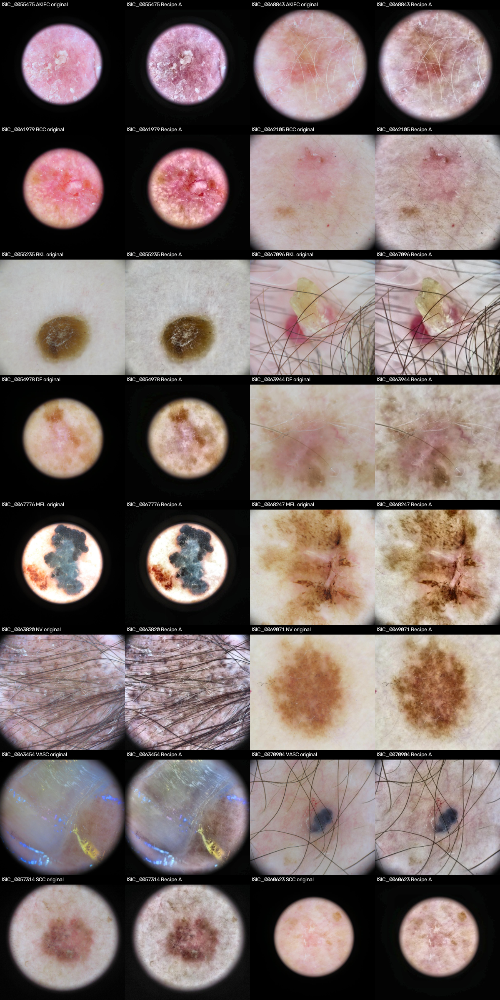


Sheet 2 (bcn_preprocessing_vs_holdout.png, 1200 x 2100 px, created): two HAM10000 holdout images, then two BCN20000 Recipe A images, for each class.


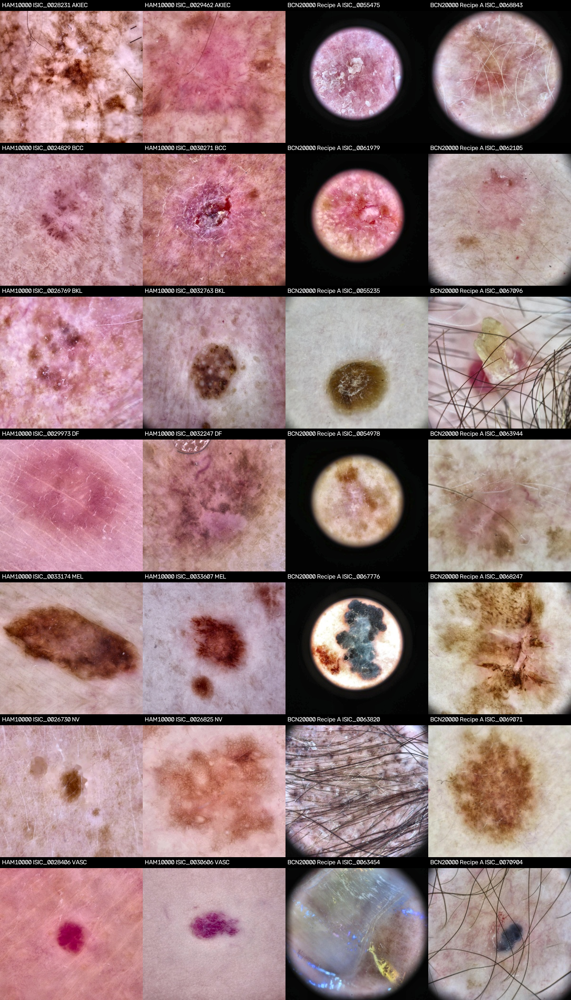


Look for: same orientation as the original, no black border or cut-off, colours not shifted, no heavy grain or blotches, the lesion visible.


In [36]:
"""
06_02_contact_sheet.txt
Phase 5 -- Module 06: BCN20000 image preprocessing -- Two contact sheets for a visual check (writes 2 PNG files; safe to re-run)

TITLE: Contact sheets

TITLE DESCRIPTION
  Numbers cannot tell whether an image looks right, so this cell draws two pictures for you to look at. Sheet 1 shows, for each
  of the 7 classes and for SCC, two BCN20000 images as they are (resized only) next to the same images after Recipe A, read back
  from the saved JPEG files. Sheet 2 puts two HAM10000 holdout images of each class (what the models were trained and tested
  on) next to two BCN20000 Recipe A images, so the difference in framing and appearance can be seen. The images are drawn at
  random with seed 42 (sheet 2: seed 43), so the same pictures appear every time. Nothing is scored.

CODE DESCRIPTION
  - Builds the two sheets (300 x 300 tiles, 4 columns, one row per class; the isic_id or image_id is printed on every tile),
    saves them as PNG files in bcn_preprocessed/ (atomic; read back and compared pixel for pixel) and shows them below.
  - What to look for: same orientation as the original, no black border or cut-off, colours not shifted, no heavy grain or
    blotches, the lesion visible. Tell Claude about anything that looks wrong; the numbers in 06_04 will not catch it.

Requires: 01_05, 06_00 and 06_01 already run in this kernel.
"""

import cv2
import numpy as np

PRE_TILE = 300
PRE_SHEET_COLUMNS = 4
PRE_BANNER_HEIGHT = 22


def make_tile(image_bgr, text):
    if image_bgr.shape != (PRE_TILE, PRE_TILE, 3) or image_bgr.dtype != np.uint8:
        raise ValueError(f"a tile must be {PRE_TILE} x {PRE_TILE} x 3 uint8, got {image_bgr.shape} {image_bgr.dtype}")
    tile = np.array(image_bgr, copy=True)
    cv2.rectangle(tile, (0, 0), (PRE_TILE - 1, PRE_BANNER_HEIGHT), (0, 0, 0), thickness=-1)
    cv2.putText(tile, text, (4, PRE_BANNER_HEIGHT - 7), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    return tile


def pick_bcn_samples():
    """Two images per class (and two SCC), drawn with seed 42 from the isic_id in sorted order."""
    rng = np.random.default_rng(RANDOM_SEED)
    samples = []
    for name in list(CLASSES) + ["scc"]:
        ids = sorted(PRE_SCORED.loc[PRE_SCORED["class_name"] == name, "isic_id"])
        chosen = sorted(rng.choice(len(ids), size=2, replace=False).tolist())
        samples.append((name, [ids[i] for i in chosen]))
    return samples


def pick_holdout_samples():
    """Two holdout images per class, drawn with seed 43 from the image_id in sorted order."""
    rng = np.random.default_rng(RANDOM_SEED + 1)
    samples = []
    for name in CLASSES:
        ids = sorted(HOLDOUT_TABLE.loc[HOLDOUT_TABLE["dx"] == name, "image_id"])
        chosen = sorted(rng.choice(len(ids), size=2, replace=False).tolist())
        samples.append((name, [ids[i] for i in chosen]))
    return samples


def bcn_original_tile(isic_id, file_names):
    original = decode_bgr((BCN_IMAGES_DIR / file_names[isic_id]).read_bytes())
    return cv2.resize(original, (PRE_TILE, PRE_TILE), interpolation=cv2.INTER_AREA)       # resized only: no CLAHE


def bcn_saved_tile(isic_id):
    return decode_bgr(output_image_path(isic_id).read_bytes())                              # the saved Recipe A file, read back from disk


def build_sheet_before_after(samples):
    file_names = dict(zip(PRE_SCORED["isic_id"], PRE_SCORED["file_name"]))
    rows = []
    for name, pair in samples:
        tiles = []
        for isic_id in pair:
            tiles.append(make_tile(bcn_original_tile(isic_id, file_names), f"{isic_id} {name.upper()} original"))
            tiles.append(make_tile(bcn_saved_tile(isic_id), f"{isic_id} Recipe A"))
        if len(tiles) != PRE_SHEET_COLUMNS:
            raise RuntimeError(f"{name}: {len(tiles)} tiles in a row, expected {PRE_SHEET_COLUMNS}")
        rows.append(np.hstack(tiles))
    return np.vstack(rows)


def build_sheet_vs_holdout(holdout_samples, bcn_samples):
    bcn_by_class = dict(bcn_samples)
    rows = []
    for name, pair in holdout_samples:
        tiles = []
        for image_id in pair:
            tiles.append(make_tile(decode_bgr((FINAL_IMAGES_DIR / f"{image_id}.jpg").read_bytes()), f"HAM10000 {image_id} {name.upper()}"))
        for isic_id in bcn_by_class[name]:
            tiles.append(make_tile(bcn_saved_tile(isic_id), f"BCN20000 Recipe A {isic_id}"))
        if len(tiles) != PRE_SHEET_COLUMNS:
            raise RuntimeError(f"{name}: {len(tiles)} tiles in a row, expected {PRE_SHEET_COLUMNS}")
        rows.append(np.hstack(tiles))
    return np.vstack(rows)


def write_png(path, sheet):
    """Atomic write; an existing file with the same bytes is left alone. The file is read back and compared pixel for pixel."""
    ok, encoded = cv2.imencode(".png", sheet)
    if not ok:
        raise RuntimeError(f"could not encode {path.name} as PNG")
    data = encoded.tobytes()
    if path.is_file() and path.read_bytes() == data:
        status = "unchanged"
    else:
        status = "replaced" if path.is_file() else "created"
        atomic_write_bytes(path, data)
    back = cv2.imdecode(np.frombuffer(path.read_bytes(), dtype=np.uint8), cv2.IMREAD_COLOR)
    if back is None or back.shape != sheet.shape or not np.array_equal(back, sheet):
        raise RuntimeError(f"{path.name} was written but reads back differently from what was drawn")
    return status, data


def show_png(data):
    try:
        from IPython.display import Image as IPyImage, display
        display(IPyImage(data=data, format="png", width=900))
    except Exception:  # noqa: BLE001 -- showing the picture is a convenience; the file is what counts
        print("  (the picture could not be shown here; open the PNG file)")


PRE_BCN_SAMPLES = pick_bcn_samples()
PRE_HOLDOUT_SAMPLES = pick_holdout_samples()
_sheet_one = build_sheet_before_after(PRE_BCN_SAMPLES)
_sheet_two = build_sheet_vs_holdout(PRE_HOLDOUT_SAMPLES, PRE_BCN_SAMPLES)

print("Contact sheets (images drawn with seed 42; sheet 2 holdout images with seed 43)")
for _name, _pair in PRE_BCN_SAMPLES:
    print(f"  {_name.upper():<6} BCN20000: {', '.join(_pair)}")
for _name, _pair in PRE_HOLDOUT_SAMPLES:
    print(f"  {_name.upper():<6} HAM10000 holdout: {', '.join(_pair)}")

_status_one, _png_one = write_png(PHASE5_BCN_IMAGES_DIR / PRE_OUT_FILES["contact_sheet"], _sheet_one)
print(f"\nSheet 1 ({PRE_OUT_FILES['contact_sheet']}, {_sheet_one.shape[1]} x {_sheet_one.shape[0]} px, {_status_one}): "
      f"left of each pair = the BCN20000 image resized only, right = after Recipe A (read back from the saved file).")
show_png(_png_one)
_status_two, _png_two = write_png(PHASE5_BCN_IMAGES_DIR / PRE_OUT_FILES["holdout_comparison"], _sheet_two)
print(f"\nSheet 2 ({PRE_OUT_FILES['holdout_comparison']}, {_sheet_two.shape[1]} x {_sheet_two.shape[0]} px, {_status_two}): "
      f"two HAM10000 holdout images, then two BCN20000 Recipe A images, for each class.")
show_png(_png_two)
print("\nLook for: same orientation as the original, no black border or cut-off, colours not shifted, no heavy grain or blotches, the lesion visible.")

In [37]:
"""
06_03_write_records_and_summary.txt
Phase 5 -- Module 06: BCN20000 image preprocessing -- Write the per-image records and the summary (writes 2 files; same content on every re-run except created_at; safe to re-run)

TITLE: Records and summary

TITLE DESCRIPTION
  Puts what the 17 chunk records say into two files that later modules can read. The records table has one row per image, in
  the inventory's order: class, size and SHA-256 of the source and of the saved JPEG, the contrast measure and the EXIF check.
  The summary holds the counts, the EXIF result, the contrast change per class next to Phase 1's figures for HAM10000 (context
  only), and one digest over all 16,843 saved images, which Module 07 and the exit gate use to prove the images never changed.

CODE DESCRIPTION
  - Re-reads every chunk record from disk (each is checked against the files on disk), builds the table, and computes the
    contrast change in the standard deviation of the L channel as 100 x (after - before) / before; "undefined" (an empty cell)
    when the image had no contrast before, never 0. The digest is the SHA-256 of the lines "isic_id <TAB> SHA-256 of the JPEG".
  - Writes bcn_preprocessing_records.csv and bcn_preprocessing_summary.json atomically into bcn_preprocessed/, then prints the
    counts, the EXIF result and the contrast table. The checks that prove these files are right are in 06_04.

Requires: 06_00 and 06_01 already run in this kernel (06_02 is not needed).
"""

import hashlib

import numpy as np
import pandas as pd

PRE_PHASE1_GAIN_REFERENCE = {
    "mean_pct": 18.61, "median_pct": 15.97, "share_at_least_40_pct": 9.92, "n_images": 10015,
    "note": ("Phase 1 progress log, clip limit 1.5. Measured on the 600 x 450 HAM10000 images after hair removal, so it is context only "
             "and not a like-for-like comparison with BCN20000 (1024 x 1024, no hair removal). Taken from the log, not recomputed."),
}
PRE_RECORDS_COLUMNS = ["isic_id", "group", "class_name", "label", "source_bytes", "source_sha256", "out_bytes", "out_sha256",
                       "l_std_before", "l_std_after", "l_gain_pct", "exif_orientation", "orientation_changed"]
PRE_GAIN_DEFINITION = ("100 x (L std after - L std before) / L std before, on the L channel of the 8-bit LAB image, "
                       "measured on the 1024 x 1024 image before the resize; empty when L std before is 0")


def images_digest(ids, shas):
    digest = hashlib.sha256()
    for isic_id, sha in zip(ids, shas):
        digest.update(f"{isic_id}\t{sha}\n".encode("ascii"))
    return digest.hexdigest()


def build_records_table():
    chunk_table = load_chunk_records(PRE_SCORED)                       # read from disk, each chunk checked against the files on disk
    base = PRE_SCORED[["isic_id", "group", "class_name", "label"]].reset_index(drop=True)
    if base["isic_id"].tolist() != chunk_table["isic_id"].tolist():
        raise RuntimeError("the chunk records are not in the inventory's order")
    records = pd.concat([base, chunk_table.drop(columns=["isic_id"])], axis=1)
    before = records["l_std_before"].to_numpy(dtype=np.float64)
    after = records["l_std_after"].to_numpy(dtype=np.float64)
    gain = np.full(len(records), np.nan)
    has_contrast = before > 0
    gain[has_contrast] = 100.0 * (after[has_contrast] - before[has_contrast]) / before[has_contrast]
    records["l_gain_pct"] = gain
    records["exif_orientation"] = records["exif_orientation"].astype("Int64")        # whole numbers; an empty cell when Pillow was not available
    return records[PRE_RECORDS_COLUMNS]


def gain_statistics(values):
    v = np.asarray(values, dtype=np.float64)
    v = v[~np.isnan(v)]
    if len(v) == 0:
        return {"n": 0, "mean": None, "median": None, "p05": None, "p95": None, "share_at_least_40_pct": None}
    return {"n": int(len(v)), "mean": float(v.mean()), "median": float(np.median(v)), "p05": float(np.percentile(v, 5)),
            "p95": float(np.percentile(v, 95)), "share_at_least_40_pct": float((v >= 40.0).mean() * 100.0)}


def build_preprocessing_summary(records):
    classes = list(CLASSES) + ["scc"]
    tags = records["exif_orientation"]
    tag_counts = {"not read": int(tags.isna().sum())}
    tag_counts.update({str(int(value)): int(count) for value, count in tags.dropna().value_counts().sort_index().items()})
    rotated_tag = tags.isin([2, 3, 4, 5, 6, 7, 8])
    changed = records["orientation_changed"].astype(bool)
    return {
        "module": "Phase 5, Module 06 -- BCN20000 image preprocessing (Recipe A)",
        "created_at": now_iso(),
        "recipe": recipe_settings(),
        "inventory_sha256": PRE_INVENTORY_SHA256,
        "n_images": int(len(records)),
        "n_primary": int((records["group"] == "primary").sum()),
        "n_scc": int((records["group"] == "scc").sum()),
        "per_class": {name: int((records["class_name"] == name).sum()) for name in classes},
        "chunks": {"size": PRE_CHUNK_SIZE, "count": len(chunk_slices(len(records)))},
        "source_bytes_total": int(records["source_bytes"].sum()),
        "output_bytes": {"total": int(records["out_bytes"].sum()), "min": int(records["out_bytes"].min()),
                         "max": int(records["out_bytes"].max()), "mean": float(records["out_bytes"].mean())},
        "exif": {"tag_counts": tag_counts, "images_with_rotation_tag": int(rotated_tag.sum()),
                 "images_whose_pixels_change_with_exif_rotation": int(changed.sum()),
                 "rotation_tag_but_pixels_unchanged": int((rotated_tag & ~changed).sum()),
                 "no_rotation_tag_but_pixels_changed": int((~rotated_tag & changed).sum())},
        "contrast_gain": {"definition": PRE_GAIN_DEFINITION, "all": gain_statistics(records["l_gain_pct"]),
                          "per_class": {name: gain_statistics(records.loc[records["class_name"] == name, "l_gain_pct"]) for name in classes},
                          "n_undefined": int(records["l_gain_pct"].isna().sum()), "phase1_reference_ham10000": PRE_PHASE1_GAIN_REFERENCE},
        "images_digest": images_digest(records["isic_id"], records["out_sha256"]),
        "images_digest_rule": "SHA-256 over the lines '<isic_id><TAB><SHA-256 of the saved JPEG><newline>' in the inventory's order",
    }


PRE_RECORDS_TABLE = build_records_table()
PRE_SUMMARY = build_preprocessing_summary(PRE_RECORDS_TABLE)
atomic_write_bytes(PHASE5_BCN_IMAGES_DIR / PRE_OUT_FILES["records"], PRE_RECORDS_TABLE.to_csv(index=False).encode("utf-8"))
atomic_write_json(PHASE5_BCN_IMAGES_DIR / PRE_OUT_FILES["summary"], PRE_SUMMARY)

print(f"Written to {PHASE5_BCN_IMAGES_DIR}:")
for _key in ("records", "summary"):
    _path = PHASE5_BCN_IMAGES_DIR / PRE_OUT_FILES[_key]
    print(f"  {_path.name:<36}{_path.stat().st_size:>12,} bytes   SHA-256 {sha256_of_file(_path)[:16]}...")
print(f"\nImages: {PRE_SUMMARY['n_images']:,} = primary {PRE_SUMMARY['n_primary']:,} + SCC {PRE_SUMMARY['n_scc']:,}   (per class: "
      + ", ".join(f"{name.upper()} {count:,}" for name, count in PRE_SUMMARY['per_class'].items()) + ")")
print(f"Saved JPEG files: {PRE_SUMMARY['output_bytes']['total'] / 1e6:,.0f} MB (source files: {PRE_SUMMARY['source_bytes_total'] / 1e6:,.0f} MB)")
print(f"Images digest (SHA-256 of all {PRE_SUMMARY['n_images']:,} saved images, in order): {PRE_SUMMARY['images_digest']}")
print(f"\nEXIF orientation: tag counts {PRE_SUMMARY['exif']['tag_counts']}; images with a rotation tag (2 to 8): {PRE_SUMMARY['exif']['images_with_rotation_tag']:,}; "
      f"images whose pixels change with the EXIF rotation: {PRE_SUMMARY['exif']['images_whose_pixels_change_with_exif_rotation']:,}.")
print("\nContrast change from CLAHE (standard deviation of the L channel, before the resize), percent:")
print(f"  {'':<10}{'N':>8}{'mean':>9}{'median':>9}{'5th pct':>9}{'95th pct':>10}{'>= 40 %':>10}")
_rows = [("all", PRE_SUMMARY["contrast_gain"]["all"])] + [(name.upper(), stats) for name, stats in PRE_SUMMARY["contrast_gain"]["per_class"].items()]
for _name, _stats in _rows:
    if _stats["n"] == 0:
        print(f"  {_name:<10}{0:>8,}   undefined")
        continue
    print(f"  {_name:<10}{_stats['n']:>8,}{_stats['mean']:>9.2f}{_stats['median']:>9.2f}{_stats['p05']:>9.2f}{_stats['p95']:>10.2f}{_stats['share_at_least_40_pct']:>9.2f}%")
_ref = PRE_PHASE1_GAIN_REFERENCE
print(f"  HAM10000 in Phase 1 (context only, see the note in the summary file): mean {_ref['mean_pct']}, median {_ref['median_pct']}, {_ref['share_at_least_40_pct']} % of images at or above 40 %.")
print(f"  images with an undefined change: {PRE_SUMMARY['contrast_gain']['n_undefined']}")
print("\nNext: 06_04 checks both files and every image by a second route, and writes the manifest only if everything passes.")

Written to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_preprocessed:
  bcn_preprocessing_records.csv          3,922,999 bytes   SHA-256 44402412ec1af980...
  bcn_preprocessing_summary.json             4,142 bytes   SHA-256 3dee11653f910113...

Images: 16,843 = primary 16,284 + SCC 559   (per class: AKIEC 1,088, BCC 3,676, BKL 1,551, DF 168, MEL 4,003, NV 5,647, VASC 151, SCC 559)
Saved JPEG files: 506 MB (source files: 1,089 MB)
Images digest (SHA-256 of all 16,843 saved images, in order): 98dd02aa0d3e4f382e557db9ef16f52a8adf68be3e22c4ddc4f89e64fc9221e6

EXIF orientation: tag counts {'not read': 0, '0': 16843}; images with a rotation tag (2 to 8): 0; images whose pixels change with the EXIF rotation: 0.

Contrast change from CLAHE (standard deviation of the L channel, before the resize), percent:
                   N     mean   median  5th pct  95th pct   >= 40 %
  all         16,843    10.79     5.59    -3.64     42.72     5.95%
  AKIEC        1,088    15.13     4.42 

In [38]:
"""
06_04_check_preprocessing.txt
Phase 5 -- Module 06: BCN20000 image preprocessing -- Check every image and file from disk by a second route and write the manifest (verification; safe to re-run)

TITLE: Check the preprocessed images

TITLE DESCRIPTION
  Closes Module 06. Everything is read back from disk and checked by routes that share no code with 06_00 and 06_01: the
  inventory is read again with Python's csv module; the recipe settings come from the rules note on disk; every saved JPEG is
  re-hashed and decoded; and about 220 images (12 from every chunk and 3 from every class, SCC included) are recomputed from the
  source file with cv2.imread, the recipe steps written out again, and cv2.imwrite, then compared pixel for pixel with the saved
  file. Only if every check passes is the manifest written.

CODE DESCRIPTION
  - Runs the checks in 6 groups (inputs, rules note and folder contents; the saved images; the records against the inventory and
    the chunk records; the recipe recomputed from the sources; the summary and the order of the metadata table; the two pictures).
    All failures are collected and ONE error is raised at the end; in that case no manifest is written.
  - On success writes bcn_preprocessed/bcn_preprocessing_manifest.json: size and SHA-256 of every file except the images, the
    digest over all 16,843 saved images, the recipe, the counts and the hashes of the inputs. Module 07 and the exit gate re-check it.

Requires: 06_00 to 06_03 already run in this kernel (after a restart: re-run 01_01 to 01_05, 02_00 to 02_02, 06_00, 06_01 (it only re-checks
finished chunks) and 06_03; 06_02 is not needed). Takes about 1 to 3 minutes.
"""

import csv
import hashlib
import json
import math
import os
import re
import struct
import tempfile

import cv2
import numpy as np

PRE_MANIFEST_PATH = PHASE5_BCN_IMAGES_DIR / PRE_MANIFEST_NAME
PRE_METADATA_MANIFEST_PATH = PHASE5_BCN_METADATA_DIR / "bcn_metadata_manifest.json"
PRE_METADATA_TABLE_PATH = PHASE5_BCN_METADATA_DIR / "bcn_metadata_encoded.csv"
PRE_CHECK_PER_CHUNK = 12
PRE_CHECK_PER_CLASS = 3
PRE_RECORDS_COLUMNS_EXPECTED = ["isic_id", "group", "class_name", "label", "source_bytes", "source_sha256", "out_bytes", "out_sha256",
                                "l_std_before", "l_std_after", "l_gain_pct", "exif_orientation", "orientation_changed"]
PRE_PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"


def pre_read_csv_rows(path):
    with open(path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        return list(reader), list(reader.fieldnames)


def pre_close(a, b):
    return math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)


def pre_first_difference(found, wanted):
    if len(found) != len(wanted):
        return f"lengths {len(found)} vs {len(wanted)}"
    for position, (a, b) in enumerate(zip(found, wanted)):
        if a != b:
            return f"first difference at position {position}: {a!r} vs {b!r}"
    return ""


def recipe_from_note(note):
    """The recipe settings as WORDS in the rules note on disk, turned back into numbers (a different route from the constants in memory)."""
    steps = note["rules"]["image_recipe"]["steps"]
    m_clahe = re.fullmatch(r"CLAHE on the L channel in LAB, clip_limit=([0-9.]+), tile grid \[([0-9]+), ([0-9]+)\]", steps[1])
    m_size = re.fullmatch(r"resize to ([0-9]+)x([0-9]+) with (INTER_[A-Z]+)", steps[2])
    m_jpeg = re.fullmatch(r"save JPEG quality ([0-9]+), the same compression path as Phase 1", steps[3])
    if not (m_clahe and m_size and m_jpeg):
        raise RuntimeError(f"the recipe steps in the rules note could not be read back: {steps[1:]}")
    return {"clip": float(m_clahe.group(1)), "tile": (int(m_clahe.group(2)), int(m_clahe.group(3))),
            "width": int(m_size.group(1)), "height": int(m_size.group(2)), "interpolation": m_size.group(3), "quality": int(m_jpeg.group(1))}


def recompute_from_source(source_path, recipe, scratch_dir):
    """Recipe A written out again step by step, reading with cv2.imread and saving with cv2.imwrite (the route Phase 1 used).
    Returns the decoded pixels and the bytes of the file it saved."""
    source = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if source is None:
        raise RuntimeError(f"cv2.imread could not read {source_path.name}")
    lab = cv2.cvtColor(source, cv2.COLOR_BGR2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    lightness = cv2.createCLAHE(clipLimit=recipe["clip"], tileGridSize=recipe["tile"]).apply(lightness)
    enhanced = cv2.cvtColor(cv2.merge([lightness, channel_a, channel_b]), cv2.COLOR_LAB2BGR)
    small = cv2.resize(enhanced, (recipe["width"], recipe["height"]), interpolation=getattr(cv2, recipe["interpolation"]))
    scratch_path = os.path.join(scratch_dir, "recomputed.jpg")
    cv2.imwrite(scratch_path, small, [cv2.IMWRITE_JPEG_QUALITY, recipe["quality"]])
    with open(scratch_path, "rb") as f:
        saved_bytes = f.read()
    return cv2.imread(scratch_path, cv2.IMREAD_COLOR), saved_bytes


def check_preprocessing():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    folder = PHASE5_BCN_IMAGES_DIR
    records_dir = folder / "_chunk_records"

    # ---- 1. inputs, rules note, folder contents -----------------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    rules = check_rules_note(verbose=False)
    check(g, "the rules note still equals the rules rebuilt from the constants", rules["passed"], f"failed: {rules['failed']}")
    with open(RULES_NOTE_PATH, "r", encoding="utf-8") as f:
        note = json.load(f)
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file (the saved images included) is newer than the rules note", order["passed"],
          f"{len(order['older_than_note'])} older than the note, e.g. {order['older_than_note'][:3]}")
    with open(PRE_INVENTORY_MANIFEST_PATH, "r", encoding="utf-8") as f:
        inventory_manifest = json.load(f)
    inventory_sha_now = sha256_of_file(PRE_INVENTORY_PATH)
    check(g, "bcn_inventory.csv still has the hash in Module 04's manifest and the hash 06_01 loaded",
          inventory_manifest["files"]["bcn_inventory.csv"]["sha256"] == inventory_sha_now == PRE_INVENTORY_SHA256)
    check(g, "Module 04's manifest says every check passed", inventory_manifest.get("all_passed") is True)
    metadata_manifest = {}
    if PRE_METADATA_MANIFEST_PATH.is_file():
        with open(PRE_METADATA_MANIFEST_PATH, "r", encoding="utf-8") as f:
            metadata_manifest = json.load(f)
    check(g, "Module 05's manifest exists and says every check passed", metadata_manifest.get("all_passed") is True)

    recipe = recipe_from_note(note)
    inventory_rows, _ = pre_read_csv_rows(PRE_INVENTORY_PATH)
    scored = [r for r in inventory_rows if r["group"] in ("primary", "scc")]
    n = len(scored)
    ids = [r["isic_id"] for r in scored]
    check(g, "the inventory (csv module) has the scored rows: 16,284 primary + 559 SCC",
          n == EXPECTED_BCN_SCORED_IMAGES and sum(1 for r in scored if r["group"] == "primary") == EXPECTED_BCN_PRIMARY_TOTAL, f"{n:,} rows")

    top_files, top_dirs = set(), set()
    with os.scandir(folder) as entries:
        for entry in entries:
            (top_dirs if entry.is_dir() else top_files).add(entry.name)
    jpgs = {name for name in top_files if name.endswith(".jpg")}
    expected_jpgs = {isic_id + ".jpg" for isic_id in ids}
    promised = set(PRE_OUT_FILES.values())
    others = top_files - jpgs
    check(g, f"the folder holds exactly the {n:,} expected JPEG files, named by isic_id", jpgs == expected_jpgs,
          f"missing {len(expected_jpgs - jpgs)}, unexpected {len(jpgs - expected_jpgs)}")
    check(g, f"all {len(promised)} promised files exist", promised <= others, f"missing: {sorted(promised - others)}")
    check(g, "no other file or folder sits in bcn_preprocessed (no leftover .tmp)", others <= promised | {PRE_MANIFEST_NAME} and top_dirs <= {PRE_RECORDS_DIR.name},
          f"unexpected: {sorted((others - promised - {PRE_MANIFEST_NAME}) | (top_dirs - {PRE_RECORDS_DIR.name}))[:5]}")
    n_chunks = math.ceil(n / PRE_CHUNK_SIZE)
    wanted_chunk_files = [f"chunk_{k:03d}.json" for k in range(n_chunks)]
    found_chunk_files = sorted(os.listdir(records_dir)) if records_dir.is_dir() else []
    check(g, f"the chunk-record folder holds exactly the {n_chunks} chunk records", found_chunk_files == wanted_chunk_files, f"found {len(found_chunk_files)}")
    if jpgs != expected_jpgs or not promised <= others or found_chunk_files != wanted_chunk_files:
        return checks, None                                                  # the later groups need these files
    check(g, "no promised file and no chunk record is empty",
          all((folder / name).stat().st_size > 0 for name in promised) and all((records_dir / name).stat().st_size > 0 for name in wanted_chunk_files))

    records, record_columns = pre_read_csv_rows(folder / PRE_OUT_FILES["records"])
    with open(folder / PRE_OUT_FILES["summary"], "r", encoding="utf-8") as f:
        summary = json.load(f)
    chunk_items, chunk_recipes, chunk_ok = {}, set(), True
    for k, name in enumerate(wanted_chunk_files):
        with open(records_dir / name, "r", encoding="utf-8") as f:
            chunk = json.load(f)
        chunk_ok = chunk_ok and chunk.get("chunk_index") == k and chunk.get("n_items") == len(chunk["items"]) and chunk.get("format_version") == 1
        chunk_recipes.add(json.dumps(chunk.get("recipe"), sort_keys=True))
        for item in chunk["items"]:
            chunk_items[item["isic_id"]] = item
    check(g, "every chunk record has the right chunk number and item count, and together they hold each image once",
          chunk_ok and len(chunk_items) == n and set(chunk_items) == set(ids))
    check(g, "all chunk records were made with one and the same recipe settings, equal to the settings in the summary and the rules note",
          len(chunk_recipes) == 1 and json.loads(next(iter(chunk_recipes))) == summary["recipe"]
          and summary["recipe"]["clahe_clip"] == recipe["clip"] and summary["recipe"]["clahe_tile"] == list(recipe["tile"])
          and summary["recipe"]["output_size"] == recipe["width"] == recipe["height"] and summary["recipe"]["jpeg_quality"] == recipe["quality"]
          and summary["recipe"]["interpolation"] == recipe["interpolation"])

    # ---- 2. every saved image: bytes, hash, decode ---------------------------------------------------------------------
    g = "the saved images"
    check(g, "the records table has the expected columns and one row per scored image, in the inventory's order",
          record_columns == PRE_RECORDS_COLUMNS_EXPECTED and [r["isic_id"] for r in records] == ids,
          pre_first_difference([r["isic_id"] for r in records], ids))
    if record_columns != PRE_RECORDS_COLUMNS_EXPECTED or [r["isic_id"] for r in records] != ids:
        return checks, None                                                  # the loops below assume one record per image, in order
    bad_decode, flat, bad_hash, bad_size = [], [], [], []
    digest = hashlib.sha256()
    total_bytes = 0
    for r in records:
        isic_id = r["isic_id"]
        data = (folder / (isic_id + ".jpg")).read_bytes()
        sha = hashlib.sha256(data).hexdigest()
        total_bytes += len(data)
        item = chunk_items[isic_id]
        if not (sha == r["out_sha256"] == item["out_sha256"]):
            bad_hash.append(isic_id)
        if not (len(data) == int(r["out_bytes"]) == item["out_bytes"]):
            bad_size.append(isic_id)
        pixels = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
        if pixels is None or pixels.dtype != np.uint8 or pixels.shape != (recipe["height"], recipe["width"], 3):
            bad_decode.append(isic_id)
        elif int(pixels.min()) == int(pixels.max()):
            flat.append(isic_id)
        digest.update(f"{isic_id}\t{sha}\n".encode("ascii"))
    images_digest = digest.hexdigest()
    check(g, f"every saved file decodes to {recipe['width']} x {recipe['height']} x 3, uint8", not bad_decode, f"{len(bad_decode)} do not, e.g. {bad_decode[:5]}")
    check(g, "no saved image is a single flat colour", not flat, f"{len(flat)} are, e.g. {flat[:5]}")
    check(g, "the SHA-256 of every saved file (re-hashed now) equals the records table and the chunk record", not bad_hash, f"{len(bad_hash)} differ, e.g. {bad_hash[:5]}")
    check(g, "the size of every saved file equals the records table and the chunk record", not bad_size, f"{len(bad_size)} differ, e.g. {bad_size[:5]}")
    check(g, "the digest over all saved images, recomputed now, equals the one in the summary", images_digest == summary["images_digest"],
          f"{images_digest[:16]}... vs {str(summary['images_digest'])[:16]}...")

    # ---- 3. records against the inventory and the chunk records --------------------------------------------------------
    g = "the records against the inventory and the chunk records"
    wrong_inventory, wrong_chunk, wrong_gain = [], [], []
    tag_counts, rotation_tag, changed_pixels = {"not read": 0}, 0, 0
    gains = []
    for r, source in zip(records, scored):
        item = chunk_items[r["isic_id"]]
        if not (r["group"] == source["group"] and r["class_name"] == source["class_name"] and r["label"] == source["label"]
                and r["source_bytes"] == source["file_bytes"] and r["source_sha256"] == source["file_sha256"]):
            wrong_inventory.append(r["isic_id"])
        tag = None if r["exif_orientation"] == "" else int(r["exif_orientation"])
        if not (int(r["source_bytes"]) == item["source_bytes"] and r["source_sha256"] == item["source_sha256"]
                and pre_close(float(r["l_std_before"]), item["l_std_before"]) and pre_close(float(r["l_std_after"]), item["l_std_after"])
                and tag == item["exif_orientation"] and r["orientation_changed"] == str(item["orientation_changed"])):
            wrong_chunk.append(r["isic_id"])
        before, after = float(r["l_std_before"]), float(r["l_std_after"])
        if before > 0:
            expected_gain = 100.0 * (after - before) / before
            if r["l_gain_pct"] == "" or not pre_close(float(r["l_gain_pct"]), expected_gain):
                wrong_gain.append(r["isic_id"])
            else:
                gains.append(float(r["l_gain_pct"]))
        elif r["l_gain_pct"] != "":
            wrong_gain.append(r["isic_id"])
        key = "not read" if tag is None else str(tag)
        tag_counts[key] = tag_counts.get(key, 0) + 1
        rotation_tag += 1 if tag is not None and 2 <= tag <= 8 else 0
        changed_pixels += 1 if r["orientation_changed"] == "True" else 0
    check(g, "group, class, label, source size and source SHA-256 of every record equal the inventory (read with the csv module)",
          not wrong_inventory, f"{len(wrong_inventory)} differ, e.g. {wrong_inventory[:5]}")
    check(g, "every record equals its chunk record (sizes, hashes, contrast measures, EXIF values)", not wrong_chunk, f"{len(wrong_chunk)} differ, e.g. {wrong_chunk[:5]}")
    check(g, "the contrast change of every record is recomputed correctly from its two standard deviations (empty when there was no contrast)",
          not wrong_gain, f"{len(wrong_gain)} differ, e.g. {wrong_gain[:5]}")
    per_class = {}
    for r in records:
        per_class[r["class_name"]] = per_class.get(r["class_name"], 0) + 1
    wanted_per_class = dict(EXPECTED_BCN_PRIMARY_COUNTS)
    wanted_per_class["scc"] = EXPECTED_BCN_SCC
    check(g, "images per class equal the expected counts (7 primary classes + SCC)", per_class == wanted_per_class, f"{per_class}")

    # ---- 4. the recipe recomputed from the source files ----------------------------------------------------------------
    g = "the recipe recomputed from the source files"
    rng = np.random.default_rng(RANDOM_SEED)
    chosen = set()
    for start in range(0, n, PRE_CHUNK_SIZE):
        size = min(PRE_CHUNK_SIZE, n - start)
        chosen.update((start + rng.choice(size, size=min(PRE_CHECK_PER_CHUNK, size), replace=False)).tolist())
    for name in list(CLASSES) + ["scc"]:
        positions = [i for i, r in enumerate(records) if r["class_name"] == name]
        chosen.update(rng.choice(positions, size=min(PRE_CHECK_PER_CLASS, len(positions)), replace=False).tolist())
    sample = sorted(chosen)
    pixel_differences, byte_identical = [], 0
    with tempfile.TemporaryDirectory() as scratch_dir:
        for position in sample:
            r = records[position]
            again, again_bytes = recompute_from_source(BCN_IMAGES_DIR / scored[position]["file_name"], recipe, scratch_dir)
            saved_pixels = cv2.imread(str(folder / (r["isic_id"] + ".jpg")), cv2.IMREAD_COLOR)
            if again is None or saved_pixels is None or again.shape != saved_pixels.shape or not np.array_equal(again, saved_pixels):
                pixel_differences.append(r["isic_id"])
            if again_bytes == (folder / (r["isic_id"] + ".jpg")).read_bytes():
                byte_identical += 1
    check(g, f"{len(sample)} images recomputed (cv2.imread, steps written out again, cv2.imwrite) have the same pixels as the saved files",
          not pixel_differences, f"{len(pixel_differences)} differ, e.g. {pixel_differences[:5]}; byte-identical files: {byte_identical} of {len(sample)}")
    covered_chunks = {position // PRE_CHUNK_SIZE for position in sample}
    covered_classes = {records[position]["class_name"] for position in sample}
    check(g, "the sample covers every chunk and every class, SCC included", covered_chunks == set(range(n_chunks)) and covered_classes == set(wanted_per_class),
          f"{len(covered_chunks)} of {n_chunks} chunks, {len(covered_classes)} of {len(wanted_per_class)} groups")

    # ---- 5. summary and order of the metadata table ---------------------------------------------------------------------
    g = "the summary and the order of the metadata table"
    check(g, "the summary's counts equal the records (images, primary, SCC, per class)",
          summary["n_images"] == n and summary["n_primary"] == EXPECTED_BCN_PRIMARY_TOTAL and summary["n_scc"] == EXPECTED_BCN_SCC
          and summary["per_class"] == {name: wanted_per_class[name] for name in list(CLASSES) + ["scc"]})
    check(g, "the summary's EXIF figures equal the records",
          summary["exif"]["tag_counts"] == tag_counts and summary["exif"]["images_with_rotation_tag"] == rotation_tag
          and summary["exif"]["images_whose_pixels_change_with_exif_rotation"] == changed_pixels, f"tags {tag_counts}")
    check(g, "the summary's mean contrast change equals the mean recomputed from the records",
          len(gains) > 0 and pre_close(summary["contrast_gain"]["all"]["mean"], float(np.mean(gains))) and summary["contrast_gain"]["all"]["n"] == len(gains))
    check(g, "the summary's total size of the saved images equals the files on disk", summary["output_bytes"]["total"] == total_bytes, f"{total_bytes:,} bytes")
    check(g, "the summary was made from the inventory that is on disk now", summary["inventory_sha256"] == inventory_sha_now)
    metadata_rows, _ = pre_read_csv_rows(PRE_METADATA_TABLE_PATH)
    metadata_ids = [r["isic_id"] for r in metadata_rows]
    check(g, "the images are in exactly the order of bcn_metadata_encoded.csv (Module 07 pairs image i with metadata row i)", metadata_ids == ids,
          pre_first_difference(metadata_ids, ids))

    # ---- 6. the two pictures ---------------------------------------------------------------------------------------------
    g = "the two pictures"
    for key, tile_rows in (("contact_sheet", 8), ("holdout_comparison", 7)):
        data = (folder / PRE_OUT_FILES[key]).read_bytes()
        width, height = struct.unpack(">II", data[16:24]) if len(data) >= 24 else (0, 0)
        decoded = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
        check(g, f"{PRE_OUT_FILES[key]} is a PNG of {4 * 300} x {tile_rows * 300} pixels ({tile_rows} rows of 4 tiles)",
              data[:8] == PRE_PNG_SIGNATURE and (width, height) == (4 * 300, tile_rows * 300) and decoded is not None and decoded.shape == (tile_rows * 300, 4 * 300, 3),
              f"{width} x {height}")
    return checks, {"note": note, "rules": rules, "summary": summary, "recipe": recipe, "inventory_sha": inventory_sha_now, "images_digest": images_digest,
                    "total_bytes": total_bytes, "n": n, "n_chunks": n_chunks, "sample_size": len(sample), "byte_identical": byte_identical,
                    "metadata_manifest_sha": sha256_of_file(PRE_METADATA_MANIFEST_PATH) if PRE_METADATA_MANIFEST_PATH.is_file() else None,
                    "per_class": per_class}


PRE_CHECKS, _context = check_preprocessing()

_summary_lines = {}
for _group, _name, _ok, _detail in PRE_CHECKS:
    _entry = _summary_lines.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 06 check (every image and file read back from disk; recipe recomputed from the sources by a second route)")
for _group, (_count, _bad) in _summary_lines.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<62}{_count:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))
_failed = [(g, nm, d) for g, nm, ok, d in PRE_CHECKS if not ok]
if _failed or _context is None:
    _lines = [f"[{g}] {nm}" + (f"  --  {d}" if d else "") for g, nm, d in _failed[:40]]
    raise RuntimeError(f"MODULE 06 CHECK FAILED ({len(_failed)} of {len(PRE_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines)
                       + (f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""))

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_non_image_files = sorted(p for p in PHASE5_BCN_IMAGES_DIR.rglob("*") if p.is_file() and p.suffix != ".jpg" and p.name != PRE_MANIFEST_NAME)
_manifest = {
    "module": "Phase 5, Module 06 -- BCN20000 image preprocessing (Recipe A)", "created_at": now_iso(), "n_checks": len(PRE_CHECKS), "all_passed": True,
    "inputs": {"inventory_csv": {"path": str(PRE_INVENTORY_PATH), "sha256": _context["inventory_sha"]},
               "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _context["rules"]["sha256"], "written_at": _context["rules"]["written_at"]},
               "bcn_metadata_manifest": {"path": str(PRE_METADATA_MANIFEST_PATH), "sha256": _context["metadata_manifest_sha"]}},
    "recipe": _context["summary"]["recipe"],
    "counts": {"images": _context["n"], "primary": _context["summary"]["n_primary"], "scc": _context["summary"]["n_scc"], "per_class": _context["per_class"],
               "chunks": _context["n_chunks"], "chunk_size": PRE_CHUNK_SIZE},
    "images": {"folder": str(PHASE5_BCN_IMAGES_DIR), "n_files": _context["n"], "total_bytes": _context["total_bytes"],
               "digest_sha256": _context["images_digest"], "digest_rule": _context["summary"]["images_digest_rule"]},
    "recompute_sample": {"n": _context["sample_size"], "pixels_identical": _context["sample_size"], "bytes_identical": _context["byte_identical"]},
    "files": {p.relative_to(PHASE5_BCN_IMAGES_DIR).as_posix(): {"bytes": p.stat().st_size, "sha256": sha256_of_file(p)} for p in _non_image_files},
}
atomic_write_json(PRE_MANIFEST_PATH, _manifest)

print(f"\nMODULE 06 CHECK PASSED ({len(PRE_CHECKS)} checks in {len(_summary_lines)} groups). Manifest written: {PRE_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_context['rules']['sha256'][:16]}... (written {_context['rules']['written_at']}); every result file is newer than it.")
print(f"\nBCN20000 preprocessed: {_context['n']:,} images ({_context['total_bytes'] / 1e6:,.0f} MB) = primary {_manifest['counts']['primary']:,} + SCC {_manifest['counts']['scc']}.")
print(f"Recomputed from the sources by a second route: {_context['sample_size']} images, all with identical pixels ({_context['byte_identical']} also with identical file bytes).")
print(f"Images digest: {_manifest['images']['digest_sha256']}")
print("\nFiles listed in the manifest (bytes, SHA-256 first 16); the images themselves are covered by the digest and the records table:")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<44}{_info['bytes']:>12,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 06 check (every image and file read back from disk; recipe recomputed from the sources by a second route)
  [PASS] inputs, rules note and folder contents                          14 checks
  [PASS] the saved images                                                 6 checks
  [PASS] the records against the inventory and the chunk records          4 checks
  [PASS] the recipe recomputed from the source files                      2 checks
  [PASS] the summary and the order of the metadata table                  6 checks
  [PASS] the two pictures                                                 2 checks

MODULE 06 CHECK PASSED (34 checks in 6 groups). Manifest written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_preprocessed\bcn_preprocessing_manifest.json
Rules note SHA-256 72bb8c1a55587874... (written 2026-10-08T13:39:44+06:00); every result file is newer than it.

BCN20000 prepro

# Module 7

In [46]:
"""
07_00_inference_functions.txt
Phase 5 -- Module 07: Inference -- The image loader, the scoring loop, the embedding tap and their known-answer tests (writes no result file; safe to re-run)

TITLE: Inference functions

TITLE DESCRIPTION
  Everything Module 07 needs to push images through the two frozen models, written once and tested before it is used on anything
  real. The loader reads a saved 300 x 300 JPEG and turns it into exactly the tensor that Phase 3 and Phase 4 gave the models. The
  scoring loop runs a list of model passes over a set of images in fixed batches, in strict fp32, and hands back the raw logits.
  A small read-only "tap" copies the pooled 1,536-number backbone output (taken before the MetaBlock) for the dataset-shift
  analysis (A2) without changing anything the model computes. No BCN20000 image and no model is touched in this cell.

CODE DESCRIPTION
  - Defines the constants of Module 07 (batch size 1 = one image at a time, as Phase 4 scored the holdout; chunks of 1,000, file names, tolerances), the loader (file bytes ->
    cv2.imdecode -> Phase 3's normalize_image -> channels first), the dataset that pairs every image with its metadata vector,
    the scoring loop (eval mode, no autocast, TF32 off, logits copied to the CPU) and the tap (a forward hook that only reads).
  - Runs 15 known-answer tests: the chunk plan, softmax, the wiring sample, the loader (against Phase 4's cv2.imread path,
    and its three error cases), the dataset's input checks, the whole scoring loop on a tiny stand-in network whose answers are
    worked out by hand, the tap with its error cases, and the guard that stops a run when files of the earlier batch-32 run are
    still in the folder. The test files are made in a temporary folder that is deleted afterwards.

Requires: 01_01 to 01_05 and 02_00 to 02_02 already run in this kernel.
After a restart or power cut, re-run 01_01 to 01_05, 02_00, 02_01, 02_02, then 07_00 (all are safe to re-run).
"""

import io
import json
import os
import tempfile
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as torch_functional
from torch.utils.data import DataLoader, Dataset

# Module 05 wrote into bcn_metadata/. A restart forgets that it is a result folder, so it is added again (the same line as in 05_00 and 06_01).
PHASE5_BCN_METADATA_DIR = PHASE5_ARTIFACTS_DIR / "bcn_metadata"
if PHASE5_BCN_METADATA_DIR not in PHASE5_RESULT_DIRS:
    PHASE5_RESULT_DIRS = tuple(PHASE5_RESULT_DIRS) + (PHASE5_BCN_METADATA_DIR,)

# ---------------------------------------------------------------------------
# 1. Constants of Module 07
# ---------------------------------------------------------------------------
INF_BATCH_SIZE = 1                     # images per batch for BCN20000 and for the holdout embedding pass: ONE AT A TIME, the way Phase 4 scored the holdout (the first run used 32, see INF_BATCH_HISTORY)
INF_CHUNK_SIZE = 1000                  # images per saved chunk (17 chunks for 16,843 images)
INF_RECORD_FORMAT_VERSION = 1
INF_WIRING_BATCH_SIZES = (1, 32)       # the wiring proof is run at both: one at a time (Phase 4's way) and in batches of 32; fixed here so the proof on disk stays valid when INF_BATCH_SIZE changes
INF_SOFTMAX_TOL = 1e-6                 # stored probabilities vs a fresh softmax of the stored logits
INF_PROB_SUM_TOL = 1e-5                # a probability row must sum to 1 within this
INF_RECOMPUTE_EMBEDDING_TOL = 1e-3     # verification only (not a rule): a batch embedding vs the same image run alone; expected differences are about 1e-6
INF_NEAR_TIE_GAP = 2.0 * WIRING_PROOF_TOL    # a predicted class that differs between two runs is excused only if the stored top-two probabilities were this close
INF_TIE_LOGIT_GAP = 1e-5               # argmax(logits) may differ from argmax(float32 probabilities) only if the two largest logits are this close

INF_IMAGES_DIR = PHASE5_BCN_IMAGES_DIR
INF_PREDICTIONS_DIR = PHASE5_BCN_PREDICTIONS_DIR
INF_SUPERSEDED_DIR_NAME = "bcn_predictions_batch32_superseded"      # a sibling of bcn_predictions\ where Ghani moved the files of the first (batch-32) run
INF_CHUNK_DIR = INF_PREDICTIONS_DIR / "_chunk_outputs"
INF_INVENTORY_PATH = PHASE5_BCN_INVENTORY_DIR / "bcn_inventory.csv"
INF_UPSTREAM_MANIFESTS = {"Module 04": PHASE5_BCN_INVENTORY_DIR / "bcn_inventory_manifest.json",
                          "Module 05": PHASE5_BCN_METADATA_DIR / "bcn_metadata_manifest.json",
                          "Module 06": PHASE5_BCN_IMAGES_DIR / "bcn_preprocessing_manifest.json"}
INF_METADATA_FILES = {"table": "bcn_metadata_encoded.csv", "main": "bcn_metadata_vectors_main.npy", "blind": "bcn_metadata_vectors_site_blind.npy"}
INF_PREPROCESS_SUMMARY_NAME = "bcn_preprocessing_summary.json"
INF_TABLE_COLUMNS = ["isic_id", "lesion_id", "group", "class_name", "label", "age_approx", "age_recorded", "age_z", "age_bin", "sex", "bcn_site", "model_site"]

INF_OUT_FILES = {"multimodal": "bcn_predictions_multimodal.npz", "ablation": "bcn_predictions_ablation.npz",
                 "site_blind": "bcn_predictions_multimodal_site_blind.npz", "embeddings": "bcn_embeddings_multimodal.npz",
                 "holdout_embeddings": "holdout_embeddings_multimodal.npz"}
INF_WIRING_NAME = "bcn_wiring_proof.json"
INF_MANIFEST_NAME = "bcn_predictions_manifest.json"

INF_RUNS = ("multimodal", "ablation", "site_blind")
INF_RUN_MODEL = {"multimodal": "multimodal", "ablation": "ablation", "site_blind": "multimodal"}     # which of the two frozen networks each run uses
INF_RUN_METADATA = {"multimodal": "main", "ablation": "main", "site_blind": "blind"}                # which metadata vectors it is given
INF_RUN_DESCRIPTION = {"multimodal": "Multimodal (image + metadata), main metadata vectors",
                       "ablation": "Image-only ablation (fold 3); the metadata vectors are handed over but the network ignores them",
                       "site_blind": "Multimodal, site-blind vectors (site = unknown for every image) -- EXPLORATORY"}
INF_CHUNK_PASSES = [("multimodal", "multimodal", "main", True),        # (name, model, metadata vectors, copy the backbone embedding?)
                    ("ablation", "ablation", "main", False),
                    ("site_blind", "multimodal", "blind", False)]
INF_CHUNK_KEYS = ("isic_ids", "logits_multimodal", "logits_ablation", "logits_site_blind", "embeddings")
INF_PREDICTION_KEYS = ("isic_ids", "lesion_ids", "groups", "true_class_names", "labels", "class_names", "logits_fp32", "probs", "pred", "run", "run_description",
                       "model_kind", "model_sha256", "model_file", "fold", "best_epoch", "val_auc_locked", "metadata_vectors_sha256", "images_digest",
                       "headline_precision", "precision_notes", "batch_size", "created_at")
INF_EMBEDDING_KEYS = ("isic_ids", "groups", "true_class_names", "labels", "embeddings", "model_kind", "model_sha256", "model_file", "fold", "best_epoch",
                      "layer", "images_digest", "precision_notes", "batch_size", "created_at")
INF_HOLDOUT_KEYS = ("image_ids", "labels", "class_names", "embeddings", "logits_fp32", "probs_fp32", "pred", "model_kind", "model_sha256", "model_file",
                    "fold", "best_epoch", "layer", "precision_notes", "batch_size", "images_source", "created_at")
INF_LAYER_DESCRIPTION = ("output of the multimodal model's EfficientNet-B3 backbone (1536 x 10 x 10), global-average-pooled to 1536 numbers, taken BEFORE "
                         "the MetaBlock; the metadata cannot influence it")
_INF_BATCH_TEXT = ("one image at a time (batch of 1, the way Phase 4 scored the holdout)" if INF_BATCH_SIZE == 1 else f"batches of {INF_BATCH_SIZE} images in file order")
INF_BATCH_HISTORY = ("The first run of Module 07 (2026-10-08) scored in batches of 32. Its check 07_05 found that batch and one-at-a-time results differ by about 1e-6 for ordinary images "
                     "but by up to 3.4e-03 in probability for rare images whose backbone activations reach the hundreds or thousands, and the diagnosis 07_06 showed that neither route is "
                     "closer to a float64 reference. Phase 4 scored the holdout one image at a time, so the run was repeated at batch size 1 for consistency. Nothing had been scored "
                     "against the labels at that point; the batch-32 files were moved aside, not deleted.")
INF_PRECISION_NOTES = (f"fp32: eval mode, no autocast, TF32 off (convolutions and matrix products 'ieee'); {_INF_BATCH_TEXT}; "
                       "softmax computed in float64 and stored as float32 (the Phase 4 convention); decision rule = argmax of the fp32 probabilities")


# ---------------------------------------------------------------------------
# 2. Small helpers
# ---------------------------------------------------------------------------

def inf_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def inf_read_npz(path):
    """A .npz file read into a plain dict of arrays (pickle off)."""
    with np.load(str(path), allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def inf_batch_size_of(path):
    """The batch size recorded inside one output file (.npz, key 'batch_size') or one chunk record (.json, key 'batch_size').
    None if the file records none (the files of the first run); the word 'unreadable' if it cannot be opened."""
    path = Path(path)
    try:
        if path.suffix == ".json":
            value = inf_read_json(path).get("batch_size")
            return None if value is None else int(value)
        with np.load(str(path), allow_pickle=False) as archive:
            return int(archive["batch_size"]) if "batch_size" in archive.files else None
    except Exception:  # noqa: BLE001 -- any failure to open or read means the file cannot be vouched for
        return "unreadable"


def inf_superseded_items(predictions_dir=None, chunk_dir=None):
    """Output files and chunk records in the predictions folder that were NOT made with the current INF_BATCH_SIZE (or record none, or cannot be read).
    Returns [(name, what was recorded)], sorted by name. Only looks: nothing is changed or deleted."""
    predictions_dir = Path(INF_PREDICTIONS_DIR if predictions_dir is None else predictions_dir)
    chunk_dir = Path(INF_CHUNK_DIR if chunk_dir is None else chunk_dir)
    candidates = [(name, predictions_dir / name) for name in INF_OUT_FILES.values()]
    if chunk_dir.is_dir():
        candidates += [(f"{chunk_dir.name}/{path.name}", path) for path in sorted(chunk_dir.glob("chunk_*.json"))]
    found = []
    for name, path in candidates:
        if path.is_file():
            recorded = inf_batch_size_of(path)
            if recorded != INF_BATCH_SIZE:
                found.append((name, recorded))
    return sorted(found, key=lambda item: item[0])


def inf_stop_if_superseded(predictions_dir=None, chunk_dir=None):
    """Stop, changing nothing, if the folder still holds files of an earlier run made with another batch size."""
    found = inf_superseded_items(predictions_dir, chunk_dir)
    if found:
        shown = "\n  - ".join(f"{name}   (batch size recorded: {recorded if recorded is not None else 'none'})" for name, recorded in found[:10])
        raise RuntimeError(f"{len(found)} item(s) in {INF_PREDICTIONS_DIR} were made by an earlier run (another batch size than {INF_BATCH_SIZE}, none recorded, or unreadable). "
                           f"Nothing was changed, nothing deleted. Move the whole _chunk_outputs folder and the .npz files into the sibling folder "
                           f"{INF_PREDICTIONS_DIR.parent / INF_SUPERSEDED_DIR_NAME} (leave {INF_WIRING_NAME} where it is), then run this cell again:\n  - {shown}"
                           + ("\n  ..." if len(found) > 10 else ""))


def inf_chunk_slices(n_rows, size=INF_CHUNK_SIZE):
    """[(chunk number, first row, one past the last row), ...]"""
    return [(k, start, min(start + size, n_rows)) for k, start in enumerate(range(0, n_rows, size))]


def inf_softmax_rows(logits):
    z = np.asarray(logits, dtype=np.float64)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def inf_probs_float32(logits):
    """The Phase 4 convention: softmax in float64, stored as float32."""
    return inf_softmax_rows(logits).astype(np.float32)


def inf_wiring_sample():
    """The 64 holdout rows of the wiring proof: seed 42, drawn without replacement from the 1,432 rows, sorted."""
    rng = np.random.default_rng(RANDOM_SEED)
    return np.sort(rng.choice(len(HOLDOUT_TABLE), size=WIRING_PROOF_N, replace=False)).astype(np.int64)


# ---------------------------------------------------------------------------
# 3. The loader and the dataset
# ---------------------------------------------------------------------------

def inf_load_model_input(path):
    """One saved JPEG -> the model's input (3, 300, 300) float32: file bytes -> cv2.imdecode -> Phase 3's normalize_image -> channels first."""
    path = Path(path)
    try:
        data = path.read_bytes()
    except OSError as exc:
        raise RuntimeError(f"{path.name}: the file cannot be read ({type(exc).__name__}: {exc})") from exc
    try:
        image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    except cv2.error as exc:
        raise RuntimeError(f"{path.name}: the file cannot be decoded as an image ({exc})") from exc
    if image is None:
        raise RuntimeError(f"{path.name}: the file cannot be decoded as an image")
    if image.dtype != np.uint8 or image.shape != (IMAGE_SIZE, IMAGE_SIZE, 3):
        raise RuntimeError(f"{path.name}: the image is {image.shape} {image.dtype}, expected ({IMAGE_SIZE}, {IMAGE_SIZE}, 3) uint8")
    normalized = normalize_image(image)
    return torch.from_numpy(np.ascontiguousarray(normalized.transpose(2, 0, 1))).float()


def inf_phase4_style_input(path):
    """The way Phase 3 and Phase 4 read an image (cv2.imread, then the same normalize_image). Used only to prove that inf_load_model_input gives the same tensor."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise RuntimeError(f"cv2.imread could not read {path}")
    return torch.from_numpy(normalize_image(image).transpose(2, 0, 1)).float()


class InferenceDataset(Dataset):
    """Image i of the list together with row i of every metadata array given. No augmentation, no shuffling."""

    def __init__(self, paths, metadata_by_name):
        self.paths = [Path(p) for p in paths]
        self.metadata = {}
        for name, array in metadata_by_name.items():
            array = np.asarray(array)
            if array.dtype != np.float32 or array.shape != (len(self.paths), METADATA_DIM):
                raise ValueError(f"metadata '{name}': expected float32 {(len(self.paths), METADATA_DIM)}, got {array.dtype} {array.shape}")
            self.metadata[name] = torch.from_numpy(np.ascontiguousarray(array))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return inf_load_model_input(self.paths[index]), {name: values[index] for name, values in self.metadata.items()}, index


# ---------------------------------------------------------------------------
# 4. The embedding tap and the scoring loop
# ---------------------------------------------------------------------------

class BackboneEmbeddingTap:
    """A read-only forward hook on model.backbone. It copies the backbone output, global-average-pooled to (batch, 1536), and returns nothing,
    so the output the model goes on to use is the very same tensor. Use it as a context manager: the hook is removed when the block ends."""

    def __init__(self, model):
        self.model = model
        self.handle = None
        self.captures = []

    def _hook(self, module, inputs, output):
        if not torch.is_tensor(output) or output.dim() != 4 or output.shape[1] != FEATURE_CHANNELS:
            raise RuntimeError(f"the backbone output has shape {tuple(output.shape) if torch.is_tensor(output) else type(output).__name__}, "
                               f"expected (batch, {FEATURE_CHANNELS}, H, W)")
        self.captures.append(torch_functional.adaptive_avg_pool2d(output, 1).flatten(1).detach().float().cpu().numpy())

    def __enter__(self):
        self.captures = []
        self.handle = self.model.backbone.register_forward_hook(self._hook)
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        if self.handle is not None:
            self.handle.remove()
            self.handle = None
        return False

    def take(self):
        if len(self.captures) != 1:
            raise RuntimeError(f"the tap captured {len(self.captures)} backbone outputs, expected exactly 1")
        return self.captures[0]


def inf_forward_logits(model, images, metadata):
    """The model's own forward pass in strict fp32, no autocast, eval mode: (batch, 7) logits as float32 numpy."""
    if model.training:
        raise RuntimeError("the model is in training mode; Phase 5 only runs models in eval mode")
    with torch.no_grad(), torch.autocast(device_type=images.device.type, enabled=False):
        output = model(images, metadata)
    return output.detach().float().cpu().numpy()


def inf_score_dataset(dataset, passes, batch_size=INF_BATCH_SIZE, models=None):
    """Run every pass over every image, in file order, in batches.
    passes: list of (name, model name, metadata name, copy the backbone embedding?). Returns (logits, embeddings): dicts of float32 arrays by pass name."""
    models = MODELS if models is None else models
    if not precision_is_strict():
        raise RuntimeError(f"TF32 is switched on ({precision_state()}); Phase 5 inference needs strict fp32")
    n = len(dataset)
    for name, kind, metadata_name, capture in passes:
        if models[kind].training:
            raise RuntimeError(f"pass '{name}': the model is in training mode")
        if metadata_name not in dataset.metadata:
            raise ValueError(f"pass '{name}': the dataset has no metadata called '{metadata_name}'")
    logits = {name: np.zeros((n, len(CLASSES)), dtype=np.float32) for name, _, _, _ in passes}
    embeddings = {name: np.zeros((n, FEATURE_CHANNELS), dtype=np.float32) for name, _, _, capture in passes if capture}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    position = 0
    for images, metadata, _ in loader:
        batch = int(images.shape[0])
        images = images.to(DEVICE)
        for name, kind, metadata_name, capture in passes:
            model = models[kind]
            metadata_batch = metadata[metadata_name].to(DEVICE)
            if capture:
                with BackboneEmbeddingTap(model) as tap:
                    out = inf_forward_logits(model, images, metadata_batch)
                embedding = tap.take()
                if embedding.shape != (batch, FEATURE_CHANNELS):
                    raise RuntimeError(f"pass '{name}': the embedding has shape {embedding.shape}, expected {(batch, FEATURE_CHANNELS)}")
                embeddings[name][position:position + batch] = embedding
            else:
                out = inf_forward_logits(model, images, metadata_batch)
            if out.shape != (batch, len(CLASSES)):
                raise RuntimeError(f"pass '{name}': the model returned {out.shape}, expected {(batch, len(CLASSES))}")
            logits[name][position:position + batch] = out
        position += batch
    if position != n:
        raise RuntimeError(f"{position} images were scored, expected {n}")
    for name, values in list(logits.items()) + list(embeddings.items()):
        if not np.isfinite(values).all():
            raise RuntimeError(f"pass '{name}': the result contains NaN or infinity")
    return logits, embeddings


# ---------------------------------------------------------------------------
# 5. Known-answer tests (a tiny stand-in network whose answers are worked out by hand; nothing real is touched)
# ---------------------------------------------------------------------------

class _ToyBackbone(nn.Module):
    """(B, 3, 300, 300) -> (B, 1536, 2, 2): channel j of the output is colour channel j % 3, averaged over 150 x 150 blocks."""

    def forward(self, x):
        pooled = torch_functional.avg_pool2d(x, 150)
        return pooled.repeat(1, FEATURE_CHANNELS // 3, 1, 1)


class _BadBackbone(nn.Module):
    """Returns 5 channels instead of 1536, so the tap must refuse it."""

    def forward(self, x):
        return torch.zeros(x.shape[0], 5, 2, 2, device=x.device)


class _ToyNet(nn.Module):
    """logits[:, j] = pooled backbone value j + metadata value j, for the 7 classes."""

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, image, metadata):
        pooled = torch_functional.adaptive_avg_pool2d(self.backbone(image), 1).flatten(1)
        return pooled[:, :len(CLASSES)] + metadata[:, :len(CLASSES)]


def run_inference_tests():
    results = []

    def check(name, ok, detail=""):
        results.append((name, bool(ok), detail))

    def raises(function, *exception_types):
        try:
            function()
        except exception_types:
            return True
        except Exception:  # noqa: BLE001 -- a different kind of error is not the one that was expected
            return False
        return False

    # 1. the chunk plan
    plan = inf_chunk_slices(2500, 1000)
    full = inf_chunk_slices(EXPECTED_BCN_SCORED_IMAGES, INF_CHUNK_SIZE)
    check("chunk plan: 2,500 images -> (0, 0, 1000), (1, 1000, 2000), (2, 2000, 2500); an empty list -> no chunk",
          plan == [(0, 0, 1000), (1, 1000, 2000), (2, 2000, 2500)] and inf_chunk_slices(0) == [], str(plan))
    check("chunk plan: 16,843 images -> 17 chunks, the last one rows 16,000 to 16,843, and together they cover every row once",
          len(full) == 17 and full[-1] == (16, 16000, 16843) and sum(stop - start for _, start, stop in full) == EXPECTED_BCN_SCORED_IMAGES, str(full[-1]))

    # 2. softmax
    soft = inf_softmax_rows(np.array([[0.0, 0.0], [1000.0, 0.0], [-1000.0, -1000.0]], dtype=np.float32))
    p32 = inf_probs_float32(np.zeros((2, 7), dtype=np.float32))
    check("softmax: [0, 0] -> [0.5, 0.5]; [1000, 0] -> [1, 0] without overflow; [-1000, -1000] -> [0.5, 0.5]; float64 inside, float32 when stored",
          soft.dtype == np.float64 and np.allclose(soft, [[0.5, 0.5], [1.0, 0.0], [0.5, 0.5]], atol=1e-12) and p32.dtype == np.float32
          and np.allclose(p32, 1.0 / 7.0, atol=1e-7))

    # 3. the wiring sample
    sample = inf_wiring_sample()
    check(f"wiring sample: {WIRING_PROOF_N} different holdout rows, sorted, inside 0 to {len(HOLDOUT_TABLE) - 1}, and the same rows every time (seed 42)",
          len(sample) == WIRING_PROOF_N and len(set(sample.tolist())) == WIRING_PROOF_N and bool((np.diff(sample) > 0).all())
          and sample.min() >= 0 and sample.max() < len(HOLDOUT_TABLE) and np.array_equal(sample, inf_wiring_sample()))

    with tempfile.TemporaryDirectory() as scratch:
        rng = np.random.default_rng(0)
        paths = []
        for i in range(3):
            path = Path(scratch) / f"toy_{i}.jpg"
            pixels = rng.integers(0, 256, size=(IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
            if not cv2.imwrite(str(path), pixels, [cv2.IMWRITE_JPEG_QUALITY, 95]):
                raise RuntimeError(f"the test image {path.name} could not be written")
            paths.append(path)

        # 4. the loader
        tensor = inf_load_model_input(paths[0])
        check(f"loader: a contiguous float32 tensor (3, {IMAGE_SIZE}, {IMAGE_SIZE}) with finite values",
              tensor.dtype == torch.float32 and tuple(tensor.shape) == (3, IMAGE_SIZE, IMAGE_SIZE) and tensor.is_contiguous() and bool(torch.isfinite(tensor).all()))
        check("loader: the tensor equals, value for value, what Phase 3 and Phase 4's cv2.imread path gives for the same file",
              all(torch.equal(inf_load_model_input(p), inf_phase4_style_input(p)) for p in paths))
        small = Path(scratch) / "small.jpg"
        cv2.imwrite(str(small), rng.integers(0, 256, size=(200, 200, 3), dtype=np.uint8), [cv2.IMWRITE_JPEG_QUALITY, 95])
        garbage = Path(scratch) / "garbage.jpg"
        garbage.write_bytes(b"this is not an image")
        check("loader errors: a missing file, a 200 x 200 image and a file that is not an image each raise an error",
              raises(lambda: inf_load_model_input(Path(scratch) / "missing.jpg"), RuntimeError)
              and raises(lambda: inf_load_model_input(small), RuntimeError) and raises(lambda: inf_load_model_input(garbage), RuntimeError))

        # 5. the dataset's input checks
        good = np.zeros((3, METADATA_DIM), dtype=np.float32)
        check("dataset: metadata that is not float32, or has the wrong number of rows or columns, is refused; float32 (3, 20) is accepted",
              raises(lambda: InferenceDataset(paths, {"main": good.astype(np.float64)}), ValueError)
              and raises(lambda: InferenceDataset(paths, {"main": good[:2]}), ValueError)
              and raises(lambda: InferenceDataset(paths, {"main": good[:, :19]}), ValueError)
              and len(InferenceDataset(paths, {"main": good})) == 3)

        # 6. the scoring loop on the stand-in network, with the answers worked out by hand
        toy = _ToyNet(_ToyBackbone()).to(DEVICE).eval()
        models = {"toy": toy}
        meta = rng.random((3, METADATA_DIM)).astype(np.float32)
        dataset = InferenceDataset(paths, {"main": meta, "other": meta + 1.0})
        passes = [("a", "toy", "main", True), ("b", "toy", "other", False)]
        channel_means = np.array([inf_phase4_style_input(p).numpy().astype(np.float64).reshape(3, -1).mean(axis=1) for p in paths])      # (3 images, 3 colours)
        wanted_embedding = channel_means[:, np.arange(FEATURE_CHANNELS) % 3]                                                           # channel j = colour j % 3
        wanted_a = wanted_embedding[:, :len(CLASSES)] + meta[:, :len(CLASSES)].astype(np.float64)
        logits_b2, emb_b2 = inf_score_dataset(dataset, passes, batch_size=2, models=models)      # batches of 2 and 1: a partial last batch
        logits_b1, emb_b1 = inf_score_dataset(dataset, passes, batch_size=1, models=models)
        logits_b3, emb_b3 = inf_score_dataset(dataset, passes, batch_size=3, models=models)
        check("scoring loop: logits equal pooled value + metadata value worked out by hand (pass 'a' with metadata 'main', pass 'b' with 'other' = main + 1); batch size 2",
              np.allclose(logits_b2["a"], wanted_a, atol=1e-4) and np.allclose(logits_b2["b"], wanted_a + 1.0, atol=1e-4))
        check("scoring loop: the copied embedding is (3, 1536) and equals the worked-out pooled backbone values; only pass 'a' asks for one",
              emb_b2["a"].shape == (3, FEATURE_CHANNELS) and np.allclose(emb_b2["a"], wanted_embedding, atol=1e-4) and list(emb_b2) == ["a"])
        check("scoring loop: batch sizes 1, 2 and 3 give the same logits and embeddings for every image, in the same order (differences below 1e-5)",
              all(np.abs(logits_b2[n] - logits_b1[n]).max() < 1e-5 and np.abs(logits_b3[n] - logits_b1[n]).max() < 1e-5 for n in ("a", "b"))
              and np.abs(emb_b2["a"] - emb_b1["a"]).max() < 1e-5 and np.abs(emb_b3["a"] - emb_b1["a"]).max() < 1e-5)

        # 7. the tap: leaves the output alone, is removed afterwards, refuses what it does not expect
        constant = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)
        constant[:, 0], constant[:, 1], constant[:, 2] = 1.0, 2.0, 3.0
        constant = constant.to(DEVICE)
        zero_meta = torch.zeros(1, METADATA_DIM, device=DEVICE)
        without_tap = inf_forward_logits(toy, constant, zero_meta)
        with BackboneEmbeddingTap(toy) as tap:
            with_tap = inf_forward_logits(toy, constant, zero_meta)
        captured = tap.take()
        check("tap: copies the pooled backbone values (1, 2, 3, 1, 2, 3, ...) of a constant image, and the logits are bit for bit the same with and without the tap",
              captured.shape == (1, FEATURE_CHANNELS) and np.allclose(captured[0], (np.arange(FEATURE_CHANNELS) % 3) + 1.0, atol=1e-6)
              and np.array_equal(without_tap, with_tap))
        idle = BackboneEmbeddingTap(toy)
        twice = BackboneEmbeddingTap(toy)
        with twice:
            inf_forward_logits(toy, constant, zero_meta)
            inf_forward_logits(toy, constant, zero_meta)
        bad = _ToyNet(_BadBackbone()).to(DEVICE).eval()

        def bad_forward():
            with BackboneEmbeddingTap(bad):
                inf_forward_logits(bad, constant, zero_meta)

        check("tap errors: the hook is gone after the block (no forward hook left on the network); take() raises after no capture and after two captures; "
              "a backbone that does not return 1536 channels raises, and its hook is removed too",
              len(toy.backbone._forward_hooks) == 0 and raises(idle.take, RuntimeError) and raises(twice.take, RuntimeError)
              and raises(bad_forward, RuntimeError) and len(bad.backbone._forward_hooks) == 0)
        toy.train()
        training_refused = raises(lambda: inf_score_dataset(dataset, passes, batch_size=2, models=models), RuntimeError)
        toy.eval()
        check("eval mode: a network left in training mode is refused by the scoring loop", training_refused)

        # 8. the guard against files of an earlier run made with another batch size
        old_dir = Path(scratch) / "old_run"
        old_chunks = old_dir / "_chunk_outputs"
        old_chunks.mkdir(parents=True)
        (old_chunks / "chunk_000.json").write_text(json.dumps({"batch_size": INF_BATCH_SIZE + 1}), encoding="utf-8")          # a record of another batch size
        (old_chunks / "chunk_001.json").write_text(json.dumps({"batch_size": INF_BATCH_SIZE}), encoding="utf-8")              # a current record
        np.savez(old_dir / INF_OUT_FILES["multimodal"], logits=np.zeros(2))                                                    # an output file that records no batch size
        np.savez(old_dir / INF_OUT_FILES["ablation"], batch_size=np.int64(INF_BATCH_SIZE))                                     # a current output file
        (old_dir / INF_OUT_FILES["embeddings"]).write_bytes(b"this is not an archive")                                         # an unreadable output file
        (old_dir / INF_WIRING_NAME).write_text("{}", encoding="utf-8")                                                         # the wiring proof is never looked at
        new_dir = Path(scratch) / "new_run"
        new_chunks = new_dir / "_chunk_outputs"
        new_chunks.mkdir(parents=True)
        (new_chunks / "chunk_000.json").write_text(json.dumps({"batch_size": INF_BATCH_SIZE}), encoding="utf-8")
        np.savez(new_dir / INF_OUT_FILES["ablation"], batch_size=np.int64(INF_BATCH_SIZE))
        flagged = sorted(name for name, _ in inf_superseded_items(old_dir, old_chunks))
        wanted_flagged = sorted(["_chunk_outputs/chunk_000.json", INF_OUT_FILES["multimodal"], INF_OUT_FILES["embeddings"]])
        all_still_there = all(p.exists() for p in (old_chunks / "chunk_000.json", old_chunks / "chunk_001.json", old_dir / INF_OUT_FILES["multimodal"],
                                                    old_dir / INF_OUT_FILES["ablation"], old_dir / INF_OUT_FILES["embeddings"], old_dir / INF_WIRING_NAME))
        stops_old = raises(lambda: inf_stop_if_superseded(old_dir, old_chunks), RuntimeError)
        passes_new = inf_superseded_items(new_dir, new_chunks) == [] and inf_stop_if_superseded(new_dir, new_chunks) is None
        check("guard: an output file or chunk record of another batch size, with none recorded, or unreadable is found by name; current files and the wiring proof are not; "
              "nothing is changed or deleted; the stop raises an error for the old folder and passes the current one",
              flagged == wanted_flagged and all_still_there and stops_old and passes_new, str(flagged))

    return results


INF_TEST_RESULTS = run_inference_tests()
_failed = [(name, detail) for name, ok, detail in INF_TEST_RESULTS if not ok]
print("Module 07 functions defined. Known-answer tests (stand-in network and three temporary test images; nothing real is touched):")
for _name, _ok, _detail in INF_TEST_RESULTS:
    print(f"  [{'ok' if _ok else 'FAIL'}] {_name}" + (f"  ({_detail})" if (_detail and not _ok) else ""))
if _failed:
    raise RuntimeError(f"{len(_failed)} of {len(INF_TEST_RESULTS)} known-answer tests failed:\n  - " + "\n  - ".join(name for name, _ in _failed))
print(f"\n{len(INF_TEST_RESULTS)} of {len(INF_TEST_RESULTS)} known-answer tests passed.")
print(f"Settings: {_INF_BATCH_TEXT}, chunks of {INF_CHUNK_SIZE:,} ({len(inf_chunk_slices(EXPECTED_BCN_SCORED_IMAGES))} chunks for {EXPECTED_BCN_SCORED_IMAGES:,} images), "
      f"precision convolutions '{precision_state()['convolution']}' / matrix products '{precision_state()['matmul']}', device {DEVICE}.")
print(f"Output folder (written by 07_01 to 07_05): {INF_PREDICTIONS_DIR}")

Module 07 functions defined. Known-answer tests (stand-in network and three temporary test images; nothing real is touched):
  [ok] chunk plan: 2,500 images -> (0, 0, 1000), (1, 1000, 2000), (2, 2000, 2500); an empty list -> no chunk
  [ok] chunk plan: 16,843 images -> 17 chunks, the last one rows 16,000 to 16,843, and together they cover every row once
  [ok] softmax: [0, 0] -> [0.5, 0.5]; [1000, 0] -> [1, 0] without overflow; [-1000, -1000] -> [0.5, 0.5]; float64 inside, float32 when stored
  [ok] wiring sample: 64 different holdout rows, sorted, inside 0 to 1431, and the same rows every time (seed 42)
  [ok] loader: a contiguous float32 tensor (3, 300, 300) with finite values
  [ok] loader: the tensor equals, value for value, what Phase 3 and Phase 4's cv2.imread path gives for the same file
  [ok] loader errors: a missing file, a 200 x 200 image and a file that is not an image each raise an error
  [ok] dataset: metadata that is not float32, or has the wrong number of rows or colum

In [47]:
"""
07_01_inputs_and_wiring_proof.txt
Phase 5 -- Module 07: Inference -- Load and verify the inputs, then the wiring proof on 64 holdout images (reads the saved images; writes bcn_wiring_proof.json; safe to re-run)

TITLE: Inputs and wiring proof

TITLE DESCRIPTION
  Two things happen here, in this order, before a single BCN20000 image is scored. First the inputs are proved to be the ones
  Modules 04, 05 and 06 verified: the start fingerprints, the rules note, the three manifests, the metadata vectors and all 16,843
  saved images (re-hashed now, and compared with the Module 06 digest). Then the wiring proof: 64 holdout images (seed 42) go
  through the NEW loading and batching path and both frozen models, and the result must equal what Phase 4 stored for the same
  images -- every predicted class identical and every probability within 1e-4 -- at batch size 1 and at batch size 32. If it fails,
  nothing from BCN20000 is scored.

CODE DESCRIPTION
  - load_inference_inputs() reads everything from disk (never from earlier cells), stops with the full list of problems, and
    returns the image order, the metadata vectors (main and site-blind) and the digests. The wiring proof is a check only: it
    replaces no stored Phase 4 value, and the pass condition is the one fixed in the rules note.
  - Writes bcn_predictions/bcn_wiring_proof.json (sample, settings, every comparison). An earlier file that records a pass with the
    same sample, models and settings is kept as it is. Re-running this cell after 07_05 does not change what 07_05 recorded,
    unless something in the proof's settings changed.

Requires: 01_01 to 01_05, 02_00 to 02_02 and 07_00 already run in this kernel. It does not need any Module 03 to 06 object.
After a restart or power cut, re-run those, then this cell (all are safe to re-run). Takes about 1 to 2 minutes.
"""

import hashlib
import json

import cv2
import numpy as np
import pandas as pd
import torch


# ---------------------------------------------------------------------------
# 1. The inputs, proved from disk
# ---------------------------------------------------------------------------

def load_inference_inputs():
    problems = []
    record_or_check_fingerprints(must_exist=True)                            # stops if any fingerprinted file (models, Phase 4 predictions, BCN20000 CSV, ...) changed
    rules = check_rules_note(verbose=False)
    if not rules["passed"]:
        problems.append(f"the rules note check failed: {rules['failed']}")
    order = rules_note_predates_results(verbose=False)
    if not order["passed"]:
        problems.append(f"result file(s) older than the rules note: {order['older_than_note']}")

    manifests, manifest_shas = {}, {}
    for label, path in INF_UPSTREAM_MANIFESTS.items():
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. {label} must be finished first.")
        manifests[label] = inf_read_json(path)
        manifest_shas[label] = sha256_of_file(path)
        if manifests[label].get("all_passed") is not True:
            problems.append(f"the {label} manifest does not say that every check passed")
    m4, m5, m6 = manifests["Module 04"], manifests["Module 05"], manifests["Module 06"]

    if not INF_INVENTORY_PATH.is_file():
        raise RuntimeError(f"{INF_INVENTORY_PATH} does not exist. Module 04 must be finished first.")
    inventory_sha = sha256_of_file(INF_INVENTORY_PATH)
    for label, found in (("Module 04", _dig(m4, "files", "bcn_inventory.csv", "sha256")), ("Module 05", _dig(m5, "inputs", "inventory_csv", "sha256")),
                         ("Module 06", _dig(m6, "inputs", "inventory_csv", "sha256"))):
        if found != inventory_sha:
            problems.append(f"bcn_inventory.csv has SHA-256 {inventory_sha[:16]}..., the {label} manifest lists {str(found)[:16]}...")
    for label, found in (("Module 04", _dig(m4, "rules_note", "sha256")), ("Module 05", _dig(m5, "inputs", "rules_note", "sha256")),
                         ("Module 06", _dig(m6, "inputs", "rules_note", "sha256"))):
        if found != rules["sha256"]:
            problems.append(f"the rules note has changed since {label} was verified")
    if _dig(m6, "inputs", "bcn_metadata_manifest", "sha256") != manifest_shas["Module 05"]:
        problems.append("the Module 06 manifest was made with a different Module 05 manifest than the one on disk")

    metadata_shas = {}
    for key, name in INF_METADATA_FILES.items():
        path = PHASE5_BCN_METADATA_DIR / name
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 05 must be finished first.")
        metadata_shas[key] = sha256_of_file(path)
        if _dig(m5, "files", name, "sha256") != metadata_shas[key]:
            problems.append(f"{name} has SHA-256 {metadata_shas[key][:16]}..., the Module 05 manifest lists {str(_dig(m5, 'files', name, 'sha256'))[:16]}...")
    summary_path = PHASE5_BCN_IMAGES_DIR / INF_PREPROCESS_SUMMARY_NAME
    if not summary_path.is_file():
        raise RuntimeError(f"{summary_path} does not exist. Module 06 must be finished first.")
    if _dig(m6, "files", INF_PREPROCESS_SUMMARY_NAME, "sha256") != sha256_of_file(summary_path):
        problems.append(f"{INF_PREPROCESS_SUMMARY_NAME} differs from the file the Module 06 manifest lists")
    summary = inf_read_json(summary_path)

    table = pd.read_csv(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["table"], dtype=str, keep_default_na=False)
    inventory = pd.read_csv(INF_INVENTORY_PATH, dtype=str, keep_default_na=False)
    if list(table.columns) != INF_TABLE_COLUMNS:
        raise RuntimeError(f"INPUT CHECK FAILED: {INF_METADATA_FILES['table']} has columns {list(table.columns)}, expected {INF_TABLE_COLUMNS}")
    scored = inventory[inventory["group"].isin(["primary", "scc"])].reset_index(drop=True)
    ids = table["isic_id"].tolist()
    n = len(ids)
    if n != EXPECTED_BCN_SCORED_IMAGES or len(set(ids)) != n:
        problems.append(f"the metadata table has {n:,} rows and {len(set(ids)):,} different isic_id, expected {EXPECTED_BCN_SCORED_IMAGES:,} of each")
    if ids != scored["isic_id"].tolist():
        problems.append("the metadata table and the inventory (primary + SCC rows) list the images in a different order")
    else:
        for column in ("lesion_id", "group", "class_name", "label"):
            if table[column].tolist() != scored[column].tolist():
                problems.append(f"column '{column}' differs between the metadata table and the inventory")
    if table["group"].value_counts().to_dict() != {"primary": EXPECTED_BCN_PRIMARY_TOTAL, "scc": EXPECTED_BCN_SCC}:
        problems.append(f"group counts are {table['group'].value_counts().to_dict()}, expected primary {EXPECTED_BCN_PRIMARY_TOTAL:,} and scc {EXPECTED_BCN_SCC}")
    primary = (table["group"] == "primary").to_numpy()
    if table.loc[primary, "class_name"].value_counts().to_dict() != EXPECTED_BCN_PRIMARY_COUNTS:
        problems.append(f"primary class counts are {table.loc[primary, 'class_name'].value_counts().to_dict()}, expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    labels = np.array([int(v) for v in table["label"]], dtype=np.int64)
    wanted_labels = np.array([CLASS_TO_IDX[c] if p else -1 for c, p in zip(table["class_name"], primary)], dtype=np.int64)
    if not np.array_equal(labels, wanted_labels):
        problems.append("the labels are not the class positions (0 to 6) for primary rows and -1 for SCC rows")

    vectors = {}
    for key in ("main", "blind"):
        array = np.load(str(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES[key]), allow_pickle=False)
        if array.shape != (n, METADATA_DIM) or array.dtype != np.float32:
            problems.append(f"the {key} metadata vectors are {array.dtype} {array.shape}, expected float32 {(n, METADATA_DIM)}")
        elif not np.isfinite(array).all():
            problems.append(f"the {key} metadata vectors contain NaN or infinity")
        else:
            vectors[key] = array
    n_same_rows = n_unknown = -1
    if len(vectors) == 2:
        main, blind = vectors["main"], vectors["blind"]
        wanted_site = np.zeros(len(SITE_CATEGORIES), dtype=np.float32)
        wanted_site[SITE_CATEGORIES.index("unknown")] = 1.0
        if not np.array_equal(main[:, :SITE_OFFSET], blind[:, :SITE_OFFSET]):
            problems.append("the site-blind vectors differ from the main vectors outside the site block (age and sex must be identical)")
        if not (blind[:, SITE_OFFSET:] == wanted_site).all():
            problems.append("a site-blind vector does not have 'unknown' as its only site")
        for label, array in (("main", main), ("site-blind", blind)):
            sex_block, site_block = array[:, SEX_OFFSET:SITE_OFFSET], array[:, SITE_OFFSET:]
            if not (np.isin(sex_block, (0.0, 1.0)).all() and (sex_block.sum(axis=1) == 1.0).all()
                    and np.isin(site_block, (0.0, 1.0)).all() and (site_block.sum(axis=1) == 1.0).all()):
                problems.append(f"a {label} vector does not have exactly one sex and exactly one site")
        n_same_rows = int((main == blind).all(axis=1).sum())
        n_unknown = int((table["model_site"] == "unknown").sum())
        if n_same_rows != n_unknown:
            problems.append(f"{n_same_rows:,} images have identical main and site-blind vectors, but {n_unknown:,} have site 'unknown' in the table")

    digest = hashlib.sha256()
    unreadable = []
    for isic_id in ids:
        try:
            sha = sha256_of_file(INF_IMAGES_DIR / f"{isic_id}.jpg")
        except OSError:
            unreadable.append(isic_id)
            continue
        digest.update(f"{isic_id}\t{sha}\n".encode("ascii"))
    images_digest = digest.hexdigest()
    if unreadable:
        problems.append(f"{len(unreadable):,} saved image(s) cannot be read, e.g. {unreadable[:3]}")
    elif images_digest != _dig(m6, "images", "digest_sha256") or images_digest != summary.get("images_digest"):
        problems.append(f"the digest of the saved images, re-hashed now ({images_digest[:16]}...), is not the one in the Module 06 manifest "
                        f"({str(_dig(m6, 'images', 'digest_sha256'))[:16]}...) and summary ({str(summary.get('images_digest'))[:16]}...)")
    if problems:
        raise RuntimeError("INPUT CHECK FAILED:\n  - " + "\n  - ".join(problems))
    return {"ids": ids, "paths": [INF_IMAGES_DIR / f"{isic_id}.jpg" for isic_id in ids], "table": table, "labels": labels,
            "vectors_main": vectors["main"], "vectors_blind": vectors["blind"], "images_digest": images_digest, "inventory_sha": inventory_sha,
            "metadata_shas": metadata_shas, "manifest_shas": manifest_shas, "rules": rules, "n_same_rows": n_same_rows, "n_unknown_rows": n_unknown}


# ---------------------------------------------------------------------------
# 2. The wiring proof
# ---------------------------------------------------------------------------

def inf_read_phase4_stored(kind):
    """What Phase 4 stored for the 1,432 holdout images (strict fp32, one image at a time). Read from the file itself, which the fingerprints have just vouched for."""
    path = PHASE4_PREDICTION_FILES[kind]
    keys = ("image_ids", "logits_fp32", "probs_fp32", "pred_fp32", "model_sha256")
    with np.load(str(path), allow_pickle=False) as archive:
        absent = [key for key in keys if key not in archive.files]
        if absent:
            raise RuntimeError(f"{path.name}: key(s) missing from the file: {absent}")
        stored = {key: archive[key] for key in keys}
    if [str(x) for x in stored["image_ids"]] != HOLDOUT_TABLE["image_id"].astype(str).tolist():
        raise RuntimeError(f"{path.name}: the image IDs are not the holdout table's, in the same order")
    if str(stored["model_sha256"].item()) != MODEL_INFOS[kind]["sha256"]:
        raise RuntimeError(f"{path.name} was made by a different {kind} model file than the one loaded now")
    for key in ("logits_fp32", "probs_fp32"):
        if stored[key].shape != (len(HOLDOUT_TABLE), len(CLASSES)) or stored[key].dtype != np.float32 or not np.isfinite(stored[key]).all():
            raise RuntimeError(f"{path.name}: {key} is not a finite float32 array of shape {(len(HOLDOUT_TABLE), len(CLASSES))}")
    return stored


WIRING_CORE_KEYS = ("status", "rules_note_sha256", "tolerance", "n_images", "sample_indices", "sample_image_ids", "batch_sizes",
                    "loader_identical_to_phase4_path", "models", "precision", "device")


def inf_wiring_core(record):
    """The part of a wiring record that says WHAT was proved (not when, and not the measured differences)."""
    return json.loads(json.dumps({key: record[key] for key in WIRING_CORE_KEYS}))


def run_wiring_proof(inputs):
    set_phase5_seeds()
    holdout_metadata = encode_metadata(HOLDOUT_TABLE, FOLD3_AGE_MEAN, FOLD3_AGE_STD)          # Phase 4's call: fold 3's age scaling
    if holdout_metadata.shape != (EXPECTED_HOLDOUT_ROWS, METADATA_DIM) or holdout_metadata.dtype != np.float32:
        raise RuntimeError(f"the holdout metadata vectors are {holdout_metadata.dtype} {holdout_metadata.shape}")
    sample = inf_wiring_sample()
    sample_ids = HOLDOUT_TABLE["image_id"].astype(str).to_numpy()[sample].tolist()
    paths = [FINAL_IMAGES_DIR / f"{image_id}.jpg" for image_id in sample_ids]
    loader_identical = all(torch.equal(inf_load_model_input(p), inf_phase4_style_input(p)) for p in paths)
    dataset = InferenceDataset(paths, {"main": holdout_metadata[sample]})
    stored = {kind: inf_read_phase4_stored(kind) for kind in MODEL_KINDS}
    passes = [(kind, kind, "main", False) for kind in MODEL_KINDS]
    comparisons = []
    for batch_size in INF_WIRING_BATCH_SIZES:
        logits, _ = inf_score_dataset(dataset, passes, batch_size)
        for kind in MODEL_KINDS:
            new_probs = inf_probs_float32(logits[kind])
            old_probs = stored[kind]["probs_fp32"][sample].astype(np.float64)
            prob_diff = np.abs(new_probs.astype(np.float64) - old_probs)
            logit_diff = np.abs(logits[kind].astype(np.float64) - stored[kind]["logits_fp32"][sample].astype(np.float64))
            n_class_differences = int((new_probs.argmax(axis=1) != stored[kind]["pred_fp32"][sample]).sum())
            comparisons.append({"model": kind, "batch_size": int(batch_size), "max_abs_probability_difference": float(prob_diff.max()),
                                "mean_abs_probability_difference": float(prob_diff.mean()), "max_abs_logit_difference": float(logit_diff.max()),
                                "n_predicted_class_differences": n_class_differences,
                                "passed": bool(prob_diff.max() <= WIRING_PROOF_TOL and n_class_differences == 0)})
    passed = loader_identical and all(c["passed"] for c in comparisons)
    record = {
        "module": "Phase 5, Module 07 -- wiring proof", "created_at": now_iso(), "status": "passed" if passed else "failed",
        "rules_note_sha256": inputs["rules"]["sha256"], "tolerance": WIRING_PROOF_TOL, "n_images": WIRING_PROOF_N,
        "sample_rule": "numpy default_rng(42).choice(1432, size=64, replace=False), sorted: holdout rows in the order of holdout_split.csv",
        "sample_indices": [int(i) for i in sample], "sample_image_ids": sample_ids, "batch_sizes": [int(b) for b in INF_WIRING_BATCH_SIZES],
        "pass_condition": f"predicted classes identical to the stored Phase 4 fp32 predictions AND max |probability difference| <= {WIRING_PROOF_TOL:g}, at every batch size, for both models",
        "loader_identical_to_phase4_path": bool(loader_identical),
        "models": {kind: {"model_sha256": MODEL_INFOS[kind]["sha256"], "phase4_predictions_file_sha256": sha256_of_file(PHASE4_PREDICTION_FILES[kind])} for kind in MODEL_KINDS},
        "comparisons": comparisons, "precision": precision_state(), "device": str(DEVICE),
        "versions": {"torch": torch.__version__, "cv2": cv2.__version__, "numpy": np.__version__},
        "note": "A check of the loading, batching and metadata path. No stored Phase 4 value is replaced.",
    }
    return record


def inf_write_wiring_record(record):
    path = INF_PREDICTIONS_DIR / INF_WIRING_NAME
    if path.is_file() and record["status"] == "passed":
        try:
            old = inf_read_json(path)
            if old.get("status") == "passed" and inf_wiring_core(old) == inf_wiring_core(record):
                return "kept (an earlier proof with the same sample, models and settings is on disk)"
        except (OSError, ValueError, KeyError):
            pass
    atomic_write_json(path, record)
    return "written"


def inf_wiring_proof_problems(inputs):
    """Why the wiring proof on disk cannot be relied on (empty list = it can). Read from the file, not from memory."""
    path = INF_PREDICTIONS_DIR / INF_WIRING_NAME
    if not path.is_file():
        return [f"{path.name} does not exist: run 07_01 first"]
    try:
        record = inf_read_json(path)
    except (OSError, ValueError) as exc:
        return [f"{path.name} cannot be read ({type(exc).__name__})"]
    problems = []
    if record.get("status") != "passed":
        problems.append(f"the wiring proof's status is {record.get('status')!r}, not 'passed'")
    if record.get("rules_note_sha256") != inputs["rules"]["sha256"]:
        problems.append("the wiring proof was made under a different rules note")
    if record.get("tolerance") != WIRING_PROOF_TOL or record.get("n_images") != WIRING_PROOF_N:
        problems.append("the wiring proof's tolerance or sample size differs from the rules note")
    if record.get("sample_indices") != inf_wiring_sample().tolist():
        problems.append("the wiring proof's sample is not the seed-42 draw")
    for kind in MODEL_KINDS:
        if _dig(record, "models", kind, "model_sha256") != MODEL_INFOS[kind]["sha256"]:
            problems.append(f"the wiring proof was made with a different {kind} model file")
    if record.get("loader_identical_to_phase4_path") is not True:
        problems.append("the wiring proof does not record that the loader equals Phase 4's cv2.imread path")
    comparisons = record.get("comparisons") or []
    if len(comparisons) != len(MODEL_KINDS) * len(INF_WIRING_BATCH_SIZES) or not all(c.get("passed") is True for c in comparisons):
        problems.append("not every comparison in the wiring proof passed")
    return problems


INF_INPUTS = load_inference_inputs()
print("Module 07 inputs loaded and proved from disk.")
print(f"  start record   : fingerprints unchanged; rules note unchanged ({INF_INPUTS['rules']['sha256'][:16]}...) and older than every result file")
print("  manifests      : Modules 04, 05 and 06 each say that every check passed; their hashes of the inventory, the rules note, the metadata files and the summary all match")
print(f"  images         : {len(INF_INPUTS['ids']):,} saved JPEGs re-hashed now; digest {INF_INPUTS['images_digest']} = the digest in the Module 06 manifest and summary")
print("  order          : the images are in the order of bcn_metadata_encoded.csv and of the inventory (image i <-> metadata row i)")
print(f"  metadata       : main and site-blind vectors float32 {INF_INPUTS['vectors_main'].shape}, one sex and one site per row; "
      f"{INF_INPUTS['n_same_rows']:,} images have identical main and site-blind vectors = the {INF_INPUTS['n_unknown_rows']:,} with site 'unknown'")

print(f"\nWiring proof: {WIRING_PROOF_N} holdout images (seed 42) through the new loader and batching, both models, strict fp32, "
      f"batch sizes {list(INF_WIRING_BATCH_SIZES)}, against the values Phase 4 stored (tolerance {WIRING_PROOF_TOL:g} on probabilities, predicted classes identical).")
INF_WIRING = run_wiring_proof(INF_INPUTS)
_status = inf_write_wiring_record(INF_WIRING)
print(f"  the new loader returns the same tensor as Phase 4's cv2.imread path for all {WIRING_PROOF_N} images: {'yes' if INF_WIRING['loader_identical_to_phase4_path'] else 'NO'}")
print(f"  {'model':<12}{'batch':>7}{'max |prob diff|':>18}{'mean |prob diff|':>19}{'max |logit diff|':>19}{'classes differing':>19}   result")
for _c in INF_WIRING["comparisons"]:
    print(f"  {_c['model']:<12}{_c['batch_size']:>7}{_c['max_abs_probability_difference']:>18.2e}{_c['mean_abs_probability_difference']:>19.2e}"
          f"{_c['max_abs_logit_difference']:>19.2e}{_c['n_predicted_class_differences']:>19}   {'pass' if _c['passed'] else 'FAIL'}")
print(f"  record: {INF_PREDICTIONS_DIR / INF_WIRING_NAME}   ({_status})")
if INF_WIRING["status"] != "passed":
    raise RuntimeError("WIRING PROOF FAILED: the new loading path does not reproduce Phase 4's stored fp32 values. Nothing from BCN20000 is scored. "
                       "Send Claude the table above; do not run 07_02.")
_problems = inf_wiring_proof_problems(INF_INPUTS)
if _problems:
    raise RuntimeError("The wiring proof file on disk does not check out:\n  - " + "\n  - ".join(_problems))
print("\nWIRING PROOF PASSED. The loading and metadata path reproduces the stored Phase 4 values; 07_02 may now score the BCN20000 images.")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 07 inputs loaded and proved from disk.
  start record   : fingerprints unchanged; rules note unchanged (72bb8c1a55587874...) and older than every result file
  manifests      : Modules 04, 05 and 06 each say that every check passed; their hashes of the inventory, the rules note, the metadata files and the summary all match
  images         : 16,843 saved JPEGs re-hashed now; digest 98dd02aa0d3e4f382e557db9ef16f52a8adf68be3e22c4ddc4f89e64fc9221e6 = the digest in the Module 06 manifest and summary
  order          : the images are in the order of bcn_metadata_encoded.csv and of the inventory (image i <-> metadata row i)
  metadata       : main and site-blind vectors float32 (16843, 20), one sex and one site per row; 5,202 images have identical main and site-blind vectors = the 5,202 with site 'unknown'

Wiring proof: 64 holdout images (seed 42) through the new loader and batching, both models, 

In [48]:
"""
07_02_inference_run.txt
Phase 5 -- Module 07: Inference -- Score the 16,843 BCN20000 images with both models and the site-blind variant, and copy the embeddings (WRITES; resumable; safe to re-run)

TITLE: Run the inference

TITLE DESCRIPTION
  Pushes every saved BCN20000 image (16,284 primary + 559 SCC) through the models in strict fp32, once, and keeps the raw
  logits. For each image three runs are made on the same input: the multimodal model with its real metadata vectors, the
  image-only ablation, and the multimodal model with the site-blind vectors (site = unknown for every image; exploratory). On
  the multimodal run the pooled 1,536-number backbone output is copied too, for the dataset-shift analysis (A2). It refuses to
  start unless the wiring proof on disk says "passed". Takes roughly 10 to 25 minutes at batch size 1 (the earlier batch-32 run took 3). No probability, class count or metric is
  looked at here: the first look at performance is Module 08.

CODE DESCRIPTION
  - Works in chunks of 1,000 images (17 chunks), in the order of the metadata table. Each chunk is saved atomically as a .npz
    file, and only then is its chunk record written (image IDs, size and SHA-256 of the .npz, hashes of the model files, of the
    images and of the metadata vectors it was made from). After a power cut, re-run this cell: a finished chunk is only
    re-checked, an unfinished one is redone from its first image, and a chunk made from anything that has since changed is redone.
  - Stops at the first problem (a missing or undecodable image, a non-finite number) and names it. Leftover .tmp files of an
    interrupted write are removed; any other unexpected file in the folder stops the run and is never deleted, and so do files of the
    earlier batch-32 run (changing nothing, naming what to move). At the end every chunk is read back from disk and checked.

Requires: 01_01 to 01_05, 02_00 to 02_02, 07_00 and 07_01 already run in this kernel (INF_INPUTS, and a wiring proof on disk that passed).
After a restart or power cut, re-run those, then this cell.
"""

import hashlib
import io
import json
import os
import time

import numpy as np


def inf_chunk_npz_path(k):
    return INF_CHUNK_DIR / f"chunk_{k:03d}.npz"


def inf_chunk_record_path(k):
    return INF_CHUNK_DIR / f"chunk_{k:03d}.json"


def inf_run_context(inputs):
    """Everything a chunk depends on. A saved chunk is trusted only if this is exactly what it was made from."""
    return {"rules_note_sha256": inputs["rules"]["sha256"], "images_digest": inputs["images_digest"],
            "metadata_table_sha256": inputs["metadata_shas"]["table"], "vectors_main_sha256": inputs["metadata_shas"]["main"],
            "vectors_site_blind_sha256": inputs["metadata_shas"]["blind"],
            "model_sha256": {kind: MODEL_INFOS[kind]["sha256"] for kind in MODEL_KINDS},
            "precision": precision_state(), "wiring_tolerance": WIRING_PROOF_TOL, "batch_size": INF_BATCH_SIZE}


def inf_chunk_problems(k, expected_ids, context):
    """Why the saved chunk k cannot be trusted (empty list = fine): unreadable record, other inputs or settings, other images, a missing or changed .npz."""
    try:
        record = inf_read_json(inf_chunk_record_path(k))
    except (OSError, ValueError) as exc:
        return [f"chunk {k}: the record cannot be read ({type(exc).__name__})"]
    problems = []
    if record.get("format_version") != INF_RECORD_FORMAT_VERSION or record.get("chunk_index") != k:
        problems.append(f"chunk {k}: wrong format version or chunk number")
    if record.get("isic_ids") != list(expected_ids):
        problems.append(f"chunk {k}: the images in the record are not the expected {len(expected_ids)} images in the expected order")
    if record.get("context") != json.loads(json.dumps(context)):
        problems.append(f"chunk {k}: made from other inputs, models or settings than now")
    path = inf_chunk_npz_path(k)
    if not path.is_file():
        problems.append(f"chunk {k}: {path.name} is missing")
    elif path.stat().st_size != record.get("npz_bytes") or sha256_of_file(path) != record.get("npz_sha256"):
        problems.append(f"chunk {k}: {path.name} differs from the size or SHA-256 in its record")
    return problems


def inf_read_chunk_arrays(k, expected_ids):
    """One chunk file read from disk and checked: keys, image IDs and order, shapes, float32, finite."""
    path = inf_chunk_npz_path(k)
    with np.load(str(path), allow_pickle=False) as archive:
        if set(archive.files) != set(INF_CHUNK_KEYS):
            raise RuntimeError(f"{path.name}: the file holds {sorted(archive.files)}, expected {sorted(INF_CHUNK_KEYS)}")
        arrays = {key: archive[key] for key in INF_CHUNK_KEYS}
    n = len(expected_ids)
    if [str(x) for x in arrays["isic_ids"]] != list(expected_ids):
        raise RuntimeError(f"{path.name}: the image IDs are not the expected {n} IDs in the expected order")
    for key in INF_CHUNK_KEYS[1:]:
        width = FEATURE_CHANNELS if key == "embeddings" else len(CLASSES)
        if arrays[key].shape != (n, width) or arrays[key].dtype != np.float32:
            raise RuntimeError(f"{path.name}: {key} is {arrays[key].dtype} {arrays[key].shape}, expected float32 {(n, width)}")
        if not np.isfinite(arrays[key]).all():
            raise RuntimeError(f"{path.name}: {key} contains NaN or infinity")
    return arrays


def inf_remove_stale_tmp_files():
    removed = 0
    for folder in (INF_PREDICTIONS_DIR, INF_CHUNK_DIR):
        if folder.is_dir():
            with os.scandir(folder) as entries:
                stale = [entry.path for entry in entries if entry.is_file() and entry.name.endswith(".tmp")]
            for path in stale:
                remove_quietly(path)
                removed += 1
    return removed


def inf_check_prediction_folder(n_chunks):
    """Stop if the folder holds anything Module 07 did not write. Nothing unknown is ever deleted."""
    allowed_top = set(INF_OUT_FILES.values()) | {INF_WIRING_NAME, INF_MANIFEST_NAME}
    chunk_names = {f"chunk_{k:03d}.{extension}" for k in range(n_chunks) for extension in ("npz", "json")}
    unexpected = []
    with os.scandir(INF_PREDICTIONS_DIR) as entries:
        for entry in entries:
            if entry.is_dir():
                if entry.name != INF_CHUNK_DIR.name:
                    unexpected.append(entry.name + "/")
            elif entry.name not in allowed_top:
                unexpected.append(entry.name)
    if INF_CHUNK_DIR.is_dir():
        with os.scandir(INF_CHUNK_DIR) as entries:
            unexpected.extend(f"{INF_CHUNK_DIR.name}/{entry.name}" for entry in entries if entry.name not in chunk_names)
    if unexpected:
        raise RuntimeError(f"{len(unexpected)} unexpected item(s) in {INF_PREDICTIONS_DIR} -- nothing was changed, nothing deleted:\n  - "
                           + "\n  - ".join(sorted(unexpected)[:10]) + ("\n  ..." if len(unexpected) > 10 else ""))


def inf_compute_chunk(k, start, stop, inputs, context):
    started = time.time()
    ids = inputs["ids"][start:stop]
    dataset = InferenceDataset(inputs["paths"][start:stop], {"main": inputs["vectors_main"][start:stop], "blind": inputs["vectors_blind"][start:stop]})
    logits, embeddings = inf_score_dataset(dataset, INF_CHUNK_PASSES, INF_BATCH_SIZE)
    buffer = io.BytesIO()
    np.savez(buffer, isic_ids=np.array(ids), logits_multimodal=logits["multimodal"], logits_ablation=logits["ablation"],
             logits_site_blind=logits["site_blind"], embeddings=embeddings["multimodal"])
    data = buffer.getvalue()
    atomic_write_bytes(inf_chunk_npz_path(k), data)
    record = {"format_version": INF_RECORD_FORMAT_VERSION, "chunk_index": k, "created_at": now_iso(), "first_row": start, "end_row": stop,
              "n_items": stop - start, "isic_ids": list(ids), "npz_bytes": len(data), "npz_sha256": hashlib.sha256(data).hexdigest(),
              "context": context, "batch_size": INF_BATCH_SIZE, "seconds": round(time.time() - started, 2)}
    atomic_write_json(inf_chunk_record_path(k), record)           # last: a chunk counts as done only when its record exists


def inf_run_inference(inputs):
    INF_PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
    inf_stop_if_superseded()                       # files of the earlier batch-32 run: stop before anything is touched
    INF_CHUNK_DIR.mkdir(parents=True, exist_ok=True)
    removed = inf_remove_stale_tmp_files()
    slices = inf_chunk_slices(len(inputs["ids"]))
    inf_check_prediction_folder(len(slices))
    context = inf_run_context(inputs)
    started = time.time()
    reused, done_now = 0, 0
    print(f"Inference on {len(inputs['ids']):,} images in {len(slices)} chunks of up to {INF_CHUNK_SIZE:,}, batch {INF_BATCH_SIZE}, device {DEVICE}"
          + (f"   (removed {removed} leftover .tmp file(s) of an interrupted write)" if removed else ""))
    for k, start, stop in slices:
        if inf_chunk_record_path(k).is_file():
            problems = inf_chunk_problems(k, inputs["ids"][start:stop], context)
            if not problems:
                reused += 1
                continue
            print(f"  chunk {k:02d}: the saved record does not fit ({problems[0]}) -- the chunk is done again")
            remove_quietly(inf_chunk_record_path(k))
        chunk_started = time.time()
        inf_compute_chunk(k, start, stop, inputs, context)
        done_now += 1
        left = len(slices) - reused - done_now
        per_chunk = (time.time() - started) / done_now
        print(f"  chunk {k:02d} of {len(slices) - 1:02d}: {stop - start:,} images x 3 runs in {time.time() - chunk_started:5.1f} s   (about {left * per_chunk / 60:4.1f} min left)")
    return {"chunks": len(slices), "reused": reused, "done_now": done_now, "removed_tmp": removed, "seconds": time.time() - started}


def inf_load_all_chunks(inputs):
    """Every chunk read back from disk (record and file checked first) and put together in the order of the metadata table."""
    ids = inputs["ids"]
    context = inf_run_context(inputs)
    parts = {key: [] for key in INF_CHUNK_KEYS}
    for k, start, stop in inf_chunk_slices(len(ids)):
        problems = inf_chunk_problems(k, ids[start:stop], context)
        if problems:
            raise RuntimeError("CHUNK PROBLEM:\n  - " + "\n  - ".join(problems))
        arrays = inf_read_chunk_arrays(k, ids[start:stop])
        for key in INF_CHUNK_KEYS:
            parts[key].append(arrays[key])
    joined = {key: np.concatenate(parts[key], axis=0) for key in INF_CHUNK_KEYS}
    if [str(x) for x in joined["isic_ids"]] != list(ids):
        raise RuntimeError("the chunks, put together, are not the scored images in the metadata table's order")
    return joined


assert precision_is_strict(), f"TF32 is on ({precision_state()}); re-run 01_01"
_problems = inf_wiring_proof_problems(INF_INPUTS)
if _problems:
    raise RuntimeError("THE WIRING PROOF DOES NOT HOLD -- no BCN20000 image is scored. Run 07_01 again and send Claude its printout:\n  - " + "\n  - ".join(_problems))
print("Wiring proof on disk: passed (same rules note, same models, seed-42 sample, every comparison within tolerance).\n")

set_phase5_seeds()
INF_RUN = inf_run_inference(INF_INPUTS)
INF_CHUNK_ARRAYS = inf_load_all_chunks(INF_INPUTS)                    # every chunk read back from disk and checked

_leftover_hooks = {kind: len(MODELS[kind].backbone._forward_hooks) for kind in MODEL_KINDS}
_with_gradient = sum(int(p.requires_grad) for kind in MODEL_KINDS for p in MODELS[kind].parameters())
_in_training = sum(int(m.training) for kind in MODEL_KINDS for m in MODELS[kind].modules())
if any(_leftover_hooks.values()) or _with_gradient or _in_training:
    raise RuntimeError(f"a model was changed during the run: forward hooks left {_leftover_hooks}, parameters with gradients {_with_gradient}, modules in training mode {_in_training}")

_n = len(INF_INPUTS["ids"])
print(f"\nINFERENCE COMPLETE: {_n:,} images, 3 runs each (multimodal, image-only ablation, multimodal site-blind) plus the 1,536-number backbone embedding of the multimodal run.")
print(f"  this run: {INF_RUN['done_now']} chunk(s) computed, {INF_RUN['reused']} found finished and re-checked, {INF_RUN['seconds'] / 60:.1f} min"
      + (f"   (about {INF_RUN['done_now'] * INF_CHUNK_SIZE / max(INF_RUN['seconds'], 1e-9):.0f} images per second over the chunks computed now)" if INF_RUN["done_now"] else ""))
print(f"  all {INF_RUN['chunks']} chunk files re-read from disk: image IDs in the metadata table's order; logits float32 {INF_CHUNK_ARRAYS['logits_multimodal'].shape} "
      f"for each run; embeddings float32 {INF_CHUNK_ARRAYS['embeddings'].shape}; every number finite")
print("  fp32 only: eval mode, no autocast, TF32 off. The models were not changed (checked just now: no parameter has a gradient, none is in training mode, no hook is left on either backbone).")
print("  Nothing was scored against the labels. The first look at performance is Module 08.")
print("Next: 07_03 (embeddings of the 1,432 holdout images), 07_04 (the prediction files), 07_05 (check and manifest).")

Wiring proof on disk: passed (same rules note, same models, seed-42 sample, every comparison within tolerance).

Inference on 16,843 images in 17 chunks of up to 1,000, batch 1, device cuda
  chunk 00 of 16: 1,000 images x 3 runs in  74.7 s   (about 19.9 min left)
  chunk 01 of 16: 1,000 images x 3 runs in  70.8 s   (about 18.2 min left)
  chunk 02 of 16: 1,000 images x 3 runs in  70.9 s   (about 16.8 min left)
  chunk 03 of 16: 1,000 images x 3 runs in  75.6 s   (about 15.8 min left)
  chunk 04 of 16: 1,000 images x 3 runs in  78.0 s   (about 14.8 min left)
  chunk 05 of 16: 1,000 images x 3 runs in  79.3 s   (about 13.7 min left)
  chunk 06 of 16: 1,000 images x 3 runs in  79.9 s   (about 12.6 min left)
  chunk 07 of 16: 1,000 images x 3 runs in  77.3 s   (about 11.4 min left)
  chunk 08 of 16: 1,000 images x 3 runs in  78.9 s   (about 10.2 min left)
  chunk 09 of 16: 1,000 images x 3 runs in  77.3 s   (about  8.9 min left)
  chunk 10 of 16: 1,000 images x 3 runs in  78.9 s   (about 

In [49]:
"""
07_03_holdout_embeddings.txt
Phase 5 -- Module 07: Inference -- A diagnostic pass over the 1,432 holdout images for the dataset-shift analysis A2 (WRITES one file; never overwrites; safe to re-run)

TITLE: Holdout embeddings

TITLE DESCRIPTION
  The dataset-shift analysis (A2, exploratory) asks how different the HAM10000 holdout images and the BCN20000 images look to the
  multimodal model's backbone. 07_02 copied the pooled 1,536-number backbone output for the BCN20000 images; this cell copies the
  same thing for all 1,432 holdout images, through the same loader and the same batching. It is a diagnostic pass: it replaces no
  stored Phase 4 prediction, and the logits it also produces are stored only so that 07_05 can compare them with Phase 4's.
  Takes about 1 to 2 minutes at batch size 1.

CODE DESCRIPTION
  - Runs the multimodal model over the holdout images in the order of holdout_split.csv, with the metadata vectors Phase 4 used
    (fold 3's age scaling), and saves holdout_embeddings_multimodal.npz (image IDs, labels, embeddings, logits, probabilities, the
    model's identity). The record is checked in memory before it is written and read back from disk after.
  - Never overwrites: a file that already exists is re-read and checked, then reused; if it does not check out, or is from the earlier
    batch-32 run, the cell stops and says why (move or delete the file yourself only if you mean to redo it).

Requires: 01_01 to 01_05, 02_00 to 02_02, 07_00 and 07_01 already run in this kernel (INF_INPUTS, and a wiring proof on disk that passed).
"""

import io
import time
from pathlib import Path

import numpy as np

INF_HOLDOUT_PATH = INF_PREDICTIONS_DIR / INF_OUT_FILES["holdout_embeddings"]


def inf_holdout_record_problems(rec):
    """Every structural check on the holdout embeddings record (in memory or read back from disk). Returns a list of problems."""
    absent = [key for key in INF_HOLDOUT_KEYS if key not in rec]
    if absent:
        return [f"key(s) missing: {absent}"]
    n = len(HOLDOUT_TABLE)
    problems = []

    def need(condition, message):
        if not condition:
            problems.append(message)

    for key, width in (("embeddings", FEATURE_CHANNELS), ("logits_fp32", len(CLASSES)), ("probs_fp32", len(CLASSES))):
        array = np.asarray(rec[key])
        need(array.shape == (n, width) and array.dtype == np.float32, f"{key}: expected float32 {(n, width)}, got {array.dtype} {array.shape}")
        if array.shape == (n, width):
            need(bool(np.isfinite(array).all()), f"{key} contains NaN or infinity")
    need(np.asarray(rec["pred"]).shape == (n,) and np.asarray(rec["labels"]).shape == (n,), f"pred and labels: expected {n} entries each")
    if problems:
        return problems                                           # the checks below assume these shapes

    probs = np.asarray(rec["probs_fp32"], dtype=np.float64)
    need([str(x) for x in rec["image_ids"]] == HOLDOUT_TABLE["image_id"].astype(str).tolist(), "image IDs or their order differ from the holdout table")
    need(bool(np.array_equal(np.asarray(rec["labels"]).astype(np.int64), HOLDOUT_TABLE["label"].to_numpy().astype(np.int64))), "labels differ from the holdout table")
    need([str(x) for x in rec["class_names"]] == list(CLASSES), "class names differ from the Phase 3 class order")
    need(float(np.abs(probs.sum(axis=1) - 1.0).max()) <= INF_PROB_SUM_TOL, "a probability row does not sum to 1")
    need(bool(np.array_equal(np.asarray(rec["pred"]).astype(np.int64), probs.argmax(axis=1))), "pred is not the argmax of probs_fp32")
    need(float(np.abs(inf_softmax_rows(rec["logits_fp32"]) - probs).max()) <= INF_SOFTMAX_TOL, "probs_fp32 is not the softmax of logits_fp32")
    need(str(rec["model_kind"]) == "multimodal", f"model kind is {str(rec['model_kind'])!r}, expected 'multimodal'")
    need(str(rec["model_sha256"]) == MODEL_INFOS["multimodal"]["sha256"], "the file was made by a different model file (SHA-256 differs)")
    need(int(rec["fold"]) == SELECTED_FOLD and int(rec["best_epoch"]) == MODEL_INFOS["multimodal"]["epoch"], "stored fold or epoch differs from the loaded model's")
    need(str(rec["layer"]) == INF_LAYER_DESCRIPTION, "the description of the embedding layer differs from the one in 07_00")
    need(int(rec["batch_size"]) == INF_BATCH_SIZE, f"the file was made with batch size {int(rec['batch_size'])}, not {INF_BATCH_SIZE}")
    need(float(np.asarray(rec["embeddings"]).std(axis=0).max()) > 0.0, "all embeddings are identical")
    return problems


def inf_build_holdout_record():
    set_phase5_seeds()
    metadata = encode_metadata(HOLDOUT_TABLE, FOLD3_AGE_MEAN, FOLD3_AGE_STD)          # the call Phase 4 made: fold 3's age scaling, never refitted
    ids = HOLDOUT_TABLE["image_id"].astype(str).tolist()
    dataset = InferenceDataset([FINAL_IMAGES_DIR / f"{image_id}.jpg" for image_id in ids], {"main": metadata})
    started = time.time()
    logits, embeddings = inf_score_dataset(dataset, [("multimodal", "multimodal", "main", True)], INF_BATCH_SIZE)
    print(f"  {len(ids):,} holdout images scored in {time.time() - started:.0f} s")
    probs = inf_probs_float32(logits["multimodal"])
    info = MODEL_INFOS["multimodal"]
    return {"image_ids": np.array(ids), "labels": HOLDOUT_TABLE["label"].to_numpy().astype(np.int64), "class_names": np.array(CLASSES),
            "embeddings": embeddings["multimodal"], "logits_fp32": logits["multimodal"], "probs_fp32": probs, "pred": probs.argmax(axis=1).astype(np.int64),
            "model_kind": np.array("multimodal"), "model_sha256": np.array(info["sha256"]), "model_file": np.array(Path(info["file"]).name),
            "fold": np.int64(SELECTED_FOLD), "best_epoch": np.int64(info["epoch"]), "layer": np.array(INF_LAYER_DESCRIPTION),
            "precision_notes": np.array(INF_PRECISION_NOTES), "batch_size": np.int64(INF_BATCH_SIZE),
            "images_source": np.array("holdout images as Phase 3 and Phase 4 used them (Phase 1 output): " + str(FINAL_IMAGES_DIR)),
            "created_at": np.array(now_iso())}


def inf_make_holdout_file():
    """Create the holdout embeddings file, or check and reuse the one that exists. Never overwrites."""
    INF_PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
    if INF_HOLDOUT_PATH.is_file():
        problems = inf_holdout_record_problems(inf_read_npz(INF_HOLDOUT_PATH))
        if problems:
            raise RuntimeError(f"{INF_HOLDOUT_PATH.name} already exists but does not check out, so it was left untouched:\n  - " + "\n  - ".join(problems)
                               + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
        return "reused (already on disk and checks out)"
    record = inf_build_holdout_record()
    problems = inf_holdout_record_problems(record)
    if problems:
        raise RuntimeError("the new holdout record failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
    buffer = io.BytesIO()
    np.savez(buffer, **record)
    atomic_write_bytes(INF_HOLDOUT_PATH, buffer.getvalue())
    problems = inf_holdout_record_problems(inf_read_npz(INF_HOLDOUT_PATH))                  # re-read from disk
    if problems:
        raise RuntimeError(f"{INF_HOLDOUT_PATH.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
    return "created"


assert precision_is_strict(), f"TF32 is on ({precision_state()}); re-run 01_01"
_problems = inf_wiring_proof_problems(INF_INPUTS)
if _problems:
    raise RuntimeError("THE WIRING PROOF DOES NOT HOLD -- run 07_01 again:\n  - " + "\n  - ".join(_problems))

inf_stop_if_superseded()                                       # files of the earlier batch-32 run: stop before anything is read or written
print(f"Holdout embedding pass: multimodal model, {len(HOLDOUT_TABLE):,} holdout images, strict fp32, batch {INF_BATCH_SIZE} (replaces no stored Phase 4 prediction)")
INF_HOLDOUT_STATUS = inf_make_holdout_file()
_rec = inf_read_npz(INF_HOLDOUT_PATH)
print(f"\nHoldout embeddings {INF_HOLDOUT_STATUS}: {INF_HOLDOUT_PATH.name}   {INF_HOLDOUT_PATH.stat().st_size:,} bytes   SHA-256 {sha256_of_file(INF_HOLDOUT_PATH)[:16]}...")
print(f"  embeddings float32 {_rec['embeddings'].shape}; logits and probabilities float32 {_rec['logits_fp32'].shape}; image IDs and labels equal the holdout table row for row; model identity recorded")
print("  layer: " + str(_rec["layer"]))
print("Nothing was scored against the labels. 07_05 compares these logits with Phase 4's stored fp32 logits for all 1,432 images.")
print("Next: 07_04 (the prediction files), 07_05 (check and manifest).")

Holdout embedding pass: multimodal model, 1,432 holdout images, strict fp32, batch 1 (replaces no stored Phase 4 prediction)
  1,432 holdout images scored in 42 s

Holdout embeddings created: holdout_embeddings_multimodal.npz   8,977,426 bytes   SHA-256 28304bb8ae425583...
  embeddings float32 (1432, 1536); logits and probabilities float32 (1432, 7); image IDs and labels equal the holdout table row for row; model identity recorded
  layer: output of the multimodal model's EfficientNet-B3 backbone (1536 x 10 x 10), global-average-pooled to 1536 numbers, taken BEFORE the MetaBlock; the metadata cannot influence it
Nothing was scored against the labels. 07_05 compares these logits with Phase 4's stored fp32 logits for all 1,432 images.
Next: 07_04 (the prediction files), 07_05 (check and manifest).


In [50]:
"""
07_04_write_prediction_files.txt
Phase 5 -- Module 07: Inference -- Turn the chunk files into the prediction files that Modules 08 and 09 read (WRITES 4 files; same content on every re-run except created_at; safe to re-run)

TITLE: Prediction files

TITLE DESCRIPTION
  Puts the 17 chunk files together into the files the later modules will use. Three prediction files, one per run: the
  multimodal model, the image-only ablation, and the multimodal model with the site-blind vectors. Each holds, for every image in
  the order of the metadata table, the isic_id, lesion_id, group (primary or SCC), true class and label (-1 for SCC, which is
  not one of the model's classes), the logits, the probabilities and the predicted class, together with the model's identity and
  the digest of the images it was run on. A fourth file holds the 1,536-number backbone embeddings of the multimodal run.

CODE DESCRIPTION
  - Re-reads every chunk file from disk (each checked against its record), takes the softmax in float64 and stores it as float32
    (Phase 4's convention), and sets the predicted class to the argmax of the fp32 probabilities (the rule in the rules note). Writes
    bcn_predictions_multimodal.npz, bcn_predictions_ablation.npz, bcn_predictions_multimodal_site_blind.npz and
    bcn_embeddings_multimodal.npz atomically; a file that already holds the same content is left alone. Each is read back and compared.
  - Every file records the batch size it was made with, and the cell stops if a file of the earlier batch-32 run is still in the folder.
    No metric is computed and no class count is printed; the checks that prove these files right are in 07_05.

Requires: 01_01 to 01_05, 02_00 to 02_02, 07_00 to 07_02 already run in this kernel (07_02 only re-checks finished chunks if run again).
"""

import io
from pathlib import Path

import numpy as np


def inf_prediction_record(run, arrays, inputs):
    kind = INF_RUN_MODEL[run]
    info = MODEL_INFOS[kind]
    logits = arrays[f"logits_{run}"]
    probs = inf_probs_float32(logits)
    table = inputs["table"]
    vectors_used = {"multimodal": inputs["metadata_shas"]["main"], "site_blind": inputs["metadata_shas"]["blind"]}.get(run, "not used")
    return {
        "isic_ids": np.array(inputs["ids"]), "lesion_ids": np.array(table["lesion_id"].tolist()), "groups": np.array(table["group"].tolist()),
        "true_class_names": np.array(table["class_name"].tolist()), "labels": inputs["labels"].astype(np.int64), "class_names": np.array(CLASSES),
        "logits_fp32": logits, "probs": probs, "pred": probs.argmax(axis=1).astype(np.int64),
        "run": np.array(run), "run_description": np.array(INF_RUN_DESCRIPTION[run]), "model_kind": np.array(kind), "model_sha256": np.array(info["sha256"]),
        "model_file": np.array(Path(info["file"]).name), "fold": np.int64(SELECTED_FOLD), "best_epoch": np.int64(info["epoch"]),
        "val_auc_locked": np.float64(info["val_auc"]), "metadata_vectors_sha256": np.array(vectors_used), "images_digest": np.array(inputs["images_digest"]),
        "headline_precision": np.array("fp32"), "precision_notes": np.array(INF_PRECISION_NOTES), "batch_size": np.int64(INF_BATCH_SIZE), "created_at": np.array(now_iso()),
    }


def inf_embeddings_record(arrays, inputs):
    info = MODEL_INFOS["multimodal"]
    table = inputs["table"]
    return {
        "isic_ids": np.array(inputs["ids"]), "groups": np.array(table["group"].tolist()), "true_class_names": np.array(table["class_name"].tolist()),
        "labels": inputs["labels"].astype(np.int64), "embeddings": arrays["embeddings"],
        "model_kind": np.array("multimodal"), "model_sha256": np.array(info["sha256"]), "model_file": np.array(Path(info["file"]).name),
        "fold": np.int64(SELECTED_FOLD), "best_epoch": np.int64(info["epoch"]), "layer": np.array(INF_LAYER_DESCRIPTION),
        "images_digest": np.array(inputs["images_digest"]), "precision_notes": np.array(INF_PRECISION_NOTES), "batch_size": np.int64(INF_BATCH_SIZE), "created_at": np.array(now_iso()),
    }


def inf_same_content(path, record, ignore=("created_at",)):
    """True if the file on disk holds exactly the arrays of the record (the time stamp is ignored)."""
    try:
        stored = inf_read_npz(path)
    except Exception:  # noqa: BLE001 -- an unreadable file is simply "not the same"
        return False
    if set(stored) != set(record):
        return False
    for key in stored:
        if key not in ignore and not np.array_equal(stored[key], np.asarray(record[key])):
            return False
    return True


def inf_write_npz(path, record):
    """Atomic write; an existing file with the same content is left alone. The file is read back and compared with the record."""
    if path.is_file() and inf_same_content(path, record):
        status = "unchanged"
    else:
        status = "replaced" if path.is_file() else "created"
        buffer = io.BytesIO()
        np.savez(buffer, **record)
        atomic_write_bytes(path, buffer.getvalue())
    if not inf_same_content(path, record):
        raise RuntimeError(f"{path.name} was written but reads back differently from what was assembled")
    return status


inf_stop_if_superseded()                                     # files of the earlier batch-32 run: stop before anything is read or written
INF_ASSEMBLED = inf_load_all_chunks(INF_INPUTS)              # every chunk read back from disk, each checked against its record
INF_FILE_STATUS = {}
for _run in INF_RUNS:
    INF_FILE_STATUS[_run] = inf_write_npz(INF_PREDICTIONS_DIR / INF_OUT_FILES[_run], inf_prediction_record(_run, INF_ASSEMBLED, INF_INPUTS))
INF_FILE_STATUS["embeddings"] = inf_write_npz(INF_PREDICTIONS_DIR / INF_OUT_FILES["embeddings"], inf_embeddings_record(INF_ASSEMBLED, INF_INPUTS))

print(f"Written to {INF_PREDICTIONS_DIR}:")
for _key in list(INF_RUNS) + ["embeddings"]:
    _path = INF_PREDICTIONS_DIR / INF_OUT_FILES[_key]
    print(f"  {_path.name:<46}{_path.stat().st_size:>13,} bytes   SHA-256 {sha256_of_file(_path)[:16]}...   ({INF_FILE_STATUS[_key]})")
_n = len(INF_INPUTS["ids"])
_primary = int((INF_INPUTS["table"]["group"] == "primary").sum())
print(f"\nEach prediction file: {_n:,} images in the order of bcn_metadata_encoded.csv = {_primary:,} primary + {_n - _primary} SCC (label -1); "
      f"logits and probabilities float32 ({_n}, {len(CLASSES)}); predicted class = argmax of the fp32 probabilities.")
print(f"Embeddings file: float32 ({_n}, {FEATURE_CHANNELS}), the pooled backbone output of the multimodal run, before the MetaBlock.")
print("Runs: " + "; ".join(f"{run} = {INF_RUN_DESCRIPTION[run]}" for run in INF_RUNS))
print("\nNo metric was computed and no class count was looked at. Next: 07_05 checks every file by a second route and writes the manifest.")

Written to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_predictions:
  bcn_predictions_multimodal.npz                    3,511,766 bytes   SHA-256 d6fc5a7fc69981af...   (created)
  bcn_predictions_ablation.npz                      3,511,626 bytes   SHA-256 a328a0838a9a0fa3...   (created)
  bcn_predictions_multimodal_site_blind.npz         3,511,870 bytes   SHA-256 71b287667321dc67...   (created)
  bcn_embeddings_multimodal.npz                   105,241,464 bytes   SHA-256 7216bb309cf9bbe4...   (created)

Each prediction file: 16,843 images in the order of bcn_metadata_encoded.csv = 16,284 primary + 559 SCC (label -1); logits and probabilities float32 (16843, 7); predicted class = argmax of the fp32 probabilities.
Embeddings file: float32 (16843, 1536), the pooled backbone output of the multimodal run, before the MetaBlock.
Runs: multimodal = Multimodal (image + metadata), main metadata vectors; ablation = Image-only ablation (fold 3); the metadata vectors are handed ove

In [51]:
"""
07_05_check_inference.txt
Phase 5 -- Module 07: Inference -- Check every output from disk by a second route and write the manifest (verification; safe to re-run)

TITLE: Check the inference

TITLE DESCRIPTION
  Closes Module 07. Everything is read back from disk and checked by routes that share no code with 07_02 to 07_04: the metadata
  table is read again with Python's csv module; the chunk files are opened one by one and put together again; about 230 BCN20000
  images (12 from every chunk and 3 from every class, SCC included) are run ONE AT A TIME through cv2.imread and the models'
  plain forward calls, and their probabilities, predicted classes and embeddings are compared with the stored ones; and the
  1,432 holdout logits are compared with the ones Phase 4 stored. Only if every check passes is the manifest written.
  No accuracy, AUC or other performance number is computed: the first look at performance is Module 08. The scoring run itself is one image
  at a time (Phase 4's way), so these comparisons test the loader, the memory layout, the embedding tap and the code path; the batch-size
  effect that made the first (batch-32) run fail this cell was studied in 07_06 and is recorded in the log and in the manifest.

CODE DESCRIPTION
  - Runs the checks in 6 groups (inputs, wiring proof and folder contents; the three prediction files and the embeddings against the
    chunks and the metadata table; the site-blind run against the main run; the images recomputed one at a time; the holdout pass
    against Phase 4; the state of the models). All failures are collected and ONE error is raised at the end; then no manifest is written.
  - On success writes bcn_predictions/bcn_predictions_manifest.json: size and SHA-256 of every output file, the chunk files as one
    digest, the hashes of everything the run was made from, the wiring proof's result and the recompute statistics. Modules 08 to 10 re-check it.

Requires: 01_01 to 01_05, 02_00 to 02_02, 07_00 and 07_01 already run in this kernel. It does not need the objects of 07_02 to 07_04.
After a restart or power cut, re-run those, then this cell. Takes about 3 to 5 minutes (it re-hashes all 16,843 saved images once).
"""

import csv
import hashlib
import json
import os

import cv2
import numpy as np
import torch
import torch.nn.functional as torch_functional

CHK_SAME_INPUT_TOL = 1e-5          # the same input in the main run and in the site-blind run (same network, same image, same vector): logits agree to this
CHK_PER_CHUNK = 12                 # images recomputed alone from every chunk
CHK_PER_CLASS = 3                  # and from every class (SCC included)
CHK_HOLDOUT_RECOMPUTE = 20         # holdout images whose embedding is recomputed alone


def chk_softmax_row(logits_row):
    z = np.asarray(logits_row, dtype=np.float64)
    e = np.exp(z - z.max())
    return e / e.sum()


def chk_image_alone(path):
    """Phase 4's way: cv2.imread, normalize_image, the transposed (non-contiguous) tensor, batch of one, on the device."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise RuntimeError(f"cv2.imread could not read {path}")
    return torch.from_numpy(normalize_image(image).transpose(2, 0, 1)).float().unsqueeze(0).to(DEVICE)


def chk_logits_alone(model, image, metadata_row):
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        return model(image, metadata_row)[0].float().cpu().numpy()


def chk_embedding_alone(model, image):
    """The backbone called directly (no hook), then averaged over the 10 x 10 positions with the same pooling operation the model itself uses: another route to
    the same 1,536 numbers. (A different summation order, such as tensor.mean, can change very large values by rounding alone, which would say nothing about the tap.)"""
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        return torch_functional.adaptive_avg_pool2d(model.backbone(image), 1).flatten(1)[0].float().cpu().numpy()


def chk_top_two_gap(probs_row):
    top = np.sort(np.asarray(probs_row, dtype=np.float64))[-2:]
    return float(top[1] - top[0])


def check_inference():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    # ---- 1. inputs, wiring proof, folder contents -----------------------------------------------------------------------
    g = "inputs, wiring proof and folder contents"
    try:
        inputs = load_inference_inputs()
        check(g, "the start fingerprints, the rules note (older than every result file), the Module 04, 05 and 06 manifests, the metadata vectors and all "
                 f"{EXPECTED_BCN_SCORED_IMAGES:,} saved images (re-hashed now; digest equal to Module 06's) still check out", True)
    except Exception as exc:  # noqa: BLE001 -- any failure here is reported as a failed check
        check(g, "the start fingerprints, rules note, upstream manifests, metadata vectors and saved images still check out", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    ids = inputs["ids"]
    n = len(ids)
    slices = inf_chunk_slices(n)
    n_chunks = len(slices)
    wiring_problems = inf_wiring_proof_problems(inputs)
    check(g, "the wiring proof on disk says passed: this rules note, the seed-42 sample, both models, both batch sizes, loader equal to Phase 4's path",
          not wiring_problems, "; ".join(wiring_problems))

    superseded = inf_superseded_items()
    check(g, f"no file or chunk record of the earlier batch-32 run is left in the folder: every output and every chunk record was made with batch size {INF_BATCH_SIZE}",
          not superseded, "; ".join(name for name, _ in superseded[:5]))

    wanted_top = set(INF_OUT_FILES.values()) | {INF_WIRING_NAME, INF_CHUNK_DIR.name}
    found_top = set(os.listdir(INF_PREDICTIONS_DIR)) - {INF_MANIFEST_NAME}
    wanted_chunk_files = sorted(f"chunk_{k:03d}.{extension}" for k in range(n_chunks) for extension in ("npz", "json"))
    found_chunk_files = sorted(os.listdir(INF_CHUNK_DIR)) if INF_CHUNK_DIR.is_dir() else []
    check(g, f"the folder holds exactly the {len(INF_OUT_FILES)} output files, the wiring proof and the chunk folder -- nothing else, no leftover .tmp",
          found_top == wanted_top, f"missing {sorted(wanted_top - found_top)}, unexpected {sorted(found_top - wanted_top)}")
    check(g, f"the chunk folder holds exactly the {n_chunks} chunk files and their {n_chunks} records", found_chunk_files == wanted_chunk_files,
          f"found {len(found_chunk_files)} of {len(wanted_chunk_files)}")
    if found_top != wanted_top or found_chunk_files != wanted_chunk_files:
        return checks, None                                                  # the later groups need these files

    # ---- 2. the files against the chunks and the metadata table ------------------------------------------------------------
    g = "the prediction and embedding files against the chunks and the metadata table"
    with open(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["table"], newline="", encoding="utf-8-sig") as f:
        table_rows = list(csv.DictReader(f))
    t_ids = [r["isic_id"] for r in table_rows]
    t_lesion = [r["lesion_id"] for r in table_rows]
    t_group = [r["group"] for r in table_rows]
    t_class = [r["class_name"] for r in table_rows]
    t_label = [int(r["label"]) for r in table_rows]
    check(g, "the metadata table read with the csv module has the same images in the same order as the images this run scored", t_ids == ids)
    if t_ids != ids:
        return checks, None

    chunk_parts = {key: [] for key in INF_CHUNK_KEYS}
    context_now = {"images_digest": inputs["images_digest"], "vectors_main_sha256": inputs["metadata_shas"]["main"],
                   "vectors_site_blind_sha256": inputs["metadata_shas"]["blind"], "metadata_table_sha256": inputs["metadata_shas"]["table"],
                   "model_sha256": {kind: MODEL_INFOS[kind]["sha256"] for kind in MODEL_KINDS}, "batch_size": INF_BATCH_SIZE}
    chunk_problems = []
    for k, start, stop in slices:
        record = inf_read_json(INF_CHUNK_DIR / f"chunk_{k:03d}.json")
        npz_path = INF_CHUNK_DIR / f"chunk_{k:03d}.npz"
        if record.get("chunk_index") != k or record.get("isic_ids") != ids[start:stop]:
            chunk_problems.append(f"chunk {k}: record has the wrong number or images")
        if record.get("npz_sha256") != sha256_of_file(npz_path) or record.get("npz_bytes") != npz_path.stat().st_size:
            chunk_problems.append(f"chunk {k}: the .npz differs from its record")
        if any(record.get("context", {}).get(key) != value for key, value in context_now.items()):
            chunk_problems.append(f"chunk {k}: made from other images, vectors or models than now")
        with np.load(str(npz_path), allow_pickle=False) as archive:
            if set(archive.files) != set(INF_CHUNK_KEYS) or [str(x) for x in archive["isic_ids"]] != ids[start:stop]:
                chunk_problems.append(f"chunk {k}: wrong keys or image IDs")
                continue
            for key in INF_CHUNK_KEYS:
                chunk_parts[key].append(archive[key])
    check(g, f"all {n_chunks} chunk records match their files (SHA-256, size), the images, the vectors and the models in use now", not chunk_problems, "; ".join(chunk_problems[:3]))
    if chunk_problems:
        return checks, None
    joined = {key: np.concatenate(chunk_parts[key], axis=0) for key in INF_CHUNK_KEYS}

    predictions = {}
    for run in INF_RUNS:
        path = INF_PREDICTIONS_DIR / INF_OUT_FILES[run]
        rec = inf_read_npz(path)
        kind = INF_RUN_MODEL[run]
        info = MODEL_INFOS[kind]
        problems = []
        if set(rec) != set(INF_PREDICTION_KEYS):
            problems.append(f"keys differ: missing {sorted(set(INF_PREDICTION_KEYS) - set(rec))}, unexpected {sorted(set(rec) - set(INF_PREDICTION_KEYS))}")
        else:
            for key, width in (("logits_fp32", len(CLASSES)), ("probs", len(CLASSES))):
                if rec[key].shape != (n, width) or rec[key].dtype != np.float32:
                    problems.append(f"{key} is {rec[key].dtype} {rec[key].shape}, expected float32 {(n, width)}")
                elif not np.isfinite(rec[key]).all():
                    problems.append(f"{key} contains NaN or infinity")
            if rec["pred"].shape != (n,) or rec["labels"].shape != (n,):
                problems.append("pred or labels do not have one entry per image")
        check(g, f"{run}: {path.name} has the expected keys; logits and probabilities are finite float32 ({n:,}, {len(CLASSES)})", not problems, "; ".join(problems))
        if problems:
            return checks, None
        predictions[run] = rec

        problems = []
        if [str(x) for x in rec["isic_ids"]] != t_ids or [str(x) for x in rec["lesion_ids"]] != t_lesion:
            problems.append("image IDs, their order or lesion IDs differ from the metadata table (csv route)")
        if [str(x) for x in rec["groups"]] != t_group or [str(x) for x in rec["true_class_names"]] != t_class or rec["labels"].astype(np.int64).tolist() != t_label:
            problems.append("groups, true classes or labels differ from the metadata table (csv route)")
        if [str(x) for x in rec["class_names"]] != list(CLASSES):
            problems.append("class names differ from the Phase 3 class order")
        vectors_wanted = {"multimodal": inputs["metadata_shas"]["main"], "site_blind": inputs["metadata_shas"]["blind"]}.get(run, "not used")
        for label, found, wanted in (("run", str(rec["run"]), run), ("model kind", str(rec["model_kind"]), kind), ("model SHA-256", str(rec["model_sha256"]), info["sha256"]),
                                     ("fold", int(rec["fold"]), SELECTED_FOLD), ("epoch", int(rec["best_epoch"]), info["epoch"]),
                                     ("images digest", str(rec["images_digest"]), inputs["images_digest"]), ("metadata vectors SHA-256", str(rec["metadata_vectors_sha256"]), vectors_wanted),
                                     ("headline precision", str(rec["headline_precision"]), "fp32"), ("batch size", int(rec["batch_size"]), INF_BATCH_SIZE)):
            if found != wanted:
                problems.append(f"{label} is {found!r}, expected {wanted!r}")
        if abs(float(rec["val_auc_locked"]) - info["val_auc"]) > 1e-12:
            problems.append("the locked validation AUC differs from the loaded model's")
        check(g, f"{run}: image IDs, lesion IDs, groups, classes and labels equal the metadata table; the model, fold, epoch, images and vectors it records are the ones used", not problems, "; ".join(problems))

        problems = []
        probs64 = rec["probs"].astype(np.float64)
        fresh = np.array([chk_softmax_row(row) for row in rec["logits_fp32"]])
        if float(np.abs(probs64.sum(axis=1) - 1.0).max()) > INF_PROB_SUM_TOL or probs64.min() < 0.0 or probs64.max() > 1.0:
            problems.append("a probability row does not sum to 1 or a probability is outside [0, 1]")
        if float(np.abs(fresh - probs64).max()) > INF_SOFTMAX_TOL:
            problems.append("probs is not the softmax of logits_fp32")
        if not np.array_equal(rec["pred"].astype(np.int64), probs64.argmax(axis=1)):
            problems.append("pred is not the argmax of probs")
        by_logits = rec["logits_fp32"].argmax(axis=1)
        differing = np.flatnonzero(by_logits != rec["pred"])
        top_two_logits = np.sort(rec["logits_fp32"].astype(np.float64), axis=1)[:, -2:]
        not_ties = [int(r) for r in differing if top_two_logits[r, 1] - top_two_logits[r, 0] > INF_TIE_LOGIT_GAP]
        if not_ties:
            problems.append(f"argmax(logits) differs from pred for {len(not_ties)} image(s) that are not ties, e.g. rows {not_ties[:3]}")
        check(g, f"{run}: probabilities sum to 1, equal a fresh softmax of the logits (1e-6), pred = argmax(probs) = argmax(logits) (float32 ties excused)", not problems,
              "; ".join(problems) if problems else f"{len(differing)} float32 tie(s) excused")
        check(g, f"{run}: the logits equal, bit for bit, the chunk files opened and put together again", np.array_equal(rec["logits_fp32"], joined[f"logits_{run}"]))

    path = INF_PREDICTIONS_DIR / INF_OUT_FILES["embeddings"]
    emb = inf_read_npz(path)
    problems = []
    if set(emb) != set(INF_EMBEDDING_KEYS):
        problems.append(f"keys differ: missing {sorted(set(INF_EMBEDDING_KEYS) - set(emb))}, unexpected {sorted(set(emb) - set(INF_EMBEDDING_KEYS))}")
    else:
        if emb["embeddings"].shape != (n, FEATURE_CHANNELS) or emb["embeddings"].dtype != np.float32 or not np.isfinite(emb["embeddings"]).all():
            problems.append(f"embeddings are not finite float32 {(n, FEATURE_CHANNELS)}")
        if [str(x) for x in emb["isic_ids"]] != t_ids or [str(x) for x in emb["groups"]] != t_group or emb["labels"].astype(np.int64).tolist() != t_label:
            problems.append("image IDs, groups or labels differ from the metadata table (csv route)")
        for label, found, wanted in (("model SHA-256", str(emb["model_sha256"]), MODEL_INFOS["multimodal"]["sha256"]), ("images digest", str(emb["images_digest"]), inputs["images_digest"]),
                                     ("layer", str(emb["layer"]), INF_LAYER_DESCRIPTION), ("fold", int(emb["fold"]), SELECTED_FOLD), ("batch size", int(emb["batch_size"]), INF_BATCH_SIZE)):
            if found != wanted:
                problems.append(f"{label} is {found!r}, expected {wanted!r}")
        if not problems and (not np.array_equal(emb["embeddings"], joined["embeddings"]) or not (np.abs(emb["embeddings"]).sum(axis=1) > 0).all()
                             or not float(emb["embeddings"].std(axis=0).max()) > 0.0):
            problems.append("the embeddings differ from the chunk files, or a row is all zeros, or all rows are identical")
    check(g, f"embeddings: {path.name} holds the pooled 1,536-number backbone output of every image, equal to the chunk files, with the model and image identity recorded",
          not problems, "; ".join(problems))
    if problems:
        return checks, None

    # ---- 3. the site-blind run against the main run -------------------------------------------------------------------------
    g = "the site-blind run against the main run"
    vectors_main = np.load(str(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["main"]), allow_pickle=False)
    vectors_blind = np.load(str(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["blind"]), allow_pickle=False)
    same = (vectors_main == vectors_blind).all(axis=1)
    logit_gap = np.abs(predictions["site_blind"]["logits_fp32"].astype(np.float64) - predictions["multimodal"]["logits_fp32"].astype(np.float64)).max(axis=1)
    n_same = int(same.sum())
    same_gap = float(logit_gap[same].max()) if n_same else float("nan")
    check(g, "images whose site-blind vector equals the main vector get the same logits in both runs (same network, same image, same vector)",
          n_same > 0 and same_gap <= CHK_SAME_INPUT_TOL, f"{n_same:,} images, largest logit difference {same_gap:.2e}")
    n_moved = int((logit_gap[~same] > CHK_SAME_INPUT_TOL).sum())
    check(g, "the site-blind run is not a copy of the main run: images with a known site get different logits", n_moved > 0, f"{n_moved:,} of {int((~same).sum()):,} images")

    # ---- 4. images recomputed one at a time, by a second route --------------------------------------------------------------
    g = "images recomputed one at a time by a second route"
    rng = np.random.default_rng(RANDOM_SEED)
    chosen = set()
    for _, start, stop in slices:
        size = stop - start
        chosen.update((start + rng.choice(size, size=min(CHK_PER_CHUNK, size), replace=False)).tolist())
    for name in list(CLASSES) + ["scc"]:
        positions = [i for i, c in enumerate(t_class) if c == name]
        chosen.update(rng.choice(positions, size=min(CHK_PER_CLASS, len(positions)), replace=False).tolist())
    sample = sorted(chosen)
    stats = {run: {"max_prob_diff": 0.0, "class_differences": [], "ties": 0} for run in INF_RUNS}
    worst_embedding, worst_ablation_zero = 0.0, 0.0
    zero_metadata = torch.zeros(1, METADATA_DIM, device=DEVICE)
    for position in sample:
        image = chk_image_alone(INF_IMAGES_DIR / f"{ids[position]}.jpg")
        meta_main = torch.from_numpy(vectors_main[position]).unsqueeze(0).to(DEVICE)
        meta_blind = torch.from_numpy(vectors_blind[position]).unsqueeze(0).to(DEVICE)
        alone = {"multimodal": chk_logits_alone(MODELS["multimodal"], image, meta_main), "ablation": chk_logits_alone(MODELS["ablation"], image, meta_main),
                 "site_blind": chk_logits_alone(MODELS["multimodal"], image, meta_blind)}
        for run in INF_RUNS:
            new_probs = chk_softmax_row(alone[run])
            stored_probs = predictions[run]["probs"][position].astype(np.float64)
            stats[run]["max_prob_diff"] = max(stats[run]["max_prob_diff"], float(np.abs(new_probs - stored_probs).max()))
            if int(new_probs.argmax()) != int(predictions[run]["pred"][position]):
                gap = chk_top_two_gap(stored_probs)
                stats[run]["class_differences"].append((ids[position], gap))
                stats[run]["ties"] += 1 if gap <= INF_NEAR_TIE_GAP else 0
        worst_embedding = max(worst_embedding, float(np.abs(chk_embedding_alone(MODELS["multimodal"], image) - emb["embeddings"][position]).max()))
        worst_ablation_zero = max(worst_ablation_zero, float(np.abs(chk_logits_alone(MODELS["ablation"], image, zero_metadata) - alone["ablation"]).max()))
    for run in INF_RUNS:
        s = stats[run]
        check(g, f"{run}: {len(sample)} images recomputed alone (cv2.imread, plain forward call) have probabilities within {WIRING_PROOF_TOL:g} of the stored ones; "
                 "every predicted class is the same (a difference is excused only if the stored top two probabilities were within 2e-4)",
              s["max_prob_diff"] <= WIRING_PROOF_TOL and len(s["class_differences"]) == s["ties"],
              f"largest probability difference {s['max_prob_diff']:.2e}; {len(s['class_differences'])} class difference(s), {s['ties']} near-tie(s): {s['class_differences'][:3]}")
    check(g, f"embeddings: the backbone called directly and averaged gives the stored 1,536 numbers for the same {len(sample)} images (within {INF_RECOMPUTE_EMBEDDING_TOL:g})",
          worst_embedding <= INF_RECOMPUTE_EMBEDDING_TOL, f"largest difference {worst_embedding:.2e}")
    check(g, "the image-only ablation ignores the metadata: all-zero metadata gives the same logits as the real vectors (the network does not use them)",
          worst_ablation_zero <= 1e-6, f"largest logit difference {worst_ablation_zero:.2e}")
    covered_chunks = {next(k for k, start, stop in slices if start <= p < stop) for p in sample}
    covered_classes = {t_class[p] for p in sample}
    check(g, "the sample covers every chunk and every class, SCC included", covered_chunks == set(range(n_chunks)) and covered_classes == set(list(CLASSES) + ["scc"]),
          f"{len(covered_chunks)} of {n_chunks} chunks, {len(covered_classes)} of {len(CLASSES) + 1} groups")

    # ---- 5. the holdout pass against Phase 4 --------------------------------------------------------------------------------
    g = "the holdout pass against Phase 4"
    holdout_path = INF_PREDICTIONS_DIR / INF_OUT_FILES["holdout_embeddings"]
    holdout = inf_read_npz(holdout_path)
    n_holdout = len(HOLDOUT_TABLE)
    problems = []
    if set(holdout) != set(INF_HOLDOUT_KEYS):
        problems.append(f"keys differ: missing {sorted(set(INF_HOLDOUT_KEYS) - set(holdout))}, unexpected {sorted(set(holdout) - set(INF_HOLDOUT_KEYS))}")
    elif (holdout["embeddings"].shape != (n_holdout, FEATURE_CHANNELS) or holdout["logits_fp32"].shape != (n_holdout, len(CLASSES))
          or holdout["embeddings"].dtype != np.float32 or not np.isfinite(holdout["embeddings"]).all() or not np.isfinite(holdout["logits_fp32"]).all()):
        problems.append("embeddings or logits do not have the expected shape, dtype or finite values")
    elif ([str(x) for x in holdout["image_ids"]] != HOLDOUT_TABLE["image_id"].astype(str).tolist()
          or str(holdout["model_sha256"]) != MODEL_INFOS["multimodal"]["sha256"] or str(holdout["layer"]) != INF_LAYER_DESCRIPTION
          or int(holdout["batch_size"]) != INF_BATCH_SIZE):
        problems.append("image IDs, model identity, layer description or batch size differ from what is expected")
    check(g, f"{holdout_path.name}: {n_holdout:,} holdout images in the holdout table's order, finite float32 embeddings and logits, the multimodal model's identity", not problems, "; ".join(problems))
    if problems:
        return checks, None
    stored_p4 = inf_read_phase4_stored("multimodal")
    new_probs = np.array([chk_softmax_row(row) for row in holdout["logits_fp32"]])
    old_probs = stored_p4["probs_fp32"].astype(np.float64)
    holdout_prob_diff = float(np.abs(new_probs - old_probs).max())
    holdout_logit_diff = float(np.abs(holdout["logits_fp32"].astype(np.float64) - stored_p4["logits_fp32"].astype(np.float64)).max())
    differing = np.flatnonzero(new_probs.argmax(axis=1) != stored_p4["pred_fp32"])
    near_ties = [int(r) for r in differing if chk_top_two_gap(old_probs[r]) <= INF_NEAR_TIE_GAP]
    check(g, f"all {n_holdout:,} holdout logits of the new pass give probabilities within {WIRING_PROOF_TOL:g} of Phase 4's stored fp32 ones (a much larger test than the 64-image wiring proof)",
          holdout_prob_diff <= WIRING_PROOF_TOL, f"largest probability difference {holdout_prob_diff:.2e}, largest logit difference {holdout_logit_diff:.2e}")
    check(g, "the predicted classes equal Phase 4's stored fp32 predictions (a difference is excused only if the stored top two probabilities were within 2e-4)",
          len(differing) == len(near_ties), f"{len(differing)} difference(s), {len(near_ties)} near-tie(s)")
    rng = np.random.default_rng(RANDOM_SEED)
    holdout_sample = sorted(rng.choice(n_holdout, size=CHK_HOLDOUT_RECOMPUTE, replace=False).tolist())
    holdout_embedding_diff = 0.0
    for position in holdout_sample:
        image = chk_image_alone(FINAL_IMAGES_DIR / f"{HOLDOUT_TABLE['image_id'].iloc[position]}.jpg")
        holdout_embedding_diff = max(holdout_embedding_diff, float(np.abs(chk_embedding_alone(MODELS["multimodal"], image) - holdout["embeddings"][position]).max()))
    check(g, f"embeddings: {CHK_HOLDOUT_RECOMPUTE} holdout images recomputed alone through the backbone have the stored 1,536 numbers (within {INF_RECOMPUTE_EMBEDDING_TOL:g})",
          holdout_embedding_diff <= INF_RECOMPUTE_EMBEDDING_TOL, f"largest difference {holdout_embedding_diff:.2e}")

    # ---- 6. the state of the models ----------------------------------------------------------------------------------------
    g = "the state of the models"
    hooks = {kind: len(MODELS[kind].backbone._forward_hooks) for kind in MODEL_KINDS}
    check(g, "no forward hook is left on either backbone (the tap was read-only and has been removed)", not any(hooks.values()), str(hooks))
    check(g, "both models are still in eval mode with every parameter frozen in memory", all(not m.training for kind in MODEL_KINDS for m in MODELS[kind].modules())
          and not any(p.requires_grad for kind in MODEL_KINDS for p in MODELS[kind].parameters()))
    check(g, "strict fp32 is still on (convolutions and matrix products 'ieee')", precision_is_strict(), str(precision_state()))
    return checks, {"inputs": inputs, "n": n, "n_chunks": n_chunks, "sample_size": len(sample), "stats": stats, "worst_embedding": worst_embedding,
                    "worst_ablation_metadata": worst_ablation_zero, "holdout_prob_diff": holdout_prob_diff, "holdout_logit_diff": holdout_logit_diff,
                    "holdout_class_differences": len(differing), "holdout_near_ties": len(near_ties), "holdout_embedding_diff": holdout_embedding_diff,
                    "n_same_vector_rows": n_same, "same_vector_logit_gap": same_gap, "n_site_moved_rows": n_moved}


INF_CHECKS, _context = check_inference()

_summary_lines = {}
for _group, _name, _ok, _detail in INF_CHECKS:
    _entry = _summary_lines.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 07 check (every file read back from disk; images recomputed one at a time by a second route)")
for _group, (_count, _bad) in _summary_lines.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<78}{_count:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))
_failed = [(g, nm, d) for g, nm, ok, d in INF_CHECKS if not ok]
if _failed or _context is None:
    _lines = [f"[{g}] {nm}" + (f"  --  {d}" if d else "") for g, nm, d in _failed[:40]]
    raise RuntimeError(f"MODULE 07 CHECK FAILED ({len(_failed)} of {len(INF_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines)
                       + (f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""))

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_inputs = _context["inputs"]
_wiring = inf_read_json(INF_PREDICTIONS_DIR / INF_WIRING_NAME)
_output_names = sorted(list(INF_OUT_FILES.values()) + [INF_WIRING_NAME])
_chunk_lines, _chunk_bytes = [], 0
for _chunk_name in sorted(os.listdir(INF_CHUNK_DIR)):
    _chunk_path = INF_CHUNK_DIR / _chunk_name
    _chunk_lines.append(f"{_chunk_name}\t{sha256_of_file(_chunk_path)}\n")
    _chunk_bytes += _chunk_path.stat().st_size
_manifest = {
    "module": "Phase 5, Module 07 -- inference on BCN20000 (wiring proof, three fp32 runs, embeddings)", "created_at": now_iso(), "n_checks": len(INF_CHECKS), "all_passed": True,
    "inputs": {"rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _inputs["rules"]["sha256"], "written_at": _inputs["rules"]["written_at"]},
               "inventory_csv": {"path": str(INF_INVENTORY_PATH), "sha256": _inputs["inventory_sha"]},
               "upstream_manifests": {label: {"path": str(INF_UPSTREAM_MANIFESTS[label]), "sha256": sha} for label, sha in _inputs["manifest_shas"].items()},
               "metadata_files": {INF_METADATA_FILES[key]: sha for key, sha in _inputs["metadata_shas"].items()},
               "images": {"folder": str(INF_IMAGES_DIR), "n_files": _context["n"], "digest_sha256": _inputs["images_digest"]}},
    "models": {kind: {"file": MODEL_INFOS[kind]["file"], "sha256": MODEL_INFOS[kind]["sha256"], "epoch": MODEL_INFOS[kind]["epoch"], "val_auc_locked": MODEL_INFOS[kind]["val_auc"]}
               for kind in MODEL_KINDS},
    "settings": {"precision": precision_state(), "notes": INF_PRECISION_NOTES, "batch_size": INF_BATCH_SIZE, "chunk_size": INF_CHUNK_SIZE, "device": str(DEVICE),
                 "decision_rule": "argmax of the fp32 probabilities", "runs": {run: INF_RUN_DESCRIPTION[run] for run in INF_RUNS},
                 "embedding_layer": INF_LAYER_DESCRIPTION, "seed": RANDOM_SEED},
    "wiring_proof": {"file": INF_WIRING_NAME, "status": _wiring["status"], "tolerance": _wiring["tolerance"], "n_images": _wiring["n_images"],
                     "max_abs_probability_difference": max(c["max_abs_probability_difference"] for c in _wiring["comparisons"]),
                     "predicted_class_differences": sum(c["n_predicted_class_differences"] for c in _wiring["comparisons"])},
    "counts": {"images": _context["n"], "primary": int((_inputs["table"]["group"] == "primary").sum()), "scc": int((_inputs["table"]["group"] == "scc").sum()),
               "chunks": _context["n_chunks"], "holdout_embedding_images": len(HOLDOUT_TABLE)},
    "recompute_sample": {"n": _context["sample_size"], "max_abs_probability_difference": {run: _context["stats"][run]["max_prob_diff"] for run in INF_RUNS},
                         "class_differences_near_ties": {run: _context["stats"][run]["ties"] for run in INF_RUNS},
                         "max_abs_embedding_difference": _context["worst_embedding"], "max_abs_ablation_logit_change_with_zero_metadata": _context["worst_ablation_metadata"]},
    "holdout_vs_phase4": {"n_images": len(HOLDOUT_TABLE), "max_abs_probability_difference": _context["holdout_prob_diff"], "max_abs_logit_difference": _context["holdout_logit_diff"],
                          "predicted_class_differences": _context["holdout_class_differences"], "of_which_near_ties": _context["holdout_near_ties"],
                          "max_abs_embedding_difference_recomputed_alone": _context["holdout_embedding_diff"]},
    "site_blind": {"images_with_identical_vectors": _context["n_same_vector_rows"], "max_abs_logit_difference_on_those": _context["same_vector_logit_gap"],
                   "images_with_a_known_site_whose_logits_moved": _context["n_site_moved_rows"]},
    "earlier_run_superseded": {"batch_size": 32, "folder": str(INF_PREDICTIONS_DIR.parent / INF_SUPERSEDED_DIR_NAME), "folder_exists": (INF_PREDICTIONS_DIR.parent / INF_SUPERSEDED_DIR_NAME).is_dir(),
                               "note": INF_BATCH_HISTORY},
    "files": {name: {"bytes": (INF_PREDICTIONS_DIR / name).stat().st_size, "sha256": sha256_of_file(INF_PREDICTIONS_DIR / name)} for name in _output_names},
    "chunk_files": {"n_files": len(_chunk_lines), "total_bytes": _chunk_bytes, "digest_sha256": hashlib.sha256("".join(_chunk_lines).encode("ascii")).hexdigest(),
                    "digest_rule": "SHA-256 over the lines '<file name><TAB><SHA-256 of the file><newline>' in name order"},
}
atomic_write_json(INF_PREDICTIONS_DIR / INF_MANIFEST_NAME, _manifest)

print(f"\nMODULE 07 CHECK PASSED ({len(INF_CHECKS)} checks in {len(_summary_lines)} groups). Manifest written: {INF_PREDICTIONS_DIR / INF_MANIFEST_NAME}")
print(f"Rules note SHA-256 {_inputs['rules']['sha256'][:16]}... (written {_inputs['rules']['written_at']}); every result file is newer than it.")
print(f"\nBCN20000 scored: {_context['n']:,} images = {_manifest['counts']['primary']:,} primary + {_manifest['counts']['scc']} SCC, three fp32 runs each, in {_context['n_chunks']} chunks; "
      f"images digest {_inputs['images_digest'][:16]}... (unchanged).")
print(f"Wiring proof: {_wiring['status']}; largest probability difference to Phase 4's stored values {_manifest['wiring_proof']['max_abs_probability_difference']:.2e} (tolerance {WIRING_PROOF_TOL:g}), "
      f"{_manifest['wiring_proof']['predicted_class_differences']} predicted-class differences over {len(_wiring['comparisons'])} comparisons.")
print(f"Holdout pass vs Phase 4 (all {len(HOLDOUT_TABLE):,} images): largest probability difference {_context['holdout_prob_diff']:.2e}, {_context['holdout_class_differences']} predicted-class difference(s) "
      f"({_context['holdout_near_ties']} near-tie).")
print(f"Recomputed one at a time: {_context['sample_size']} BCN20000 images; largest probability difference "
      + ", ".join(f"{run} {_context['stats'][run]['max_prob_diff']:.2e}" for run in INF_RUNS) + f"; largest embedding difference {_context['worst_embedding']:.2e}.")
print(f"Site-blind run: {_context['n_same_vector_rows']:,} images with identical vectors agree with the main run to {_context['same_vector_logit_gap']:.2e}; "
      f"{_context['n_site_moved_rows']:,} images with a known site moved.")
print(f"Scored one image at a time (batch size {INF_BATCH_SIZE}), as Phase 4 scored the holdout. The earlier batch-32 run was moved aside to {_manifest['earlier_run_superseded']['folder']} "
      f"(folder found: {_manifest['earlier_run_superseded']['folder_exists']}) and is not used.")
print("\nFiles listed in the manifest (bytes, SHA-256 first 16); the chunk files are covered by one digest:")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<46}{_info['bytes']:>13,}   {_info['sha256'][:16]}...")
print(f"  {'_chunk_outputs/ (' + str(_manifest['chunk_files']['n_files']) + ' files)':<46}{_manifest['chunk_files']['total_bytes']:>13,}   digest {_manifest['chunk_files']['digest_sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 07 check (every file read back from disk; images recomputed one at a time by a second route)
  [PASS] inputs, wiring proof and folder contents                                         5 checks
  [PASS] the prediction and embedding files against the chunks and the metadata table    15 checks
  [PASS] the site-blind run against the main run                                          2 checks
  [PASS] images recomputed one at a time by a second route                                6 checks
  [PASS] the holdout pass against Phase 4                                                 4 checks
  [PASS] the state of the models                                                          3 checks

MODULE 07 CHECK PASSED (35 checks in 6 groups). Manifest written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_predictions\bcn_predictions_manifest.json
Rules note SHA-256 72bb8c1a55587874... (written 

# Module 8

In [52]:
"""
08_00_load_bcn_predictions.txt
Phase 5 -- Module 08: BCN20000 results -- Load and verify the BCN20000 predictions and fix the names Module 08 uses (verification; writes nothing; safe to re-run)

TITLE: Load the BCN20000 predictions

TITLE DESCRIPTION
  Module 07 scored 16,843 BCN20000 images three times and saved the probabilities. Before any number is computed from them, this
  cell proves from disk that they are the right files and that they say what they should: unchanged since Module 07 wrote its manifest,
  the right images in the right order, the right labels, the right model for each run. It then splits the 16,843 images into the
  16,284 primary images (labels 0 to 6, the only ones any metric will ever see) and the 559 SCC images (label -1, which are not one
  of the model's seven classes and are used only for the descriptive SCC view). Nothing is computed from the predictions here.

CODE DESCRIPTION
  - Re-checks the 11 start fingerprints, the rules note and the Module 07 manifest, then reads each prediction file without pickle and checks
    its keys, shapes, probabilities, predicted classes, image order, labels, model identity and batch size against the metadata table
    and the manifest. Defines the file names, labels and helper functions that 08_01 to 08_04 share, and builds EXT_DATA.
  - Reads and checks only: no metric, no predicted-class count and no file is written. Re-run it after any kernel restart.

Requires: 01_01 to 01_05, 02_00 to 02_02, 03_00 and 07_00 already run in this kernel (07_00 for the Module 07 helpers and constants).
After a restart or power cut, re-run those, then this cell (all are safe to re-run).
"""

from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Names, labels and files of Module 08 (one home for all of them)
# ---------------------------------------------------------------------------
EXT_RUNS = tuple(INF_RUNS)                          # ("multimodal", "ablation", "site_blind")
EXT_MAIN_RUNS = ("multimodal", "ablation")          # the two frozen models: the headline
EXT_BLIND_RUN = "site_blind"                        # the multimodal model given site-blind vectors: EXPLORATORY
EXT_RUN_LABELS = {"multimodal": "Multimodal (image + metadata)", "ablation": "Image-only ablation (fold 3)",
                  "site_blind": "Multimodal, site-blind vectors (EXPLORATORY)"}
EXT_PRECISION = "fp32"

EXT_RESULTS_DIR = PHASE5_BCN_RESULTS_DIR
EXT_PREDICTION_MANIFEST_PATH = INF_PREDICTIONS_DIR / INF_MANIFEST_NAME
EXT_HOLDOUT_JSON_PATH = PHASE5_HOLDOUT_DIR / "holdout_metrics_fp32.json"
EXT_HOLDOUT_MANIFEST_PATH = PHASE5_HOLDOUT_DIR / "holdout_manifest.json"
EXT_A4_NAME = "bcn_null_test_A4.json"
EXT_A4_PATH = EXT_RESULTS_DIR / EXT_A4_NAME
EXT_MANIFEST_NAME = "bcn_results_manifest.json"
EXT_MANIFEST_PATH = EXT_RESULTS_DIR / EXT_MANIFEST_NAME

EXT_OVERALL_FILE = {"main": "bcn_overall_fp32.csv", "blind": "bcn_site_blind_overall_fp32_EXPLORATORY.csv"}
EXT_METRICS_JSON = {"main": "bcn_metrics_fp32.json", "blind": "bcn_site_blind_metrics_fp32_EXPLORATORY.json"}
EXT_RELIABILITY_PNG = "bcn_reliability_diagram_fp32.png"
EXT_BLIND_COMPARISON_FILE = "bcn_site_blind_vs_main_overall_EXPLORATORY.csv"
EXT_FILES_BY_RUN = {run: {"per_class": f"bcn_per_class_fp32_{run}.csv", "counts": f"bcn_confusion_counts_fp32_{run}.csv",
                          "row_normalised": f"bcn_confusion_row_normalised_fp32_{run}.csv", "bins": f"bcn_calibration_bins_fp32_{run}.csv"}
                    for run in EXT_MAIN_RUNS}
EXT_FILES_BY_RUN[EXT_BLIND_RUN] = {"per_class": "bcn_site_blind_per_class_fp32_EXPLORATORY.csv",
                                   "counts": "bcn_site_blind_confusion_counts_fp32_EXPLORATORY.csv",
                                   "row_normalised": "bcn_site_blind_confusion_row_normalised_fp32_EXPLORATORY.csv",
                                   "bins": "bcn_site_blind_calibration_bins_fp32_EXPLORATORY.csv"}
EXT_GAP_FILES = {"anchored": "bcn_gap_table.csv", "all": "bcn_gap_all_headline_metrics.csv", "json": "bcn_gap.json"}
EXT_SCC_FILES = {"split": "bcn_scc_predicted_class_split_EXPLORATORY.csv", "flagged": "bcn_scc_flagged_summary_EXPLORATORY.csv"}

EXT_METRIC_FILES = [EXT_OVERALL_FILE["main"], EXT_METRICS_JSON["main"], EXT_RELIABILITY_PNG,        # written by 08_02
                    EXT_OVERALL_FILE["blind"], EXT_METRICS_JSON["blind"], EXT_BLIND_COMPARISON_FILE]
for _run in EXT_RUNS:
    EXT_METRIC_FILES += list(EXT_FILES_BY_RUN[_run].values())
EXT_GAP_SCC_FILES = list(EXT_GAP_FILES.values()) + list(EXT_SCC_FILES.values())                  # written by 08_03
EXT_EXPECTED_FILES = [EXT_A4_NAME] + EXT_METRIC_FILES + EXT_GAP_SCC_FILES                         # 24 files; the manifest (08_04) comes after
assert len(EXT_EXPECTED_FILES) == len(set(EXT_EXPECTED_FILES)) == 24, "the list of promised files is wrong"

EXT_COMPARE_KEYS = [("macro_auc_roc", "Macro AUC-ROC (primary)"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro-F1"),
                    ("macro_precision", "Macro precision"), ("macro_pr_auc", "Macro PR-AUC"), ("ece", f"ECE (top-label, {ECE_BINS} bins)"),
                    ("brier", "Brier (multiclass)"), ("accuracy", "Accuracy (comparability only)")]
EXT_JSON_PATHS = {"macro_auc_roc": ("macro", "auc_roc"), "balanced_accuracy": ("balanced_accuracy",), "macro_f1": ("macro", "f1"),
                  "macro_precision": ("macro", "precision"), "macro_pr_auc": ("macro", "pr_auc"), "ece": ("calibration", "ece"),
                  "brier": ("brier",), "accuracy": ("accuracy",)}
EXT_GAP_COLUMNS = ["Model", "Metric", "Unit", "Holdout (HAM10000)", "BCN20000", "Gap (holdout minus BCN20000)",
                   "Published figure (closest available)", "Published gap", "Model gap minus published gap"]
EXT_GAP_ALL_COLUMNS = ["Model", "Metric", "Holdout (HAM10000)", "BCN20000", "Change (BCN20000 minus holdout)"]
EXT_SCC_SPLIT_COLUMNS = ["Run", "Predicted class", "Images", "Share of the SCC images"]
EXT_FLAGGED_NAME = "Flagged (" + " / ".join(c.upper() for c in MALIGNANT_CLASSES) + ")"
EXT_NOT_FLAGGED_NAME = "Not flagged (" + " / ".join(c.upper() for c in BENIGN_CLASSES) + ")"
EXT_SCC_FLAGGED_COLUMNS = ["Run", "SCC images", EXT_FLAGGED_NAME, "Share flagged", EXT_NOT_FLAGGED_NAME, "Share not flagged"]

EXT_DATASET_TEXT = (f"BCN20000 primary images: {EXPECTED_BCN_PRIMARY_TOTAL:,} images of {EXPECTED_BCN_PRIMARY_LESIONS:,} lesions, labels mapped to the seven classes. "
                    f"The {EXPECTED_BCN_SCC} SCC images and the {EXPECTED_BCN_OOD:,} out-of-distribution rows are in no metric.")
EXT_IMAGE_LEVEL_NOTE = (f"Every number is computed per image. The {EXPECTED_BCN_PRIMARY_TOTAL:,} primary images come from {EXPECTED_BCN_PRIMARY_LESIONS:,} lesions "
                        f"(up to {EXPECTED_BCN_MAX_IMAGES_PER_LESION} images each), so image-level numbers look more precise than they are. No interval is given here: "
                        "lesion-level bootstrap intervals belong to Phase 6.")
EXT_COMPARABILITY_NOTE = (f"The published figures are the closest available, not like-for-like: they describe the best algorithm of the 2019 ISIC challenge "
                          f"(AUROC {ANCHOR_AUROC_FROM} on HAM10000 to {ANCHOR_AUROC_TO} on BCN20000; balanced accuracy {ANCHOR_BALANCED_ACC_FROM}% to {ANCHOR_BALANCED_ACC_TO}%; "
                          f"mean balanced-accuracy drop over all algorithms {ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP} points, SD {ANCHOR_ALL_ALGORITHMS_SD_PP}), "
                          "as reported by Combalia et al. (2022). The models, the test sets and the evaluation differ from these. No acceptance threshold is applied.")


# ---------------------------------------------------------------------------
# 2. Small shared helpers
# ---------------------------------------------------------------------------

def ext_dig(obj, *keys):
    """obj[k1][k2]... or None if any step is missing (a missing key is reported, not raised)."""
    for key in keys:
        if not isinstance(obj, dict) or key not in obj:
            return None
        obj = obj[key]
    return obj


def ext_jsonable(obj):
    """Plain Python for JSON: NaN becomes the string 'undefined', NumPy numbers and arrays become lists and numbers."""
    if isinstance(obj, dict):
        return {str(k): ext_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [ext_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return ext_jsonable(obj.tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return UNDEFINED if np.isnan(obj) else float(obj)
    return obj


def ext_json_metric(record, key):
    """One headline metric (as a float; 'undefined' reads back as NaN) from a metrics record of a JSON file."""
    found = ext_dig(record, *EXT_JSON_PATHS[key])
    if found is None:
        raise RuntimeError(f"the metrics record has no value for {key!r} (looked for {'/'.join(EXT_JSON_PATHS[key])})")
    return to_float(found)


# ---------------------------------------------------------------------------
# 3. The predictions, proved from disk
# ---------------------------------------------------------------------------

def ext_prediction_problems(run, rec, table, labels, vectors_sha, images_digest):
    """Every structural check on one prediction file (already read into a dict). Returns a list of problems."""
    name = INF_OUT_FILES[run]
    problems = []

    def need(condition, message):
        if not condition:
            problems.append(f"{name}: {message}")

    absent = [key for key in INF_PREDICTION_KEYS if key not in rec]
    extra = [key for key in rec if key not in INF_PREDICTION_KEYS]
    need(not absent and not extra, f"keys differ from the promised ones (missing {absent}, unexpected {extra})")
    if absent:
        return problems
    n, k = len(table), len(CLASSES)
    for key in ("logits_fp32", "probs"):
        array = np.asarray(rec[key])
        need(array.shape == (n, k) and array.dtype == np.float32, f"{key}: expected float32 {(n, k)}, found {array.dtype} {array.shape}")
        if array.shape == (n, k):
            need(bool(np.isfinite(array).all()), f"{key} contains NaN or infinity")
    pred = np.asarray(rec["pred"])
    need(pred.shape == (n,) and pred.dtype == np.int64, f"pred: expected int64 ({n},), found {pred.dtype} {pred.shape}")
    if problems:
        return problems                                           # the checks below assume these shapes
    probs = np.asarray(rec["probs"], dtype=np.float64)
    need(float(probs.min()) >= 0.0 and float(probs.max()) <= 1.0, f"probs has values outside [0, 1]: {probs.min()} .. {probs.max()}")
    need(float(np.abs(probs.sum(axis=1) - 1.0).max()) <= INF_PROB_SUM_TOL, "a probability row does not sum to 1")
    need(bool(np.array_equal(pred, probs.argmax(axis=1))), "pred is not the argmax of the fp32 probabilities")
    need(float(np.abs(inf_softmax_rows(rec["logits_fp32"]) - probs).max()) <= INF_SOFTMAX_TOL, "probs is not the softmax of logits_fp32")
    need([str(x) for x in rec["isic_ids"]] == table["isic_id"].tolist(), "image IDs or their order differ from the metadata table")
    need([str(x) for x in rec["lesion_ids"]] == table["lesion_id"].tolist(), "lesion IDs differ from the metadata table")
    need([str(x) for x in rec["groups"]] == table["group"].tolist(), "groups differ from the metadata table")
    need([str(x) for x in rec["true_class_names"]] == table["class_name"].tolist(), "true class names differ from the metadata table")
    need(bool(np.array_equal(np.asarray(rec["labels"]).astype(np.int64), labels)), "labels differ from the metadata table (0 to 6, and -1 for SCC)")
    need([str(x) for x in rec["class_names"]] == list(CLASSES), "class names differ from the Phase 3 class order")
    kind = INF_RUN_MODEL[run]
    info = MODEL_INFOS[kind]
    need(str(rec["run"]) == run, f"the file says it is run {str(rec['run'])!r}")
    need(str(rec["model_kind"]) == kind, f"the file says model kind {str(rec['model_kind'])!r}, expected {kind!r}")
    need(str(rec["model_sha256"]) == info["sha256"], "the file was made by a different model file (SHA-256 differs)")
    need(int(rec["fold"]) == SELECTED_FOLD and int(rec["best_epoch"]) == info["epoch"], "stored fold or epoch differs from the loaded model's")
    need(abs(float(rec["val_auc_locked"]) - info["val_auc"]) <= 1e-12, "stored locked validation AUC differs from the model's")
    need(str(rec["headline_precision"]) == EXT_PRECISION, f"headline precision is {str(rec['headline_precision'])!r}, expected {EXT_PRECISION!r}")
    need(int(rec["batch_size"]) == INF_BATCH_SIZE, f"the file was made with batch size {int(rec['batch_size'])}, not {INF_BATCH_SIZE}")
    need(str(rec["images_digest"]) == images_digest, "the images digest differs from the one in the Module 07 manifest")
    need(str(rec["metadata_vectors_sha256"]) == vectors_sha[run], "the file was made with other metadata vectors than the ones on disk")
    return problems


def ext_load_predictions():
    """Reads everything from disk (never from earlier cells), stops with the full list of problems, and returns EXT_DATA."""
    problems = []
    record_or_check_fingerprints(must_exist=True)                            # stops if any fingerprinted file changed
    rules = check_rules_note(verbose=False)
    if not rules["passed"]:
        problems.append(f"the rules note check failed: {rules['failed']}")
    order = rules_note_predates_results(verbose=False)
    if not order["passed"]:
        problems.append(f"result file(s) older than the rules note: {order['older_than_note']}")

    if not EXT_PREDICTION_MANIFEST_PATH.is_file():
        raise RuntimeError(f"{EXT_PREDICTION_MANIFEST_PATH} does not exist. Module 07 must be finished first.")
    manifest = inf_read_json(EXT_PREDICTION_MANIFEST_PATH)
    manifest_sha = sha256_of_file(EXT_PREDICTION_MANIFEST_PATH)
    if manifest.get("all_passed") is not True:
        problems.append("the Module 07 manifest does not say that every check passed")
    if ext_dig(manifest, "inputs", "rules_note", "sha256") != rules["sha256"]:
        problems.append("the rules note has changed since Module 07 was verified")
    if ext_dig(manifest, "settings", "batch_size") != INF_BATCH_SIZE:
        problems.append(f"the Module 07 manifest records batch size {ext_dig(manifest, 'settings', 'batch_size')}, expected {INF_BATCH_SIZE}")
    superseded = inf_superseded_items()
    if superseded:
        problems.append("file(s) of another batch size are in the predictions folder: " + ", ".join(name for name, _ in superseded[:5]))

    # the metadata table and the vectors
    metadata_shas = {}
    for key in ("table", "main", "blind"):
        path = PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES[key]
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 05 must be finished first.")
        metadata_shas[key] = sha256_of_file(path)
        listed = ext_dig(manifest, "inputs", "metadata_files", INF_METADATA_FILES[key])
        if listed != metadata_shas[key]:
            problems.append(f"{INF_METADATA_FILES[key]} has SHA-256 {metadata_shas[key][:16]}..., the Module 07 manifest lists {str(listed)[:16]}...")
    table = pd.read_csv(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["table"], dtype=str, keep_default_na=False)
    if list(table.columns) != INF_TABLE_COLUMNS:
        raise RuntimeError(f"{INF_METADATA_FILES['table']} has columns {list(table.columns)}, expected {INF_TABLE_COLUMNS}")
    n = len(table)
    if n != EXPECTED_BCN_SCORED_IMAGES or table["isic_id"].nunique() != n:
        problems.append(f"the metadata table has {n:,} rows and {table['isic_id'].nunique():,} different isic_id, expected {EXPECTED_BCN_SCORED_IMAGES:,} of each")
    groups = table["group"].to_numpy()
    primary, scc = groups == "primary", groups == "scc"
    if int(primary.sum()) != EXPECTED_BCN_PRIMARY_TOTAL or int(scc.sum()) != EXPECTED_BCN_SCC or int(primary.sum() + scc.sum()) != n:
        problems.append(f"group counts are primary {int(primary.sum()):,}, SCC {int(scc.sum()):,}; expected {EXPECTED_BCN_PRIMARY_TOTAL:,} and {EXPECTED_BCN_SCC}, nothing else")
    if table.loc[primary, "class_name"].value_counts().to_dict() != EXPECTED_BCN_PRIMARY_COUNTS:
        problems.append(f"primary class counts are {table.loc[primary, 'class_name'].value_counts().to_dict()}, expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    n_lesions = int(table.loc[primary, "lesion_id"].nunique())
    if n_lesions != EXPECTED_BCN_PRIMARY_LESIONS:
        problems.append(f"the primary images come from {n_lesions:,} lesions, expected {EXPECTED_BCN_PRIMARY_LESIONS:,}")
    labels = np.array([int(v) for v in table["label"]], dtype=np.int64)
    wanted_labels = np.array([CLASS_TO_IDX[c] if p else -1 for c, p in zip(table["class_name"], primary)], dtype=np.int64)
    if not np.array_equal(labels, wanted_labels):
        problems.append("the labels are not the class positions (0 to 6) for primary rows and -1 for SCC rows")
    images_digest = ext_dig(manifest, "inputs", "images", "digest_sha256")
    vectors_sha = {"multimodal": metadata_shas["main"], "ablation": "not used", "site_blind": metadata_shas["blind"]}

    runs, shas = {}, {}
    for run in EXT_RUNS:
        name = INF_OUT_FILES[run]
        path = INF_PREDICTIONS_DIR / name
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 07 must be finished first.")
        shas[run] = sha256_of_file(path)
        listed = ext_dig(manifest, "files", name, "sha256")
        if listed != shas[run]:
            problems.append(f"{name} has SHA-256 {shas[run][:16]}..., the Module 07 manifest lists {str(listed)[:16]}...")
        rec = inf_read_npz(path)
        found = ext_prediction_problems(run, rec, table, labels, vectors_sha, images_digest)
        problems += found
        if not found:
            runs[run] = {"file": str(path), "sha256": shas[run], "probs": np.asarray(rec["probs"], dtype=np.float64), "pred": np.asarray(rec["pred"], dtype=np.int64),
                         "logits": np.asarray(rec["logits_fp32"], dtype=np.float32), "model_sha256": str(rec["model_sha256"]), "created_at": str(rec["created_at"])}
    if problems:
        raise RuntimeError("THE BCN20000 PREDICTIONS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))

    return {"table": table, "n": n, "primary": primary, "scc": scc, "labels": labels, "labels_primary": labels[primary], "n_lesions_primary": n_lesions,
            "runs": runs, "prediction_sha256": shas, "manifest": manifest, "manifest_sha256": manifest_sha, "rules": rules, "images_digest": images_digest,
            "metadata_shas": metadata_shas,
            "probs_primary": {run: runs[run]["probs"][primary] for run in EXT_RUNS}, "pred_primary": {run: runs[run]["pred"][primary] for run in EXT_RUNS},
            "pred_scc": {run: runs[run]["pred"][scc] for run in EXT_RUNS}}


def ext_stop_if_files_changed(data):
    """The prediction files on disk must still be the ones EXT_DATA was made from."""
    changed = [INF_OUT_FILES[run] for run in EXT_RUNS if sha256_of_file(data["runs"][run]["file"]) != data["prediction_sha256"][run]]
    if changed:
        raise RuntimeError(f"{changed} changed since 08_00 was run. Run 08_00 again.")


def ext_check_a4_first(data):
    """The A4 null test must have passed on these same prediction files before any BCN20000 number is computed."""
    if not EXT_A4_PATH.is_file():
        raise RuntimeError(f"{EXT_A4_NAME} not found -- run 08_01 first: the null test must pass before any BCN20000 number is computed.")
    a4 = inf_read_json(EXT_A4_PATH)
    problems = []
    if a4.get("passed") is not True:
        problems.append("the A4 file does not say passed = true")
    if a4.get("prediction_file_sha256") != {run: data["prediction_sha256"][run] for run in EXT_RUNS}:
        problems.append("the A4 file was computed from different prediction files than the ones loaded now")
    rule = a4.get("rule") or {}
    if (rule.get("n_shuffles"), rule.get("seed"), rule.get("auc_tolerance"), rule.get("balanced_accuracy_tolerance")) != (NULL_N_SHUFFLES, RANDOM_SEED, NULL_AUC_TOL, NULL_BALANCED_ACC_TOL):
        problems.append("the A4 file was made with other settings than the rules note fixes")
    if problems:
        raise RuntimeError("A4 NULL TEST NOT ACCEPTED:\n  - " + "\n  - ".join(problems) + "\n  Re-run 08_00 and 08_01.")
    return a4


# ---------------------------------------------------------------------------
# 4. Load, and report what was proved (facts only: no metric, no predicted-class count)
# ---------------------------------------------------------------------------
EXT_DATA = ext_load_predictions()

print("BCN20000 predictions loaded and verified (nothing computed yet, nothing written).")
print(f"  Module 07 manifest : {EXT_DATA['manifest'].get('n_checks')} checks, all passed; created {EXT_DATA['manifest'].get('created_at')}; batch size {INF_BATCH_SIZE} (one image at a time)")
print(f"  rules note         : SHA-256 {EXT_DATA['rules']['sha256'][:16]}... (written {EXT_DATA['rules']['written_at']}); every result file is newer than it")
for _run in EXT_RUNS:
    _info = EXT_DATA["runs"][_run]
    print(f"  {_run:<10}: {Path(_info['file']).name:<44}SHA-256 {_info['sha256'][:16]}... (equal to the Module 07 manifest)   created {_info['created_at']}")
print(f"\n  {EXT_DATA['n']:,} images in the order of bcn_metadata_encoded.csv = {int(EXT_DATA['primary'].sum()):,} primary (labels 0 to 6) + {int(EXT_DATA['scc'].sum())} SCC (label -1)")
print(f"  primary images come from {EXT_DATA['n_lesions_primary']:,} lesions; every metric of Module 08 uses the primary images only")
print("  primary class counts (true labels): " + ", ".join(f"{c.upper()} {EXPECTED_BCN_PRIMARY_COUNTS[c]:,}" for c in CLASSES))
_n_a4 = "present" if EXT_A4_PATH.is_file() else "not written yet"
print(f"  A4 null-test file  : {_n_a4}")
print("\nNo metric was computed and no predicted class was counted. Next: 08_01 (the null test, which must pass before any BCN20000 number is computed).")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
BCN20000 predictions loaded and verified (nothing computed yet, nothing written).
  Module 07 manifest : 35 checks, all passed; created 2026-10-08T19:33:54+06:00; batch size 1 (one image at a time)
  rules note         : SHA-256 72bb8c1a55587874... (written 2026-10-08T13:39:44+06:00); every result file is newer than it
  multimodal: bcn_predictions_multimodal.npz              SHA-256 d6fc5a7fc69981af... (equal to the Module 07 manifest)   created 2026-10-08T19:33:12+06:00
  ablation  : bcn_predictions_ablation.npz                SHA-256 a328a0838a9a0fa3... (equal to the Module 07 manifest)   created 2026-10-08T19:33:12+06:00
  site_blind: bcn_predictions_multimodal_site_blind.npz   SHA-256 71b287667321dc67... (equal to the Module 07 manifest)   created 2026-10-08T19:33:13+06:00

  16,843 images in the order of bcn_metadata_encoded.csv = 16,284 primary (labels 0 to 6) + 559 SCC (label -1)
  primary i

In [53]:
"""
08_01_null_test_bcn.txt
Phase 5 -- Module 08: BCN20000 results -- A4 metric null test on BCN20000 (verification; writes one JSON file; safe to re-run)

TITLE: Metric null test (A4), BCN20000

TITLE DESCRIPTION
  The same last proof as on the holdout, repeated on the BCN20000 predictions before any BCN20000 number is looked at. The true labels of
  the 16,284 primary images are shuffled against the real probabilities, which destroys any link between them, and the full metric code is run
  on the shuffled labels: the mean macro AUC-ROC must come out near 0.5 and the mean balanced accuracy near 1/7. The test is repeated 20 times
  (seed 42). The tolerances (0.02 and 0.02) were fixed in the rules note before any result existed. A failure stops the run.

CODE DESCRIPTION
  - Runs run_null_test() from 03_00 for the multimodal model, the image-only ablation and (same code, same settings) the exploratory site-blind run,
    prints mean, spread and range, and raises ONE error if any run fails; in that case no file is written and 08_02 cannot start.
  - On success writes bcn_results/bcn_null_test_A4.json (atomic) naming the SHA-256 of the three prediction files it was computed from. A re-run
    with the same result leaves the file untouched, so the later files that name its SHA-256 stay valid. It is the first file of Module 08 and
    must be newer than the rules note; 08_04 checks that.

Requires: 08_00 already run in this kernel.
"""

import pandas as pd


def ext_run_null_tests(data):
    results = {run: run_null_test(data["labels_primary"], data["probs_primary"][run]) for run in EXT_RUNS}

    rows = []
    for run in EXT_RUNS:
        r = results[run]
        a, b = r["macro_auc_roc"], r["balanced_accuracy"]
        rows.append({"Run": run, "Images": r["n_images"], "Shuffles": r["n_shuffles"],
                     "Macro AUC-ROC mean (sd)": f"{a['mean']:.4f} ({a['sd']:.4f})", "AUC range": f"{a['min']:.4f} .. {a['max']:.4f}",
                     "AUC target": f"0.5 +- {a['tolerance']}", "AUC": "PASS" if a["passed"] else "FAIL",
                     "Balanced accuracy mean (sd)": f"{b['mean']:.4f} ({b['sd']:.4f})", "BA range": f"{b['min']:.4f} .. {b['max']:.4f}",
                     "BA target": f"{b['expected']:.4f} +- {b['tolerance']}", "BA": "PASS" if b["passed"] else "FAIL"})
    print(f"A4 metric null test on BCN20000 (primary images only): {NULL_N_SHUFFLES} label shuffles per run, seed {RANDOM_SEED}, fp32 probabilities")
    print(pd.DataFrame(rows).to_string(index=False))

    failed = [run for run in EXT_RUNS if not results[run]["passed"]]
    if failed:
        raise RuntimeError(f"A4 NULL TEST FAILED for {failed}: the metric code did not give chance on shuffled labels. "
                           "Nothing was written. Do not use any BCN20000 number until this is understood.")
    return results


ext_stop_if_files_changed(EXT_DATA)                       # the test must be run on the files as they are now

A4_BCN_RESULTS = ext_run_null_tests(EXT_DATA)

_a4_record = {
    "description": ("A4 metric null test on the BCN20000 primary images: the true labels are shuffled against the real fp32 probabilities and the "
                    "metric code is run on the shuffled labels. Mean macro AUC-ROC must be within the tolerance of 0.5 and mean balanced "
                    "accuracy within the tolerance of 1/7. Exploratory addition A4; it checks the code, it is not a result about the models."),
    "created_at": now_iso(),
    "dataset": EXT_DATASET_TEXT,
    "rule": {"n_shuffles": NULL_N_SHUFFLES, "seed": RANDOM_SEED, "auc_tolerance": NULL_AUC_TOL, "balanced_accuracy_tolerance": NULL_BALANCED_ACC_TOL,
             "written_in_rules_note_before_any_result": True},
    "prediction_file_sha256": {run: EXT_DATA["prediction_sha256"][run] for run in EXT_RUNS},
    "runs": A4_BCN_RESULTS,
    "passed": all(A4_BCN_RESULTS[run]["passed"] for run in EXT_RUNS),
}
_a4_json = ext_jsonable(_a4_record)
_a4_status = "written"
if EXT_A4_PATH.is_file():
    try:
        _a4_before = inf_read_json(EXT_A4_PATH)
    except (OSError, ValueError):
        _a4_before = None
    if isinstance(_a4_before, dict) and {k: v for k, v in _a4_before.items() if k != "created_at"} == {k: v for k, v in _a4_json.items() if k != "created_at"}:
        _a4_status = "unchanged (the same result as before, so the files that name its SHA-256 stay valid)"
if _a4_status == "written":
    atomic_write_json(EXT_A4_PATH, _a4_json)

print(f"\nA4 NULL TEST PASSED for all three runs. {EXT_A4_NAME} {_a4_status}: {EXT_A4_PATH}")
print("The metric code gives chance on scrambled labels, so a high number on the real labels cannot come from a bug that rewards anything.")
print("Next: 08_02 (the BCN20000 metrics).")

A4 metric null test on BCN20000 (primary images only): 20 label shuffles per run, seed 42, fp32 probabilities
       Run  Images  Shuffles Macro AUC-ROC mean (sd)        AUC range  AUC target  AUC Balanced accuracy mean (sd)         BA range      BA target   BA
multimodal   16284        20         0.5002 (0.0053) 0.4908 .. 0.5112 0.5 +- 0.02 PASS             0.1421 (0.0047) 0.1332 .. 0.1510 0.1429 +- 0.02 PASS
  ablation   16284        20         0.4998 (0.0057) 0.4914 .. 0.5150 0.5 +- 0.02 PASS             0.1431 (0.0034) 0.1378 .. 0.1523 0.1429 +- 0.02 PASS
site_blind   16284        20         0.5013 (0.0059) 0.4864 .. 0.5149 0.5 +- 0.02 PASS             0.1419 (0.0020) 0.1390 .. 0.1462 0.1429 +- 0.02 PASS

A4 NULL TEST PASSED for all three runs. bcn_null_test_A4.json written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_results\bcn_null_test_A4.json
The metric code gives chance on scrambled labels, so a high number on the real labels cannot come from a bug that rewar

BCN20000 -- 16,284 primary images, 4,591 lesions -- fp32 (headline)

Overall (macro AUC-ROC is the primary number; accuracy is last and for comparability only):
Model                                  Multimodal (image + metadata) Image-only ablation (fold 3)
N images                                                       16284                        16284
N lesions                                                       4591                         4591
Macro AUC-ROC (primary)                                       0.7558                       0.7894
Balanced accuracy                                             0.3468                       0.3801
Macro-F1                                                      0.2909                       0.3418
Macro precision                                               0.3674                       0.4227
Macro precision, classes left out                                  0                            0
Macro PR-AUC                                           

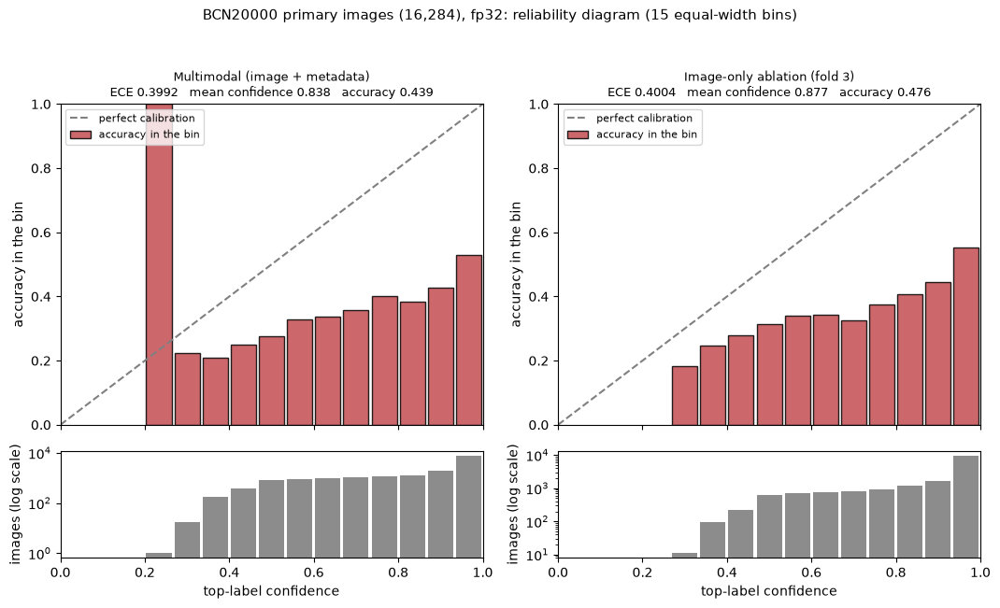


Wrote 18 files to T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\bcn_results
  bcn_overall_fp32.csv                                                     769 bytes
  bcn_site_blind_overall_fp32_EXPLORATORY.csv                              550 bytes
  bcn_site_blind_vs_main_overall_EXPLORATORY.csv                           829 bytes
  bcn_per_class_fp32_multimodal.csv                                      1,807 bytes
  bcn_confusion_counts_fp32_multimodal.csv                                 248 bytes
  bcn_confusion_row_normalised_fp32_multimodal.csv                       1,062 bytes
  bcn_calibration_bins_fp32_multimodal.csv                               1,802 bytes
  bcn_per_class_fp32_ablation.csv                                        1,784 bytes
  bcn_confusion_counts_fp32_ablation.csv                                   247 bytes
  bcn_confusion_row_normalised_fp32_ablation.csv                         1,031 bytes
  bcn_calibration_bins_fp32_ablation.csv                      

In [54]:
"""
08_02_bcn_metrics.txt
Phase 5 -- Module 08: BCN20000 results -- Full metric set on the 16,284 BCN20000 primary images, both models and the site-blind run (computes and writes 18 files; safe to re-run)

TITLE: BCN20000 metrics

TITLE DESCRIPTION
  The external-validation numbers: every metric of the rules note for the multimodal model and the fold 3 image-only ablation on the
  BCN20000 primary images, from the strict-fp32 probabilities (no bf16 appears anywhere in Module 08). Macro AUC-ROC is the primary number;
  accuracy is last and for comparability only. Sensitivity at 95% and 90% specificity (A3) is read from BCN20000's own ROC curves and applies no
  threshold anywhere. The exploratory site-blind run gets the same metrics in separate files whose names say EXPLORATORY, plus one side-by-side
  table against the main multimodal run. These BCN20000 numbers are the "after" side of the generalisation gap (08_03).

CODE DESCRIPTION
  - Refuses to start unless the A4 file exists, passed, and was computed from these same prediction files. Per run it builds the per-class table
    ("undefined" for 0/0, low-sample flag written by code), the overall row (with the number of lesions), both confusion matrices, ECE with its bin
    table, Brier, and one reliability diagram for the two models; every size is checked against the known BCN20000 counts before anything is written.
  - Writes 18 files to bcn_results/ (atomic, deterministic: a re-run replaces files with identical content; re-run 08_03 and 08_04 afterwards,
    because the gap files and the manifest name these files' SHA-256). The 559 SCC images are in no number here.

Requires: 08_00 and 08_01 already run (08_01 must have passed; after a restart 08_00 is enough because the A4 file is read from disk).
"""

import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def ext_metric_record(ms, run):
    return ext_jsonable({"run": run, "label": EXT_RUN_LABELS[run], "precision_mode": EXT_PRECISION, "n_images": ms["n_images"], "decision_rule": "argmax",
                         "classes": ms["classes"], "per_class": ms["per_class"], "macro": ms["macro"],
                         "balanced_accuracy": ms["balanced_accuracy"], "balanced_accuracy_classes_left_out": ms["balanced_accuracy_left_out"],
                         "accuracy": ms["accuracy"], "class_distribution": ms["class_distribution"], "predicted_distribution": ms["predicted_distribution"],
                         "confusion_counts": ms["confusion_counts"], "calibration": ms["calibration"], "brier": ms["brier"]})


def ext_metrics_json(runs, description, metrics, data, a4_sha):
    return {"description": description, "dataset": EXT_DATASET_TEXT, "precision_mode": EXT_PRECISION, "created_at": now_iso(),
            "n_images": int(len(data["labels_primary"])), "n_lesions": data["n_lesions_primary"], "notes": [EXT_IMAGE_LEVEL_NOTE],
            "prediction_file_sha256": {run: data["prediction_sha256"][run] for run in runs}, "a4_file_sha256": a4_sha,
            "runs": {run: ext_metric_record(metrics[run], run) for run in runs}}


def ext_with_model_column(table, run):
    table = table.copy()
    table.insert(0, "Model", EXT_RUN_LABELS[run])
    return table


def ext_overall_frame(runs, metrics, data):
    frame = pd.concat([overall_row(metrics[run], EXT_RUN_LABELS[run], EXT_PRECISION) for run in runs], ignore_index=True)
    frame.insert(frame.columns.get_loc("N images") + 1, "N lesions", data["n_lesions_primary"])
    return frame


def ext_reliability_figure(metrics, runs):
    fig, axes = plt.subplots(2, len(runs), figsize=(5.4 * len(runs), 6.6), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
    for col, run in enumerate(runs):
        ms = metrics[run]
        bins = ms["calibration_bins"]
        filled = bins[bins["n"] > 0]
        centres = (filled["low"] + filled["high"]) / 2.0
        ax, ax_n = axes[0, col], axes[1, col]
        ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
        ax.bar(centres, filled["accuracy"], width=0.9 / ECE_BINS, color="#C44E52", edgecolor="black", alpha=0.85, label="accuracy in the bin")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_ylabel("accuracy in the bin")
        ax.set_title(f"{EXT_RUN_LABELS[run]}\nECE {ms['calibration']['ece']:.4f}   mean confidence {ms['calibration']['mean_confidence']:.3f}   "
                     f"accuracy {ms['calibration']['accuracy']:.3f}", fontsize=9)
        ax.legend(loc="upper left", fontsize=8)
        ax_n.bar(centres, filled["n"], width=0.9 / ECE_BINS, color="#8C8C8C")
        ax_n.set_yscale("log")
        ax_n.set_xlabel("top-label confidence")
        ax_n.set_ylabel("images (log scale)")
    fig.suptitle(f"BCN20000 primary images ({metrics[runs[0]]['n_images']:,}), fp32: reliability diagram ({ECE_BINS} equal-width bins)", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150)
    return fig, buffer.getvalue()


# ---------------------------------------------------------------------------
# 1. The null test must have passed on these same prediction files
# ---------------------------------------------------------------------------
ext_stop_if_files_changed(EXT_DATA)
ext_check_a4_first(EXT_DATA)
EXT_A4_SHA256 = sha256_of_file(EXT_A4_PATH)

# ---------------------------------------------------------------------------
# 2. Metrics (fp32 only; the 559 SCC images are not in these arrays)
# ---------------------------------------------------------------------------
EXT_METRICS = {run: compute_metric_set(EXT_DATA["labels_primary"], EXT_DATA["probs_primary"][run]) for run in EXT_RUNS}

_problems = []
for _run in EXT_RUNS:
    _ms = EXT_METRICS[_run]
    if int(_ms["confusion_counts"].sum()) != EXPECTED_BCN_PRIMARY_TOTAL:
        _problems.append(f"{_run}: the confusion matrix does not hold {EXPECTED_BCN_PRIMARY_TOTAL:,} images")
    if _ms["class_distribution"] != EXPECTED_BCN_PRIMARY_COUNTS:
        _problems.append(f"{_run}: class counts {_ms['class_distribution']} differ from the expected {EXPECTED_BCN_PRIMARY_COUNTS}")
    if sum(_ms["predicted_distribution"].values()) != EXPECTED_BCN_PRIMARY_TOTAL:
        _problems.append(f"{_run}: predicted counts do not add up to {EXPECTED_BCN_PRIMARY_TOTAL:,}")
    if not np.array_equal(_ms["confusion_counts"].sum(axis=0), np.bincount(EXT_DATA["pred_primary"][_run], minlength=len(CLASSES))):
        _problems.append(f"{_run}: the confusion matrix column totals differ from the predicted classes stored in the prediction file")
if _problems:
    raise RuntimeError("BCN20000 METRICS SANITY CHECK FAILED:\n  - " + "\n  - ".join(_problems))

# ---------------------------------------------------------------------------
# 3. Tables
# ---------------------------------------------------------------------------
EXT_TABLES = {}
for _run in EXT_RUNS:
    EXT_TABLES[_run] = {"per_class": metric_table(EXT_METRICS[_run], EXT_PRECISION)}
    EXT_TABLES[_run]["counts"], EXT_TABLES[_run]["row_normalised"] = confusion_frames(EXT_METRICS[_run])
    EXT_TABLES[_run]["bins"] = EXT_METRICS[_run]["calibration_bins"].map(undef)

EXT_OVERALL_MAIN = ext_overall_frame(EXT_MAIN_RUNS, EXT_METRICS, EXT_DATA)
EXT_OVERALL_BLIND = ext_overall_frame([EXT_BLIND_RUN], EXT_METRICS, EXT_DATA)

_flat = {run: flatten_metrics(EXT_METRICS[run]) for run in EXT_RUNS}
_rows = []
for _key, _name in EXT_COMPARE_KEYS:
    _a, _b = _flat["multimodal"][_key], _flat[EXT_BLIND_RUN][_key]
    _rows.append({"Metric": _name, "Multimodal, main vectors": undef(_a), "Multimodal, site-blind (EXPLORATORY)": undef(_b), "Site-blind minus main": undef(_b - _a)})
EXT_N_BLIND_DIFFERENT = int((EXT_DATA["pred_primary"]["multimodal"] != EXT_DATA["pred_primary"][EXT_BLIND_RUN]).sum())
_rows.append({"Metric": "primary images whose predicted class differs between the two runs", "Multimodal, main vectors": 0,
              "Multimodal, site-blind (EXPLORATORY)": EXT_N_BLIND_DIFFERENT, "Site-blind minus main": EXT_N_BLIND_DIFFERENT})
EXT_BLIND_COMPARISON = pd.DataFrame(_rows)

# ---------------------------------------------------------------------------
# 4. Print
# ---------------------------------------------------------------------------
print("=" * 100)
print(f"BCN20000 -- {len(EXT_DATA['labels_primary']):,} primary images, {EXT_DATA['n_lesions_primary']:,} lesions -- fp32 (headline)")
print("=" * 100)
print("\nOverall (macro AUC-ROC is the primary number; accuracy is last and for comparability only):")
print(show(EXT_OVERALL_MAIN.drop(columns=["Precision mode"])).set_index("Model").T.to_string())

for _run in EXT_MAIN_RUNS:
    print(f"\n--- {EXT_RUN_LABELS[_run]}: per class (one-vs-rest, argmax, fp32; sensitivity at fixed specificity from BCN20000's own ROC curve) ---")
    print(show(EXT_TABLES[_run]["per_class"].drop(columns=["Precision mode"])).to_string(index=False))
    print(f"\n{EXT_RUN_LABELS[_run]}: confusion matrix, counts (rows = true class, columns = predicted class)")
    print(EXT_TABLES[_run]["counts"].to_string())
    _cal = EXT_METRICS[_run]["calibration"]
    print(f"Calibration: ECE {_cal['ece']:.4f}, max bin gap {_cal['mce']:.4f}, mean confidence {_cal['mean_confidence']:.4f}, "
          f"accuracy {_cal['accuracy']:.4f}, overconfidence {_cal['overconfidence']:+.4f}; Brier {EXT_METRICS[_run]['brier']:.4f}")
print("\nNote: " + EXT_IMAGE_LEVEL_NOTE)

print("\n" + "=" * 100)
print("EXPLORATORY: site-blind run (the multimodal model with site = unknown for every image) -- separate files, never mixed into a headline table")
print("=" * 100)
print(show(EXT_BLIND_COMPARISON, 4).to_string(index=False))
print(f"\nPrimary images whose predicted class differs between the main and the site-blind run: {EXT_N_BLIND_DIFFERENT:,} "
      f"(only images with a known site can differ; {int((EXT_DATA['table'].loc[EXT_DATA['primary'], 'model_site'] == 'unknown').sum()):,} primary images already have site 'unknown').")

_figure, _png_bytes = ext_reliability_figure(EXT_METRICS, EXT_MAIN_RUNS)
plt.show()
plt.close(_figure)

# ---------------------------------------------------------------------------
# 5. Write (atomic; deterministic, so a re-run replaces files with identical content)
# ---------------------------------------------------------------------------
_description_main = ("BCN20000 primary images, fp32 headline: one-vs-rest metrics per class, macro values over the defined classes, balanced accuracy = mean of the "
                     "7 recalls, ECE top-label equal-width, multiclass Brier, sensitivity at 95% / 90% specificity from BCN20000's own ROC curves. "
                     "'undefined' means 0/0 and is never 0.")
_description_blind = ("EXPLORATORY. The same metrics for the multimodal model given site-blind metadata vectors (site = unknown for every image). "
                      "Separate files; never mixed into a headline table.")

EXT_WRITTEN_METRICS = []


def ext_put_csv(name, frame, index=False):
    atomic_write_csv(frame, EXT_RESULTS_DIR / name, index=index)
    EXT_WRITTEN_METRICS.append(name)


ext_put_csv(EXT_OVERALL_FILE["main"], EXT_OVERALL_MAIN)
ext_put_csv(EXT_OVERALL_FILE["blind"], EXT_OVERALL_BLIND)
ext_put_csv(EXT_BLIND_COMPARISON_FILE, EXT_BLIND_COMPARISON)
for _run in EXT_RUNS:
    _names = EXT_FILES_BY_RUN[_run]
    ext_put_csv(_names["per_class"], ext_with_model_column(EXT_TABLES[_run]["per_class"], _run))
    ext_put_csv(_names["counts"], EXT_TABLES[_run]["counts"], index=True)
    ext_put_csv(_names["row_normalised"], EXT_TABLES[_run]["row_normalised"].map(undef), index=True)
    ext_put_csv(_names["bins"], ext_with_model_column(EXT_TABLES[_run]["bins"], _run))

atomic_write_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"], ext_metrics_json(EXT_MAIN_RUNS, _description_main, EXT_METRICS, EXT_DATA, EXT_A4_SHA256))
EXT_WRITTEN_METRICS.append(EXT_METRICS_JSON["main"])
atomic_write_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["blind"], ext_metrics_json([EXT_BLIND_RUN], _description_blind, EXT_METRICS, EXT_DATA, EXT_A4_SHA256))
EXT_WRITTEN_METRICS.append(EXT_METRICS_JSON["blind"])
atomic_write_bytes(EXT_RESULTS_DIR / EXT_RELIABILITY_PNG, _png_bytes)
EXT_WRITTEN_METRICS.append(EXT_RELIABILITY_PNG)

if sorted(EXT_WRITTEN_METRICS) != sorted(EXT_METRIC_FILES):
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(EXT_WRITTEN_METRICS) ^ set(EXT_METRIC_FILES))}")

print(f"\nWrote {len(EXT_WRITTEN_METRICS)} files to {EXT_RESULTS_DIR}")
for _name in EXT_WRITTEN_METRICS:
    print(f"  {_name:<66}{(EXT_RESULTS_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 08_03 (the generalisation gap against the Combalia anchors, and the SCC view).")

In [55]:
"""
08_03_gap_and_scc.txt
Phase 5 -- Module 08: BCN20000 results -- The generalisation gap against the Combalia anchors, and the SCC view (computes and writes 5 files; safe to re-run)

TITLE: Generalisation gap and SCC view

TITLE DESCRIPTION
  Claim 3 of the rules note: BCN20000 is evaluated and the generalisation gap is reported against both Combalia anchors. For each model the gap is the
  HAM10000 holdout value minus the BCN20000 value, for macro AUC-ROC (in AUROC units) and for balanced accuracy (in percentage points), shown beside
  the closest published figures: the best 2019 challenge algorithm (0.075 AUROC; 23.2 points) and the mean over all algorithms (22.3 points, SD 8.6). They
  are the closest figures available, not like-for-like, so the table gives the difference between the model's gap and each published gap and nothing
  more: no acceptance threshold, no verdict word. A second table shows all headline metrics, holdout beside BCN20000, with no published figure to compare.
  The cell also shows, for the 559 SCC images, where each run puts them (exploratory A6): SCC is not one of the model's seven classes, so this is a
  count of predictions, not a metric.

CODE DESCRIPTION
  - Reads the holdout side from holdout_results/holdout_metrics_fp32.json (proved to be the file the Module 03 manifest lists, computed from the
    unchanged Phase 4 predictions) and the BCN20000 side from the 08_02 JSON file, and writes the two gap tables and a JSON file with every number,
    the anchors and the wording. Nothing is recomputed from a model; 08_04 recomputes both sides from the raw predictions by a second route.
  - For the SCC images counts and shares of every predicted class per run and the share predicted as MEL, BCC or AKIEC ("flagged") against
    NV, BKL, DF or VASC. Writes 2 EXPLORATORY CSV files. Nothing here can change a model, a threshold or an earlier file.

Requires: 08_00 and 08_02 already run (the BCN20000 side is read from the file 08_02 wrote).
"""

import numpy as np
import pandas as pd


def ext_read_holdout_side():
    """The holdout side of the gap, read from disk and proved to be the file the Module 03 manifest lists."""
    for path in (EXT_HOLDOUT_JSON_PATH, EXT_HOLDOUT_MANIFEST_PATH):
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 03 must be finished first.")
    problems = []
    manifest = inf_read_json(EXT_HOLDOUT_MANIFEST_PATH)
    if manifest.get("all_passed") is not True:
        problems.append("the Module 03 manifest does not say that every check passed")
    holdout_sha = sha256_of_file(EXT_HOLDOUT_JSON_PATH)
    if ext_dig(manifest, "files", EXT_HOLDOUT_JSON_PATH.name, "sha256") != holdout_sha:
        problems.append(f"{EXT_HOLDOUT_JSON_PATH.name} differs from the file the Module 03 manifest lists")
    holdout = inf_read_json(EXT_HOLDOUT_JSON_PATH)
    on_disk = {kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in MODEL_KINDS}
    if holdout.get("prediction_file_sha256") != on_disk:
        problems.append("the holdout metrics were computed from other prediction files than the Phase 4 files on disk now")
    if holdout.get("precision_mode") != EXT_PRECISION:
        problems.append(f"the holdout metrics are {holdout.get('precision_mode')!r}, expected {EXT_PRECISION!r}")
    for kind in MODEL_KINDS:
        if ext_dig(holdout, "models", kind, "n_images") != EXPECTED_HOLDOUT_ROWS:
            problems.append(f"{kind}: the holdout record does not describe {EXPECTED_HOLDOUT_ROWS:,} images")
    if problems:
        raise RuntimeError("THE HOLDOUT SIDE DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    return {"json": holdout, "sha256": holdout_sha, "manifest_sha256": sha256_of_file(EXT_HOLDOUT_MANIFEST_PATH)}


def ext_read_bcn_side(data):
    """The BCN20000 side of the gap, read from the file 08_02 wrote, and proved to come from these same predictions and this A4 file."""
    path = EXT_RESULTS_DIR / EXT_METRICS_JSON["main"]
    if not path.is_file():
        raise RuntimeError(f"{path} does not exist. Run 08_02 first.")
    bcn = inf_read_json(path)
    problems = []
    if bcn.get("prediction_file_sha256") != {run: data["prediction_sha256"][run] for run in EXT_MAIN_RUNS}:
        problems.append("the BCN20000 metrics file was computed from other prediction files than the ones loaded now")
    if bcn.get("a4_file_sha256") != sha256_of_file(EXT_A4_PATH):
        problems.append("the BCN20000 metrics file was computed with another A4 file than the one on disk now")
    for run in EXT_MAIN_RUNS:
        if ext_dig(bcn, "runs", run, "n_images") != EXPECTED_BCN_PRIMARY_TOTAL:
            problems.append(f"{run}: the BCN20000 record does not describe {EXPECTED_BCN_PRIMARY_TOTAL:,} images")
    if problems:
        raise RuntimeError("THE BCN20000 SIDE DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems) + "\n  Run 08_02 again.")
    return {"json": bcn, "sha256": sha256_of_file(path)}


def ext_gap_tables(holdout, bcn):
    """(anchored table, all-metrics table) as DataFrames, and the same numbers as plain records for the JSON file."""
    anchored, everything = [], []
    for run in EXT_MAIN_RUNS:
        h_record, b_record = holdout["models"][run], bcn["runs"][run]
        h_auc, b_auc = ext_json_metric(h_record, "macro_auc_roc"), ext_json_metric(b_record, "macro_auc_roc")
        h_ba, b_ba = ext_json_metric(h_record, "balanced_accuracy") * 100.0, ext_json_metric(b_record, "balanced_accuracy") * 100.0
        gap_auc, gap_ba = h_auc - b_auc, h_ba - b_ba
        label = EXT_RUN_LABELS[run]
        anchored.append({"Model": label, "Metric": "Macro AUC-ROC", "Unit": "AUROC", "Holdout (HAM10000)": h_auc, "BCN20000": b_auc, "Gap (holdout minus BCN20000)": gap_auc,
                         "Published figure (closest available)": f"Best 2019 challenge algorithm: AUROC {ANCHOR_AUROC_FROM} to {ANCHOR_AUROC_TO}",
                         "Published gap": ANCHOR_AUROC_DROP, "Model gap minus published gap": gap_auc - ANCHOR_AUROC_DROP})
        anchored.append({"Model": label, "Metric": "Balanced accuracy", "Unit": "percentage points", "Holdout (HAM10000)": h_ba, "BCN20000": b_ba,
                         "Gap (holdout minus BCN20000)": gap_ba,
                         "Published figure (closest available)": f"Best 2019 challenge algorithm: {ANCHOR_BALANCED_ACC_FROM}% to {ANCHOR_BALANCED_ACC_TO}%",
                         "Published gap": ANCHOR_BALANCED_ACC_DROP_PP, "Model gap minus published gap": gap_ba - ANCHOR_BALANCED_ACC_DROP_PP})
        anchored.append({"Model": label, "Metric": "Balanced accuracy", "Unit": "percentage points", "Holdout (HAM10000)": h_ba, "BCN20000": b_ba,
                         "Gap (holdout minus BCN20000)": gap_ba,
                         "Published figure (closest available)": f"Mean over all algorithms of the study (SD {ANCHOR_ALL_ALGORITHMS_SD_PP} points)",
                         "Published gap": ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP, "Model gap minus published gap": gap_ba - ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP})
        for key, name in EXT_COMPARE_KEYS:
            h_value, b_value = ext_json_metric(h_record, key), ext_json_metric(b_record, key)
            everything.append({"Model": label, "Metric": name, "Holdout (HAM10000)": h_value, "BCN20000": b_value, "Change (BCN20000 minus holdout)": b_value - h_value})
    return (pd.DataFrame(anchored).map(undef)[EXT_GAP_COLUMNS], pd.DataFrame(everything).map(undef)[EXT_GAP_ALL_COLUMNS],
            {"anchored": anchored, "all": everything})


def ext_scc_tables(data):
    """Counts and shares of the predicted classes of the SCC images, per run. Descriptive: SCC has no class among the model's seven."""
    n_scc = int(data["scc"].sum())
    if n_scc != EXPECTED_BCN_SCC:
        raise RuntimeError(f"{n_scc} SCC images found, expected {EXPECTED_BCN_SCC}")
    flagged_index = [CLASS_TO_IDX[c] for c in MALIGNANT_CLASSES]
    not_flagged_index = [CLASS_TO_IDX[c] for c in BENIGN_CLASSES]
    split, summary = [], []
    for run in EXT_RUNS:
        counts = np.bincount(data["pred_scc"][run], minlength=len(CLASSES))
        if int(counts.sum()) != n_scc:
            raise RuntimeError(f"{run}: the predicted classes of the SCC images add up to {int(counts.sum())}, not {n_scc}")
        for index, name in enumerate(CLASSES):
            split.append({"Run": EXT_RUN_LABELS[run], "Predicted class": name.upper(), "Images": int(counts[index]), "Share of the SCC images": int(counts[index]) / n_scc})
        flagged, not_flagged = int(counts[flagged_index].sum()), int(counts[not_flagged_index].sum())
        summary.append({"Run": EXT_RUN_LABELS[run], "SCC images": n_scc, EXT_FLAGGED_NAME: flagged, "Share flagged": flagged / n_scc,
                        EXT_NOT_FLAGGED_NAME: not_flagged, "Share not flagged": not_flagged / n_scc})
    return pd.DataFrame(split)[EXT_SCC_SPLIT_COLUMNS], pd.DataFrame(summary)[EXT_SCC_FLAGGED_COLUMNS]


# ---------------------------------------------------------------------------
# 1. Inputs: the null test passed, the predictions are unchanged, both sides of the gap come from verified files
# ---------------------------------------------------------------------------
ext_stop_if_files_changed(EXT_DATA)
ext_check_a4_first(EXT_DATA)
EXT_HOLDOUT_SIDE = ext_read_holdout_side()
EXT_BCN_SIDE = ext_read_bcn_side(EXT_DATA)

# ---------------------------------------------------------------------------
# 2. Tables
# ---------------------------------------------------------------------------
EXT_GAP_ANCHORED, EXT_GAP_ALL, EXT_GAP_RECORDS = ext_gap_tables(EXT_HOLDOUT_SIDE["json"], EXT_BCN_SIDE["json"])
EXT_SCC_SPLIT, EXT_SCC_FLAGGED = ext_scc_tables(EXT_DATA)

print("=" * 100)
print("GENERALISATION GAP (Claim 3): HAM10000 holdout minus BCN20000, beside the closest published figures")
print("=" * 100)
print("Macro AUC-ROC gap is in AUROC units; balanced accuracy is in percentage points. The published figures are not like-for-like (see the note below).\n")
print(show(EXT_GAP_ANCHORED, 4).to_string(index=False))
print("\n" + EXT_COMPARABILITY_NOTE)
print("\nAll headline metrics, holdout beside BCN20000 (no published figure exists for these; the change is BCN20000 minus holdout, so for ECE and Brier a positive change means worse):")
print(show(EXT_GAP_ALL, 4).to_string(index=False))
print("\nNote: " + EXT_IMAGE_LEVEL_NOTE)

print("\n" + "=" * 100)
print(f"EXPLORATORY (A6): where the {EXPECTED_BCN_SCC} SCC images go. SCC is not one of the model's seven classes, so this counts predictions; it is not a metric.")
print("=" * 100)
print(show(EXT_SCC_FLAGGED, 4).to_string(index=False))
print("\nPredicted class of the SCC images, per run:")
print(show(EXT_SCC_SPLIT.pivot(index="Predicted class", columns="Run", values="Images").reindex([c.upper() for c in CLASSES])[[EXT_RUN_LABELS[r] for r in EXT_RUNS]]).to_string())

# ---------------------------------------------------------------------------
# 3. Write (atomic; deterministic apart from the time stamp)
# ---------------------------------------------------------------------------
_gap_record = {
    "description": ("Generalisation gap of the two frozen models: HAM10000 holdout value minus BCN20000 value, for macro AUC-ROC (AUROC units) and balanced accuracy "
                    "(percentage points), beside the closest published figures. Claim 3 of the rules note. All numbers are read from verified files; nothing is recomputed from a model."),
    "created_at": now_iso(), "definition": "gap = holdout value minus BCN20000 value; balanced accuracy in percentage points",
    "holdout_file": {"path": str(EXT_HOLDOUT_JSON_PATH), "sha256": EXT_HOLDOUT_SIDE["sha256"], "manifest_sha256": EXT_HOLDOUT_SIDE["manifest_sha256"]},
    "bcn_file": {"path": str(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"]), "sha256": EXT_BCN_SIDE["sha256"]},
    "a4_file_sha256": sha256_of_file(EXT_A4_PATH),
    "anchors": {"source": "Combalia et al. (2022), Lancet Digit Health 4:e330-e339", "status": ANCHOR_STATUS,
                "auroc_drop": ANCHOR_AUROC_DROP, "auroc_from": ANCHOR_AUROC_FROM, "auroc_to": ANCHOR_AUROC_TO,
                "balanced_accuracy_drop_pp": ANCHOR_BALANCED_ACC_DROP_PP, "balanced_accuracy_from": ANCHOR_BALANCED_ACC_FROM, "balanced_accuracy_to": ANCHOR_BALANCED_ACC_TO,
                "all_algorithms_balanced_accuracy_drop_pp": ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP, "all_algorithms_sd_pp": ANCHOR_ALL_ALGORITHMS_SD_PP},
    "wording": EXT_COMPARABILITY_NOTE, "notes": [EXT_IMAGE_LEVEL_NOTE],
    "anchored_rows": EXT_GAP_RECORDS["anchored"], "all_headline_rows": EXT_GAP_RECORDS["all"],
}
EXT_WRITTEN_GAP = []
for _name, _frame in ((EXT_GAP_FILES["anchored"], EXT_GAP_ANCHORED), (EXT_GAP_FILES["all"], EXT_GAP_ALL),
                      (EXT_SCC_FILES["split"], EXT_SCC_SPLIT), (EXT_SCC_FILES["flagged"], EXT_SCC_FLAGGED)):
    atomic_write_csv(_frame, EXT_RESULTS_DIR / _name)
    EXT_WRITTEN_GAP.append(_name)
atomic_write_json(EXT_RESULTS_DIR / EXT_GAP_FILES["json"], ext_jsonable(_gap_record))
EXT_WRITTEN_GAP.append(EXT_GAP_FILES["json"])

if sorted(EXT_WRITTEN_GAP) != sorted(EXT_GAP_SCC_FILES):
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(EXT_WRITTEN_GAP) ^ set(EXT_GAP_SCC_FILES))}")

print(f"\nWrote {len(EXT_WRITTEN_GAP)} files to {EXT_RESULTS_DIR}")
for _name in EXT_WRITTEN_GAP:
    print(f"  {_name:<66}{(EXT_RESULTS_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 08_04 (re-reads every file from disk, recomputes by a second route, writes the manifest).")

GENERALISATION GAP (Claim 3): HAM10000 holdout minus BCN20000, beside the closest published figures
Macro AUC-ROC gap is in AUROC units; balanced accuracy is in percentage points. The published figures are not like-for-like (see the note below).

                        Model            Metric              Unit Holdout (HAM10000) BCN20000 Gap (holdout minus BCN20000)                  Published figure (closest available) Published gap Model gap minus published gap
Multimodal (image + metadata)     Macro AUC-ROC             AUROC             0.9348   0.7558                       0.1790   Best 2019 challenge algorithm: AUROC 0.981 to 0.907        0.0750                        0.1040
Multimodal (image + metadata) Balanced accuracy percentage points            66.4852  34.6841                      31.8010         Best 2019 challenge algorithm: 82.0% to 58.8%       23.2000                        8.6010
Multimodal (image + metadata) Balanced accuracy percentage points            66.4852  34.6

In [56]:
"""
08_04_check_bcn_results.txt
Phase 5 -- Module 08: BCN20000 results -- Check the BCN20000 results from disk and write the manifest (verification; safe to re-run)

TITLE: Check the BCN20000 results

TITLE DESCRIPTION
  Closes Module 08. Every file written by 08_01 to 08_03 is read back from disk, and every number in it is recomputed by a second route that shares no
  code with the metric library: confusion matrix and recall / precision / F1 from scikit-learn, AUC-ROC from ranks, PR-AUC from its threshold definition,
  sensitivity at fixed specificity by trying every threshold, ECE with np.digitize, Brier class by class. The holdout side of the gap is recomputed the same
  way from the raw Phase 4 predictions, and the SCC counts from the raw probabilities. It also proves that the inputs did not change, that the rules note
  was written before the first result file, that nothing unexpected sits in the folder, that no SCC image is in any metric, that no bf16 number and no
  exploratory number leaked into a headline file, and that the gap files contain no verdict word. Only if every check passes is the manifest written.

CODE DESCRIPTION
  - Runs several hundred checks in 17 groups (inputs, rules note and folder; A4 file; per-class, overall, confusion and calibration and JSON files per
    run; site-blind comparison; gap; SCC; wording and scope; PNG) and prints one line per group. All failures are collected and ONE error is
    raised at the end; in that case no manifest is written.
  - On success writes bcn_results/bcn_results_manifest.json: size and SHA-256 of all 24 result files, the SHA-256 of everything the results were made
    from, the headline numbers and the gap. Module 10 re-hashes these files against it.

Requires: 08_00 already run in this kernel (it needs no other Module 08 object; everything is read from disk). Takes about 1 to 2 minutes.
"""

import re

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, precision_recall_fscore_support

EXT_CHECK_TOL = 1e-9
EXT_PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"
EXT_PER_CLASS_COLUMNS = (["Model", "Precision mode", "Class", "N", "N predicted", "AUC-ROC", "Sensitivity (recall)", "Specificity", "Precision", "F1", "PR-AUC"]
                         + [SENS_AT_SPEC_COLUMNS[t] for t in SPECIFICITY_TARGETS] + ["Flag"])
EXT_OVERALL_COLUMNS = ["Model", "Precision mode", "N images", "N lesions", "Macro AUC-ROC (primary)", "Balanced accuracy", "Macro-F1", "Macro precision",
                       "Macro precision, classes left out", "Macro PR-AUC", f"ECE (top-label, {ECE_BINS} bins)", "Brier (multiclass)", "Mean confidence",
                       "Overconfidence (confidence - accuracy)", "Accuracy (comparability only)"]
EXT_COMPARISON_COLUMNS = ["Metric", "Multimodal, main vectors", "Multimodal, site-blind (EXPLORATORY)", "Site-blind minus main"]
EXT_ALT_WHERE = {"macro_auc_roc": ("macro", "auc_roc"), "balanced_accuracy": ("top", "balanced_accuracy"), "macro_f1": ("macro", "f1"),
                 "macro_precision": ("macro", "precision"), "macro_pr_auc": ("macro", "pr_auc"), "ece": ("top", "ece"), "brier": ("top", "brier"),
                 "accuracy": ("top", "accuracy")}
EXT_VERDICT_WORDS = re.compile(r"\b(benchmark\w*|pass\w*|fail\w*|meets?|exceeds?|acceptable)\b", re.IGNORECASE)
EXT_METRIC_WORDS = re.compile(r"\b(sensitivity|recall|accuracy|correct\w*|detect\w*|missed)\b", re.IGNORECASE)
EXT_EXPLORATORY_WORDS = re.compile(r"site[-_ ]blind|exploratory", re.IGNORECASE)


# ---------------------------------------------------------------------------
# Second route: written separately from 03_00, on purpose
# ---------------------------------------------------------------------------

def ext_alt_div(numerator, denominator):
    return NAN if denominator == 0 else float(numerator) / float(denominator)


def ext_alt_auc(y_bin, scores):
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return NAN
    ranks = rankdata(scores)                                        # average ranks for ties
    return float((ranks[y_bin == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def ext_alt_ap(y_bin, scores):
    n_pos = int(y_bin.sum())
    if n_pos == 0:
        return NAN
    order = np.argsort(-scores, kind="mergesort")
    sorted_scores, sorted_y = scores[order], y_bin[order]
    tp = np.cumsum(sorted_y)
    fp = np.cumsum(1 - sorted_y)
    last_of_group = np.concatenate([sorted_scores[1:] != sorted_scores[:-1], [True]])      # one threshold per distinct score
    tp, fp = tp[last_of_group], fp[last_of_group]
    precision = tp / (tp + fp)
    recall = tp / n_pos
    previous_recall = np.concatenate([[0.0], recall[:-1]])
    return float(np.sum((recall - previous_recall) * precision))


def ext_alt_sens_at_spec(y_bin, scores, target):
    """Every threshold tried: flag everything with score >= a distinct score (and the threshold above all scores). Returns (sensitivity, specificity reached)."""
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return NAN, NAN
    order = np.argsort(-scores, kind="mergesort")
    sorted_scores, sorted_y = scores[order], y_bin[order]
    flagged_pos = np.cumsum(sorted_y)
    flagged_neg = np.cumsum(1 - sorted_y)
    last_of_group = np.concatenate([sorted_scores[1:] != sorted_scores[:-1], [True]])
    sens = np.concatenate([[0.0], flagged_pos[last_of_group] / n_pos])                    # first entry: nothing flagged
    spec = np.concatenate([[1.0], 1.0 - flagged_neg[last_of_group] / n_neg])
    feasible = spec >= target - 1e-12
    best_sens = sens[feasible].max()
    best_spec = spec[feasible & (sens == best_sens)].max()
    return float(best_sens), float(best_spec)


def ext_alt_ece(labels, probs, n_bins):
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == labels).astype(np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    index = np.digitize(confidence, edges[1:-1], right=True)                       # bins are (low, high], the first also holds 0
    ece = 0.0
    for b in range(n_bins):
        in_bin = index == b
        if in_bin.any():
            ece += in_bin.mean() * abs(correct[in_bin].mean() - confidence[in_bin].mean())
    return float(ece)


def ext_alt_brier(labels, probs):
    return float(sum(np.mean((probs[:, k] - (labels == k).astype(np.float64)) ** 2) for k in range(probs.shape[1])))


def ext_alt_mean(values):
    defined = [v for v in values if not np.isnan(v)]
    return float(np.mean(defined)) if defined else NAN


def ext_second_route(labels, probs):
    labels = np.asarray(labels, dtype=np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    k = probs.shape[1]
    pred = probs.argmax(axis=1)
    cm = confusion_matrix(labels, pred, labels=list(range(k)))
    total = int(cm.sum())
    tp = np.diag(cm).astype(np.float64)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = total - tp - fn - fp
    sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(labels, pred, labels=list(range(k)), average=None, zero_division=np.nan)
    per_class = {}
    for i, name in enumerate(CLASSES):
        y_bin = (labels == i).astype(np.int64)
        entry = {"n": int(cm[i].sum()), "n_predicted": int(cm[:, i].sum()),
                 "recall": ext_alt_div(tp[i], tp[i] + fn[i]), "specificity": ext_alt_div(tn[i], tn[i] + fp[i]),
                 "precision": ext_alt_div(tp[i], tp[i] + fp[i]), "f1": ext_alt_div(2 * tp[i], 2 * tp[i] + fp[i] + fn[i]),
                 "auc_roc": ext_alt_auc(y_bin, probs[:, i]), "pr_auc": ext_alt_ap(y_bin, probs[:, i]),
                 "sk_precision": float(sk_precision[i]), "sk_recall": float(sk_recall[i]), "sk_f1": float(sk_f1[i])}
        for target in SPECIFICITY_TARGETS:
            sens, spec = ext_alt_sens_at_spec(y_bin, probs[:, i], target)
            entry[SENS_AT_SPEC_KEYS[target]] = sens
            entry[SENS_AT_SPEC_KEYS[target] + "_achieved_specificity"] = spec
        per_class[name] = entry
    fields = ["auc_roc", "recall", "specificity", "precision", "f1", "pr_auc"] + [SENS_AT_SPEC_KEYS[t] for t in SPECIFICITY_TARGETS]
    macro = {field: ext_alt_mean([per_class[c][field] for c in CLASSES]) for field in fields}
    accuracy = float(accuracy_score(labels, pred))
    mean_confidence = float(probs.max(axis=1).mean())
    return {"cm": cm, "per_class": per_class, "macro": macro, "balanced_accuracy": float(balanced_accuracy_score(labels, pred)), "accuracy": accuracy,
            "ece": ext_alt_ece(labels, probs, ECE_BINS), "brier": ext_alt_brier(labels, probs), "mean_confidence": mean_confidence}


def ext_alt_value(alt, key):
    where, field = EXT_ALT_WHERE[key]
    return alt["macro"][field] if where == "macro" else alt[field]


def ext_read_table(name, **kwargs):
    return pd.read_csv(EXT_RESULTS_DIR / name, dtype=str, keep_default_na=False, **kwargs)


def ext_read_text(name):
    return (EXT_RESULTS_DIR / name).read_text(encoding="utf-8")


# ---------------------------------------------------------------------------
# The checks
# ---------------------------------------------------------------------------

def ext_check_results():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same(a, b, tol=EXT_CHECK_TOL):
        a, b = to_float(a), to_float(b)
        if np.isnan(a) or np.isnan(b):
            return bool(np.isnan(a) and np.isnan(b))
        return abs(a - b) <= tol

    def compare(group, label, found, wanted, tol=EXT_CHECK_TOL):
        check(group, label, same(found, wanted, tol), f"file says {found!r}, second route says {wanted!r}")

    # ---- 1. inputs, rules note, folder -------------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match (models, Phase 4 files incl. both prediction files, inputs, BCN20000 CSV)", True)
    except Exception as exc:  # noqa: BLE001 -- any failure here is a failed check, reported with the others
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    try:
        note = check_rules_note(verbose=False)
        check(g, "the rules note still equals the rules rebuilt from the constants", note["passed"], f"failed: {note['failed']}")
    except Exception as exc:  # noqa: BLE001
        check(g, "the rules note could be checked", False, f"{type(exc).__name__}: {exc}")
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    try:
        data = ext_load_predictions()
        check(g, "the Module 07 manifest, the three prediction files (SHA-256 equal to the manifest; keys, shapes, probabilities, image order, labels, model identity, "
                 "batch size), the metadata table and the vectors all check out again, read fresh from disk", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "the predictions could be loaded and proved", False, f"{type(exc).__name__}: {exc}")
        return checks, None

    present = sorted(p.name for p in EXT_RESULTS_DIR.rglob("*") if p.is_file())
    allowed = set(EXT_EXPECTED_FILES) | {EXT_MANIFEST_NAME}
    missing = sorted(set(EXT_EXPECTED_FILES) - set(present))
    check(g, f"all {len(EXT_EXPECTED_FILES)} promised result files exist", not missing, f"missing: {missing}")
    check(g, "no other file sits in bcn_results (no leftover .tmp)", set(present) <= allowed, f"unexpected: {sorted(set(present) - allowed)}")
    check(g, "no result file is empty", all((EXT_RESULTS_DIR / n).stat().st_size > 0 for n in EXT_EXPECTED_FILES if (EXT_RESULTS_DIR / n).is_file()))
    if missing:
        return checks, None                                                  # the later groups need these files

    labels_p = data["labels_primary"]
    n_primary = len(labels_p)
    alt = {run: ext_second_route(labels_p, data["probs_primary"][run]) for run in EXT_RUNS}
    a4_sha = sha256_of_file(EXT_A4_PATH)

    # ---- 2. A4 file --------------------------------------------------------------------------------------
    g = "A4 null-test file"
    a4 = inf_read_json(EXT_A4_PATH)
    check(g, "says passed = true, for all three runs", a4.get("passed") is True and set(a4.get("runs") or {}) == set(EXT_RUNS) and all(a4["runs"][r]["passed"] is True for r in EXT_RUNS))
    check(g, "rule fields equal the constants of the rules note",
          (a4["rule"]["n_shuffles"], a4["rule"]["seed"], a4["rule"]["auc_tolerance"], a4["rule"]["balanced_accuracy_tolerance"])
          == (NULL_N_SHUFFLES, RANDOM_SEED, NULL_AUC_TOL, NULL_BALANCED_ACC_TOL))
    check(g, "computed from the loaded prediction files", a4["prediction_file_sha256"] == {r: data["prediction_sha256"][r] for r in EXT_RUNS})
    for run in EXT_RUNS:
        again = run_null_test(labels_p, data["probs_primary"][run])
        for quantity in ("macro_auc_roc", "balanced_accuracy"):
            check(g, f"{run}: {quantity} mean reproduces exactly when the test is run again", same(a4["runs"][run][quantity]["mean"], again[quantity]["mean"], 1e-12),
                  f"{a4['runs'][run][quantity]['mean']!r} vs {again[quantity]['mean']!r}")

    # ---- 3. per-class files ------------------------------------------------------------------------------
    for run in EXT_RUNS:
        g = f"per-class file, {run}"
        a = alt[run]
        df = ext_read_table(EXT_FILES_BY_RUN[run]["per_class"])
        check(g, "columns are exactly the promised ones, in order", list(df.columns) == EXT_PER_CLASS_COLUMNS, f"found {list(df.columns)}")
        check(g, "8 rows: the 7 classes in model order, then MACRO", df["Class"].tolist() == [c.upper() for c in CLASSES] + ["MACRO"])
        check(g, "every row carries the precision-mode label fp32", (df["Precision mode"] == EXT_PRECISION).all(), f"found {sorted(df['Precision mode'].unique())}")
        check(g, "every row carries the model name of this run", (df["Model"] == EXT_RUN_LABELS[run]).all())
        check(g, "no metric cell is blank or reads nan/NaN/None (only the Flag column may be empty)",
              not df.drop(columns=["Flag"]).apply(lambda col: col.str.strip().str.lower().isin(["", "nan", "none", "null"])).to_numpy().any())
        any_undefined = False
        for i, name in enumerate(CLASSES):
            row = df[df["Class"] == name.upper()].iloc[0]
            e = a["per_class"][name]
            compare(g, f"{name}: N", row["N"], e["n"])
            compare(g, f"{name}: N equals the known BCN20000 count", row["N"], EXPECTED_BCN_PRIMARY_COUNTS[name])
            compare(g, f"{name}: N predicted", row["N predicted"], e["n_predicted"])
            for column, key in (("AUC-ROC", "auc_roc"), ("Sensitivity (recall)", "recall"), ("Specificity", "specificity"), ("Precision", "precision"),
                                ("F1", "f1"), ("PR-AUC", "pr_auc")) + tuple((SENS_AT_SPEC_COLUMNS[t], SENS_AT_SPEC_KEYS[t]) for t in SPECIFICITY_TARGETS):
                compare(g, f"{name}: {column}", row[column], e[key])
            compare(g, f"{name}: precision agrees with scikit-learn", row["Precision"], e["sk_precision"])
            compare(g, f"{name}: recall agrees with scikit-learn", row["Sensitivity (recall)"], e["sk_recall"])
            compare(g, f"{name}: F1 agrees with scikit-learn", row["F1"], e["sk_f1"])
            check(g, f"{name}: precision reads 'undefined' exactly when the class is never predicted", (row["Precision"] == UNDEFINED) == (e["n_predicted"] == 0))
            check(g, f"{name}: the low-sample flag is present exactly when N < {LOW_SAMPLE_N}", ("low sample" in row["Flag"]) == (e["n"] < LOW_SAMPLE_N), f"N {e['n']}, flag {row['Flag']!r}")
            any_undefined = any_undefined or any(np.isnan(e[f]) for f in ("auc_roc", "recall", "precision", "f1", "pr_auc"))
        macro_row = df[df["Class"] == "MACRO"].iloc[0]
        compare(g, "MACRO: N is the number of primary images", macro_row["N"], EXPECTED_BCN_PRIMARY_TOTAL)
        for column, key in (("AUC-ROC", "auc_roc"), ("Sensitivity (recall)", "recall"), ("Specificity", "specificity"), ("Precision", "precision"),
                            ("F1", "f1"), ("PR-AUC", "pr_auc")) + tuple((SENS_AT_SPEC_COLUMNS[t], SENS_AT_SPEC_KEYS[t]) for t in SPECIFICITY_TARGETS):
            compare(g, f"MACRO: {column} = mean over the defined classes", macro_row[column], a["macro"][key])
        check(g, "MACRO flag names the classes left out exactly when some class is undefined", ("excludes" in macro_row["Flag"]) == any_undefined, macro_row["Flag"])
        compare(g, "MACRO recall equals scikit-learn's balanced accuracy", macro_row["Sensitivity (recall)"], a["balanced_accuracy"])

    # ---- 4. overall files --------------------------------------------------------------------------------
    for which, runs_in in (("main", EXT_MAIN_RUNS), ("blind", (EXT_BLIND_RUN,))):
        g = f"overall file, {which}"
        df = ext_read_table(EXT_OVERALL_FILE[which])
        check(g, "columns are exactly the promised ones, in order (accuracy last)", list(df.columns) == EXT_OVERALL_COLUMNS, f"found {list(df.columns)}")
        check(g, "one row per run, in run order", df["Model"].tolist() == [EXT_RUN_LABELS[r] for r in runs_in])
        check(g, "every row carries the precision-mode label fp32", (df["Precision mode"] == EXT_PRECISION).all())
        for run in runs_in:
            row = df[df["Model"] == EXT_RUN_LABELS[run]].iloc[0]
            a = alt[run]
            compare(g, f"{run}: N images is the number of primary images", row["N images"], EXPECTED_BCN_PRIMARY_TOTAL)
            compare(g, f"{run}: N lesions", row["N lesions"], data["table"].loc[data["primary"], "lesion_id"].nunique())
            compare(g, f"{run}: macro AUC-ROC", row["Macro AUC-ROC (primary)"], a["macro"]["auc_roc"])
            compare(g, f"{run}: balanced accuracy (scikit-learn)", row["Balanced accuracy"], a["balanced_accuracy"])
            compare(g, f"{run}: macro-F1", row["Macro-F1"], a["macro"]["f1"])
            compare(g, f"{run}: macro precision", row["Macro precision"], a["macro"]["precision"])
            compare(g, f"{run}: macro precision, classes left out", row["Macro precision, classes left out"], sum(np.isnan(a["per_class"][c]["precision"]) for c in CLASSES))
            compare(g, f"{run}: macro PR-AUC", row["Macro PR-AUC"], a["macro"]["pr_auc"])
            compare(g, f"{run}: ECE ({ECE_BINS} bins, np.digitize)", row[f"ECE (top-label, {ECE_BINS} bins)"], a["ece"])
            compare(g, f"{run}: Brier", row["Brier (multiclass)"], a["brier"])
            compare(g, f"{run}: mean confidence", row["Mean confidence"], a["mean_confidence"])
            compare(g, f"{run}: overconfidence = mean confidence minus accuracy", row["Overconfidence (confidence - accuracy)"], a["mean_confidence"] - a["accuracy"])
            compare(g, f"{run}: accuracy (scikit-learn)", row["Accuracy (comparability only)"], a["accuracy"])

    # ---- 5. confusion and calibration files --------------------------------------------------------------
    for run in EXT_RUNS:
        g = f"confusion and calibration files, {run}"
        a = alt[run]
        names = EXT_FILES_BY_RUN[run]
        counts = ext_read_table(names["counts"], index_col=0).astype(np.int64)
        check(g, "counts matrix equals scikit-learn's confusion matrix", np.array_equal(counts.to_numpy(), a["cm"]))
        check(g, f"counts matrix sums to {EXPECTED_BCN_PRIMARY_TOTAL:,} and its row sums are the known BCN20000 class counts",
              int(counts.to_numpy().sum()) == EXPECTED_BCN_PRIMARY_TOTAL and {c: int(counts.to_numpy()[i].sum()) for i, c in enumerate(CLASSES)} == EXPECTED_BCN_PRIMARY_COUNTS)
        check(g, "row and column labels are the 7 classes in model order", counts.index.tolist() == [c.upper() for c in CLASSES] and counts.columns.tolist() == [c.upper() for c in CLASSES])
        normalised = ext_read_table(names["row_normalised"], index_col=0)
        want = a["cm"] / a["cm"].sum(axis=1, keepdims=True)
        check(g, "row-normalised matrix equals counts / row sums", all(same(normalised.to_numpy()[i, j], want[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES))))
        bins = ext_read_table(names["bins"])
        check(g, f"calibration table has {ECE_BINS} bins", len(bins) == ECE_BINS)
        edges = np.linspace(0.0, 1.0, ECE_BINS + 1)
        check(g, "bin edges are the equal-width edges on [0, 1]", len(bins) == ECE_BINS and all(same(bins["low"].iloc[i], edges[i]) and same(bins["high"].iloc[i], edges[i + 1]) for i in range(ECE_BINS)))
        n_in_bins = bins["n"].astype(np.int64)
        check(g, f"bin counts add up to {EXPECTED_BCN_PRIMARY_TOTAL:,}", int(n_in_bins.sum()) == EXPECTED_BCN_PRIMARY_TOTAL)
        ece_from_bins = sum(int(n) / EXPECTED_BCN_PRIMARY_TOTAL * to_float(gap) for n, gap in zip(n_in_bins, bins["gap"]) if int(n) > 0)
        compare(g, "ECE recomputed from the bin table equals the second-route ECE", ece_from_bins, a["ece"])
        check(g, "empty bins read 'undefined' (never 0)", all((to_float(m) != to_float(m)) for n, m in zip(n_in_bins, bins["mean_confidence"]) if int(n) == 0))

    # ---- 6. JSON files -----------------------------------------------------------------------------------
    for which, runs_in in (("main", EXT_MAIN_RUNS), ("blind", (EXT_BLIND_RUN,))):
        g = f"JSON file, {which}"
        js = inf_read_json(EXT_RESULTS_DIR / EXT_METRICS_JSON[which])
        check(g, "precision mode of the file", js["precision_mode"] == EXT_PRECISION, js["precision_mode"])
        check(g, "computed from the loaded prediction files and the A4 file on disk",
              js["prediction_file_sha256"] == {r: data["prediction_sha256"][r] for r in runs_in} and js["a4_file_sha256"] == a4_sha)
        check(g, "image and lesion counts", js["n_images"] == EXPECTED_BCN_PRIMARY_TOTAL and js["n_lesions"] == EXPECTED_BCN_PRIMARY_LESIONS)
        check(g, "the image-level note is in the file", EXT_IMAGE_LEVEL_NOTE in js["notes"])
        check(g, "holds exactly the runs of this file", set(js["runs"]) == set(runs_in))
        for run in runs_in:
            m, a = js["runs"][run], alt[run]
            check(g, f"{run}: precision mode inside the record", m["precision_mode"] == EXT_PRECISION)
            check(g, f"{run}: confusion matrix equals scikit-learn's", np.array_equal(np.array(m["confusion_counts"]), a["cm"]))
            for key, name in EXT_COMPARE_KEYS:
                compare(g, f"{run}: {name}", ext_json_metric(m, key), ext_alt_value(a, key))
            for c in CLASSES:
                for field in ("auc_roc", "recall", "precision", "f1", "pr_auc"):
                    compare(g, f"{run} {c}: {field}", m["per_class"][c][field], a["per_class"][c][field])
                for target in SPECIFICITY_TARGETS:
                    key = SENS_AT_SPEC_KEYS[target]
                    compare(g, f"{run} {c}: {key}", m["per_class"][c][key], a["per_class"][c][key])
                    compare(g, f"{run} {c}: {key} achieved specificity", m["per_class"][c][key + "_achieved_specificity"], a["per_class"][c][key + "_achieved_specificity"])
                    check(g, f"{run} {c}: {key} was read at a specificity of at least {target}", to_float(m["per_class"][c][key + "_achieved_specificity"]) >= target - 1e-9)

    # ---- 7. site-blind comparison file -------------------------------------------------------------------
    g = "site-blind comparison file (EXPLORATORY)"
    cmp_df = ext_read_table(EXT_BLIND_COMPARISON_FILE)
    check(g, "columns are exactly the promised ones", list(cmp_df.columns) == EXT_COMPARISON_COLUMNS, f"found {list(cmp_df.columns)}")
    check(g, "the 8 metrics in order, then the count of images whose predicted class differs",
          cmp_df["Metric"].tolist()[:len(EXT_COMPARE_KEYS)] == [name for _, name in EXT_COMPARE_KEYS] and len(cmp_df) == len(EXT_COMPARE_KEYS) + 1)
    if list(cmp_df.columns) == EXT_COMPARISON_COLUMNS and len(cmp_df) == len(EXT_COMPARE_KEYS) + 1:
        for (key, name), (_, row) in zip(EXT_COMPARE_KEYS, cmp_df.iterrows()):
            main_value, blind_value = ext_alt_value(alt["multimodal"], key), ext_alt_value(alt[EXT_BLIND_RUN], key)
            compare(g, f"{name}: main column", row["Multimodal, main vectors"], main_value)
            compare(g, f"{name}: site-blind column", row["Multimodal, site-blind (EXPLORATORY)"], blind_value)
            compare(g, f"{name}: difference column", row["Site-blind minus main"], blind_value - main_value)
        differ = data["probs_primary"]["multimodal"].argmax(axis=1) != data["probs_primary"][EXT_BLIND_RUN].argmax(axis=1)
        last = cmp_df.iloc[len(EXT_COMPARE_KEYS)]
        compare(g, "images whose predicted class differs between the two runs", last["Multimodal, site-blind (EXPLORATORY)"], int(differ.sum()))
        known_site = (data["table"].loc[data["primary"], "model_site"] != "unknown").to_numpy()
        check(g, "every image whose predicted class differs has a known site (images with site 'unknown' have identical vectors in both runs)", bool(known_site[differ].all()))

    # ---- 8. gap files ------------------------------------------------------------------------------------
    g = "gap files"
    holdout_json = inf_read_json(EXT_HOLDOUT_JSON_PATH)
    holdout_manifest = inf_read_json(EXT_HOLDOUT_MANIFEST_PATH)
    holdout_sha = sha256_of_file(EXT_HOLDOUT_JSON_PATH)
    bcn_json_sha = sha256_of_file(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"])
    check(g, "the holdout metrics file is the one the Module 03 manifest lists, and that manifest says every check passed",
          ext_dig(holdout_manifest, "files", EXT_HOLDOUT_JSON_PATH.name, "sha256") == holdout_sha and holdout_manifest.get("all_passed") is True)
    p4_sha = {kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in MODEL_KINDS}
    check(g, "the holdout metrics were computed from the Phase 4 prediction files on disk now", holdout_json.get("prediction_file_sha256") == p4_sha)
    alt_h = {}
    for kind in MODEL_KINDS:
        with np.load(str(PHASE4_PREDICTION_FILES[kind]), allow_pickle=False) as archive:
            alt_h[kind] = ext_second_route(archive["labels"].astype(np.int64), archive["probs"].astype(np.float64))
        for key, name in EXT_COMPARE_KEYS:
            compare(g, f"{kind}: holdout {name} in the Module 03 file equals the second route from the raw Phase 4 predictions",
                    ext_json_metric(holdout_json["models"][kind], key), ext_alt_value(alt_h[kind], key))

    gap = ext_read_table(EXT_GAP_FILES["anchored"])
    check(g, "gap table: columns are exactly the promised ones, in order", list(gap.columns) == EXT_GAP_COLUMNS, f"found {list(gap.columns)}")
    check(g, "gap table: 6 rows, the AUROC row and the two balanced-accuracy rows for each model", len(gap) == 6)
    for run in EXT_MAIN_RUNS:
        rows = gap[gap["Model"] == EXT_RUN_LABELS[run]]
        check(g, f"gap table, {run}: three rows", len(rows) == 3)
        if len(rows) != 3:
            continue
        auc_row, ba_best, ba_all = rows.iloc[0], rows.iloc[1], rows.iloc[2]
        check(g, f"gap table, {run}: row order, metric names and units",
              [auc_row["Metric"], ba_best["Metric"], ba_all["Metric"]] == ["Macro AUC-ROC", "Balanced accuracy", "Balanced accuracy"]
              and auc_row["Unit"] == "AUROC" and ba_best["Unit"] == "percentage points" and ba_all["Unit"] == "percentage points")
        check(g, f"gap table, {run}: the published-figure texts carry the verified anchor numbers",
              str(ANCHOR_AUROC_FROM) in auc_row["Published figure (closest available)"] and str(ANCHOR_AUROC_TO) in auc_row["Published figure (closest available)"]
              and str(ANCHOR_BALANCED_ACC_FROM) in ba_best["Published figure (closest available)"] and str(ANCHOR_BALANCED_ACC_TO) in ba_best["Published figure (closest available)"]
              and str(ANCHOR_ALL_ALGORITHMS_SD_PP) in ba_all["Published figure (closest available)"])
        h_auc, b_auc = ext_alt_value(alt_h[run], "macro_auc_roc"), ext_alt_value(alt[run], "macro_auc_roc")
        h_ba, b_ba = ext_alt_value(alt_h[run], "balanced_accuracy") * 100.0, ext_alt_value(alt[run], "balanced_accuracy") * 100.0
        for label, row, h_value, b_value, published in (("AUROC", auc_row, h_auc, b_auc, ANCHOR_AUROC_DROP),
                                                         ("balanced accuracy vs the best algorithm", ba_best, h_ba, b_ba, ANCHOR_BALANCED_ACC_DROP_PP),
                                                         ("balanced accuracy vs the all-algorithms mean", ba_all, h_ba, b_ba, ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP)):
            compare(g, f"gap table, {run}, {label}: holdout value", row["Holdout (HAM10000)"], h_value)
            compare(g, f"gap table, {run}, {label}: BCN20000 value", row["BCN20000"], b_value)
            compare(g, f"gap table, {run}, {label}: gap = holdout minus BCN20000", row["Gap (holdout minus BCN20000)"], h_value - b_value)
            compare(g, f"gap table, {run}, {label}: published gap equals the verified anchor", row["Published gap"], published)
            compare(g, f"gap table, {run}, {label}: model gap minus published gap", row["Model gap minus published gap"], (h_value - b_value) - published)

    gap_all = ext_read_table(EXT_GAP_FILES["all"])
    check(g, "all-metrics table: columns are exactly the promised ones, in order", list(gap_all.columns) == EXT_GAP_ALL_COLUMNS, f"found {list(gap_all.columns)}")
    check(g, "all-metrics table: 8 metrics for each model", len(gap_all) == 2 * len(EXT_COMPARE_KEYS))
    for run in EXT_MAIN_RUNS:
        rows = gap_all[gap_all["Model"] == EXT_RUN_LABELS[run]]
        check(g, f"all-metrics table, {run}: the 8 metrics in order", rows["Metric"].tolist() == [name for _, name in EXT_COMPARE_KEYS])
        if rows["Metric"].tolist() != [name for _, name in EXT_COMPARE_KEYS]:
            continue
        for (key, name), (_, row) in zip(EXT_COMPARE_KEYS, rows.iterrows()):
            h_value, b_value = ext_alt_value(alt_h[run], key), ext_alt_value(alt[run], key)
            compare(g, f"all-metrics table, {run}, {name}: holdout", row["Holdout (HAM10000)"], h_value)
            compare(g, f"all-metrics table, {run}, {name}: BCN20000", row["BCN20000"], b_value)
            compare(g, f"all-metrics table, {run}, {name}: change = BCN20000 minus holdout", row["Change (BCN20000 minus holdout)"], b_value - h_value)

    gap_json = inf_read_json(EXT_RESULTS_DIR / EXT_GAP_FILES["json"])
    anchors = gap_json["anchors"]
    check(g, "gap JSON: the anchors equal the verified constants of the rules note",
          (anchors["auroc_drop"], anchors["auroc_from"], anchors["auroc_to"], anchors["balanced_accuracy_drop_pp"], anchors["balanced_accuracy_from"],
           anchors["balanced_accuracy_to"], anchors["all_algorithms_balanced_accuracy_drop_pp"], anchors["all_algorithms_sd_pp"], anchors["status"])
          == (ANCHOR_AUROC_DROP, ANCHOR_AUROC_FROM, ANCHOR_AUROC_TO, ANCHOR_BALANCED_ACC_DROP_PP, ANCHOR_BALANCED_ACC_FROM, ANCHOR_BALANCED_ACC_TO,
              ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP, ANCHOR_ALL_ALGORITHMS_SD_PP, ANCHOR_STATUS))
    check(g, "gap JSON: the wording (closest published figures, not like-for-like, no acceptance threshold) and the image-level note are in the file",
          gap_json["wording"] == EXT_COMPARABILITY_NOTE and EXT_IMAGE_LEVEL_NOTE in gap_json["notes"])
    check(g, "gap JSON: names the holdout file, the BCN20000 metrics file and the A4 file exactly as they are on disk",
          gap_json["holdout_file"]["sha256"] == holdout_sha and gap_json["bcn_file"]["sha256"] == bcn_json_sha and gap_json["a4_file_sha256"] == a4_sha)
    check(g, "gap JSON: 6 anchored rows and 16 all-metrics rows", len(gap_json["anchored_rows"]) == 6 and len(gap_json["all_headline_rows"]) == 2 * len(EXT_COMPARE_KEYS))
    if len(gap_json["anchored_rows"]) == 6 and len(gap) == 6:
        for i in range(6):
            compare(g, f"gap JSON: anchored row {i + 1} gap equals the CSV", gap_json["anchored_rows"][i]["Gap (holdout minus BCN20000)"], gap["Gap (holdout minus BCN20000)"].iloc[i])

    # ---- 9. SCC files ------------------------------------------------------------------------------------
    g = "SCC files (EXPLORATORY)"
    n_scc = int(data["scc"].sum())
    split = ext_read_table(EXT_SCC_FILES["split"])
    flagged = ext_read_table(EXT_SCC_FILES["flagged"])
    check(g, "split table: columns are exactly the promised ones", list(split.columns) == EXT_SCC_SPLIT_COLUMNS, f"found {list(split.columns)}")
    check(g, "flagged table: columns are exactly the promised ones", list(flagged.columns) == EXT_SCC_FLAGGED_COLUMNS, f"found {list(flagged.columns)}")
    check(g, f"split table: {len(EXT_RUNS)} runs x {len(CLASSES)} classes; flagged table: one row per run", len(split) == len(EXT_RUNS) * len(CLASSES) and len(flagged) == len(EXT_RUNS))
    check(g, f"{n_scc} SCC images, as expected", n_scc == EXPECTED_BCN_SCC)
    if list(split.columns) == EXT_SCC_SPLIT_COLUMNS and list(flagged.columns) == EXT_SCC_FLAGGED_COLUMNS and len(split) == len(EXT_RUNS) * len(CLASSES) and len(flagged) == len(EXT_RUNS):
        for run in EXT_RUNS:
            scc_probs = data["runs"][run]["probs"][data["scc"]]
            predicted_names = [CLASSES[int(i)] for i in scc_probs.argmax(axis=1)]                    # the argmax of the raw probabilities, counted name by name
            rows = split[split["Run"] == EXT_RUN_LABELS[run]]
            check(g, f"{run}: the 7 classes in model order", rows["Predicted class"].tolist() == [c.upper() for c in CLASSES])
            if rows["Predicted class"].tolist() != [c.upper() for c in CLASSES]:
                continue
            for (_, row), name in zip(rows.iterrows(), CLASSES):
                wanted = sum(1 for p in predicted_names if p == name)
                compare(g, f"{run} {name}: images predicted as this class", row["Images"], wanted)
                compare(g, f"{run} {name}: share of the SCC images", row["Share of the SCC images"], wanted / n_scc)
            frow = flagged[flagged["Run"] == EXT_RUN_LABELS[run]].iloc[0]
            n_flagged = sum(1 for p in predicted_names if p in MALIGNANT_CLASSES)
            n_not = sum(1 for p in predicted_names if p in BENIGN_CLASSES)
            compare(g, f"{run}: SCC images", frow["SCC images"], n_scc)
            compare(g, f"{run}: flagged ({'/'.join(MALIGNANT_CLASSES)})", frow[EXT_FLAGGED_NAME], n_flagged)
            compare(g, f"{run}: share flagged", frow["Share flagged"], n_flagged / n_scc)
            compare(g, f"{run}: not flagged ({'/'.join(BENIGN_CLASSES)})", frow[EXT_NOT_FLAGGED_NAME], n_not)
            compare(g, f"{run}: share not flagged", frow["Share not flagged"], n_not / n_scc)
            check(g, f"{run}: flagged and not flagged add up to all {n_scc} SCC images", n_flagged + n_not == n_scc)

    # ---- 10. wording and scope ---------------------------------------------------------------------------
    g = "wording and scope"
    for name in EXT_GAP_FILES.values():
        hits = sorted({m.group(0).lower() for m in EXT_VERDICT_WORDS.finditer(ext_read_text(name))})
        check(g, f"{name}: no verdict or benchmark word", not hits, f"found {hits}")
    for name in EXT_SCC_FILES.values():
        hits = sorted({m.group(0).lower() for m in EXT_METRIC_WORDS.finditer(ext_read_text(name))})
        check(g, f"{name}: no metric word (it counts predictions, it is not a metric)", not hits, f"found {hits}")
    headline_files = [EXT_OVERALL_FILE["main"], EXT_METRICS_JSON["main"]] + [name for run in EXT_MAIN_RUNS for name in EXT_FILES_BY_RUN[run].values()]
    leaked = sorted(name for name in headline_files if EXT_EXPLORATORY_WORDS.search(ext_read_text(name)))
    check(g, "no headline file mentions the site-blind run or the word exploratory", not leaked, f"found in {leaked}")
    not_marked = sorted(name for name in EXT_EXPECTED_FILES if ("site_blind" in name or "scc" in name) and "EXPLORATORY" not in name)
    check(g, "every site-blind and SCC file says EXPLORATORY in its name", not not_marked, f"not marked: {not_marked}")
    text_files = [name for name in EXT_EXPECTED_FILES if name.endswith((".csv", ".json"))]
    bf16_hits = sorted(name for name in text_files if re.search(r"bf16", ext_read_text(name), re.IGNORECASE))
    check(g, "no bf16 number or label appears in any CSV or JSON file (Module 08 is fp32 only)", not bf16_hits, f"found in {bf16_hits}")
    check(g, f"no SCC image is in any metric: the metrics use {EXPECTED_BCN_PRIMARY_TOTAL:,} images with labels 0 to 6, and every confusion matrix sums to that",
          n_primary == EXPECTED_BCN_PRIMARY_TOTAL and int(labels_p.min()) >= 0 and int(labels_p.max()) < len(CLASSES) and all(int(alt[r]["cm"].sum()) == n_primary for r in EXT_RUNS))
    check(g, "the metadata table holds only primary and SCC rows (the out-of-distribution rows were never scored); SCC labels are -1 and primary labels are 0 to 6",
          int(data["primary"].sum() + data["scc"].sum()) == data["n"] and bool((data["labels"][data["scc"]] == -1).all()) and bool((data["labels"][data["primary"]] >= 0).all()))

    # ---- 11. PNG -----------------------------------------------------------------------------------------
    g = "reliability diagram"
    png = (EXT_RESULTS_DIR / EXT_RELIABILITY_PNG).read_bytes()
    check(g, "is a PNG file", png[:8] == EXT_PNG_SIGNATURE, f"first bytes {png[:8]!r}")
    check(g, "is not trivially small", len(png) > 20_000, f"{len(png):,} bytes")

    return checks, {"data": data, "alt": alt, "alt_holdout": alt_h, "holdout_sha": holdout_sha, "a4_sha": a4_sha}


EXT_CHECKS, EXT_CHECK_CONTEXT = ext_check_results()

# ---------------------------------------------------------------------------
# Report
# ---------------------------------------------------------------------------
_groups = {}
for _group, _name, _ok, _detail in EXT_CHECKS:
    _entry = _groups.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 08 check (every file read back from disk, every number recomputed by a second route)")
for _group, (_n, _bad) in _groups.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<62}{_n:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))

_failed = [(g, n, d) for g, n, ok, d in EXT_CHECKS if not ok]
if _failed or EXT_CHECK_CONTEXT is None:
    _lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    _more = f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""
    raise RuntimeError(f"MODULE 08 CHECK FAILED ({len(_failed)} of {len(EXT_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines) + _more)

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_data = EXT_CHECK_CONTEXT["data"]
_main_json = inf_read_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"])
_blind_json = inf_read_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["blind"])
_gap_json = inf_read_json(EXT_RESULTS_DIR / EXT_GAP_FILES["json"])
_headline = {}
for _run in EXT_MAIN_RUNS:
    _headline[_run] = {key: ext_json_metric(_main_json["runs"][_run], key) for key, _ in EXT_COMPARE_KEYS}
_headline[EXT_BLIND_RUN] = {key: ext_json_metric(_blind_json["runs"][EXT_BLIND_RUN], key) for key, _ in EXT_COMPARE_KEYS}
_scc_summary = {}
_flagged_table = ext_read_table(EXT_SCC_FILES["flagged"])
for _run in EXT_RUNS:
    _row = _flagged_table[_flagged_table["Run"] == EXT_RUN_LABELS[_run]].iloc[0]
    _scc_summary[_run] = {"scc_images": int(_row["SCC images"]), "flagged": int(_row[EXT_FLAGGED_NAME]), "share_flagged": float(_row["Share flagged"])}
_rules = check_rules_note(verbose=False)
_manifest = {
    "module": "Phase 5, Module 08 -- BCN20000 results (null test, metrics, gap, SCC view)", "created_at": now_iso(), "n_checks": len(EXT_CHECKS), "all_passed": True,
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
    "inputs": {"prediction_manifest": {"path": str(EXT_PREDICTION_MANIFEST_PATH), "sha256": _data["manifest_sha256"]},
               "prediction_files": {run: {"file": _data["runs"][run]["file"], "sha256": _data["prediction_sha256"][run], "model_sha256": _data["runs"][run]["model_sha256"]} for run in EXT_RUNS},
               "metadata_files": {INF_METADATA_FILES[key]: sha for key, sha in _data["metadata_shas"].items()},
               "images_digest_sha256": _data["images_digest"],
               "holdout_metrics": {"path": str(EXT_HOLDOUT_JSON_PATH), "sha256": EXT_CHECK_CONTEXT["holdout_sha"]},
               "holdout_manifest": {"path": str(EXT_HOLDOUT_MANIFEST_PATH), "sha256": sha256_of_file(EXT_HOLDOUT_MANIFEST_PATH)}},
    "settings": {"precision": EXT_PRECISION, "decision_rule": "argmax of the fp32 probabilities", "batch_size": INF_BATCH_SIZE, "ece_bins": ECE_BINS,
                 "specificity_targets": list(SPECIFICITY_TARGETS), "null_test": {"n_shuffles": NULL_N_SHUFFLES, "seed": RANDOM_SEED, "auc_tolerance": NULL_AUC_TOL,
                                                                                 "balanced_accuracy_tolerance": NULL_BALANCED_ACC_TOL},
                 "low_sample_n": LOW_SAMPLE_N, "runs": {run: EXT_RUN_LABELS[run] for run in EXT_RUNS}},
    "counts": {"primary_images": EXPECTED_BCN_PRIMARY_TOTAL, "primary_lesions": _data["n_lesions_primary"], "scc_images": EXPECTED_BCN_SCC,
               "class_counts": dict(EXPECTED_BCN_PRIMARY_COUNTS)},
    "headline_fp32": _headline,
    "gap": {"definition": _gap_json["definition"], "rows": _gap_json["anchored_rows"], "wording": EXT_COMPARABILITY_NOTE},
    "scc_view": _scc_summary,
    "notes": [EXT_IMAGE_LEVEL_NOTE],
    "files": {name: {"bytes": (EXT_RESULTS_DIR / name).stat().st_size, "sha256": sha256_of_file(EXT_RESULTS_DIR / name)} for name in EXT_EXPECTED_FILES},
}
atomic_write_json(EXT_MANIFEST_PATH, ext_jsonable(_manifest))

print(f"\nMODULE 08 CHECK PASSED ({len(EXT_CHECKS)} checks in {len(_groups)} groups). Manifest written: {EXT_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); every result file is newer than it.")
print("\nfp32 headline (BCN20000 primary images; the site-blind row is EXPLORATORY):")
print(pd.DataFrame(_headline).T.rename(columns={"macro_auc_roc": "macro AUC-ROC", "balanced_accuracy": "balanced acc.", "macro_f1": "macro-F1", "macro_precision": "macro prec.",
                                                "macro_pr_auc": "macro PR-AUC", "ece": "ECE", "brier": "Brier", "accuracy": "accuracy"}).to_string(float_format=lambda v: f"{v:.4f}"))
print("\nGap, holdout minus BCN20000 (AUROC units; balanced accuracy in percentage points), beside the closest published gaps:")
print(show(pd.DataFrame(_gap_json["anchored_rows"])[["Model", "Metric", "Gap (holdout minus BCN20000)", "Published gap", "Model gap minus published gap"]], 3).to_string(index=False))
print("\nResult files (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<66}{_info['bytes']:>10,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 08 check (every file read back from disk, every number recomputed by a second route)
  [PASS] inputs, rules note and folder contents                           7 checks
  [PASS] A4 null-test file                                                9 checks
  [PASS] per-class file, multimodal                                     128 checks
  [PASS] per-class file, ablation                                       128 checks
  [PASS] per-class file, site_blind                                     128 checks
  [PASS] overall file, main                                              29 checks
  [PASS] overall file, blind                                             16 checks
  [PASS] confusion and calibration files, multimodal                      9 checks
  [PASS] confusion and calibration files, ablation                  

# Module 9

In [57]:
"""
09_00_demographic_inputs.txt
Phase 5 -- Module 09: Demographic tables -- Load and verify the inputs, show the subgroup sizes, define the shared functions (verification; writes nothing; safe to re-run)

TITLE: Demographic inputs and subgroup sizes

TITLE DESCRIPTION
  Claim 4 of the rules note asks that every demographic cell is reported, including the undefined ones. A cell is one class inside one
  subgroup (an age group, a sex or an anatomical site). Before any AUC-ROC or sensitivity is computed, this cell proves from disk that the
  predictions and the subgroup labels are the right ones, fixes the subgroups and the complete grid of cells (168 per model on the HAM10000
  holdout, 112 per model on BCN20000), and prints how many images and lesions sit in each subgroup and how many positive images each class
  has there. From those counts alone it also shows how many cells will be reported, low-sample or undefined. No metric is computed here.

CODE DESCRIPTION
  - Re-checks the 11 start fingerprints, the rules note and the Module 03 and Module 08 manifests (both passed, on these same prediction files,
    and none of their result files changed), reloads the Phase 4 and Module 07 predictions, and checks every subgroup against the known counts.
  - Defines the names, file names, notes and functions that 09_01 to 09_03 share (the cell grid, the cell tiers, the tables). Reads and
    prints only: no metric, no file is written. Re-run it after any kernel restart.

Requires: 01_01 to 01_05, 02_00 to 02_02, 03_00, 03_02, 07_00 and 08_00 already run in this kernel (03_02 for the Phase 4 loader, 08_00 for the
BCN20000 loader and helpers). After a restart or power cut, re-run those, then this cell (all are safe to re-run).
"""

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Names, subgroups, files and columns of Module 09 (one home for all of them)
# ---------------------------------------------------------------------------
DEM_DATASETS = ("holdout", "bcn")
DEM_DATASET_LABELS = {"holdout": "HAM10000 holdout (primary)", "bcn": "BCN20000 (EXPLORATORY)"}
DEM_MODELS = tuple(EXT_MAIN_RUNS)                                   # ("multimodal", "ablation"); the site-blind run has no demographic tables
DEM_MODEL_LABELS = {run: EXT_RUN_LABELS[run] for run in DEM_MODELS}
assert DEM_MODELS == tuple(MODEL_KINDS) == ("multimodal", "ablation"), "the two frozen models are expected in the order multimodal, ablation"
DEM_PRECISION = "fp32"
DEM_AXES = ("age", "sex", "site")
DEM_AXIS_LABELS = {"age": "Age group", "sex": "Sex", "site": "Anatomical site"}

DEM_NOT_REPORTED = "not reported"                                    # how an empty BCN20000 region is written in bcn_metadata_encoded.csv
DEM_BCN_SITE_LEVELS = ["anterior trunk", "head and neck", "lower extremity", "upper extremity", "acral palms or soles", "oral or genital", DEM_NOT_REPORTED]
DEM_LEVELS = {"holdout": {"age": list(AGE_BIN_LABELS), "sex": list(SEX_GROUPS), "site": list(SITE_CATEGORIES)},
              "bcn": {"age": list(AGE_BIN_LABELS), "sex": list(SEX_GROUPS), "site": list(DEM_BCN_SITE_LEVELS)}}
assert len(SITE_CATEGORIES) == 15 and len(DEM_BCN_SITE_LEVELS) == 7, "the site axes should have 15 (HAM10000) and 7 (BCN20000) levels"
assert set(DEM_BCN_SITE_LEVELS) == {site if site else DEM_NOT_REPORTED for site in EXPECTED_BCN_SITE_BEFORE_MAPPING}, "BCN20000 site levels differ from the verified ones"
DEM_CELLS_PER_MODEL = {dataset: len(CLASSES) * sum(len(levels) for levels in DEM_LEVELS[dataset].values()) for dataset in DEM_DATASETS}
assert DEM_CELLS_PER_MODEL == {"holdout": 168, "bcn": 112}, f"unexpected number of cells per model: {DEM_CELLS_PER_MODEL}"

DEM_DIR = PHASE5_DEMOGRAPHICS_DIR
DEM_FILES = {
    "holdout": {"cells": {run: f"holdout_demographics_fp32_{run}.csv" for run in DEM_MODELS},
                "sizes": "holdout_demographics_subgroup_sizes.csv", "status": "holdout_demographics_status_summary.csv",
                "json": "holdout_demographics_fp32.json"},
    "bcn": {"cells": {run: f"bcn_demographics_fp32_{run}_EXPLORATORY.csv" for run in DEM_MODELS},
            "sizes": "bcn_demographics_subgroup_sizes_EXPLORATORY.csv", "status": "bcn_demographics_status_summary_EXPLORATORY.csv",
            "json": "bcn_demographics_fp32_EXPLORATORY.json"},
}
DEM_MANIFEST_NAME = "demographics_manifest.json"
DEM_MANIFEST_PATH = DEM_DIR / DEM_MANIFEST_NAME


def dem_files_of(dataset):
    """The five file names of one dataset, in the order they are written."""
    names = DEM_FILES[dataset]
    return [names["cells"][run] for run in DEM_MODELS] + [names["sizes"], names["status"], names["json"]]


DEM_EXPECTED_FILES = [name for dataset in DEM_DATASETS for name in dem_files_of(dataset)]
assert len(DEM_EXPECTED_FILES) == len(set(DEM_EXPECTED_FILES)) == 10, "the list of promised files is wrong"

DEM_CELL_COLUMNS = ["Dataset", "Model", "Axis", "Subgroup", "Class", "N positive", "N negative", "N positive lesions", "AUC-ROC", "Sensitivity", "Tier", "Status"]
DEM_SIZE_COLUMNS = ["Dataset", "Axis", "Subgroup", "N images", "N lesions"] + [f"N {name.upper()}" for name in CLASSES]
DEM_STATUS_ORDER = ["reported", CELL_TIER1_STATUS, CELL_TIER2_NO_POSITIVES, CELL_TIER2_NO_NEGATIVES]
DEM_STATUS_COLUMN_OF = {"reported": "Reported", CELL_TIER1_STATUS: "Low sample (Tier 1)",
                        CELL_TIER2_NO_POSITIVES: "Undefined: 0 positive cases (Tier 2)", CELL_TIER2_NO_NEGATIVES: "Undefined: no negative cases (Tier 2)"}
DEM_STATUS_COLUMNS = ["Dataset", "Model", "Axis", "Cells"] + [DEM_STATUS_COLUMN_OF[status] for status in DEM_STATUS_ORDER]
DEM_TIER_TEXT = {"": "none", "Tier 1": "Tier 1", "Tier 2": "Tier 2"}                # a reported cell is never blank: its tier reads "none"

DEM_CELL_RULE = {
    "n_definition": "N positive = images of the class in the subgroup; N negative = all other images in the subgroup",
    "tier_1": f"min(N positive, N negative) < {CELL_MIN}: '{CELL_TIER1_STATUS}' (AUC-ROC and sensitivity are reported)",
    "tier_2_no_positives": f"N positive = 0: '{CELL_TIER2_NO_POSITIVES}' (AUC-ROC and sensitivity are undefined)",
    "tier_2_no_negatives": f"N negative = 0: '{CELL_TIER2_NO_NEGATIVES}' (AUC-ROC is undefined, sensitivity is reported)",
    "undefined_is_never_zero": "an undefined value is written 'undefined', never 0, never blank, and no cell is dropped",
}
DEM_NOTE_NO_MACRO = "AUC-ROC and sensitivity are reported per class (one-vs-rest, argmax) and are never averaged inside a subgroup."
DEM_NOTE_IMAGE_LEVEL = ("Every cell is computed per image. 'N positive lesions' counts the distinct lesions behind the positive images, because one lesion can "
                        "contribute several images; the tiers use images, as the rules note fixes. No interval is given: lesion-level bootstrap intervals belong to Phase 6.")
DEM_NOTE_SITE_AXES = ("The site axes of the two datasets are not comparable: the HAM10000 holdout uses HAM10000's own 15 locations and BCN20000 uses its own 7 regions.")
DEM_NOTE_CIRCULARITY = ("Site is used for the fold split, as a model input and as a fairness axis, so a finding is 'consistent given that the model was told the site', "
                        "never an unconditional fairness claim.")
DEM_NOTE_BCN_SITE_INPUT = (f"On BCN20000 the model was given a coarse mapping of the region (head and neck, palms or soles, oral or genital and not reported all became "
                           f"'unknown': {EXPECTED_BCN_SITE_UNKNOWN:,} primary images), so that statement is weaker still. The tables use BCN20000's own region, not the value the model was given.")
DEM_NOTE_BCN_AGE_SEX = (f"In BCN20000 age 85 looks top-coded ({EXPECTED_BCN_AGE_85:,} primary images; reported, not adjusted); {EXPECTED_BCN_AGE_MISSING} primary images have no age and "
                        f"{EXPECTED_BCN_SEX['unknown']} no sex, and they sit in the 'Unknown' / 'unknown' subgroups.")
DEM_NOTE_EXPLORATORY = ("These BCN20000 tables are exploratory (declared in advance in the rules note). Many low-sample and undefined cells are expected; they are a "
                        "finding about BCN20000's demographic composition, not a problem with the analysis.")
DEM_NOTE_HOLDOUT_AGE = f"{EXPECTED_HOLDOUT_MISSING_AGE} holdout images have no recorded age and sit in the 'Unknown' age subgroup."


def dem_notes_of(dataset):
    """The notes that are stored in the JSON file of a dataset (and that 09_03 looks for)."""
    if dataset == "holdout":
        return [DEM_NOTE_NO_MACRO, DEM_NOTE_IMAGE_LEVEL, DEM_NOTE_SITE_AXES, DEM_NOTE_CIRCULARITY, DEM_NOTE_HOLDOUT_AGE]
    return [DEM_NOTE_EXPLORATORY, DEM_NOTE_NO_MACRO, DEM_NOTE_IMAGE_LEVEL, DEM_NOTE_SITE_AXES, DEM_NOTE_CIRCULARITY, DEM_NOTE_BCN_SITE_INPUT, DEM_NOTE_BCN_AGE_SEX]


# ---------------------------------------------------------------------------
# 2. The grid, the cell tiers and the tables
# ---------------------------------------------------------------------------

def dem_status_from_counts(n_pos, n_neg):
    """The status of a cell, decided by the two counts alone (the rule of the rules note). 09_01 and 09_02 check that cell_metrics gives the same."""
    if n_pos == 0:
        return CELL_TIER2_NO_POSITIVES
    if n_neg == 0:
        return CELL_TIER2_NO_NEGATIVES
    if min(n_pos, n_neg) < CELL_MIN:
        return CELL_TIER1_STATUS
    return "reported"


def dem_grid(dataset):
    """Every (axis, subgroup, class index) combination of a dataset in table order: the grid the tables must fill completely."""
    return [(axis, level, k) for axis in DEM_AXES for level in DEM_LEVELS[dataset][axis] for k in range(len(CLASSES))]


def dem_cells(dataset, unit, run):
    """All cells of one model on one dataset, in table order: N positive, N negative, AUC-ROC and sensitivity with the tier of the rules note."""
    labels, probs, pred = unit["labels"], unit["probs"][run], unit["pred"][run]
    rows = []
    for axis, level, k in dem_grid(dataset):
        in_group = unit["groups"][axis] == level
        is_positive = labels == k
        n_pos, n_neg = int((in_group & is_positive).sum()), int((in_group & ~is_positive).sum())
        result = cell_metrics(is_positive[in_group].astype(np.int64), probs[in_group, k], (pred[in_group] == k).astype(np.int64))
        if result["n_pos"] != n_pos or result["n_neg"] != n_neg or result["status"] != dem_status_from_counts(n_pos, n_neg):
            raise RuntimeError(f"{dataset} {run} {axis}={level} {CLASSES[k]}: cell_metrics disagrees with the counts "
                               f"(N positive {result['n_pos']} vs {n_pos}, N negative {result['n_neg']} vs {n_neg}, status {result['status']!r})")
        rows.append({"Dataset": DEM_DATASET_LABELS[dataset], "Model": DEM_MODEL_LABELS[run], "Axis": DEM_AXIS_LABELS[axis], "Subgroup": level, "Class": CLASSES[k].upper(),
                     "N positive": n_pos, "N negative": n_neg, "N positive lesions": int(len(set(unit["lesions"][in_group & is_positive].tolist()))),
                     "AUC-ROC": undef(result["auc_roc"]), "Sensitivity": undef(result["sensitivity"]),
                     "Tier": DEM_TIER_TEXT[result["tier"]], "Status": result["status"]})
    return pd.DataFrame(rows)[DEM_CELL_COLUMNS]


def dem_frame_problems(dataset, unit, frame):
    """Is the cell table of one model complete and consistent? (the grid in order, no cell twice, every axis adds up to the class totals)"""
    problems = []
    if len(frame) != DEM_CELLS_PER_MODEL[dataset]:
        problems.append(f"{len(frame)} cells, expected {DEM_CELLS_PER_MODEL[dataset]}")
    if list(zip(frame["Axis"], frame["Subgroup"], frame["Class"])) != [(DEM_AXIS_LABELS[a], level, CLASSES[k].upper()) for a, level, k in dem_grid(dataset)]:
        problems.append("the cells are not the complete grid (axis, subgroup, class) in table order")
    for axis in DEM_AXES:
        part = frame[frame["Axis"] == DEM_AXIS_LABELS[axis]]
        for k, name in enumerate(CLASSES):
            found = int(part.loc[part["Class"] == name.upper(), "N positive"].sum())
            wanted = int((unit["labels"] == k).sum())
            if found != wanted:
                problems.append(f"{DEM_AXIS_LABELS[axis]}: the subgroups hold {found} positive {name.upper()} images, the dataset has {wanted}")
    return problems


def dem_sizes_table(dataset, unit):
    """Images, lesions and positive images per class in every subgroup (counts only)."""
    rows = []
    for axis in DEM_AXES:
        for level in DEM_LEVELS[dataset][axis]:
            in_group = unit["groups"][axis] == level
            row = {"Dataset": DEM_DATASET_LABELS[dataset], "Axis": DEM_AXIS_LABELS[axis], "Subgroup": level,
                   "N images": int(in_group.sum()), "N lesions": int(len(set(unit["lesions"][in_group].tolist())))}
            for k, name in enumerate(CLASSES):
                row[f"N {name.upper()}"] = int((in_group & (unit["labels"] == k)).sum())
            rows.append(row)
    return pd.DataFrame(rows)[DEM_SIZE_COLUMNS]


def dem_count_status(dataset, unit):
    """Every cell's status as far as the counts alone decide it (no metric): columns Axis and Status."""
    rows = []
    for axis, level, k in dem_grid(dataset):
        in_group = unit["groups"][axis] == level
        is_positive = unit["labels"] == k
        rows.append({"Axis": DEM_AXIS_LABELS[axis], "Status": dem_status_from_counts(int((in_group & is_positive).sum()), int((in_group & ~is_positive).sum()))})
    return pd.DataFrame(rows)


def dem_tally(frame):
    """Cells per axis (and over all axes) by status. `frame` needs the columns 'Axis' and 'Status'."""
    rows = []
    for axis_label in [DEM_AXIS_LABELS[axis] for axis in DEM_AXES] + [None]:
        part = frame if axis_label is None else frame[frame["Axis"] == axis_label]
        row = {"Axis": "All axes" if axis_label is None else axis_label, "Cells": int(len(part))}
        for status in DEM_STATUS_ORDER:
            row[DEM_STATUS_COLUMN_OF[status]] = int((part["Status"] == status).sum())
        if sum(row[DEM_STATUS_COLUMN_OF[status]] for status in DEM_STATUS_ORDER) != row["Cells"]:
            raise RuntimeError("a cell has a status that is none of the four statuses of the rules note")
        rows.append(row)
    return pd.DataFrame(rows)


def dem_status_summary(dataset, frames):
    """The tally of every model's cells, as one table."""
    parts = []
    for run in DEM_MODELS:
        tally = dem_tally(frames[run])
        tally.insert(0, "Model", DEM_MODEL_LABELS[run])
        tally.insert(0, "Dataset", DEM_DATASET_LABELS[dataset])
        parts.append(tally)
    return pd.concat(parts, ignore_index=True)[DEM_STATUS_COLUMNS]


def dem_cell_text(cell):
    """One cell as text for the printed grids: 'AUC-ROC / sensitivity', a star for a low-sample cell, 'undef' for an undefined value."""
    status = cell["Status"]
    if status == CELL_TIER2_NO_POSITIVES:
        return "undef"
    if status == CELL_TIER2_NO_NEGATIVES:
        return f"undef / {to_float(cell['Sensitivity']):.2f}"
    return f"{to_float(cell['AUC-ROC']):.2f} / {to_float(cell['Sensitivity']):.2f}" + ("*" if status == CELL_TIER1_STATUS else "")


def dem_print_grids(dataset, frames, sizes):
    print("Each cell reads  AUC-ROC / sensitivity.   * = low sample (min(N positive, N negative) < %d)   undef = undefined   undef / x = AUC-ROC undefined, sensitivity x" % CELL_MIN)
    for run in DEM_MODELS:
        print(f"\n--- {DEM_MODEL_LABELS[run]} ---")
        for axis in DEM_AXES:
            part = frames[run][frames[run]["Axis"] == DEM_AXIS_LABELS[axis]]
            size_part = sizes[sizes["Axis"] == DEM_AXIS_LABELS[axis]].set_index("Subgroup")
            rows = []
            for level in DEM_LEVELS[dataset][axis]:
                row = {"Subgroup": level, "N images": int(size_part.loc[level, "N images"])}
                for _, cell in part[part["Subgroup"] == level].iterrows():
                    row[cell["Class"]] = dem_cell_text(cell)
                rows.append(row)
            print(f"\n{DEM_AXIS_LABELS[axis]}:")
            print(pd.DataFrame(rows).to_string(index=False))


# ---------------------------------------------------------------------------
# 3. The earlier modules must stand, and the units (labels, subgroups, probabilities) are built and proved
# ---------------------------------------------------------------------------

def dem_stop_unless_earlier_results_stand(data):
    """Modules 03 and 08 must have finished and passed on exactly these prediction files, and none of their result files may have changed."""
    for path in (EXT_HOLDOUT_JSON_PATH, EXT_HOLDOUT_MANIFEST_PATH, EXT_MANIFEST_PATH):
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Modules 03 and 08 must be finished first.")
    problems = []
    holdout_manifest = inf_read_json(EXT_HOLDOUT_MANIFEST_PATH)
    if holdout_manifest.get("all_passed") is not True:
        problems.append("the Module 03 manifest does not say that every check passed")
    holdout_files = holdout_manifest.get("files") or {}
    changed = sorted(name for name, info in holdout_files.items() if not (PHASE5_HOLDOUT_DIR / name).is_file() or sha256_of_file(PHASE5_HOLDOUT_DIR / name) != info.get("sha256"))
    if not holdout_files or changed:
        problems.append(f"Module 03 result file(s) missing or changed since its manifest: {changed or 'the manifest lists no files'}")
    holdout = inf_read_json(EXT_HOLDOUT_JSON_PATH)
    if holdout.get("prediction_file_sha256") != {kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in DEM_MODELS}:
        problems.append("the holdout metrics were computed from other prediction files than the Phase 4 files on disk now")
    bcn_manifest = inf_read_json(EXT_MANIFEST_PATH)
    if bcn_manifest.get("all_passed") is not True:
        problems.append("the Module 08 manifest does not say that every check passed")
    if {run: ext_dig(bcn_manifest, "inputs", "prediction_files", run, "sha256") for run in EXT_RUNS} != {run: data["prediction_sha256"][run] for run in EXT_RUNS}:
        problems.append("the Module 08 results were made from other BCN20000 prediction files than the ones loaded now")
    bcn_files = bcn_manifest.get("files") or {}
    changed = sorted(name for name, info in bcn_files.items() if not (EXT_RESULTS_DIR / name).is_file() or sha256_of_file(EXT_RESULTS_DIR / name) != info.get("sha256"))
    if not bcn_files or changed:
        problems.append(f"Module 08 result file(s) missing or changed since its manifest: {changed or 'the manifest lists no files'}")
    if problems:
        raise RuntimeError("AN EARLIER MODULE DOES NOT STAND:\n  - " + "\n  - ".join(problems))
    return {"holdout_manifest_sha256": sha256_of_file(EXT_HOLDOUT_MANIFEST_PATH), "bcn_manifest_sha256": sha256_of_file(EXT_MANIFEST_PATH),
            "n_module03_files": len(holdout_files), "n_module08_files": len(bcn_files)}


def dem_unit_problems(dataset, unit):
    """Every structural check on one dataset's labels, subgroups and probabilities. Returns a list of problems."""
    problems = []
    n = unit["n"]
    expected_n = EXPECTED_HOLDOUT_ROWS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_TOTAL
    expected_lesions = EXPECTED_HOLDOUT_LESIONS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_LESIONS
    expected_classes = EXPECTED_HOLDOUT_CLASS_COUNTS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_COUNTS
    if n != expected_n:
        problems.append(f"{n:,} images, expected {expected_n:,}")
    if len(unit["labels"]) != n or len(unit["lesions"]) != n or any(len(unit["groups"][axis]) != n for axis in DEM_AXES):
        return problems + ["the label, lesion and subgroup arrays do not all have one entry per image"]
    for run in DEM_MODELS:
        if unit["probs"][run].shape != (n, len(CLASSES)) or unit["pred"][run].shape != (n,):
            problems.append(f"{run}: probabilities or predicted classes have the wrong shape")
    if problems:
        return problems
    if int(unit["labels"].min()) < 0 or int(unit["labels"].max()) >= len(CLASSES):
        problems.append("a label is outside 0 to 6 (an SCC image would be -1)")
    if len(set(unit["lesions"].tolist())) != expected_lesions:
        problems.append(f"{len(set(unit['lesions'].tolist())):,} lesions, expected {expected_lesions:,}")
    if {name: int((unit["labels"] == k).sum()) for k, name in enumerate(CLASSES)} != expected_classes:
        problems.append(f"class counts differ from the expected {expected_classes}")
    counts = {}
    for axis in DEM_AXES:
        values = unit["groups"][axis]
        levels = DEM_LEVELS[dataset][axis]
        foreign = sorted(set(values.tolist()) - set(levels))
        if foreign:
            problems.append(f"{DEM_AXIS_LABELS[axis]}: value(s) {foreign} belong to none of the subgroups {levels}")
        counts[axis] = {level: int((values == level).sum()) for level in levels}
        if sum(counts[axis].values()) != n:
            problems.append(f"{DEM_AXIS_LABELS[axis]}: the subgroups hold {sum(counts[axis].values()):,} images, not {n:,}")
    if dataset == "holdout":
        if counts["sex"] != EXPECTED_HOLDOUT_SEX_COUNTS:
            problems.append(f"sex counts {counts['sex']} differ from the expected {EXPECTED_HOLDOUT_SEX_COUNTS}")
        if counts["age"]["Unknown"] != EXPECTED_HOLDOUT_MISSING_AGE:
            problems.append(f"{counts['age']['Unknown']} holdout images without an age, expected {EXPECTED_HOLDOUT_MISSING_AGE}")
    else:
        if counts["age"] != EXPECTED_BCN_AGE_BINS:
            problems.append(f"age-group counts {counts['age']} differ from the expected {EXPECTED_BCN_AGE_BINS}")
        if counts["sex"] != EXPECTED_BCN_SEX:
            problems.append(f"sex counts {counts['sex']} differ from the expected {EXPECTED_BCN_SEX}")
        if counts["site"] != {(site if site else DEM_NOT_REPORTED): count for site, count in EXPECTED_BCN_SITE_BEFORE_MAPPING.items()}:
            problems.append(f"region counts {counts['site']} differ from the verified BCN20000 counts")
    return problems


def dem_load_units(data):
    """Labels, lesions, subgroups and fp32 probabilities of both datasets, read from disk and proved. Raises once with every problem."""
    fingerprints = record_or_check_fingerprints(must_exist=True)                       # stops if any fingerprinted file changed
    holdout_predictions = {kind: load_one_prediction_file(kind, fingerprints["phase4_files"][P4_EXPECTED[kind]["fingerprint_key"]]["sha256"]) for kind in DEM_MODELS}
    table = HOLDOUT_TABLE
    holdout_unit = {"n": len(table), "labels": np.asarray(HOLDOUT_LABELS, dtype=np.int64),
                    "lesions": np.array(table["lesion_id"].astype(str).tolist()),
                    "groups": {"age": np.array([age_bin_of(age) for age in table["age"].tolist()]),
                               "sex": np.array(table["sex"].astype(str).tolist()), "site": np.array(table["localization"].astype(str).tolist())},
                    "probs": {kind: holdout_predictions[kind]["probs"] for kind in DEM_MODELS},
                    "pred": {kind: holdout_predictions[kind]["pred"] for kind in DEM_MODELS},
                    "prediction_sha256": {kind: holdout_predictions[kind]["file_sha256"] for kind in DEM_MODELS}}
    bcn_rows = data["table"].loc[data["primary"]].reset_index(drop=True)
    bcn_unit = {"n": len(bcn_rows), "labels": np.asarray(data["labels_primary"], dtype=np.int64),
                "lesions": np.array(bcn_rows["lesion_id"].astype(str).tolist()),
                "groups": {"age": np.array(bcn_rows["age_bin"].astype(str).tolist()), "sex": np.array(bcn_rows["sex"].astype(str).tolist()),
                           "site": np.array(bcn_rows["bcn_site"].astype(str).tolist())},
                "probs": {run: data["probs_primary"][run] for run in DEM_MODELS}, "pred": {run: data["pred_primary"][run] for run in DEM_MODELS},
                "prediction_sha256": {run: data["prediction_sha256"][run] for run in DEM_MODELS}}
    units = {"holdout": holdout_unit, "bcn": bcn_unit}
    problems = []
    for dataset in DEM_DATASETS:
        problems += [f"{DEM_DATASET_LABELS[dataset]}: {text}" for text in dem_unit_problems(dataset, units[dataset])]
    if problems:
        raise RuntimeError("THE DEMOGRAPHIC INPUTS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    return units


# ---------------------------------------------------------------------------
# 4. Computing and writing one dataset (09_01 calls these for the holdout, 09_02 for BCN20000)
# ---------------------------------------------------------------------------

def dem_stop_if_predictions_changed(dataset):
    """The prediction files on disk must still be the ones the units were made from."""
    if dataset == "holdout":
        changed = [kind for kind in DEM_MODELS if sha256_of_file(PHASE4_PREDICTION_FILES[kind]) != DEM_UNITS["holdout"]["prediction_sha256"][kind]]
    else:
        ext_stop_if_files_changed(DEM_DATA)
        changed = []
    if changed:
        raise RuntimeError(f"the Phase 4 prediction file(s) of {changed} changed since 09_00 was run. Run 09_00 again.")


def dem_compute_dataset(dataset):
    """Gate, cells of both models, completeness checks, tallies. Returns the tables; writes nothing."""
    dem_stop_unless_earlier_results_stand(DEM_DATA)
    dem_stop_if_predictions_changed(dataset)
    unit = DEM_UNITS[dataset]
    cells = {run: dem_cells(dataset, unit, run) for run in DEM_MODELS}
    problems = []
    for run in DEM_MODELS:
        problems += [f"{run}: {text}" for text in dem_frame_problems(dataset, unit, cells[run])]
    status = dem_status_summary(dataset, cells)
    preview = DEM_COUNT_STATUS[dataset]
    for run in DEM_MODELS:
        if list(cells[run]["Axis"]) != list(preview["Axis"]) or list(cells[run]["Status"]) != list(preview["Status"]):
            problems.append(f"{run}: the statuses of the computed cells differ from the statuses the counts alone give (09_00)")
    if problems:
        raise RuntimeError("THE DEMOGRAPHIC CELLS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    return {"cells": cells, "sizes": DEM_SIZES[dataset], "status": status}


def dem_json_record(dataset, result):
    unit = DEM_UNITS[dataset]
    role = "primary" if dataset == "holdout" else "exploratory (declared in advance in the rules note)"
    input_files = ({"holdout_split_csv_sha256": sha256_of_file(HOLDOUT_CSV_PATH), "ham10000_metadata_tab_sha256": sha256_of_file(METADATA_TAB_PATH)}
                   if dataset == "holdout" else {"bcn_metadata_encoded_csv_sha256": DEM_DATA["metadata_shas"]["table"]})
    return ext_jsonable({
        "description": ("AUC-ROC and sensitivity per class in every subgroup (age group, sex, anatomical site), fp32, argmax decision rule. Every cell of the grid is present; "
                        "'undefined' means the metric cannot be computed and is never 0."),
        "dataset": DEM_DATASET_LABELS[dataset], "role": role, "precision_mode": DEM_PRECISION, "decision_rule": "argmax", "created_at": now_iso(),
        "n_images": unit["n"], "n_lesions": len(set(unit["lesions"].tolist())), "classes": list(CLASSES),
        "axes": {axis: {"label": DEM_AXIS_LABELS[axis], "subgroups": DEM_LEVELS[dataset][axis]} for axis in DEM_AXES},
        "cells_per_model": DEM_CELLS_PER_MODEL[dataset], "cell_rule": DEM_CELL_RULE, "notes": dem_notes_of(dataset),
        "prediction_file_sha256": unit["prediction_sha256"], "input_files": input_files,
        "subgroup_sizes": result["sizes"].to_dict("records"), "status_summary": result["status"].to_dict("records"),
        "models": {run: {"label": DEM_MODEL_LABELS[run], "cells": result["cells"][run].to_dict("records")} for run in DEM_MODELS}})


def dem_write_dataset(dataset, result):
    """Writes the five files of one dataset atomically and returns their names."""
    names = DEM_FILES[dataset]
    written = []
    for run in DEM_MODELS:
        atomic_write_csv(result["cells"][run], DEM_DIR / names["cells"][run])
        written.append(names["cells"][run])
    atomic_write_csv(result["sizes"], DEM_DIR / names["sizes"])
    written.append(names["sizes"])
    atomic_write_csv(result["status"], DEM_DIR / names["status"])
    written.append(names["status"])
    atomic_write_json(DEM_DIR / names["json"], dem_json_record(dataset, result))
    written.append(names["json"])
    if written != dem_files_of(dataset):
        raise RuntimeError(f"The files written differ from the promised list: {sorted(set(written) ^ set(dem_files_of(dataset)))}")
    return written


# ---------------------------------------------------------------------------
# 5. Load, prove, and show the counts (no metric)
# ---------------------------------------------------------------------------
DEM_DATA = ext_load_predictions()                                  # BCN20000: Module 07 predictions and the metadata table, re-proved from disk
DEM_EARLIER = dem_stop_unless_earlier_results_stand(DEM_DATA)
DEM_UNITS = dem_load_units(DEM_DATA)
DEM_SIZES = {dataset: dem_sizes_table(dataset, DEM_UNITS[dataset]) for dataset in DEM_DATASETS}
DEM_COUNT_STATUS = {dataset: dem_count_status(dataset, DEM_UNITS[dataset]) for dataset in DEM_DATASETS}

print("Demographic inputs loaded and verified (counts only: no metric computed, nothing written).")
print(f"  rules note      : SHA-256 {DEM_DATA['rules']['sha256'][:16]}... (written {DEM_DATA['rules']['written_at']}); every result file is newer than it")
print(f"  earlier modules : the Module 03 manifest ({DEM_EARLIER['n_module03_files']} result files) and the Module 08 manifest ({DEM_EARLIER['n_module08_files']} result files) say every check "
      "passed, on these same prediction files, and none of those result files has changed")
print(f"  HAM10000 holdout (primary)      : {DEM_UNITS['holdout']['n']:,} images, {len(set(DEM_UNITS['holdout']['lesions'].tolist())):,} lesions; Phase 4 predictions of both models (fp32)")
print(f"  BCN20000 primary (EXPLORATORY)  : {DEM_UNITS['bcn']['n']:,} images, {len(set(DEM_UNITS['bcn']['lesions'].tolist())):,} lesions; Module 07 predictions of both models (fp32); the 559 SCC images are not here")
print(f"  grid            : holdout 7 classes x (6 age groups + 3 sexes + 15 locations) = {DEM_CELLS_PER_MODEL['holdout']} cells per model; "
      f"BCN20000 7 x (6 + 3 + 7 regions) = {DEM_CELLS_PER_MODEL['bcn']} per model; {2 * (DEM_CELLS_PER_MODEL['holdout'] + DEM_CELLS_PER_MODEL['bcn'])} rows over both datasets and both models")

for _dataset in DEM_DATASETS:
    print("\n" + "=" * 110)
    print(f"{DEM_DATASET_LABELS[_dataset]}: subgroup sizes (images, lesions, and positive images per class; N negative = N images - N positive)")
    print("=" * 110)
    print(show(DEM_SIZES[_dataset].drop(columns=["Dataset"])).to_string(index=False))
    print("\nCells by status, decided by the counts alone (no metric yet); the same for both models:")
    print(show(dem_tally(DEM_COUNT_STATUS[_dataset])).to_string(index=False))

print("\nNo site category has been collapsed: all 15 HAM10000 locations and all 7 BCN20000 regions are separate subgroups, so no cell is hidden.")
print("The statuses above come from the two counts of each cell; 09_01 and 09_02 check that the computed cells get the same status.")
print("Next: 09_01 (the holdout tables).")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Demographic inputs loaded and verified (counts only: no metric computed, nothing written).
  rules note      : SHA-256 72bb8c1a55587874... (written 2026-10-08T13:39:44+06:00); every result file is newer than it
  earlier modules : the Module 03 manifest (17 result files) and the Module 08 manifest (24 result files) say every check passed, on these same prediction files, and none of those result files has changed
  HAM10000 holdout (primary)      : 1,432 images, 1,067 lesions; Phase 4 predictions of both models (fp32)
  BCN20000 primary (EXPLORATORY)  : 16,284 images, 4,591 lesions; Module 07 predictions of both models (fp32); the 559 SCC images are not here
  grid            : holdout 7 classes x (6 age groups + 3 sexes + 15 locations) = 168 cells per model; BCN20000 7 x (6 + 3 + 7 regions) = 112 per model; 560 r

In [58]:
"""
09_01_holdout_demographics.txt
Phase 5 -- Module 09: Demographic tables -- The HAM10000 holdout tables, the primary set (computes and writes 5 files; safe to re-run)

TITLE: Holdout demographic tables

TITLE DESCRIPTION
  For each of the two frozen models, the 1,432 holdout images are split by age group, by sex and by anatomical site (HAM10000's own 15 locations).
  In every subgroup each of the 7 classes gets one cell: the number of positive and negative images, the AUC-ROC and the sensitivity of that class
  inside the subgroup, and the tier of the rules note (reported, low sample, or undefined). That is 168 cells per model. Nothing is averaged
  inside a subgroup, an undefined value is written "undefined" and never 0, and no cell is left out. These are point estimates with their N and no
  interval (lesion-level bootstrap intervals belong to Phase 6). Site was a model input, so a finding is "consistent given the site", not unconditional.

CODE DESCRIPTION
  - Refuses to start unless Modules 03 and 08 still stand, then computes the 336 cells (2 models x 168) from the saved fp32 probabilities with the
    cell rule of 03_00, checks that the grid is complete and that every cell has the status the counts alone give, and prints readable grids.
  - Writes 5 files to demographics/: one cell table per model, the subgroup sizes, the status summary (cells by tier, the Claim 4 count) and one JSON file
    with everything. No model is run and nothing earlier is changed.

Requires: 09_00 already run in this kernel.
"""

DEM_HOLDOUT = dem_compute_dataset("holdout")

print("=" * 110)
print(f"{DEM_DATASET_LABELS['holdout']}: {DEM_UNITS['holdout']['n']:,} images, {len(set(DEM_UNITS['holdout']['lesions'].tolist())):,} lesions -- AUC-ROC and sensitivity per class in every subgroup (fp32)")
print("=" * 110)
print(DEM_NOTE_NO_MACRO)
print(DEM_NOTE_SITE_AXES)
print(DEM_NOTE_CIRCULARITY)
print("\nCells by status (every cell of the grid is in the tables; none is dropped):")
print(show(DEM_HOLDOUT["status"].drop(columns=["Dataset"])).to_string(index=False))
dem_print_grids("holdout", DEM_HOLDOUT["cells"], DEM_HOLDOUT["sizes"])
print("\nNote: " + DEM_NOTE_IMAGE_LEVEL)

DEM_HOLDOUT_WRITTEN = dem_write_dataset("holdout", DEM_HOLDOUT)
print(f"\nWrote {len(DEM_HOLDOUT_WRITTEN)} files to {DEM_DIR}")
for _name in DEM_HOLDOUT_WRITTEN:
    print(f"  {_name:<66}{(DEM_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 09_02 (the BCN20000 tables, exploratory).")

HAM10000 holdout (primary): 1,432 images, 1,067 lesions -- AUC-ROC and sensitivity per class in every subgroup (fp32)
AUC-ROC and sensitivity are reported per class (one-vs-rest, argmax) and are never averaged inside a subgroup.
The site axes of the two datasets are not comparable: the HAM10000 holdout uses HAM10000's own 15 locations and BCN20000 uses its own 7 regions.
Site is used for the fold split, as a model input and as a fairness axis, so a finding is 'consistent given that the model was told the site', never an unconditional fairness claim.

Cells by status (every cell of the grid is in the tables; none is dropped):
                        Model            Axis Cells Reported Low sample (Tier 1) Undefined: 0 positive cases (Tier 2) Undefined: no negative cases (Tier 2)
Multimodal (image + metadata)       Age group    42        8                  24                                   10                                     0
Multimodal (image + metadata)             Sex    21    

In [59]:
"""
09_02_bcn_demographics.txt
Phase 5 -- Module 09: Demographic tables -- The BCN20000 tables, EXPLORATORY (computes and writes 5 files; safe to re-run)

TITLE: BCN20000 demographic tables (exploratory)

TITLE DESCRIPTION
  The same tables as for the holdout, for the 16,284 BCN20000 primary images (the 559 SCC images are in none of them): age group, sex and
  BCN20000's own anatomical region (7 regions, including "not reported"), 7 classes in every subgroup, 112 cells per model. These tables were
  declared exploratory in the rules note before any number existed, so every file name says EXPLORATORY. Many low-sample and undefined cells are
  expected; they are a finding about BCN20000's demographic composition, not a problem with the analysis. The region used here is BCN20000's own, not the
  coarse value the model was given as its site input, and the two site axes (15 HAM10000 locations, 7 BCN20000 regions) are not comparable.

CODE DESCRIPTION
  - Refuses to start unless Modules 03 and 08 still stand and the prediction files are unchanged, then computes the 224 cells (2 models x 112) with
    the same code and the same cell rule as 09_01, checks that the grid is complete, and prints readable grids.
  - Writes 5 EXPLORATORY files to demographics/ (one cell table per model, subgroup sizes, status summary, one JSON file). The site-blind run has
    no demographic tables. Nothing earlier is changed.

Requires: 09_00 already run in this kernel (09_01 is not needed first, but run it before 09_03).
"""

DEM_BCN = dem_compute_dataset("bcn")

print("=" * 110)
print(f"{DEM_DATASET_LABELS['bcn']}: {DEM_UNITS['bcn']['n']:,} primary images, {len(set(DEM_UNITS['bcn']['lesions'].tolist())):,} lesions -- AUC-ROC and sensitivity per class in every subgroup (fp32)")
print("=" * 110)
print(DEM_NOTE_EXPLORATORY)
print(DEM_NOTE_NO_MACRO)
print(DEM_NOTE_SITE_AXES)
print(DEM_NOTE_CIRCULARITY + " " + DEM_NOTE_BCN_SITE_INPUT)
print("\nCells by status (every cell of the grid is in the tables; none is dropped):")
print(show(DEM_BCN["status"].drop(columns=["Dataset"])).to_string(index=False))
dem_print_grids("bcn", DEM_BCN["cells"], DEM_BCN["sizes"])
print("\nNote: " + DEM_NOTE_IMAGE_LEVEL)
print("Note: " + DEM_NOTE_BCN_AGE_SEX)

DEM_BCN_WRITTEN = dem_write_dataset("bcn", DEM_BCN)
print(f"\nWrote {len(DEM_BCN_WRITTEN)} files to {DEM_DIR}")
for _name in DEM_BCN_WRITTEN:
    print(f"  {_name:<66}{(DEM_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 09_03 (reads every file back from disk, recomputes every cell by a second route, writes the manifest).")

BCN20000 (EXPLORATORY): 16,284 primary images, 4,591 lesions -- AUC-ROC and sensitivity per class in every subgroup (fp32)
These BCN20000 tables are exploratory (declared in advance in the rules note). Many low-sample and undefined cells are expected; they are a finding about BCN20000's demographic composition, not a problem with the analysis.
AUC-ROC and sensitivity are reported per class (one-vs-rest, argmax) and are never averaged inside a subgroup.
The site axes of the two datasets are not comparable: the HAM10000 holdout uses HAM10000's own 15 locations and BCN20000 uses its own 7 regions.
Site is used for the fold split, as a model input and as a fairness axis, so a finding is 'consistent given that the model was told the site', never an unconditional fairness claim. On BCN20000 the model was given a coarse mapping of the region (head and neck, palms or soles, oral or genital and not reported all became 'unknown': 5,009 primary images), so that statement is weaker still. The tabl

In [60]:
"""
09_03_check_demographics.txt
Phase 5 -- Module 09: Demographic tables -- Check the demographic tables from disk and write the manifest (verification; safe to re-run)

TITLE: Check the demographic tables

TITLE DESCRIPTION
  Closes Module 09. Every file written by 09_01 and 09_02 is read back from disk, and every cell is recomputed by a second route that does not use the
  Module 09 code: the subgroups are rebuilt from the raw files (holdout_split.csv and HAM10000_metadata.tab for the holdout, bcn_metadata_encoded.csv for
  BCN20000), the probabilities are read again from the raw prediction files, AUC-ROC comes from ranks, sensitivity from the argmax of the probabilities, and the
  tier from an if-chain written here. It also proves that the grid is complete (168 and 112 cells per model, each exactly once, none blank), that the earlier
  modules and the rules note are unchanged, that no SCC image, no bf16 number, no site-blind number and no verdict word is in any file, and that nothing
  exploratory sits in a holdout file. Only if every check passes is the manifest written.

CODE DESCRIPTION
  - Runs several hundred checks in groups (inputs and folder, earlier modules, definitions, subgroup sizes, every cell table, status summaries, JSON files,
    wording and scope) and prints one line per group. All failures are collected and ONE error is raised at the end; in that case no manifest is written.
  - On success writes demographics/demographics_manifest.json: size and SHA-256 of all 10 result files, the SHA-256 of everything they were made from, the cell
    counts by status and the notes. Module 10 re-hashes these files against it. Takes well under a minute.

Requires: 09_00 already run in this kernel (for the loaders and the shared names; every number is read from disk and recomputed here).
"""

import re

import numpy as np
import pandas as pd
from scipy.stats import rankdata

DEM_CHECK_TOL = 1e-9
DEM_VERDICT_WORDS = re.compile(r"\b(benchmark\w*|pass\w*|fail\w*|meets?|exceeds?|acceptable)\b", re.IGNORECASE)

# The definitions again, typed out here on purpose (a typing slip in 09_00 cannot hide behind a shared constant)
DEM_ALT_AGE_LEVELS = ["0-20", "21-40", "41-60", "61-79", "80+", "Unknown"]
DEM_ALT_SEX_LEVELS = ["male", "female", "unknown"]
DEM_ALT_LEVELS = {
    "holdout": {"age": DEM_ALT_AGE_LEVELS, "sex": DEM_ALT_SEX_LEVELS,
                "site": ["abdomen", "acral", "back", "chest", "ear", "face", "foot", "genital", "hand", "lower extremity", "neck", "scalp", "trunk", "unknown", "upper extremity"]},
    "bcn": {"age": DEM_ALT_AGE_LEVELS, "sex": DEM_ALT_SEX_LEVELS,
            "site": ["anterior trunk", "head and neck", "lower extremity", "upper extremity", "acral palms or soles", "oral or genital", "not reported"]},
}
DEM_ALT_AXIS_LABEL = {"age": "Age group", "sex": "Sex", "site": "Anatomical site"}
DEM_ALT_DATASET_LABEL = {"holdout": "HAM10000 holdout (primary)", "bcn": "BCN20000 (EXPLORATORY)"}
DEM_ALT_MODEL_LABEL = {"multimodal": "Multimodal (image + metadata)", "ablation": "Image-only ablation (fold 3)"}
DEM_ALT_TIER_OF_STATUS = {"reported": "none", "low sample -- interpret with caution": "Tier 1",
                          "undefined -- 0 positive cases": "Tier 2", "undefined -- no negative cases": "Tier 2"}
DEM_ALT_CELL_COLUMNS = ["Dataset", "Model", "Axis", "Subgroup", "Class", "N positive", "N negative", "N positive lesions", "AUC-ROC", "Sensitivity", "Tier", "Status"]
DEM_ALT_SIZE_COLUMNS = ["Dataset", "Axis", "Subgroup", "N images", "N lesions", "N AKIEC", "N BCC", "N BKL", "N DF", "N MEL", "N NV", "N VASC"]
DEM_ALT_STATUS_COLUMNS = ["Dataset", "Model", "Axis", "Cells", "Reported", "Low sample (Tier 1)", "Undefined: 0 positive cases (Tier 2)", "Undefined: no negative cases (Tier 2)"]
DEM_ALT_CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]


# ---------------------------------------------------------------------------
# Second route: written separately from 03_00 and 09_00, on purpose
# ---------------------------------------------------------------------------

def dem_alt_age_group(ages):
    """Age group by np.digitize on the lower bounds 21, 41, 61, 80 (age 80 belongs to 80+); a missing age is 'Unknown'."""
    ages = np.asarray(ages, dtype=np.float64)
    missing = np.isnan(ages)
    index = np.digitize(np.where(missing, 0.0, ages), [21.0, 41.0, 61.0, 80.0])
    return np.where(missing, "Unknown", np.array(["0-20", "21-40", "41-60", "61-79", "80+"])[index])


def dem_alt_auc(y_bin, scores):
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return NAN
    ranks = rankdata(scores)                                        # average ranks for ties
    return float((ranks[y_bin == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def dem_alt_status(n_pos, n_neg):
    if n_pos == 0:
        return "undefined -- 0 positive cases"
    if n_neg == 0:
        return "undefined -- no negative cases"
    if n_pos < 30 or n_neg < 30:
        return "low sample -- interpret with caution"
    return "reported"


def dem_alt_holdout_unit():
    """Labels, lesions, subgroups and probabilities of the holdout, rebuilt from the raw files. Returns (unit, problems)."""
    problems = []
    split = pd.read_csv(HOLDOUT_CSV_PATH)
    tab = pd.read_csv(METADATA_TAB_PATH, sep="\t")
    age_of, sex_of = dict(zip(tab["image_id"], tab["age"])), dict(zip(tab["image_id"], tab["sex"]))
    ids = split["image_id"].astype(str).tolist()
    unit = {"n": len(ids), "labels": np.array([DEM_ALT_CLASSES.index(d) for d in split["dx"]], dtype=np.int64), "lesions": split["lesion_id"].astype(str).tolist(),
            "groups": {"age": dem_alt_age_group([age_of[i] for i in ids]), "sex": np.array([str(sex_of[i]) for i in ids]),
                       "site": np.array(split["localization"].astype(str).tolist())}, "probs": {}}
    for kind in ("multimodal", "ablation"):
        with np.load(str(PHASE4_PREDICTION_FILES[kind]), allow_pickle=False) as archive:
            if [str(x) for x in archive["image_ids"]] != ids:
                problems.append(f"{kind}: the image IDs of the Phase 4 prediction file differ from holdout_split.csv")
            if not np.array_equal(archive["labels"].astype(np.int64), unit["labels"]):
                problems.append(f"{kind}: the labels of the Phase 4 prediction file differ from the dx column of holdout_split.csv")
            unit["probs"][kind] = archive["probs"].astype(np.float64)
    return unit, problems


def dem_alt_bcn_unit(data):
    """Labels, lesions, subgroups and probabilities of the BCN20000 primary images, rebuilt from the raw files. Returns (unit, problems)."""
    problems = []
    table = pd.read_csv(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["table"], dtype=str, keep_default_na=False)
    is_primary = (table["group"] == "primary").to_numpy()
    rows = table[is_primary].reset_index(drop=True)
    ages = [float(text) if text.strip() != "" else np.nan for text in rows["age_approx"]]
    unit = {"n": len(rows), "labels": np.array([DEM_ALT_CLASSES.index(c) for c in rows["class_name"]], dtype=np.int64), "lesions": rows["lesion_id"].tolist(),
            "groups": {"age": dem_alt_age_group(ages), "sex": np.array(rows["sex"].tolist()), "site": np.array(rows["bcn_site"].tolist())}, "probs": {}}
    if not np.array_equal(unit["labels"], data["labels_primary"]):
        problems.append("the class names of the metadata table do not give the labels of the loaded predictions")
    if (unit["groups"]["age"] != np.array(rows["age_bin"].tolist())).any():
        problems.append("age_bin of bcn_metadata_encoded.csv differs from the age groups recomputed from age_approx")
    for run in ("multimodal", "ablation"):
        record = inf_read_npz(INF_PREDICTIONS_DIR / INF_OUT_FILES[run])
        unit["probs"][run] = np.asarray(record["probs"], dtype=np.float64)[is_primary]
    return unit, problems


def dem_alt_cells(dataset, unit, run):
    """Every cell by index arrays and plain counting: a list of dicts in table order."""
    probs, labels = unit["probs"][run], unit["labels"]
    pred = probs.argmax(axis=1)
    cells = []
    for axis in ("age", "sex", "site"):
        for level in DEM_ALT_LEVELS[dataset][axis]:
            group = np.flatnonzero(unit["groups"][axis] == level)
            g_labels = labels[group]
            for k, name in enumerate(DEM_ALT_CLASSES):
                is_pos = g_labels == k
                n_pos, n_neg = int(is_pos.sum()), int(len(group) - is_pos.sum())
                status = dem_alt_status(n_pos, n_neg)
                cells.append({"axis": DEM_ALT_AXIS_LABEL[axis], "level": level, "class": name.upper(), "group_size": int(len(group)), "n_pos": n_pos, "n_neg": n_neg,
                              "lesions": len({unit["lesions"][i] for i in group[is_pos]}),
                              "auc": dem_alt_auc(is_pos.astype(np.int64), probs[group, k]) if n_pos > 0 and n_neg > 0 else NAN,
                              "sens": float(np.sum(is_pos & (pred[group] == k))) / n_pos if n_pos > 0 else NAN,
                              "status": status, "tier": DEM_ALT_TIER_OF_STATUS[status]})
    return cells


def dem_alt_sizes(dataset, unit):
    rows = []
    for axis in ("age", "sex", "site"):
        for level in DEM_ALT_LEVELS[dataset][axis]:
            group = np.flatnonzero(unit["groups"][axis] == level)
            g_labels = unit["labels"][group]
            rows.append({"axis": DEM_ALT_AXIS_LABEL[axis], "level": level, "n_images": int(len(group)), "n_lesions": len({unit["lesions"][i] for i in group}),
                         "per_class": [int(np.sum(g_labels == k)) for k in range(len(DEM_ALT_CLASSES))]})
    return rows


def dem_find_key(obj, key):
    """The first value stored under `key` anywhere in a nested JSON structure (None if absent)."""
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for value in obj.values():
            found = dem_find_key(value, key)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for value in obj:
            found = dem_find_key(value, key)
            if found is not None:
                return found
    return None


def dem_read_table(name):
    return pd.read_csv(DEM_DIR / name, dtype=str, keep_default_na=False)


def dem_read_text(name):
    return (DEM_DIR / name).read_text(encoding="utf-8")


# ---------------------------------------------------------------------------
# The checks
# ---------------------------------------------------------------------------

def dem_check_demographics():
    checks = []

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same(a, b, tol=DEM_CHECK_TOL):
        a, b = to_float(a), to_float(b)
        if np.isnan(a) or np.isnan(b):
            return bool(np.isnan(a) and np.isnan(b))
        return abs(a - b) <= tol

    # ---- 1. inputs, rules note, folder -------------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match (models, Phase 4 files incl. both prediction files, inputs, BCN20000 CSV)", True)
    except Exception as exc:  # noqa: BLE001 -- any failure here is a failed check, reported with the others
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    try:
        note = check_rules_note(verbose=False)
        check(g, "the rules note still equals the rules rebuilt from the constants", note["passed"], f"failed: {note['failed']}")
    except Exception as exc:  # noqa: BLE001
        check(g, "the rules note could be checked", False, f"{type(exc).__name__}: {exc}")
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    try:
        data = ext_load_predictions()
        check(g, "the BCN20000 predictions, the metadata table and the vectors check out again, read fresh from disk", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "the BCN20000 predictions could be loaded and proved", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    present = sorted(p.name for p in DEM_DIR.rglob("*") if p.is_file())
    allowed = set(DEM_EXPECTED_FILES) | {DEM_MANIFEST_NAME}
    missing = sorted(set(DEM_EXPECTED_FILES) - set(present))
    check(g, "all 10 promised result files exist (5 holdout, 5 BCN20000)", not missing, f"missing: {missing}")
    check(g, "no other file sits in demographics (no leftover .tmp)", set(present) <= allowed, f"unexpected: {sorted(set(present) - allowed)}")
    check(g, "no result file is empty", all((DEM_DIR / n).stat().st_size > 0 for n in DEM_EXPECTED_FILES if (DEM_DIR / n).is_file()))
    if missing:
        return checks, None                                                  # the later groups need these files

    # ---- 2. earlier modules ------------------------------------------------------------------------------
    g = "earlier modules stand (Modules 03 and 08)"
    try:
        dem_stop_unless_earlier_results_stand(data)
        check(g, "the Module 03 and Module 08 manifests say every check passed, on these same prediction files, and none of their result files has changed", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "the earlier modules stand", False, f"{type(exc).__name__}: {exc}")
    try:
        holdout_alt, problems_h = dem_alt_holdout_unit()
        bcn_alt, problems_b = dem_alt_bcn_unit(data)
    except Exception as exc:  # noqa: BLE001
        check(g, "the second-route inputs could be rebuilt from the raw files", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    check(g, "the second-route inputs (raw split file, metadata tab, metadata table, raw prediction files) agree with each other", not (problems_h + problems_b), "; ".join(problems_h + problems_b))
    alt = {"holdout": holdout_alt, "bcn": bcn_alt}

    # ---- 3. definitions ----------------------------------------------------------------------------------
    g = "subgroup definitions and the grid"
    note_json = inf_read_json(RULES_NOTE_PATH)
    check(g, "the age groups are 0-20, 21-40, 41-60, 61-79, 80+, Unknown (age 80 belongs to 80+)",
          DEM_LEVELS["holdout"]["age"] == DEM_ALT_AGE_LEVELS == DEM_LEVELS["bcn"]["age"] and [low for _, low in AGE_BINS] == [0, 21, 41, 61, 80])
    check(g, "the sexes are male, female, unknown", DEM_LEVELS["holdout"]["sex"] == DEM_ALT_SEX_LEVELS == DEM_LEVELS["bcn"]["sex"])
    check(g, "the holdout site axis is HAM10000's own 15 locations and the BCN20000 site axis its own 7 regions (including 'not reported')",
          DEM_LEVELS["holdout"]["site"] == DEM_ALT_LEVELS["holdout"]["site"] and DEM_LEVELS["bcn"]["site"] == DEM_ALT_LEVELS["bcn"]["site"])
    check(g, "the classes are the Phase 3 classes in model order", list(CLASSES) == DEM_ALT_CLASSES)
    check(g, "168 cells per model on the holdout (7 x (6 + 3 + 15)) and 112 on BCN20000 (7 x (6 + 3 + 7))",
          DEM_CELLS_PER_MODEL == {"holdout": 7 * (6 + 3 + 15), "bcn": 7 * (6 + 3 + 7)} and DEM_CELLS_PER_MODEL == {"holdout": 168, "bcn": 112})
    check(g, "the rules note lists the same age groups and sexes", dem_find_key(note_json, "bins") == DEM_ALT_AGE_LEVELS and dem_find_key(note_json, "sex_groups") == DEM_ALT_SEX_LEVELS,
          f"note says {dem_find_key(note_json, 'bins')!r} and {dem_find_key(note_json, 'sex_groups')!r}")
    closed = dem_find_key(note_json, "dictionary_closed") or {}
    check(g, "the rules note's closed BCN20000 region dictionary has exactly the 7 regions used (an empty region is 'not reported')",
          sorted(k if k else "not reported" for k in closed) == sorted(DEM_ALT_LEVELS["bcn"]["site"]), f"note has {sorted(closed)}")
    cell_rule = dem_find_key(note_json, "demographic_cells") or {}
    check(g, "the rules note's cell rule is min(N positive, N negative) < 30, with the two Tier 2 cases",
          CELL_MIN == 30 and "< 30" in str(cell_rule.get("tier_1")) and "0 positive cases" in str(cell_rule.get("tier_2_no_positives"))
          and "no negative cases" in str(cell_rule.get("tier_2_no_negatives")), f"note says {cell_rule}")
    check(g, "the status texts in the library are the ones of the rules note",
          [CELL_TIER1_STATUS, CELL_TIER2_NO_POSITIVES, CELL_TIER2_NO_NEGATIVES] == ["low sample -- interpret with caution", "undefined -- 0 positive cases", "undefined -- no negative cases"])
    check(g, "the demographic tables are AUC-ROC and sensitivity only, never macro-averaged inside a subgroup",
          "never macro-averaged" in str(dem_find_key(note_json, "demographic_tables")), f"note says {dem_find_key(note_json, 'demographic_tables')!r}")

    # ---- 4. subgroup sizes -------------------------------------------------------------------------------
    for dataset in DEM_DATASETS:
        g = f"subgroup sizes, {dataset}"
        df = dem_read_table(DEM_FILES[dataset]["sizes"])
        n_levels = sum(len(levels) for levels in DEM_ALT_LEVELS[dataset].values())
        want = dem_alt_sizes(dataset, alt[dataset])
        check(g, "columns are exactly the promised ones, in order", list(df.columns) == DEM_ALT_SIZE_COLUMNS, f"found {list(df.columns)}")
        check(g, f"{n_levels} rows: every subgroup of every axis, in order",
              len(df) == n_levels and list(zip(df["Axis"], df["Subgroup"])) == [(w["axis"], w["level"]) for w in want])
        check(g, "every row carries the dataset label", (df["Dataset"] == DEM_ALT_DATASET_LABEL[dataset]).all(), f"found {sorted(df['Dataset'].unique())}")
        if list(df.columns) != DEM_ALT_SIZE_COLUMNS or len(df) != n_levels:
            continue
        for (_, row), w in zip(df.iterrows(), want):
            found = [int(row["N images"]), int(row["N lesions"])] + [int(row[f"N {name.upper()}"]) for name in DEM_ALT_CLASSES]
            wanted = [w["n_images"], w["n_lesions"]] + w["per_class"]
            check(g, f"{w['axis']} / {w['level']}: images, lesions and positive images per class equal the second-route counts", found == wanted, f"file {found}, second route {wanted}")
        n_total = EXPECTED_HOLDOUT_ROWS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_TOTAL
        class_totals = EXPECTED_HOLDOUT_CLASS_COUNTS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_COUNTS
        for axis_label in DEM_ALT_AXIS_LABEL.values():
            part = df[df["Axis"] == axis_label]
            check(g, f"{axis_label}: the subgroups hold all {n_total:,} images, and the positive images per class add up to the known class counts",
                  int(part["N images"].astype(int).sum()) == n_total
                  and {name: int(part[f"N {name.upper()}"].astype(int).sum()) for name in DEM_ALT_CLASSES} == class_totals)
        by_axis = {axis_label: dict(zip(df[df["Axis"] == axis_label]["Subgroup"], df[df["Axis"] == axis_label]["N images"].astype(int))) for axis_label in DEM_ALT_AXIS_LABEL.values()}
        if dataset == "holdout":
            check(g, "the sex counts are the known holdout counts (778 male, 646 female, 8 unknown) and 9 images have no age",
                  by_axis["Sex"] == {"male": 778, "female": 646, "unknown": 8} and by_axis["Age group"]["Unknown"] == 9, f"found {by_axis['Sex']} and {by_axis['Age group']['Unknown']}")
        else:
            check(g, "the age-group counts are the verified BCN20000 counts (445 / 3,693 / 5,402 / 4,248 / 2,377 / 119)",
                  by_axis["Age group"] == {"0-20": 445, "21-40": 3693, "41-60": 5402, "61-79": 4248, "80+": 2377, "Unknown": 119}, f"found {by_axis['Age group']}")
            check(g, "the sex counts are the verified BCN20000 counts (8,332 male, 7,837 female, 115 unknown)",
                  by_axis["Sex"] == {"male": 8332, "female": 7837, "unknown": 115}, f"found {by_axis['Sex']}")
            check(g, "the region counts are the verified BCN20000 counts (6,835 / 4,148 / 2,746 / 1,694 / 558 / 59 / 244 not reported)",
                  by_axis["Anatomical site"] == {"anterior trunk": 6835, "head and neck": 4148, "lower extremity": 2746, "upper extremity": 1694,
                                                 "acral palms or soles": 558, "oral or genital": 59, "not reported": 244}, f"found {by_axis['Anatomical site']}")

    # ---- 5. the cell tables ------------------------------------------------------------------------------
    cell_frames = {}
    for dataset in DEM_DATASETS:
        for run in DEM_MODELS:
            g = f"cells, {dataset}, {run}"
            name = DEM_FILES[dataset]["cells"][run]
            df = dem_read_table(name)
            cell_frames[(dataset, run)] = df
            want = dem_alt_cells(dataset, alt[dataset], run)
            n_expected = 7 * (6 + 3 + (15 if dataset == "holdout" else 7))
            check(g, "columns are exactly the promised ones, in order (AUC-ROC and sensitivity are the only metrics)", list(df.columns) == DEM_ALT_CELL_COLUMNS, f"found {list(df.columns)}")
            check(g, f"{n_expected} rows: the complete grid", len(df) == n_expected, f"found {len(df)}")
            if list(df.columns) != DEM_ALT_CELL_COLUMNS or len(df) != len(want):
                continue
            check(g, "the rows are the grid (axis, subgroup, class) in table order, each combination exactly once",
                  list(zip(df["Axis"], df["Subgroup"], df["Class"])) == [(w["axis"], w["level"], w["class"]) for w in want])
            check(g, "every row carries the dataset label and the model name of this file",
                  (df["Dataset"] == DEM_ALT_DATASET_LABEL[dataset]).all() and (df["Model"] == DEM_ALT_MODEL_LABEL[run]).all())
            check(g, "no cell is blank or reads nan / None / null (an undefined value reads 'undefined')",
                  not df.apply(lambda col: col.str.strip().str.lower().isin(["", "nan", "none", "null"])).drop(columns=["Tier"]).to_numpy().any())
            check(g, "every Tier is none / Tier 1 / Tier 2 and every Status is one of the four statuses of the rules note, and they fit each other",
                  all(DEM_ALT_TIER_OF_STATUS.get(status) == tier for status, tier in zip(df["Status"], df["Tier"])))
            check(g, "AUC-ROC reads 'undefined' exactly when the status is undefined; sensitivity exactly when there are 0 positive cases",
                  all((auc == UNDEFINED) == status.startswith("undefined") and (sens == UNDEFINED) == (status == "undefined -- 0 positive cases")
                      for auc, sens, status in zip(df["AUC-ROC"], df["Sensitivity"], df["Status"])))
            numbers = [to_float(v) for v in list(df["AUC-ROC"]) + list(df["Sensitivity"])]
            check(g, "every AUC-ROC and every sensitivity that is not undefined lies between 0 and 1", all(np.isnan(v) or 0.0 <= v <= 1.0 for v in numbers))
            check(g, "N positive + N negative is the size of the subgroup in every row",
                  all(int(r["N positive"]) + int(r["N negative"]) == w["group_size"] for (_, r), w in zip(df.iterrows(), want)))
            for (_, row), w in zip(df.iterrows(), want):
                differences = []
                for column, key in (("N positive", "n_pos"), ("N negative", "n_neg"), ("N positive lesions", "lesions")):
                    if int(row[column]) != w[key]:
                        differences.append(f"{column} {row[column]} vs {w[key]}")
                for column, key in (("AUC-ROC", "auc"), ("Sensitivity", "sens")):
                    if not same(row[column], w[key]):
                        differences.append(f"{column} {row[column]} vs {fmt(w[key], 12)}")
                if row["Tier"] != w["tier"] or row["Status"] != w["status"]:
                    differences.append(f"tier/status {row['Tier']!r}/{row['Status']!r} vs {w['tier']!r}/{w['status']!r}")
                check(g, f"{w['axis']} / {w['level']} / {w['class']}: counts, lesions, AUC-ROC, sensitivity, tier and status equal the second route", not differences, "; ".join(differences))

    # ---- 6. status summaries -----------------------------------------------------------------------------
    for dataset in DEM_DATASETS:
        g = f"status summary, {dataset}"
        df = dem_read_table(DEM_FILES[dataset]["status"])
        check(g, "columns are exactly the promised ones, in order", list(df.columns) == DEM_ALT_STATUS_COLUMNS, f"found {list(df.columns)}")
        check(g, "8 rows: for each model the three axes and 'All axes'", len(df) == 8)
        if list(df.columns) != DEM_ALT_STATUS_COLUMNS or len(df) != 8:
            continue
        for run in DEM_MODELS:
            cells = cell_frames[(dataset, run)]
            for axis_label in list(DEM_ALT_AXIS_LABEL.values()) + ["All axes"]:
                part = cells if axis_label == "All axes" else cells[cells["Axis"] == axis_label]
                row = df[(df["Model"] == DEM_ALT_MODEL_LABEL[run]) & (df["Axis"] == axis_label)]
                if len(row) != 1:
                    check(g, f"{run} / {axis_label}: exactly one row", False, f"found {len(row)}")
                    continue
                row = row.iloc[0]
                found = [int(row[c]) for c in DEM_ALT_STATUS_COLUMNS[3:]]
                wanted = [len(part)] + [int((part["Status"] == s).sum()) for s in DEM_ALT_TIER_OF_STATUS]
                check(g, f"{run} / {axis_label}: cells and cells per status equal a recount of the cell file", found == wanted, f"file {found}, recount {wanted}")
                check(g, f"{run} / {axis_label}: the four statuses add up to the cells (no cell outside the tier system)", sum(found[1:]) == found[0])
            all_axes = df[(df["Model"] == DEM_ALT_MODEL_LABEL[run]) & (df["Axis"] == "All axes")]
            check(g, f"{run}: 'All axes' counts {DEM_CELLS_PER_MODEL[dataset]} cells", len(all_axes) == 1 and int(all_axes.iloc[0]["Cells"]) == DEM_CELLS_PER_MODEL[dataset])
        check(g, "every row carries the dataset label", (df["Dataset"] == DEM_ALT_DATASET_LABEL[dataset]).all())

    # ---- 7. JSON files -----------------------------------------------------------------------------------
    for dataset in DEM_DATASETS:
        g = f"JSON file, {dataset}"
        js = inf_read_json(DEM_DIR / DEM_FILES[dataset]["json"])
        check(g, "dataset label and role", js.get("dataset") == DEM_ALT_DATASET_LABEL[dataset]
              and (js.get("role") == "primary" if dataset == "holdout" else str(js.get("role")).startswith("exploratory")), f"found {js.get('dataset')!r} / {js.get('role')!r}")
        check(g, "precision mode fp32, decision rule argmax", js.get("precision_mode") == "fp32" and js.get("decision_rule") == "argmax")
        check(g, "image and lesion counts", js.get("n_images") == alt[dataset]["n"] and js.get("n_lesions") == len(set(alt[dataset]["lesions"])), f"found {js.get('n_images')} / {js.get('n_lesions')}")
        check(g, "cells per model and the subgroups of every axis", js.get("cells_per_model") == DEM_CELLS_PER_MODEL[dataset]
              and {axis: js["axes"][axis]["subgroups"] for axis in DEM_ALT_LEVELS[dataset]} == DEM_ALT_LEVELS[dataset])
        want_sha = ({kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in DEM_MODELS} if dataset == "holdout"
                    else {run: data["prediction_sha256"][run] for run in DEM_MODELS})
        check(g, "names the prediction files exactly as they are on disk", js.get("prediction_file_sha256") == want_sha)
        notes = " ".join(js.get("notes") or [])
        check(g, "the notes say: never averaged inside a subgroup; per image; site axes not comparable; consistent given that the model was told the site",
              all(text in notes for text in ("never averaged inside a subgroup", "computed per image", "not comparable", "told the site")))
        if dataset == "bcn":
            check(g, "the notes say that the BCN20000 tables are exploratory and that the region is not the value the model was given",
                  "exploratory" in notes and "not the value the model was given" in notes)
        check(g, "the cell rule names the threshold 30 and the 4 statuses", "30" in str(js.get("cell_rule", {}).get("tier_1")) and len(js.get("cell_rule", {})) == 5)
        for run in DEM_MODELS:
            records = ((js.get("models") or {}).get(run) or {}).get("cells") or []
            cells = cell_frames[(dataset, run)]
            ok = len(records) == len(cells)
            detail = f"{len(records)} records in the JSON file, {len(cells)} rows in the CSV file"
            if ok:
                for record, (_, row) in zip(records, cells.iterrows()):
                    for column in DEM_ALT_CELL_COLUMNS:
                        if column in ("AUC-ROC", "Sensitivity", "N positive", "N negative", "N positive lesions"):
                            equal = same(record[column], row[column])
                        else:
                            equal = str(record[column]) == row[column]
                        if not equal:
                            ok, detail = False, f"{row['Axis']} / {row['Subgroup']} / {row['Class']}: {column} {record[column]!r} vs {row[column]!r}"
                            break
                    if not ok:
                        break
            check(g, f"{run}: all {len(cells)} cell records equal the CSV file", ok, detail)
        sizes = dem_read_table(DEM_FILES[dataset]["sizes"])
        size_records = js.get("subgroup_sizes") or []
        check(g, "the subgroup sizes equal the CSV file", len(size_records) == len(sizes) and all(
            all(str(rec[c]) == row[c] for c in DEM_ALT_SIZE_COLUMNS) for rec, (_, row) in zip(size_records, sizes.iterrows())))
        status = dem_read_table(DEM_FILES[dataset]["status"])
        status_records = js.get("status_summary") or []
        check(g, "the status summary equals the CSV file", len(status_records) == len(status) and all(
            all(str(rec[c]) == row[c] for c in DEM_ALT_STATUS_COLUMNS) for rec, (_, row) in zip(status_records, status.iterrows())))

    # ---- 8. wording and scope ----------------------------------------------------------------------------
    g = "wording and scope"
    texts = {name: dem_read_text(name) for name in DEM_EXPECTED_FILES}
    for name, text in texts.items():
        hits = sorted({m.group(0).lower() for m in DEM_VERDICT_WORDS.finditer(text)})
        check(g, f"{name}: no verdict or benchmark word", not hits, f"found {hits}")
    leaked = sorted(name for name in dem_files_of("holdout") if re.search("exploratory", texts[name], re.IGNORECASE))
    check(g, "no holdout file mentions the word exploratory (the holdout tables are the primary ones)", not leaked, f"found in {leaked}")
    not_marked = sorted(name for name in dem_files_of("bcn") if "EXPLORATORY" not in name or "EXPLORATORY" not in texts[name])
    check(g, "every BCN20000 file says EXPLORATORY in its name and in its content", not not_marked, f"not marked: {not_marked}")
    check(g, "no bf16 number or label appears in any file (Module 09 is fp32 only)", not [n for n, t in texts.items() if re.search(r"bf16", t, re.IGNORECASE)])
    check(g, "no site-blind run appears in any file or file name (it has no demographic tables)", not [n for n, t in texts.items() if re.search(r"blind", n + t, re.IGNORECASE)])
    all_classes = {c for (dataset, run), frame in cell_frames.items() for c in frame["Class"]}
    check(g, "the class column holds only the 7 classes: no MACRO row, no average row", all_classes == {c.upper() for c in DEM_ALT_CLASSES}, f"found {sorted(all_classes)}")
    check(g, f"no SCC image is in any table: the holdout has 1,432 images and BCN20000 {EXPECTED_BCN_PRIMARY_TOTAL:,} primary images, all with labels 0 to 6",
          alt["holdout"]["n"] == EXPECTED_HOLDOUT_ROWS and alt["bcn"]["n"] == EXPECTED_BCN_PRIMARY_TOTAL
          and all(int(u["labels"].min()) >= 0 and int(u["labels"].max()) <= 6 for u in alt.values()))
    check(g, "all four tables per dataset together hold 560 rows of cells (2 x 168 holdout + 2 x 112 BCN20000)", sum(len(f) for f in cell_frames.values()) == 560, f"found {sum(len(f) for f in cell_frames.values())}")

    return checks, {"data": data, "alt": alt, "cell_frames": cell_frames}


DEM_CHECKS, DEM_CHECK_CONTEXT = dem_check_demographics()

# ---------------------------------------------------------------------------
# Report
# ---------------------------------------------------------------------------
_groups = {}
for _group, _name, _ok, _detail in DEM_CHECKS:
    _entry = _groups.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 09 check (every file read back from disk, every cell recomputed by a second route)")
for _group, (_n, _bad) in _groups.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<62}{_n:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))

_failed = [(g, n, d) for g, n, ok, d in DEM_CHECKS if not ok]
if _failed or DEM_CHECK_CONTEXT is None:
    _lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    _more = f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""
    raise RuntimeError(f"MODULE 09 CHECK FAILED ({len(_failed)} of {len(DEM_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines) + _more)

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_data = DEM_CHECK_CONTEXT["data"]
_frames = DEM_CHECK_CONTEXT["cell_frames"]
_rules = check_rules_note(verbose=False)
_status_counts = {dataset: {run: {status: int((_frames[(dataset, run)]["Status"] == status).sum()) for status in DEM_ALT_TIER_OF_STATUS} for run in DEM_MODELS} for dataset in DEM_DATASETS}
_manifest = {
    "module": "Phase 5, Module 09 -- Demographic tables (holdout primary, BCN20000 exploratory)", "created_at": now_iso(), "n_checks": len(DEM_CHECKS), "all_passed": True,
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
    "inputs": {"holdout_manifest": {"path": str(EXT_HOLDOUT_MANIFEST_PATH), "sha256": sha256_of_file(EXT_HOLDOUT_MANIFEST_PATH)},
               "bcn_results_manifest": {"path": str(EXT_MANIFEST_PATH), "sha256": sha256_of_file(EXT_MANIFEST_PATH)},
               "prediction_files": {"holdout": {kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in DEM_MODELS},
                                    "bcn": {run: _data["prediction_sha256"][run] for run in DEM_MODELS}},
               "holdout_split_csv_sha256": sha256_of_file(HOLDOUT_CSV_PATH), "ham10000_metadata_tab_sha256": sha256_of_file(METADATA_TAB_PATH),
               "bcn_metadata_encoded_csv_sha256": _data["metadata_shas"]["table"]},
    "settings": {"precision": DEM_PRECISION, "decision_rule": "argmax of the fp32 probabilities", "cell_min": CELL_MIN, "cell_rule": DEM_CELL_RULE,
                 "axes": {axis: {"label": DEM_AXIS_LABELS[axis], "holdout_subgroups": DEM_LEVELS["holdout"][axis], "bcn_subgroups": DEM_LEVELS["bcn"][axis]} for axis in DEM_AXES},
                 "models": {run: DEM_MODEL_LABELS[run] for run in DEM_MODELS}},
    "counts": {"cells_per_model": dict(DEM_CELLS_PER_MODEL), "cell_rows_total": sum(len(f) for f in _frames.values()), "cells_by_status": _status_counts,
               "holdout_images": EXPECTED_HOLDOUT_ROWS, "bcn_primary_images": EXPECTED_BCN_PRIMARY_TOTAL},
    "notes": {dataset: dem_notes_of(dataset) for dataset in DEM_DATASETS},
    "files": {name: {"bytes": (DEM_DIR / name).stat().st_size, "sha256": sha256_of_file(DEM_DIR / name)} for name in DEM_EXPECTED_FILES},
}
atomic_write_json(DEM_MANIFEST_PATH, ext_jsonable(_manifest))

print(f"\nMODULE 09 CHECK PASSED ({len(DEM_CHECKS)} checks in {len(_groups)} groups). Manifest written: {DEM_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); every result file is newer than it.")
print(f"\nClaim 4 count check: every cell of the grid is in the tables -- holdout {DEM_CELLS_PER_MODEL['holdout']} cells per model, BCN20000 {DEM_CELLS_PER_MODEL['bcn']} per model, "
      f"{_manifest['counts']['cell_rows_total']} rows in all; none blank, none dropped; every cell is reported, low sample or undefined.")
print("\nCells by status ('All axes'; the two models side by side):")
for _dataset in DEM_DATASETS:
    _table = pd.DataFrame(_manifest["counts"]["cells_by_status"][_dataset]).rename(index={"reported": "Reported", CELL_TIER1_STATUS: "Low sample (Tier 1)",
                                                                                        CELL_TIER2_NO_POSITIVES: "Undefined: 0 positive cases", CELL_TIER2_NO_NEGATIVES: "Undefined: no negative cases"})
    print(f"\n{DEM_DATASET_LABELS[_dataset]}")
    print(_table.rename(columns=DEM_MODEL_LABELS).to_string())
print("\nResult files (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<66}{_info['bytes']:>10,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 09 check (every file read back from disk, every cell recomputed by a second route)
  [PASS] inputs, rules note and folder contents                           7 checks
  [PASS] earlier modules stand (Modules 03 and 08)                        2 checks
  [PASS] subgroup definitions and the grid                               10 checks
  [PASS] subgroup sizes, holdout                                         31 checks
  [PASS] subgroup sizes, bcn                                             25 checks
  [PASS] cells, holdout, multimodal                                     177 checks
  [PASS] cells, holdout, ablation                                       177 checks
  [PASS] cells, bcn, multimodal                                         121 checks
  [PASS] cells, bcn, ablation                                         

# Moduule 9B

In [61]:
"""
09B_00_additions_inputs.txt
Phase 5 -- Module 09B: Additions (A1, A2, A3 side by side, A5, two descriptive counts) -- Load and verify the inputs, write the addendum, fix the shared names (verification; writes ONE file, the addendum; safe to re-run)

TITLE: Additions: inputs and addendum

TITLE DESCRIPTION
  Module 09B looks at the BCN20000 gap from several sides, all exploratory and all declared in the rules note: A1 (precision-type metrics if BCN20000 had the
  holdout's class mix), A2 (how far apart the two image sets are, with images of extreme backbone activation handled by a rule fixed in advance), A3 (sensitivity at
  fixed specificity, holdout beside BCN20000), A5 (a lesion-level preview), plus two descriptive counts agreed on 2026-10-08 (share of images with dark corners; where
  the true NV images go, by age group). Before any of these numbers exists, this cell proves from disk that the predictions, the embeddings and the images are the
  right ones and writes a short, hashed ADDENDUM that fixes every detail the rules note left open (the extreme-image rule, the weights, the samples, the settings).

CODE DESCRIPTION
  - Re-checks the 11 start fingerprints, the rules note and the Module 03, 08 and 09 manifests (all passed, on these same prediction files, no result file changed),
    reloads the predictions, reads both embedding files and the Module 06 image records, and checks IDs, order, labels, shapes, model identity and SHA-256 against the
    Module 07 and Module 06 manifests. Reads only; no 09B number is computed.
  - Writes additions/phase5_addendum_09B.json ONCE (a later run finds it, checks it against the code and the rules note, and reuses it; it is never overwritten) and
    defines the names, notes and file lists that 09B_01 to 09B_05 share. Takes under a minute.

Requires: 01_01 to 01_05, 02_00 to 02_02, 03_00, 03_02, 07_00, 08_00 and 09_00 already run in this kernel (09_00 for the Module 09 names; this cell reloads the data itself).
After a restart or power cut, re-run those, then this cell (all are safe to re-run).
"""

import hashlib
import json
import os
from datetime import datetime

import numpy as np
import pandas as pd

_needed = ["ext_load_predictions", "ext_stop_if_files_changed", "dem_load_units", "dem_stop_unless_earlier_results_stand", "dem_status_from_counts", "DEM_MANIFEST_PATH",
           "DEM_DIR", "DEM_MODELS", "DEM_MODEL_LABELS", "compute_metric_set", "HOLDOUT_TABLE", "HOLDOUT_IMAGE_IDS", "INF_OUT_FILES", "INF_UPSTREAM_MANIFESTS",
           "INF_EMBEDDING_KEYS", "INF_HOLDOUT_KEYS", "check_rules_note", "FINAL_IMAGES_DIR", "MODEL_INFOS", "ext_dig", "ext_jsonable"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 01_01 to 01_05, 02_00 to 02_02, 03_00, 03_02, 07_00, 08_00 and 09_00 first.")

# ---------------------------------------------------------------------------
# 1. Names, files and settings of Module 09B (one home for all of them)
# ---------------------------------------------------------------------------
ADD_DIR = PHASE5_ARTIFACTS_DIR / "additions"
if ADD_DIR not in PHASE5_RESULT_DIRS:                       # a restart forgets that it is a result folder (the same line as in 05_00 and 07_00)
    PHASE5_RESULT_DIRS = tuple(PHASE5_RESULT_DIRS) + (ADD_DIR,)
ADD_DIR.mkdir(parents=True, exist_ok=True)

ADD_MODELS = tuple(DEM_MODELS)                              # ("multimodal", "ablation"); the site-blind run is in none of the additions
ADD_MODEL_LABELS = {run: DEM_MODEL_LABELS[run] for run in ADD_MODELS}
ADD_DATASETS = ("holdout", "bcn")
ADD_DATASET_LABELS = {"holdout": "HAM10000 holdout", "bcn": "BCN20000 (EXPLORATORY)"}
ADD_PRECISION = "fp32"
ADD_AGE_LEVELS = list(AGE_BIN_LABELS)

ADD_ADDENDUM_NAME = "phase5_addendum_09B.json"
ADD_ADDENDUM_PATH = ADD_DIR / ADD_ADDENDUM_NAME
ADD_MANIFEST_NAME = "additions_manifest.json"
ADD_MANIFEST_PATH = ADD_DIR / ADD_MANIFEST_NAME
ADD_FILES = {
    "a1": "a1_prevalence_corrected_EXPLORATORY.csv", "a1_weights": "a1_class_weights_EXPLORATORY.csv", "a3": "a3_sensitivity_at_specificity_side_by_side_EXPLORATORY.csv",
    "a1_a3_json": "a1_a3_prevalence_and_sensitivity_EXPLORATORY.json",
    "a2_extreme": "a2_extreme_embedding_counts_EXPLORATORY.csv", "a2_corners": "a2_dark_corner_share_EXPLORATORY.csv", "a2_stats": "a2_image_statistics_EXPLORATORY.csv",
    "a2_shift": "a2_embedding_shift_EXPLORATORY.csv", "a2_json": "a2_dataset_shift_EXPLORATORY.json",
    "a5_per_class": "a5_lesion_level_per_class_EXPLORATORY.csv", "a5_overall": "a5_lesion_level_overall_EXPLORATORY.csv", "nv_age": "nv_predicted_class_by_age_EXPLORATORY.csv",
    "a5_nv_json": "a5_and_nv_by_age_EXPLORATORY.json",
}
ADD_PIECE_FILES = {"a1_a3": [ADD_FILES[k] for k in ("a1", "a1_weights", "a3", "a1_a3_json")],
                   "a2": [ADD_FILES[k] for k in ("a2_extreme", "a2_corners", "a2_stats", "a2_shift", "a2_json")],
                   "a5": [ADD_FILES[k] for k in ("a5_per_class", "a5_overall", "nv_age", "a5_nv_json")]}
ADD_EXPECTED_FILES = [name for piece in ADD_PIECE_FILES.values() for name in piece]
assert len(ADD_EXPECTED_FILES) == len(set(ADD_EXPECTED_FILES)) == 13 and all("EXPLORATORY" in name for name in ADD_EXPECTED_FILES), "the list of promised files is wrong"

ADD_SEED = RANDOM_SEED                                      # 42
ADD_N_EMBEDDINGS = SHIFT_N_PER_DATASET                      # 1432: all holdout images, and as many random BCN20000 primary images
ADD_N_IMAGES = SHIFT_IMAGE_SAMPLE                           # 400 random images per dataset for the image statistics
ADD_PCA_DIMS = SHIFT_PCA_DIMS                               # 128
ADD_LR_C = SHIFT_LR_C                                       # 0.1
ADD_TEST_FRACTION = SHIFT_TEST_FRACTION                     # 0.3
ADD_LR_MAX_ITER = 5000
ADD_N_REFERENCE = NULL_N_SHUFFLES                           # 20 reference repetitions (split-halves of the holdout; shuffled domain labels)
ADD_CORNER_PATCH = 20                                       # a corner patch is 20 x 20 pixels of the 300 x 300 image
ADD_CORNER_LEVELS = (10, 25, 50)                            # "dark corners at level t": every corner patch has a mean 8-bit value below t
ADD_DARK_PIXEL_LEVEL = 25                                   # a "dark pixel" has a brightness (mean of its three 8-bit values) below 25
ADD_VERSIONS = ("all", "without_extreme")
ADD_VERSION_LABELS = {"all": "All images", "without_extreme": "Without extreme images"}
ADD_NV_INDEX = CLASS_TO_IDX["nv"]
ADD_LOW_N = LOW_SAMPLE_N
assert ADD_N_EMBEDDINGS == EXPECTED_HOLDOUT_ROWS == 1432 and ADD_PCA_DIMS == 128 and ADD_N_IMAGES == 400, "the A2 settings of the rules note changed"

ADD_IMAGE_STAT_NAMES = ["Brightness (mean 8-bit value)", "Contrast (SD of the pixel brightness)", "Mean red", "Mean green", "Mean blue",
                        "Saturation (mean of (max - min) / max, percent)", "Edge strength (mean absolute difference of neighbouring pixels)",
                        "Corner brightness (mean of the four corner patches)", f"Dark pixels (percent with brightness below {ADD_DARK_PIXEL_LEVEL})"]
ADD_SHIFT_STAT_NAMES = ["Centroid distance (1,536 numbers)", f"Projected Frechet distance, squared ({ADD_PCA_DIMS} principal directions)",
                        "Domain classifier: test AUC-ROC", "Domain classifier: test accuracy"]
ADD_SPREAD_NAME = "Holdout spread (mean distance of a holdout image to the holdout centroid)"

ADD_NOTE_EXPLORATORY = ("Everything in Module 09B is exploratory: declared in advance in the rules note (A1, A2, A3, A5) or added with Ghani's agreement on 2026-10-08 (two descriptive counts), "
                        "and fixed in an addendum written before any 09B number existed. None of it can become a verdict, and none of it changes a model, a threshold or an earlier result file.")
ADD_NOTE_A1 = ("A1 shows what precision, F1, PR-AUC and accuracy on BCN20000 would be if its classes had the holdout's shares. Every BCN20000 primary image is weighted by (its class's share "
               "in the holdout) / (its class's share in BCN20000); predictions are untouched and the raw values stay the headline. Sensitivity per class and balanced accuracy cannot change; macro "
               "AUC-ROC and macro specificity are shown as a sanity check and do move a little, because they also depend on what the 'rest' images are. This corrects the class mix only: it does not say why "
               "the models do worse on BCN20000.")
ADD_NOTE_A2 = ("A2 describes how far apart the two image sets are as seen by the multimodal model's backbone (the pooled 1,536 numbers taken before the MetaBlock; the ablation's embeddings were not "
               "captured). It shows how separable the datasets are. It does not show that this separation is the reason for the lower BCN20000 numbers, and the two datasets also went through different "
               "preprocessing, so 'distinguishable' does not mean 'because of the hospital'. The split-half reference values come from halves of 716 holdout images, half the size of the samples that are "
               "compared, so they carry more sampling noise than the real comparison (roughly 1.4 times as much for the centroid distance and roughly twice as much for the Frechet distance): they show "
               "what sampling noise alone can produce, they are not a threshold.")
ADD_NOTE_EXTREME = ("An image is 'extreme' if its largest pooled embedding value is above the largest value found on any of the 1,432 holdout images. The rule was fixed before any A2 number was computed. "
                    "Every A2 embedding measure is given twice, with all images (listed first) and without the extreme ones.")
ADD_NOTE_CORNERS = (f"An image has dark corners at level t if each of its four {ADD_CORNER_PATCH} x {ADD_CORNER_PATCH} corner patches has a mean 8-bit value below t (t = "
                    f"{', '.join(str(t) for t in ADD_CORNER_LEVELS)}). A circular dermoscope field of view leaves the corners dark. This counts that look; it is not a measure of anything the models used.")
ADD_NOTE_A3 = ("Sensitivity at 95% and 90% specificity is read from each dataset's own ROC curve; no threshold is carried from one dataset to the other, so this compares how well a class can be "
               "separated in each dataset, not how a fixed operating point behaves.")
ADD_NOTE_A5 = ("Lesion-level preview: the fp32 probabilities of a lesion's images are averaged and renormalised, and the lesion's class is the argmax of that mean. Precision, F1 and PR-AUC are not shown "
               "because the lesion-level class counts differ from the image-level ones. No interval is given: lesion-level bootstrap intervals belong to Phase 6.")
ADD_NOTE_NV = ("For each age group: the predicted class (fp32, argmax) of the images whose true class is NV, as counts and shares. This describes the predictions; it is not a metric and not an explanation.")
ADD_NOTE_IMAGE_LEVEL = EXT_IMAGE_LEVEL_NOTE


# ---------------------------------------------------------------------------
# 2. A1 weights and the addendum
# ---------------------------------------------------------------------------

def add_class_weights(reference_counts, target_counts, classes=None):
    """w_c = (share of class c in the reference) / (share of class c in the target), in class order. Stops if a target class is empty."""
    classes = list(CLASSES) if classes is None else list(classes)
    ref_total = sum(reference_counts[c] for c in classes)
    tgt_total = sum(target_counts[c] for c in classes)
    weights = {}
    for c in classes:
        if target_counts[c] <= 0 or reference_counts[c] < 0:
            raise ValueError(f"class {c}: the target has {target_counts[c]} images and the reference {reference_counts[c]}; a weight needs a non-empty target class")
        weights[c] = (reference_counts[c] / ref_total) / (target_counts[c] / tgt_total)
    return weights


ADD_A1_WEIGHTS = add_class_weights(EXPECTED_HOLDOUT_CLASS_COUNTS, EXPECTED_BCN_PRIMARY_COUNTS)


def add_roundtrip(obj):
    return json.loads(json.dumps(obj))


def add_build_rules(extreme_threshold):
    """The addendum's rules as a plain dictionary with no clock time in it (so it can be rebuilt and compared later)."""
    return {
        "scope": ("Module 09B only. It fixes details that the rules note left open. The rules note is unchanged and still governs everything else; where this addendum "
                  "repeats a rule of the rules note, the rules note wins."),
        "exploratory": ADD_NOTE_EXPLORATORY,
        "models": list(ADD_MODELS),
        "decision_rule": "argmax of the fp32 probabilities; no bf16 and no site-blind number appears in Module 09B",
        "a1": {"weights": "w_c = (holdout images of class c / 1432) / (BCN20000 primary images of class c / 16284), applied to every BCN20000 primary image of class c",
               "weights_by_class": dict(ADD_A1_WEIGHTS),
               "direction": "BCN20000 is reweighted to the holdout's class mix; the holdout is not reweighted",
               "shown": ["macro and per-class precision, F1, PR-AUC; accuracy (the four declared metrics)",
                         "sanity rows: per-class sensitivity and balanced accuracy (cannot change), macro AUC-ROC and macro specificity (move a little)"],
               "raw_values": "stay the headline and are shown beside the weighted values; the unweighted holdout value of the same metric is shown beside both as a reference",
               "not_done": "no model, probability, threshold or prediction is changed; the weights correct the class mix only"},
        "a2": {"embeddings": ("multimodal model only: the pooled 1,536-number backbone output before the MetaBlock (07_02 for BCN20000, 07_03 for the holdout); "
                              "the ablation's embeddings were not captured"),
               "holdout_sample": "all 1,432 holdout images",
               "bcn_sample": f"{ADD_N_EMBEDDINGS} BCN20000 primary images: np.random.default_rng({ADD_SEED}).choice(16284, size={ADD_N_EMBEDDINGS}, replace=False), sorted, over the primary images in file order",
               "image_statistics": {"sample": f"{ADD_N_IMAGES} images per dataset, each drawn with np.random.default_rng({ADD_SEED}).choice(n_images, size={ADD_N_IMAGES}, replace=False), sorted; "
                                              "the saved 300 x 300 images the models saw",
                                    "statistics": list(ADD_IMAGE_STAT_NAMES), "reported": "quartiles (25th, median, 75th) in each dataset and the two-sample Kolmogorov-Smirnov statistic D",
                                    "definitions": ("per image, on the RGB values 0 to 255 as float: brightness = mean of (R + G + B) / 3 over all pixels; contrast = population standard deviation (ddof 0) of the "
                                                    "pixel brightness; mean red, green, blue; saturation = mean over all pixels of (max - min) / max of the three values, times 100, a pixel with max = 0 counting as 0; "
                                                    "edge strength = the average of (mean absolute difference between horizontal neighbours) and (mean absolute difference between vertical neighbours) of the "
                                                    "pixel brightness; corner brightness = mean 8-bit value over the four corner patches; dark pixels = percent of pixels whose brightness is below "
                                                    f"{ADD_DARK_PIXEL_LEVEL}")},
               "centroid_distance": "Euclidean distance between the mean embedding of the holdout images and of the BCN20000 sample, in the 1,536 numbers",
               "reference_split_half": (f"{ADD_N_REFERENCE} random splits of the holdout into two halves of 716 images (one np.random.default_rng({ADD_SEED}), a new permutation for each split); "
                                        "mean, SD and largest value of the same statistic (centroid distance, projected Frechet distance) between the two halves"),
               "pca": f"{ADD_PCA_DIMS} principal directions fitted on the 1,432 holdout embeddings only (centred, SVD); the BCN20000 sample is projected onto them; nothing is fitted on BCN20000",
               "frechet": "squared Frechet distance between Gaussians fitted to the two projected sets: |mu1 - mu2|^2 + Tr(C1 + C2 - 2 (C1 C2)^(1/2)); covariances with ddof = 1; not comparable with published FID",
               "domain_classifier": (f"logistic regression, C = {ADD_LR_C}, lbfgs, max_iter {ADD_LR_MAX_ITER}, on embeddings standardised with the training part only; stratified "
                                     f"{int(round((1 - ADD_TEST_FRACTION) * 100))}/{int(round(ADD_TEST_FRACTION * 100))} split, seed {ADD_SEED}; reported: test AUC-ROC and test accuracy"),
               "reference_shuffled_labels": f"the classifier again with the domain labels shuffled ({ADD_N_REFERENCE} shuffles, np.random.default_rng({ADD_SEED})); mean, SD and largest AUC-ROC",
               "versions": ("every embedding measure twice. 'all': the sample described above. 'without_extreme': a second sample of the same size drawn the same way "
                            f"(np.random.default_rng({ADD_SEED}).choice(n_non_extreme, size={ADD_N_EMBEDDINGS}, replace=False), sorted) from the BCN20000 primary images that are not extreme, "
                            "in file order, so that both versions compare 1,432 images with 1,432 images; the holdout has no extreme image by construction and is used whole in both"),
               "caveat": "the two datasets also went through different preprocessing, so 'distinguishable' does not mean 'because of the hospital'"},
        "extreme_embedding_rule": {"definition": "an image is extreme if the largest of its 1,536 pooled embedding values is strictly greater than the threshold",
                                   "threshold": float(extreme_threshold),
                                   "threshold_source": "the largest single embedding value over all 1,432 holdout images (read from holdout_embeddings_multimodal.npz when 09B_00 runs)",
                                   "applied_to": ("the BCN20000 primary images for the count and for the shift measures; the 559 SCC images are counted in a separate row and used in no measure"),
                                   "counted_by": "true class and BCN20000 region"},
        "dark_corners": {"patch": f"{ADD_CORNER_PATCH} x {ADD_CORNER_PATCH} pixels in each corner of the 300 x 300 image",
                         "rule": "dark at level t if the mean 8-bit value (all pixels and colours) of each of the four patches is below t; checked as the integer patch sum below t x 1200",
                         "levels": list(ADD_CORNER_LEVELS), "images": "all 1,432 holdout images and all 16,284 BCN20000 primary images, overall and by true class"},
        "a3_side_by_side": {"rule": "sensitivity at 95% and 90% specificity per class, read from each dataset's own ROC curve (the rule of the rules note); the two datasets and the change are shown side by side; no threshold is carried across",
                            "models": list(ADD_MODELS)},
        "a5": {"rule": "lesion probability = mean of its images' fp32 probabilities, renormalised to sum to 1; lesion class = argmax; lesion label = the label of its images (lesions with mixed labels are counted and must be 0)",
               "shown": "macro AUC-ROC, balanced accuracy and accuracy (comparability only) at image level and at lesion level; per-class AUC-ROC and sensitivity with the cell status computed from lesion counts",
               "not_shown": "precision, F1 and PR-AUC (the lesion-level class counts differ from the image-level ones)", "intervals": "none; Phase 6"},
        "nv_by_age": {"rule": "for each age group of each dataset and model: how many of the true NV images are predicted as each of the 7 classes (counts and shares); flagged low sample when fewer than 30 true NV images"},
        "files": list(ADD_EXPECTED_FILES),
    }


def add_addendum_problems(extreme_threshold):
    """Does the addendum on disk match the code and the rules note? Returns (problems, record or None). Writes nothing."""
    if not ADD_ADDENDUM_PATH.is_file():
        return ["the addendum does not exist"], None
    record = inf_read_json(ADD_ADDENDUM_PATH)
    rules_note = check_rules_note(verbose=False)
    problems = []
    if not rules_note["passed"]:
        problems.append(f"the rules note check failed: {rules_note['failed']}")
    if record.get("rules") != add_roundtrip(add_build_rules(extreme_threshold)):
        problems.append("the rules stored in the addendum differ from the rules the code builds now (a constant changed, or the holdout embeddings changed, after the addendum was written)")
    if ext_dig(record, "rules_note", "sha256") != rules_note["sha256"]:
        problems.append("the addendum was written against another rules note than the one on disk")
    if record.get("written_before_any_09b_result") is not True:
        problems.append("the addendum does not say that it was written before any 09B result")
    try:
        later = datetime.fromisoformat(str(record.get("written_at"))).timestamp() > datetime.fromisoformat(str(rules_note["written_at"])).timestamp()
    except ValueError:
        later = False
    if not later:
        problems.append("the addendum's written_at is missing or not later than the rules note's")
    stamp = os.path.getmtime(ADD_ADDENDUM_PATH)
    older = sorted(p.name for p in ADD_DIR.iterdir() if p.is_file() and p.name != ADD_ADDENDUM_NAME and os.path.getmtime(p) < stamp)
    if older:
        problems.append(f"result file(s) older than the addendum: {older}")
    return problems, record


def add_record_addendum(extreme_threshold):
    """Writes the addendum once. If it exists it is checked and reused, never overwritten."""
    if ADD_ADDENDUM_PATH.is_file():
        problems, record = add_addendum_problems(extreme_threshold)
        if problems:
            raise RuntimeError("THE ADDENDUM ON DISK DOES NOT FIT (nothing was changed, nothing overwritten):\n  - " + "\n  - ".join(problems))
        return {"status": "found, checked against the code and the rules note, and reused", "sha256": sha256_of_file(ADD_ADDENDUM_PATH), "written_at": record["written_at"]}
    others = sorted(p.name for p in ADD_DIR.iterdir() if p.is_file())
    if others:
        raise RuntimeError(f"{ADD_DIR} already holds file(s) but no addendum: {others}. The addendum must be written before any 09B result. Nothing was changed.")
    rules_note = check_rules_note(verbose=False)
    if not rules_note["passed"]:
        raise RuntimeError(f"the rules note check failed: {rules_note['failed']}")
    record = {"title": "Phase 5 addendum for Module 09B (A1, A2, A3 side by side, A5, two descriptive counts)",
              "purpose": "Fixes, before any Module 09B number exists, every detail that the rules note left open.",
              "agreed_with": "Ghani, 2026-10-08 (plan walked through in plain language; go-ahead; dark-corner share: yes; NV by age: yes)",
              "written_at": now_iso(), "written_before_any_09b_result": True,
              "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": rules_note["sha256"], "written_at": rules_note["written_at"]},
              "rules": add_roundtrip(add_build_rules(extreme_threshold))}
    atomic_write_json(ADD_ADDENDUM_PATH, record)
    problems, written = add_addendum_problems(extreme_threshold)
    if problems:
        raise RuntimeError("the addendum was written but does not read back correctly:\n  - " + "\n  - ".join(problems))
    return {"status": "written now", "sha256": sha256_of_file(ADD_ADDENDUM_PATH), "written_at": written["written_at"]}


# ---------------------------------------------------------------------------
# 3. Earlier results, embeddings and image records, proved from disk
# ---------------------------------------------------------------------------

def add_stop_unless_earlier_results_stand(data):
    """Modules 03, 08 and 09 must have finished and passed on exactly these prediction files, and none of their result files may have changed."""
    earlier = dem_stop_unless_earlier_results_stand(data)                       # Modules 03 and 08
    if not DEM_MANIFEST_PATH.is_file():
        raise RuntimeError(f"{DEM_MANIFEST_PATH} does not exist. Module 09 must be finished first.")
    manifest = inf_read_json(DEM_MANIFEST_PATH)
    problems = []
    if manifest.get("all_passed") is not True:
        problems.append("the Module 09 manifest does not say that every check passed")
    files = manifest.get("files") or {}
    changed = sorted(name for name, info in files.items() if not (DEM_DIR / name).is_file() or sha256_of_file(DEM_DIR / name) != info.get("sha256"))
    if not files or changed:
        problems.append(f"Module 09 result file(s) missing or changed since its manifest: {changed or 'the manifest lists no files'}")
    if problems:
        raise RuntimeError("AN EARLIER MODULE DOES NOT STAND:\n  - " + "\n  - ".join(problems))
    return {**earlier, "demographics_manifest_sha256": sha256_of_file(DEM_MANIFEST_PATH), "n_module09_files": len(files)}


def add_load_embeddings(data):
    """Both embedding files read from disk (pickle off) and proved: SHA-256 against the Module 07 manifest, IDs and order, labels, shapes, model identity."""
    problems, shas, records = [], {}, {}
    for key in ("embeddings", "holdout_embeddings"):
        name = INF_OUT_FILES[key]
        path = INF_PREDICTIONS_DIR / name
        if not path.is_file():
            raise RuntimeError(f"{path} does not exist. Module 07 must be finished first.")
        shas[key] = sha256_of_file(path)
        listed = ext_dig(data["manifest"], "files", name, "sha256")
        if listed != shas[key]:
            problems.append(f"{name} has SHA-256 {shas[key][:16]}..., the Module 07 manifest lists {str(listed)[:16]}...")
        records[key] = inf_read_npz(path)
    bcn, hold = records["embeddings"], records["holdout_embeddings"]
    for label, rec, keys in (("BCN20000 embeddings", bcn, INF_EMBEDDING_KEYS), ("holdout embeddings", hold, INF_HOLDOUT_KEYS)):
        absent = [k for k in keys if k not in rec]
        extra = [k for k in rec if k not in keys]
        if absent or extra:
            problems.append(f"{label}: keys differ from the promised ones (missing {absent}, unexpected {extra})")
    if problems:
        raise RuntimeError("THE EMBEDDINGS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    n_all, n_hold = data["n"], len(HOLDOUT_TABLE)
    def need(ok, text):
        if not ok:
            problems.append(text)

    emb_b, emb_h = np.asarray(bcn["embeddings"]), np.asarray(hold["embeddings"])
    need(emb_b.shape == (n_all, FEATURE_CHANNELS) and emb_b.dtype == np.float32, f"BCN20000 embeddings: expected float32 {(n_all, FEATURE_CHANNELS)}, found {emb_b.dtype} {emb_b.shape}")
    need(emb_h.shape == (n_hold, FEATURE_CHANNELS) and emb_h.dtype == np.float32, f"holdout embeddings: expected float32 {(n_hold, FEATURE_CHANNELS)}, found {emb_h.dtype} {emb_h.shape}")
    if problems:
        raise RuntimeError("THE EMBEDDINGS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    need(bool(np.isfinite(emb_b).all()) and bool(np.isfinite(emb_h).all()), "an embedding contains NaN or infinity")
    need([str(x) for x in bcn["isic_ids"]] == data["table"]["isic_id"].tolist(), "BCN20000 embeddings: image IDs or their order differ from the metadata table")
    need([str(x) for x in bcn["groups"]] == data["table"]["group"].tolist(), "BCN20000 embeddings: groups differ from the metadata table")
    need(bool(np.array_equal(np.asarray(bcn["labels"]).astype(np.int64), data["labels"])), "BCN20000 embeddings: labels differ from the metadata table")
    need([str(x) for x in hold["image_ids"]] == HOLDOUT_IMAGE_IDS, "holdout embeddings: image IDs or their order differ from the holdout table")
    need(bool(np.array_equal(np.asarray(hold["labels"]).astype(np.int64), HOLDOUT_TABLE["label"].to_numpy().astype(np.int64))), "holdout embeddings: labels differ from the holdout table")
    for label, rec in (("BCN20000 embeddings", bcn), ("holdout embeddings", hold)):
        need(str(rec["model_kind"]) == "multimodal" and str(rec["model_sha256"]) == MODEL_INFOS["multimodal"]["sha256"], f"{label}: not made by the frozen multimodal model")
        need(int(rec["fold"]) == SELECTED_FOLD and int(rec["best_epoch"]) == MODEL_INFOS["multimodal"]["epoch"], f"{label}: stored fold or epoch differs from the loaded model's")
        need(int(rec["batch_size"]) == INF_BATCH_SIZE, f"{label}: made with batch size {int(rec['batch_size'])}, not {INF_BATCH_SIZE}")
        need(str(rec["layer"]) == INF_LAYER_DESCRIPTION, f"{label}: the description of the embedding layer differs from the one in 07_00")
    need(str(bcn["images_digest"]) == data["images_digest"], "BCN20000 embeddings: the images digest differs from the one in the Module 07 manifest")
    if problems:
        raise RuntimeError("THE EMBEDDINGS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    return {"bcn_all": emb_b, "bcn_primary": emb_b[data["primary"]], "bcn_scc": emb_b[data["scc"]], "holdout": emb_h, "sha256": shas}


def add_load_image_records(data):
    """The Module 06 per-image records (SHA-256 of every saved BCN20000 image), proved against the Module 06 manifest and the images digest of Module 07."""
    path = PHASE5_BCN_IMAGES_DIR / "bcn_preprocessing_records.csv"
    manifest_path = INF_UPSTREAM_MANIFESTS["Module 06"]
    if not path.is_file() or not manifest_path.is_file():
        raise RuntimeError(f"{path} or {manifest_path} does not exist. Module 06 must be finished first.")
    manifest = inf_read_json(manifest_path)
    problems = []
    records_sha = sha256_of_file(path)
    if manifest.get("all_passed") is not True:
        problems.append("the Module 06 manifest does not say that every check passed")
    if ext_dig(manifest, "files", path.name, "sha256") != records_sha:
        problems.append(f"{path.name} differs from the file the Module 06 manifest lists")
    records = pd.read_csv(path, dtype=str, keep_default_na=False)
    if records["isic_id"].tolist() != data["table"]["isic_id"].tolist():
        problems.append("the image records are not the metadata table's images in the same order")
    digest = hashlib.sha256()
    for isic_id, sha in zip(records["isic_id"], records["out_sha256"]):
        digest.update(f"{isic_id}\t{sha}\n".encode("ascii"))
    if digest.hexdigest() != data["images_digest"]:
        problems.append("the SHA-256 values in the image records do not give the images digest of the Module 07 manifest")
    if problems:
        raise RuntimeError("THE IMAGE RECORDS DID NOT CHECK OUT:\n  - " + "\n  - ".join(problems))
    return {"out_sha256": dict(zip(records["isic_id"], records["out_sha256"])), "records_sha256": records_sha, "n_records": int(len(records))}


def add_gate():
    """Called at the start of every compute cell: nothing 09B reads has changed since 09B_00, and the addendum fits."""
    ext_stop_if_files_changed(ADD_DATA)
    changed = [kind for kind in ADD_MODELS if sha256_of_file(PHASE4_PREDICTION_FILES[kind]) != ADD_UNITS["holdout"]["prediction_sha256"][kind]]
    if changed:
        raise RuntimeError(f"the Phase 4 prediction file(s) of {changed} changed since 09B_00 was run. Run 09B_00 again.")
    add_stop_unless_earlier_results_stand(ADD_DATA)
    for key in ("embeddings", "holdout_embeddings"):
        if sha256_of_file(INF_PREDICTIONS_DIR / INF_OUT_FILES[key]) != ADD_EMB["sha256"][key]:
            raise RuntimeError(f"{INF_OUT_FILES[key]} changed since 09B_00 was run. Run 09B_00 again.")
    problems, record = add_addendum_problems(ADD_EXTREME_THRESHOLD)
    if problems:
        raise RuntimeError("THE ADDENDUM DOES NOT FIT:\n  - " + "\n  - ".join(problems))
    return {"sha256": sha256_of_file(ADD_ADDENDUM_PATH), "written_at": record["written_at"]}


# ---------------------------------------------------------------------------
# 4. Load, prove, write the addendum, and report facts (no 09B number)
# ---------------------------------------------------------------------------
ADD_DATA = ext_load_predictions()                                     # BCN20000: Module 07 predictions and metadata table, re-proved from disk
ADD_UNITS = dem_load_units(ADD_DATA)                                  # labels, lesions, subgroups and fp32 probabilities of both datasets, re-proved
ADD_EARLIER = add_stop_unless_earlier_results_stand(ADD_DATA)
ADD_EMB = add_load_embeddings(ADD_DATA)
ADD_IMG = add_load_image_records(ADD_DATA)
ADD_BCN_ROWS = ADD_DATA["table"].loc[ADD_DATA["primary"]].reset_index(drop=True)
ADD_BCN_IDS = ADD_BCN_ROWS["isic_id"].tolist()
ADD_HOLDOUT_IDS = list(HOLDOUT_IMAGE_IDS)

_absent = [p for p in (FINAL_IMAGES_DIR / f"{i}.jpg" for i in ADD_HOLDOUT_IDS) if not p.is_file()]
_absent += [p for p in (PHASE5_BCN_IMAGES_DIR / f"{i}.jpg" for i in ADD_BCN_IDS) if not p.is_file()]
if _absent:
    raise RuntimeError(f"{len(_absent)} image file(s) are missing, for example {_absent[:3]}")

ADD_EXTREME_THRESHOLD = float(np.asarray(ADD_EMB["holdout"], dtype=np.float64).max())
ADD_ADDENDUM = add_record_addendum(ADD_EXTREME_THRESHOLD)

print("Additions inputs loaded and verified (no Module 09B number computed yet).")
print(f"  rules note        : SHA-256 {ADD_DATA['rules']['sha256'][:16]}... (written {ADD_DATA['rules']['written_at']}); every result file is newer than it")
print(f"  earlier modules   : the Module 03 ({ADD_EARLIER['n_module03_files']} files), 08 ({ADD_EARLIER['n_module08_files']}) and 09 ({ADD_EARLIER['n_module09_files']}) manifests say every check passed, on these "
      "same prediction files, and none of those result files has changed")
print(f"  predictions       : HAM10000 holdout {ADD_UNITS['holdout']['n']:,} images / {len(set(ADD_UNITS['holdout']['lesions'].tolist())):,} lesions; "
      f"BCN20000 primary {ADD_UNITS['bcn']['n']:,} images / {len(set(ADD_UNITS['bcn']['lesions'].tolist())):,} lesions; both models, fp32")
print(f"  embeddings        : BCN20000 {ADD_EMB['bcn_all'].shape} (primary {len(ADD_EMB['bcn_primary']):,} + SCC {len(ADD_EMB['bcn_scc'])}), holdout {ADD_EMB['holdout'].shape}; "
      "multimodal model, before the MetaBlock; both files equal the Module 07 manifest")
print(f"  images            : all {len(ADD_HOLDOUT_IDS):,} holdout images and all {len(ADD_BCN_IDS):,} BCN20000 primary images exist; the Module 06 records "
      f"({ADD_IMG['n_records']:,} SHA-256 values) give the images digest of the Module 07 manifest")
print(f"  extreme threshold : {ADD_EXTREME_THRESHOLD:.4f} = the largest single embedding value over all {len(ADD_EMB['holdout']):,} holdout images (an image is extreme if its largest value is above it)")
print("  A1 weights        : " + ", ".join(f"{c.upper()} {ADD_A1_WEIGHTS[c]:.4f}" for c in CLASSES) + "   (holdout share / BCN20000 share)")
print(f"  addendum          : {ADD_ADDENDUM['status']}; SHA-256 {ADD_ADDENDUM['sha256'][:16]}... (written {ADD_ADDENDUM['written_at']})")
print(f"\nFolder: {ADD_DIR}")
print("Plan: 09B_01 (functions and known-answer tests), 09B_02 (A1, A3), 09B_03 (A2, dark corners), 09B_04 (A5, NV by age), 09B_05 (check and manifest).")
print("Next: 09B_01.")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Additions inputs loaded and verified (no Module 09B number computed yet).
  rules note        : SHA-256 72bb8c1a55587874... (written 2026-10-08T13:39:44+06:00); every result file is newer than it
  earlier modules   : the Module 03 (17 files), 08 (24) and 09 (10) manifests say every check passed, on these same prediction files, and none of those result files has changed
  predictions       : HAM10000 holdout 1,432 images / 1,067 lesions; BCN20000 primary 16,284 images / 4,591 lesions; both models, fp32
  embeddings        : BCN20000 (16843, 1536) (primary 16,284 + SCC 559), holdout (1432, 1536); multimodal model, before the MetaBlock; both files equal the Module 07 manifest
  images            : all 1,432 holdout images and all 16,284 BCN20000 primary images exist; the Module 06 records (16,843 SHA-256 values) gi

In [62]:
"""
09B_01_additions_functions.txt
Phase 5 -- Module 09B: Additions (A1, A2, A3 side by side, A5, two descriptive counts) -- The functions and their known-answer tests (defines functions, runs hand-worked tests; reads no result file, writes nothing; safe to re-run)

TITLE: Additions: functions and known-answer tests

TITLE DESCRIPTION
  Every calculation of Module 09B lives here as a small function: the class weights and the A1 table, the A3 side-by-side table, the lesion-level step of A5, the
  count of predicted classes among true NV images by age group, the image statistics and the dark-corner test, and the embedding measures of A2 (centroid distance,
  PCA, projected Frechet distance, the domain classifier and their two reference procedures). Before any of them touches real data, each one is run on a tiny
  example whose answer was worked out by hand (for instance two Gaussians with variances 1 and 4 against 4 and 1 have a squared Frechet distance of exactly 2), and
  on the edges (a pixel just inside or just outside a corner patch, a value exactly on the dark-corner limit). If any test disagrees, one error lists them all.

CODE DESCRIPTION
  - Defines the functions and the column lists of the 13 result files; nothing is read from disk except a few temporary files that the image-reading test creates
    and deletes. Reuses the metric library of 03_00, so the weighted and unweighted metrics follow the same definitions as everywhere else in Phase 5.
  - Runs about twenty known-answer tests and prints the count; stops with one error that lists every disagreement. Takes a few seconds.

Requires: 09B_00 already run in this kernel (and, through it, the cells listed there). After a restart, re-run those cells, then this one.
"""

import hashlib
import tempfile
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

_needed = ["ADD_DATA", "ADD_UNITS", "ADD_EMB", "ADD_IMG", "ADD_EXTREME_THRESHOLD", "ADD_ADDENDUM", "ADD_A1_WEIGHTS", "ADD_FILES", "add_gate", "add_class_weights",
           "compute_metric_set", "dem_status_from_counts", "SENS_AT_SPEC_KEYS", "IMAGE_SIZE"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 09B_00 (and the cells it lists) first.")

ADD_NOT_APPLICABLE = "not applicable"
ADD_TIER_OF_STATUS = {"reported": "none", CELL_TIER1_STATUS: "Tier 1", CELL_TIER2_NO_POSITIVES: "Tier 2", CELL_TIER2_NO_NEGATIVES: "Tier 2"}

ADD_KIND_A1 = "A1 metric"
ADD_KIND_FIXED = "Sanity row: cannot change"
ADD_KIND_MOVES = "Sanity row: can move"
ADD_A1_OVERALL = [("Macro precision", ADD_KIND_A1, ("macro", "precision")), ("Macro F1", ADD_KIND_A1, ("macro", "f1")),
                  ("Macro PR-AUC", ADD_KIND_A1, ("macro", "pr_auc")), ("Accuracy", ADD_KIND_A1, ("accuracy",)),
                  ("Balanced accuracy", ADD_KIND_FIXED, ("balanced_accuracy",)),
                  ("Macro AUC-ROC", ADD_KIND_MOVES, ("macro", "auc_roc")), ("Macro specificity", ADD_KIND_MOVES, ("macro", "specificity"))]
ADD_A1_CLASS = [("Precision", ADD_KIND_A1, "precision"), ("F1", ADD_KIND_A1, "f1"), ("PR-AUC", ADD_KIND_A1, "pr_auc"),
                ("Sensitivity", ADD_KIND_FIXED, "recall"), ("Specificity", ADD_KIND_MOVES, "specificity"), ("AUC-ROC", ADD_KIND_MOVES, "auc_roc")]
ADD_A1_COLUMNS = ["Model", "Scope", "Metric", "Kind", "HAM10000 holdout (reference)", "BCN20000 as it is", "BCN20000 at the holdout's class mix", "Change (class mix minus as it is)", "Note"]
ADD_WEIGHT_COLUMNS = ["Class", "Holdout images", "Holdout share", "BCN20000 primary images", "BCN20000 share", "Weight", "BCN20000 share after weighting"]
ADD_A3_COLUMNS = ["Model", "Target specificity", "Class", "HAM10000 holdout: N positive", "HAM10000 holdout: sensitivity", "HAM10000 holdout: specificity reached",
                  "BCN20000: N positive", "BCN20000: sensitivity", "BCN20000: specificity reached", "Change in sensitivity (BCN20000 minus holdout)", "Flag"]
ADD_EXTREME_COLUMNS = ["Dataset", "Grouping", "Group", "N images", "N extreme", "Share extreme"]
ADD_CORNER_COLUMNS = ["Dataset", "Group", "Corner level (mean 8-bit value below)", "N images", "N with dark corners", "Share with dark corners"]
ADD_STATS_COLUMNS = ["Statistic", "N holdout images", "N BCN20000 images", "Holdout 25th percentile", "Holdout median", "Holdout 75th percentile",
                     "BCN20000 25th percentile", "BCN20000 median", "BCN20000 75th percentile", "Median difference (BCN20000 minus holdout)", "Kolmogorov-Smirnov D"]
ADD_SHIFT_COLUMNS = ["Version", "Statistic", "Value", "Reference (what)", "Reference mean", "Reference SD", "Reference largest", "N holdout images", "N BCN20000 images"]
ADD_REF_HALVES = f"halves of the holdout ({ADD_N_REFERENCE} random splits, 716 images against 716)"
ADD_REF_SHUFFLED = f"the same classifier with the domain labels shuffled ({ADD_N_REFERENCE} shuffles)"
ADD_A5_OVERALL_COLUMNS = ["Dataset", "Model", "Level", "N units", "N lesions", "Macro AUC-ROC (primary)", "AUC-ROC classes left out", "Balanced accuracy", "Accuracy (comparability only)"]
ADD_A5_CLASS_COLUMNS = ["Dataset", "Model", "Level", "Class", "N positive", "N negative", "AUC-ROC", "Sensitivity", "Tier", "Status"]
ADD_NV_COLUMNS = ["Dataset", "Model", "Age group", "N true NV images", "Low sample", "Predicted class", "Images", "Share of the true NV images"]


# ---------------------------------------------------------------------------
# 1. Draws and the extreme-embedding rule
# ---------------------------------------------------------------------------

def add_draw(n_total, n_pick, seed=ADD_SEED):
    """n_pick distinct positions out of range(n_total): np.random.default_rng(seed).choice(..., replace=False), then sorted."""
    if n_pick > n_total or n_pick < 0:
        raise ValueError(f"cannot draw {n_pick} positions out of {n_total}")
    return np.sort(np.random.default_rng(seed).choice(int(n_total), size=int(n_pick), replace=False)).astype(np.int64)


def add_row_max(embeddings):
    """The largest of the pooled embedding values of every image."""
    return np.asarray(embeddings, dtype=np.float64).max(axis=1)


def add_is_extreme(embeddings, threshold):
    """The rule of the addendum: extreme means the largest value of the image is STRICTLY greater than the threshold."""
    return add_row_max(embeddings) > threshold


def add_embedding_samples(bcn_primary_embeddings, extreme_flags, n_pick=ADD_N_EMBEDDINGS):
    """Positions (in the primary images, file order) of the two BCN20000 samples: 'all', and 'without_extreme' drawn from the images that are not extreme."""
    all_positions = add_draw(len(bcn_primary_embeddings), n_pick)
    pool = np.flatnonzero(~np.asarray(extreme_flags, dtype=bool))
    if len(pool) < n_pick:
        raise RuntimeError(f"only {len(pool)} BCN20000 primary images are not extreme; the second sample needs {n_pick}")
    return {"all": all_positions, "without_extreme": pool[add_draw(len(pool), n_pick)]}


def add_extreme_row(dataset_label, grouping, group, flags):
    flags = np.asarray(flags, dtype=bool)
    n, k = int(len(flags)), int(flags.sum())
    return {"Dataset": dataset_label, "Grouping": grouping, "Group": group, "N images": n, "N extreme": k, "Share extreme": (k / n) if n > 0 else NAN}


# ---------------------------------------------------------------------------
# 2. A1: weights and the prevalence-corrected table
# ---------------------------------------------------------------------------

def add_weights_per_image(labels, weights_by_class, classes=None):
    """The weight of every image: the weight of its true class."""
    classes = list(CLASSES) if classes is None else list(classes)
    per_class = np.array([weights_by_class[c] for c in classes], dtype=np.float64)
    return per_class[np.asarray(labels, dtype=np.int64)]


def add_effective_n(weights_by_class, target_counts):
    """Kish's effective sample size of the weighted images: (sum of weights) squared over the sum of squared weights."""
    total = sum(weights_by_class[c] * target_counts[c] for c in CLASSES)
    squares = sum(weights_by_class[c] ** 2 * target_counts[c] for c in CLASSES)
    return float(total ** 2 / squares)


def add_weights_table(reference_counts, target_counts, weights_by_class):
    ref_total = sum(reference_counts[c] for c in CLASSES)
    tgt_total = sum(target_counts[c] for c in CLASSES)
    weighted_total = sum(weights_by_class[c] * target_counts[c] for c in CLASSES)
    rows = [{"Class": c.upper(), "Holdout images": reference_counts[c], "Holdout share": reference_counts[c] / ref_total, "BCN20000 primary images": target_counts[c],
             "BCN20000 share": target_counts[c] / tgt_total, "Weight": weights_by_class[c],
             "BCN20000 share after weighting": weights_by_class[c] * target_counts[c] / weighted_total} for c in CLASSES]
    return pd.DataFrame(rows)[ADD_WEIGHT_COLUMNS]


def add_dig(ms, path):
    """ms[k1][k2]... for a path of keys."""
    value = ms
    for key in path:
        value = value[key]
    return value


def add_a1_row(run, scope, metric, kind, holdout_value, raw_value, mixed_value, note=""):
    return {"Model": ADD_MODEL_LABELS[run], "Scope": scope, "Metric": metric, "Kind": kind, "HAM10000 holdout (reference)": undef(holdout_value),
            "BCN20000 as it is": undef(raw_value), "BCN20000 at the holdout's class mix": undef(mixed_value),
            "Change (class mix minus as it is)": undef(mixed_value - raw_value), "Note": note}


def add_a1_table(run, bcn_raw, bcn_weighted, holdout_ms):
    """The A1 rows of one model: dataset-level rows, then six rows per class. The three metric sets come from compute_metric_set (the weighted one with sample_weight)."""
    rows = []
    for metric, kind, path in ADD_A1_OVERALL:
        note = ""
        if path[0] == "macro":
            left = [ms["macro"][path[1] + "_left_out"] for ms in (bcn_raw, bcn_weighted, holdout_ms)]
            if any(left):
                note = f"classes left out of the macro: BCN20000 as it is {left[0]}, at the holdout's mix {left[1]}, holdout {left[2]}"
        rows.append(add_a1_row(run, "Macro" if path[0] == "macro" else "Whole dataset", metric, kind, add_dig(holdout_ms, path), add_dig(bcn_raw, path), add_dig(bcn_weighted, path), note))
    for c in CLASSES:
        for metric, kind, field in ADD_A1_CLASS:
            rows.append(add_a1_row(run, c.upper(), metric, kind, holdout_ms["per_class"][c][field], bcn_raw["per_class"][c][field], bcn_weighted["per_class"][c][field]))
    return pd.DataFrame(rows)[ADD_A1_COLUMNS]


# ---------------------------------------------------------------------------
# 3. A3: sensitivity at fixed specificity, holdout beside BCN20000
# ---------------------------------------------------------------------------

def add_a3_table(run, holdout_ms, bcn_ms):
    """Sensitivity at 95% and 90% specificity per class and as a macro, each dataset on its own ROC curve; the change is BCN20000 minus holdout."""
    rows = []
    for target in SPECIFICITY_TARGETS:
        key = SENS_AT_SPEC_KEYS[target]
        label = f"{int(round(target * 100))}%"
        for c in CLASSES:
            h, b = holdout_ms["per_class"][c], bcn_ms["per_class"][c]
            flags = []
            if h["n"] < ADD_LOW_N:
                flags.append(f"holdout N positive below {ADD_LOW_N}")
            if b["n"] < ADD_LOW_N:
                flags.append(f"BCN20000 N positive below {ADD_LOW_N}")
            rows.append({"Model": ADD_MODEL_LABELS[run], "Target specificity": label, "Class": c.upper(),
                         "HAM10000 holdout: N positive": h["n"], "HAM10000 holdout: sensitivity": undef(h[key]), "HAM10000 holdout: specificity reached": undef(h[key + "_achieved_specificity"]),
                         "BCN20000: N positive": b["n"], "BCN20000: sensitivity": undef(b[key]), "BCN20000: specificity reached": undef(b[key + "_achieved_specificity"]),
                         "Change in sensitivity (BCN20000 minus holdout)": undef(b[key] - h[key]), "Flag": "; ".join(flags) if flags else "none"})
        h_macro, b_macro = holdout_ms["macro"][key], bcn_ms["macro"][key]
        rows.append({"Model": ADD_MODEL_LABELS[run], "Target specificity": label, "Class": "MACRO",
                     "HAM10000 holdout: N positive": ADD_NOT_APPLICABLE, "HAM10000 holdout: sensitivity": undef(h_macro), "HAM10000 holdout: specificity reached": ADD_NOT_APPLICABLE,
                     "BCN20000: N positive": ADD_NOT_APPLICABLE, "BCN20000: sensitivity": undef(b_macro), "BCN20000: specificity reached": ADD_NOT_APPLICABLE,
                     "Change in sensitivity (BCN20000 minus holdout)": undef(b_macro - h_macro),
                     "Flag": f"mean over the defined classes; classes left out: holdout {holdout_ms['macro'][key + '_left_out']}, BCN20000 {bcn_ms['macro'][key + '_left_out']}"})
    return pd.DataFrame(rows)[ADD_A3_COLUMNS]


# ---------------------------------------------------------------------------
# 4. A5: lesion level, and the NV-by-age count
# ---------------------------------------------------------------------------

def add_lesion_aggregate(lesions, labels, probs):
    """One row per lesion, in the order the lesions first appear: the mean of its images' probabilities renormalised to sum to 1, the argmax, the label of its first image,
    the number of images, and how many lesions have images of more than one label (that count must be 0)."""
    lesions = np.asarray(lesions).astype(str)
    labels = np.asarray(labels, dtype=np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    if not (len(lesions) == len(labels) == len(probs)):
        raise ValueError("lesions, labels and probabilities must have one entry per image")
    codes, uniques = pd.factorize(lesions)
    n = len(uniques)
    counts = np.bincount(codes, minlength=n)
    sums = np.zeros((n, probs.shape[1]), dtype=np.float64)
    np.add.at(sums, codes, probs)
    mean = sums / counts[:, None]
    total = mean.sum(axis=1, keepdims=True)
    if (total <= 0).any():
        raise ValueError("a lesion has probabilities that sum to 0")
    renormalised = mean / total
    _, first = np.unique(codes, return_index=True)
    low = np.full(n, np.iinfo(np.int64).max, dtype=np.int64)
    high = np.full(n, -1, dtype=np.int64)
    np.minimum.at(low, codes, labels)
    np.maximum.at(high, codes, labels)
    return {"lesion_ids": np.asarray(uniques).astype(str), "labels": labels[first], "probs": renormalised, "pred": renormalised.argmax(axis=1),
            "n_images": counts.astype(np.int64), "n_mixed": int((low != high).sum())}


def add_a5_tables(dataset_label, run, lesions, labels, probs):
    """(overall rows, per-class rows, lesion aggregate) for one dataset and model, at image level and at lesion level. No calibration, no sensitivity at specificity."""
    aggregate = add_lesion_aggregate(lesions, labels, probs)
    levels = (("Image", np.asarray(labels, dtype=np.int64), np.asarray(probs, dtype=np.float64)), ("Lesion", aggregate["labels"], aggregate["probs"]))
    overall, per_class = [], []
    for level, y, p in levels:
        ms = compute_metric_set(y, p, with_calibration=False, with_sens_at_spec=False)
        overall.append({"Dataset": dataset_label, "Model": ADD_MODEL_LABELS[run], "Level": level, "N units": int(len(y)), "N lesions": int(len(aggregate["lesion_ids"])),
                        "Macro AUC-ROC (primary)": undef(ms["macro"]["auc_roc"]), "AUC-ROC classes left out": ms["macro"]["auc_roc_left_out"],
                        "Balanced accuracy": undef(ms["balanced_accuracy"]), "Accuracy (comparability only)": ms["accuracy"]})
        for c in CLASSES:
            entry = ms["per_class"][c]
            n_pos = int(entry["n"])
            n_neg = int(len(y) - n_pos)
            status = dem_status_from_counts(n_pos, n_neg)
            per_class.append({"Dataset": dataset_label, "Model": ADD_MODEL_LABELS[run], "Level": level, "Class": c.upper(), "N positive": n_pos, "N negative": n_neg,
                              "AUC-ROC": undef(entry["auc_roc"]), "Sensitivity": undef(entry["recall"]), "Tier": ADD_TIER_OF_STATUS[status], "Status": status})
    return pd.DataFrame(overall)[ADD_A5_OVERALL_COLUMNS], pd.DataFrame(per_class)[ADD_A5_CLASS_COLUMNS], aggregate


def add_nv_by_age(labels, pred, age_groups, levels):
    """For each age group: how many of the true NV images are predicted as each of the 7 classes, as counts and shares (a share is undefined when the group has no true NV image)."""
    labels = np.asarray(labels, dtype=np.int64)
    pred = np.asarray(pred, dtype=np.int64)
    age_groups = np.asarray(age_groups)
    rows = []
    for level in levels:
        is_nv = (age_groups == level) & (labels == ADD_NV_INDEX)
        n = int(is_nv.sum())
        counts = np.bincount(pred[is_nv], minlength=len(CLASSES))
        low = "no true NV image" if n == 0 else (f"low sample (N < {ADD_LOW_N})" if n < ADD_LOW_N else "none")
        for k, name in enumerate(CLASSES):
            rows.append({"Age group": level, "N true NV images": n, "Low sample": low, "Predicted class": name.upper(), "Images": int(counts[k]),
                         "Share of the true NV images": (int(counts[k]) / n) if n > 0 else NAN})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 5. Images: reading, image statistics, corner patches
# ---------------------------------------------------------------------------

def add_read_bgr(path, expected_sha256=None):
    """One saved image as a BGR uint8 array, decoded the way the models' own loader decodes it (cv2.imdecode, IMREAD_COLOR). If a SHA-256 is given the bytes must match it."""
    data = Path(path).read_bytes()
    if expected_sha256 is not None and hashlib.sha256(data).hexdigest() != expected_sha256:
        raise RuntimeError(f"{Path(path).name}: the file does not have the SHA-256 recorded for it")
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None or image.dtype != np.uint8 or image.shape != (IMAGE_SIZE, IMAGE_SIZE, 3):
        raise RuntimeError(f"{Path(path).name}: could not be read as a {IMAGE_SIZE} x {IMAGE_SIZE} colour image")
    return image


def add_corner_sums(image_bgr):
    """The integer sums of all values (three colours) in the four corner patches, in the order top-left, top-right, bottom-left, bottom-right."""
    p = ADD_CORNER_PATCH
    patches = (image_bgr[:p, :p], image_bgr[:p, -p:], image_bgr[-p:, :p], image_bgr[-p:, -p:])
    return tuple(int(patch.sum(dtype=np.int64)) for patch in patches)


def add_corner_limit(level):
    """A patch is dark at `level` if its integer sum is below level x (values in a patch): the mean value below `level`, without any rounding."""
    return level * ADD_CORNER_PATCH * ADD_CORNER_PATCH * 3


def add_dark_corner_flags(corner_sums, level):
    """True for every image whose four corner patches are all dark at `level` (strictly below the limit)."""
    return (np.asarray(corner_sums, dtype=np.int64) < add_corner_limit(level)).all(axis=1)


def add_image_stats(image_bgr):
    """The nine image statistics (the order of ADD_IMAGE_STAT_NAMES) of one saved image; the definitions are the ones written in the addendum."""
    rgb = image_bgr[:, :, ::-1].astype(np.float64)
    red, green, blue = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]
    gray = (red + green + blue) / 3.0
    top, bottom = rgb.max(axis=2), rgb.min(axis=2)
    saturation = np.where(top > 0, (top - bottom) / np.where(top > 0, top, 1.0), 0.0)
    edge = (np.abs(np.diff(gray, axis=1)).mean() + np.abs(np.diff(gray, axis=0)).mean()) / 2.0
    corner_brightness = sum(add_corner_sums(image_bgr)) / (4.0 * ADD_CORNER_PATCH * ADD_CORNER_PATCH * 3)
    return [float(gray.mean()), float(gray.std()), float(red.mean()), float(green.mean()), float(blue.mean()), float(100.0 * saturation.mean()), float(edge),
            float(corner_brightness), float(100.0 * (gray < ADD_DARK_PIXEL_LEVEL).mean())]


def add_scan_images(paths, expected_shas, sample_positions, label):
    """One pass over the images: the four corner sums of every image, and the nine statistics of the images at `sample_positions` (positions in `paths`, in that order)."""
    n = len(paths)
    wanted = {int(p) for p in sample_positions}
    corners = np.zeros((n, 4), dtype=np.int64)
    stats = {}
    for position, path in enumerate(paths):
        image = add_read_bgr(path, None if expected_shas is None else expected_shas[position])
        corners[position] = add_corner_sums(image)
        if position in wanted:
            stats[position] = add_image_stats(image)
        if (position + 1) % 4000 == 0:
            print(f"    {label}: {position + 1:,} of {n:,} images read")
    return corners, np.array([stats[int(p)] for p in sample_positions], dtype=np.float64)


def add_ks_statistic(a, b):
    """Two-sample Kolmogorov-Smirnov D: the largest gap between the two empirical distribution functions."""
    a = np.sort(np.asarray(a, dtype=np.float64))
    b = np.sort(np.asarray(b, dtype=np.float64))
    grid = np.concatenate([a, b])
    return float(np.abs(np.searchsorted(a, grid, side="right") / len(a) - np.searchsorted(b, grid, side="right") / len(b)).max())


def add_corner_table(dataset_label, labels, corner_sums):
    """Share of images with dark corners at every level, over all images and for every true class."""
    labels = np.asarray(labels, dtype=np.int64)
    groups = [("All images", np.ones(len(labels), dtype=bool))] + [(c.upper(), labels == k) for k, c in enumerate(CLASSES)]
    rows = []
    for group, mask in groups:
        n = int(mask.sum())
        for level in ADD_CORNER_LEVELS:
            k = int(add_dark_corner_flags(corner_sums[mask], level).sum())
            rows.append({"Dataset": dataset_label, "Group": group, "Corner level (mean 8-bit value below)": level, "N images": n, "N with dark corners": k,
                         "Share with dark corners": (k / n) if n > 0 else NAN})
    return pd.DataFrame(rows)[ADD_CORNER_COLUMNS]


def add_stats_table(holdout_stats, bcn_stats):
    rows = []
    for j, name in enumerate(ADD_IMAGE_STAT_NAMES):
        h, b = holdout_stats[:, j], bcn_stats[:, j]
        hq, bq = np.percentile(h, [25, 50, 75]), np.percentile(b, [25, 50, 75])
        rows.append({"Statistic": name, "N holdout images": int(len(h)), "N BCN20000 images": int(len(b)),
                     "Holdout 25th percentile": float(hq[0]), "Holdout median": float(hq[1]), "Holdout 75th percentile": float(hq[2]),
                     "BCN20000 25th percentile": float(bq[0]), "BCN20000 median": float(bq[1]), "BCN20000 75th percentile": float(bq[2]),
                     "Median difference (BCN20000 minus holdout)": float(bq[1] - hq[1]), "Kolmogorov-Smirnov D": add_ks_statistic(h, b)})
    return pd.DataFrame(rows)[ADD_STATS_COLUMNS]


# ---------------------------------------------------------------------------
# 6. A2: embedding measures
# ---------------------------------------------------------------------------

def add_centroid_distance(a, b):
    """Euclidean distance between the mean embedding of two sets."""
    return float(np.linalg.norm(np.asarray(a, dtype=np.float64).mean(axis=0) - np.asarray(b, dtype=np.float64).mean(axis=0)))


def add_holdout_spread(x):
    """Mean distance of an image to the centroid of its own set: the scale against which a centroid distance can be read."""
    x = np.asarray(x, dtype=np.float64)
    return float(np.linalg.norm(x - x.mean(axis=0), axis=1).mean())


def add_pca_fit(reference, k):
    """k principal directions of the reference set (centred, SVD), with the variance along each of all directions (ddof = 1)."""
    x = np.asarray(reference, dtype=np.float64)
    if k > min(len(x) - 1, x.shape[1]):
        raise ValueError(f"cannot take {k} principal directions from {x.shape}")
    mean = x.mean(axis=0)
    _, singular, vt = np.linalg.svd(x - mean, full_matrices=False)
    return {"mean": mean, "components": vt[:k], "explained_variance": singular ** 2 / (len(x) - 1)}


def add_project(x, pca):
    return (np.asarray(x, dtype=np.float64) - pca["mean"]) @ pca["components"].T


def add_gaussian(x):
    """Mean and covariance (ddof = 1) of a set of vectors."""
    x = np.asarray(x, dtype=np.float64)
    return x.mean(axis=0), np.cov(x, rowvar=False, ddof=1)


def add_frechet_sq(mu1, c1, mu2, c2):
    """Squared Frechet distance between two Gaussians: |mu1 - mu2|^2 + Tr(C1 + C2 - 2 (C1 C2)^(1/2)). Tr((C1 C2)^(1/2)) is the sum of the square roots of the
    eigenvalues of C1^(1/2) C2 C1^(1/2), a symmetric matrix, so only symmetric eigenproblems are solved."""
    mu1, mu2 = np.asarray(mu1, dtype=np.float64), np.asarray(mu2, dtype=np.float64)
    c1, c2 = np.asarray(c1, dtype=np.float64), np.asarray(c2, dtype=np.float64)
    values, vectors = np.linalg.eigh(c1)
    root1 = (vectors * np.sqrt(np.clip(values, 0.0, None))) @ vectors.T
    middle = root1 @ c2 @ root1
    eigenvalues = np.linalg.eigvalsh((middle + middle.T) / 2.0)
    trace_root = float(np.sqrt(np.clip(eigenvalues, 0.0, None)).sum())
    return float(((mu1 - mu2) ** 2).sum() + np.trace(c1) + np.trace(c2) - 2.0 * trace_root)


def add_shift_statistics(a, b, pca):
    """Centroid distance in the full embedding space and squared Frechet distance in the projected space, between two sets of embeddings."""
    mu_a, cov_a = add_gaussian(add_project(a, pca))
    mu_b, cov_b = add_gaussian(add_project(b, pca))
    return {"centroid_distance": add_centroid_distance(a, b), "frechet_sq": add_frechet_sq(mu_a, cov_a, mu_b, cov_b)}


def add_domain_classifier(raw, y, seed=ADD_SEED, test_fraction=ADD_TEST_FRACTION, c_value=ADD_LR_C, max_iter=ADD_LR_MAX_ITER):
    """Can a logistic regression tell the two sets apart? Stratified split, standardisation fitted on the training part only; test AUC-ROC and test accuracy."""
    raw = np.asarray(raw, dtype=np.float64)
    y = np.asarray(y, dtype=np.int64)
    train, test = train_test_split(np.arange(len(y)), test_size=test_fraction, stratify=y, random_state=seed)
    scaler = StandardScaler().fit(raw[train])
    x_train, x_test = scaler.transform(raw[train]), scaler.transform(raw[test])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = LogisticRegression(C=c_value, solver="lbfgs", max_iter=max_iter).fit(x_train, y[train])
    return {"auc": float(roc_auc_score(y[test], model.decision_function(x_test))), "accuracy": float(accuracy_score(y[test], model.predict(x_test))),
            "n_train": int(len(train)), "n_test": int(len(test)), "n_iterations": int(model.n_iter_[0]), "converged": bool(model.n_iter_[0] < max_iter), "n_warnings": int(len(caught))}


def add_split_half_reference(holdout, pca, n_repeats=ADD_N_REFERENCE, seed=ADD_SEED):
    """The same two statistics between the two halves of the holdout, for n_repeats random splits (one generator, a new permutation each time)."""
    holdout = np.asarray(holdout, dtype=np.float64)
    rng = np.random.default_rng(seed)
    half = len(holdout) // 2
    out = []
    for _ in range(n_repeats):
        order = rng.permutation(len(holdout))
        out.append(add_shift_statistics(holdout[order[:half]], holdout[order[half:2 * half]], pca))
    return out


def add_shuffled_reference(raw, y, n_repeats=ADD_N_REFERENCE, seed=ADD_SEED):
    """The domain classifier again with the domain labels shuffled (one generator, a new permutation each time): what it finds when there is nothing to find."""
    y = np.asarray(y, dtype=np.int64)
    rng = np.random.default_rng(seed)
    return [add_domain_classifier(raw, rng.permutation(y)) for _ in range(n_repeats)]


def add_reference_summary(values):
    values = np.asarray(values, dtype=np.float64)
    return {"mean": float(values.mean()), "sd": float(values.std()), "largest": float(values.max()), "n": int(len(values))}


def add_shift_rows(version, n_holdout, n_other, centroid, spread, frechet, classifier, halves, shuffled):
    """The rows of the embedding-shift table for one version (all images, or without the extreme ones)."""
    h_centroid = add_reference_summary([h["centroid_distance"] for h in halves])
    h_frechet = add_reference_summary([h["frechet_sq"] for h in halves])
    s_auc = add_reference_summary([s["auc"] for s in shuffled])
    s_accuracy = add_reference_summary([s["accuracy"] for s in shuffled])

    def row(name, value, what, summary):
        return {"Version": ADD_VERSION_LABELS[version], "Statistic": name, "Value": value, "Reference (what)": what if summary else ADD_NOT_APPLICABLE,
                "Reference mean": summary["mean"] if summary else ADD_NOT_APPLICABLE, "Reference SD": summary["sd"] if summary else ADD_NOT_APPLICABLE,
                "Reference largest": summary["largest"] if summary else ADD_NOT_APPLICABLE, "N holdout images": int(n_holdout), "N BCN20000 images": int(n_other)}

    return [row(ADD_SHIFT_STAT_NAMES[0], centroid, ADD_REF_HALVES, h_centroid), row(ADD_SPREAD_NAME, spread, "", None),
            row(ADD_SHIFT_STAT_NAMES[1], frechet, ADD_REF_HALVES, h_frechet),
            row(ADD_SHIFT_STAT_NAMES[2], classifier["auc"], ADD_REF_SHUFFLED, s_auc), row(ADD_SHIFT_STAT_NAMES[3], classifier["accuracy"], ADD_REF_SHUFFLED, s_accuracy)]


# ---------------------------------------------------------------------------
# 7. Known-answer tests (answers worked out by hand; nothing here reads a result file)
# ---------------------------------------------------------------------------

def add_close(a, b, tol=1e-9):
    return bool(abs(float(a) - float(b)) <= tol)


def add_toy_dataset():
    """70 images of 35 lesions (two images each), 10 images per class, random probabilities (seed 1): only for structure tests."""
    rng = np.random.default_rng(1)
    lesions = np.array([f"L{i // 2}" for i in range(70)])
    labels = (np.arange(70) // 2) % len(CLASSES)
    probs = rng.dirichlet(np.ones(len(CLASSES)), size=70)
    return lesions, labels, probs


def add_test_weights():
    w = add_class_weights({"a": 1, "b": 3}, {"a": 2, "b": 2}, classes=["a", "b"])
    shares = [w["a"] * 2, w["b"] * 2]
    try:
        add_class_weights({"a": 1, "b": 3}, {"a": 0, "b": 2}, classes=["a", "b"])
        stopped = False
    except ValueError:
        stopped = True
    ok = add_close(w["a"], 0.5) and add_close(w["b"], 1.5) and add_close(shares[0] / sum(shares), 0.25) and add_close(shares[1] / sum(shares), 0.75) and stopped
    return ok, f"weights {w}, weighted shares {[s / sum(shares) for s in shares]}, empty target class stops: {stopped}"


def add_test_weighted_metrics():
    y = np.array([0, 0, 1, 1, 1])
    probs = np.array([[0.9, 0.1], [0.2, 0.8], [0.3, 0.7], [0.4, 0.6], [0.6, 0.4]])
    weights = np.array([2.0, 2.0, 1.0, 1.0, 1.0])
    ms = compute_metric_set(y, probs, ["a", "b"], sample_weight=weights, with_calibration=False, with_sens_at_spec=False)
    unweighted = compute_metric_set(y, probs, ["a", "b"], with_calibration=False, with_sens_at_spec=False)
    got = {"precision a": ms["per_class"]["a"]["precision"], "precision b": ms["per_class"]["b"]["precision"], "macro precision": ms["macro"]["precision"],
           "f1 a": ms["per_class"]["a"]["f1"], "f1 b": ms["per_class"]["b"]["f1"], "accuracy": ms["accuracy"], "balanced accuracy": ms["balanced_accuracy"],
           "recall a": ms["per_class"]["a"]["recall"], "recall b": ms["per_class"]["b"]["recall"]}
    want = {"precision a": 2 / 3, "precision b": 1 / 2, "macro precision": 7 / 12, "f1 a": 4 / 7, "f1 b": 4 / 7, "accuracy": 4 / 7, "balanced accuracy": 7 / 12,
            "recall a": 1 / 2, "recall b": 2 / 3}
    wrong = {k: (got[k], want[k]) for k in want if not add_close(got[k], want[k])}
    same_recall = all(add_close(ms["per_class"][c]["recall"], unweighted["per_class"][c]["recall"]) for c in ("a", "b")) and add_close(ms["balanced_accuracy"], unweighted["balanced_accuracy"])
    return (not wrong) and ms["weighted"] and same_recall, f"differences {wrong}; recall and balanced accuracy equal to the unweighted ones: {same_recall}"


def add_test_frechet():
    d1, d2 = np.diag([1.0, 4.0]), np.diag([4.0, 1.0])
    zero = np.zeros(2)
    got = [add_frechet_sq(zero, d1, zero, d2), add_frechet_sq(zero, d1, np.array([3.0, 4.0]), d2), add_frechet_sq(zero, d1, zero, d1),
           add_frechet_sq(zero, np.eye(2), zero, 4.0 * np.eye(2))]
    want = [2.0, 27.0, 0.0, 2.0]
    return all(add_close(g, w, 1e-9) for g, w in zip(got, want)), f"got {got}, wanted {want}"


def add_test_centroid_and_spread():
    a, b = np.zeros((4, 2)), np.tile([3.0, 4.0], (4, 1))
    got = [add_centroid_distance(a, b), add_centroid_distance(np.array([[0.0, 0.0], [2.0, 0.0]]), np.array([[1.0, 4.0], [1.0, 2.0]])), add_holdout_spread(np.array([[0.0, 0.0], [2.0, 0.0]]))]
    want = [5.0, 3.0, 1.0]
    return all(add_close(g, w) for g, w in zip(got, want)), f"got {got}, wanted {want}"


def add_test_extreme_rule():
    flags = add_is_extreme(np.array([[1.0, 5.0], [2.0, 6.0], [5.0, 5.0]]), 5.0)
    positions = add_embedding_samples(np.zeros((30, 3)), np.arange(30) < 5, n_pick=10)
    ok_all = len(positions["all"]) == 10 and len(set(positions["all"].tolist())) == 10 and bool((np.diff(positions["all"]) > 0).all())
    clean = positions["without_extreme"]
    ok_clean = len(clean) == 10 and len(set(clean.tolist())) == 10 and bool((np.diff(clean) > 0).all()) and int(clean.min()) >= 5 and int(clean.max()) <= 29
    return flags.tolist() == [False, True, False] and ok_all and ok_clean, f"flags {flags.tolist()} (want [False, True, False]); samples ok: {ok_all}, {ok_clean}"


def add_test_draw():
    first, second = add_draw(10, 4), add_draw(10, 4)
    try:
        add_draw(3, 4)
        stopped = False
    except ValueError:
        stopped = True
    ok = len(first) == 4 and len(set(first.tolist())) == 4 and int(first.min()) >= 0 and int(first.max()) <= 9 and bool((np.diff(first) > 0).all()) and np.array_equal(first, second) and stopped
    return ok, f"{first.tolist()} and again {second.tolist()}; asking for more than exist stops: {stopped}"


def add_test_ks():
    got = [add_ks_statistic([1, 2, 3], [1, 2, 3]), add_ks_statistic([1, 2], [3, 4]), add_ks_statistic([1, 2], [2, 3])]
    return all(add_close(g, w) for g, w in zip(got, [0.0, 1.0, 0.5])), f"got {got}, wanted [0, 1, 0.5]"


def add_test_domain_classifier():
    rng = np.random.default_rng(0)
    x = rng.normal(size=(200, 10))
    y = np.r_[np.zeros(100), np.ones(100)].astype(np.int64)
    x[y == 1] += 5.0
    separable = add_domain_classifier(x, y)
    x2 = rng.normal(size=(400, 10))
    y2 = rng.permutation(np.r_[np.zeros(200), np.ones(200)]).astype(np.int64)
    random_labels = add_domain_classifier(x2, y2)
    ok = separable["auc"] > 0.99 and separable["accuracy"] > 0.97 and 0.2 < random_labels["auc"] < 0.8 and separable["n_test"] == 60 and random_labels["n_test"] == 120
    return ok, f"separable AUC {separable['auc']:.3f} accuracy {separable['accuracy']:.3f}; random labels AUC {random_labels['auc']:.3f}"


def add_test_pca():
    rng = np.random.default_rng(2)
    x = rng.normal(size=(50, 6)) * np.array([5.0, 4.0, 3.0, 2.0, 1.0, 0.5])
    pca = add_pca_fit(x, 3)
    projected = add_project(x, pca)
    orthonormal = np.allclose(pca["components"] @ pca["components"].T, np.eye(3), atol=1e-10)
    centred = np.allclose(projected.mean(axis=0), 0.0, atol=1e-10)
    variances = np.var(projected, axis=0, ddof=1)
    matches = np.allclose(variances, pca["explained_variance"][:3], rtol=1e-9) and bool((np.diff(variances) <= 0).all())
    return orthonormal and centred and matches, f"orthonormal {orthonormal}, centred {centred}, variances {np.round(variances, 3).tolist()} equal the explained variances: {matches}"


def add_test_references():
    rng = np.random.default_rng(3)
    holdout = rng.normal(size=(20, 4))
    pca = add_pca_fit(holdout, 2)
    first, second = add_split_half_reference(holdout, pca, n_repeats=3, seed=5), add_split_half_reference(holdout, pca, n_repeats=3, seed=5)
    x = rng.normal(size=(80, 3))
    y = np.r_[np.zeros(40), np.ones(40)].astype(np.int64)
    shuffled, again = add_shuffled_reference(x, y, n_repeats=2, seed=5), add_shuffled_reference(x, y, n_repeats=2, seed=5)
    ok = (len(first) == 3 and first == second and all(np.isfinite(v) and v >= -1e-9 for h in first for v in h.values())
          and len(shuffled) == 2 and shuffled == again and all(0.0 <= s["auc"] <= 1.0 for s in shuffled))
    return ok, f"split-half {[round(h['centroid_distance'], 3) for h in first]}; shuffled AUC {[round(s['auc'], 3) for s in shuffled]}"


def add_test_corner_sums():
    image = np.zeros((300, 300, 3), dtype=np.uint8)
    image[0, 0], image[0, 299], image[299, 0], image[299, 299] = 1, 2, 3, 4
    inside = np.zeros((300, 300, 3), dtype=np.uint8)
    inside[19, 19], inside[20, 20], inside[280, 280], inside[279, 279] = 7, 9, 11, 13
    sums_a, sums_b = add_corner_sums(image), add_corner_sums(inside)
    constant = np.full((1, 4), 25 * 1200, dtype=np.int64)
    flags = [bool(add_dark_corner_flags(constant, level)[0]) for level in (10, 25, 26, 50)]
    zero_flags = [bool(add_dark_corner_flags(np.zeros((1, 4), dtype=np.int64), level)[0]) for level in ADD_CORNER_LEVELS]
    one_bright = bool(add_dark_corner_flags(np.array([[0, 0, 0, 306000]]), 50)[0])
    ok = (sums_a == (3, 6, 9, 12) and sums_b == (21, 0, 0, 33) and flags == [False, False, True, True] and all(zero_flags) and not one_bright
          and add_corner_limit(25) == 30000)
    return ok, f"corner order {sums_a} (want (3, 6, 9, 12)); patch edges {sums_b} (want (21, 0, 0, 33)); value 25 flagged at 10, 25, 26, 50: {flags} (want [False, False, True, True])"


def add_test_image_stats():
    constant = np.zeros((300, 300, 3), dtype=np.uint8)
    constant[:, :, 2], constant[:, :, 1], constant[:, :, 0] = 10, 20, 30            # BGR: red 10, green 20, blue 30
    half = np.zeros((300, 300, 3), dtype=np.uint8)
    half[:, 150:, :] = 200
    got_c, got_h = add_image_stats(constant), add_image_stats(half)
    want_c = [20.0, 0.0, 10.0, 20.0, 30.0, 100.0 * 20.0 / 30.0, 0.0, 20.0, 100.0]
    want_h = [100.0, 100.0, 100.0, 100.0, 100.0, 0.0, 100.0 / 299.0, 100.0, 50.0]
    wrong = [(ADD_IMAGE_STAT_NAMES[j], g, w) for j, (g, w) in enumerate(zip(got_c, want_c)) if not add_close(g, w, 1e-9)]
    wrong += [("half image: " + ADD_IMAGE_STAT_NAMES[j], g, w) for j, (g, w) in enumerate(zip(got_h, want_h)) if not add_close(g, w, 1e-9)]
    return (not wrong) and len(got_c) == len(ADD_IMAGE_STAT_NAMES) == 9, f"differences {wrong}"


def add_test_read_bgr():
    rng = np.random.default_rng(4)
    array = rng.integers(0, 256, size=(300, 300, 3), dtype=np.uint8)
    small = rng.integers(0, 256, size=(200, 200, 3), dtype=np.uint8)
    with tempfile.TemporaryDirectory() as folder:
        path, small_path = Path(folder) / "toy.png", Path(folder) / "small.png"
        path.write_bytes(cv2.imencode(".png", array)[1].tobytes())
        small_path.write_bytes(cv2.imencode(".png", small)[1].tobytes())
        read = add_read_bgr(path, hashlib.sha256(path.read_bytes()).hexdigest())
        read_unchecked = add_read_bgr(path)
        failures = {}
        for name, call in (("wrong SHA-256", lambda: add_read_bgr(path, "0" * 64)), ("wrong size", lambda: add_read_bgr(small_path))):
            try:
                call()
                failures[name] = False
            except RuntimeError:
                failures[name] = True
    ok = np.array_equal(read, array) and np.array_equal(read_unchecked, array) and all(failures.values())
    return ok, f"round trip equal {np.array_equal(read, array)}; stops on: {failures}"


def add_test_lesion_aggregate():
    probs = np.array([[0.4, 0.2, 0.0], [0.2, 0.2, 0.0], [0.2, 0.7, 0.1], [0.1, 0.1, 0.8], [0.3, 0.1, 0.6]])
    out = add_lesion_aggregate(["L1", "L1", "L2", "L3", "L3"], [0, 0, 1, 2, 2], probs)
    order = add_lesion_aggregate(["B", "A", "B"], [0, 1, 0], np.array([[0.6, 0.4], [0.3, 0.7], [0.4, 0.6]]))
    mixed = add_lesion_aggregate(["A", "A"], [0, 1], np.array([[0.5, 0.5], [0.5, 0.5]]))
    ok = (out["lesion_ids"].tolist() == ["L1", "L2", "L3"] and out["n_images"].tolist() == [2, 1, 2] and out["labels"].tolist() == [0, 1, 2] and out["pred"].tolist() == [0, 1, 2]
          and np.allclose(out["probs"][0], [0.6, 0.4, 0.0]) and np.allclose(out["probs"][1], [0.2, 0.7, 0.1]) and np.allclose(out["probs"][2], [0.2, 0.1, 0.7])
          and np.allclose(out["probs"].sum(axis=1), 1.0) and out["n_mixed"] == 0 and order["lesion_ids"].tolist() == ["B", "A"] and mixed["n_mixed"] == 1)
    return ok, f"ids {out['lesion_ids'].tolist()}, images {out['n_images'].tolist()}, predicted {out['pred'].tolist()}, first row {np.round(out['probs'][0], 3).tolist()}, mixed lesions {out['n_mixed']} and {mixed['n_mixed']} (want 0 and 1)"


def add_test_nv_by_age():
    frame = add_nv_by_age([5, 5, 5, 0, 5], [5, 0, 5, 5, 1], ["a", "a", "b", "b", "b"], ["a", "b", "c"])

    def count(level, name):
        return int(frame[(frame["Age group"] == level) & (frame["Predicted class"] == name)]["Images"].iloc[0])

    def share(level, name):
        return float(frame[(frame["Age group"] == level) & (frame["Predicted class"] == name)]["Share of the true NV images"].iloc[0])

    ok = (len(frame) == 21 and count("a", "NV") == 1 and count("a", "AKIEC") == 1 and count("b", "NV") == 1 and count("b", "BCC") == 1 and count("b", "AKIEC") == 0
          and add_close(share("a", "NV"), 0.5) and bool(np.isnan(share("c", "NV"))) and set(frame[frame["Age group"] != "c"]["N true NV images"]) == {2}
          and set(frame[frame["Age group"] == "c"]["Low sample"]) == {"no true NV image"} and set(frame[frame["Age group"] == "a"]["Low sample"]) == {f"low sample (N < {ADD_LOW_N})"})
    return ok, f"rows {len(frame)}; group a: NV {count('a', 'NV')}, AKIEC {count('a', 'AKIEC')}; group b: NV {count('b', 'NV')}, BCC {count('b', 'BCC')}; share in the empty group {share('c', 'NV')}"


def add_test_table_builders():
    lesions, labels, probs = add_toy_dataset()
    raw = compute_metric_set(labels, probs, with_calibration=False)
    weights = {c: 0.5 + 0.1 * k for k, c in enumerate(CLASSES)}
    weighted = compute_metric_set(labels, probs, sample_weight=add_weights_per_image(labels, weights), with_calibration=False, with_sens_at_spec=False)
    a1 = add_a1_table("multimodal", raw, weighted, raw)
    a3 = add_a3_table("multimodal", raw, raw)
    overall, per_class, aggregate = add_a5_tables("HAM10000 holdout", "multimodal", lesions, labels, probs)
    fixed = a1[a1["Kind"] == ADD_KIND_FIXED]
    ok = (list(a1.columns) == ADD_A1_COLUMNS and len(a1) == len(ADD_A1_OVERALL) + len(CLASSES) * len(ADD_A1_CLASS)
          and all(abs(float(v)) < 1e-12 for v in fixed["Change (class mix minus as it is)"]) and len(fixed) == 1 + len(CLASSES)
          and list(a3.columns) == ADD_A3_COLUMNS and len(a3) == len(SPECIFICITY_TARGETS) * (len(CLASSES) + 1)
          and all(abs(float(v)) < 1e-12 for v in a3[a3["Class"] != "MACRO"]["Change in sensitivity (BCN20000 minus holdout)"])
          and list(overall.columns) == ADD_A5_OVERALL_COLUMNS and overall["N units"].tolist() == [70, 35] and aggregate["n_mixed"] == 0
          and list(per_class.columns) == ADD_A5_CLASS_COLUMNS and len(per_class) == 2 * len(CLASSES) and set(per_class["Status"]) == {CELL_TIER1_STATUS}
          and add_close(add_effective_n({c: 1.0 for c in CLASSES}, {c: 10 for c in CLASSES}), 70.0))
    return ok, f"A1 rows {len(a1)}, A3 rows {len(a3)}, A5 overall {overall['N units'].tolist()}, per-class rows {len(per_class)}"


ADD_TESTS = [("class weights (2 classes, shares 1:3 against 2:2), and an empty target class stops", add_test_weights),
             ("weighted precision, F1, accuracy; recall and balanced accuracy unchanged", add_test_weighted_metrics),
             ("squared Frechet distance: diag(1,4) against diag(4,1) = 2, with a mean shift of (3,4) = 27, identical = 0, 1 against 4 in 2 dimensions = 2", add_test_frechet),
             ("centroid distance 5 and 3, holdout spread 1", add_test_centroid_and_spread),
             ("extreme rule is strictly greater; the two samples are sorted, distinct, and the second has no extreme image", add_test_extreme_rule),
             ("a draw is sorted, distinct, repeatable, and cannot ask for more than exist", add_test_draw),
             ("Kolmogorov-Smirnov D: identical 0, disjoint 1, half-overlapping 0.5", add_test_ks),
             ("domain classifier: separable sets AUC near 1, random labels near 0.5", add_test_domain_classifier),
             ("PCA: orthonormal directions, centred projection, variances equal the explained variances", add_test_pca),
             ("references: split-halves and shuffled labels are repeatable and finite", add_test_references),
             ("corner patches: order, edges (pixel 19 in, pixel 20 out), the limit value 25 is not dark at 25 but is at 26", add_test_corner_sums),
             ("image statistics of a constant image (R10 G20 B30) and of a half-black half-200 image", add_test_image_stats),
             ("reading an image: PNG round trip, SHA-256 mismatch and wrong size stop", add_test_read_bgr),
             ("lesion aggregation: mean, renormalisation, order of first appearance, mixed labels counted", add_test_lesion_aggregate),
             ("NV by age: counts, shares, an empty group has undefined shares", add_test_nv_by_age),
             ("table builders: columns, row counts, sensitivity and balanced accuracy cannot change, A3 equal inputs give change 0, A5 levels", add_test_table_builders)]


def add_run_tests():
    results = []
    for name, test in ADD_TESTS:
        try:
            ok, detail = test()
        except Exception as exc:                                    # a crash is a failed test, reported with the others
            ok, detail = False, f"raised {type(exc).__name__}: {exc}"
        results.append((name, bool(ok), detail))
    return results


ADD_TEST_RESULTS = add_run_tests()
_failed_tests = [(name, detail) for name, ok, detail in ADD_TEST_RESULTS if not ok]
print("Module 09B functions defined. Known-answer tests (answers worked out by hand):")
for _name, _ok, _detail in ADD_TEST_RESULTS:
    print(f"  [{'ok' if _ok else 'DISAGREES'}] {_name}")
if _failed_tests:
    raise RuntimeError(f"{len(_failed_tests)} KNOWN-ANSWER TEST(S) DISAGREE:\n  - " + "\n  - ".join(f"{name}: {detail}" for name, detail in _failed_tests))
print(f"\nAll {len(ADD_TEST_RESULTS)} known-answer tests agree with the hand-worked answers.")
print("Next: 09B_02 (A1 and A3).")

Module 09B functions defined. Known-answer tests (answers worked out by hand):
  [ok] class weights (2 classes, shares 1:3 against 2:2), and an empty target class stops
  [ok] weighted precision, F1, accuracy; recall and balanced accuracy unchanged
  [ok] squared Frechet distance: diag(1,4) against diag(4,1) = 2, with a mean shift of (3,4) = 27, identical = 0, 1 against 4 in 2 dimensions = 2
  [ok] centroid distance 5 and 3, holdout spread 1
  [ok] extreme rule is strictly greater; the two samples are sorted, distinct, and the second has no extreme image
  [ok] a draw is sorted, distinct, repeatable, and cannot ask for more than exist
  [ok] Kolmogorov-Smirnov D: identical 0, disjoint 1, half-overlapping 0.5
  [ok] domain classifier: separable sets AUC near 1, random labels near 0.5
  [ok] PCA: orthonormal directions, centred projection, variances equal the explained variances
  [ok] references: split-halves and shuffled labels are repeatable and finite
  [ok] corner patches: order, ed

In [63]:
"""
09B_02_prevalence_and_sensitivity.txt
Phase 5 -- Module 09B: Additions -- A1 (BCN20000 at the holdout's class mix) and A3 (sensitivity at fixed specificity, holdout beside BCN20000) (computes and writes 4 EXPLORATORY files; safe to re-run)

TITLE: A1 prevalence-corrected metrics and A3 side by side

TITLE DESCRIPTION
  A1 asks one narrow question: how much of the drop in precision, F1, PR-AUC and accuracy on BCN20000 is only its different class mix (BCN20000 has far more
  melanoma and basal cell carcinoma, and far fewer NV, than the HAM10000 holdout)? Every BCN20000 primary image is weighted by (its class's share in the holdout) /
  (its class's share in BCN20000), the metrics are recomputed from the unchanged predictions, and the raw BCN20000 values stay the headline, shown beside the
  weighted ones and beside the holdout. A3 sets sensitivity at 95% and at 90% specificity for the holdout beside BCN20000, each from its own ROC curve, with no
  threshold carried from one dataset to the other.

CODE DESCRIPTION
  - Re-proves the inputs (add_gate), computes the unweighted holdout and BCN20000 metric sets and the weighted BCN20000 one for both models, and stops before writing
    if the weighted class shares are not the holdout's, if any unweighted number differs from the Module 03 or Module 08 file, or if a sensitivity changed.
  - Writes the A1 table, the class weights, the A3 table and one JSON file (all named EXPLORATORY) atomically, and prints the headline A1 and A3 numbers.
    Changes no model, probability, threshold or earlier file. Takes a few seconds.

Requires: 09B_00 and 09B_01 already run in this kernel.
"""

import numpy as np
import pandas as pd

_needed = ["add_gate", "add_a1_table", "add_a3_table", "add_weights_table", "add_weights_per_image", "add_effective_n", "ADD_UNITS", "ADD_A1_WEIGHTS", "ADD_FILES", "ADD_DIR"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 09B_00 and 09B_01 first.")

ADD_A1A3_GATE = add_gate()

# ---------------------------------------------------------------------------
# 1. The metric sets (unweighted holdout, unweighted BCN20000, weighted BCN20000), both models
# ---------------------------------------------------------------------------
_hold, _bcn = ADD_UNITS["holdout"], ADD_UNITS["bcn"]
ADD_A1_IMAGE_WEIGHTS = add_weights_per_image(_bcn["labels"], ADD_A1_WEIGHTS)
ADD_HOLDOUT_MS, ADD_BCN_MS, ADD_BCN_WEIGHTED_MS = {}, {}, {}
for _run in ADD_MODELS:
    ADD_HOLDOUT_MS[_run] = compute_metric_set(_hold["labels"], _hold["probs"][_run], with_calibration=False)
    ADD_BCN_MS[_run] = compute_metric_set(_bcn["labels"], _bcn["probs"][_run], with_calibration=False)
    ADD_BCN_WEIGHTED_MS[_run] = compute_metric_set(_bcn["labels"], _bcn["probs"][_run], sample_weight=ADD_A1_IMAGE_WEIGHTS, with_calibration=False, with_sens_at_spec=False)

# ---------------------------------------------------------------------------
# 2. Checks before anything is written (one error at the end lists every problem)
# ---------------------------------------------------------------------------
_problems = []
_weighted_total = float(ADD_A1_IMAGE_WEIGHTS.sum())
for _c, _k in zip(CLASSES, range(len(CLASSES))):
    _share = float(ADD_A1_IMAGE_WEIGHTS[_bcn["labels"] == _k].sum()) / _weighted_total
    _want = EXPECTED_HOLDOUT_CLASS_COUNTS[_c] / EXPECTED_HOLDOUT_ROWS
    if abs(_share - _want) > 1e-12:
        _problems.append(f"{_c}: the weighted BCN20000 share is {_share:.12f}, the holdout's is {_want:.12f}")
if abs(_weighted_total - EXPECTED_BCN_PRIMARY_TOTAL) > 1e-6:
    _problems.append(f"the weights add up to {_weighted_total:.6f}, not {EXPECTED_BCN_PRIMARY_TOTAL}")

_bcn_json = inf_read_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"])
_holdout_json = inf_read_json(EXT_HOLDOUT_JSON_PATH)
for _run in ADD_MODELS:
    for _key, _name in EXT_COMPARE_KEYS:
        if _key in ("ece", "brier"):
            continue
        _flat = flatten_metrics(ADD_BCN_MS[_run])[_key]
        _flat_h = flatten_metrics(ADD_HOLDOUT_MS[_run])[_key]
        if abs(_flat - ext_json_metric(_bcn_json["runs"][_run], _key)) > 1e-9:
            _problems.append(f"{_run}: BCN20000 {_name} differs from the Module 08 file")
        if abs(_flat_h - ext_json_metric(_holdout_json["models"][_run], _key)) > 1e-9:
            _problems.append(f"{_run}: holdout {_name} differs from the Module 03 file")
    for _c in CLASSES:
        for _target in SPECIFICITY_TARGETS:
            _skey = SENS_AT_SPEC_KEYS[_target]
            for _label, _ms, _json in (("BCN20000", ADD_BCN_MS[_run], _bcn_json["runs"][_run]), ("holdout", ADD_HOLDOUT_MS[_run], _holdout_json["models"][_run])):
                _mine = _ms["per_class"][_c][_skey]
                _theirs = to_float(ext_dig(_json, "per_class", _c, _skey))
                if not ((np.isnan(_mine) and np.isnan(_theirs)) or abs(_mine - _theirs) <= 1e-9):
                    _problems.append(f"{_run}: {_label} {_c} {_skey} differs from the earlier module's file")
        _raw_recall, _mixed_recall = ADD_BCN_MS[_run]["per_class"][_c]["recall"], ADD_BCN_WEIGHTED_MS[_run]["per_class"][_c]["recall"]
        if abs(_raw_recall - _mixed_recall) > 1e-12:
            _problems.append(f"{_run}: the sensitivity of {_c} changed under weighting ({_raw_recall} to {_mixed_recall}); it cannot")
    if abs(ADD_BCN_MS[_run]["balanced_accuracy"] - ADD_BCN_WEIGHTED_MS[_run]["balanced_accuracy"]) > 1e-12:
        _problems.append(f"{_run}: balanced accuracy changed under weighting; it cannot")
if _problems:
    raise RuntimeError("A1 / A3 SANITY CHECK FAILED (nothing was written):\n  - " + "\n  - ".join(_problems))

# ---------------------------------------------------------------------------
# 3. Tables
# ---------------------------------------------------------------------------
ADD_WEIGHTS_TABLE = add_weights_table(EXPECTED_HOLDOUT_CLASS_COUNTS, EXPECTED_BCN_PRIMARY_COUNTS, ADD_A1_WEIGHTS)
ADD_EFFECTIVE_N = add_effective_n(ADD_A1_WEIGHTS, EXPECTED_BCN_PRIMARY_COUNTS)
ADD_A1_TABLE = pd.concat([add_a1_table(_run, ADD_BCN_MS[_run], ADD_BCN_WEIGHTED_MS[_run], ADD_HOLDOUT_MS[_run]) for _run in ADD_MODELS], ignore_index=True)
ADD_A3_TABLE = pd.concat([add_a3_table(_run, ADD_HOLDOUT_MS[_run], ADD_BCN_MS[_run]) for _run in ADD_MODELS], ignore_index=True)

# ---------------------------------------------------------------------------
# 4. Print
# ---------------------------------------------------------------------------
print("=" * 110)
print("A1 -- BCN20000 primary images weighted to the HAM10000 holdout's class mix (EXPLORATORY)")
print("=" * 110)
print(ADD_NOTE_A1)
print("\nWeights (w = holdout share / BCN20000 share; BCN20000 images of a class all get the same weight):")
print(show(ADD_WEIGHTS_TABLE).to_string(index=False))
print(f"Effective sample size of the weighted BCN20000 images (Kish): {ADD_EFFECTIVE_N:,.0f} of {EXPECTED_BCN_PRIMARY_TOTAL:,} images. Predictions, probabilities and thresholds are untouched.")

for _run in ADD_MODELS:
    _part = ADD_A1_TABLE[ADD_A1_TABLE["Model"] == ADD_MODEL_LABELS[_run]]
    print(f"\n--- {ADD_MODEL_LABELS[_run]}: dataset-level rows (the four A1 metrics first, then the sanity rows) ---")
    _overall = _part[_part["Scope"].isin(["Macro", "Whole dataset"])].drop(columns=["Model", "Scope"])
    print(show(_overall).to_string(index=False))
    print(f"\n{ADD_MODEL_LABELS[_run]}: the A1 metrics per class (holdout | BCN20000 as it is | BCN20000 at the holdout's mix)")
    _rows = []
    for _c in CLASSES:
        _row = {"Class": _c.upper()}
        for _metric in ("Precision", "F1", "PR-AUC"):
            _sel = _part[(_part["Scope"] == _c.upper()) & (_part["Metric"] == _metric)].iloc[0]
            _row[f"{_metric}: holdout"] = _sel["HAM10000 holdout (reference)"]
            _row[f"{_metric}: as it is"] = _sel["BCN20000 as it is"]
            _row[f"{_metric}: at mix"] = _sel["BCN20000 at the holdout's class mix"]
        _rows.append(_row)
    print(show(pd.DataFrame(_rows), 3).to_string(index=False))
    _fixed = _part[_part["Kind"] == ADD_KIND_FIXED]["Change (class mix minus as it is)"].astype(float).abs().max()
    print(f"Largest change in a row that cannot change (sensitivity per class, balanced accuracy): {_fixed:.2e}")

print("\n" + "=" * 110)
print("A3 -- sensitivity at fixed specificity, each dataset on its own ROC curve (EXPLORATORY)")
print("=" * 110)
print(ADD_NOTE_A3)
for _run in ADD_MODELS:
    for _target in SPECIFICITY_TARGETS:
        _label = f"{int(round(_target * 100))}%"
        _part = ADD_A3_TABLE[(ADD_A3_TABLE["Model"] == ADD_MODEL_LABELS[_run]) & (ADD_A3_TABLE["Target specificity"] == _label)]
        _view = _part[["Class", "HAM10000 holdout: N positive", "HAM10000 holdout: sensitivity", "BCN20000: N positive", "BCN20000: sensitivity",
                       "Change in sensitivity (BCN20000 minus holdout)", "Flag"]].rename(columns={
            "HAM10000 holdout: N positive": "N holdout", "HAM10000 holdout: sensitivity": "Holdout", "BCN20000: N positive": "N BCN20000", "BCN20000: sensitivity": "BCN20000",
            "Change in sensitivity (BCN20000 minus holdout)": "Change"})
        print(f"\n--- {ADD_MODEL_LABELS[_run]}: sensitivity at {_label} specificity ---")
        print(show(_view, 3).to_string(index=False))
print("\nNote: " + ADD_NOTE_IMAGE_LEVEL)

# ---------------------------------------------------------------------------
# 5. Write (atomic)
# ---------------------------------------------------------------------------

def add_ms_record(ms):
    return {"n_images": ms["n_images"], "weighted": ms["weighted"], "per_class": ms["per_class"], "macro": ms["macro"], "balanced_accuracy": ms["balanced_accuracy"],
            "balanced_accuracy_classes_left_out": ms["balanced_accuracy_left_out"], "accuracy": ms["accuracy"], "class_distribution": ms["class_distribution"],
            "predicted_distribution": ms["predicted_distribution"], "confusion_counts": ms["confusion_counts"]}


_record = ext_jsonable({
    "description": ("A1: BCN20000 primary images weighted to the HAM10000 holdout's class mix, with the unweighted BCN20000 and holdout values beside them. "
                    "A3: sensitivity at 95% and 90% specificity per class, holdout beside BCN20000, each from its own ROC curve. Exploratory; fp32; argmax."),
    "role": "exploratory (declared in advance in the rules note)", "precision_mode": ADD_PRECISION, "decision_rule": "argmax", "created_at": now_iso(),
    "notes": [ADD_NOTE_EXPLORATORY, ADD_NOTE_A1, ADD_NOTE_A3, ADD_NOTE_IMAGE_LEVEL],
    "addendum": {"file": ADD_ADDENDUM_NAME, "sha256": ADD_A1A3_GATE["sha256"], "written_at": ADD_A1A3_GATE["written_at"]},
    "prediction_file_sha256": {"holdout": _hold["prediction_sha256"], "bcn": _bcn["prediction_sha256"]},
    "weights": {"rule": "w_c = (holdout images of class c / 1432) / (BCN20000 primary images of class c / 16284)", "by_class": ADD_A1_WEIGHTS, "effective_sample_size": ADD_EFFECTIVE_N,
                "table": ADD_WEIGHTS_TABLE.to_dict("records")},
    "models": {run: {"label": ADD_MODEL_LABELS[run], "holdout": add_ms_record(ADD_HOLDOUT_MS[run]), "bcn_as_it_is": add_ms_record(ADD_BCN_MS[run]),
                     "bcn_at_holdout_class_mix": add_ms_record(ADD_BCN_WEIGHTED_MS[run])} for run in ADD_MODELS},
    "a1_rows": ADD_A1_TABLE.to_dict("records"), "a3_rows": ADD_A3_TABLE.to_dict("records")})

atomic_write_csv(ADD_A1_TABLE, ADD_DIR / ADD_FILES["a1"])
atomic_write_csv(ADD_WEIGHTS_TABLE, ADD_DIR / ADD_FILES["a1_weights"])
atomic_write_csv(ADD_A3_TABLE, ADD_DIR / ADD_FILES["a3"])
atomic_write_json(ADD_DIR / ADD_FILES["a1_a3_json"], _record)
ADD_WRITTEN_A1A3 = [ADD_FILES[k] for k in ("a1", "a1_weights", "a3", "a1_a3_json")]
if ADD_WRITTEN_A1A3 != ADD_PIECE_FILES["a1_a3"]:
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(ADD_WRITTEN_A1A3) ^ set(ADD_PIECE_FILES['a1_a3']))}")

print(f"\nWrote {len(ADD_WRITTEN_A1A3)} files to {ADD_DIR}")
for _name in ADD_WRITTEN_A1A3:
    print(f"  {_name:<72}{(ADD_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 09B_03 (A2: dataset shift, extreme embeddings, dark corners).")

A1 -- BCN20000 primary images weighted to the HAM10000 holdout's class mix (EXPLORATORY)
A1 shows what precision, F1, PR-AUC and accuracy on BCN20000 would be if its classes had the holdout's shares. Every BCN20000 primary image is weighted by (its class's share in the holdout) / (its class's share in BCN20000); predictions are untouched and the raw values stay the headline. Sensitivity per class and balanced accuracy cannot change; macro AUC-ROC and macro specificity are shown as a sanity check and do move a little, because they also depend on what the 'rest' images are. This corrects the class mix only: it does not say why the models do worse on BCN20000.

Weights (w = holdout share / BCN20000 share; BCN20000 images of a class all get the same weight):
Class Holdout images Holdout share BCN20000 primary images BCN20000 share Weight BCN20000 share after weighting
AKIEC             46        0.0321                    1088         0.0668 0.4808                         0.0321
  BCC      

In [64]:
"""
09B_03_dataset_shift.txt
Phase 5 -- Module 09B: Additions -- A2 dataset shift: extreme embeddings, how far apart the two image sets are, image statistics, dark corners (computes and writes 5 EXPLORATORY files; reads 17,716 images; safe to re-run)

TITLE: A2 dataset shift and dark corners

TITLE DESCRIPTION
  How different are the HAM10000 holdout and BCN20000, as the multimodal model's backbone sees them? First the extreme-embedding rule fixed in the addendum is applied and
  its images are counted by class and by region (so nobody can say they were removed quietly). Then every embedding measure is computed twice, with all images (listed
  first) and without the extreme ones: the centroid distance, the projected Frechet distance (128 principal directions fitted on the holdout only), and a domain classifier
  that tries to tell the two datasets apart, each beside a reference of what sampling noise alone produces. The cell also compares nine plain image statistics on 400 images
  per dataset and counts the images with dark corners (a circular field of view) in all 1,432 holdout and all 16,284 BCN20000 primary images.

CODE DESCRIPTION
  - Re-proves the inputs (add_gate), reads every holdout image and every BCN20000 primary image once (each BCN20000 file against the SHA-256 recorded in Module 06), and
    computes the extreme counts, the embedding measures and their references, the image statistics and the corner counts. Nothing is fitted on BCN20000.
  - Writes 5 EXPLORATORY files atomically (four tables and one JSON with every number and the sample positions) and prints the tables. Changes no model, probability or
    earlier file. Takes about 3 to 6 minutes, most of it the image reads and the 42 classifier fits.

Requires: 09B_00 and 09B_01 already run in this kernel (09B_02 is not needed).
"""

import numpy as np
import pandas as pd

_needed = ["add_gate", "add_is_extreme", "add_embedding_samples", "add_pca_fit", "add_split_half_reference", "add_shift_statistics", "add_holdout_spread", "add_domain_classifier",
           "add_shuffled_reference", "add_shift_rows", "add_extreme_row", "add_scan_images", "add_corner_table", "add_stats_table", "add_draw", "ADD_EMB", "ADD_IMG", "ADD_UNITS",
           "ADD_EXTREME_THRESHOLD", "ADD_FILES", "ADD_DIR"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 09B_00 and 09B_01 first.")

ADD_A2_GATE = add_gate()
_hold, _bcn = ADD_UNITS["holdout"], ADD_UNITS["bcn"]
_hold_emb, _bcn_emb, _scc_emb = ADD_EMB["holdout"], ADD_EMB["bcn_primary"], ADD_EMB["bcn_scc"]
_hold_label, _bcn_label = ADD_DATASET_LABELS["holdout"], ADD_DATASET_LABELS["bcn"]

# ---------------------------------------------------------------------------
# 1. The extreme-embedding rule, applied and counted
# ---------------------------------------------------------------------------
ADD_FLAGS_HOLDOUT = add_is_extreme(_hold_emb, ADD_EXTREME_THRESHOLD)
ADD_FLAGS_BCN = add_is_extreme(_bcn_emb, ADD_EXTREME_THRESHOLD)
ADD_FLAGS_SCC = add_is_extreme(_scc_emb, ADD_EXTREME_THRESHOLD)
if ADD_FLAGS_HOLDOUT.any():
    raise RuntimeError(f"{int(ADD_FLAGS_HOLDOUT.sum())} holdout image(s) are extreme by the rule, which is impossible because the threshold is the holdout's own largest value")

_rows = [add_extreme_row(_hold_label, "All images", "All holdout images", ADD_FLAGS_HOLDOUT), add_extreme_row(_bcn_label, "All images", "All BCN20000 primary images", ADD_FLAGS_BCN)]
_rows += [add_extreme_row(_bcn_label, "True class", name.upper(), ADD_FLAGS_BCN[_bcn["labels"] == k]) for k, name in enumerate(CLASSES)]
_rows += [add_extreme_row(_bcn_label, "Region (BCN20000's own)", level, ADD_FLAGS_BCN[_bcn["groups"]["site"] == level]) for level in DEM_LEVELS["bcn"]["site"]]
_rows.append(add_extreme_row(_bcn_label, "SCC images (in no other number)", "All BCN20000 SCC images", ADD_FLAGS_SCC))
ADD_EXTREME_TABLE = pd.DataFrame(_rows)[ADD_EXTREME_COLUMNS]
if int(ADD_EXTREME_TABLE.iloc[2:9]["N extreme"].sum()) != int(ADD_FLAGS_BCN.sum()) or int(ADD_EXTREME_TABLE.iloc[9:16]["N extreme"].sum()) != int(ADD_FLAGS_BCN.sum()):
    raise RuntimeError("the extreme counts by class or by region do not add up to the total")


def add_max_summary(values):
    q = np.percentile(values, [0, 25, 50, 75, 95, 99, 100])
    return {name: float(v) for name, v in zip(("smallest", "25th percentile", "median", "75th percentile", "95th percentile", "99th percentile", "largest"), q)}


ADD_ROW_MAX = {"holdout": add_max_summary(add_row_max(_hold_emb)), "bcn_primary": add_max_summary(add_row_max(_bcn_emb)), "bcn_scc": add_max_summary(add_row_max(_scc_emb))}

# ---------------------------------------------------------------------------
# 2. Embedding measures: PCA on the holdout only, the split-half reference, then both versions
# ---------------------------------------------------------------------------
print("A2 step 1 of 3: embedding measures (PCA, Frechet distance, domain classifier; 2 versions x 21 classifier fits) ...")
ADD_SAMPLES = add_embedding_samples(_bcn_emb, ADD_FLAGS_BCN)
ADD_PCA = add_pca_fit(_hold_emb, ADD_PCA_DIMS)
ADD_VARIANCE_SHARE = float(ADD_PCA["explained_variance"][:ADD_PCA_DIMS].sum() / ADD_PCA["explained_variance"].sum())
ADD_HALVES = add_split_half_reference(_hold_emb, ADD_PCA)
ADD_SPREAD = add_holdout_spread(_hold_emb)

ADD_VERSION_RESULTS, _shift_rows = {}, []
for _version in ADD_VERSIONS:
    _positions = ADD_SAMPLES[_version]
    _sample = _bcn_emb[_positions]
    _stats = add_shift_statistics(_hold_emb, _sample, ADD_PCA)
    _raw = np.vstack([_hold_emb, _sample]).astype(np.float64)
    _y = np.r_[np.zeros(len(_hold_emb)), np.ones(len(_sample))].astype(np.int64)
    _classifier = add_domain_classifier(_raw, _y)
    _shuffled = add_shuffled_reference(_raw, _y)
    ADD_VERSION_RESULTS[_version] = {"n_holdout": int(len(_hold_emb)), "n_bcn": int(len(_sample)), "n_extreme_in_bcn_sample": int(ADD_FLAGS_BCN[_positions].sum()),
                                     "centroid_distance": _stats["centroid_distance"], "holdout_spread": ADD_SPREAD, "frechet_sq": _stats["frechet_sq"],
                                     "classifier": _classifier, "shuffled": _shuffled}
    _shift_rows += add_shift_rows(_version, len(_hold_emb), len(_sample), _stats["centroid_distance"], ADD_SPREAD, _stats["frechet_sq"], _classifier, ADD_HALVES, _shuffled)
if ADD_VERSION_RESULTS["without_extreme"]["n_extreme_in_bcn_sample"] != 0:
    raise RuntimeError("the sample 'without extreme images' contains an extreme image")
ADD_SHIFT_TABLE = pd.DataFrame(_shift_rows)[ADD_SHIFT_COLUMNS]

# ---------------------------------------------------------------------------
# 3. Images: every holdout image and every BCN20000 primary image once (corner sums for all, nine statistics for 400 of each)
# ---------------------------------------------------------------------------
print("A2 step 2 of 3: reading the images (corner patches for all, image statistics for 400 per dataset) ...")
ADD_IMAGE_SAMPLE_HOLDOUT = add_draw(len(ADD_HOLDOUT_IDS), ADD_N_IMAGES)
ADD_IMAGE_SAMPLE_BCN = add_draw(len(ADD_BCN_IDS), ADD_N_IMAGES)
_absent_sha = [i for i in ADD_BCN_IDS if i not in ADD_IMG["out_sha256"]]
if _absent_sha:
    raise RuntimeError(f"{len(_absent_sha)} BCN20000 primary image(s) have no recorded SHA-256, for example {_absent_sha[:3]}")
ADD_CORNERS_HOLDOUT, ADD_STATS_HOLDOUT = add_scan_images([FINAL_IMAGES_DIR / f"{i}.jpg" for i in ADD_HOLDOUT_IDS], None, ADD_IMAGE_SAMPLE_HOLDOUT, "HAM10000 holdout")
ADD_CORNERS_BCN, ADD_STATS_BCN = add_scan_images([PHASE5_BCN_IMAGES_DIR / f"{i}.jpg" for i in ADD_BCN_IDS], [ADD_IMG["out_sha256"][i] for i in ADD_BCN_IDS],
                                                 ADD_IMAGE_SAMPLE_BCN, "BCN20000 primary")
ADD_CORNER_TABLE = pd.concat([add_corner_table(_hold_label, _hold["labels"], ADD_CORNERS_HOLDOUT), add_corner_table(_bcn_label, _bcn["labels"], ADD_CORNERS_BCN)], ignore_index=True)
ADD_STATS_TABLE = add_stats_table(ADD_STATS_HOLDOUT, ADD_STATS_BCN)

# ---------------------------------------------------------------------------
# 4. Print
# ---------------------------------------------------------------------------
print("\nA2 step 3 of 3: results.")
print("=" * 110)
print("A2 -- extreme embeddings (rule fixed in the addendum before any A2 number existed) (EXPLORATORY)")
print("=" * 110)
print(ADD_NOTE_EXTREME)
print(f"Threshold: {ADD_EXTREME_THRESHOLD:.4f} (the largest single embedding value over the {len(_hold_emb):,} holdout images). Largest value per image, by percentile:")
print(show(pd.DataFrame(ADD_ROW_MAX).T, 2).to_string())
print("\nExtreme images, counted:")
print(show(ADD_EXTREME_TABLE, 4).to_string(index=False))
print(f"\nIn the BCN20000 sample of {ADD_N_EMBEDDINGS:,} (version 'all') {ADD_VERSION_RESULTS['all']['n_extreme_in_bcn_sample']:,} images are extreme; "
      "in the second sample (version 'without extreme') 0 by construction.")

print("\n" + "=" * 110)
print("A2 -- how far apart the two image sets are, in the backbone's 1,536 numbers (EXPLORATORY; multimodal model only)")
print("=" * 110)
print(ADD_NOTE_A2)
print(f"PCA fitted on the {len(_hold_emb):,} holdout embeddings only: {ADD_PCA_DIMS} directions hold {100 * ADD_VARIANCE_SHARE:.1f}% of the holdout variance.")
print(show(ADD_SHIFT_TABLE, 4).to_string(index=False))
for _version in ADD_VERSIONS:
    _c = ADD_VERSION_RESULTS[_version]["classifier"]
    _s = ADD_VERSION_RESULTS[_version]["shuffled"]
    print(f"Domain classifier, {ADD_VERSION_LABELS[_version].lower()}: {_c['n_train']:,} training and {_c['n_test']:,} test images; {_c['n_iterations']:,} iterations "
          f"({'converged' if _c['converged'] else 'did NOT converge within ' + str(ADD_LR_MAX_ITER)}); shuffled-label fits that did not converge: {sum(1 for s in _s if not s['converged'])} of {len(_s)}.")

print("\n" + "=" * 110)
print(f"A2 -- image statistics on {ADD_N_IMAGES} random images per dataset (the saved {IMAGE_SIZE} x {IMAGE_SIZE} images the models saw) (EXPLORATORY)")
print("=" * 110)
print(show(ADD_STATS_TABLE[["Statistic", "Holdout 25th percentile", "Holdout median", "Holdout 75th percentile", "BCN20000 25th percentile", "BCN20000 median",
                            "BCN20000 75th percentile", "Kolmogorov-Smirnov D"]], 2).to_string(index=False))

print("\n" + "=" * 110)
print("Share of images with dark corners (all four corner patches below the level), overall and by true class (EXPLORATORY)")
print("=" * 110)
print(ADD_NOTE_CORNERS)
_view = []
for _group in ["All images"] + [c.upper() for c in CLASSES]:
    _row = {"Group": _group}
    for _label, _short in ((_hold_label, "Holdout"), (_bcn_label, "BCN20000")):
        _part = ADD_CORNER_TABLE[(ADD_CORNER_TABLE["Dataset"] == _label) & (ADD_CORNER_TABLE["Group"] == _group)]
        _row[f"{_short}: N"] = int(_part["N images"].iloc[0])
        for _level in ADD_CORNER_LEVELS:
            _row[f"{_short} <{_level}"] = float(_part[_part["Corner level (mean 8-bit value below)"] == _level]["Share with dark corners"].iloc[0])
    _view.append(_row)
print(show(pd.DataFrame(_view), 3).to_string(index=False))
print("\nNote: " + ADD_NOTE_IMAGE_LEVEL)

# ---------------------------------------------------------------------------
# 5. Write (atomic)
# ---------------------------------------------------------------------------
_record = ext_jsonable({
    "description": ("A2: the extreme-embedding rule and its counts; the centroid distance, projected Frechet distance and domain classifier between the HAM10000 holdout and BCN20000 "
                    "(multimodal backbone embeddings), each for all images and without the extreme ones, each beside its reference; nine image statistics on 400 images per dataset; "
                    "the share of images with dark corners. Exploratory; nothing is fitted on BCN20000."),
    "role": "exploratory (declared in advance in the rules note)", "created_at": now_iso(),
    "notes": [ADD_NOTE_EXPLORATORY, ADD_NOTE_A2, ADD_NOTE_EXTREME, ADD_NOTE_CORNERS, ADD_NOTE_IMAGE_LEVEL],
    "addendum": {"file": ADD_ADDENDUM_NAME, "sha256": ADD_A2_GATE["sha256"], "written_at": ADD_A2_GATE["written_at"]},
    "inputs": {"embedding_file_sha256": ADD_EMB["sha256"], "bcn_image_records_sha256": ADD_IMG["records_sha256"], "prediction_file_sha256": {"holdout": _hold["prediction_sha256"], "bcn": _bcn["prediction_sha256"]}},
    "settings": {"seed": ADD_SEED, "n_embeddings_per_dataset": ADD_N_EMBEDDINGS, "n_images_per_dataset": ADD_N_IMAGES, "pca_dims": ADD_PCA_DIMS, "logistic_regression_c": ADD_LR_C,
                 "test_fraction": ADD_TEST_FRACTION, "max_iter": ADD_LR_MAX_ITER, "n_reference": ADD_N_REFERENCE, "corner_patch": ADD_CORNER_PATCH, "corner_levels": list(ADD_CORNER_LEVELS),
                 "dark_pixel_level": ADD_DARK_PIXEL_LEVEL},
    "extreme_rule": {"threshold": ADD_EXTREME_THRESHOLD, "definition": "strictly greater than the threshold", "n_holdout_extreme": int(ADD_FLAGS_HOLDOUT.sum()),
                     "n_bcn_primary_extreme": int(ADD_FLAGS_BCN.sum()), "n_bcn_scc_extreme": int(ADD_FLAGS_SCC.sum()), "largest_value_per_image": ADD_ROW_MAX},
    "samples": {"embeddings_bcn_positions": {version: ADD_SAMPLES[version] for version in ADD_VERSIONS}, "images_holdout_positions": ADD_IMAGE_SAMPLE_HOLDOUT,
                "images_bcn_positions": ADD_IMAGE_SAMPLE_BCN},
    "pca": {"dims": ADD_PCA_DIMS, "share_of_holdout_variance": ADD_VARIANCE_SHARE, "explained_variance_first_10": ADD_PCA["explained_variance"][:10]},
    "split_half_reference": ADD_HALVES, "holdout_spread": ADD_SPREAD, "versions": ADD_VERSION_RESULTS,
    "image_statistics": {"names": list(ADD_IMAGE_STAT_NAMES), "holdout_values": ADD_STATS_HOLDOUT, "bcn_values": ADD_STATS_BCN},
    "tables": {"extreme": ADD_EXTREME_TABLE.to_dict("records"), "corners": ADD_CORNER_TABLE.to_dict("records"), "image_statistics": ADD_STATS_TABLE.to_dict("records"),
               "embedding_shift": ADD_SHIFT_TABLE.to_dict("records")}})

atomic_write_csv(ADD_EXTREME_TABLE, ADD_DIR / ADD_FILES["a2_extreme"])
atomic_write_csv(ADD_CORNER_TABLE, ADD_DIR / ADD_FILES["a2_corners"])
atomic_write_csv(ADD_STATS_TABLE, ADD_DIR / ADD_FILES["a2_stats"])
atomic_write_csv(ADD_SHIFT_TABLE, ADD_DIR / ADD_FILES["a2_shift"])
atomic_write_json(ADD_DIR / ADD_FILES["a2_json"], _record)
ADD_WRITTEN_A2 = [ADD_FILES[k] for k in ("a2_extreme", "a2_corners", "a2_stats", "a2_shift", "a2_json")]
if ADD_WRITTEN_A2 != ADD_PIECE_FILES["a2"]:
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(ADD_WRITTEN_A2) ^ set(ADD_PIECE_FILES['a2']))}")

print(f"\nWrote {len(ADD_WRITTEN_A2)} files to {ADD_DIR}")
for _name in ADD_WRITTEN_A2:
    print(f"  {_name:<72}{(ADD_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 09B_04 (A5 lesion level, NV predicted class by age).")

A2 step 1 of 3: embedding measures (PCA, Frechet distance, domain classifier; 2 versions x 21 classifier fits) ...
A2 step 2 of 3: reading the images (corner patches for all, image statistics for 400 per dataset) ...
    BCN20000 primary: 4,000 of 16,284 images read
    BCN20000 primary: 8,000 of 16,284 images read
    BCN20000 primary: 12,000 of 16,284 images read
    BCN20000 primary: 16,000 of 16,284 images read

A2 step 3 of 3: results.
A2 -- extreme embeddings (rule fixed in the addendum before any A2 number existed) (EXPLORATORY)
An image is 'extreme' if its largest pooled embedding value is above the largest value found on any of the 1,432 holdout images. The rule was fixed before any A2 number was computed. Every A2 embedding measure is given twice, with all images (listed first) and without the extreme ones.
Threshold: 203.2713 (the largest single embedding value over the 1,432 holdout images). Largest value per image, by percentile:
            smallest 25th percentile median

In [65]:
"""
09B_04_lesion_and_nv_age.txt
Phase 5 -- Module 09B: Additions -- A5 lesion-level preview, and where the true NV images go by age group (computes and writes 4 EXPLORATORY files; safe to re-run)

TITLE: A5 lesion level and NV predicted class by age

TITLE DESCRIPTION
  A5: a lesion can have several images, and the image-level numbers treat them as independent. This preview
  averages the fp32 probabilities of a lesion's images, renormalises them to sum to 1, calls the argmax the lesion's class, and shows the macro AUC-ROC, balanced accuracy and
  accuracy (comparability only) and the per-class AUC-ROC and sensitivity at image level and at lesion level, for the holdout and for BCN20000. Precision, F1 and PR-AUC are
  not shown at lesion level. The second table counts, for each age group, which class the true NV images are predicted as, because the demographic tables showed NV
  sensitivity on BCN20000 falling steadily with age. It describes the predictions and explains nothing.

CODE DESCRIPTION
  - Re-proves the inputs (add_gate), stops if any lesion has images of more than one label or if a stored predicted class is not the argmax of its probabilities, builds the
    lesion-level and image-level tables for both datasets and both models, and the NV-by-age counts, with the status of every class from the counts of lesions.
  - Writes 4 EXPLORATORY files atomically (per-class table, overall table, NV-by-age table, one JSON) and prints them. No interval is given: lesion-level bootstrap
    intervals belong to Phase 6. Changes no model, probability or earlier file. Takes a few seconds.

Requires: 09B_00 and 09B_01 already run in this kernel (09B_02 and 09B_03 are not needed).
"""

import numpy as np
import pandas as pd

_needed = ["add_gate", "add_a5_tables", "add_nv_by_age", "ADD_UNITS", "ADD_FILES", "ADD_DIR", "ADD_NV_COLUMNS", "ADD_A5_OVERALL_COLUMNS", "ADD_A5_CLASS_COLUMNS"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 09B_00 and 09B_01 first.")

ADD_A5_GATE = add_gate()

# ---------------------------------------------------------------------------
# 1. Lesion level (A5) and NV by age, for both datasets and both models
# ---------------------------------------------------------------------------
_overall_parts, _class_parts, _nv_parts, ADD_LESION_FACTS, _problems = [], [], [], {}, []
for _dataset in ADD_DATASETS:
    _unit = ADD_UNITS[_dataset]
    _label = ADD_DATASET_LABELS[_dataset]
    _expected_lesions = EXPECTED_HOLDOUT_LESIONS if _dataset == "holdout" else EXPECTED_BCN_PRIMARY_LESIONS
    for _run in ADD_MODELS:
        _probs = _unit["probs"][_run]
        if not np.array_equal(_probs.argmax(axis=1), _unit["pred"][_run]):
            _problems.append(f"{_label} {_run}: the stored predicted classes are not the argmax of the stored probabilities")
        _overall, _per_class, _aggregate = add_a5_tables(_label, _run, _unit["lesions"], _unit["labels"], _probs)
        if _aggregate["n_mixed"] != 0:
            _problems.append(f"{_label} {_run}: {_aggregate['n_mixed']} lesion(s) have images of more than one label")
        if len(_aggregate["lesion_ids"]) != _expected_lesions:
            _problems.append(f"{_label} {_run}: {len(_aggregate['lesion_ids']):,} lesions, expected {_expected_lesions:,}")
        _overall_parts.append(_overall)
        _class_parts.append(_per_class)
        ADD_LESION_FACTS[(_dataset, _run)] = {"n_lesions": int(len(_aggregate["lesion_ids"])), "n_mixed_label_lesions": int(_aggregate["n_mixed"]),
                                              "most_images_in_a_lesion": int(_aggregate["n_images"].max()),
                                              "lesion_class_counts": {name: int((_aggregate["labels"] == k).sum()) for k, name in enumerate(CLASSES)}}
        _nv = add_nv_by_age(_unit["labels"], _probs.argmax(axis=1), _unit["groups"]["age"], DEM_LEVELS[_dataset]["age"])
        _nv.insert(0, "Model", ADD_MODEL_LABELS[_run])
        _nv.insert(0, "Dataset", _label)
        _nv_parts.append(_nv)
        _per_age_total = int(_nv.drop_duplicates("Age group")["N true NV images"].sum())
        if _per_age_total != int((_unit["labels"] == ADD_NV_INDEX).sum()):
            _problems.append(f"{_label} {_run}: the age groups hold {_per_age_total:,} true NV images, the dataset has {int((_unit['labels'] == ADD_NV_INDEX).sum()):,}")
        if int(_nv["Images"].sum()) != _per_age_total:
            _problems.append(f"{_label} {_run}: the predicted-class counts do not add up to the true NV images")
if _problems:
    raise RuntimeError("A5 / NV-BY-AGE SANITY CHECK FAILED (nothing was written):\n  - " + "\n  - ".join(_problems))

ADD_A5_OVERALL = pd.concat(_overall_parts, ignore_index=True)[ADD_A5_OVERALL_COLUMNS]
ADD_A5_CLASS = pd.concat(_class_parts, ignore_index=True)[ADD_A5_CLASS_COLUMNS]
ADD_NV_AGE = pd.concat(_nv_parts, ignore_index=True)[ADD_NV_COLUMNS]

# ---------------------------------------------------------------------------
# 2. Print
# ---------------------------------------------------------------------------
print("=" * 110)
print("A5 -- lesion-level preview (EXPLORATORY)")
print("=" * 110)
print(ADD_NOTE_A5)
for _dataset in ADD_DATASETS:
    _facts = ADD_LESION_FACTS[(_dataset, ADD_MODELS[0])]
    print(f"\n{ADD_DATASET_LABELS[_dataset]}: {ADD_UNITS[_dataset]['n']:,} images, {_facts['n_lesions']:,} lesions (at most {_facts['most_images_in_a_lesion']} images per lesion; "
          f"lesions with mixed labels: {_facts['n_mixed_label_lesions']}). Lesions per class: " + ", ".join(f"{c.upper()} {n:,}" for c, n in _facts["lesion_class_counts"].items()))
    print(show(ADD_A5_OVERALL[ADD_A5_OVERALL["Dataset"] == ADD_DATASET_LABELS[_dataset]].drop(columns=["Dataset"])).to_string(index=False))
    for _run in ADD_MODELS:
        _part = ADD_A5_CLASS[(ADD_A5_CLASS["Dataset"] == ADD_DATASET_LABELS[_dataset]) & (ADD_A5_CLASS["Model"] == ADD_MODEL_LABELS[_run])]
        _img, _les = _part[_part["Level"] == "Image"].set_index("Class"), _part[_part["Level"] == "Lesion"].set_index("Class")
        _view = pd.DataFrame({"N images": _img["N positive"], "AUC image": _img["AUC-ROC"], "Sens image": _img["Sensitivity"], "N lesions": _les["N positive"],
                              "AUC lesion": _les["AUC-ROC"], "Sens lesion": _les["Sensitivity"], "Status at lesion level": _les["Status"]}).reset_index()
        print(f"\n--- {ADD_DATASET_LABELS[_dataset]}, {ADD_MODEL_LABELS[_run]}: per class, image level beside lesion level ---")
        print(show(_view, 3).to_string(index=False))
print("\nNote: " + ADD_NOTE_IMAGE_LEVEL)

print("\n" + "=" * 110)
print("Where the true NV images go, by age group: share predicted as each class (fp32, argmax) (EXPLORATORY, descriptive)")
print("=" * 110)
print(ADD_NOTE_NV)
for _dataset in ADD_DATASETS:
    for _run in ADD_MODELS:
        _part = ADD_NV_AGE[(ADD_NV_AGE["Dataset"] == ADD_DATASET_LABELS[_dataset]) & (ADD_NV_AGE["Model"] == ADD_MODEL_LABELS[_run])]
        _wide = _part.pivot(index="Age group", columns="Predicted class", values="Share of the true NV images").reindex(index=DEM_LEVELS[_dataset]["age"], columns=[c.upper() for c in CLASSES])
        _info = _part.drop_duplicates("Age group").set_index("Age group")[["N true NV images", "Low sample"]].reindex(DEM_LEVELS[_dataset]["age"])
        print(f"\n--- {ADD_DATASET_LABELS[_dataset]}, {ADD_MODEL_LABELS[_run]} ---")
        print(show(pd.concat([_info, _wide], axis=1).reset_index().rename(columns={"index": "Age group"}), 3).to_string(index=False))

# ---------------------------------------------------------------------------
# 3. Write (atomic)
# ---------------------------------------------------------------------------
_record = ext_jsonable({
    "description": ("A5: lesion-level preview (mean of a lesion's fp32 image probabilities, renormalised, argmax) beside the image-level numbers, per dataset and model; and, per age group, "
                    "the predicted class of the true NV images. Exploratory; fp32; argmax."),
    "role": "exploratory (declared in advance in the rules note for A5; the NV-by-age count was added with Ghani's agreement on 2026-10-08)", "precision_mode": ADD_PRECISION,
    "created_at": now_iso(), "notes": [ADD_NOTE_EXPLORATORY, ADD_NOTE_A5, ADD_NOTE_NV, ADD_NOTE_IMAGE_LEVEL],
    "addendum": {"file": ADD_ADDENDUM_NAME, "sha256": ADD_A5_GATE["sha256"], "written_at": ADD_A5_GATE["written_at"]},
    "prediction_file_sha256": {"holdout": ADD_UNITS["holdout"]["prediction_sha256"], "bcn": ADD_UNITS["bcn"]["prediction_sha256"]},
    "lesion_facts": {f"{dataset}/{run}": facts for (dataset, run), facts in ADD_LESION_FACTS.items()},
    "tables": {"a5_overall": ADD_A5_OVERALL.to_dict("records"), "a5_per_class": ADD_A5_CLASS.to_dict("records"), "nv_by_age": ADD_NV_AGE.to_dict("records")}})

atomic_write_csv(ADD_A5_CLASS, ADD_DIR / ADD_FILES["a5_per_class"])
atomic_write_csv(ADD_A5_OVERALL, ADD_DIR / ADD_FILES["a5_overall"])
atomic_write_csv(ADD_NV_AGE, ADD_DIR / ADD_FILES["nv_age"])
atomic_write_json(ADD_DIR / ADD_FILES["a5_nv_json"], _record)
ADD_WRITTEN_A5 = [ADD_FILES[k] for k in ("a5_per_class", "a5_overall", "nv_age", "a5_nv_json")]
if ADD_WRITTEN_A5 != ADD_PIECE_FILES["a5"]:
    raise RuntimeError(f"The files written differ from the promised list: {sorted(set(ADD_WRITTEN_A5) ^ set(ADD_PIECE_FILES['a5']))}")

print(f"\nWrote {len(ADD_WRITTEN_A5)} files to {ADD_DIR}")
for _name in ADD_WRITTEN_A5:
    print(f"  {_name:<72}{(ADD_DIR / _name).stat().st_size:>10,} bytes")
print("Next: 09B_05 (reads every file back from disk, recomputes by a second route, writes the manifest).")

A5 -- lesion-level preview (EXPLORATORY)
Lesion-level preview: the fp32 probabilities of a lesion's images are averaged and renormalised, and the lesion's class is the argmax of that mean. Precision, F1 and PR-AUC are not shown because the lesion-level class counts differ from the image-level ones. No interval is given: lesion-level bootstrap intervals belong to Phase 6.

HAM10000 holdout: 1,432 images, 1,067 lesions (at most 6 images per lesion; lesions with mixed labels: 0). Lesions per class: AKIEC 30, BCC 48, BKL 104, DF 9, MEL 90, NV 772, VASC 14
                        Model  Level N units N lesions Macro AUC-ROC (primary) AUC-ROC classes left out Balanced accuracy Accuracy (comparability only)
Multimodal (image + metadata)  Image    1432      1067                  0.9348                        0            0.6649                        0.7640
Multimodal (image + metadata) Lesion    1067      1067                  0.9558                        0            0.7080                 

In [67]:
"""
09B_05_check_additions.txt
Phase 5 -- Module 09B: Additions -- Check the additions from disk and write the manifest (verification; re-reads 17,716 images; safe to re-run)

TITLE: Check the additions

TITLE DESCRIPTION
  Closes Module 09B. Every file written by 09B_02, 09B_03 and 09B_04 is read back from disk and every number is recomputed by a second route that does not use the 09B code:
  the predictions and embeddings are read again from the raw .npz files, the labels, lesions, regions and ages from the raw metadata, the A1 metrics are rebuilt from
  hand-coded confusion counts, a weighted rank AUC and a hand-coded average precision, A3 from a rule on the sorted negative scores, the lesion level with pandas, the NV
  counts with a cross-tabulation, the PCA with scikit-learn's PCA, the Frechet distance from the eigenvalues of C1 C2, the domain classifier with a pipeline (and its first
  two shuffled-label references and the first two split-half references run again), and the corners and the nine image statistics from all images re-read with cv2.imread
  (each BCN20000 file against its recorded SHA-256). It also proves the addendum came first, that the earlier modules and the rules note are unchanged, that no verdict word,
  no bf16 number and no site-blind number is in any file, and that every file is marked exploratory. Only if every check passes is the manifest written.

CODE DESCRIPTION
  - Runs several hundred checks in groups and prints one line per group. All failures are collected and ONE error is raised at the end; in that case no manifest is
    written. Takes about 3 to 6 minutes (the second image read and a few classifier fits).
  - On success writes additions/additions_manifest.json: size and SHA-256 of the 13 result files and the addendum, the SHA-256 of everything they were made from, the
    settings and the notes. Module 10 re-hashes these files against it.

Requires: 09B_00 and 09B_01 already run in this kernel (for add_gate and the shared names; every number is read from disk and recomputed here).
"""

import hashlib
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, rankdata
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ADD_CHECK_TOL = 1e-9
ADD_CHECKS_LOG = []                                   # every check made so far; kept outside the function so that a crash still reports them
ADD_VERDICT_WORDS = re.compile(r"\b(benchmark\w*|pass\w*|fail\w*|meets?|exceeds?|acceptable)\b", re.IGNORECASE)

# The definitions again, typed out here on purpose (a typing slip in 09B_00 or 09B_01 cannot hide behind a shared constant)
ADD_ALT_CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
ADD_ALT_RUNS = ["multimodal", "ablation"]
ADD_ALT_MODEL_LABEL = {"multimodal": "Multimodal (image + metadata)", "ablation": "Image-only ablation (fold 3)"}
ADD_ALT_DATASET_LABEL = {"holdout": "HAM10000 holdout", "bcn": "BCN20000 (EXPLORATORY)"}
ADD_ALT_FILES = {
    "a1": "a1_prevalence_corrected_EXPLORATORY.csv", "a1_weights": "a1_class_weights_EXPLORATORY.csv", "a3": "a3_sensitivity_at_specificity_side_by_side_EXPLORATORY.csv",
    "a1_a3_json": "a1_a3_prevalence_and_sensitivity_EXPLORATORY.json", "a2_extreme": "a2_extreme_embedding_counts_EXPLORATORY.csv", "a2_corners": "a2_dark_corner_share_EXPLORATORY.csv",
    "a2_stats": "a2_image_statistics_EXPLORATORY.csv", "a2_shift": "a2_embedding_shift_EXPLORATORY.csv", "a2_json": "a2_dataset_shift_EXPLORATORY.json",
    "a5_per_class": "a5_lesion_level_per_class_EXPLORATORY.csv", "a5_overall": "a5_lesion_level_overall_EXPLORATORY.csv", "nv_age": "nv_predicted_class_by_age_EXPLORATORY.csv",
    "a5_nv_json": "a5_and_nv_by_age_EXPLORATORY.json"}
ADD_ALT_HOLDOUT_COUNTS = {"akiec": 46, "bcc": 76, "bkl": 158, "df": 15, "mel": 159, "nv": 959, "vasc": 19}
ADD_ALT_BCN_COUNTS = {"akiec": 1088, "bcc": 3676, "bkl": 1551, "df": 168, "mel": 4003, "nv": 5647, "vasc": 151}
ADD_ALT_WEIGHTS = {c: (ADD_ALT_HOLDOUT_COUNTS[c] / 1432.0) / (ADD_ALT_BCN_COUNTS[c] / 16284.0) for c in ADD_ALT_CLASSES}
ADD_ALT_AGE_LEVELS = ["0-20", "21-40", "41-60", "61-79", "80+", "Unknown"]
ADD_ALT_REGIONS = ["anterior trunk", "head and neck", "lower extremity", "upper extremity", "acral palms or soles", "oral or genital", "not reported"]
ADD_ALT_STAT_SHORT = ["Brightness", "Contrast", "Mean red", "Mean green", "Mean blue", "Saturation", "Edge strength", "Corner brightness", "Dark pixels"]
ADD_ALT_TIER = {"reported": "none", "low sample -- interpret with caution": "Tier 1", "undefined -- 0 positive cases": "Tier 2", "undefined -- no negative cases": "Tier 2"}

ADD_ALT_COLUMNS = {
    "a1": ["Model", "Scope", "Metric", "Kind", "HAM10000 holdout (reference)", "BCN20000 as it is", "BCN20000 at the holdout's class mix", "Change (class mix minus as it is)", "Note"],
    "a1_weights": ["Class", "Holdout images", "Holdout share", "BCN20000 primary images", "BCN20000 share", "Weight", "BCN20000 share after weighting"],
    "a3": ["Model", "Target specificity", "Class", "HAM10000 holdout: N positive", "HAM10000 holdout: sensitivity", "HAM10000 holdout: specificity reached", "BCN20000: N positive",
           "BCN20000: sensitivity", "BCN20000: specificity reached", "Change in sensitivity (BCN20000 minus holdout)", "Flag"],
    "a2_extreme": ["Dataset", "Grouping", "Group", "N images", "N extreme", "Share extreme"],
    "a2_corners": ["Dataset", "Group", "Corner level (mean 8-bit value below)", "N images", "N with dark corners", "Share with dark corners"],
    "a2_stats": ["Statistic", "N holdout images", "N BCN20000 images", "Holdout 25th percentile", "Holdout median", "Holdout 75th percentile", "BCN20000 25th percentile",
                 "BCN20000 median", "BCN20000 75th percentile", "Median difference (BCN20000 minus holdout)", "Kolmogorov-Smirnov D"],
    "a2_shift": ["Version", "Statistic", "Value", "Reference (what)", "Reference mean", "Reference SD", "Reference largest", "N holdout images", "N BCN20000 images"],
    "a5_overall": ["Dataset", "Model", "Level", "N units", "N lesions", "Macro AUC-ROC (primary)", "AUC-ROC classes left out", "Balanced accuracy", "Accuracy (comparability only)"],
    "a5_per_class": ["Dataset", "Model", "Level", "Class", "N positive", "N negative", "AUC-ROC", "Sensitivity", "Tier", "Status"],
    "nv_age": ["Dataset", "Model", "Age group", "N true NV images", "Low sample", "Predicted class", "Images", "Share of the true NV images"]}
ADD_ALT_A1_OVERALL = [("Macro", "Macro precision", "A1 metric", "macro_precision"), ("Macro", "Macro F1", "A1 metric", "macro_f1"), ("Macro", "Macro PR-AUC", "A1 metric", "macro_pr_auc"),
                      ("Whole dataset", "Accuracy", "A1 metric", "accuracy"), ("Whole dataset", "Balanced accuracy", "Sanity row: cannot change", "balanced_accuracy"),
                      ("Macro", "Macro AUC-ROC", "Sanity row: can move", "macro_auc_roc"), ("Macro", "Macro specificity", "Sanity row: can move", "macro_specificity")]
ADD_ALT_A1_CLASS = [("Precision", "A1 metric", "precision"), ("F1", "A1 metric", "f1"), ("PR-AUC", "A1 metric", "pr_auc"), ("Sensitivity", "Sanity row: cannot change", "recall"),
                    ("Specificity", "Sanity row: can move", "specificity"), ("AUC-ROC", "Sanity row: can move", "auc_roc")]


# ---------------------------------------------------------------------------
# Second route: written separately from 03_00, 09B_01 and the compute cells, on purpose
# ---------------------------------------------------------------------------

def add_alt_age_group(ages):
    """Age group by np.digitize on the lower bounds 21, 41, 61, 80 (age 80 belongs to 80+); a missing age is 'Unknown'."""
    ages = np.asarray(ages, dtype=np.float64)
    missing = np.isnan(ages)
    index = np.digitize(np.where(missing, 0.0, ages), [21.0, 41.0, 61.0, 80.0])
    return np.where(missing, "Unknown", np.array(["0-20", "21-40", "41-60", "61-79", "80+"])[index])


def add_alt_status(n_pos, n_neg):
    if n_pos == 0:
        return "undefined -- 0 positive cases"
    if n_neg == 0:
        return "undefined -- no negative cases"
    if n_pos < 30 or n_neg < 30:
        return "low sample -- interpret with caution"
    return "reported"


def add_alt_div(a, b):
    return a / b if b > 0 else float("nan")


def add_alt_rank_auc(y_bin, scores):
    y_bin = np.asarray(y_bin).astype(np.int64)
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = rankdata(scores)
    return float((ranks[y_bin == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def add_alt_weighted_auc(y_bin, scores, weights):
    """Weighted Mann-Whitney: the weight-share of (positive, negative) pairs ranked right, a tie counting one half."""
    y_bin = np.asarray(y_bin).astype(np.float64)
    if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
        return float("nan")
    values, inverse = np.unique(scores, return_inverse=True)
    pos = np.bincount(inverse, weights=weights * y_bin, minlength=len(values))
    neg = np.bincount(inverse, weights=weights * (1.0 - y_bin), minlength=len(values))
    below = np.cumsum(neg) - neg
    return float((pos * (below + 0.5 * neg)).sum() / (pos.sum() * neg.sum()))


def add_alt_weighted_ap(y_bin, scores, weights):
    """Average precision: the sum over distinct score thresholds of (recall step) x (precision at that threshold)."""
    y_bin = np.asarray(y_bin).astype(np.float64)
    if y_bin.sum() == 0:
        return float("nan")
    order = np.argsort(-scores, kind="mergesort")
    s, y, w = scores[order], y_bin[order], weights[order]
    tp, fp = np.cumsum(w * y), np.cumsum(w * (1.0 - y))
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]
    tp, fp = tp[last], fp[last]
    precision, recall = tp / (tp + fp), tp / tp[-1]
    return float(np.sum(np.diff(np.r_[0.0, recall]) * precision))


def add_alt_metrics(y, probs, weights):
    """Per-class and macro metrics by plain counting (confusion counts weighted by `weights`), a weighted rank AUC and a hand-coded average precision."""
    pred = probs.argmax(axis=1)
    per_class = {}
    for k, name in enumerate(ADD_ALT_CLASSES):
        is_pos, is_pred = y == k, pred == k
        tp, fp = float(np.sum(weights * (is_pos & is_pred))), float(np.sum(weights * (~is_pos & is_pred)))
        fn, tn = float(np.sum(weights * (is_pos & ~is_pred))), float(np.sum(weights * (~is_pos & ~is_pred)))
        per_class[name] = {"precision": add_alt_div(tp, tp + fp), "recall": add_alt_div(tp, tp + fn), "specificity": add_alt_div(tn, tn + fp), "f1": add_alt_div(2 * tp, 2 * tp + fp + fn),
                           "auc_roc": add_alt_weighted_auc(is_pos, probs[:, k], weights), "pr_auc": add_alt_weighted_ap(is_pos, probs[:, k], weights)}

    def macro(field):
        values = [per_class[c][field] for c in ADD_ALT_CLASSES if not np.isnan(per_class[c][field])]
        return float(np.mean(values)) if values else float("nan")

    return {"per_class": per_class, "macro_precision": macro("precision"), "macro_f1": macro("f1"), "macro_pr_auc": macro("pr_auc"), "macro_auc_roc": macro("auc_roc"),
            "macro_specificity": macro("specificity"), "balanced_accuracy": macro("recall"), "accuracy": float(np.sum(weights * (pred == y)) / np.sum(weights))}


def add_alt_sens_at_spec(y_bin, scores, target):
    """Highest sensitivity with at most k_max false positives, k_max = floor((1 - target) x N negative); the specificity is read at the highest threshold with that sensitivity."""
    y_bin = np.asarray(y_bin).astype(np.int64)
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan"), float("nan")
    positives, negatives = scores[y_bin == 1], np.sort(scores[y_bin == 0])[::-1]
    k_max = int(np.floor((1.0 - target) * n_neg + 1e-9))
    captured = positives[positives > negatives[k_max]]
    if len(captured) == 0:
        return 0.0, 1.0
    return len(captured) / n_pos, 1.0 - float(np.sum(negatives >= captured.min())) / n_neg


def add_alt_lesions(lesions, labels, probs):
    """Mean probabilities per lesion (pandas groupby, order of first appearance), renormalised; the label of the first image; how many lesions mix labels."""
    names = [f"p{k}" for k in range(probs.shape[1])]
    frame = pd.DataFrame(probs, columns=names)
    frame["lesion"], frame["label"] = list(lesions), labels
    grouped = frame.groupby("lesion", sort=False)
    mean = grouped[names].mean()
    mean = mean.div(mean.sum(axis=1), axis=0)
    label = grouped["label"].agg(["first", "nunique"])
    return {"probs": mean.to_numpy(), "labels": label["first"].to_numpy().astype(np.int64), "n_mixed": int((label["nunique"] > 1).sum()), "n": int(len(mean))}


def add_alt_frechet(a, b):
    """Squared Frechet distance from the eigenvalues of C1 C2 (a non-symmetric product), covariances written out with the divisor n - 1."""
    mu_a, mu_b = a.mean(axis=0), b.mean(axis=0)
    ca = (a - mu_a).T @ (a - mu_a) / (len(a) - 1)
    cb = (b - mu_b).T @ (b - mu_b) / (len(b) - 1)
    eigenvalues = np.linalg.eigvals(ca @ cb)
    return float(np.sum((mu_a - mu_b) ** 2) + np.trace(ca) + np.trace(cb) - 2.0 * np.sqrt(np.clip(eigenvalues.real, 0.0, None)).sum())


def add_alt_classifier(raw, y):
    x_train, x_test, y_train, y_test = train_test_split(raw, y, test_size=0.3, stratify=y, random_state=42)
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, solver="lbfgs", max_iter=5000)).fit(x_train, y_train)
    return float(roc_auc_score(y_test, pipeline.decision_function(x_test))), float(pipeline.score(x_test, y_test))


def add_alt_image_numbers(path, level_means=(10, 25, 50), want_stats=False):
    """Dark-corner flags at the three levels from the float means of the four patches, and (if wanted) the nine statistics, from an image read with cv2.imread."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None or image.shape != (300, 300, 3):
        raise RuntimeError(f"{Path(path).name} could not be read as a 300 x 300 colour image")
    f = image.astype(np.float64)
    means = [f[0:20, 0:20].mean(), f[0:20, 280:300].mean(), f[280:300, 0:20].mean(), f[280:300, 280:300].mean()]
    flags = [all(m < level for m in means) for level in level_means]
    if not want_stats:
        return flags, None
    red, green, blue = f[:, :, 2], f[:, :, 1], f[:, :, 0]
    gray = (red + green + blue) / 3.0
    top, bottom = f.max(axis=2), f.min(axis=2)
    saturation = np.zeros_like(top)
    nonzero = top > 0
    saturation[nonzero] = (top[nonzero] - bottom[nonzero]) / top[nonzero]
    edge = (np.abs(gray[:, 1:] - gray[:, :-1]).mean() + np.abs(gray[1:, :] - gray[:-1, :]).mean()) / 2.0
    stats = [f.mean(), np.sqrt(np.mean((gray - gray.mean()) ** 2)), red.mean(), green.mean(), blue.mean(), 100.0 * saturation.mean(), edge, float(np.mean(means)),
             100.0 * np.count_nonzero(gray < 25) / gray.size]
    return flags, [float(v) for v in stats]


def add_alt_scan(paths, shas, sample_positions):
    """Dark-corner flags of every image and the statistics of the sampled ones; each file is also checked against its recorded SHA-256 when given."""
    wanted = {int(p) for p in sample_positions}
    flags, stats, wrong_sha = np.zeros((len(paths), 3), dtype=bool), {}, []
    for position, path in enumerate(paths):
        if shas is not None and hashlib.sha256(Path(path).read_bytes()).hexdigest() != shas[position]:
            wrong_sha.append(Path(path).name)
        row, values = add_alt_image_numbers(path, want_stats=position in wanted)
        flags[position] = row
        if values is not None:
            stats[position] = values
    return flags, np.array([stats[int(p)] for p in sample_positions], dtype=np.float64), wrong_sha


def add_alt_inputs():
    """Everything the second route needs, from the raw files only. Returns (inputs, problems)."""
    problems = []
    table = pd.read_csv(PHASE5_BCN_METADATA_DIR / INF_METADATA_FILES["table"], dtype=str, keep_default_na=False)
    groups = table["group"].to_numpy()
    primary, scc = groups == "primary", groups == "scc"
    rows = table[primary].reset_index(drop=True)
    ages = [float(text) if text.strip() != "" else np.nan for text in rows["age_approx"]]
    bcn = {"ids": rows["isic_id"].tolist(), "labels": np.array([ADD_ALT_CLASSES.index(c) for c in rows["class_name"]], dtype=np.int64), "lesions": rows["lesion_id"].tolist(),
           "region": np.array(rows["bcn_site"].tolist()), "age": add_alt_age_group(ages), "probs": {}}
    if (bcn["age"] != np.array(rows["age_bin"].tolist())).any():
        problems.append("age_bin of the metadata table differs from the age groups recomputed from age_approx")
    for run in ADD_ALT_RUNS:
        with np.load(str(INF_PREDICTIONS_DIR / INF_OUT_FILES[run]), allow_pickle=False) as archive:
            if [str(x) for x in archive["isic_ids"]] != table["isic_id"].tolist():
                problems.append(f"{run}: the image IDs of the raw prediction file differ from the metadata table")
            bcn["probs"][run] = archive["probs"].astype(np.float64)[primary]
    with np.load(str(INF_PREDICTIONS_DIR / INF_OUT_FILES["embeddings"]), allow_pickle=False) as archive:
        if [str(x) for x in archive["isic_ids"]] != table["isic_id"].tolist():
            problems.append("the image IDs of the raw BCN20000 embedding file differ from the metadata table")
        embeddings = archive["embeddings"].astype(np.float64)
    bcn["emb"], bcn["emb_scc"] = embeddings[primary], embeddings[scc]
    bcn["scc_ids"] = table.loc[scc, "isic_id"].tolist()
    split = pd.read_csv(HOLDOUT_CSV_PATH)
    tab = pd.read_csv(METADATA_TAB_PATH, sep="\t")
    age_of = dict(zip(tab["image_id"], tab["age"]))
    ids = split["image_id"].astype(str).tolist()
    hold = {"ids": ids, "labels": np.array([ADD_ALT_CLASSES.index(d) for d in split["dx"]], dtype=np.int64), "lesions": split["lesion_id"].astype(str).tolist(),
            "age": add_alt_age_group([age_of[i] for i in ids]), "probs": {}}
    for run in ADD_ALT_RUNS:
        with np.load(str(PHASE4_PREDICTION_FILES[run]), allow_pickle=False) as archive:
            if [str(x) for x in archive["image_ids"]] != ids:
                problems.append(f"{run}: the image IDs of the Phase 4 prediction file differ from holdout_split.csv")
            hold["probs"][run] = archive["probs"].astype(np.float64)
    with np.load(str(INF_PREDICTIONS_DIR / INF_OUT_FILES["holdout_embeddings"]), allow_pickle=False) as archive:
        if [str(x) for x in archive["image_ids"]] != ids:
            problems.append("the image IDs of the raw holdout embedding file differ from holdout_split.csv")
        hold["emb"] = archive["embeddings"].astype(np.float64)
    records = pd.read_csv(PHASE5_BCN_IMAGES_DIR / "bcn_preprocessing_records.csv", dtype=str, keep_default_na=False)
    sha_of = dict(zip(records["isic_id"], records["out_sha256"]))
    bcn["shas"] = [sha_of[i] for i in bcn["ids"]]
    return {"bcn": bcn, "holdout": hold}, problems


def add_alt_read(name):
    return pd.read_csv(ADD_DIR / name, dtype=str, keep_default_na=False)


def add_alt_text(name):
    return (ADD_DIR / name).read_text(encoding="utf-8")


def add_alt_equal_numbers(a, b, tol=ADD_CHECK_TOL, relative=False):
    a, b = to_float(a), to_float(b)
    if np.isnan(a) or np.isnan(b):
        return bool(np.isnan(a) and np.isnan(b))
    return abs(a - b) <= (tol * max(1.0, abs(b)) if relative else tol)


def add_alt_records_equal(frame, records, columns):
    """Every cell of a CSV table (read as text) equals the same cell of the JSON records: numbers to 1e-12, text exactly."""
    if len(frame) != len(records):
        return False, f"{len(frame)} rows against {len(records)} records"
    for i, (_, row) in enumerate(frame.iterrows()):
        for column in columns:
            a, b = row[column], records[i].get(column)
            if isinstance(b, (int, float)) and not isinstance(b, bool):
                if not add_alt_equal_numbers(a, b, 1e-12, relative=True):
                    return False, f"row {i}, {column}: CSV {a!r}, JSON {b!r}"
            elif str(a) != str(b):
                return False, f"row {i}, {column}: CSV {a!r}, JSON {b!r}"
    return True, ""


def add_alt_allclose(a, b, atol):
    """True if two arrays have the same shape and every element differs by at most atol (a different shape is False, not an error)."""
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    return bool(a.shape == b.shape and a.size > 0 and np.allclose(a, b, rtol=0, atol=atol))


def add_alt_summary(values):
    """Mean, standard deviation (ddof 0) and largest of a list of reference values."""
    return (float(np.mean(values)), float(np.std(values)), float(np.max(values)))


# ---------------------------------------------------------------------------
# The checks
# ---------------------------------------------------------------------------

def add_check_additions():
    checks = ADD_CHECKS_LOG
    checks.clear()

    def check(group, name, ok, detail=""):
        checks.append((group, name, bool(ok), detail))

    def same(a, b, tol=ADD_CHECK_TOL, relative=False):
        return add_alt_equal_numbers(a, b, tol, relative)

    # ---- 1. inputs, rules note, folder -------------------------------------------------------------------
    g = "inputs, rules note and folder contents"
    try:
        record_or_check_fingerprints(must_exist=True)
        check(g, "all 11 start fingerprints still match", True)
    except Exception as exc:  # noqa: BLE001 -- any failure here is a failed check, reported with the others
        check(g, "all 11 start fingerprints still match", False, f"{type(exc).__name__}: {exc}")
    try:
        note = check_rules_note(verbose=False)
        check(g, "the rules note still equals the rules rebuilt from the constants", note["passed"], f"failed: {note['failed']}")
    except Exception as exc:  # noqa: BLE001
        check(g, "the rules note could be checked", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    order = rules_note_predates_results(verbose=False)
    check(g, "every Phase 5 result file (this module's included) is newer than the rules note", order["passed"], f"older than the note: {order['older_than_note']}")
    try:
        add_gate()
        check(g, "the predictions, embeddings, Module 03, 08 and 09 manifests and result files are unchanged, and the addendum fits the code and the rules note", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "the gate of Module 09B", False, f"{type(exc).__name__}: {exc}")
    try:
        data = ext_load_predictions()
        check(g, "the BCN20000 predictions, the metadata table and the vectors check out again, read fresh from disk", True)
    except Exception as exc:  # noqa: BLE001
        check(g, "the BCN20000 predictions could be loaded and proved", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    present = sorted(p.name for p in ADD_DIR.rglob("*") if p.is_file())
    wanted = set(ADD_ALT_FILES.values())
    allowed = wanted | {"phase5_addendum_09B.json", "additions_manifest.json"}
    missing = sorted(wanted - set(present))
    check(g, "the 13 promised result files are the ones typed here, and all of them exist", sorted(ADD_EXPECTED_FILES) == sorted(wanted) and len(wanted) == 13 and not missing, f"missing: {missing}")
    check(g, "no other file sits in additions except the addendum and the manifest (no leftover .tmp)", set(present) <= allowed, f"unexpected: {sorted(set(present) - allowed)}")
    check(g, "no result file is empty", all((ADD_DIR / n).stat().st_size > 0 for n in wanted if (ADD_DIR / n).is_file()))
    check(g, "the addendum exists", "phase5_addendum_09B.json" in present)
    if missing or "phase5_addendum_09B.json" not in present:
        return checks, None
    stamp = (ADD_DIR / "phase5_addendum_09B.json").stat().st_mtime
    older = sorted(n for n in wanted if (ADD_DIR / n).stat().st_mtime <= stamp)
    check(g, "every result file is newer than the addendum (the addendum came first)", not older, f"not newer: {older}")
    try:
        alt, problems = add_alt_inputs()
    except Exception as exc:  # noqa: BLE001
        check(g, "the second-route inputs could be rebuilt from the raw files", False, f"{type(exc).__name__}: {exc}")
        return checks, None
    check(g, "the second-route inputs (raw split file, metadata tab, metadata table, raw prediction and embedding files) agree with each other", not problems, "; ".join(problems))
    hold, bcn = alt["holdout"], alt["bcn"]
    check(g, "the second-route inputs have the known sizes (1,432 holdout and 16,284 BCN20000 primary images, 559 SCC images) and class counts",
          len(hold["ids"]) == 1432 and len(bcn["ids"]) == 16284 and len(bcn["scc_ids"]) == 559
          and {c: int((hold["labels"] == k).sum()) for k, c in enumerate(ADD_ALT_CLASSES)} == ADD_ALT_HOLDOUT_COUNTS
          and {c: int((bcn["labels"] == k).sum()) for k, c in enumerate(ADD_ALT_CLASSES)} == ADD_ALT_BCN_COUNTS)

    # ---- 2. the addendum ---------------------------------------------------------------------------------
    g = "the addendum"
    addendum = inf_read_json(ADD_ADDENDUM_PATH)
    rules = addendum.get("rules") or {}
    threshold = float(hold["emb"].max())
    check(g, "the addendum says it was written before any 09B result, against the rules note on disk", addendum.get("written_before_any_09b_result") is True
          and ext_dig(addendum, "rules_note", "sha256") == check_rules_note(verbose=False)["sha256"])
    check(g, "the extreme threshold in the addendum is the largest single value in the raw holdout embeddings", same(ext_dig(rules, "extreme_embedding_rule", "threshold"), threshold, 0.0), f"{ext_dig(rules, 'extreme_embedding_rule', 'threshold')} against {threshold}")
    stored = ext_dig(rules, "a1", "weights_by_class") or {}
    check(g, "the class weights in the addendum are (holdout share) / (BCN20000 share) from the typed class counts", all(same(stored.get(c), ADD_ALT_WEIGHTS[c], 1e-12) for c in ADD_ALT_CLASSES), f"stored {stored}")
    check(g, "the addendum fixes the dark-corner levels 10, 25, 50 and 20 x 20 patches", ext_dig(rules, "dark_corners", "levels") == [10, 25, 50] and "20 x 20" in str(ext_dig(rules, "dark_corners", "patch")))
    check(g, "the addendum fixes the seeds, the sample sizes and the 128 PCA directions", "default_rng(42)" in str(ext_dig(rules, "a2", "bcn_sample")) and "1432" in str(ext_dig(rules, "a2", "bcn_sample"))
          and "400" in str(ext_dig(rules, "a2", "image_statistics", "sample")) and "128" in str(ext_dig(rules, "a2", "pca")))
    check(g, "the addendum lists exactly the 13 result files", sorted(rules.get("files") or []) == sorted(wanted))
    check(g, "the addendum holds no verdict word", not ADD_VERDICT_WORDS.findall(add_alt_text("phase5_addendum_09B.json")))

    # ---- 3. A1 -------------------------------------------------------------------------------------------
    g = "A1: class weights and prevalence-corrected metrics"
    weights_df = add_alt_read(ADD_ALT_FILES["a1_weights"])
    check(g, "the weights file has the promised columns, in order, and one row per class", list(weights_df.columns) == ADD_ALT_COLUMNS["a1_weights"] and weights_df["Class"].tolist() == [c.upper() for c in ADD_ALT_CLASSES])
    if list(weights_df.columns) == ADD_ALT_COLUMNS["a1_weights"] and len(weights_df) == 7:
        check(g, "the image counts in the weights file are the known holdout and BCN20000 class counts",
              [int(v) for v in weights_df["Holdout images"]] == [ADD_ALT_HOLDOUT_COUNTS[c] for c in ADD_ALT_CLASSES]
              and [int(v) for v in weights_df["BCN20000 primary images"]] == [ADD_ALT_BCN_COUNTS[c] for c in ADD_ALT_CLASSES])
        check(g, "every weight equals the typed (holdout share) / (BCN20000 share)", all(same(w, ADD_ALT_WEIGHTS[c], 1e-12) for w, c in zip(weights_df["Weight"], ADD_ALT_CLASSES)))
        check(g, "after weighting, the BCN20000 shares are the holdout shares", all(same(a, ADD_ALT_HOLDOUT_COUNTS[c] / 1432.0, 1e-12) for a, c in zip(weights_df["BCN20000 share after weighting"], ADD_ALT_CLASSES)))
        check(g, "the weights add up to the 16,284 images (they change the mix, not the size)", same(sum(ADD_ALT_WEIGHTS[c] * ADD_ALT_BCN_COUNTS[c] for c in ADD_ALT_CLASSES), 16284.0, 1e-8))
    a1 = add_alt_read(ADD_ALT_FILES["a1"])
    check(g, "the A1 table has the promised columns, in order", list(a1.columns) == ADD_ALT_COLUMNS["a1"], f"found {list(a1.columns)}")
    w_image = np.array([ADD_ALT_WEIGHTS[c] for c in ADD_ALT_CLASSES])[bcn["labels"]]
    alt_metrics = {}
    for run in ADD_ALT_RUNS:
        alt_metrics[run] = {"holdout": add_alt_metrics(hold["labels"], hold["probs"][run], np.ones(len(hold["labels"]))),
                            "raw": add_alt_metrics(bcn["labels"], bcn["probs"][run], np.ones(len(bcn["labels"]))),
                            "mixed": add_alt_metrics(bcn["labels"], bcn["probs"][run], w_image)}
    if list(a1.columns) == ADD_ALT_COLUMNS["a1"]:
        sequence = [(s, m, k) for s, m, k, _ in ADD_ALT_A1_OVERALL] + [(c.upper(), m, k) for c in ADD_ALT_CLASSES for m, k, _ in ADD_ALT_A1_CLASS]
        for run in ADD_ALT_RUNS:
            rows = a1[a1["Model"] == ADD_ALT_MODEL_LABEL[run]].reset_index(drop=True)
            check(g, f"{run}: 49 rows (7 dataset-level, 6 per class), in the typed order, each with its typed kind", len(rows) == 49 and list(zip(rows["Scope"], rows["Metric"], rows["Kind"])) == sequence)
            if len(rows) != 49:
                continue
            bad, worst_fixed = [], 0.0
            lookup = [("overall", key) for _, _, _, key in ADD_ALT_A1_OVERALL] + [(c, field) for c in ADD_ALT_CLASSES for _, _, field in ADD_ALT_A1_CLASS]
            for (_, row), (scope, key) in zip(rows.iterrows(), lookup):
                values = {}
                for part in ("holdout", "raw", "mixed"):
                    values[part] = alt_metrics[run][part][key] if scope == "overall" else alt_metrics[run][part]["per_class"][scope][key]
                for column, part in (("HAM10000 holdout (reference)", "holdout"), ("BCN20000 as it is", "raw"), ("BCN20000 at the holdout's class mix", "mixed")):
                    if not same(row[column], values[part], 1e-9):
                        bad.append(f"{row['Scope']} {row['Metric']} {column}: file {row[column]}, second route {values[part]}")
                if not (np.isnan(values["mixed"]) or np.isnan(values["raw"])):
                    if not same(row["Change (class mix minus as it is)"], values["mixed"] - values["raw"], 1e-9):
                        bad.append(f"{row['Scope']} {row['Metric']} change: file {row['Change (class mix minus as it is)']}, second route {values['mixed'] - values['raw']}")
                    if row["Kind"] == "Sanity row: cannot change":
                        worst_fixed = max(worst_fixed, abs(to_float(row["Change (class mix minus as it is)"])))
                elif row["Change (class mix minus as it is)"] != "undefined":
                    bad.append(f"{row['Scope']} {row['Metric']}: the change should read undefined")
            check(g, f"{run}: all 147 numbers (holdout, as it is, at the holdout's mix) equal the second route (hand-coded counts, weighted rank AUC, hand-coded AP) and every change is their difference",
                  not bad, "; ".join(bad[:5]))
            check(g, f"{run}: per-class sensitivity and balanced accuracy did not change under weighting (largest change below 1e-12)", worst_fixed < 1e-12, f"largest change {worst_fixed:.2e}")
    data_json = inf_read_json(ADD_DIR / ADD_ALT_FILES["a1_a3_json"])
    ok, detail = add_alt_records_equal(a1, data_json.get("a1_rows") or [], ADD_ALT_COLUMNS["a1"])
    check(g, "the A1 rows in the JSON file equal the CSV file", ok, detail)
    for run in ADD_ALT_RUNS:
        record = ext_dig(data_json, "models", run) or {}
        check(g, f"{run}: the JSON holds the holdout, as-it-is and weighted metric sets (the last marked weighted), all on the right image counts",
              ext_dig(record, "holdout", "n_images") == 1432 and ext_dig(record, "bcn_as_it_is", "n_images") == 16284 and ext_dig(record, "bcn_at_holdout_class_mix", "n_images") == 16284
              and ext_dig(record, "bcn_at_holdout_class_mix", "weighted") is True and ext_dig(record, "bcn_as_it_is", "weighted") is False)
        for key, json_key in (("raw", "bcn_as_it_is"), ("mixed", "bcn_at_holdout_class_mix"), ("holdout", "holdout")):
            ok_macro = all(same(ext_dig(record, json_key, "macro", field), alt_metrics[run][key][name], 1e-9) for field, name in (("precision", "macro_precision"), ("f1", "macro_f1"), ("pr_auc", "macro_pr_auc")))
            check(g, f"{run}: the {json_key} macro precision, F1 and PR-AUC in the JSON equal the second route", ok_macro)

    # ---- 4. A3 -------------------------------------------------------------------------------------------
    g = "A3: sensitivity at fixed specificity, side by side"
    a3 = add_alt_read(ADD_ALT_FILES["a3"])
    check(g, "the A3 table has the promised columns, in order", list(a3.columns) == ADD_ALT_COLUMNS["a3"], f"found {list(a3.columns)}")
    holdout_json = inf_read_json(EXT_HOLDOUT_JSON_PATH)
    bcn_json = inf_read_json(EXT_RESULTS_DIR / EXT_METRICS_JSON["main"])
    if list(a3.columns) == ADD_ALT_COLUMNS["a3"]:
        for run in ADD_ALT_RUNS:
            rows = a3[a3["Model"] == ADD_ALT_MODEL_LABEL[run]].reset_index(drop=True)
            want_order = [(f"{t}%", c.upper()) for t in (95, 90) for c in ADD_ALT_CLASSES + ["macro"]]
            check(g, f"{run}: 16 rows (95% and 90% specificity, 7 classes and a macro row each), in order", len(rows) == 16 and list(zip(rows["Target specificity"], rows["Class"])) == want_order)
            if len(rows) != 16:
                continue
            bad, bad_earlier = [], []
            index = 0
            for target in (0.95, 0.90):
                key = f"sens_at_spec_{int(round(target * 100))}"
                holdout_values, bcn_values = [], []
                for k, c in enumerate(ADD_ALT_CLASSES):
                    row = rows.iloc[index]
                    index += 1
                    h_sens, h_spec = add_alt_sens_at_spec((hold["labels"] == k).astype(np.int64), hold["probs"][run][:, k], target)
                    b_sens, b_spec = add_alt_sens_at_spec((bcn["labels"] == k).astype(np.int64), bcn["probs"][run][:, k], target)
                    holdout_values.append(h_sens)
                    bcn_values.append(b_sens)
                    for column, value in (("HAM10000 holdout: sensitivity", h_sens), ("HAM10000 holdout: specificity reached", h_spec), ("BCN20000: sensitivity", b_sens),
                                          ("BCN20000: specificity reached", b_spec), ("Change in sensitivity (BCN20000 minus holdout)", b_sens - h_sens)):
                        if not same(row[column], value, 1e-9):
                            bad.append(f"{c} {key} {column}: file {row[column]}, second route {value}")
                    if int(row["HAM10000 holdout: N positive"]) != ADD_ALT_HOLDOUT_COUNTS[c] or int(row["BCN20000: N positive"]) != ADD_ALT_BCN_COUNTS[c]:
                        bad.append(f"{c}: N positive differs from the known counts")
                    if not (same(row["HAM10000 holdout: sensitivity"], ext_dig(holdout_json, "models", run, "per_class", c, key), 1e-9)
                            and same(row["BCN20000: sensitivity"], ext_dig(bcn_json, "runs", run, "per_class", c, key), 1e-9)):
                        bad_earlier.append(f"{c} {key}")
                    low = [text for text, n in (("holdout N positive below 30", ADD_ALT_HOLDOUT_COUNTS[c]), ("BCN20000 N positive below 30", ADD_ALT_BCN_COUNTS[c])) if n < 30]
                    if row["Flag"] != ("; ".join(low) if low else "none"):
                        bad.append(f"{c} {key}: the flag reads {row['Flag']!r}")
                macro_row = rows.iloc[index]
                index += 1
                if not (same(macro_row["HAM10000 holdout: sensitivity"], float(np.mean(holdout_values)), 1e-9) and same(macro_row["BCN20000: sensitivity"], float(np.mean(bcn_values)), 1e-9)
                        and same(macro_row["Change in sensitivity (BCN20000 minus holdout)"], float(np.mean(bcn_values)) - float(np.mean(holdout_values)), 1e-9)):
                    bad.append(f"MACRO {key}: the macro row differs from the mean of the seven classes")
                if macro_row["HAM10000 holdout: N positive"] != "not applicable" or macro_row["BCN20000: specificity reached"] != "not applicable":
                    bad.append(f"MACRO {key}: N positive and the specificity reached should read 'not applicable'")
            check(g, f"{run}: all 14 class rows and 2 macro rows equal the second route (a rule on the sorted negative scores, from the raw prediction files)", not bad, "; ".join(bad[:5]))
            check(g, f"{run}: every sensitivity equals the one in the Module 03 file (holdout) and the Module 08 file (BCN20000)", not bad_earlier, f"differ: {bad_earlier[:6]}")
            check(g, f"{run}: every specificity reached is at least the target (to 1e-9)", all(to_float(r["HAM10000 holdout: specificity reached"]) >= (0.95 if r["Target specificity"] == "95%" else 0.90) - 1e-9
                                                                                       and to_float(r["BCN20000: specificity reached"]) >= (0.95 if r["Target specificity"] == "95%" else 0.90) - 1e-9
                                                                                       for _, r in rows.iterrows() if r["Class"] != "MACRO"))
    ok, detail = add_alt_records_equal(a3, data_json.get("a3_rows") or [], ADD_ALT_COLUMNS["a3"])
    check(g, "the A3 rows in the JSON file equal the CSV file", ok, detail)
    check(g, "the A1/A3 JSON names the addendum and the prediction files it was made from", ext_dig(data_json, "addendum", "sha256") == sha256_of_file(ADD_ADDENDUM_PATH)
          and ext_dig(data_json, "prediction_file_sha256", "holdout") == {k: sha256_of_file(PHASE4_PREDICTION_FILES[k]) for k in ADD_ALT_RUNS}
          and ext_dig(data_json, "prediction_file_sha256", "bcn") == {k: data["prediction_sha256"][k] for k in ADD_ALT_RUNS})

    # ---- 5. A2: extreme embeddings ------------------------------------------------------------------------
    g = "A2: extreme embeddings"
    a2_json = inf_read_json(ADD_DIR / ADD_ALT_FILES["a2_json"])
    flags_b, flags_h, flags_s = bcn["emb"].max(axis=1) > threshold, hold["emb"].max(axis=1) > threshold, bcn["emb_scc"].max(axis=1) > threshold
    extreme = add_alt_read(ADD_ALT_FILES["a2_extreme"])
    check(g, "the extreme-count table has the promised columns, in order", list(extreme.columns) == ADD_ALT_COLUMNS["a2_extreme"], f"found {list(extreme.columns)}")
    want_rows = [("HAM10000 holdout", "All images", "All holdout images", flags_h), ("BCN20000 (EXPLORATORY)", "All images", "All BCN20000 primary images", flags_b)]
    want_rows += [("BCN20000 (EXPLORATORY)", "True class", c.upper(), flags_b[bcn["labels"] == k]) for k, c in enumerate(ADD_ALT_CLASSES)]
    want_rows += [("BCN20000 (EXPLORATORY)", "Region (BCN20000's own)", r, flags_b[bcn["region"] == r]) for r in ADD_ALT_REGIONS]
    want_rows.append(("BCN20000 (EXPLORATORY)", "SCC images (in no other number)", "All BCN20000 SCC images", flags_s))
    if list(extreme.columns) == ADD_ALT_COLUMNS["a2_extreme"]:
        check(g, "17 rows in the typed order: holdout, BCN20000 overall, 7 classes, 7 regions, SCC", len(extreme) == 17 and list(zip(extreme["Dataset"], extreme["Grouping"], extreme["Group"])) == [w[:3] for w in want_rows])
        if len(extreme) == 17:
            bad = [f"{w[2]}: file {r['N images']} / {r['N extreme']}, second route {len(w[3])} / {int(w[3].sum())}" for (_, r), w in zip(extreme.iterrows(), want_rows)
                   if not (int(r["N images"]) == len(w[3]) and int(r["N extreme"]) == int(w[3].sum()) and same(r["Share extreme"], int(w[3].sum()) / len(w[3]), 1e-12))]
            check(g, "every count and share equals the second route (raw embeddings, largest value per image above the threshold)", not bad, "; ".join(bad[:5]))
    check(g, "no holdout image is extreme (the threshold is the holdout's own largest value)", int(flags_h.sum()) == 0)
    check(g, "the extreme counts by class and by region each add up to the BCN20000 total", sum(int(w[3].sum()) for w in want_rows[2:9]) == int(flags_b.sum()) == sum(int(w[3].sum()) for w in want_rows[9:16]))
    rule = a2_json.get("extreme_rule") or {}
    check(g, "the JSON states the threshold and the extreme counts of the second route", same(rule.get("threshold"), threshold, 0.0) and rule.get("n_holdout_extreme") == 0
          and rule.get("n_bcn_primary_extreme") == int(flags_b.sum()) and rule.get("n_bcn_scc_extreme") == int(flags_s.sum()), f"{rule.get('n_bcn_primary_extreme')} against {int(flags_b.sum())}")
    samples = ext_dig(a2_json, "samples", "embeddings_bcn_positions") or {}
    fresh_all = np.sort(np.random.default_rng(42).choice(16284, size=1432, replace=False))
    pool = np.flatnonzero(~flags_b)
    fresh_clean = pool[np.sort(np.random.default_rng(42).choice(len(pool), size=1432, replace=False))]
    check(g, "the 'all images' BCN20000 sample is np.random.default_rng(42).choice(16284, 1432, replace=False), sorted", np.array_equal(np.array(samples.get("all", [])), fresh_all))
    check(g, "the 'without extreme' sample is drawn the same way from the non-extreme primary images, and none of them is extreme",
          np.array_equal(np.array(samples.get("without_extreme", [])), fresh_clean) and not flags_b[fresh_clean].any() and len(set(fresh_clean.tolist())) == 1432)
    check(g, "the image samples (400 per dataset) are the typed draws, sorted", np.array_equal(np.array(ext_dig(a2_json, "samples", "images_holdout_positions") or []), np.sort(np.random.default_rng(42).choice(1432, size=400, replace=False)))
          and np.array_equal(np.array(ext_dig(a2_json, "samples", "images_bcn_positions") or []), np.sort(np.random.default_rng(42).choice(16284, size=400, replace=False))))

    # ---- 6. A2: embedding measures -----------------------------------------------------------------------
    g = "A2: embedding measures (PCA, Frechet distance, domain classifier, references)"
    shift = add_alt_read(ADD_ALT_FILES["a2_shift"])
    check(g, "the shift table has the promised columns, in order", list(shift.columns) == ADD_ALT_COLUMNS["a2_shift"], f"found {list(shift.columns)}")
    pca = PCA(n_components=128, svd_solver="full").fit(hold["emb"])
    check(g, "the PCA of the second route has 128 directions fitted on the 1,432 holdout embeddings only", pca.components_.shape == (128, 1536) and pca.n_samples_ == 1432)
    check(g, "the share of the holdout variance in the 128 directions equals the JSON value", same(float(pca.explained_variance_ratio_.sum()), ext_dig(a2_json, "pca", "share_of_holdout_variance"), 1e-9))
    spread = float(np.sqrt(((hold["emb"] - hold["emb"].mean(axis=0)) ** 2).sum(axis=1)).mean())
    check(g, "the holdout spread equals the second route", same(ext_dig(a2_json, "holdout_spread"), spread, 1e-9, relative=True))
    versions = a2_json.get("versions") or {}
    expected_shift_rows = []
    for version, label in (("all", "All images"), ("without_extreme", "Without extreme images")):
        v = versions.get(version) or {}
        positions = np.array(samples.get(version, []), dtype=np.int64)
        if len(positions) != 1432:
            check(g, f"{version}: the sample has 1,432 positions", False, f"found {len(positions)}")
            continue
        sample = bcn["emb"][positions]
        centroid = float(np.sqrt(np.sum((hold["emb"].mean(axis=0) - sample.mean(axis=0)) ** 2)))
        frechet = add_alt_frechet(pca.transform(hold["emb"]), pca.transform(sample))
        auc, accuracy = add_alt_classifier(np.vstack([hold["emb"], sample]), np.r_[np.zeros(1432), np.ones(1432)].astype(np.int64))
        check(g, f"{version}: centroid distance equals the second route", same(v.get("centroid_distance"), centroid, 1e-9, relative=True), f"file {v.get('centroid_distance')}, second route {centroid}")
        check(g, f"{version}: projected Frechet distance equals the second route (eigenvalues of C1 C2, scikit-learn PCA), relative tolerance 1e-6", same(v.get("frechet_sq"), frechet, 1e-6, relative=True), f"file {v.get('frechet_sq')}, second route {frechet}")
        check(g, f"{version}: domain classifier test AUC-ROC and accuracy equal the second route (pipeline, train_test_split on the arrays) to 1e-6",
              same(ext_dig(v, "classifier", "auc"), auc, 1e-6) and same(ext_dig(v, "classifier", "accuracy"), accuracy, 1e-6), f"file {ext_dig(v, 'classifier', 'auc')}/{ext_dig(v, 'classifier', 'accuracy')}, second route {auc}/{accuracy}")
        check(g, f"{version}: the classifier saw 2,004 training and 860 test images, and the sample has the extreme images it should (all: as counted; without: none)",
              ext_dig(v, "classifier", "n_train") == 2004 and ext_dig(v, "classifier", "n_test") == 860 and v.get("n_extreme_in_bcn_sample") == int(flags_b[positions].sum())
              and (version == "all" or int(flags_b[positions].sum()) == 0))
        shuffled = v.get("shuffled") or []
        rng = np.random.default_rng(42)
        y_all = np.r_[np.zeros(1432), np.ones(1432)].astype(np.int64)
        shuffled_ok = len(shuffled) == 20
        for i in range(2):
            alt_auc, alt_accuracy = add_alt_classifier(np.vstack([hold["emb"], sample]), rng.permutation(y_all))
            shuffled_ok = shuffled_ok and same(shuffled[i]["auc"], alt_auc, 1e-6) and same(shuffled[i]["accuracy"], alt_accuracy, 1e-6)
        check(g, f"{version}: 20 shuffled-label references are stored, and the first two equal the second route run again (fresh generator, seed 42)", shuffled_ok)
        expected_shift_rows += [
            (label, "Centroid distance", centroid, add_alt_summary([h["centroid_distance"] for h in a2_json.get("split_half_reference", [])])),
            (label, "Holdout spread", spread, None),
            (label, "Projected Frechet distance", frechet, add_alt_summary([h["frechet_sq"] for h in a2_json.get("split_half_reference", [])])),
            (label, "Domain classifier: test AUC-ROC", auc, add_alt_summary([s["auc"] for s in shuffled])),
            (label, "Domain classifier: test accuracy", accuracy, add_alt_summary([s["accuracy"] for s in shuffled]))]
    halves = a2_json.get("split_half_reference") or []
    rng = np.random.default_rng(42)
    halves_ok = len(halves) == 20
    projected = pca.transform(hold["emb"])
    for i in range(2):
        order_i = rng.permutation(1432)
        a_idx, b_idx = order_i[:716], order_i[716:]
        halves_ok = halves_ok and same(halves[i]["centroid_distance"], float(np.sqrt(np.sum((hold["emb"][a_idx].mean(axis=0) - hold["emb"][b_idx].mean(axis=0)) ** 2))), 1e-9, relative=True)
        halves_ok = halves_ok and same(halves[i]["frechet_sq"], add_alt_frechet(projected[a_idx], projected[b_idx]), 1e-6, relative=True)
    check(g, "20 split-half references are stored (halves of 716), and the first two equal the second route run again (fresh generator, seed 42)", halves_ok)
    if list(shift.columns) == ADD_ALT_COLUMNS["a2_shift"]:
        check(g, "10 rows, the 'All images' version first and then 'Without extreme images', 5 statistics each", len(shift) == 10 and shift["Version"].tolist() == ["All images"] * 5 + ["Without extreme images"] * 5)
        if len(shift) == 10 and len(expected_shift_rows) == 10:
            bad = []
            for (_, row), (label, name, value, ref) in zip(shift.iterrows(), expected_shift_rows):
                if not row["Statistic"].startswith(name.split(" (")[0].split(":")[0]) or not same(row["Value"], value, 1e-6, relative=True):
                    bad.append(f"{label} {name}: file {row['Statistic']!r} {row['Value']}, second route {value}")
                if ref is None:
                    if not (row["Reference mean"] == row["Reference SD"] == row["Reference largest"] == "not applicable"):
                        bad.append(f"{label} {name}: the reference should read 'not applicable'")
                elif not (same(row["Reference mean"], ref[0], 1e-9, relative=True) and same(row["Reference SD"], ref[1], 1e-9, relative=True) and same(row["Reference largest"], ref[2], 1e-9, relative=True)):
                    bad.append(f"{label} {name}: the reference mean, SD or largest differs from the stored individual values")
                if int(row["N holdout images"]) != 1432 or int(row["N BCN20000 images"]) != 1432:
                    bad.append(f"{label} {name}: the sample sizes should be 1,432 and 1,432")
            check(g, "every value equals the second route, and every reference mean, SD and largest equals the stored individual references", not bad, "; ".join(bad[:5]))
    ok, detail = add_alt_records_equal(shift, (a2_json.get("tables") or {}).get("embedding_shift") or [], ADD_ALT_COLUMNS["a2_shift"])
    check(g, "the shift rows in the JSON file equal the CSV file", ok, detail)

    # ---- 7. A2: images ------------------------------------------------------------------------------------
    g = "A2: image statistics and dark corners (all images re-read with cv2.imread)"
    hold_paths = [FINAL_IMAGES_DIR / f"{i}.jpg" for i in hold["ids"]]
    bcn_paths = [PHASE5_BCN_IMAGES_DIR / f"{i}.jpg" for i in bcn["ids"]]
    sample_h = np.array(ext_dig(a2_json, "samples", "images_holdout_positions") or [], dtype=np.int64)
    sample_b = np.array(ext_dig(a2_json, "samples", "images_bcn_positions") or [], dtype=np.int64)
    try:
        flags_hold, stats_hold, wrong_h = add_alt_scan(hold_paths, None, sample_h)
        flags_bcn, stats_bcn, wrong_b = add_alt_scan(bcn_paths, bcn["shas"], sample_b)
        scan_ok = True
    except Exception as exc:  # noqa: BLE001
        scan_ok = False
        check(g, "all images could be re-read", False, f"{type(exc).__name__}: {exc}")
    if scan_ok:
        check(g, "every BCN20000 primary image file has the SHA-256 recorded in the Module 06 records", not wrong_b, f"{len(wrong_b)} differ, for example {wrong_b[:3]}")
        corners = add_alt_read(ADD_ALT_FILES["a2_corners"])
        check(g, "the corner table has the promised columns, in order", list(corners.columns) == ADD_ALT_COLUMNS["a2_corners"], f"found {list(corners.columns)}")
        if list(corners.columns) == ADD_ALT_COLUMNS["a2_corners"]:
            want = []
            for dataset, labels, flags in (("HAM10000 holdout", hold["labels"], flags_hold), ("BCN20000 (EXPLORATORY)", bcn["labels"], flags_bcn)):
                for group, mask in [("All images", np.ones(len(labels), dtype=bool))] + [(c.upper(), labels == k) for k, c in enumerate(ADD_ALT_CLASSES)]:
                    for j, level in enumerate((10, 25, 50)):
                        want.append((dataset, group, level, int(mask.sum()), int(flags[mask, j].sum())))
            check(g, "48 rows in the typed order (2 datasets x 8 groups x 3 levels)", len(corners) == 48 and [(r["Dataset"], r["Group"], int(r["Corner level (mean 8-bit value below)"])) for _, r in corners.iterrows()] == [w[:3] for w in want])
            if len(corners) == 48:
                bad = [f"{w[0]} {w[1]} <{w[2]}: file {r['N images']}/{r['N with dark corners']}, second route {w[3]}/{w[4]}" for (_, r), w in zip(corners.iterrows(), want)
                       if not (int(r["N images"]) == w[3] and int(r["N with dark corners"]) == w[4] and same(r["Share with dark corners"], w[4] / w[3], 1e-12))]
                check(g, "every count and share of dark corners equals the second route (float patch means from cv2.imread)", not bad, "; ".join(bad[:5]))
                check(g, "a stricter level never flags more images than a looser one (counts rise with the level)", all(want[i][4] <= want[i + 1][4] <= want[i + 2][4] for i in range(0, 48, 3)))
        stats_csv = add_alt_read(ADD_ALT_FILES["a2_stats"])
        check(g, "the statistics table has the promised columns, in order, and nine rows", list(stats_csv.columns) == ADD_ALT_COLUMNS["a2_stats"] and len(stats_csv) == 9, f"found {list(stats_csv.columns)}, {len(stats_csv)} rows")
        check(g, "the nine statistics are brightness, contrast, mean red, green, blue, saturation, edge strength, corner brightness, dark pixels",
              [s.split(" (")[0] for s in stats_csv["Statistic"]] == ADD_ALT_STAT_SHORT)
        values = ext_dig(a2_json, "image_statistics") or {}
        check(g, "the per-image statistics stored in the JSON equal the second route for all 400 + 400 sampled images (to 1e-9)",
              add_alt_allclose(values.get("holdout_values", []), stats_hold, 1e-9) and add_alt_allclose(values.get("bcn_values", []), stats_bcn, 1e-9))
        if list(stats_csv.columns) == ADD_ALT_COLUMNS["a2_stats"] and len(stats_csv) == 9:
            bad = []
            for j, (_, row) in enumerate(stats_csv.iterrows()):
                h, b = stats_hold[:, j], stats_bcn[:, j]
                q_h, q_b = np.quantile(h, [0.25, 0.5, 0.75]), np.quantile(b, [0.25, 0.5, 0.75])
                pairs = [("Holdout 25th percentile", q_h[0]), ("Holdout median", q_h[1]), ("Holdout 75th percentile", q_h[2]), ("BCN20000 25th percentile", q_b[0]), ("BCN20000 median", q_b[1]),
                         ("BCN20000 75th percentile", q_b[2]), ("Median difference (BCN20000 minus holdout)", q_b[1] - q_h[1]), ("Kolmogorov-Smirnov D", ks_2samp(h, b).statistic)]
                bad += [f"{row['Statistic']} {column}: file {row[column]}, second route {value}" for column, value in pairs if not same(row[column], value, 1e-9, relative=True)]
                if int(row["N holdout images"]) != 400 or int(row["N BCN20000 images"]) != 400:
                    bad.append(f"{row['Statistic']}: the sample sizes should be 400 and 400")
            check(g, "every quartile, median difference and Kolmogorov-Smirnov D equals the second route (np.quantile, scipy.stats.ks_2samp)", not bad, "; ".join(bad[:5]))
        check(g, "the dark-pixel and corner statistics lie between 0 and 255 (percent between 0 and 100), and all statistics are finite", bool(np.isfinite(stats_hold).all() and np.isfinite(stats_bcn).all()
              and (stats_hold[:, :5] >= 0).all() and (stats_hold[:, :5] <= 255).all() and (stats_bcn[:, :5] >= 0).all() and (stats_bcn[:, :5] <= 255).all()
              and (stats_hold[:, [5, 8]] <= 100).all() and (stats_bcn[:, [5, 8]] <= 100).all()))
    ok, detail = add_alt_records_equal(add_alt_read(ADD_ALT_FILES["a2_extreme"]), (a2_json.get("tables") or {}).get("extreme") or [], ADD_ALT_COLUMNS["a2_extreme"])
    check(g, "the extreme-count rows in the JSON file equal the CSV file", ok, detail)
    ok, detail = add_alt_records_equal(add_alt_read(ADD_ALT_FILES["a2_corners"]), (a2_json.get("tables") or {}).get("corners") or [], ADD_ALT_COLUMNS["a2_corners"])
    check(g, "the dark-corner rows in the JSON file equal the CSV file", ok, detail)
    ok, detail = add_alt_records_equal(add_alt_read(ADD_ALT_FILES["a2_stats"]), (a2_json.get("tables") or {}).get("image_statistics") or [], ADD_ALT_COLUMNS["a2_stats"])
    check(g, "the image-statistics rows in the JSON file equal the CSV file", ok, detail)
    check(g, "the A2 JSON names the addendum, the embedding files and the image records it was made from", ext_dig(a2_json, "addendum", "sha256") == sha256_of_file(ADD_ADDENDUM_PATH)
          and ext_dig(a2_json, "inputs", "embedding_file_sha256") == {k: sha256_of_file(INF_PREDICTIONS_DIR / INF_OUT_FILES[k]) for k in ("embeddings", "holdout_embeddings")}
          and ext_dig(a2_json, "inputs", "bcn_image_records_sha256") == sha256_of_file(PHASE5_BCN_IMAGES_DIR / "bcn_preprocessing_records.csv"))

    # ---- 8. A5 --------------------------------------------------------------------------------------------
    g = "A5: lesion level"
    a5_json = inf_read_json(ADD_DIR / ADD_ALT_FILES["a5_nv_json"])
    overall = add_alt_read(ADD_ALT_FILES["a5_overall"])
    per_class = add_alt_read(ADD_ALT_FILES["a5_per_class"])
    check(g, "the overall table has the promised columns, in order", list(overall.columns) == ADD_ALT_COLUMNS["a5_overall"], f"found {list(overall.columns)}")
    check(g, "the per-class table has the promised columns, in order", list(per_class.columns) == ADD_ALT_COLUMNS["a5_per_class"], f"found {list(per_class.columns)}")
    units = {"holdout": hold, "bcn": bcn}
    expected_overall, expected_class, mixed_counts = [], [], {}
    for dataset in ("holdout", "bcn"):
        for run in ADD_ALT_RUNS:
            unit = units[dataset]
            lesion = add_alt_lesions(unit["lesions"], unit["labels"], unit["probs"][run])
            mixed_counts[f"{dataset}/{run}"] = lesion["n_mixed"]
            for level, y, p in (("Image", unit["labels"], unit["probs"][run]), ("Lesion", lesion["labels"], lesion["probs"])):
                pred = p.argmax(axis=1)
                aucs = [add_alt_rank_auc((y == k).astype(np.int64), p[:, k]) for k in range(7)]
                recalls = [float(np.sum((y == k) & (pred == k))) / int(np.sum(y == k)) if np.sum(y == k) > 0 else float("nan") for k in range(7)]
                defined = [a for a in aucs if not np.isnan(a)]
                expected_overall.append((ADD_ALT_DATASET_LABEL[dataset], ADD_ALT_MODEL_LABEL[run], level, len(y), lesion["n"], float(np.mean(defined)), 7 - len(defined),
                                         float(np.nanmean(recalls)), float(np.mean(pred == y))))
                for k, c in enumerate(ADD_ALT_CLASSES):
                    n_pos = int(np.sum(y == k))
                    status = add_alt_status(n_pos, len(y) - n_pos)
                    expected_class.append((ADD_ALT_DATASET_LABEL[dataset], ADD_ALT_MODEL_LABEL[run], level, c.upper(), n_pos, len(y) - n_pos, aucs[k], recalls[k], ADD_ALT_TIER[status], status))
    check(g, "no lesion has images of more than one label, in either dataset or model", all(v == 0 for v in mixed_counts.values()), f"mixed-label lesions: {mixed_counts}")
    check(g, "the holdout has 1,067 lesions and BCN20000 4,591", all(r[4] == (1067 if r[0] == "HAM10000 holdout" else 4591) for r in expected_overall))
    if list(overall.columns) == ADD_ALT_COLUMNS["a5_overall"]:
        check(g, "8 rows in the typed order (dataset, model, image level then lesion level)", len(overall) == 8 and list(zip(overall["Dataset"], overall["Model"], overall["Level"])) == [e[:3] for e in expected_overall])
        if len(overall) == 8:
            bad = []
            for (_, row), e in zip(overall.iterrows(), expected_overall):
                if int(row["N units"]) != e[3] or int(row["N lesions"]) != e[4] or int(row["AUC-ROC classes left out"]) != e[6]:
                    bad.append(f"{e[0]} {e[1]} {e[2]}: counts differ")
                for column, value in (("Macro AUC-ROC (primary)", e[5]), ("Balanced accuracy", e[7]), ("Accuracy (comparability only)", e[8])):
                    if not same(row[column], value, 1e-9):
                        bad.append(f"{e[0]} {e[1]} {e[2]} {column}: file {row[column]}, second route {value}")
            check(g, "every overall number equals the second route (pandas groupby, rank AUC)", not bad, "; ".join(bad[:5]))
    if list(per_class.columns) == ADD_ALT_COLUMNS["a5_per_class"]:
        check(g, "56 rows in the typed order (2 datasets x 2 models x 2 levels x 7 classes), no MACRO row", len(per_class) == 56 and list(zip(per_class["Dataset"], per_class["Model"], per_class["Level"], per_class["Class"])) == [e[:4] for e in expected_class])
        if len(per_class) == 56:
            bad = []
            for (_, row), e in zip(per_class.iterrows(), expected_class):
                if int(row["N positive"]) != e[4] or int(row["N negative"]) != e[5] or row["Tier"] != e[8] or row["Status"] != e[9]:
                    bad.append(f"{e[0]} {e[1]} {e[2]} {e[3]}: counts, tier or status differ ({row['N positive']}/{row['N negative']}/{row['Tier']}/{row['Status']})")
                if e[9] == "undefined -- 0 positive cases":
                    if not (row["AUC-ROC"] == "undefined" and row["Sensitivity"] == "undefined"):
                        bad.append(f"{e[0]} {e[3]}: AUC-ROC and sensitivity should read undefined")
                elif not (same(row["AUC-ROC"], e[6], 1e-9) and same(row["Sensitivity"], e[7], 1e-9)):
                    bad.append(f"{e[0]} {e[1]} {e[2]} {e[3]}: AUC-ROC {row['AUC-ROC']} / sensitivity {row['Sensitivity']}, second route {e[6]} / {e[7]}")
            check(g, "every count, tier, status, AUC-ROC and sensitivity equals the second route (the status from an if-chain typed here)", not bad, "; ".join(bad[:5]))
        check(g, "the image-level rows equal the numbers Module 08 and Module 03 wrote (macro AUC-ROC of both models, both datasets)",
              all(same(r["Macro AUC-ROC (primary)"], ext_json_metric((holdout_json["models"] if "HAM10000" in r["Dataset"] else bcn_json["runs"])[run], "macro_auc_roc"), 1e-9)
                  for _, r in overall.iterrows() if r["Level"] == "Image" for run in ADD_ALT_RUNS if ADD_ALT_MODEL_LABEL[run] == r["Model"]) if len(overall) == 8 else False)
    ok, detail = add_alt_records_equal(overall, (a5_json.get("tables") or {}).get("a5_overall") or [], ADD_ALT_COLUMNS["a5_overall"])
    check(g, "the overall rows in the JSON file equal the CSV file", ok, detail)
    ok, detail = add_alt_records_equal(per_class, (a5_json.get("tables") or {}).get("a5_per_class") or [], ADD_ALT_COLUMNS["a5_per_class"])
    check(g, "the per-class rows in the JSON file equal the CSV file", ok, detail)

    # ---- 9. NV by age -------------------------------------------------------------------------------------
    g = "NV predicted class by age"
    nv = add_alt_read(ADD_ALT_FILES["nv_age"])
    check(g, "the NV table has the promised columns, in order", list(nv.columns) == ADD_ALT_COLUMNS["nv_age"], f"found {list(nv.columns)}")
    expected_nv = []
    for dataset in ("holdout", "bcn"):
        unit = units[dataset]
        for run in ADD_ALT_RUNS:
            frame = pd.DataFrame({"age": unit["age"], "label": unit["labels"], "pred": unit["probs"][run].argmax(axis=1)})
            crosstab = pd.crosstab(frame.loc[frame["label"] == 5, "age"], frame.loc[frame["label"] == 5, "pred"]).reindex(index=ADD_ALT_AGE_LEVELS, columns=range(7), fill_value=0)
            for age in ADD_ALT_AGE_LEVELS:
                n = int(crosstab.loc[age].sum())
                low = "no true NV image" if n == 0 else ("low sample (N < 30)" if n < 30 else "none")
                for k, c in enumerate(ADD_ALT_CLASSES):
                    expected_nv.append((ADD_ALT_DATASET_LABEL[dataset], ADD_ALT_MODEL_LABEL[run], age, n, low, c.upper(), int(crosstab.loc[age, k]), (int(crosstab.loc[age, k]) / n) if n > 0 else float("nan")))
    if list(nv.columns) == ADD_ALT_COLUMNS["nv_age"]:
        check(g, "168 rows in the typed order (2 datasets x 2 models x 6 age groups x 7 predicted classes)", len(nv) == 168 and list(zip(nv["Dataset"], nv["Model"], nv["Age group"], nv["Predicted class"])) == [(e[0], e[1], e[2], e[5]) for e in expected_nv])
        if len(nv) == 168:
            bad = [f"{e[0]} {e[1]} {e[2]} {e[5]}: file {r['N true NV images']}/{r['Low sample']}/{r['Images']}/{r['Share of the true NV images']}, second route {e[3]}/{e[4]}/{e[6]}/{e[7]}"
                   for (_, r), e in zip(nv.iterrows(), expected_nv)
                   if not (int(r["N true NV images"]) == e[3] and r["Low sample"] == e[4] and int(r["Images"]) == e[6] and same(r["Share of the true NV images"], e[7], 1e-12))]
            check(g, "every count, share and low-sample flag equals the second route (pandas cross-tabulation of the true NV images)", not bad, "; ".join(bad[:5]))
            totals = {(d, m): sum(e[6] for e in expected_nv if e[0] == d and e[1] == m) for d in ADD_ALT_DATASET_LABEL.values() for m in ADD_ALT_MODEL_LABEL.values()}
            check(g, "for every dataset and model the counts add up to all true NV images (959 on the holdout, 5,647 on BCN20000)",
                  all(v == (959 if d == "HAM10000 holdout" else 5647) for (d, m), v in totals.items()), f"{totals}")
            check(g, "a share is 'undefined' exactly when the age group has no true NV image", all((r["Share of the true NV images"] == "undefined") == (r["Low sample"] == "no true NV image") for _, r in nv.iterrows()))
    ok, detail = add_alt_records_equal(nv, (a5_json.get("tables") or {}).get("nv_by_age") or [], ADD_ALT_COLUMNS["nv_age"])
    check(g, "the NV rows in the JSON file equal the CSV file", ok, detail)
    check(g, "the A5/NV JSON names the addendum and the prediction files it was made from", ext_dig(a5_json, "addendum", "sha256") == sha256_of_file(ADD_ADDENDUM_PATH)
          and ext_dig(a5_json, "prediction_file_sha256", "holdout") == {k: sha256_of_file(PHASE4_PREDICTION_FILES[k]) for k in ADD_ALT_RUNS}
          and ext_dig(a5_json, "prediction_file_sha256", "bcn") == {k: data["prediction_sha256"][k] for k in ADD_ALT_RUNS})

    # ---- 10. wording and scope ----------------------------------------------------------------------------
    g = "wording, scope and the functions"
    texts = {name: add_alt_text(name) for name in sorted(wanted)}
    for name, text in texts.items():
        hits = sorted({m.group(0).lower() for m in ADD_VERDICT_WORDS.finditer(text)})
        check(g, f"{name}: no verdict or benchmark word", not hits, f"found {hits}")
    check(g, "every result file says EXPLORATORY in its name, and every JSON file says exploratory in its content",
          all("EXPLORATORY" in n for n in wanted) and all(re.search("exploratory", texts[n], re.IGNORECASE) for n in wanted if n.endswith(".json")))
    check(g, "no bf16 number or label appears in any result file (Module 09B is fp32 only)", not [n for n, t in texts.items() if re.search(r"bf16", t, re.IGNORECASE)])
    check(g, "no site-blind run appears in any result file or file name", not [n for n, t in texts.items() if re.search(r"blind", n + t, re.IGNORECASE)])
    check(g, "the Module 09B result files carry the notes that say what they are not (A1: class mix only; A2: separation is not a cause; image level, no interval)",
          all(note in texts[ADD_ALT_FILES["a1_a3_json"]] for note in (ADD_NOTE_A1, ADD_NOTE_A3)) and all(note in texts[ADD_ALT_FILES["a2_json"]] for note in (ADD_NOTE_A2, ADD_NOTE_EXTREME, ADD_NOTE_CORNERS))
          and all(note in texts[ADD_ALT_FILES["a5_nv_json"]] for note in (ADD_NOTE_A5, ADD_NOTE_NV)))
    check(g, "no SCC image is in any metric table: the A1, A3 and A5 tables count 1,432 holdout and 16,284 BCN20000 primary images (the extreme-count table has its own, labelled SCC row)",
          bool(len(overall) == 8 and set(overall.loc[overall["Level"] == "Image", "N units"]) == {"1432", "16284"}) and bool(len(a3) == 32))
    results = add_run_tests()
    check(g, "the known-answer tests of 09B_01 still agree with the hand-worked answers", all(ok for _, ok, _ in results), "; ".join(name for name, ok, _ in results if not ok))

    return checks, {"data": data, "flags_b": flags_b, "flags_s": flags_s, "threshold": threshold, "a2_json": a2_json}


try:
    ADD_CHECKS, ADD_CHECK_CONTEXT = add_check_additions()
except Exception as _exc:                                             # a crash inside the check is itself a failed check, listed with the others
    ADD_CHECKS = list(ADD_CHECKS_LOG) + [("the check itself", "the check ran to the end", False, f"{type(_exc).__name__}: {_exc}")]
    ADD_CHECK_CONTEXT = None

# ---------------------------------------------------------------------------
# Report
# ---------------------------------------------------------------------------
_groups = {}
for _group, _name, _ok, _detail in ADD_CHECKS:
    _entry = _groups.setdefault(_group, [0, 0])
    _entry[0] += 1
    _entry[1] += 0 if _ok else 1
print("Module 09B check (every file read back from disk, every number recomputed by a second route)")
for _group, (_n, _bad) in _groups.items():
    print(f"  [{'PASS' if not _bad else 'FAIL'}] {_group:<84}{_n:>4} checks" + (f"   {_bad} FAILED" if _bad else ""))

_failed = [(g, n, d) for g, n, ok, d in ADD_CHECKS if not ok]
if _failed or ADD_CHECK_CONTEXT is None:
    _lines = [f"[{g}] {n}" + (f"  --  {d}" if d else "") for g, n, d in _failed[:40]]
    _more = f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""
    raise RuntimeError(f"MODULE 09B CHECK FAILED ({len(_failed)} of {len(ADD_CHECKS)} checks). No manifest was written.\n  - " + "\n  - ".join(_lines) + _more)

# ---------------------------------------------------------------------------
# Manifest (only after every check passed)
# ---------------------------------------------------------------------------
_data = ADD_CHECK_CONTEXT["data"]
_rules = check_rules_note(verbose=False)
_manifest = {
    "module": "Phase 5, Module 09B -- Additions (A1, A2, A3 side by side, A5, two descriptive counts)", "created_at": now_iso(), "n_checks": len(ADD_CHECKS), "all_passed": True,
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": _rules["sha256"], "written_at": _rules["written_at"]},
    "addendum": {"path": str(ADD_ADDENDUM_PATH), "sha256": sha256_of_file(ADD_ADDENDUM_PATH), "written_at": inf_read_json(ADD_ADDENDUM_PATH)["written_at"]},
    "inputs": {"holdout_manifest": {"path": str(EXT_HOLDOUT_MANIFEST_PATH), "sha256": sha256_of_file(EXT_HOLDOUT_MANIFEST_PATH)},
               "bcn_results_manifest": {"path": str(EXT_MANIFEST_PATH), "sha256": sha256_of_file(EXT_MANIFEST_PATH)},
               "demographics_manifest": {"path": str(DEM_MANIFEST_PATH), "sha256": sha256_of_file(DEM_MANIFEST_PATH)},
               "prediction_files": {"holdout": {kind: sha256_of_file(PHASE4_PREDICTION_FILES[kind]) for kind in ADD_MODELS}, "bcn": {run: _data["prediction_sha256"][run] for run in ADD_MODELS}},
               "embedding_files": {key: sha256_of_file(INF_PREDICTIONS_DIR / INF_OUT_FILES[key]) for key in ("embeddings", "holdout_embeddings")},
               "bcn_image_records_sha256": sha256_of_file(PHASE5_BCN_IMAGES_DIR / "bcn_preprocessing_records.csv"), "images_digest": _data["images_digest"],
               "bcn_metadata_encoded_csv_sha256": _data["metadata_shas"]["table"]},
    "settings": {"precision": ADD_PRECISION, "decision_rule": "argmax of the fp32 probabilities", "seed": ADD_SEED, "a1_weights": dict(ADD_A1_WEIGHTS), "n_embeddings_per_dataset": ADD_N_EMBEDDINGS,
                 "n_images_per_dataset": ADD_N_IMAGES, "pca_dims": ADD_PCA_DIMS, "logistic_regression_c": ADD_LR_C, "test_fraction": ADD_TEST_FRACTION, "n_reference": ADD_N_REFERENCE,
                 "extreme_threshold": ADD_CHECK_CONTEXT["threshold"], "corner_patch": ADD_CORNER_PATCH, "corner_levels": list(ADD_CORNER_LEVELS), "dark_pixel_level": ADD_DARK_PIXEL_LEVEL},
    "counts": {"bcn_primary_extreme": int(ADD_CHECK_CONTEXT["flags_b"].sum()), "bcn_scc_extreme": int(ADD_CHECK_CONTEXT["flags_s"].sum()), "holdout_images": EXPECTED_HOLDOUT_ROWS,
               "bcn_primary_images": EXPECTED_BCN_PRIMARY_TOTAL},
    "notes": [ADD_NOTE_EXPLORATORY, ADD_NOTE_A1, ADD_NOTE_A2, ADD_NOTE_EXTREME, ADD_NOTE_CORNERS, ADD_NOTE_A3, ADD_NOTE_A5, ADD_NOTE_NV, ADD_NOTE_IMAGE_LEVEL],
    "files": {name: {"bytes": (ADD_DIR / name).stat().st_size, "sha256": sha256_of_file(ADD_DIR / name)} for name in ADD_EXPECTED_FILES},
}
atomic_write_json(ADD_MANIFEST_PATH, ext_jsonable(_manifest))

print(f"\nMODULE 09B CHECK PASSED ({len(ADD_CHECKS)} checks in {len(_groups)} groups). Manifest written: {ADD_MANIFEST_PATH}")
print(f"Rules note SHA-256 {_rules['sha256'][:16]}... (written {_rules['written_at']}); the addendum is newer than it and older than every result file.")
print(f"Addendum SHA-256 {_manifest['addendum']['sha256'][:16]}... (written {_manifest['addendum']['written_at']}).")
print(f"\nExtreme embeddings: {_manifest['counts']['bcn_primary_extreme']:,} of {EXPECTED_BCN_PRIMARY_TOTAL:,} BCN20000 primary images and {_manifest['counts']['bcn_scc_extreme']} of 559 SCC images "
      f"(threshold {_manifest['settings']['extreme_threshold']:.4f}); none of the {EXPECTED_HOLDOUT_ROWS:,} holdout images.")
print("\nResult files (bytes, SHA-256 first 16):")
for _name, _info in _manifest["files"].items():
    print(f"  {_name:<72}{_info['bytes']:>10,}   {_info['sha256'][:16]}...")

Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
Module 09B check (every file read back from disk, every number recomputed by a second route)
  [PASS] inputs, rules note and folder contents                                                12 checks
  [PASS] the addendum                                                                           7 checks
  [PASS] A1: class weights and prevalence-corrected metrics                                    21 checks
  [PASS] A3: sensitivity at fixed specificity, side by side                                    11 checks
  [PASS] A2: extreme embeddings                                                                 9 checks
  [PASS] A2: embedding measures (PCA, Frechet distance, domain classifier, references)         18 checks
  [PASS] A2: image statistics and dark corners (all images re-read with cv2.imread)            14 che

# Module 10

In [68]:
"""
10_00_look_before_exit_gate.txt
Phase 5 -- Module 10: Exit gate -- One read-only look at the earlier manifests and kernel names (reads and prints only; writes nothing; safe to re-run)

TITLE: Look before the exit gate

TITLE DESCRIPTION
  The exit gate (10_01) has to re-check every manifest of Modules 03 to 09B. Some of those manifests were written by cells that are no longer at hand, so
  this cell prints how each manifest is laid out (its keys and the shape of its file lists, not the long values), how the two image digests are computed,
  which names the kernel holds, and what each result folder contains. It lets the gate be written against what is really on disk instead of against a guess.

CODE DESCRIPTION
  - Prints, for every *_manifest.json under the Phase 5 folder plus the start fingerprints, the Phase 4 precision record, the rules note and the addendum,
    an outline of the keys; prints the source of the two digest functions; checks that the names the gate needs exist; lists the folder contents.
  - Reads only. Writes no file and changes nothing. Takes a few seconds. Paste the whole printout back; nothing in it is long or secret.

Requires: 01_01 to 01_05, 02_00 to 02_02, 07_00 and 09B_00 already run in this kernel (the names are looked up, never assumed: a missing name is printed, not an error).
"""

import inspect
import json
from pathlib import Path


def look_name(name):
    """The kernel's value for a name, or a marker when the kernel does not have it."""
    return globals().get(name, None) if name in globals() else "<<MISSING>>"


def look_short(value, limit=90):
    text = repr(value)
    return text if len(text) <= limit else text[: limit - 3] + "..."


def look_outline(value, path, depth, out):
    """Keys and shapes only. A dict with many entries is summarised by its size and the keys of its first entry."""
    if isinstance(value, dict):
        keys = list(value)
        if len(keys) > 12:
            first = value[keys[0]]
            hint = sorted(first) if isinstance(first, dict) else look_short(first, 60)
            out.append(f"  {path or '(top)'}: dict of {len(keys)} entries; first key {look_short(keys[0], 60)} -> {hint}")
        elif depth >= 3:
            out.append(f"  {path}: dict with keys {[str(k) for k in keys][:12]}")
        else:
            for key in keys:
                look_outline(value[key], f"{path}.{key}" if path else str(key), depth + 1, out)
    elif isinstance(value, list):
        out.append(f"  {path}: list of {len(value)}" + (f"; first item {look_short(value[0], 70)}" if value else ""))
    else:
        out.append(f"  {path} = {look_short(value)}")


def look_read_json(path):
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def look_print_json(title, path, top_level_only=False):
    print(f"\n--- {title}")
    print(f"    {path}")
    path = Path(path)
    if not path.is_file():
        print("    <<FILE NOT FOUND>>")
        return None
    try:
        record = look_read_json(path)
    except Exception as exc:  # noqa: BLE001 -- a printed note is the point of this cell
        print(f"    could not be read as JSON: {type(exc).__name__}: {exc}")
        return None
    lines = []
    if top_level_only and isinstance(record, dict):
        lines = [f"  {key}: {type(value).__name__}" + (f" ({len(value)})" if isinstance(value, (dict, list)) else f" = {look_short(value, 60)}") for key, value in record.items()]
    else:
        look_outline(record, "", 0, lines)
    print(f"    {path.stat().st_size:,} bytes")
    print("\n".join(lines[:90]))
    if len(lines) > 90:
        print(f"  ... and {len(lines) - 90} more lines")
    return record


def look_print_source(name):
    print(f"\n--- source of {name}")
    function = globals().get(name)
    if function is None:
        print("    <<MISSING>>")
        return
    try:
        print(inspect.getsource(function).rstrip())
    except (OSError, TypeError) as exc:
        print(f"    the source could not be fetched ({type(exc).__name__}: {exc}); signature: {inspect.signature(function)}")


# ---------------------------------------------------------------------------
# 1. The names the gate will use
# ---------------------------------------------------------------------------
print("=" * 110)
print("1. Kernel names the exit gate would use")
print("=" * 110)
_names = ["PHASE5_ARTIFACTS_DIR", "PHASE5_RESULT_DIRS", "PHASE5_HOLDOUT_DIR", "PHASE5_BCN_METADATA_DIR", "PHASE5_BCN_IMAGES_DIR", "PHASE5_BCN_RESULTS_DIR",
          "PHASE5_DEMOGRAPHICS_DIR", "INF_PREDICTIONS_DIR", "ADD_DIR", "RULES_NOTE_PATH", "INF_UPSTREAM_MANIFESTS", "INF_SUPERSEDED_DIR_NAME", "INF_MANIFEST_NAME",
          "FINAL_IMAGES_DIR", "PHASE4_PREDICTION_FILES", "BCN_INVENTORY_OUT", "BCN_MANIFEST_PATH", "INF_INVENTORY_PATH", "ADD_ADDENDUM_PATH", "ADD_MANIFEST_PATH",
          "EXT_MANIFEST_PATH", "EXT_HOLDOUT_MANIFEST_PATH", "DEM_MANIFEST_PATH", "DEM_CELLS_PER_MODEL", "RANDOM_SEED", "CLASSES", "MODEL_KINDS", "MODEL_INFOS",
          "FOLD3_AGE_MEAN", "FOLD3_AGE_STD", "SITE_CATEGORIES", "CELL_MIN", "ECE_BINS", "WIRING_PROOF_TOL",
          "EXPECTED_HOLDOUT_ROWS", "EXPECTED_HOLDOUT_LESIONS", "EXPECTED_HOLDOUT_CLASS_COUNTS", "EXPECTED_BCN_PRIMARY_TOTAL", "EXPECTED_BCN_PRIMARY_COUNTS",
          "EXPECTED_BCN_PRIMARY_LESIONS", "EXPECTED_BCN_SCC", "EXPECTED_BCN_OOD", "EXPECTED_BCN_SCORED_IMAGES", "EXPECTED_BCN_SITE_UNKNOWN",
          "NAN", "show", "to_float", "undef", "atomic_write_json", "atomic_write_bytes", "sha256_of_file", "now_iso", "ext_dig", "ext_jsonable",
          "inf_read_json", "inf_read_npz", "ext_load_predictions", "record_or_check_fingerprints", "check_rules_note", "rules_note_predates_results",
          "source_images_digest", "images_digest"]
_anchor_names = sorted(name for name in globals() if name.startswith("ANCHOR_"))
for _name in _names + _anchor_names:
    _value = look_name(_name)
    if isinstance(_value, str) and _value == "<<MISSING>>":
        print(f"  {_name:<34} <<MISSING>>")
    elif callable(_value):
        print(f"  {_name:<34} function {inspect.signature(_value)}")
    else:
        print(f"  {_name:<34} {type(_value).__name__}: {look_short(_value, 100)}")

# ---------------------------------------------------------------------------
# 2. The digest functions and the fingerprint function
# ---------------------------------------------------------------------------
print("\n" + "=" * 110)
print("2. How the digests and the fingerprint check are computed")
print("=" * 110)
for _name in ("source_images_digest", "images_digest", "record_or_check_fingerprints"):
    look_print_source(_name)

# ---------------------------------------------------------------------------
# 3. The manifests and the other JSON records
# ---------------------------------------------------------------------------
print("\n" + "=" * 110)
print("3. Layout of the manifests and records (keys and shapes only)")
print("=" * 110)
_root = look_name("PHASE5_ARTIFACTS_DIR")
if isinstance(_root, str):
    raise RuntimeError("PHASE5_ARTIFACTS_DIR is missing from the kernel. Run 01_01 first.")
_manifest_paths = sorted(p for p in Path(_root).rglob("*_manifest.json"))
print(f"  manifests found under the Phase 5 folder: {len(_manifest_paths)}")
for _p in _manifest_paths:
    print(f"    {_p.relative_to(_root)}")
for _p in _manifest_paths:
    look_print_json(f"manifest {_p.name}", _p)

look_print_json("start fingerprints", Path(_root) / "phase5_start_fingerprints.json")
_fingerprints_path = Path(_root) / "phase5_start_fingerprints.json"
if _fingerprints_path.is_file():
    _fp = look_read_json(_fingerprints_path)
    for _key, _value in _fp.items():
        if isinstance(_value, dict) and len(_value) >= 8 and all(isinstance(v, dict) for v in _value.values()):
            print(f"\n    entries of '{_key}' ({len(_value)}): label | path | bytes | sha256 (first 16)")
            for _label, _info in _value.items():
                print(f"      {_label} | {_info.get('path')} | {_info.get('bytes')} | {str(_info.get('sha256'))[:16]}")

_phase4 = look_name("PHASE4_PREDICTION_FILES")
if isinstance(_phase4, dict):
    _p4_dir = Path(str(next(iter(_phase4.values())))).parent
    _candidates = [p for base in (_p4_dir, _p4_dir.parent) for p in base.rglob("precision_agreement_fp32_vs_bf16.json")]
    if _candidates:
        look_print_json("Phase 4 precision record", _candidates[0])
    else:
        print("\n--- Phase 4 precision record: not found next to the Phase 4 prediction files")

_note_path = look_name("RULES_NOTE_PATH")
if not isinstance(_note_path, str):
    look_print_json("rules note (top level only)", _note_path, top_level_only=True)
_addendum_path = look_name("ADD_ADDENDUM_PATH")
if not isinstance(_addendum_path, str):
    look_print_json("addendum 09B (top level only)", _addendum_path, top_level_only=True)

# ---------------------------------------------------------------------------
# 4. What each folder holds
# ---------------------------------------------------------------------------
print("\n" + "=" * 110)
print("4. Folder contents (names for folders with up to 40 files; counts otherwise)")
print("=" * 110)
print(f"  Top level of {_root}:")
for _entry in sorted(Path(_root).iterdir()):
    print(f"    {'[dir] ' if _entry.is_dir() else '      '}{_entry.name}")
_dirs = look_name("PHASE5_RESULT_DIRS")
_dirs = [] if isinstance(_dirs, str) else list(_dirs)
for _folder in sorted(set(Path(str(d)) for d in _dirs)):
    if not _folder.is_dir():
        print(f"\n  {_folder.name}: <<NOT A FOLDER>>")
        continue
    _files = sorted(p for p in _folder.rglob("*") if p.is_file())
    _total = sum(p.stat().st_size for p in _files)
    _subdirs = sorted(p.name for p in _folder.iterdir() if p.is_dir())
    print(f"\n  {_folder.name}: {len(_files):,} files, {_total:,} bytes, subfolders {_subdirs}")
    _by_ext = {}
    for _file in _files:
        _by_ext[_file.suffix.lower()] = _by_ext.get(_file.suffix.lower(), 0) + 1
    print(f"    by extension: {_by_ext}")
    if len(_files) <= 40:
        for _file in _files:
            print(f"    {str(_file.relative_to(_folder))}  ({_file.stat().st_size:,} bytes)")
    else:
        for _sub in _subdirs:
            _n = sum(1 for p in (_folder / _sub).rglob("*") if p.is_file())
            print(f"    {_sub}\\ holds {_n:,} files")
        _top = [p for p in _files if p.parent == _folder]
        print(f"    files directly in the folder ({len(_top)}):")
        for _file in _top[:40]:
            print(f"      {_file.name}  ({_file.stat().st_size:,} bytes)")

_superseded_name = look_name("INF_SUPERSEDED_DIR_NAME")
_superseded_name = _superseded_name if isinstance(_superseded_name, str) and _superseded_name != "<<MISSING>>" else "bcn_predictions_batch32_superseded"
_superseded = Path(str(_root)) / _superseded_name
print(f"\n  superseded batch-32 folder: {_superseded}  exists={_superseded.is_dir()}")
if _superseded.is_dir():
    print(f"    {sorted(p.name for p in _superseded.iterdir())}")

print("\nDone. Nothing was written. Paste this whole printout back.")

1. Kernel names the exit gate would use
  PHASE5_ARTIFACTS_DIR               WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1')
  PHASE5_RESULT_DIRS                 tuple: (WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/holdout_results'), Windows...
  PHASE5_HOLDOUT_DIR                 WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/holdout_results')
  PHASE5_BCN_METADATA_DIR            WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/bcn_metadata')
  PHASE5_BCN_IMAGES_DIR              WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/bcn_preprocessed')
  PHASE5_BCN_RESULTS_DIR             WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/bcn_results')
  PHASE5_DEMOGRAPHICS_DIR            WindowsPath: WindowsPath('T:/Thesis - Development/Resources/Artifacts/Phase 5 - P1/demographics')
  INF_PREDIC

In [69]:
"""
10_01_exit_gate.txt
Phase 5 -- Module 10: Exit gate -- Re-prove all of Phase 5 from disk; writes run_config.json and phase5_exit_gate.json only if every check passes (verification; safe to re-run)

TITLE: Phase 5 exit gate

TITLE DESCRIPTION
  Phase 5 is closed by one cell that trusts nothing in memory. It re-hashes the 2 model files, the Phase 4 files that were read and the rules note, every file of
  every module against its manifest (8 manifests), the hash chain between the manifests, all 18,946 source images and all 16,843 saved images, and then recomputes
  from the files: the label counts, the leakage check, the exclusions, fold-3 scaling, the site mapping, the completeness of the three prediction files, the headline
  metrics and the gap arithmetic, the bf16 disclosure, the wiring proof, and the complete demographic grid (168 and 112 cells per model, 560 rows). Every check is tagged
  with a line of the Checklist; the printout lists the Checklist line by line, and a line that no check covers is printed NOT COVERED and stops the gate.

CODE DESCRIPTION
  - Runs the checks in groups, collects every failure and raises ONE error at the end (nothing is written in that case). One Checklist line is declared NOT TESTED
    on purpose: the resume test (a killed and resumed preprocessing run against an uninterrupted one). It is recorded as such, never as passed.
  - On success writes final/run_config.json (settings, environment, seed, hashes) and final/phase5_exit_gate.json, never overwriting; a re-run re-proves everything and
    compares with the saved record. Hashing about 1.7 GB of images dominates the run time (a few minutes). Changes no model, probability or earlier file.

Requires: 01_01 to 01_05, 02_00 to 02_02, 03_00 to 03_02, 07_00, 08_00, 09_00 and 09B_00 already run in this kernel (the names are checked first; every number is read from disk).
"""

import hashlib
import json
import os
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from scipy.stats import rankdata

_needed = ["PHASE5_ARTIFACTS_DIR", "PHASE5_RESULT_DIRS", "PHASE5_HOLDOUT_DIR", "PHASE5_BCN_METADATA_DIR", "PHASE5_BCN_IMAGES_DIR", "PHASE5_BCN_RESULTS_DIR",
           "PHASE5_DEMOGRAPHICS_DIR", "INF_PREDICTIONS_DIR", "ADD_DIR", "RULES_NOTE_PATH", "INF_SUPERSEDED_DIR_NAME", "INF_MANIFEST_NAME", "INF_WIRING_NAME",
           "INF_METADATA_FILES", "INF_BATCH_SIZE", "INF_PROB_SUM_TOL", "PHASE4_PREDICTION_FILES", "MODEL_KINDS", "MODEL_INFOS",
           "HOLDOUT_CSV_PATH", "METADATA_TAB_PATH", "FOLD3_AGE_MEAN", "FOLD3_AGE_STD", "SITE_CATEGORIES", "RANDOM_SEED", "ECE_BINS", "CELL_MIN", "LOW_SAMPLE_N",
           "WIRING_PROOF_TOL", "NULL_N_SHUFFLES", "NULL_AUC_TOL", "NULL_BALANCED_ACC_TOL", "SPECIFICITY_TARGETS",
           "EXPECTED_HOLDOUT_ROWS", "EXPECTED_HOLDOUT_LESIONS", "EXPECTED_HOLDOUT_CLASS_COUNTS", "EXPECTED_BCN_PRIMARY_TOTAL", "EXPECTED_BCN_PRIMARY_COUNTS",
           "EXPECTED_BCN_PRIMARY_LESIONS", "EXPECTED_BCN_SCC", "EXPECTED_BCN_OOD", "EXPECTED_BCN_SCORED_IMAGES", "EXPECTED_BCN_SITE_UNKNOWN",
           "EXPECTED_BCN_AGE_MISSING", "EXPECTED_BCN_SEX",
           "ANCHOR_AUROC_DROP", "ANCHOR_AUROC_FROM", "ANCHOR_AUROC_TO", "ANCHOR_BALANCED_ACC_DROP_PP", "ANCHOR_BALANCED_ACC_FROM", "ANCHOR_BALANCED_ACC_TO",
           "ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP", "ANCHOR_ALL_ALGORITHMS_SD_PP", "ANCHOR_STATUS",
           "EXT_RUN_LABELS", "EXT_GAP_FILES", "EXT_METRICS_JSON", "EXT_HOLDOUT_JSON_PATH", "EXT_COMPARE_KEYS", "ext_load_predictions", "ext_dig",
           "ext_json_metric", "ext_jsonable", "DEM_FILES", "DEM_AXES", "DEM_AXIS_LABELS", "dem_grid", "precision_state", "sha256_of_file",
           "atomic_write_json", "now_iso", "inf_read_json", "record_or_check_fingerprints", "check_rules_note", "rules_note_predates_results"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run 01_01 to 01_05, 02_00 to 02_02, 03_00 to 03_02, 07_00, 08_00, 09_00 and 09B_00 first.")
if ADD_DIR not in PHASE5_RESULT_DIRS:                         # a restart forgets that additions is a result folder (the same line as in 09B_00)
    PHASE5_RESULT_DIRS = tuple(PHASE5_RESULT_DIRS) + (ADD_DIR,)

# ---------------------------------------------------------------------------
# 1. Values typed here from the logs and printouts of the earlier modules (so a slip elsewhere cannot hide behind a shared constant)
# ---------------------------------------------------------------------------
GATE_TOL = 1e-9
GATE_ROOT = Path(str(PHASE5_ARTIFACTS_DIR))
GATE_FINAL_DIR = GATE_ROOT / "final"
GATE_RUN_CONFIG_PATH = GATE_FINAL_DIR / "run_config.json"
GATE_RECORD_PATH = GATE_FINAL_DIR / "phase5_exit_gate.json"

GATE_MODEL_SHA = {"multimodal": "d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed", "ablation": "33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a"}
GATE_MODEL_BYTES = {"multimodal": 43846307, "ablation": 43383491}
GATE_MODEL_FP_KEY = {"multimodal": "frozen_multimodal_model", "ablation": "ablation_fold3_model"}
GATE_P4_PRED_SHA = {"multimodal": "8aed341e0d1be17ca96872c46bc899ccb308abf12b92d780d892eac2008f406e", "ablation": "4dc8cad21525aa1288a88d8a0cdacd1a51e7debd6202274f9f7f6d68d14389b3"}
GATE_P4_CHANGED = {"multimodal": 20, "ablation": 16}
GATE_RULES_SHA = "72bb8c1a555878746ddcfa3e56a69a52955b37d8e9627f7ed1ea4cdf3682edbf"
GATE_RULES_WRITTEN_AT = "2026-10-08T13:39:44+06:00"
GATE_FP_RECORDED_AT = "2026-10-08T08:33:08+06:00"
GATE_ADDENDUM_NAME = "phase5_addendum_09B.json"
GATE_ADDENDUM_SHA = "23d8bdaf72a44c823d784e52091dafdedb390556380f6b212a58e939e00b5725"
GATE_ADDENDUM_WRITTEN_AT = "2026-10-08T21:50:52+06:00"
GATE_SOURCE_DIGEST = "9ba160dce79f1a2f32ec90576dad7eb53451f87c048cc1e1533d846f44e81570"
GATE_SAVED_DIGEST = "98dd02aa0d3e4f382e557db9ef16f52a8adf68be3e22c4ddc4f89e64fc9221e6"
GATE_SOURCE_BYTES = 1216827769
GATE_SAVED_BYTES = 505781408
GATE_CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
GATE_RUNS = ("multimodal", "ablation", "site_blind")
GATE_SITE_MAP = {"anterior trunk": "trunk", "upper extremity": "upper extremity", "lower extremity": "lower extremity", "head and neck": "unknown",
                 "acral palms or soles": "unknown", "oral or genital": "unknown", "not reported": "unknown"}
GATE_ANCHORS = {"auroc_drop": 0.075, "auroc_from": 0.981, "auroc_to": 0.907, "balanced_accuracy_drop_pp": 23.2, "balanced_accuracy_from": 82.0,
                "balanced_accuracy_to": 58.8, "all_algorithms_balanced_accuracy_drop_pp": 22.3, "all_algorithms_sd_pp": 8.6}
GATE_CELLS = {"holdout": {"per_model": 168, "reported": 22, "low": 91, "undefined": 55}, "bcn": {"per_model": 112, "reported": 75, "low": 29, "undefined": 8}}
GATE_STATUS_TIER = {"reported": "none", "low sample -- interpret with caution": "Tier 1", "undefined -- 0 positive cases": "Tier 2", "undefined -- no negative cases": "Tier 2"}
GATE_TOP_LEVEL = ["additions", "bcn_inventory", "bcn_metadata", "bcn_predictions", "bcn_predictions_batch32_superseded", "bcn_preprocessed", "bcn_results", "demographics",
                  "final", "holdout_results", "phase5_start_fingerprints.json", "rules"]
GATE_SUPERSEDED_NAMES = ["_chunk_outputs", "bcn_embeddings_multimodal.npz", "bcn_predictions_ablation.npz", "bcn_predictions_multimodal.npz",
                         "bcn_predictions_multimodal_site_blind.npz", "holdout_embeddings_multimodal.npz"]
# label, folder, manifest, n_checks, n_files
GATE_MANIFESTS = [("Module 03 holdout metrics", "holdout_results", "holdout_manifest.json", 849, 17),
                  ("Module 04 BCN20000 inventory", "bcn_inventory", "bcn_inventory_manifest.json", 78, 18),
                  ("Module 05 BCN20000 metadata", "bcn_metadata", "bcn_metadata_manifest.json", 51, 5),
                  ("Module 06 BCN20000 preprocessing", "bcn_preprocessed", "bcn_preprocessing_manifest.json", 34, 21),
                  ("Module 07 BCN20000 predictions", "bcn_predictions", "bcn_predictions_manifest.json", 35, 6),
                  ("Module 08 BCN20000 results", "bcn_results", "bcn_results_manifest.json", 968, 24),
                  ("Module 09 demographics", "demographics", "demographics_manifest.json", 753, 10),
                  ("Module 09B additions", "additions", "additions_manifest.json", 129, 13)]

# The Checklist lines this gate answers ("Verify Before Moving On" and "Close (Module 10)"), plus three lines the gate adds
GATE_ITEMS = {
    "V01": "Rules note first: its timestamp is earlier than every Phase 5 result file, and its SHA-256 still matches at the exit gate",
    "V02": "Prediction files intact: the Phase 4 holdout prediction files match the hashes recorded in precision_agreement_fp32_vs_bf16.json; image IDs align with holdout_split.csv",
    "V03": "bf16 disclosure reproduced: recomputing from the stored arrays gives 20 changed images (multimodal) and 16 (ablation)",
    "V04": "Wiring proof passed: 64 holdout images reproduce the stored fp32 predictions within tolerance, before the first BCN20000 image is scored",
    "V05": "Label counts match: 16,284 primary (per class as listed), 559 SCC, 2,103 OOD, 18,946 total; no row unaccounted for",
    "V06": "No leakage: zero isic_id values shared with HAM10000_metadata.tab",
    "V07": "Exclusions respected: no OOD image in any prediction file; no SCC image in any primary-set metric",
    "V08": "Fold-3 scaling: the age mean and standard deviation used equal fold 3's entry; a missing-age row encodes to 0.0 with the flag at 0",
    "V09": "Site mapping: 5,009 images (31%) with site = unknown; the 'trunk' spelling matches the encoder; the site-blind variant has unknown for all images",
    "V10": "Preprocessing complete: 16,843 processed images, one per isic_id, all 300 x 300, manifest hashes present",
    "V10b": "... a killed and resumed run gives identical files to an uninterrupted run",
    "V11": "Inference complete: every prediction file has all 16,843 rows (16,284 primary + 559 SCC) for each of the three runs; probabilities sum to 1 per row; no NaN",
    "V12": "Metric sanity: confusion rows sum to the class counts; balanced accuracy equals the mean of the 7 recalls; accuracy matches the diagonal sum",
    "V13": "Gap arithmetic: each gap equals holdout minus BCN20000 for the same model and metric, recomputed from the saved tables",
    "V14": "Demographic grid complete: row counts equal the expected number of cells; subgroup positives sum to the class total; every row has n_pos, n_neg and the right tier",
    "V15": "Frozen files untouched: the SHA-256 of both model files, the Phase 4 prediction files and everything else hashed at the start is unchanged",
    "V16": "Tables and predictions are written to disk and re-read from disk for the final checks, not trusted from memory",
    "C1": "Write run_config.json and phase5_exit_gate.json",
    "C2": "Re-hash the model files, the Phase 4 files read and the rules note; record that they equal the start values",
    "C3": "Record that the cell-count assertion was repeated at the exit gate",
    "C4": "Record which anchor figures were used (0.075, 23.2 and 22.3, as verified in the paper)",
    "H1": "(added by the gate) every file of every module equals the hash in its manifest, no unlisted file, the hash chain between the manifests is intact",
    "H2": "(added by the gate) all 18,946 source images and all 16,843 saved images re-hashed, digests reproduced",
    "H3": "(added by the gate) folder hygiene: no leftover temporary file, the batch-32 folder recognised as superseded and outside every manifest",
}
GATE_NOT_TESTED = {"V10b": ("not run: the resume test (a killed and resumed preprocessing run compared byte for byte with an uninterrupted one) was left out of the lean "
                            "Module 10 by decision on 2026-10-09. Related evidence only, not a substitute: 06_04 re-made 228 images by a second route (pixels and bytes identical), "
                            "and every saved image is re-hashed here against its recorded hash.")}
GATE_WRITTEN_LATER = {"C1"}

GATE_SHA_CACHE = {}
GATE_LISTED = {}              # str(path) -> SHA-256 that a manifest lists for that file
GATE_READS = []               # (str(path), SHA-256, listed SHA-256 or None) of every file this gate read through its readers


# ---------------------------------------------------------------------------
# 2. Small helpers
# ---------------------------------------------------------------------------

def gate_sha(path):
    key = str(path)
    if key not in GATE_SHA_CACHE:
        GATE_SHA_CACHE[key] = sha256_of_file(path)
    return GATE_SHA_CACHE[key]


def gate_register_read(path):
    sha = gate_sha(path)
    listed = GATE_LISTED.get(str(path))
    GATE_READS.append((str(path), sha, listed))
    if listed is not None and listed != sha:
        raise RuntimeError(f"{path} differs from the SHA-256 its manifest lists; it was not read")
    return sha


def gate_csv(path):
    gate_register_read(path)
    return pd.read_csv(path, dtype=str, keep_default_na=False)


def gate_json(path):
    gate_register_read(path)
    return inf_read_json(path)


def gate_walk(root):
    """Every file under root: relative path with forward slashes -> os.stat_result."""
    found = {}
    for folder, _names_dirs, names in os.walk(root):
        for name in names:
            path = Path(folder) / name
            found[path.relative_to(root).as_posix()] = path.stat()
    return found


def gate_hash_all(paths, label):
    shas = []
    for number, path in enumerate(paths, 1):
        shas.append(gate_sha(path))
        if number % 5000 == 0:
            print(f"    {label}: {number:,} of {len(paths):,} files hashed ...")
    return shas


def gate_same(a, b, tol=GATE_TOL):
    a, b = float(a), float(b)
    if np.isnan(a) or np.isnan(b):
        return bool(np.isnan(a) and np.isnan(b))
    return abs(a - b) <= tol


def gate_auc(y_bin, scores):
    n_pos = int(y_bin.sum())
    n_neg = len(y_bin) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = rankdata(scores)
    return float((ranks[y_bin == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def gate_stats(labels, probs):
    """Confusion matrix, balanced accuracy, accuracy and macro AUC-ROC by plain counting and ranks (written here, shares no code with 03_00)."""
    labels = np.asarray(labels, dtype=np.int64)
    probs = np.asarray(probs, dtype=np.float64)
    k = probs.shape[1]
    pred = probs.argmax(axis=1)
    cm = np.zeros((k, k), dtype=np.int64)
    np.add.at(cm, (labels, pred), 1)
    recalls = np.diag(cm) / cm.sum(axis=1)
    aucs = [gate_auc((labels == c).astype(np.int64), probs[:, c]) for c in range(k)]
    return {"cm": cm, "balanced_accuracy": float(recalls.mean()), "accuracy": float(np.diag(cm).sum() / cm.sum()), "macro_auc_roc": float(np.mean(aucs)), "recalls": recalls}


def gate_walk_refs(node, trail, found):
    """Every dict that names a file ('path' or 'file') together with a SHA-256: (where, file, sha)."""
    if isinstance(node, dict):
        ref = node.get("path") if isinstance(node.get("path"), str) else (node.get("file") if isinstance(node.get("file"), str) else None)
        sha = node.get("sha256")
        if ref is not None and isinstance(sha, str) and len(sha) == 64:
            found.append((".".join(trail), ref, sha))
        for key, value in node.items():
            gate_walk_refs(value, trail + [str(key)], found)
    elif isinstance(node, list):
        for number, value in enumerate(node):
            gate_walk_refs(value, trail + [str(number)], found)
    return found


def gate_status_of(n_pos, n_neg):
    if n_pos == 0:
        return "undefined -- 0 positive cases"
    if n_neg == 0:
        return "undefined -- no negative cases"
    if n_pos < 30 or n_neg < 30:
        return "low sample -- interpret with caution"
    return "reported"


# ---------------------------------------------------------------------------
# 3. The checks, one function per group (each gets check(item, name, ok, detail) and the shared context)
# ---------------------------------------------------------------------------

def gate_s1_start_record(check, ctx):
    fp = record_or_check_fingerprints(must_exist=True)                  # raises if any of the 11 fingerprinted files changed
    ctx["fp"] = fp
    check("V15", "the 11 files hashed at the start of Phase 5 (2 models, 4 Phase 4 files, 4 inputs, the BCN20000 CSV) still have the same SHA-256 and size", True)
    groups = ("model_files", "phase4_files", "input_files", "bcn_files")
    n_entries = sum(len(fp[g]) for g in groups)
    check("C2", "the start record holds 11 files in 4 groups and was written at the recorded time",
          n_entries == 11 and fp.get("recorded_at") == GATE_FP_RECORDED_AT, f"{n_entries} files, recorded_at {fp.get('recorded_at')!r}")
    check("C2", "the software environment is identical to Phase 4's and no change was logged since the start",
          fp.get("environment_vs_phase4", {}) == {} and fp.get("environment_changes") == [], f"vs Phase 4: {fp.get('environment_vs_phase4')}, changes: {fp.get('environment_changes')}")
    check("C2", "the precision settings now equal the recorded ones (strict fp32)", fp.get("precision") == precision_state(), f"recorded {fp.get('precision')}, now {precision_state()}")
    for kind in ("multimodal", "ablation"):
        entry = fp["model_files"][GATE_MODEL_FP_KEY[kind]]
        path = Path(str(MODEL_INFOS[kind]["file"]))
        fresh = gate_sha(path)
        check("C2", f"{kind} model: fresh SHA-256, the start record, the loaded model and the locked value agree, and so does the size",
              fresh == entry["sha256"] == GATE_MODEL_SHA[kind] == MODEL_INFOS[kind]["sha256"] and path.stat().st_size == entry["bytes"] == GATE_MODEL_BYTES[kind], f"fresh {fresh[:16]}...")
    ctx["images_dir"] = Path(fp["bcn_files"]["bcn20000_metadata_csv"]["path"]).parent / "images"


def gate_s2_rules_note(check, ctx):
    note = check_rules_note(verbose=False)
    check("V01", "the rules note equals the rules rebuilt from the current constants (the 8 checks of 02_02)", note["passed"], f"failed: {note['failed']}")
    fresh = gate_sha(RULES_NOTE_PATH)
    check("V01", "the rules note's SHA-256 and write time equal the values recorded when it was written", fresh == GATE_RULES_SHA == note["sha256"] and note["written_at"] == GATE_RULES_WRITTEN_AT,
          f"fresh {fresh[:16]}..., written_at {note['written_at']}")
    check("C2", "the rules note's SHA-256 equals the value it had when it was written (02_02 also compares it with the sidecar, above)", fresh == GATE_RULES_SHA, fresh)
    rules_files = sorted(p.name for p in (GATE_ROOT / "rules").iterdir() if p.is_file())
    check("V01", "the rules folder holds the note and its sidecar and nothing else", rules_files == ["phase5_rules_note.json", "phase5_rules_note.sha256.json"], str(rules_files))
    note_record = gate_json(RULES_NOTE_PATH)
    check("V01", "the note says it was written before any result", note_record.get("written_before_any_result") is True)
    order = rules_note_predates_results(verbose=False)
    check("V01", "every Phase 5 result file is newer than the rules note (the check of 02_02)", order["passed"], f"older than the note: {order['older_than_note']}")
    note_time = ctx["note_time"]
    skip = {"phase5_start_fingerprints.json"}
    older = sorted(k for k, st in ctx["tree"].items() if k not in skip and not k.startswith("rules/") and datetime.fromtimestamp(st.st_mtime).astimezone() <= note_time)
    check("V01", "every file under the Phase 5 folder (apart from the start record and the rules folder) is newer than the rules note, by its own modification time",
          not older, f"older: {older[:5]}")
    start_time = datetime.fromisoformat(GATE_FP_RECORDED_AT)
    check("V01", "the start fingerprints were recorded before the rules note", start_time < note_time)


def gate_s3_phase4(check, ctx):
    fp = ctx["fp"]
    p4_path = Path(fp["phase4_files"]["phase4_precision_agreement_json"]["path"])
    record = gate_json(p4_path)
    check("V02", "precision_agreement_fp32_vs_bf16.json says PASSED, headline fp32, no failure", record.get("status") == "PASSED" and record.get("headline_precision") == "fp32"
          and record.get("failures") == [])
    split = pd.read_csv(HOLDOUT_CSV_PATH, dtype=str, keep_default_na=False)
    ids = split["image_id"].tolist()
    true_index = [GATE_CLASSES.index(d) for d in split["dx"]]
    check("V02", "holdout_split.csv has 1,432 images and 1,067 lesions with the expected class counts",
          len(ids) == 1432 == EXPECTED_HOLDOUT_ROWS and split["lesion_id"].nunique() == 1067 == EXPECTED_HOLDOUT_LESIONS
          and split["dx"].value_counts().to_dict() == {"nv": 959, "mel": 159, "bkl": 158, "bcc": 76, "akiec": 46, "vasc": 19, "df": 15}, str(split["dx"].value_counts().to_dict()))
    ctx["holdout_ids"], ctx["holdout_labels"] = ids, np.array(true_index, dtype=np.int64)
    ctx["phase4"] = {}
    for kind in MODEL_KINDS:
        path = Path(str(PHASE4_PREDICTION_FILES[kind]))
        fresh = gate_sha(path)
        listed = ext_dig(record, "models", kind, "predictions_file_sha256")
        check("V02", f"{kind}: the Phase 4 prediction file's fresh SHA-256 equals the one in precision_agreement_fp32_vs_bf16.json, the start record and the typed value",
              fresh == listed == fp["phase4_files"][f"phase4_{kind}_predictions"]["sha256"] == GATE_P4_PRED_SHA[kind], f"fresh {fresh[:16]}..., record {str(listed)[:16]}...")
        check("C2", f"{kind}: the model SHA-256 in the Phase 4 record equals the locked model hash", ext_dig(record, "models", kind, "model_sha256") == GATE_MODEL_SHA[kind])
        with np.load(str(path), allow_pickle=False) as archive:
            file_ids = [str(x) for x in archive["image_ids"]]
            labels = archive["labels"].astype(np.int64)
            probs = archive["probs"].astype(np.float64)
            pred, pred_bf16 = archive["pred"].astype(np.int64), archive["pred_bf16"].astype(np.int64)
            pred_fp32 = archive["pred_fp32"].astype(np.int64)
            argmax_fp32 = archive["probs_fp32"].astype(np.float64).argmax(axis=1)
            argmax_bf16 = archive["probs_bf16"].astype(np.float64).argmax(axis=1)
        check("V02", f"{kind}: image IDs equal holdout_split.csv row for row, and the labels equal its dx column", file_ids == ids and bool(np.array_equal(labels, ctx["holdout_labels"])))
        check("V02", f"{kind}: the stored fp32 prediction pred equals pred_fp32 and the argmax of probs",
              bool(np.array_equal(pred, pred_fp32)) and bool(np.array_equal(pred, probs.argmax(axis=1))))
        n_changed = int((pred != pred_bf16).sum())
        n_changed_argmax = int((argmax_fp32 != argmax_bf16).sum())
        check("V03", f"{kind}: recomputing from the stored arrays gives {GATE_P4_CHANGED[kind]} images whose predicted class changes between fp32 and bf16",
              n_changed == n_changed_argmax == GATE_P4_CHANGED[kind] == ext_dig(record, "models", kind, "n_changed_predicted_class"), f"pred vs pred_bf16: {n_changed}, argmax of the two probability arrays: {n_changed_argmax}")
        ctx["phase4"][kind] = {"labels": labels, "probs": probs, "n_changed_bf16": n_changed}


def gate_s4_manifests(check, ctx):
    tree = ctx["tree"]
    note_time = ctx["note_time"]
    ctx["manifests"], ctx["folders"] = {}, {}
    totals = {"files": 0, "bytes": 0, "edges": 0}
    for label, folder, name, n_checks, n_files in GATE_MANIFESTS:
        folder_path = GATE_ROOT / folder
        path = folder_path / name
        ctx["folders"][label] = folder_path
        if not path.is_file():
            check("H1", f"{label}: the manifest exists", False, str(path))
            continue
        manifest = inf_read_json(path)
        ctx["manifests"][label] = {"path": path, "sha256": gate_sha(path), "data": manifest}
        GATE_READS.append((str(path), gate_sha(path), None))
        check("H1", f"{label}: the manifest says every one of its {n_checks} checks passed", manifest.get("all_passed") is True and manifest.get("n_checks") == n_checks,
              f"all_passed {manifest.get('all_passed')}, n_checks {manifest.get('n_checks')}")
        reference = manifest.get("rules_note") or ext_dig(manifest, "inputs", "rules_note") or {}
        check("V01", f"{label}: the manifest names the same rules note (SHA-256 and write time)", reference.get("sha256") == GATE_RULES_SHA and reference.get("written_at") == GATE_RULES_WRITTEN_AT)
        created = datetime.fromisoformat(str(manifest.get("created_at")))
        check("V01", f"{label}: the manifest was created after the rules note", created > note_time, f"created {manifest.get('created_at')}")
        files = manifest.get("files") or {}
        check("H1", f"{label}: the manifest lists {n_files} files", len(files) == n_files, f"lists {len(files)}")
        bad = []
        for rel, info in files.items():
            file_path = folder_path / rel
            GATE_LISTED[str(file_path)] = info["sha256"]
            if not file_path.is_file():
                bad.append(f"{rel} (missing)")
            elif file_path.stat().st_size != info["bytes"]:
                bad.append(f"{rel} (size)")
            elif gate_sha(file_path) != info["sha256"]:
                bad.append(f"{rel} (SHA-256)")
            else:
                totals["files"] += 1
                totals["bytes"] += info["bytes"]
        check("H1", f"{label}: all listed files exist with the recorded size and the recorded SHA-256, hashed fresh", not bad, f"{len(bad)} differ: {bad[:5]}")
        prefix = folder + "/"
        actual = {key[len(prefix):] for key in tree if key.startswith(prefix)}
        extras = set()
        if folder == "additions":
            extras = {GATE_ADDENDUM_NAME}
        elif folder == "bcn_preprocessed":
            extras = {a for a in actual if "/" not in a and a.endswith(".jpg")}               # the images themselves are proved in the image group
        elif folder == "bcn_predictions":
            extras = {a for a in actual if a.startswith("_chunk_outputs/")}                  # proved by the chunk digest below
        unexpected = sorted(actual - set(files) - {name} - extras)
        missing = sorted((set(files) | {name}) - actual)
        check("H1", f"{label}: the folder holds the listed files, the manifest and nothing else", not unexpected and not missing, f"unexpected {unexpected[:5]}, missing {missing[:5]}")
    # the hash chain: every file that a manifest names together with a SHA-256 is still that file
    chain_bad, relative_skipped = [], 0
    for label, info in ctx["manifests"].items():
        refs = gate_walk_refs(info["data"], [], [])
        for where, ref, sha in refs:
            ref_path = Path(ref)
            if not ref_path.is_absolute():
                relative_skipped += 1
                continue
            totals["edges"] += 1
            if not ref_path.is_file():
                chain_bad.append(f"{label}: {where} -> {ref_path.name} is missing")
            elif gate_sha(ref_path) != sha:
                chain_bad.append(f"{label}: {where} -> {ref_path.name} has another SHA-256 than the manifest recorded")
            elif ref_path.name.endswith("_manifest.json"):
                for other in ctx["manifests"].values():
                    if other["path"] == ref_path and datetime.fromisoformat(str(info["data"]["created_at"])) < datetime.fromisoformat(str(other["data"]["created_at"])):
                        chain_bad.append(f"{label} was created before the manifest it records ({ref_path.name})")
    check("H1", f"the hash chain: {totals['edges']} file references inside the 8 manifests (inputs, upstream manifests, rules note, models, Phase 4 files) all still match",
          not chain_bad, f"{len(chain_bad)} problems: {chain_bad[:5]}")
    ctx["totals"] = totals
    ctx["relative_refs_skipped"] = relative_skipped
    addendum_path = GATE_ROOT / "additions" / GATE_ADDENDUM_NAME
    add_manifest = ctx["manifests"]["Module 09B additions"]["data"]
    check("H1", "the 09B addendum is the file written at 21:50:52 and the additions manifest names it", gate_sha(addendum_path) == GATE_ADDENDUM_SHA == ext_dig(add_manifest, "addendum", "sha256")
          and ext_dig(add_manifest, "addendum", "written_at") == GATE_ADDENDUM_WRITTEN_AT)
    top = sorted(p.name for p in GATE_ROOT.iterdir())
    check("H3", "the Phase 5 folder holds exactly the expected entries (8 result folders, final, rules, the batch-32 folder, the start record)", top == sorted(GATE_TOP_LEVEL), f"found {top}")
    stray = sorted(k for k in tree if ".tmp" in k.lower() or k.lower().endswith(".part"))
    check("H3", "no leftover temporary file anywhere under the Phase 5 folder", not stray, f"{stray[:5]}")
    check("H3", "the kernel's folder names point at the folders checked here", all(Path(str(d)) == GATE_ROOT / f for d, f in (
        (PHASE5_HOLDOUT_DIR, "holdout_results"), (PHASE5_BCN_METADATA_DIR, "bcn_metadata"), (PHASE5_BCN_IMAGES_DIR, "bcn_preprocessed"), (PHASE5_BCN_RESULTS_DIR, "bcn_results"),
        (PHASE5_DEMOGRAPHICS_DIR, "demographics"), (INF_PREDICTIONS_DIR, "bcn_predictions"), (ADD_DIR, "additions"))))


def gate_s5_predictions_folder(check, ctx):
    manifest = ctx["manifests"]["Module 07 BCN20000 predictions"]["data"]
    folder = ctx["folders"]["Module 07 BCN20000 predictions"]
    chunk_dir = folder / "_chunk_outputs"
    names = sorted(p.name for p in chunk_dir.iterdir() if p.is_file())
    lines, total = [], 0
    for chunk_name in names:
        lines.append(f"{chunk_name}\t{gate_sha(chunk_dir / chunk_name)}\n")
        total += (chunk_dir / chunk_name).stat().st_size
    wanted = manifest["chunk_files"]
    check("H1", "the 34 chunk files of Module 07: count, total size and digest equal the manifest's",
          len(names) == wanted["n_files"] == 34 and total == wanted["total_bytes"] and hashlib.sha256("".join(lines).encode("ascii")).hexdigest() == wanted["digest_sha256"],
          f"{len(names)} files, {total:,} bytes")
    check("V11", "Module 07 ran at batch size 1 (like Phase 4) with 17 chunks and 16,843 images scored (16,284 primary + 559 SCC)",
          ext_dig(manifest, "settings", "batch_size") == 1 == INF_BATCH_SIZE and ext_dig(manifest, "counts", "chunks") == 17 and ext_dig(manifest, "counts", "images") == 16843
          and ext_dig(manifest, "counts", "primary") == 16284 and ext_dig(manifest, "counts", "scc") == 559)
    superseded = GATE_ROOT / INF_SUPERSEDED_DIR_NAME
    listed_names = sorted(p.name for p in superseded.iterdir())
    outside = all(Path(str(d)) != superseded for d in PHASE5_RESULT_DIRS) and not any(str(superseded) in str(path) for path in GATE_LISTED)
    check("H3", "the batch-32 folder holds the first (superseded) run only, is outside every result folder and every manifest, and the Module 07 manifest says it is superseded",
          listed_names == sorted(GATE_SUPERSEDED_NAMES) and outside and ext_dig(manifest, "earlier_run_superseded", "batch_size") == 32
          and ext_dig(manifest, "earlier_run_superseded", "folder_exists") is True, f"holds {listed_names}")
    stale = [a for a in ("bcn_predictions_ablation.npz", "bcn_predictions_multimodal.npz") if gate_sha(superseded / a) == gate_sha(folder / a)]
    check("H3", "no file of the superseded batch-32 run is identical to a file of the final run (they are two different runs)", not stale, f"identical: {stale}")
    wiring = gate_json(folder / INF_WIRING_NAME)
    comparisons = wiring.get("comparisons") or []
    max_diff = max(float(c["max_abs_probability_difference"]) for c in comparisons) if comparisons else float("nan")
    class_diffs = sum(int(c["n_predicted_class_differences"]) for c in comparisons)
    check("V04", "the wiring proof says passed, ran on 64 holdout images, has no predicted-class difference, and its largest probability difference is within the rules note's tolerance",
          "PASS" in str(wiring.get("status")).upper() and wiring.get("n_images") == 64 and float(wiring.get("tolerance")) == WIRING_PROOF_TOL == 1e-4 and class_diffs == 0
          and max_diff <= WIRING_PROOF_TOL, f"status {wiring.get('status')!r}, n {wiring.get('n_images')}, largest difference {max_diff:.2e}, class differences {class_diffs}")
    wiring_time = (folder / INF_WIRING_NAME).stat().st_mtime
    first_output = min([(folder / name).stat().st_mtime for name in ("bcn_predictions_multimodal.npz", "bcn_predictions_ablation.npz", "bcn_predictions_multimodal_site_blind.npz",
                                                                    "bcn_embeddings_multimodal.npz")] + [(chunk_dir / n).stat().st_mtime for n in names])
    check("V04", "the wiring proof file is older than every chunk file and prediction file of Module 07 (it was written before the first BCN20000 image was scored)",
          wiring_time < first_output, f"wiring proof {datetime.fromtimestamp(wiring_time):%H:%M:%S}, first output {datetime.fromtimestamp(first_output):%H:%M:%S}")


def gate_s6_images(check, ctx):
    inv = gate_csv(GATE_ROOT / "bcn_inventory" / "bcn_inventory.csv")
    ctx["inventory"] = inv
    src_dir = ctx["images_dir"]
    names = [Path(n).name for n in inv["file_name"]]
    check("H2", "the inventory lists 18,946 images, one per isic_id", len(inv) == 18946 and inv["isic_id"].nunique() == 18946 and len(set(names)) == 18946)
    on_disk = {p.name for p in src_dir.iterdir() if p.is_file() and p.suffix.lower() == ".jpg"}
    non_jpg = sorted(p.name for p in src_dir.iterdir() if p.is_file() and p.suffix.lower() != ".jpg")
    check("H2", "the BCN20000 images folder holds exactly the inventory's 18,946 .jpg files, none extra and none missing", on_disk == set(names), f"extra {sorted(on_disk - set(names))[:3]}, missing {sorted(set(names) - on_disk)[:3]}")
    ctx["non_image_files"] = non_jpg
    paths = [src_dir / n for n in names]
    sizes = [p.stat().st_size for p in paths]
    print("  Hashing the 18,946 source images (about 1.2 GB) ...")
    shas = gate_hash_all(paths, "source images")
    check("H2", "every source image: fresh SHA-256 and size equal the inventory's file_sha256 and file_bytes (nothing in the source folder changed)",
          shas == inv["file_sha256"].tolist() and sizes == [int(v) for v in inv["file_bytes"]],
          f"{sum(1 for a, b in zip(shas, inv['file_sha256']) if a != b)} hashes differ")
    digest = hashlib.sha256("\n".join(f"{i},{h}" for i, h in sorted(zip(inv["isic_id"], shas))).encode("utf-8")).hexdigest()
    manifest04 = ctx["manifests"]["Module 04 BCN20000 inventory"]["data"]
    check("H2", "the source-image digest recomputed from the fresh hashes equals the Module 04 manifest's and the typed value (9ba160dc...1570), and so do the image count and total size",
          digest == GATE_SOURCE_DIGEST == ext_dig(manifest04, "source_images", "digest_sha256") and ext_dig(manifest04, "source_images", "n") == 18946
          and sum(sizes) == GATE_SOURCE_BYTES == ext_dig(manifest04, "source_images", "total_bytes"), f"digest {digest[:16]}..., {sum(sizes):,} bytes")
    ctx["source_digest"] = digest
    # the saved 300 x 300 images
    pre_dir = ctx["folders"]["Module 06 BCN20000 preprocessing"]
    records = gate_csv(pre_dir / "bcn_preprocessing_records.csv")
    table = gate_csv(GATE_ROOT / "bcn_metadata" / INF_METADATA_FILES["table"])
    ctx["records"], ctx["table"] = records, table
    ids = records["isic_id"].tolist()
    check("V10", "the records list 16,843 images (16,284 primary + 559 SCC), one per isic_id, in the same order as the metadata table",
          len(ids) == 16843 == EXPECTED_BCN_SCORED_IMAGES and len(set(ids)) == 16843 and ids == table["isic_id"].tolist()
          and records["group"].value_counts().to_dict() == {"primary": 16284, "scc": 559}, str(records["group"].value_counts().to_dict()))
    in_folder = {k for k in ctx["tree"] if k.startswith("bcn_preprocessed/") and "/" not in k[len("bcn_preprocessed/"):] and k.endswith(".jpg")}
    check("V10", "the preprocessed folder holds exactly one .jpg per isic_id, none extra and none missing", {k[len("bcn_preprocessed/"):] for k in in_folder} == {f"{i}.jpg" for i in ids}, f"{len(in_folder):,} files")
    out_paths = [pre_dir / f"{i}.jpg" for i in ids]
    print("  Hashing the 16,843 saved images (about 0.5 GB) ...")
    out_shas = gate_hash_all(out_paths, "saved images")
    out_sizes = [p.stat().st_size for p in out_paths]
    check("V10", "every saved image: fresh SHA-256 and size equal the records' out_sha256 and out_bytes", out_shas == records["out_sha256"].tolist() and out_sizes == [int(v) for v in records["out_bytes"]],
          f"{sum(1 for a, b in zip(out_shas, records['out_sha256']) if a != b)} hashes differ")
    running = hashlib.sha256()
    for isic_id, sha in zip(ids, out_shas):
        running.update(f"{isic_id}\t{sha}\n".encode("ascii"))
    manifest06 = ctx["manifests"]["Module 06 BCN20000 preprocessing"]["data"]
    manifest07 = ctx["manifests"]["Module 07 BCN20000 predictions"]["data"]
    check("H2", "the saved-images digest recomputed from the fresh hashes equals the Module 06 manifest's, the Module 07 manifest's and the typed value (98dd02aa...21e6); the total size equals too",
          running.hexdigest() == GATE_SAVED_DIGEST == ext_dig(manifest06, "images", "digest_sha256") == ext_dig(manifest07, "inputs", "images", "digest_sha256")
          and sum(out_sizes) == GATE_SAVED_BYTES == ext_dig(manifest06, "images", "total_bytes") and ext_dig(manifest06, "images", "n_files") == 16843, f"digest {running.hexdigest()[:16]}...")
    ctx["saved_digest"] = running.hexdigest()
    inv_by_id = dict(zip(inv["isic_id"], inv["file_sha256"]))
    check("V10", "each record's source_sha256 equals the inventory's hash of the same source image (source and saved image belong together)",
          all(inv_by_id[i] == s for i, s in zip(ids, records["source_sha256"])))
    recipe = manifest06.get("recipe") or {}
    check("V10", "the Module 06 manifest records Recipe A: CLAHE clip 1.5, tile 8 x 8, INTER_AREA, 300 x 300 output, JPEG quality 95",
          recipe.get("name") == "Recipe A" and recipe.get("clahe_clip") == 1.5 and list(recipe.get("clahe_tile")) == [8, 8] and recipe.get("interpolation") == "INTER_AREA"
          and recipe.get("output_size") == 300 and recipe.get("jpeg_quality") == 95, str(recipe))
    rng = np.random.default_rng(42)
    sample = sorted(rng.choice(len(out_paths), size=300, replace=False).tolist())
    odd = []
    for position in sample:
        image = cv2.imdecode(np.fromfile(str(out_paths[position]), dtype=np.uint8), cv2.IMREAD_COLOR)
        if image is None or image.shape != (300, 300, 3):
            odd.append(out_paths[position].name)
    check("V10", "a random sample of 300 saved images (seed 42) decodes to 300 x 300 colour images (all images are proved byte-identical to the recorded ones above)", not odd, f"odd: {odd[:5]}")
    check("V10", "no out-of-distribution image was preprocessed: the saved images are exactly the 16,843 scored ones", set(ids).isdisjoint(set(inv.loc[inv["group"] == "ood", "isic_id"])))


def gate_s7_labels(check, ctx):
    inv = ctx["inventory"]
    group_counts = inv["group"].value_counts().to_dict()
    check("V05", "every inventory row is in exactly one group: primary 16,284, SCC 559, OOD 2,103; 18,946 in total",
          group_counts == {"primary": 16284, "scc": 559, "ood": 2103} and sum(group_counts.values()) == 18946 and (EXPECTED_BCN_PRIMARY_TOTAL, EXPECTED_BCN_SCC, EXPECTED_BCN_OOD) == (16284, 559, 2103),
          str(group_counts))
    primary = inv[inv["group"] == "primary"]
    wanted = {"nv": 5647, "mel": 4003, "bcc": 3676, "bkl": 1551, "akiec": 1088, "df": 168, "vasc": 151}
    check("V05", "primary images per class: NV 5,647, MEL 4,003, BCC 3,676, BKL 1,551, AKIEC 1,088, DF 168, VASC 151 (16,284 in 4,591 lesions)",
          primary["class_name"].value_counts().to_dict() == wanted == EXPECTED_BCN_PRIMARY_COUNTS and primary["lesion_id"].nunique() == 4591 == EXPECTED_BCN_PRIMARY_LESIONS, str(primary["class_name"].value_counts().to_dict()))
    labels_ok = all((int(l) == GATE_CLASSES.index(c)) for l, c in zip(primary["label"], primary["class_name"])) and all(int(l) == -1 for l in inv.loc[inv["group"] != "primary", "label"])
    check("V05", "labels are the class positions 0 to 6 in the model's class order for primary rows and -1 for SCC and OOD rows", labels_ok)
    ham = pd.read_csv(METADATA_TAB_PATH, sep="\t", dtype=str, keep_default_na=False)
    shared = sorted(set(inv["isic_id"]) & set(ham["image_id"]))
    check("V06", f"zero of the 18,946 isic_id values are in HAM10000_metadata.tab ({len(ham):,} rows)", not shared, f"shared: {shared[:5]}")
    scored_ids = set(ctx["table"]["isic_id"])
    ood_ids = set(inv.loc[inv["group"] == "ood", "isic_id"])
    check("V07", "the 2,103 OOD rows are in no scored table (metadata table, image records)", scored_ids.isdisjoint(ood_ids) and set(ctx["records"]["isic_id"]).isdisjoint(ood_ids))
    check("V07", "the scored set is exactly the primary and SCC rows of the inventory", scored_ids == set(inv.loc[inv["group"].isin(["primary", "scc"]), "isic_id"]) and len(scored_ids) == 16843)
    lesion_counts = primary.groupby("lesion_id").size()
    check("V05", "every primary and SCC row keeps its lesion_id (Phase 6 resamples by lesion)", bool((inv.loc[inv["group"].isin(["primary", "scc"]), "lesion_id"].str.len() > 0).all()), f"most images in one lesion: {int(lesion_counts.max())}")


def gate_s8_metadata(check, ctx):
    table = ctx["table"]
    manifest05 = ctx["manifests"]["Module 05 BCN20000 metadata"]["data"]
    scaling = manifest05.get("age_scaling") or {}
    check("V08", "the age mean and standard deviation in the Module 05 manifest equal fold 3's values (51.76306926343535 / 16.98208097531615), loaded from metadata_encoder_stats.json, and were not refitted",
          scaling.get("fold") == 3 and scaling.get("mean") == FOLD3_AGE_MEAN == 51.76306926343535 and scaling.get("std") == FOLD3_AGE_STD == 16.98208097531615
          and scaling.get("refitted_on_bcn20000") is False, str(scaling))
    main = np.load(str(GATE_ROOT / "bcn_metadata" / INF_METADATA_FILES["main"]), allow_pickle=False)
    blind = np.load(str(GATE_ROOT / "bcn_metadata" / INF_METADATA_FILES["blind"]), allow_pickle=False)
    gate_register_read(GATE_ROOT / "bcn_metadata" / INF_METADATA_FILES["main"])
    gate_register_read(GATE_ROOT / "bcn_metadata" / INF_METADATA_FILES["blind"])
    check("V09", "both vector files are float32 with 16,843 rows of 20 values", main.shape == blind.shape == (16843, 20) and main.dtype == blind.dtype == np.float32)
    age = np.array([float(v) if v.strip() != "" else np.nan for v in table["age_approx"]])
    recorded = ~np.isnan(age)
    expected_z = np.where(recorded, (np.where(recorded, age, 0.0) - 51.76306926343535) / 16.98208097531615, 0.0)
    check("V08", "age_z of every vector equals (age - 51.76306926343535) / 16.98208097531615 from the raw age_approx text (float32 tolerance)", float(np.abs(main[:, 0].astype(np.float64) - expected_z).max()) <= 1e-6,
          f"largest difference {float(np.abs(main[:, 0].astype(np.float64) - expected_z).max()):.2e}")
    missing_primary = int((~recorded & (table["group"] == "primary").to_numpy()).sum())
    check("V08", "rows without an age (119 primary images) encode to age_z = 0.0 with the age-recorded flag at 0, and every recorded age has the flag at 1",
          bool((main[~recorded, 0] == 0.0).all()) and bool((main[~recorded, 1] == 0.0).all()) and bool((main[recorded, 1] == 1.0).all()) and missing_primary == 119 == EXPECTED_BCN_AGE_MISSING, f"{missing_primary} primary rows without age")
    sex_cols = {"male": 2, "female": 3, "unknown": 4}
    sex_ok = all(main[i, sex_cols[s]] == 1.0 and main[i, 2:5].sum() == 1.0 for i, s in enumerate(table["sex"]))
    primary = (table["group"] == "primary").to_numpy()
    sex_counts = table.loc[primary, "sex"].value_counts().to_dict()
    check("V08", "sex is one-hot (male, female, unknown) in every vector; primary images: male 8,332, female 7,837, unknown 115", sex_ok and sex_counts == {"male": 8332, "female": 7837, "unknown": 115}
          and sex_counts["unknown"] == EXPECTED_BCN_SEX["unknown"], str(sex_counts))
    check("V09", "'trunk' is in the encoder's site list and the vector positions are 17 for trunk and 18 for unknown (5 + position in the alphabetical list of 15)",
          len(SITE_CATEGORIES) == 15 and 5 + SITE_CATEGORIES.index("trunk") == 17 and 5 + SITE_CATEGORIES.index("unknown") == 18)
    mapped = [GATE_SITE_MAP[s] for s in table["bcn_site"]]
    check("V09", "model_site of every row follows the closed mapping (Anterior trunk -> trunk; upper and lower extremity as they are; head and neck, palms or soles, oral or genital and not reported -> unknown)",
          mapped == table["model_site"].tolist())
    n_unknown = int(((table["model_site"] == "unknown") & pd.Series(primary)).sum())
    check("V09", "5,009 of the 16,284 primary images (30.8%, 31%) have site = unknown after the mapping", n_unknown == 5009 == EXPECTED_BCN_SITE_UNKNOWN, f"{n_unknown:,} ({n_unknown / 16284:.1%})")
    site_positions = main[:, 5:20].argmax(axis=1)
    one_hot = bool((main[:, 5:20].sum(axis=1) == 1.0).all())
    check("V09", "the 15 site columns are one-hot in every vector and point at the category of model_site", one_hot and [SITE_CATEGORIES[p] for p in site_positions] == table["model_site"].tolist())
    blind_unknown = bool((blind[:, 18] == 1.0).all()) and bool((blind[:, 5:18].sum(axis=1) == 0.0).all()) and bool((blind[:, 19] == 0.0).all())
    check("V09", "the site-blind vectors have site = unknown for all 16,843 images (including the 16,284 primary) and equal the main vectors everywhere else",
          blind_unknown and bool(np.array_equal(blind[:, :5], main[:, :5])), "")
    same_rows = np.flatnonzero((blind == main).all(axis=1))
    unknown_rows = np.flatnonzero((table["model_site"] == "unknown").to_numpy())
    check("V09", "the main and site-blind vectors are identical exactly for the images whose site is unknown", np.array_equal(same_rows, unknown_rows), f"{len(same_rows):,} identical rows")
    ctx["metadata_checked"] = {"primary_site_unknown": n_unknown, "primary_age_missing": missing_primary}


def gate_s9_inference(check, ctx):
    data = ext_load_predictions()          # re-proves from disk: fingerprints, rules note, Module 07 manifest, all hashes, every structural property of the 3 prediction files
    ctx["data"] = data
    check("V16", "the BCN20000 predictions, metadata table and vectors were read fresh from disk and proved by the 08_00 loader (hashes against the Module 07 manifest, IDs, groups, labels, model identity, batch size 1)", True)
    check("V11", "the metadata table has 16,843 rows: 16,284 primary and 559 SCC, nothing else", data["n"] == 16843 and int(data["primary"].sum()) == 16284 and int(data["scc"].sum()) == 559
          and int(data["primary"].sum() + data["scc"].sum()) == data["n"])
    check("V07", "the scored table contains no OOD row and no label other than 0 to 6 (primary) or -1 (SCC)", set(data["table"]["group"]) == {"primary", "scc"}
          and set(np.unique(data["labels"]).tolist()) == {-1, 0, 1, 2, 3, 4, 5, 6})
    for run in GATE_RUNS:
        probs = data["runs"][run]["probs"]
        pred = data["runs"][run]["pred"]
        check("V11", f"{run}: 16,843 rows (16,284 primary + 559 SCC), all finite", probs.shape == (16843, 7) and bool(np.isfinite(probs).all()), str(probs.shape))
        check("V11", f"{run}: every probability row sums to 1 (within the tolerance of the loader) and lies in [0, 1]", float(np.abs(probs.sum(axis=1) - 1.0).max()) <= INF_PROB_SUM_TOL
              and float(probs.min()) >= 0.0 and float(probs.max()) <= 1.0, f"largest deviation {float(np.abs(probs.sum(axis=1) - 1.0).max()):.2e}")
        check("V11", f"{run}: pred is the argmax of the fp32 probabilities in every row; {len(data['pred_scc'][run])} SCC rows have a prediction",
              bool(np.array_equal(pred, probs.argmax(axis=1))) and len(data["pred_scc"][run]) == 559)
    check("V11", "the three runs hold the same images in the same order as the metadata table (proved by the loader), model SHA-256 of the multimodal and site-blind runs = the frozen model, of the ablation run = the fold-3 model",
          data["runs"]["multimodal"]["model_sha256"] == data["runs"]["site_blind"]["model_sha256"] == GATE_MODEL_SHA["multimodal"] and data["runs"]["ablation"]["model_sha256"] == GATE_MODEL_SHA["ablation"])


def gate_s10_metrics_and_gap(check, ctx):
    data = ctx["data"]
    holdout_json = gate_json(Path(str(EXT_HOLDOUT_JSON_PATH)))
    bcn_json = gate_json(GATE_ROOT / "bcn_results" / EXT_METRICS_JSON["main"])
    mine = {"holdout": {}, "bcn": {}}
    for kind in ("multimodal", "ablation"):
        mine["holdout"][kind] = gate_stats(ctx["phase4"][kind]["labels"], ctx["phase4"][kind]["probs"])
        mine["bcn"][kind] = gate_stats(data["labels_primary"], data["probs_primary"][kind])
    ctx["headline"] = {d: {k: {m: v for m, v in s.items() if m in ("macro_auc_roc", "balanced_accuracy", "accuracy")} for k, s in mine[d].items()} for d in mine}
    for kind in ("multimodal", "ablation"):
        for dataset, record, counts in (("holdout", holdout_json["models"][kind], EXPECTED_HOLDOUT_CLASS_COUNTS), ("BCN20000", bcn_json["runs"][kind], EXPECTED_BCN_PRIMARY_COUNTS)):
            stats = mine["holdout" if dataset == "holdout" else "bcn"][kind]
            total = EXPECTED_HOLDOUT_ROWS if dataset == "holdout" else EXPECTED_BCN_PRIMARY_TOTAL
            check("V12", f"{kind}, {dataset}: the confusion matrix recomputed from the raw predictions holds {total:,} images and its row sums are the class counts",
                  int(stats["cm"].sum()) == total and stats["cm"].sum(axis=1).tolist() == [counts[c] for c in GATE_CLASSES])
            check("V12", f"{kind}, {dataset}: balanced accuracy = mean of the 7 recalls, accuracy = diagonal sum / total, and the macro AUC-ROC recomputed from ranks equal the saved metrics file",
                  gate_same(stats["balanced_accuracy"], ext_json_metric(record, "balanced_accuracy")) and gate_same(stats["accuracy"], ext_json_metric(record, "accuracy"))
                  and gate_same(stats["macro_auc_roc"], ext_json_metric(record, "macro_auc_roc")),
                  f"AUC {stats['macro_auc_roc']:.6f} vs {ext_json_metric(record, 'macro_auc_roc'):.6f}, balanced accuracy {stats['balanced_accuracy']:.6f} vs {ext_json_metric(record, 'balanced_accuracy'):.6f}")
    check("V07", "the BCN20000 metrics are computed on the 16,284 primary images only: the confusion matrices rebuilt from the primary rows reproduce the saved macro AUC-ROC, so no SCC image is in them",
          all(gate_same(mine["bcn"][k]["macro_auc_roc"], ext_json_metric(bcn_json["runs"][k], "macro_auc_roc")) for k in ("multimodal", "ablation")))
    # gap arithmetic from the saved tables
    gap = gate_csv(GATE_ROOT / "bcn_results" / EXT_GAP_FILES["anchored"])
    columns = ["Model", "Metric", "Unit", "Holdout (HAM10000)", "BCN20000", "Gap (holdout minus BCN20000)", "Published figure (closest available)", "Published gap", "Model gap minus published gap"]
    check("V13", "the gap table has the 9 promised columns and 6 rows (for each model: AUROC, balanced accuracy vs the best algorithm, balanced accuracy vs the all-algorithms mean)", list(gap.columns) == columns and len(gap) == 6)
    published = [0.075, 23.2, 22.3]
    for kind in ("multimodal", "ablation"):
        rows = gap[gap["Model"] == EXT_RUN_LABELS[kind]]
        if len(rows) != 3:
            check("V13", f"{kind}: three gap rows", False, f"{len(rows)} rows")
            continue
        for number, (_, row) in enumerate(rows.iterrows()):
            h, b = float(row["Holdout (HAM10000)"]), float(row["BCN20000"])
            check("V13", f"{kind}, row {number + 1} ({row['Metric']}, {row['Unit']}): gap = holdout - BCN20000, published gap = the verified anchor {published[number]}, model gap minus published gap is its difference",
                  gate_same(float(row["Gap (holdout minus BCN20000)"]), h - b) and gate_same(float(row["Published gap"]), published[number])
                  and gate_same(float(row["Model gap minus published gap"]), (h - b) - published[number]), f"holdout {h:.6f}, BCN20000 {b:.6f}, gap {float(row['Gap (holdout minus BCN20000)']):.6f}")
        h_auc, b_auc = mine["holdout"][kind]["macro_auc_roc"], mine["bcn"][kind]["macro_auc_roc"]
        h_ba, b_ba = mine["holdout"][kind]["balanced_accuracy"] * 100.0, mine["bcn"][kind]["balanced_accuracy"] * 100.0
        first, second = rows.iloc[0], rows.iloc[1]
        check("V13", f"{kind}: the holdout and BCN20000 values in the gap table equal the values recomputed from the raw predictions (macro AUC-ROC; balanced accuracy in percentage points)",
              gate_same(float(first["Holdout (HAM10000)"]), h_auc) and gate_same(float(first["BCN20000"]), b_auc) and gate_same(float(second["Holdout (HAM10000)"]), h_ba)
              and gate_same(float(second["BCN20000"]), b_ba))
    gap_all = gate_csv(GATE_ROOT / "bcn_results" / EXT_GAP_FILES["all"])
    check("V13", "the all-metrics table has 16 rows (8 metrics for each model)", len(gap_all) == 16 == 2 * len(EXT_COMPARE_KEYS))
    bad = [f"{r['Model']} / {r['Metric']}" for _, r in gap_all.iterrows()
           if not gate_same(float(r["Change (BCN20000 minus holdout)"]), float(r["BCN20000"]) - float(r["Holdout (HAM10000)"]))]
    check("V13", "in the all-metrics table every change equals BCN20000 minus holdout, recomputed from the saved columns", not bad, f"{bad[:3]}")
    anchors = gate_json(GATE_ROOT / "bcn_results" / EXT_GAP_FILES["json"]).get("anchors") or {}
    check("C4", "the gap JSON names the anchors used: 0.075 (0.981 to 0.907), 23.2 points (82.0 to 58.8) and 22.3 points (SD 8.6), status verified against the paper",
          all(anchors.get(k) == v for k, v in GATE_ANCHORS.items()) and "VERIFIED" in str(anchors.get("status")), str(anchors))
    check("C4", "the kernel's anchor constants (the ones in the rules note) equal the typed values", (ANCHOR_AUROC_DROP, ANCHOR_AUROC_FROM, ANCHOR_AUROC_TO, ANCHOR_BALANCED_ACC_DROP_PP, ANCHOR_BALANCED_ACC_FROM,
          ANCHOR_BALANCED_ACC_TO, ANCHOR_ALL_ALGORITHMS_BALANCED_ACC_DROP_PP, ANCHOR_ALL_ALGORITHMS_SD_PP) == (0.075, 0.981, 0.907, 23.2, 82.0, 58.8, 22.3, 8.6))
    ctx["anchors_used"] = {**{k: anchors.get(k) for k in GATE_ANCHORS}, "status": anchors.get("status")}


def gate_s11_demographics(check, ctx):
    wanted_classes = {"holdout": EXPECTED_HOLDOUT_CLASS_COUNTS, "bcn": EXPECTED_BCN_PRIMARY_COUNTS}
    dem_dir = GATE_ROOT / "demographics"
    columns = ["Dataset", "Model", "Axis", "Subgroup", "Class", "N positive", "N negative", "N positive lesions", "AUC-ROC", "Sensitivity", "Tier", "Status"]
    total_rows, summary = 0, {}
    for dataset in ("holdout", "bcn"):
        grid = [(DEM_AXIS_LABELS[axis], level, GATE_CLASSES[k].upper()) for axis, level, k in dem_grid(dataset)]
        expected_cells = GATE_CELLS[dataset]["per_model"]
        statuses = {}
        for kind in ("multimodal", "ablation"):
            frame = gate_csv(dem_dir / DEM_FILES[dataset]["cells"][kind])
            total_rows += len(frame)
            check("V14", f"{dataset}, {kind}: the table has the promised columns and exactly {expected_cells} rows ({expected_cells // 7} per class)", list(frame.columns) == columns and len(frame) == expected_cells == len(grid))
            keys = list(zip(frame["Axis"], frame["Subgroup"], frame["Class"]))
            check("V14", f"{dataset}, {kind}: every (axis, subgroup, class) combination of the grid appears exactly once, in table order, and no cell is dropped", keys == grid and len(set(keys)) == len(keys))
            check("V14", f"{dataset}, {kind}: no cell is blank in any column", bool((frame.apply(lambda col: col.str.strip().str.len()) > 0).all().all()))
            n_pos, n_neg = frame["N positive"].astype(int).to_numpy(), frame["N negative"].astype(int).to_numpy()
            status_ok = [s == gate_status_of(p, n) for s, p, n in zip(frame["Status"], n_pos, n_neg)]
            tier_ok = [t == GATE_STATUS_TIER[s] for t, s in zip(frame["Tier"], frame["Status"])]
            check("V14", f"{dataset}, {kind}: every row's status and tier follow the rule min(n_pos, n_neg) < 30 with the two Tier 2 cases, applied again here from n_pos and n_neg", all(status_ok) and all(tier_ok),
                  f"{status_ok.count(False)} statuses and {tier_ok.count(False)} tiers differ")
            auc_ok, sens_ok = [], []
            for s, auc, sens in zip(frame["Status"], frame["AUC-ROC"], frame["Sensitivity"]):
                undefined_auc = auc.strip().lower() == "undefined"
                undefined_sens = sens.strip().lower() == "undefined"
                auc_ok.append(undefined_auc if s.startswith("undefined") else (not undefined_auc and 0.0 <= float(auc) <= 1.0))
                sens_ok.append(undefined_sens if s == "undefined -- 0 positive cases" else (not undefined_sens and 0.0 <= float(sens) <= 1.0))
            check("V14", f"{dataset}, {kind}: an undefined value is written 'undefined' (never 0, never blank) exactly where the rule makes it undefined; every other AUC-ROC and sensitivity lies in [0, 1]",
                  all(auc_ok) and all(sens_ok), f"{auc_ok.count(False)} AUC-ROC and {sens_ok.count(False)} sensitivity cells differ")
            sums_ok = True
            for axis in DEM_AXES:
                part = frame[frame["Axis"] == DEM_AXIS_LABELS[axis]]
                for name in GATE_CLASSES:
                    if int(part.loc[part["Class"] == name.upper(), "N positive"].astype(int).sum()) != wanted_classes[dataset][name]:
                        sums_ok = False
            check("V14", f"{dataset}, {kind}: for each class and each axis the subgroup positives add up to the class total", sums_ok)
            statuses[kind] = frame["Status"].tolist()
            counts = {"reported": statuses[kind].count("reported"), "low": statuses[kind].count("low sample -- interpret with caution"),
                      "undefined": sum(1 for s in statuses[kind] if s.startswith("undefined"))}
            check("V14", f"{dataset}, {kind}: cells by status are reported {GATE_CELLS[dataset]['reported']}, low sample {GATE_CELLS[dataset]['low']}, undefined {GATE_CELLS[dataset]['undefined']}",
                  counts == {k: GATE_CELLS[dataset][k] for k in ("reported", "low", "undefined")}, str(counts))
            summary[f"{dataset}_{kind}"] = counts
        check("V14", f"{dataset}: the two models have the same status in every cell (the status depends on the two counts only)", statuses["multimodal"] == statuses["ablation"])
    check("C3", "the cell-count assertion, repeated here from the files: 168 cells per model on the holdout (7 x (6 + 3 + 15)), 112 on BCN20000 (7 x (6 + 3 + 7)), 560 rows in the four tables",
          total_rows == 2 * 168 + 2 * 112 == 560 and (7 * (6 + 3 + 15), 7 * (6 + 3 + 7)) == (168, 112), f"{total_rows} rows")
    manifest09 = ctx["manifests"]["Module 09 demographics"]["data"]
    check("C3", "the Module 09 manifest records the same cell counts (168 and 112 per model, 560 rows in total)", ext_dig(manifest09, "counts", "cells_per_model", "holdout") == 168
          and ext_dig(manifest09, "counts", "cells_per_model", "bcn") == 112 and ext_dig(manifest09, "counts", "cell_rows_total") == 560)
    ctx["cell_summary"] = summary
    ctx["cell_rows_total"] = total_rows


def gate_s12_reads(check, ctx):
    bad = [path for path, sha, listed in GATE_READS if listed is not None and listed != sha]
    n_listed = sum(1 for _, _, listed in GATE_READS if listed is not None)
    check("V16", f"every file this gate read through its readers ({len(GATE_READS)} reads, {n_listed} of them listed in a manifest) was hashed first and equals the hash its manifest lists", not bad, f"{bad[:3]}")
    check("V16", "the gate hashed every manifest-listed file, all 18,946 source images and all 16,843 saved images fresh from disk, in this cell", len(GATE_SHA_CACHE) >= 18946 + 16843 + ctx["totals"]["files"],
          f"{len(GATE_SHA_CACHE):,} hashes computed")


GATE_SECTIONS = [("start record, environment and the 2 model files", "V15", gate_s1_start_record), ("rules note and the order of files", "V01", gate_s2_rules_note),
                 ("Phase 4 files read by Phase 5, bf16 disclosure", "V02", gate_s3_phase4), ("manifests, listed files, folder contents, hash chain", "H1", gate_s4_manifests),
                 ("Module 07 folder, wiring proof, superseded batch-32 folder", "V04", gate_s5_predictions_folder), ("source and saved images", "H2", gate_s6_images),
                 ("labels, leakage, exclusions", "V05", gate_s7_labels), ("metadata encoding, fold-3 scaling, site mapping", "V08", gate_s8_metadata),
                 ("prediction files, completeness", "V11", gate_s9_inference), ("headline metrics, gap arithmetic, anchors", "V12", gate_s10_metrics_and_gap),
                 ("demographic grid", "V14", gate_s11_demographics), ("what was read", "V16", gate_s12_reads)]


def gate_run():
    checks, ctx = [], {}

    def check(item, name, ok, detail=""):
        checks.append((item, name, bool(ok), detail))

    print("Walking the Phase 5 folder ...")
    ctx["root"] = GATE_ROOT
    ctx["note_time"] = datetime.fromisoformat(GATE_RULES_WRITTEN_AT)
    ctx["tree"] = gate_walk(GATE_ROOT)
    print(f"  {len(ctx['tree']):,} files found.")
    for title, item, function in GATE_SECTIONS:
        before = len(checks)
        print(f"\n[{title}]")
        try:
            function(check, ctx)
        except Exception as exc:  # noqa: BLE001 -- a section that cannot run is a failed check, reported with the others
            check(item, f"the group '{title}' could be run to the end", False, f"{type(exc).__name__}: {exc}")
        mine = checks[before:]
        print(f"  {sum(1 for c in mine if c[2])} of {len(mine)} checks passed" + ("" if all(c[2] for c in mine) else "  <-- FAILURES"))
    return checks, ctx


# ---------------------------------------------------------------------------
# 4. Run, judge, write
# ---------------------------------------------------------------------------
GATE_CHECKS, GATE_CTX = gate_run()
_failed = [c for c in GATE_CHECKS if not c[2]]
_by_item = {item: [c for c in GATE_CHECKS if c[0] == item] for item in GATE_ITEMS}
_not_covered = [item for item, rows in _by_item.items() if not rows and item not in GATE_NOT_TESTED and item not in GATE_WRITTEN_LATER]

print("\n" + "=" * 118)
print("Checklist, line by line")
print("=" * 118)
for _item, _text in GATE_ITEMS.items():
    _rows = _by_item[_item]
    if _item in GATE_NOT_TESTED:
        _status = "NOT TESTED"
    elif _item in GATE_WRITTEN_LATER:
        _status = "after writing"
    elif not _rows:
        _status = "NOT COVERED"
    else:
        _status = "OK" if all(c[2] for c in _rows) else "FAILED"
    print(f"  {_item:<4} {_status:<13} {len(_rows):>3} checks  {_text}")
print("\nNot tested on purpose:")
for _item, _reason in GATE_NOT_TESTED.items():
    print(f"  {_item}: {_reason}")

if _failed or _not_covered:
    _lines = [f"[{item}] {name}" + (f"  --  {detail}" if detail else "") for item, name, ok, detail in _failed[:40]]
    _lines += [f"[{item}] no check covers this Checklist line: {GATE_ITEMS[item]}" for item in _not_covered]
    raise RuntimeError(f"PHASE 5 EXIT GATE FAILED ({len(_failed)} of {len(GATE_CHECKS)} checks failed, {len(_not_covered)} Checklist lines not covered). Nothing was written.\n  - " + "\n  - ".join(_lines)
                       + (f"\n  ... and {len(_failed) - 40} more" if len(_failed) > 40 else ""))

# ---- run_config.json and phase5_exit_gate.json (never overwritten) ----------------------------------------------------
_fp = GATE_CTX["fp"]
_manifests = GATE_CTX["manifests"]
_m06, _m07 = _manifests["Module 06 BCN20000 preprocessing"]["data"], _manifests["Module 07 BCN20000 predictions"]["data"]
_run_config = {
    "format_version": 1, "phase": "Phase 5 -- external validation and demographic analysis (BCN20000 and subgroups), read-only on the frozen models", "written_at": now_iso(),
    "note": "Settings, environment and hashes as read from the files on disk at the exit gate (manifests, start record, rules note). Nothing here was typed in from memory except the expected values the gate checked against.",
    "seed": RANDOM_SEED, "precision": _fp["precision"], "environment": _fp["environment"], "environment_vs_phase4": _fp.get("environment_vs_phase4", {}), "environment_changes": _fp.get("environment_changes"),
    "inference": {"batch_size": INF_BATCH_SIZE, "chunk_size": ext_dig(_m07, "settings", "chunk_size"), "device": ext_dig(_m07, "settings", "device"), "decision_rule": "argmax of the fp32 probabilities",
                  "runs": ext_dig(_m07, "settings", "runs"), "embedding_layer": ext_dig(_m07, "settings", "embedding_layer"), "headline_precision": "fp32"},
    "models": {kind: {"file": str(MODEL_INFOS[kind]["file"]), "sha256": MODEL_INFOS[kind]["sha256"], "bytes": GATE_MODEL_BYTES[kind], "epoch": MODEL_INFOS[kind]["epoch"],
                      "val_auc_locked": MODEL_INFOS[kind]["val_auc"]} for kind in MODEL_KINDS},
    "preprocessing": _m06.get("recipe"),
    "metric_settings": {"ece_bins": ECE_BINS, "cell_min": CELL_MIN, "low_sample_n": LOW_SAMPLE_N, "wiring_proof_tolerance": WIRING_PROOF_TOL, "specificity_targets": list(SPECIFICITY_TARGETS),
                        "null_test": {"n_shuffles": NULL_N_SHUFFLES, "seed": RANDOM_SEED, "auc_tolerance": NULL_AUC_TOL, "balanced_accuracy_tolerance": NULL_BALANCED_ACC_TOL}},
    "age_scaling": {"fold": 3, "mean": FOLD3_AGE_MEAN, "std": FOLD3_AGE_STD, "refitted_on_bcn20000": False},
    "anchors": GATE_CTX["anchors_used"],
    "rules_note": {"path": str(RULES_NOTE_PATH), "sha256": GATE_RULES_SHA, "written_at": GATE_RULES_WRITTEN_AT},
    "start_fingerprints": {"path": str(GATE_ROOT / "phase5_start_fingerprints.json"), "sha256": gate_sha(GATE_ROOT / "phase5_start_fingerprints.json"), "recorded_at": _fp.get("recorded_at")},
    "manifests": {label: info["sha256"] for label, info in _manifests.items()},
}


def gate_write_once(path, record, ignore, what):
    """Write if absent; if present, the record must equal the new one apart from the keys in `ignore`. Returns 'written' or 'unchanged'."""
    if not path.exists():
        atomic_write_json(path, ext_jsonable(record))
        return "written"
    saved = inf_read_json(path)
    fresh = ext_jsonable(record)
    differs = sorted(k for k in set(saved) | set(fresh) if k not in ignore and saved.get(k) != fresh.get(k))
    if differs:
        raise RuntimeError(f"{path} exists and differs from what the gate computes now in: {differs}. It is never overwritten. Check what changed since {what} was written.")
    return "unchanged"


_run_config_status = gate_write_once(GATE_RUN_CONFIG_PATH, _run_config, {"written_at"}, "run_config.json")
_run_config_sha = sha256_of_file(GATE_RUN_CONFIG_PATH)
_back_config = inf_read_json(GATE_RUN_CONFIG_PATH)                       # C1: read back from disk before the gate record that names it is written
if not (_back_config.get("seed") == RANDOM_SEED and _back_config["models"]["multimodal"]["sha256"] == GATE_MODEL_SHA["multimodal"]
        and _back_config["models"]["ablation"]["sha256"] == GATE_MODEL_SHA["ablation"] and _back_config["rules_note"]["sha256"] == GATE_RULES_SHA):
    raise RuntimeError("run_config.json could not be read back as written. Do not use it; the exit gate record was not written.")

_evidence = {"checks": [(item, name, ok) for item, name, ok, _ in GATE_CHECKS], "manifests": {label: info["sha256"] for label, info in _manifests.items()},
             "source_digest": GATE_CTX["source_digest"], "saved_digest": GATE_CTX["saved_digest"], "totals": GATE_CTX["totals"]}
_evidence_digest = hashlib.sha256(json.dumps(_evidence, sort_keys=True, default=str).encode("utf-8")).hexdigest()
_record = {
    "format_version": 1, "phase": "Phase 5", "written_at": now_iso(), "all_passed": True, "n_checks": len(GATE_CHECKS), "evidence_digest": _evidence_digest,
    "items": [{"id": item, "checklist_line": text, "n_checks": len(_by_item[item]), "status": ("NOT TESTED" if item in GATE_NOT_TESTED else ("OK" if _by_item[item] else "written and read back"))}
              for item, text in GATE_ITEMS.items()],
    "not_tested": {item: reason for item, reason in GATE_NOT_TESTED.items()},
    "rules_note": {"sha256": GATE_RULES_SHA, "written_at": GATE_RULES_WRITTEN_AT, "equals_start_value": True},
    "start_values_equal": {"models": {kind: GATE_MODEL_SHA[kind] for kind in MODEL_KINDS}, "phase4_prediction_files": dict(GATE_P4_PRED_SHA),
                           "phase4_precision_record": _fp["phase4_files"]["phase4_precision_agreement_json"]["sha256"], "start_record_recorded_at": _fp.get("recorded_at"),
                           "environment_identical_to_phase4": True},
    "manifests": {label: {"path": str(info["path"]), "sha256": info["sha256"], "created_at": info["data"].get("created_at"), "n_checks": info["data"].get("n_checks"),
                          "n_files": len(info["data"].get("files") or {})} for label, info in _manifests.items()},
    "hash_totals": {"manifest_listed_files": GATE_CTX["totals"]["files"], "manifest_listed_bytes": GATE_CTX["totals"]["bytes"], "file_references_checked": GATE_CTX["totals"]["edges"],
                    "source_images": 18946, "source_images_digest": GATE_CTX["source_digest"], "saved_images": 16843, "saved_images_digest": GATE_CTX["saved_digest"],
                    "non_image_files_in_source_folder": GATE_CTX["non_image_files"]},
    "counts": {"holdout_images": 1432, "holdout_lesions": 1067, "bcn_primary": 16284, "bcn_primary_lesions": 4591, "bcn_scc": 559, "bcn_ood_excluded": 2103, "bcn_scored": 16843, "bcn_rows": 18946,
               "bf16_changed_images": dict(GATE_P4_CHANGED), "bcn_primary_site_unknown": GATE_CTX["metadata_checked"]["primary_site_unknown"]},
    "cell_count_assertion_repeated": {"cells_per_model": {"holdout": 168, "bcn": 112}, "rows_in_the_four_cell_tables": GATE_CTX["cell_rows_total"], "cells_by_status": GATE_CTX["cell_summary"]},
    "anchors_used": GATE_CTX["anchors_used"],
    "headline_recomputed_from_raw_predictions": GATE_CTX["headline"],
    "run_config": {"path": str(GATE_RUN_CONFIG_PATH), "sha256": _run_config_sha},
    "environment": _fp["environment"],
    "superseded_batch_32_run": "kept in bcn_predictions_batch32_superseded as evidence; not used by any module; outside every manifest",
}
_record_status = gate_write_once(GATE_RECORD_PATH, _record, {"written_at"}, "phase5_exit_gate.json")
if _record_status == "unchanged":
    _saved = inf_read_json(GATE_RECORD_PATH)
    if _saved.get("evidence_digest") != _evidence_digest:
        raise RuntimeError("phase5_exit_gate.json exists and its evidence digest differs from the one computed now. It is never overwritten.")

# ---- C1: the gate record read back from disk ---------------------------------------------------------------------------
_back_gate = inf_read_json(GATE_RECORD_PATH)
if not (_back_gate.get("all_passed") is True and _back_gate.get("n_checks") == len(GATE_CHECKS) and _back_gate["run_config"]["sha256"] == sha256_of_file(GATE_RUN_CONFIG_PATH)
        and _back_gate.get("evidence_digest") == _evidence_digest):
    raise RuntimeError("phase5_exit_gate.json could not be read back as written. Do not use it.")
_n_answered = sum(1 for _key, _rows in _by_item.items() if _rows and not _key.startswith("H"))

print(f"\nPHASE 5 EXIT GATE PASSED: {len(GATE_CHECKS)} checks answer {_n_answered} Checklist lines (C1 is the writing of the two files, read back); {len(GATE_NOT_TESTED)} line (V10b) was not tested, on purpose.")
print(f"  run_config.json        {_run_config_status}: {GATE_RUN_CONFIG_PATH}  (SHA-256 {_run_config_sha[:16]}...)")
print(f"  phase5_exit_gate.json  {_record_status}: {GATE_RECORD_PATH}  (SHA-256 {sha256_of_file(GATE_RECORD_PATH)[:16]}...)")
print(f"  rules note {GATE_RULES_SHA[:16]}... (written {GATE_RULES_WRITTEN_AT}); every manifest and result file is newer; all hashes equal the start values.")
print(f"  {GATE_CTX['totals']['files']:,} manifest-listed files, {GATE_CTX['totals']['edges']} file references, 18,946 source and 16,843 saved images re-hashed; both image digests reproduced.")
print(f"  cell-count assertion repeated: 168 + 168 holdout and 112 + 112 BCN20000 cells = {GATE_CTX['cell_rows_total']} rows; anchors used: 0.075 / 23.2 / 22.3 (SD 8.6).")

Walking the Phase 5 folder ...
  17,042 files found.

[start record, environment and the 2 model files]
Fingerprints OK: all 11 files are identical to the record of 2026-10-08T08:33:08+06:00.
  6 of 6 checks passed

[rules note and the order of files]
  8 of 8 checks passed

[Phase 4 files read by Phase 5, bf16 disclosure]
  12 of 12 checks passed

[manifests, listed files, folder contents, hash chain]
  53 of 53 checks passed

[Module 07 folder, wiring proof, superseded batch-32 folder]
  6 of 6 checks passed

[source and saved images]
  Hashing the 18,946 source images (about 1.2 GB) ...
    source images: 5,000 of 18,946 files hashed ...
    source images: 10,000 of 18,946 files hashed ...
    source images: 15,000 of 18,946 files hashed ...
  Hashing the 16,843 saved images (about 0.5 GB) ...
    saved images: 5,000 of 16,843 files hashed ...
    saved images: 10,000 of 16,843 files hashed ...
    saved images: 15,000 of 16,843 files hashed ...
  12 of 12 checks passed

[labels, le

In [70]:
"""
10_02_results_digest.txt
Phase 5 -- Module 10: Exit gate -- A7 results digest: the saved tables in one Markdown file, numbers only (writes final/phase5_results_digest.md once; safe to re-run)

TITLE: A7 results digest

TITLE DESCRIPTION
  Assembles the tables of Phase 5 into one readable file. It runs only if the exit gate record says every check held, and it re-hashes every table it uses against the hash
  its manifest lists before reading it. The tables are copied as they are on disk (numbers shown to 4 decimals), each with its source file and SHA-256; items that were declared
  exploratory in the rules note or the 09B addendum are labelled EXPLORATORY. The text around the tables states counts, settings and disclosures only: no verdict word, no cause.
  It is a convenience for writing the close-out together; the close-out itself is not generated.

CODE DESCRIPTION
  - Checks the gate record (all checks held, run_config.json and all 8 manifests still have the recorded SHA-256), reads 26 tables and 1 JSON file from disk, writes the Markdown file once, and
    scans every line outside the tables for verdict words before writing. A re-run rebuilds the text and requires it to equal the saved file; the file is never overwritten.
  - Reads only. Computes nothing except display rounding. Takes a few seconds. Changes no model, probability or earlier file.

Requires: 10_01 already run in this kernel and passed (it needs only the kernel's helper functions and the files on disk).
"""

import re
from pathlib import Path

import pandas as pd

_needed = ["PHASE5_ARTIFACTS_DIR", "sha256_of_file", "atomic_write_bytes", "inf_read_json", "ext_dig"]
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise RuntimeError(f"These names are missing from the kernel: {_missing}. Run the earlier Phase 5 cells first.")

DIG_ROOT = Path(str(PHASE5_ARTIFACTS_DIR))
DIG_GATE_PATH = DIG_ROOT / "final" / "phase5_exit_gate.json"
DIG_PATH = DIG_ROOT / "final" / "phase5_results_digest.md"
DIG_VERDICT_WORDS = re.compile(r"\b(benchmark\w*|pass\w*|fail\w*|meets?|exceeds?|acceptable|good|poor|bad|excellent|better|worse|improve\w*|degrad\w*|because|caused?|due to)\b", re.IGNORECASE)

# (section, folder, file, caption, exploratory)
DIG_TABLES = [
    ("holdout", "holdout_results", "holdout_overall_fp32.csv", "Overall metrics, both models (fp32 headline)", False),
    ("holdout", "holdout_results", "holdout_per_class_fp32_multimodal.csv", "Per class, multimodal model", False),
    ("holdout", "holdout_results", "holdout_per_class_fp32_ablation.csv", "Per class, image-only ablation", False),
    ("holdout", "holdout_results", "holdout_fp32_vs_bf16_overall.csv", "fp32 headline beside the bf16 sensitivity check (bf16 is a disclosed check, never a headline)", False),
    ("bcn", "bcn_results", "bcn_overall_fp32.csv", "Overall metrics, both models (fp32 headline)", False),
    ("bcn", "bcn_results", "bcn_per_class_fp32_multimodal.csv", "Per class, multimodal model", False),
    ("bcn", "bcn_results", "bcn_per_class_fp32_ablation.csv", "Per class, image-only ablation", False),
    ("gap", "bcn_results", "bcn_gap_table.csv", "Gap against the closest published figures (AUROC; balanced accuracy in percentage points)", False),
    ("gap", "bcn_results", "bcn_gap_all_headline_metrics.csv", "All headline metrics, holdout and BCN20000 side by side", False),
    ("demographics", "demographics", "holdout_demographics_status_summary.csv", "Holdout (primary): cells by status", False),
    ("demographics", "demographics", "holdout_demographics_subgroup_sizes.csv", "Holdout (primary): subgroup sizes", False),
    ("demographics", "demographics", "bcn_demographics_status_summary_EXPLORATORY.csv", "BCN20000: cells by status", True),
    ("demographics", "demographics", "bcn_demographics_subgroup_sizes_EXPLORATORY.csv", "BCN20000: subgroup sizes", True),
    ("exploratory", "bcn_results", "bcn_site_blind_vs_main_overall_EXPLORATORY.csv", "Site-blind run beside the main run (multimodal model, site = unknown for every image)", True),
    ("exploratory", "bcn_results", "bcn_scc_predicted_class_split_EXPLORATORY.csv", "SCC images (not a class of the models): predicted-class split", True),
    ("exploratory", "bcn_results", "bcn_scc_flagged_summary_EXPLORATORY.csv", "SCC images: share predicted as AKIEC / BCC / MEL", True),
    ("exploratory", "additions", "a1_class_weights_EXPLORATORY.csv", "A1: class weights that give BCN20000 the holdout's class mix", True),
    ("exploratory", "additions", "a1_prevalence_corrected_EXPLORATORY.csv", "A1: BCN20000 metrics weighted to the holdout's class mix", True),
    ("exploratory", "additions", "a3_sensitivity_at_specificity_side_by_side_EXPLORATORY.csv", "A3: sensitivity at 95% and 90% specificity, each dataset on its own ROC curve", True),
    ("exploratory", "additions", "a2_embedding_shift_EXPLORATORY.csv", "A2: embedding shift between the holdout and BCN20000", True),
    ("exploratory", "additions", "a2_extreme_embedding_counts_EXPLORATORY.csv", "A2: images with extreme embeddings", True),
    ("exploratory", "additions", "a2_dark_corner_share_EXPLORATORY.csv", "A2: share of images with dark corners", True),
    ("exploratory", "additions", "a2_image_statistics_EXPLORATORY.csv", "A2: image statistics", True),
    ("exploratory", "additions", "a5_lesion_level_overall_EXPLORATORY.csv", "A5: lesion-level preview, overall", True),
    ("exploratory", "additions", "a5_lesion_level_per_class_EXPLORATORY.csv", "A5: lesion-level preview, per class", True),
    ("exploratory", "additions", "nv_predicted_class_by_age_EXPLORATORY.csv", "Where the true NV images go, by age group (share predicted as each class)", True),
]
assert len(DIG_TABLES) == 26 and len({(f, n) for _, f, n, _, _ in DIG_TABLES}) == 26, "the list of tables is wrong"

DIG_SECTION_TITLES = {"holdout": "2. HAM10000 holdout (primary), fp32", "bcn": "3. BCN20000 primary images, fp32", "gap": "4. Generalisation gap (Claim 3)",
                      "demographics": "5. Demographic tables (Claim 4): status and sizes", "exploratory": "6. Exploratory items (declared in advance; descriptive only)"}


# ---------------------------------------------------------------------------
# 1. The gate record and the manifests, proved again
# ---------------------------------------------------------------------------

def dig_load_gate():
    if not DIG_GATE_PATH.is_file():
        raise RuntimeError(f"{DIG_GATE_PATH} does not exist. Run 10_01 first.")
    gate = inf_read_json(DIG_GATE_PATH)
    problems = []
    if gate.get("all_passed") is not True:
        problems.append("the exit gate record does not say that every check held")
    config_path = Path(gate["run_config"]["path"])
    if not config_path.is_file() or sha256_of_file(config_path) != gate["run_config"]["sha256"]:
        problems.append("run_config.json is missing or differs from the SHA-256 the gate record names")
    manifests = {}
    for label, info in gate["manifests"].items():
        path = Path(info["path"])
        if not path.is_file() or sha256_of_file(path) != info["sha256"]:
            problems.append(f"{label}: the manifest is missing or differs from the SHA-256 the gate record names")
            continue
        manifests[path.parent.name] = {"label": label, "path": path, "sha256": info["sha256"], "data": inf_read_json(path)}
    if problems:
        raise RuntimeError("THE EXIT GATE RECORD DOES NOT STAND:\n  - " + "\n  - ".join(problems))
    return gate, manifests


def dig_read_table(manifests, folder, name):
    """One table from disk as text, after its SHA-256 has been compared with the one its manifest lists."""
    listed = ext_dig(manifests[folder]["data"], "files", name)
    path = DIG_ROOT / folder / name
    if listed is None or not path.is_file():
        raise RuntimeError(f"{folder}/{name} is not listed in its manifest or does not exist")
    sha = sha256_of_file(path)
    if sha != listed["sha256"]:
        raise RuntimeError(f"{folder}/{name} has SHA-256 {sha[:16]}..., its manifest lists {listed['sha256'][:16]}...")
    return pd.read_csv(path, dtype=str, keep_default_na=False), sha, path.stat().st_size


# ---------------------------------------------------------------------------
# 2. Markdown
# ---------------------------------------------------------------------------

def dig_cell(text):
    """Display rounding only: a number with a decimal point is shown to 4 decimals (very small ones in scientific notation); everything else is copied as it is."""
    text = str(text).strip()
    if text == "":
        return ""
    if re.fullmatch(r"-?\d+\.\d+(e[-+]?\d+)?", text, flags=re.IGNORECASE):
        value = float(text)
        shown = f"{value:.4f}" if (abs(value) >= 1e-4 or value == 0.0) else f"{value:.2e}"
        return shown
    return text.replace("|", "/")


def dig_markdown_table(frame):
    header = "| " + " | ".join(str(c).replace("|", "/") for c in frame.columns) + " |"
    rule = "| " + " | ".join("---" for _ in frame.columns) + " |"
    rows = ["| " + " | ".join(dig_cell(v) for v in row) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join([header, rule] + rows)


def dig_build(gate, manifests):
    counts, cells = gate["counts"], gate["cell_count_assertion_repeated"]
    lines, tables_used = [], []

    def add(*text):
        lines.extend(text)

    add("# Phase 5 -- results digest (A7)", "",
        "Skin cancer classification thesis -- external validation and demographic analysis (BCN20000 and subgroups). Both models are the frozen Phase 3 models, read-only; fp32 is the headline.", "",
        f"- Exit gate record: `final/phase5_exit_gate.json`, written {gate['written_at']}, SHA-256 `{DIG_GATE_SHA}`, {gate['n_checks']} checks, all held.",
        f"- Rules note: written {gate['rules_note']['written_at']}, before any result, SHA-256 `{gate['rules_note']['sha256']}`.",
        f"- Run settings: `final/run_config.json`, SHA-256 `{gate['run_config']['sha256']}`.",
        "- Every number in the tables is copied from the file named under it; the file was re-hashed first and equals the hash its manifest lists. The only change is display rounding to 4 decimals.",
        "- Everything is image-level, from one fold, with no intervals (lesion-level bootstrap intervals belong to Phase 6). Items marked EXPLORATORY were declared in advance and are descriptive only.", "")

    add("## 1. What was scored", "",
        "| Item | Value |", "| --- | --- |",
        f"| HAM10000 holdout | {counts['holdout_images']:,} images, {counts['holdout_lesions']:,} lesions (NV 959, MEL 159, BKL 158, BCC 76, AKIEC 46, VASC 19, DF 15) |",
        f"| BCN20000 rows in the export | {counts['bcn_rows']:,} (ISIC Archive export dated 2026-10-04, CC-BY-NC) |",
        f"| BCN20000 primary images | {counts['bcn_primary']:,} images from {counts['bcn_primary_lesions']:,} lesions (NV 5,647, MEL 4,003, BCC 3,676, BKL 1,551, AKIEC 1,088, DF 168, VASC 151) |",
        f"| BCN20000 SCC images | {counts['bcn_scc']} (scored, not a class of the models; secondary observation only) |",
        f"| BCN20000 excluded as out-of-distribution | {counts['bcn_ood_excluded']:,} (never preprocessed or scored) |",
        f"| BCN20000 images scored | {counts['bcn_scored']:,} (preprocessed with Recipe A: CLAHE clip 1.5, tile 8 x 8, 300 x 300, INTER_AREA, JPEG quality 95) |",
        f"| BCN20000 images with site = unknown after the mapping | {counts['bcn_primary_site_unknown']:,} of {counts['bcn_primary']:,} primary images |",
        f"| Demographic cells per model | holdout {cells['cells_per_model']['holdout']}, BCN20000 {cells['cells_per_model']['bcn']}; {cells['rows_in_the_four_cell_tables']} rows in the four cell tables |",
        f"| bf16 sensitivity check | predicted class changes for {counts['bf16_changed_images']['multimodal']} holdout images (multimodal) and {counts['bf16_changed_images']['ablation']} (ablation) |",
        "| Inference | one image at a time (batch size 1), strict fp32, no autocast, TF32 off, seed 42, argmax; no threshold, calibration or weight was changed |", "")

    for section in ("holdout", "bcn", "gap", "demographics", "exploratory"):
        add(f"## {DIG_SECTION_TITLES[section]}", "")
        if section == "gap":
            gap_path = DIG_ROOT / "bcn_results" / "bcn_gap.json"
            gap_sha = sha256_of_file(gap_path)
            if ext_dig(manifests["bcn_results"]["data"], "files", "bcn_gap.json", "sha256") != gap_sha:
                raise RuntimeError("bcn_gap.json differs from the SHA-256 its manifest lists")
            gap_json = inf_read_json(gap_path)
            tables_used.append(("bcn_results", "bcn_gap.json", gap_path.stat().st_size, gap_sha))
            add(f"- Definition: {gap_json.get('definition')}", f"- Wording of the published figures: {gap_json.get('wording')}", "")
        if section == "demographics":
            add("The full cell tables (one row per class in every subgroup, with N positive, N negative, N positive lesions, AUC-ROC, sensitivity, tier and status) are in "
                "`demographics/holdout_demographics_fp32_*.csv` and `demographics/bcn_demographics_fp32_*_EXPLORATORY.csv`. The site axes of the two datasets are not comparable. "
                "Site is used for the fold split, as a model input and as a fairness axis, so a finding is 'consistent given that the model was told the site'.", "")
        for sec, folder, name, caption, exploratory in DIG_TABLES:
            if sec != section:
                continue
            frame, sha, size = dig_read_table(manifests, folder, name)
            tables_used.append((folder, name, size, sha))
            add(f"### {'EXPLORATORY -- ' if exploratory and 'EXPLORATORY' not in caption else ''}{caption}", "",
                f"Source: `{folder}/{name}` ({size:,} bytes), SHA-256 `{sha}`", "", dig_markdown_table(frame), "")

    add("## 7. Disclosures to carry into the write-up", "",
        "- fp32 is the headline everywhere. bf16 appears only in the sensitivity table of section 2 and is never mixed into a headline table.",
        "- Scoring on BCN20000 was done one image at a time (batch size 1), as in Phase 4. A first run at batch size 32 gave probabilities that differed from batch-1 values by about 1e-6 for ordinary images "
        "and by up to about 1e-3 for rare images with extreme backbone activations; it was set aside as superseded, is kept as evidence in `bcn_predictions_batch32_superseded` and is used by no table.",
        "- The gap between the holdout and BCN20000 mixes 'different hospital and cameras' with 'different preprocessing' (BCN20000 images have no masks and are used whole, with no hair removal and no lesion-centred crop); the two cannot be separated.",
        "- The published figures are the closest available (best algorithm of a 2019 challenge, 8 trained classes including SCC, its own test partitions); they are not like-for-like and no acceptance threshold is applied.",
        "- Class mix differs between the datasets (NV is 67.0% of the holdout and 34.7% of BCN20000; MEL 11.1% and 24.6%; BCC 5.3% and 22.6%): precision, F1 and PR-AUC move with prevalence; AUC-ROC, sensitivity, specificity and balanced accuracy do not.",
        "- Group sizes are small in places: DF (15) and VASC (19) on the holdout; many demographic cells are low-sample or undefined and are reported with their label, never dropped and never written as 0.",
        "- Images of one lesion are not independent (up to 31 images per lesion on BCN20000). Only point estimates are given here.",
        "- AKIEC is matched to 'Solar or actinic keratosis' in the BCN20000 export, an approximate match. The leakage check is at the level of image IDs and lesion IDs; there is no pixel-level duplicate search.",
        f"- {counts['bcn_primary_site_unknown']:,} of {counts['bcn_primary']:,} primary BCN20000 images reach the model with site = unknown; age 85 looks top-coded in BCN20000; the site mapping is coarse by design.",
        "- Not tested: the resume test (a killed and resumed preprocessing run compared byte for byte with an uninterrupted one) was left out of the lean exit gate; every saved image was re-hashed against its recorded hash instead.",
        "- Section 6 holds exploratory items only. They were declared before any result existed and are not promoted to verdicts.", "")

    add("## Appendix: tables used and their hashes", "", "| Source file | Bytes | SHA-256 |", "| --- | --- | --- |")
    for folder, name, size, sha in tables_used:
        add(f"| `{folder}/{name}` | {size:,} | `{sha}` |")
    add("", "Manifests (SHA-256 as named in the exit gate record):", "", "| Module | Manifest | SHA-256 |", "| --- | --- | --- |")
    for label, info in gate["manifests"].items():
        add(f"| {label} | `{Path(info['path']).parent.name}/{Path(info['path']).name}` | `{info['sha256']}` |")
    add("")
    return lines


# ---------------------------------------------------------------------------
# 3. Build, scan, write once
# ---------------------------------------------------------------------------
DIG_GATE, DIG_MANIFESTS = dig_load_gate()
DIG_GATE_SHA = sha256_of_file(DIG_GATE_PATH)
DIG_LINES = dig_build(DIG_GATE, DIG_MANIFESTS)
DIG_TEXT = "\n".join(DIG_LINES) + "\n"

_outside_tables = [(number, line) for number, line in enumerate(DIG_LINES, 1) if not line.startswith("|") and not line.startswith("Source: ")]
_hits = [(number, line[:160], sorted({m.group(0).lower() for m in DIG_VERDICT_WORDS.finditer(line)})) for number, line in _outside_tables if DIG_VERDICT_WORDS.search(line)]
if _hits:
    raise RuntimeError("THE DIGEST TEXT CONTAINS WORDS THAT READ AS A VERDICT OR A CAUSE (nothing was written):\n  - "
                       + "\n  - ".join(f"line {n}: {words}  {text}" for n, text, words in _hits[:20]))

_data = DIG_TEXT.encode("utf-8")
if DIG_PATH.exists():
    _saved = DIG_PATH.read_bytes()
    if _saved != _data:
        raise RuntimeError(f"{DIG_PATH} exists and differs from the digest built now. It is never overwritten. Something it was built from has changed since it was written.")
    _status = "unchanged (rebuilt now and identical to the saved file)"
else:
    atomic_write_bytes(DIG_PATH, _data)
    _status = "written"
_back = DIG_PATH.read_bytes()
if _back != _data:
    raise RuntimeError("The digest could not be read back as written. Do not use it.")

print(f"A7 RESULTS DIGEST {_status}: {DIG_PATH}")
print(f"  {len(_data):,} bytes, {len(DIG_LINES):,} lines, SHA-256 {sha256_of_file(DIG_PATH)}")
print(f"  {len(DIG_TABLES)} tables copied from disk (each re-hashed against its manifest first); {sum(1 for t in DIG_TABLES if t[4])} of them EXPLORATORY.")
print(f"  built only from the exit gate record {DIG_GATE_SHA[:16]}... (all {DIG_GATE['n_checks']} checks held); {len(_outside_tables)} lines outside the tables scanned for verdict and cause words: none found.")

A7 RESULTS DIGEST written: T:\Thesis - Development\Resources\Artifacts\Phase 5 - P1\final\phase5_results_digest.md
  84,860 bytes, 255 lines, SHA-256 02a6c01ea48c9d10c0faead67efb1bdaf41d3db0474010b7049dfb6c0cc8c664
  26 tables copied from disk (each re-hashed against its manifest first); 15 of them EXPLORATORY.
  built only from the exit gate record 9f3fb35dcb24ef3a... (all 184 checks held); 152 lines outside the tables scanned for verdict and cause words: none found.
